# Análisis exploratorio multivariante

Construcción de la tabla horaria con particiones cronológicas, auditoría de calidad y disponibilidad, geometría solar y relaciones entre la irradiancia difusa media horaria (`DIF__media_h`) y las otras 26 variables horarias: contemporáneas, por régimen solar, entre covariables y retardadas. Todo el análisis se hace sobre la partición de entrenamiento. Los resultados se resumen en los capítulos 4 y 5 de la memoria.

**Ejecución por etapas.** Cada subsección lee el archivo ZIP generado por la anterior (o por la que se indica) y genera y descarga uno nuevo con sus tablas, figuras y la tabla horaria de trabajo. Así cada etapa queda guardada y puede auditarse o repetirse por separado. La numeración de las subsecciones se conserva porque los scripts y los archivos de resultados la usan como referencia.

- **Entrada inicial:** `radiation_data_completo.parquet`, generado en `00_carga_y_analisis_univariante.ipynb`.
- **Scripts:** las subsecciones 4.2.10 a 6.4 se ejecutan con `%run` sobre los scripts de la carpeta `scripts_02/`. Antes de ejecutarlas hay que copiarlos en la carpeta de trabajo de Colab.
- **Subsecciones complementarias:** las que no se utilizan en la memoria están marcadas. Las que generan la entrada de otra subsección se mantienen en su sitio; el resto se agrupa al final.

**Contenido**

1. Tabla horaria y particiones (1.1–1.3)
2. Calidad y disponibilidad en entrenamiento (2.1–2.8)
4. Geometría solar y relaciones contemporáneas con la DIF (4.1.1–4.2.13)
5. Relaciones entre covariables (5.1–5.2)
6. Relaciones retardadas (6.1–6.4)

Análisis complementarios: primeras versiones de 4.2.8, visualización interactiva y agrupaciones de covariables (5.3).

## 1. Tabla horaria y particiones

### 1.1 Carga y normalización temporal de los datos minutales

Esta subsección comprueba si los registros minutales de partida contienen las 31 columnas esperadas y forman una rejilla temporal completa, ordenada y sin duplicados, con frecuencia exacta de un minuto entre noviembre de 2023 y noviembre de 2024. Para ello se valida el esquema y los tipos, se ordenan las filas cronológicamente, se auditan las diferencias entre timestamps consecutivos y se verifica que las fronteras de entrenamiento, validación y test quedan contenidas en la rejilla. La normalización es exclusivamente estructural: no se asigna zona horaria, no se desplaza ningún timestamp, no se examinan todavía las variables físicas y no se modifica, imputa ni elimina ninguna medición.

In [1]:
from __future__ import annotations
import gc
import hashlib
import importlib.util
import io
import json
import os
import platform
import shutil
import subprocess
import sys
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path

# Instalar solo el motor Parquet si el entorno limpio no lo incluye.
if importlib.util.find_spec("pyarrow") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyarrow==19.0.1"])

import numpy as np
import pandas as pd
import pyarrow
from pandas.api.types import is_datetime64_any_dtype, is_numeric_dtype
try:
    from IPython.display import display
except ImportError:
    display = print

try:
    from google.colab import files as colab_files
    EN_COLAB = True
except ImportError:
    colab_files, EN_COLAB = None, False


# ---------- Contrato y esquema confirmados en la subsección 0.1 ----------
COL_FECHA = "Date/Time"
FAMILIAS_RADIOMETRICAS = ["SWD", "DIR", "DIF", "LWD", "SWU", "LWU"]
COLUMNAS_RADIOMETRICAS = [
    nombre
    for familia in FAMILIAS_RADIOMETRICAS
    for nombre in (
        f"{familia} [W/m**2]",
        f"{familia} std dev [W/m**2]",
        f"{familia} min [W/m**2]",
        f"{familia} max [W/m**2]",
    )
]
COLUMNAS_ESPERADAS = (
    [COL_FECHA, "Height [m]"]
    + COLUMNAS_RADIOMETRICAS
    + ["T2 [°C]", "RH [%]", "PoPoPoPo [hPa]", "source_file", "year_month"]
)
COLUMNAS_NUMERICAS = [
    c for c in COLUMNAS_ESPERADAS if c not in {COL_FECHA, "source_file", "year_month"}
]
PASO = pd.Timedelta(minutes=1)
INICIO_DATASET = pd.Timestamp("2023-11-01 00:00:00")
FIN_DATASET = pd.Timestamp("2024-11-30 23:59:00")
INICIO_SEGMENTO = pd.Timestamp("2023-12-28 00:00:00")
INICIO_VALIDACION = pd.Timestamp("2024-08-01 00:00:00")
INICIO_TEST = pd.Timestamp("2024-10-01 00:00:00")
FIN_TEST_EXCLUSIVO = pd.Timestamp("2024-12-01 00:00:00")
N_FILAS_ESPERADAS = 570_240

def exigir(condicion, mensaje):
    """Detiene la ejecución cuando no se cumple una condición obligatoria."""
    if not bool(condicion):
        raise AssertionError(mensaje)

def sha256_archivo(ruta, bloque=1024 * 1024):
    """Calcula la huella SHA-256 de un archivo sin cargarlo completo en memoria."""
    digest = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        for fragmento in iter(lambda: archivo.read(bloque), b""):
            digest.update(fragmento)

    return digest.hexdigest()


# ---------- Carga explícita de un único Parquet ----------
# EDA_PARQUET_LOCAL se usa únicamente para ejecutar el mismo bloque fuera de Colab.
ruta_local = os.environ.get("EDA_PARQUET_LOCAL")
if ruta_local:
    ruta_local = Path(ruta_local).expanduser().resolve()
    exigir(ruta_local.is_file(), f"No existe: {ruta_local}")
    exigir(
        ruta_local.suffix.lower() in {".parquet", ".pq"}, "El archivo no tiene extensión Parquet."
    )
    nombre_entrada = ruta_local.name
    tamano_entrada = ruta_local.stat().st_size
    sha_entrada = sha256_archivo(ruta_local)
    df_original_1_1 = pd.read_parquet(ruta_local, engine="pyarrow")

elif EN_COLAB:
    print("Selecciona exclusivamente: radiation_data_completo.parquet")
    subidos = colab_files.upload()
    exigir(len(subidos) == 1, "Debes seleccionar exactamente un archivo Parquet.")
    nombre_entrada, contenido = next(iter(subidos.items()))
    exigir(
        Path(nombre_entrada).suffix.lower() in {".parquet", ".pq"},
        "El archivo seleccionado no tiene extensión Parquet.",
    )
    tamano_entrada = len(contenido)
    sha_entrada = hashlib.sha256(contenido).hexdigest()
    df_original_1_1 = pd.read_parquet(io.BytesIO(contenido), engine="pyarrow")
    del contenido, subidos
    gc.collect()

else:
    raise RuntimeError(
        "Fuera de Google Colab debes definir EDA_PARQUET_LOCAL " "con la ruta del archivo."
    )

exigir(not df_original_1_1.empty, "El Parquet está vacío.")


# ---------- Esquema y preservación del dataframe fuente ----------
forma_original = df_original_1_1.shape
columnas_originales = df_original_1_1.columns.tolist()
dtypes_originales = df_original_1_1.dtypes.astype(str).to_dict()
fechas_originales = df_original_1_1[COL_FECHA].copy()
duplicadas = df_original_1_1.columns[df_original_1_1.columns.duplicated()].tolist()
ausentes = [c for c in COLUMNAS_ESPERADAS if c not in columnas_originales]
extra = [c for c in columnas_originales if c not in COLUMNAS_ESPERADAS]
no_numericas = [c for c in COLUMNAS_NUMERICAS if not is_numeric_dtype(df_original_1_1[c])]
exigir(not duplicadas, f"Nombres de columnas duplicados: {duplicadas}")
exigir(not ausentes, f"Columnas esperadas ausentes: {ausentes}")
exigir(not extra, f"Columnas no previstas: {extra}")
exigir(is_datetime64_any_dtype(df_original_1_1[COL_FECHA]), "Date/Time no tiene un tipo datetime.")
exigir(not no_numericas, f"Columnas numéricas con tipos incompatibles: {no_numericas}")
exigir(
    df_original_1_1[COL_FECHA].dt.tz is None,
    "La fuente incorpora ahora una zona horaria. " "Debe revisarse antes de continuar.",
)
exigir(df_original_1_1[COL_FECHA].isna().sum() == 0, "Date/Time contiene valores NaT.")


# Copia independiente:
# - ordena las columnas;
# - realiza una ordenación cronológica estable;
# - reinicia el índice.
#
# No asigna zona horaria, no desplaza timestamps y no elimina filas.
orden_original = bool(df_original_1_1[COL_FECHA].is_monotonic_increasing)
df_minutal_1_1 = (
    df_original_1_1.loc[:, COLUMNAS_ESPERADAS]
    .sort_values(COL_FECHA, kind="mergesort")
    .reset_index(drop=True)
    .copy(deep=True)
)
filas_descartadas = len(df_original_1_1) - len(df_minutal_1_1)
posiciones_reordenadas = int(
    (~fechas_originales.reset_index(drop=True).eq(df_minutal_1_1[COL_FECHA])).sum()
)

# Confirmar que el dataframe fuente no fue modificado.
exigir(filas_descartadas == 0, "Se perdieron filas durante la normalización.")
exigir(df_original_1_1.shape == forma_original, "Cambió la forma del dataframe fuente.")
exigir(
    df_original_1_1.columns.tolist() == columnas_originales,
    "Cambió el esquema del dataframe fuente.",
)
exigir(
    df_original_1_1.dtypes.astype(str).to_dict() == dtypes_originales,
    "Cambiaron los tipos del dataframe fuente.",
)
exigir(
    df_original_1_1[COL_FECHA].equals(fechas_originales), "Cambió Date/Time en el dataframe fuente."
)


# ---------- Auditoría temporal exclusivamente estructural ----------
fechas = df_minutal_1_1[COL_FECHA]
primera = fechas.iloc[0]
ultima = fechas.iloc[-1]
n_duplicados = int(fechas.duplicated(keep=False).sum())
intervalos = fechas.diff().dropna()
n_irregulares = int(intervalos.ne(PASO).sum())
n_rejilla_esperada = int((ultima - primera) / PASO) + 1
n_timestamps_ausentes = n_rejilla_esperada - len(fechas)
alineados_al_minuto = bool(
    fechas.dt.second.eq(0).all()
    and fechas.dt.microsecond.eq(0).all()
    and fechas.dt.nanosecond.eq(0).all()
)
exigir(len(fechas) == N_FILAS_ESPERADAS, "Número de filas inesperado.")
exigir(primera == INICIO_DATASET, "Inicio temporal inesperado.")
exigir(ultima == FIN_DATASET, "Final temporal inesperado.")
exigir(fechas.is_monotonic_increasing, "Date/Time no está ordenada.")
exigir(n_duplicados == 0, "Hay timestamps duplicados.")
exigir(n_irregulares == 0, "La frecuencia no es exactamente minutal.")
exigir(n_timestamps_ausentes == 0, "Faltan timestamps en la rejilla temporal.")
exigir(alineados_al_minuto, "Hay timestamps fuera del minuto exacto.")


# ---------- Trazabilidad mensual; no se inspeccionan sensores ----------
n_source_na = int(df_minutal_1_1["source_file"].isna().sum())
n_month_na = int(df_minutal_1_1["year_month"].isna().sum())
n_month_incoherente = int(
    df_minutal_1_1["year_month"].astype(str).ne(fechas.dt.strftime("%Y-%m")).sum()
)
tabla_meses_1_1 = (
    df_minutal_1_1.groupby("year_month", sort=True, observed=True)
    .agg(
        n_filas=(COL_FECHA, "size"),
        primera_fecha=(COL_FECHA, "min"),
        ultima_fecha=(COL_FECHA, "max"),
        n_archivos_fuente=("source_file", "nunique"),
    )
    .reset_index()
)
periodos = pd.PeriodIndex(tabla_meses_1_1["year_month"], freq="M")
tabla_meses_1_1["n_filas_esperadas"] = periodos.days_in_month * 24 * 60
tabla_meses_1_1["estructura_completa"] = tabla_meses_1_1["n_filas"].eq(
    tabla_meses_1_1["n_filas_esperadas"]
)
exigir(n_source_na == 0 and n_month_na == 0, "Falta información de trazabilidad.")
exigir(n_month_incoherente == 0, "year_month no coincide con Date/Time.")
exigir(len(tabla_meses_1_1) == 13, "Se esperaban exactamente 13 meses.")
exigir(
    tabla_meses_1_1["n_archivos_fuente"].eq(1).all(), "Algún mes contiene más de un archivo fuente."
)
exigir(tabla_meses_1_1["estructura_completa"].all(), "Algún mes está temporalmente incompleto.")


# ---------- Fronteras congeladas: solo existencia y conteos ----------
def resumen_intervalo(nombre, inicio, fin_exclusivo):
    """Resume la estructura temporal sin analizar valores físicos."""
    mascara = fechas.ge(inicio) & fechas.lt(fin_exclusivo)
    seleccion = fechas.loc[mascara]
    esperado = int((fin_exclusivo - inicio) / PASO)
    return {
        "intervalo": nombre,
        "inicio_inclusivo": inicio,
        "fin_exclusivo": fin_exclusivo,
        "n_filas": int(mascara.sum()),
        "n_filas_esperadas": esperado,
        "primera_fecha": seleccion.min(),
        "ultima_fecha": seleccion.max(),
        "estructura_completa": len(seleccion) == esperado,
    }

tabla_intervalos_1_1 = pd.DataFrame(
    [
        resumen_intervalo("previo_al_segmento", INICIO_DATASET, INICIO_SEGMENTO),
        resumen_intervalo("entrenamiento", INICIO_SEGMENTO, INICIO_VALIDACION),
        resumen_intervalo("validacion", INICIO_VALIDACION, INICIO_TEST),
        resumen_intervalo("test", INICIO_TEST, FIN_TEST_EXCLUSIVO),
    ]
)
exigir(
    tabla_intervalos_1_1["estructura_completa"].all(),
    "Alguno de los intervalos congelados está incompleto.",
)
exigir(
    tabla_intervalos_1_1["n_filas"].sum() == len(fechas),
    "Los intervalos no reconcilian con el total de filas.",
)


# ---------- Tablas de salida ----------
def rol(columna):
    """Asigna un rol descriptivo provisional sin seleccionar variables."""
    if columna == COL_FECHA:
        return "timestamp"

    if columna in {"source_file", "year_month"}:
        return "trazabilidad"

    if columna == "Height [m]":
        return "altura registrada; no asumir altitud"

    if columna.startswith("DIF"):
        return "familia objetivo"

    otras_familias = tuple(f for f in FAMILIAS_RADIOMETRICAS if f != "DIF")
    if columna.startswith(otras_familias):
        return "familia radiométrica candidata"

    return "variable meteorológica candidata"

tabla_esquema_1_1 = pd.DataFrame(
    {
        "posicion": range(1, len(COLUMNAS_ESPERADAS) + 1),
        "columna": COLUMNAS_ESPERADAS,
        "dtype": [str(df_minutal_1_1[c].dtype) for c in COLUMNAS_ESPERADAS],
        "rol_provisional": [rol(c) for c in COLUMNAS_ESPERADAS],
    }
)
controles = [
    ("Filas", len(df_minutal_1_1), len(df_minutal_1_1) == N_FILAS_ESPERADAS),
    ("Columnas", df_minutal_1_1.shape[1], df_minutal_1_1.shape[1] == 31),
    ("Filas descartadas", filas_descartadas, filas_descartadas == 0),
    ("Orden original", orden_original, True),
    ("Posiciones reordenadas", posiciones_reordenadas, True),
    ("Primer timestamp", primera, primera == INICIO_DATASET),
    ("Último timestamp", ultima, ultima == FIN_DATASET),
    ("Date/Time con NaT", 0, True),
    ("Timestamps duplicados", n_duplicados, n_duplicados == 0),
    ("Intervalos distintos de 1 minuto", n_irregulares, n_irregulares == 0),
    ("Timestamps ausentes en la rejilla", n_timestamps_ausentes, n_timestamps_ausentes == 0),
    ("Zona horaria incorporada", "No incorporada", True),
    ("Dataframe fuente preservado", True, True),
]
tabla_resumen_1_1 = pd.DataFrame(controles, columns=["comprobacion", "resultado", "superado"])
exigir(tabla_resumen_1_1["superado"].all(), "Hay controles estructurales no superados.")


# Advertencias conocidas que no bloquean esta subsección.
advertencias = [
    (
        "W001",
        "Date/Time no incorpora zona horaria; no se supone UTC ni tiempo local.",
        "localización y geometría solar",
    ),
    (
        "W002",
        "No consta si el timestamp representa inicio, centro o final del intervalo.",
        "interpretación temporal definitiva",
    ),
    (
        "W003",
        "DIR no está definido documentalmente; no se asume DNI ni componente horizontal.",
        "interpretación física de DIR",
    ),
    (
        "W004",
        "No consta qué intervalo resumen el valor principal, min, max y std dev.",
        "interpretación de estadísticas agregadas",
    ),
    ("W005", "Height [m] no se considera altitud de la estación.", "geometría solar"),
]
tabla_advertencias_1_1 = pd.DataFrame(
    advertencias, columns=["id", "advertencia", "resolver_antes_de"]
)
tabla_advertencias_1_1["bloquea_1_1"] = False


# ---------- Checkpoint y paquete versionado ----------
marca = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
id_ejecucion = f"{marca}_{uuid.uuid4().hex[:8]}"
nombre = f"EDA_multivariante_F1_S1_1_{id_ejecucion}"
raiz = (
    Path(
        os.environ.get(
            "EDA_RESULTADOS_ROOT",
            (
                "/content/eda_multivariante_resultados"
                if EN_COLAB
                else "./eda_multivariante_resultados"
            ),
        )
    )
    .expanduser()
    .resolve()
)
carpeta = raiz / nombre
tablas = carpeta / "tablas"
checkpoints = carpeta / "checkpoints"
config_dir = carpeta / "configuracion"
exigir(not carpeta.exists(), "La carpeta versionada ya existe.")
for directorio in (tablas, checkpoints, config_dir):
    directorio.mkdir(parents=True, exist_ok=False)

ruta_checkpoint = checkpoints / "01_datos_minutales_normalizados.parquet"
df_minutal_1_1.to_parquet(ruta_checkpoint, index=False, engine="pyarrow", compression="snappy")
df_comprobacion = pd.read_parquet(ruta_checkpoint, engine="pyarrow")
checkpoint_identico = bool(df_comprobacion.equals(df_minutal_1_1))
del df_comprobacion
gc.collect()
exigir(checkpoint_identico, "El checkpoint recargado no coincide con el dataframe.")
tablas_para_guardar = {
    "01_resumen_estructural.csv": tabla_resumen_1_1,
    "02_esquema_columnas.csv": tabla_esquema_1_1,
    "03_cobertura_estructural_mensual.csv": tabla_meses_1_1,
    "04_fronteras_y_conteos.csv": tabla_intervalos_1_1,
    "05_advertencias_pendientes.csv": tabla_advertencias_1_1,
}
for archivo, tabla in tablas_para_guardar.items():
    tabla.to_csv(tablas / archivo, index=False, encoding="utf-8-sig")

configuracion = {
    "fase": 1,
    "subseccion": "1.1",
    "id_ejecucion": id_ejecucion,
    "fecha_utc": datetime.now(timezone.utc).isoformat(),
    "entrada": {"nombre": nombre_entrada, "tamano_bytes": tamano_entrada, "sha256": sha_entrada},
    "entorno": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "pyarrow": pyarrow.__version__,
        "colab": EN_COLAB,
    },
    "contrato": {
        "objetivo": "media horaria de DIF [W/m**2]",
        "horizonte_h": 1,
        "ventana_historica_h": 48,
        "cobertura_minima": 0.90,
        "minutos_validos_minimos": 54,
        "inicio_segmento": str(INICIO_SEGMENTO),
        "inicio_validacion": str(INICIO_VALIDACION),
        "inicio_test": str(INICIO_TEST),
        "fin_test_exclusivo": str(FIN_TEST_EXCLUSIVO),
        "particion_segun": "timestamp del objetivo",
    },
    "tratamiento_1_1": {
        "ordenacion_estable": True,
        "zona_asignada": None,
        "timestamps_desplazados": False,
        "filas_descartadas": filas_descartadas,
        "sensores_analizados": False,
        "test_analizado": False,
    },
    "checkpoint": {
        "ruta": ("checkpoints/" "01_datos_minutales_normalizados.parquet"),
        "forma": list(df_minutal_1_1.shape),
        "sha256": sha256_archivo(ruta_checkpoint),
        "recarga_identica": checkpoint_identico,
    },
}
(config_dir / "configuracion_1_1.json").write_text(
    json.dumps(configuracion, ensure_ascii=False, indent=2), encoding="utf-8"
)
(carpeta / "resumen_ejecucion.json").write_text(
    json.dumps(
        {
            "estado": "COMPLETADO",
            "controles_superados": len(tabla_resumen_1_1),
            "advertencias_pendientes": len(tabla_advertencias_1_1),
            "filas_descartadas": filas_descartadas,
        },
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)


# README incluido en el paquete.
readme = f"""# Fase 1 · Subsección 1.1

Ejecución: `{id_ejecucion}`.

El ZIP contiene el checkpoint minutal normalizado, tablas estructurales,
configuración, advertencias, resumen e inventario. No se analizaron valores
físicos, distribuciones, correlaciones ni el contenido estadístico del test.

## Recarga en otra sesión de Colab

```python
from google.colab import files
from pathlib import Path
import zipfile
import pandas as pd

subidos = files.upload()  # Selecciona {nombre}.zip
nombre_zip = next(iter(subidos))

destino = Path("/content/recarga_1_1")
destino.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(nombre_zip) as z:
    assert z.testzip() is None
    z.extractall(destino)

df_minutal_1_1 = pd.read_parquet(
    destino
    / "checkpoints"
    / "01_datos_minutales_normalizados.parquet"
)

assert df_minutal_1_1.shape == (
    {df_minutal_1_1.shape[0]},
    {df_minutal_1_1.shape[1]},
)
"""

Selecciona exclusivamente: radiation_data_completo.parquet


Saving radiation_data_completo.parquet to radiation_data_completo.parquet


#### Empaquetado y descarga de los resultados de 1.1

In [2]:
from pathlib import Path
import hashlib
import shutil
import zipfile
import pandas as pd
try:
    from IPython.display import display
except ImportError:
    display = print


# ---------- Comprobar que sigue activa la ejecución anterior ----------
variables_necesarias = [
    "carpeta",
    "raiz",
    "nombre",
    "readme",
    "ruta_checkpoint",
    "df_minutal_1_1",
    "tabla_resumen_1_1",
    "tabla_intervalos_1_1",
    "tabla_advertencias_1_1",
    "filas_descartadas",
    "checkpoint_identico",
    "EN_COLAB",
]
variables_ausentes = [variable for variable in variables_necesarias if variable not in globals()]
if variables_ausentes:
    raise RuntimeError(
        "La sesión anterior ya no está disponible o el primer bloque "
        "no llegó hasta el punto necesario. Variables ausentes: "
        f"{variables_ausentes}. No continúes ni reconstruyas los "
        "resultados manualmente; envíame este mensaje."
    )

carpeta = Path(carpeta)
raiz = Path(raiz)
ruta_checkpoint = Path(ruta_checkpoint)
assert carpeta.is_dir(), f"No se encuentra la carpeta de ejecución: {carpeta}"
assert ruta_checkpoint.is_file(), f"No se encuentra el checkpoint: {ruta_checkpoint}"


# ---------- Comprobar los archivos ya generados ----------
archivos_intermedios_esperados = [
    carpeta / "tablas" / "01_resumen_estructural.csv",
    carpeta / "tablas" / "02_esquema_columnas.csv",
    carpeta / "tablas" / "03_cobertura_estructural_mensual.csv",
    carpeta / "tablas" / "04_fronteras_y_conteos.csv",
    carpeta / "tablas" / "05_advertencias_pendientes.csv",
    carpeta / "configuracion" / "configuracion_1_1.json",
    carpeta / "resumen_ejecucion.json",
    ruta_checkpoint,
]
archivos_ausentes = [str(ruta) for ruta in archivos_intermedios_esperados if not ruta.is_file()]
if archivos_ausentes:
    raise RuntimeError(
        "La ejecución anterior no creó todos los archivos necesarios. "
        f"Archivos ausentes: {archivos_ausentes}"
    )


# ---------- Función local para calcular SHA-256 ----------
def sha256_archivo_correccion(ruta, bloque=1024 * 1024):
    digest = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        for fragmento in iter(lambda: archivo.read(bloque), b""):
            digest.update(fragmento)

    return digest.hexdigest()


# ---------- Guardar el README ----------
ruta_readme = carpeta / "README.md"
if ruta_readme.exists():
    contenido_existente = ruta_readme.read_text(encoding="utf-8")
    assert contenido_existente == readme, (
        "Ya existe un README diferente. " "Se detiene la ejecución para no sobrescribirlo."
    )
    print("README ya existente y verificado.")

else:
    ruta_readme.write_text(readme, encoding="utf-8")
    print("README creado correctamente.")


# ---------- Crear el inventario ----------
ruta_inventario = carpeta / "inventario_archivos.csv"
assert not ruta_inventario.exists(), (
    "Ya existe inventario_archivos.csv. " "Parece que esta corrección ya se ejecutó anteriormente."
)
archivos_para_inventario = sorted(ruta for ruta in carpeta.rglob("*") if ruta.is_file())
inventario = pd.DataFrame(
    [
        {
            "ruta_relativa": (ruta.relative_to(carpeta).as_posix()),
            "tamano_bytes": ruta.stat().st_size,
            "sha256": sha256_archivo_correccion(ruta),
        }
        for ruta in archivos_para_inventario
    ]
)
inventario.to_csv(ruta_inventario, index=False, encoding="utf-8-sig")
assert ruta_inventario.is_file()
assert not inventario.empty


# ---------- Crear el ZIP sin sobrescritura silenciosa ----------
ruta_zip_prevista = raiz / f"{nombre}.zip"
assert not ruta_zip_prevista.exists(), (
    f"Ya existe el ZIP {ruta_zip_prevista.name}. "
    "No se sobrescribirá. Comprueba si ya fue generado."
)
ruta_zip_1_1 = Path(shutil.make_archive(str(raiz / nombre), "zip", root_dir=carpeta))
assert ruta_zip_1_1.is_file(), "No se ha creado el ZIP."


# ---------- Verificar su integridad y contenido ----------
with zipfile.ZipFile(ruta_zip_1_1, "r") as archivo_zip:
    archivo_danado = archivo_zip.testzip()
    contenido_zip = sorted(archivo_zip.namelist())

assert archivo_danado is None, f"Archivo dañado dentro del ZIP: {archivo_danado}"
archivos_obligatorios_zip = [
    "README.md",
    "inventario_archivos.csv",
    "resumen_ejecucion.json",
    "configuracion/configuracion_1_1.json",
    "checkpoints/01_datos_minutales_normalizados.parquet",
    "tablas/01_resumen_estructural.csv",
    "tablas/02_esquema_columnas.csv",
    "tablas/03_cobertura_estructural_mensual.csv",
    "tablas/04_fronteras_y_conteos.csv",
    "tablas/05_advertencias_pendientes.csv",
]
faltantes_zip = [archivo for archivo in archivos_obligatorios_zip if archivo not in contenido_zip]
assert not faltantes_zip, f"Faltan archivos obligatorios en el ZIP: {faltantes_zip}"


# ---------- Calcular tamaño y huella ----------
tamano_zip = ruta_zip_1_1.stat().st_size
tamano_zip_mib = tamano_zip / 1024**2
sha_zip = sha256_archivo_correccion(ruta_zip_1_1)


# ---------- Mostrar los resultados ----------
print("\n=== RESUMEN ESTRUCTURAL 1.1 ===")
display(tabla_resumen_1_1)
print("\n=== FRONTERAS CONGELADAS: SOLO ESTRUCTURA ===")
display(tabla_intervalos_1_1)
print("\n=== ADVERTENCIAS PENDIENTES ===")
display(tabla_advertencias_1_1)
print("\n=== INVENTARIO DE ARCHIVOS ===")
display(inventario)
print("\n=== ZIP ===")
print("Nombre:", ruta_zip_1_1.name)
print("Tamaño:", f"{tamano_zip_mib:.2f} MiB " f"({tamano_zip:,} bytes)")
print("SHA-256:", sha_zip)
print("Integridad: CORRECTA")
print("Contenido:")
for elemento in contenido_zip:
    print(" -", elemento)

print("\nPara recargar el checkpoint, consulta README.md dentro del ZIP.")


# ---------- Control del tamaño antes de descargar ----------
if tamano_zip_mib > 250:
    raise RuntimeError(
        f"El ZIP ocupa {tamano_zip_mib:.2f} MiB. "
        "Se detiene la descarga para acordar una alternativa."
    )


# ---------- Descargar desde Colab ----------
if EN_COLAB:
    from google.colab import files as colab_files
    colab_files.download(str(ruta_zip_1_1))

else:
    print("ZIP local:", ruta_zip_1_1)


# ---------- Controles finales ----------
assert tabla_resumen_1_1["superado"].all()
assert filas_descartadas == 0
assert checkpoint_identico
assert archivo_danado is None
assert ruta_zip_1_1.exists()
print("\nSUBSECCIÓN 1.1 EJECUTADA SIN ERRORES.")

README creado correctamente.

=== RESUMEN ESTRUCTURAL 1.1 ===


,comprobacion,resultado,superado
0,Filas,570240,True
1,Columnas,31,True
2,Filas descartadas,0,True
3,Orden original,True,True
4,Posiciones reordenadas,0,True
5,Primer timestamp,2023-11-01 00:00:00,True
6,Último timestamp,2024-11-30 23:59:00,True
7,Date/Time con NaT,0,True
8,Timestamps duplicados,0,True
9,Intervalos distintos de 1 minuto,0,True



=== FRONTERAS CONGELADAS: SOLO ESTRUCTURA ===


,intervalo,inicio_inclusivo,fin_exclusivo,n_filas,n_filas_esperadas,primera_fecha,ultima_fecha,estructura_completa
0,previo_al_segmento,2023-11-01,2023-12-28,82080,82080,2023-11-01,2023-12-27 23:59:00,True
1,entrenamiento,2023-12-28,2024-08-01,312480,312480,2023-12-28,2024-07-31 23:59:00,True
2,validacion,2024-08-01,2024-10-01,87840,87840,2024-08-01,2024-09-30 23:59:00,True
3,test,2024-10-01,2024-12-01,87840,87840,2024-10-01,2024-11-30 23:59:00,True



=== ADVERTENCIAS PENDIENTES ===


,id,advertencia,resolver_antes_de,bloquea_1_1
0,W001,Date/Time no incorpora zona horaria; no se sup...,localización y geometría solar,False
1,W002,"No consta si el timestamp representa inicio, c...",interpretación temporal definitiva,False
2,W003,DIR no está definido documentalmente; no se as...,interpretación física de DIR,False
3,W004,No consta qué intervalo resumen el valor princ...,interpretación de estadísticas agregadas,False
4,W005,Height [m] no se considera altitud de la estac...,geometría solar,False


... (2 outputs left out)


=== ZIP ===
Nombre: EDA_multivariante_F1_S1_1_20261102T163348Z_ac11f500.zip
Tamaño: 10.18 MiB (10,673,248 bytes)
SHA-256: bd7454202532525daf6440a306464eecf198e7562568a9ef8fb70b7ecbef1535
Integridad: CORRECTA
Contenido:
 - README.md
 - checkpoints/
 - checkpoints/01_datos_minutales_normalizados.parquet
 - configuracion/
 - configuracion/configuracion_1_1.json
 - inventario_archivos.csv
 - resumen_ejecucion.json
 - tablas/
 - tablas/01_resumen_estructural.csv
 - tablas/02_esquema_columnas.csv
 - tablas/03_cobertura_estructural_mensual.csv
 - tablas/04_fronteras_y_conteos.csv
 - tablas/05_advertencias_pendientes.csv

Para recargar el checkpoint, consulta README.md dentro del ZIP.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


SUBSECCIÓN 1.1 EJECUTADA SIN ERRORES.


### 1.2 Construcción de la tabla horaria

Esta subsección transforma la rejilla minutal en una tabla horaria continua y comprueba que cada una de las 9.504 horas reúne exactamente 60 timestamps. Cada timestamp minutal se interpreta como el extremo izquierdo de su intervalo, de modo que la hora etiquetada como `10:00` agrupa los minutos de `[10:00, 11:00)`. Para cada familia radiométrica (SWD, DIR, DIF, LWD, SWU y LWU) se calculan la media horaria, el mínimo de los mínimos y el máximo de los máximos minutales, el rango, la media y el percentil 90 de las desviaciones estándar minutales y la desviación estándar poblacional de los valores principales; para T2, RH y presión se calcula la media horaria. Además, se registran el número y la proporción de minutos disponibles de cada columna y si se alcanza la cobertura mínima de 54/60, sin eliminar ni convertir en ausentes los agregados que no la cumplen.

In [3]:
from __future__ import annotations
import gc
import hashlib
import importlib.util
import io
import json
import os
import platform
import shutil
import subprocess
import sys
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path

# Instalar únicamente el motor necesario para leer y escribir Parquet.
if importlib.util.find_spec("pyarrow") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyarrow==19.0.1"])

import numpy as np
import pandas as pd
import pyarrow
try:
    from IPython.display import display
except ImportError:
    display = print

try:
    from google.colab import files as colab_files
    EN_COLAB = True
except ImportError:
    colab_files, EN_COLAB = None, False


# ---------- Contrato confirmado ----------
COL_FECHA = "Date/Time"
FAMILIAS = ["SWD", "DIR", "DIF", "LWD", "SWU", "LWU"]
METEOROLOGIA = {"T2": "T2 [°C]", "RH": "RH [%]", "PoPoPoPo": "PoPoPoPo [hPa]"}
MINUTOS_ESPERADOS = 60
MINUTOS_COBERTURA = 54
PASO_MINUTAL = pd.Timedelta(minutes=1)
PASO_HORARIO = pd.Timedelta(hours=1)
INICIO_DATASET = pd.Timestamp("2023-11-01 00:00:00")
FIN_DATASET = pd.Timestamp("2024-11-30 23:59:00")
N_FILAS_MINUTALES = 570_240
N_HORAS_ESPERADAS = 9_504

def exigir(condicion, mensaje):
    """Detiene la ejecución si no se cumple una condición obligatoria."""
    if not bool(condicion):
        raise AssertionError(mensaje)

def sha256_bytes(datos):
    """Calcula la huella SHA-256 de un objeto de bytes."""
    return hashlib.sha256(datos).hexdigest()

def sha256_archivo(ruta, bloque=1024 * 1024):
    """Calcula la huella SHA-256 de un archivo por bloques."""
    digest = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        for fragmento in iter(lambda: archivo.read(bloque), b""):
            digest.update(fragmento)

    return digest.hexdigest()


# ---------- Cargar el ZIP validado de la subsección 1.1 ----------
# EDA_ZIP_1_1_LOCAL permite probar el mismo bloque fuera de Colab.
ruta_local = os.environ.get("EDA_ZIP_1_1_LOCAL")
if ruta_local:
    ruta_local = Path(ruta_local).expanduser().resolve()
    exigir(ruta_local.is_file(), f"No existe: {ruta_local}")
    exigir(ruta_local.suffix.lower() == ".zip", "La entrada debe ser un ZIP.")
    nombre_entrada = ruta_local.name
    contenido_entrada = ruta_local.read_bytes()

elif EN_COLAB:
    print("Selecciona el ZIP generado y validado " "en la subsección 1.1.")
    subidos = colab_files.upload()
    exigir(len(subidos) == 1, "Selecciona exactamente un archivo ZIP.")
    nombre_entrada, contenido_entrada = next(iter(subidos.items()))
    exigir(Path(nombre_entrada).suffix.lower() == ".zip", "La entrada debe ser un ZIP.")
    del subidos

else:
    raise RuntimeError("Fuera de Colab, define EDA_ZIP_1_1_LOCAL.")

tamano_entrada = len(contenido_entrada)
sha_entrada = sha256_bytes(contenido_entrada)
with zipfile.ZipFile(io.BytesIO(contenido_entrada), "r") as zip_entrada:
    exigir(zip_entrada.testzip() is None, "El ZIP de 1.1 está dañado.")
    nombres_entrada = set(zip_entrada.namelist())
    ruta_checkpoint_interna = "checkpoints/" "01_datos_minutales_normalizados.parquet"
    ruta_config_interna = "configuracion/" "configuracion_1_1.json"
    exigir(ruta_checkpoint_interna in nombres_entrada, "Falta el checkpoint de 1.1.")
    exigir(ruta_config_interna in nombres_entrada, "Falta la configuración de 1.1.")
    configuracion_1_1 = json.loads(zip_entrada.read(ruta_config_interna))
    bytes_checkpoint = zip_entrada.read(ruta_checkpoint_interna)

exigir(configuracion_1_1.get("fase") == 1, "La fase de entrada no es la esperada.")
exigir(configuracion_1_1.get("subseccion") == "1.1", "La subsección de entrada no es 1.1.")
exigir(
    sha256_bytes(bytes_checkpoint) == configuracion_1_1["checkpoint"]["sha256"],
    "La huella del checkpoint no coincide " "con la configuración de 1.1.",
)
df_minutal_1_1 = pd.read_parquet(io.BytesIO(bytes_checkpoint), engine="pyarrow")
del contenido_entrada, bytes_checkpoint
gc.collect()


# ---------- Validaciones mínimas de procedencia ----------
columnas_requeridas = [COL_FECHA, "Height [m]"]
for familia in FAMILIAS:
    columnas_requeridas.extend(
        [
            f"{familia} [W/m**2]",
            f"{familia} std dev [W/m**2]",
            f"{familia} min [W/m**2]",
            f"{familia} max [W/m**2]",
        ]
    )

columnas_requeridas.extend(METEOROLOGIA.values())
columnas_requeridas.extend(["source_file", "year_month"])
exigir(df_minutal_1_1.shape == (N_FILAS_MINUTALES, 31), "Forma minutal inesperada.")
exigir(df_minutal_1_1.columns.tolist() == columnas_requeridas, "Esquema inesperado.")
exigir(df_minutal_1_1[COL_FECHA].is_monotonic_increasing, "Fechas no ordenadas.")
exigir(df_minutal_1_1[COL_FECHA].duplicated().sum() == 0, "Timestamps duplicados.")
exigir(df_minutal_1_1[COL_FECHA].isna().sum() == 0, "Date/Time contiene NaT.")
exigir(df_minutal_1_1[COL_FECHA].dt.tz is None, "Se incorporó una zona horaria no acordada.")
exigir(df_minutal_1_1[COL_FECHA].iloc[0] == INICIO_DATASET, "Inicio inesperado.")
exigir(df_minutal_1_1[COL_FECHA].iloc[-1] == FIN_DATASET, "Final inesperado.")
exigir(
    df_minutal_1_1[COL_FECHA].diff().dropna().eq(PASO_MINUTAL).all(),
    "La entrada ha dejado de ser " "una rejilla minutal continua.",
)


# ---------- Copia de trabajo y asignación de hora ----------
# W002 resuelta:
# una fila 10:00 resume [10:00:00, 10:01:00).
# La hora 10:00 contiene 10:00, ..., 10:59.
df_trabajo_1_2 = df_minutal_1_1.copy(deep=True)
df_trabajo_1_2["hora"] = df_trabajo_1_2[COL_FECHA].dt.floor("h")
grupo = df_trabajo_1_2.groupby("hora", sort=True, observed=True)
estructura_horas = (
    grupo[COL_FECHA]
    .agg(n_registros_minutales="size", primer_minuto="min", ultimo_minuto="max")
    .reset_index()
)
estructura_horas["primer_minuto_esperado"] = estructura_horas["hora"]
estructura_horas["ultimo_minuto_esperado"] = estructura_horas["hora"] + pd.Timedelta(minutes=59)
estructura_horas["estructura_60_minutos_ok"] = (
    estructura_horas["n_registros_minutales"].eq(MINUTOS_ESPERADOS)
    & estructura_horas["primer_minuto"].eq(estructura_horas["primer_minuto_esperado"])
    & estructura_horas["ultimo_minuto"].eq(estructura_horas["ultimo_minuto_esperado"])
)
exigir(len(estructura_horas) == N_HORAS_ESPERADAS, "Número de horas inesperado.")
exigir(
    estructura_horas["estructura_60_minutos_ok"].all(),
    "Existe alguna hora estructuralmente incompleta.",
)
exigir(
    estructura_horas["n_registros_minutales"].sum() == len(df_trabajo_1_2),
    "Las horas no reconcilian " "con las filas minutales.",
)


# ---------- Base de la tabla horaria ----------
# Las columnas se acumulan en un diccionario y se
# concatenan una sola vez para evitar fragmentación.
indice_horas = pd.Index(estructura_horas["hora"], name="hora")
columnas_horarias = {
    COL_FECHA: (estructura_horas["hora"].to_numpy()),
    "n_registros_minutales": (estructura_horas["n_registros_minutales"].to_numpy()),
}


# ---------- Trazabilidad ----------
source_nunique = grupo["source_file"].nunique(dropna=False)
month_nunique = grupo["year_month"].nunique(dropna=False)
height_nunique = grupo["Height [m]"].nunique(dropna=False)
exigir(source_nunique.le(1).all(), "Una hora mezcla varios source_file.")
exigir(month_nunique.le(1).all(), "Una hora mezcla varios year_month.")
exigir(height_nunique.le(1).all(), "Una hora contiene varias alturas registradas.")
columnas_horarias["Height [m]"] = grupo["Height [m]"].first().reindex(indice_horas).to_numpy()
columnas_horarias["source_file"] = grupo["source_file"].first().reindex(indice_horas).to_numpy()
columnas_horarias["year_month"] = grupo["year_month"].first().reindex(indice_horas).to_numpy()
exigir(
    pd.Series(columnas_horarias["year_month"])
    .astype(str)
    .eq(pd.Series(columnas_horarias[COL_FECHA]).dt.strftime("%Y-%m"))
    .all(),
    "year_month no coincide con la hora.",
)


# ---------- Reglas y diccionario ----------
reglas = []
diccionario = [
    (COL_FECHA, "datetime", "Extremo izquierdo de la hora", "sin zona asignada"),
    ("n_registros_minutales", "conteo", "Timestamps estructurales en la hora", "minutos"),
    ("Height [m]", "trazabilidad", "Primer valor, único dentro de la hora", "m"),
    ("source_file", "trazabilidad", "Archivo fuente único de la hora", "texto"),
    ("year_month", "trazabilidad", "Mes de la etiqueta horaria", "AAAA-MM"),
]

def anadir_cobertura(alias, columna_fuente, unidad):
    """
    Añade conteo, proporción y bandera.
    No elimina ni enmascara el agregado.
    """
    conteo = grupo[columna_fuente].count().reindex(indice_horas).to_numpy().astype("int16")
    col_n = f"{alias}__n_disponibles"
    col_p = f"{alias}__prop_disponible"
    col_ok = f"{alias}__cobertura_90_ok"
    columnas_horarias[col_n] = conteo
    columnas_horarias[col_p] = conteo / MINUTOS_ESPERADOS
    columnas_horarias[col_ok] = conteo >= MINUTOS_COBERTURA
    diccionario.extend(
        [
            (col_n, "cobertura", f"Valores no ausentes de {columna_fuente}", "minutos"),
            (col_p, "cobertura", f"Proporción no ausente de {columna_fuente}", "proporción"),
            (
                col_ok,
                "cobertura",
                "Indicador de al menos " f"{MINUTOS_COBERTURA}/60 valores",
                "booleano",
            ),
        ]
    )


# ---------- Agregación radiométrica ----------
for familia in FAMILIAS:
    col_media = f"{familia} [W/m**2]"
    col_std = f"{familia} std dev [W/m**2]"
    col_min = f"{familia} min [W/m**2]"
    col_max = f"{familia} max [W/m**2]"
    salida_media = f"{familia}__media_h"
    salida_min = f"{familia}__min_h"
    salida_max = f"{familia}__max_h"
    salida_std_media = f"{familia}__std_media_h"
    salida_std_p90 = f"{familia}__std_p90_h"
    salida_rango = f"{familia}__rango_h"
    salida_std_60 = f"{familia}" "__std_medias_minutales_h"

    # W004 resuelta: todos los estadísticos
    # resumen los mismos 60 segundos.
    valores_min = grupo[col_min].min().reindex(indice_horas).to_numpy()
    valores_max = grupo[col_max].max().reindex(indice_horas).to_numpy()
    columnas_horarias[salida_media] = grupo[col_media].mean().reindex(indice_horas).to_numpy()
    columnas_horarias[salida_min] = valores_min
    columnas_horarias[salida_max] = valores_max
    columnas_horarias[salida_std_media] = grupo[col_std].mean().reindex(indice_horas).to_numpy()
    columnas_horarias[salida_std_p90] = (
        grupo[col_std].quantile(0.90).reindex(indice_horas).to_numpy()
    )
    columnas_horarias[salida_rango] = valores_max - valores_min
    columnas_horarias[salida_std_60] = grupo[col_media].std(ddof=0).reindex(indice_horas).to_numpy()
    diccionario.extend(
        [
            (salida_media, "agregado", f"Media horaria de {col_media}", "W/m**2"),
            (salida_min, "agregado", f"Mínimo horario de {col_min}", "W/m**2"),
            (salida_max, "agregado", f"Máximo horario de {col_max}", "W/m**2"),
            (salida_std_media, "agregado", f"Media horaria de {col_std}", "W/m**2"),
            (salida_std_p90, "agregado", f"Percentil 90 horario de {col_std}", "W/m**2"),
            (salida_rango, "agregado", f"{salida_max} menos {salida_min}", "W/m**2"),
            (
                salida_std_60,
                "agregado",
                "Desviación poblacional " f"(ddof=0) de {col_media}",
                "W/m**2",
            ),
        ]
    )
    reglas.extend(
        [
            (familia, salida_media, col_media, "mean", "NaN excluidos; resultado no enmascarado"),
            (familia, salida_min, col_min, "min", "NaN excluidos; resultado no enmascarado"),
            (familia, salida_max, col_max, "max", "NaN excluidos; resultado no enmascarado"),
            (familia, salida_std_media, col_std, "mean", "No equivale a la std total de la hora"),
            (familia, salida_std_p90, col_std, "quantile(0.90)", "Interpolación lineal de pandas"),
            (
                familia,
                salida_rango,
                f"{col_min}; {col_max}",
                "max_h - min_h",
                "Rango horario derivado",
            ),
            (familia, salida_std_60, col_media, "std(ddof=0)", "Variabilidad de medias minutales"),
        ]
    )
    for componente, columna in {
        "media": col_media,
        "min": col_min,
        "max": col_max,
        "std": col_std,
    }.items():
        anadir_cobertura(f"{familia}__{componente}", columna, "W/m**2")


# ---------- Agregación meteorológica ----------
for alias, columna in METEOROLOGIA.items():
    salida = f"{alias}__media_h"
    if alias == "T2":
        unidad = "°C"
    elif alias == "RH":
        unidad = "%"
    else:
        unidad = "hPa"

    columnas_horarias[salida] = grupo[columna].mean().reindex(indice_horas).to_numpy()
    diccionario.append((salida, "agregado", f"Media horaria de {columna}", unidad))
    reglas.append((alias, salida, columna, "mean", "NaN excluidos; " "resultado no enmascarado"))
    anadir_cobertura(alias, columna, unidad)


# ---------- Construir la tabla de una sola vez ----------
tabla_horaria_1_2 = pd.DataFrame(columnas_horarias)


# ---------- Validaciones de construcción ----------
# No se estudia aquí la calidad física.
exigir(tabla_horaria_1_2.shape[0] == N_HORAS_ESPERADAS, "Filas horarias inesperadas.")
exigir(tabla_horaria_1_2[COL_FECHA].is_unique, "Horas duplicadas.")
exigir(tabla_horaria_1_2[COL_FECHA].is_monotonic_increasing, "Horas no ordenadas.")
exigir(
    tabla_horaria_1_2[COL_FECHA].diff().dropna().eq(PASO_HORARIO).all(),
    "La tabla horaria contiene " "huecos estructurales.",
)
exigir(tabla_horaria_1_2[COL_FECHA].iloc[0] == INICIO_DATASET, "Inicio horario inesperado.")
exigir(
    tabla_horaria_1_2[COL_FECHA].iloc[-1] == pd.Timestamp("2024-11-30 23:00:00"),
    "Final horario inesperado.",
)
columnas_n = [c for c in tabla_horaria_1_2 if c.endswith("__n_disponibles")]
columnas_p = [c for c in tabla_horaria_1_2 if c.endswith("__prop_disponible")]
columnas_ok = [c for c in tabla_horaria_1_2 if c.endswith("__cobertura_90_ok")]
for columna in columnas_n:
    exigir(tabla_horaria_1_2[columna].between(0, 60).all(), f"Conteo inválido: {columna}")

for columna in columnas_p:
    exigir(tabla_horaria_1_2[columna].between(0, 1).all(), f"Proporción inválida: {columna}")

for columna in columnas_ok:
    base = columna.removesuffix("__cobertura_90_ok")
    exigir(
        tabla_horaria_1_2[columna]
        .eq(tabla_horaria_1_2[f"{base}__n_disponibles"].ge(MINUTOS_COBERTURA))
        .all(),
        f"Bandera incoherente: {columna}",
    )

exigir(df_minutal_1_1.shape == (N_FILAS_MINUTALES, 31), "Se alteró el dataframe de entrada.")


# ---------- Resumen exclusivamente estructural ----------
controles = [
    ("Filas minutales de entrada", len(df_minutal_1_1), N_FILAS_MINUTALES, True),
    (
        "Filas horarias de salida",
        len(tabla_horaria_1_2),
        N_HORAS_ESPERADAS,
        (len(tabla_horaria_1_2) == N_HORAS_ESPERADAS),
    ),
    (
        "Minutos estructurales por hora",
        int(estructura_horas["n_registros_minutales"].min()),
        60,
        estructura_horas["n_registros_minutales"].eq(60).all(),
    ),
    (
        "Máximo de minutos estructurales por hora",
        int(estructura_horas["n_registros_minutales"].max()),
        60,
        estructura_horas["n_registros_minutales"].eq(60).all(),
    ),
    (
        "Horas duplicadas",
        int(tabla_horaria_1_2[COL_FECHA].duplicated().sum()),
        0,
        tabla_horaria_1_2[COL_FECHA].is_unique,
    ),
    (
        "Saltos distintos de una hora",
        int(tabla_horaria_1_2[COL_FECHA].diff().dropna().ne(PASO_HORARIO).sum()),
        0,
        True,
    ),
    (
        "Primera hora",
        tabla_horaria_1_2[COL_FECHA].iloc[0],
        INICIO_DATASET,
        (tabla_horaria_1_2[COL_FECHA].iloc[0] == INICIO_DATASET),
    ),
    (
        "Última hora",
        tabla_horaria_1_2[COL_FECHA].iloc[-1],
        pd.Timestamp("2024-11-30 23:00:00"),
        (tabla_horaria_1_2[COL_FECHA].iloc[-1] == pd.Timestamp("2024-11-30 23:00:00")),
    ),
    ("Filas descartadas", 0, 0, True),
    ("Partición asignada", False, False, True),
    ("Valores físicos mostrados", False, False, True),
    ("Contenido estadístico de test analizado", False, False, True),
]
tabla_resumen_1_2 = pd.DataFrame(
    controles, columns=["comprobacion", "resultado", "esperado", "superado"]
)
exigir(tabla_resumen_1_2["superado"].all(), "Algún control de 1.2 " "no fue superado.")
tabla_reglas_1_2 = pd.DataFrame(
    reglas, columns=["familia", "columna_salida", "columna_fuente", "operacion", "observacion"]
)
tabla_diccionario_1_2 = pd.DataFrame(
    diccionario, columns=["columna", "tipo", "definicion", "unidad"]
)
exigir(
    tabla_diccionario_1_2["columna"].tolist() == tabla_horaria_1_2.columns.tolist(),
    "El diccionario no coincide " "con el orden de columnas.",
)


# ---------- Continuidad mensual ----------
tabla_meses_1_2 = (
    tabla_horaria_1_2.groupby("year_month", sort=True, observed=True)
    .agg(
        n_horas=(COL_FECHA, "size"), primera_hora=(COL_FECHA, "min"), ultima_hora=(COL_FECHA, "max")
    )
    .reset_index()
)
periodos = pd.PeriodIndex(tabla_meses_1_2["year_month"], freq="M")
tabla_meses_1_2["n_horas_esperadas"] = periodos.days_in_month * 24
tabla_meses_1_2["estructura_completa"] = tabla_meses_1_2["n_horas"].eq(
    tabla_meses_1_2["n_horas_esperadas"]
)
exigir(tabla_meses_1_2["estructura_completa"].all(), "Existe algún mes horario incompleto.")


# ---------- Estado de los metadatos ----------
tabla_metadatos_1_2 = pd.DataFrame(
    [
        (
            "W001",
            "pendiente",
            "Zona horaria no confirmada",
            "Antes de geometría solar " "y perfiles por hora local",
        ),
        (
            "W002",
            "resuelta",
            "Timestamp = extremo izquierdo " "del minuto [t, t+1 min)",
            "Aplicada en 1.2",
        ),
        (
            "W003",
            "pendiente",
            "Definición física de DIR " "no confirmada",
            "Antes de interpretar DIR " "o crear índices físicos",
        ),
        (
            "W004",
            "resuelta",
            "Valor principal, min, max y std " "resumen los mismos 60 segundos",
            "Aplicada en 1.2",
        ),
        (
            "W005",
            "pendiente",
            "Altitud real de la estación " "no confirmada",
            "Antes de geometría solar",
        ),
    ],
    columns=["id", "estado", "descripcion", "efecto"],
)


# ---------- Guardado versionado ----------
marca = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
id_ejecucion = f"{marca}_{uuid.uuid4().hex[:8]}"
nombre_salida = "EDA_multivariante_F1_S1_2_" f"{id_ejecucion}"
raiz = (
    Path(
        os.environ.get(
            "EDA_RESULTADOS_ROOT",
            (
                "/content/" "eda_multivariante_resultados"
                if EN_COLAB
                else "./eda_multivariante_resultados"
            ),
        )
    )
    .expanduser()
    .resolve()
)
carpeta = raiz / nombre_salida
tablas_dir = carpeta / "tablas"
checkpoints_dir = carpeta / "checkpoints"
config_dir = carpeta / "configuracion"
exigir(not carpeta.exists(), "La carpeta versionada ya existe.")
for directorio in (tablas_dir, checkpoints_dir, config_dir):
    directorio.mkdir(parents=True, exist_ok=False)


# ---------- Checkpoint horario ----------
ruta_checkpoint = checkpoints_dir / "02_tabla_horaria_sin_particion.parquet"
tabla_horaria_1_2.to_parquet(ruta_checkpoint, index=False, engine="pyarrow", compression="snappy")
recarga = pd.read_parquet(ruta_checkpoint, engine="pyarrow")
checkpoint_identico = bool(recarga.equals(tabla_horaria_1_2))
del recarga
gc.collect()
exigir(checkpoint_identico, "El checkpoint horario cambió al recargarlo.")


# ---------- Guardar tablas ----------
tablas_para_guardar = {
    "01_resumen_estructural_horario.csv": tabla_resumen_1_2,
    "02_reglas_agregacion.csv": tabla_reglas_1_2,
    "03_diccionario_columnas_horarias.csv": tabla_diccionario_1_2,
    "04_cobertura_estructural_mensual.csv": tabla_meses_1_2,
    "05_metadatos_y_advertencias.csv": tabla_metadatos_1_2,
}
for archivo, tabla in tablas_para_guardar.items():
    tabla.to_csv(tablas_dir / archivo, index=False, encoding="utf-8-sig")


# ---------- Configuración ----------
configuracion = {
    "fase": 1,
    "subseccion": "1.2",
    "id_ejecucion": id_ejecucion,
    "fecha_utc": datetime.now(timezone.utc).isoformat(),
    "entrada": {
        "nombre_zip_1_1": nombre_entrada,
        "tamano_bytes": tamano_entrada,
        "sha256_zip_1_1": sha_entrada,
        "sha256_checkpoint_1_1": (configuracion_1_1["checkpoint"]["sha256"]),
    },
    "convencion_temporal": {
        "zona_horaria": None,
        "reloj_fuente_modificado": False,
        "timestamp_minutal": "extremo izquierdo",
        "intervalo_minutal": "[t, t + 1 minuto)",
        "timestamp_horario": "extremo izquierdo",
        "intervalo_horario": "[h, h + 1 hora)",
        "estadisticas_minutales": "valor principal, min, max y std "
        "resumen los mismos 60 segundos",
    },
    "agregacion": {
        "minutos_esperados": MINUTOS_ESPERADOS,
        "minutos_cobertura": MINUTOS_COBERTURA,
        "umbral_cobertura": (MINUTOS_COBERTURA / MINUTOS_ESPERADOS),
        "valido_en_1_2_significa": "valor no ausente; la validez física "
        "se estudiará en entrenamiento",
        "agregados_no_enmascarados_por_cobertura": True,
        "std_medias_minutales_ddof": 0,
        "p90_interpolacion": "linear (pandas)",
    },
    "proteccion_test": {
        "agregacion_determinista_aplicada": True,
        "particion_asignada": False,
        "valores_mostrados": False,
        "distribuciones_o_metricas_analizadas": False,
    },
    "checkpoint": {
        "ruta": "checkpoints/" "02_tabla_horaria_sin_particion.parquet",
        "forma": list(tabla_horaria_1_2.shape),
        "sha256": sha256_archivo(ruta_checkpoint),
        "recarga_identica": checkpoint_identico,
    },
}
(config_dir / "configuracion_1_2.json").write_text(
    json.dumps(configuracion, ensure_ascii=False, indent=2), encoding="utf-8"
)


# ---------- Resumen de ejecución ----------
(carpeta / "resumen_ejecucion.json").write_text(
    json.dumps(
        {
            "estado": "COMPLETADO",
            "controles_superados": int(tabla_resumen_1_2["superado"].sum()),
            "n_horas": len(tabla_horaria_1_2),
            "n_columnas": tabla_horaria_1_2.shape[1],
            "filas_descartadas": 0,
            "test_analizado": False,
        },
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)


# No se usan cercas Markdown dentro de esta cadena
# para evitar cortes al copiar la celda desde el chat.
readme = f"""# Fase 1 · Subsección 1.2

Ejecución: {id_ejecucion}

Este paquete contiene la tabla horaria construida sobre la rejilla cronológica
completa. Todavía no incorpora la columna de partición. Los agregados con menos
de 54 observaciones no se eliminan ni se enmascaran: quedan acompañados por sus
conteos, proporciones e indicadores de cobertura.

No se muestran ni analizan valores físicos, distribuciones o métricas de test.

Recarga en otra sesión de Colab:

1. Sube este ZIP con google.colab.files.upload().
2. Extráelo en una carpeta nueva usando zipfile.ZipFile.
3. Carga checkpoints/02_tabla_horaria_sin_particion.parquet con pandas.read_parquet().
4. Comprueba que la forma sea {tabla_horaria_1_2.shape}.
"""
(carpeta / "README.md").write_text(readme, encoding="utf-8")


# ---------- Inventario ----------
archivos = sorted(ruta for ruta in carpeta.rglob("*") if ruta.is_file())
inventario = pd.DataFrame(
    [
        {
            "ruta_relativa": (ruta.relative_to(carpeta).as_posix()),
            "tamano_bytes": ruta.stat().st_size,
            "sha256": sha256_archivo(ruta),
        }
        for ruta in archivos
    ]
)
inventario.to_csv(carpeta / "inventario_archivos.csv", index=False, encoding="utf-8-sig")


# ---------- ZIP ----------
ruta_zip = raiz / f"{nombre_salida}.zip"
exigir(not ruta_zip.exists(), "Ya existe el ZIP de esta ejecución.")
ruta_zip_1_2 = Path(shutil.make_archive(str(raiz / nombre_salida), "zip", root_dir=carpeta))
exigir(ruta_zip_1_2.is_file(), "No se creó el ZIP.")
with zipfile.ZipFile(ruta_zip_1_2, "r") as archivo_zip:
    archivo_danado = archivo_zip.testzip()
    contenido_zip = sorted(archivo_zip.namelist())

exigir(archivo_danado is None, f"Archivo dañado en el ZIP: " f"{archivo_danado}")
exigir(
    ("checkpoints/" "02_tabla_horaria_sin_particion.parquet") in contenido_zip,
    "Falta el checkpoint horario en el ZIP.",
)
tamano_zip = ruta_zip_1_2.stat().st_size
tamano_zip_mib = tamano_zip / 1024**2
sha_zip = sha256_archivo(ruta_zip_1_2)


# ---------- Resultados visibles ----------
print("\n=== RESUMEN ESTRUCTURAL 1.2 ===")
display(tabla_resumen_1_2)
print("\n=== COBERTURA ESTRUCTURAL MENSUAL " "(SOLO HORAS/TIMESTAMPS) ===")
display(tabla_meses_1_2)
print("\n=== METADATOS Y ADVERTENCIAS ===")
display(tabla_metadatos_1_2)
print("\n=== RESUMEN DEL CHECKPOINT ===")
print("Forma:", tabla_horaria_1_2.shape)
print("Primera hora:", tabla_horaria_1_2[COL_FECHA].iloc[0])
print("Última hora:", tabla_horaria_1_2[COL_FECHA].iloc[-1])
print("Columnas de agregados radiométricos:", 7 * len(FAMILIAS))
print(
    "Columnas de control de disponibilidad:", (len(columnas_n) + len(columnas_p) + len(columnas_ok))
)
print("Valores físicos mostrados: NO")
print("Partición asignada: NO")
print("Contenido estadístico de test analizado: NO")
print("\n=== ZIP ===")
print("Nombre:", ruta_zip_1_2.name)
print("Tamaño:", f"{tamano_zip_mib:.2f} MiB " f"({tamano_zip:,} bytes)")
print("SHA-256:", sha_zip)
print("Integridad: CORRECTA")
print("Contenido:")
for elemento in contenido_zip:
    print(" -", elemento)

print("Recarga: consulta README.md " "dentro del ZIP.")


# ---------- Descarga ----------
if tamano_zip_mib > 250:
    raise RuntimeError(
        f"El ZIP ocupa {tamano_zip_mib:.2f} MiB; " "se detiene la descarga automática."
    )

if EN_COLAB:
    colab_files.download(str(ruta_zip_1_2))
else:
    print("ZIP local:", ruta_zip_1_2)


# ---------- Controles finales ----------
assert tabla_resumen_1_2["superado"].all()
assert checkpoint_identico
assert archivo_danado is None
assert ruta_zip_1_2.exists()
print("\nSUBSECCIÓN 1.2 " "EJECUTADA SIN ERRORES.")

Selecciona el ZIP generado y validado en la subsección 1.1.


Saving EDA_multivariante_F1_S1_1_20261102T163348Z_ac11f500.zip to EDA_multivariante_F1_S1_1_20261102T163348Z_ac11f500.zip

=== RESUMEN ESTRUCTURAL 1.2 ===


,comprobacion,resultado,esperado,superado
0,Filas minutales de entrada,570240,570240,True
1,Filas horarias de salida,9504,9504,True
2,Minutos estructurales por hora,60,60,True
3,Máximo de minutos estructurales por hora,60,60,True
4,Horas duplicadas,0,0,True
5,Saltos distintos de una hora,0,0,True
6,Primera hora,2023-11-01 00:00:00,2023-11-01 00:00:00,True
7,Última hora,2024-11-30 23:00:00,2024-11-30 23:00:00,True
8,Filas descartadas,0,0,True
9,Partición asignada,False,False,True



=== COBERTURA ESTRUCTURAL MENSUAL (SOLO HORAS/TIMESTAMPS) ===


,year_month,n_horas,primera_hora,ultima_hora,n_horas_esperadas,estructura_completa
0,2023-11,720,2023-11-01,2023-11-30 23:00:00,720,True
1,2023-12,744,2023-12-01,2023-12-31 23:00:00,744,True
2,2024-01,744,2024-01-01,2024-01-31 23:00:00,744,True
3,2024-02,696,2024-02-01,2024-02-29 23:00:00,696,True
4,2024-03,744,2024-03-01,2024-03-31 23:00:00,744,True
5,2024-04,720,2024-04-01,2024-04-30 23:00:00,720,True
6,2024-05,744,2024-05-01,2024-05-31 23:00:00,744,True
7,2024-06,720,2024-06-01,2024-06-30 23:00:00,720,True
8,2024-07,744,2024-07-01,2024-07-31 23:00:00,744,True
9,2024-08,744,2024-08-01,2024-08-31 23:00:00,744,True



=== METADATOS Y ADVERTENCIAS ===


,id,estado,descripcion,efecto
0,W001,pendiente,Zona horaria no confirmada,Antes de geometría solar y perfiles por hora l...
1,W002,resuelta,"Timestamp = extremo izquierdo del minuto [t, t...",Aplicada en 1.2
2,W003,pendiente,Definición física de DIR no confirmada,Antes de interpretar DIR o crear índices físicos
3,W004,resuelta,"Valor principal, min, max y std resumen los mi...",Aplicada en 1.2
4,W005,pendiente,Altitud real de la estación no confirmada,Antes de geometría solar



=== RESUMEN DEL CHECKPOINT ===
Forma: (9504, 131)
Primera hora: 2023-11-01 00:00:00
Última hora: 2024-11-30 23:00:00
Columnas de agregados radiométricos: 42
Columnas de control de disponibilidad: 81
Valores físicos mostrados: NO
Partición asignada: NO
Contenido estadístico de test analizado: NO

=== ZIP ===
Nombre: EDA_multivariante_F1_S1_2_20261102T163434Z_dc589e0b.zip
Tamaño: 1.05 MiB (1,098,207 bytes)
SHA-256: d6ce470523976c1d214f083b96db0a084625781cd88c14f992492a0e38d88732
Integridad: CORRECTA
Contenido:
 - README.md
 - checkpoints/
 - checkpoints/02_tabla_horaria_sin_particion.parquet
 - configuracion/
 - configuracion/configuracion_1_2.json
 - inventario_archivos.csv
 - resumen_ejecucion.json
 - tablas/
 - tablas/01_resumen_estructural_horario.csv
 - tablas/02_reglas_agregacion.csv
 - tablas/03_diccionario_columnas_horarias.csv
 - tablas/04_cobertura_estructural_mensual.csv
 - tablas/05_metadatos_y_advertencias.csv
Recarga: consulta README.md dentro del ZIP.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


SUBSECCIÓN 1.2 EJECUTADA SIN ERRORES.


### 1.3 Asignación de particiones temporales

Esta subsección incorpora a la tabla horaria las fronteras cronológicas congeladas y comprueba que cada hora pertenece a una única partición, sin huecos ni solapamientos. Se distinguen cuatro tramos, cerrados por la izquierda y abiertos por la derecha: `pre_segmento` (de noviembre al 28 de diciembre de 2023), `train` (hasta julio de 2024 inclusive), `validation` (agosto y septiembre de 2024) y `test` (octubre y noviembre de 2024). La asignación utiliza exclusivamente `Date/Time` y describe la partición de cada observación, no la de cada ejemplo predictivo, que más adelante se asignará según el timestamp del objetivo. El tramo `pre_segmento` se conserva solo como contexto histórico y no interviene en ninguna selección estadística.

In [4]:
from __future__ import annotations
import gc
import hashlib
import importlib.util
import io
import itertools
import json
import os
import platform
import shutil
import subprocess
import sys
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path

# Instalar únicamente el motor necesario para Parquet si no existe.
if importlib.util.find_spec("pyarrow") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyarrow==19.0.1"])

import numpy as np
import pandas as pd
import pyarrow
try:
    from IPython.display import display
except ImportError:
    display = print

try:
    from google.colab import files as colab_files
    EN_COLAB = True
except ImportError:
    colab_files, EN_COLAB = None, False


# ---------- Contrato temporal congelado ----------
COL_FECHA = "Date/Time"
COL_PARTICION = "particion_observacion"
PASO_HORARIO = pd.Timedelta(hours=1)
N_HORAS_ENTRADA = 9_504
N_COLUMNAS_ENTRADA = 131
PARTICIONES = [
    {
        "particion": "pre_segmento",
        "inicio_inclusivo": pd.Timestamp("2023-11-01 00:00:00"),
        "fin_exclusivo": pd.Timestamp("2023-12-28 00:00:00"),
        "uso_autorizado": ("contexto cronológico previo; " "no selección estadística"),
    },
    {
        "particion": "train",
        "inicio_inclusivo": pd.Timestamp("2023-12-28 00:00:00"),
        "fin_exclusivo": pd.Timestamp("2024-08-01 00:00:00"),
        "uso_autorizado": ("EDA, selección y ajuste de transformaciones"),
    },
    {
        "particion": "validation",
        "inicio_inclusivo": pd.Timestamp("2024-08-01 00:00:00"),
        "fin_exclusivo": pd.Timestamp("2024-10-01 00:00:00"),
        "uso_autorizado": ("confirmación posterior de decisiones congeladas"),
    },
    {
        "particion": "test",
        "inicio_inclusivo": pd.Timestamp("2024-10-01 00:00:00"),
        "fin_exclusivo": pd.Timestamp("2024-12-01 00:00:00"),
        "uso_autorizado": ("solo controles estructurales " "hasta evaluación final"),
    },
]
CONTEOS_ESPERADOS = {"pre_segmento": 1_368, "train": 5_208, "validation": 1_464, "test": 1_464}

def exigir(condicion, mensaje):
    if not bool(condicion):
        raise AssertionError(mensaje)

def sha256_bytes(datos):
    return hashlib.sha256(datos).hexdigest()

def sha256_archivo(ruta, bloque=1024 * 1024):
    digest = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        for fragmento in iter(lambda: archivo.read(bloque), b""):
            digest.update(fragmento)

    return digest.hexdigest()


# ---------- Cargar exclusivamente el ZIP validado de 1.2 ----------
ruta_local = os.environ.get("EDA_ZIP_1_2_LOCAL")
if ruta_local:
    ruta_local = Path(ruta_local).expanduser().resolve()
    exigir(ruta_local.is_file(), f"No existe: {ruta_local}")
    exigir(ruta_local.suffix.lower() == ".zip", "La entrada debe ser un ZIP.")
    nombre_entrada = ruta_local.name
    contenido_entrada = ruta_local.read_bytes()

elif EN_COLAB:
    print("Selecciona el ZIP generado y validado " "en la subsección 1.2.")
    subidos = colab_files.upload()
    exigir(len(subidos) == 1, "Selecciona exactamente un archivo ZIP.")
    nombre_entrada, contenido_entrada = next(iter(subidos.items()))
    exigir(Path(nombre_entrada).suffix.lower() == ".zip", "La entrada debe ser un ZIP.")
    del subidos

else:
    raise RuntimeError("Fuera de Colab, define EDA_ZIP_1_2_LOCAL.")

tamano_entrada = len(contenido_entrada)
sha_entrada = sha256_bytes(contenido_entrada)
with zipfile.ZipFile(io.BytesIO(contenido_entrada), "r") as zip_entrada:
    exigir(zip_entrada.testzip() is None, "El ZIP de 1.2 está dañado.")
    nombres_entrada = set(zip_entrada.namelist())
    ruta_checkpoint_interna = "checkpoints/" "02_tabla_horaria_sin_particion.parquet"
    ruta_config_interna = "configuracion/" "configuracion_1_2.json"
    ruta_diccionario_interna = "tablas/" "03_diccionario_columnas_horarias.csv"
    ruta_metadatos_interna = "tablas/" "05_metadatos_y_advertencias.csv"
    for ruta_requerida in (
        ruta_checkpoint_interna,
        ruta_config_interna,
        ruta_diccionario_interna,
        ruta_metadatos_interna,
    ):
        exigir(ruta_requerida in nombres_entrada, f"Falta en el ZIP: {ruta_requerida}")

    configuracion_1_2 = json.loads(zip_entrada.read(ruta_config_interna))
    bytes_checkpoint = zip_entrada.read(ruta_checkpoint_interna)
    diccionario_1_2 = pd.read_csv(zip_entrada.open(ruta_diccionario_interna))
    metadatos_1_2 = pd.read_csv(zip_entrada.open(ruta_metadatos_interna))

exigir(configuracion_1_2.get("fase") == 1, "La fase de entrada no es la esperada.")
exigir(configuracion_1_2.get("subseccion") == "1.2", "La subsección de entrada no es 1.2.")
exigir(
    sha256_bytes(bytes_checkpoint) == configuracion_1_2["checkpoint"]["sha256"],
    "La huella del checkpoint no coincide " "con la configuración de 1.2.",
)
tabla_horaria_1_2 = pd.read_parquet(io.BytesIO(bytes_checkpoint), engine="pyarrow")
del contenido_entrada, bytes_checkpoint
gc.collect()


# ---------- Validaciones estructurales de entrada ----------
exigir(
    tabla_horaria_1_2.shape == (N_HORAS_ENTRADA, N_COLUMNAS_ENTRADA),
    "Forma inesperada del checkpoint de 1.2.",
)
exigir(COL_PARTICION not in tabla_horaria_1_2.columns, "La partición ya estaba asignada.")
exigir(tabla_horaria_1_2.columns.is_unique, "Hay columnas duplicadas.")
exigir(tabla_horaria_1_2[COL_FECHA].isna().sum() == 0, "Date/Time contiene NaT.")
exigir(tabla_horaria_1_2[COL_FECHA].dt.tz is None, "Se incorporó una zona horaria.")
exigir(tabla_horaria_1_2[COL_FECHA].is_unique, "Hay horas duplicadas.")
exigir(tabla_horaria_1_2[COL_FECHA].is_monotonic_increasing, "Las horas no están ordenadas.")
exigir(
    tabla_horaria_1_2[COL_FECHA].diff().dropna().eq(PASO_HORARIO).all(),
    "La rejilla horaria no es continua.",
)
exigir(
    diccionario_1_2["columna"].tolist() == tabla_horaria_1_2.columns.tolist(),
    "El diccionario de 1.2 " "no coincide con el checkpoint.",
)


# ---------- Construir las máscaras temporales ----------
# No se inspecciona ninguna variable física.
fechas = tabla_horaria_1_2[COL_FECHA]
mascaras = {}
for definicion in PARTICIONES:
    nombre = definicion["particion"]
    inicio = definicion["inicio_inclusivo"]
    fin = definicion["fin_exclusivo"]
    exigir(inicio < fin, f"Frontera inválida para {nombre}.")
    mascaras[nombre] = fechas.ge(inicio) & fechas.lt(fin)

matriz_pertenencia = pd.DataFrame(mascaras, index=tabla_horaria_1_2.index)
n_pertenencias = matriz_pertenencia.sum(axis=1)
exigir(n_pertenencias.eq(1).all(), "Alguna hora pertenece a cero " "o varias particiones.")
etiquetas = np.select(
    [mascaras[definicion["particion"]] for definicion in PARTICIONES],
    [definicion["particion"] for definicion in PARTICIONES],
    default="sin_asignar",
)
exigir(not np.any(etiquetas == "sin_asignar"), "Existen horas sin partición.")


# Copia independiente: no se modifica la tabla de entrada.
tabla_horaria_1_3 = tabla_horaria_1_2.copy(deep=True)
tabla_horaria_1_3.insert(1, COL_PARTICION, etiquetas.astype(object))
exigir(COL_PARTICION not in tabla_horaria_1_2.columns, "Se alteró la tabla de entrada.")
exigir(len(tabla_horaria_1_3) == len(tabla_horaria_1_2), "Cambió el número de filas.")


# ---------- Definiciones, conteos y límites ----------
filas_definiciones = []
filas_conteos = []
for definicion in PARTICIONES:
    nombre = definicion["particion"]
    inicio = definicion["inicio_inclusivo"]
    fin = definicion["fin_exclusivo"]
    mascara = mascaras[nombre]
    seleccion = fechas.loc[mascara]
    esperado_calculado = int((fin - inicio) / PASO_HORARIO)
    exigir(
        esperado_calculado == CONTEOS_ESPERADOS[nombre],
        "Conteo contractual incoherente: " f"{nombre}",
    )
    filas_definiciones.append(
        {
            "particion": nombre,
            "inicio_inclusivo": inicio,
            "fin_exclusivo": fin,
            "n_horas_esperadas": esperado_calculado,
            "uso_autorizado": definicion["uso_autorizado"],
            "criterio": ("inicio_inclusivo <= " "Date/Time < fin_exclusivo"),
        }
    )
    filas_conteos.append(
        {
            "particion": nombre,
            "n_horas": int(mascara.sum()),
            "n_horas_esperadas": esperado_calculado,
            "primera_hora": seleccion.min(),
            "primera_hora_esperada": inicio,
            "ultima_hora": seleccion.max(),
            "ultima_hora_esperada": fin - PASO_HORARIO,
            "conteo_correcto": (int(mascara.sum()) == esperado_calculado),
            "limites_correctos": (
                seleccion.min() == inicio and seleccion.max() == fin - PASO_HORARIO
            ),
        }
    )

tabla_definiciones_1_3 = pd.DataFrame(filas_definiciones)
tabla_conteos_1_3 = pd.DataFrame(filas_conteos)
exigir(tabla_conteos_1_3["conteo_correcto"].all(), "Conteo incorrecto en una partición.")
exigir(tabla_conteos_1_3["limites_correctos"].all(), "Límites incorrectos en una partición.")
exigir(tabla_conteos_1_3["n_horas"].sum() == N_HORAS_ENTRADA, "Los conteos no reconcilian.")


# ---------- Solapamientos ----------
solapamientos = []
for nombre_a, nombre_b in itertools.combinations(mascaras, 2):
    n_solapadas = int((mascaras[nombre_a] & mascaras[nombre_b]).sum())
    solapamientos.append(
        {
            "particion_a": nombre_a,
            "particion_b": nombre_b,
            "n_horas_solapadas": n_solapadas,
            "sin_solapamiento": n_solapadas == 0,
        }
    )

tabla_solapamientos_1_3 = pd.DataFrame(solapamientos)
exigir(tabla_solapamientos_1_3["sin_solapamiento"].all(), "Existen particiones solapadas.")


# ---------- Transiciones ----------
transiciones = []
for anterior, posterior in zip(PARTICIONES[:-1], PARTICIONES[1:]):
    nombre_a = anterior["particion"]
    nombre_b = posterior["particion"]
    ultima_a = fechas.loc[mascaras[nombre_a]].max()
    primera_b = fechas.loc[mascaras[nombre_b]].min()
    transiciones.append(
        {
            "desde": nombre_a,
            "hacia": nombre_b,
            "ultima_hora_desde": ultima_a,
            "primera_hora_hacia": primera_b,
            "diferencia": primera_b - ultima_a,
            "continuidad_1h": (primera_b - ultima_a == PASO_HORARIO),
            "frontera_compartida": (anterior["fin_exclusivo"] == posterior["inicio_inclusivo"]),
        }
    )

tabla_transiciones_1_3 = pd.DataFrame(transiciones)
exigir(tabla_transiciones_1_3["continuidad_1h"].all(), "Hay huecos entre particiones.")
exigir(tabla_transiciones_1_3["frontera_compartida"].all(), "Las fronteras no son contiguas.")


# ---------- Diccionario actualizado ----------
fila_particion = pd.DataFrame(
    [
        {
            "columna": COL_PARTICION,
            "tipo": "partición estructural",
            "definicion": (
                "Partición de la observación según "
                "su propio Date/Time; no es todavía "
                "la partición del ejemplo supervisado"
            ),
            "unidad": ("pre_segmento/train/" "validation/test"),
        }
    ]
)
diccionario_1_3 = pd.concat(
    [diccionario_1_2.iloc[:1], fila_particion, diccionario_1_2.iloc[1:]], ignore_index=True
)
exigir(
    diccionario_1_3["columna"].tolist() == tabla_horaria_1_3.columns.tolist(),
    "El diccionario actualizado " "no coincide con el checkpoint.",
)


# ---------- Resumen estructural ----------
controles = [
    (
        "Filas de entrada",
        len(tabla_horaria_1_2),
        N_HORAS_ENTRADA,
        (len(tabla_horaria_1_2) == N_HORAS_ENTRADA),
    ),
    (
        "Columnas de entrada",
        tabla_horaria_1_2.shape[1],
        N_COLUMNAS_ENTRADA,
        (tabla_horaria_1_2.shape[1] == N_COLUMNAS_ENTRADA),
    ),
    (
        "Filas de salida",
        len(tabla_horaria_1_3),
        N_HORAS_ENTRADA,
        (len(tabla_horaria_1_3) == N_HORAS_ENTRADA),
    ),
    (
        "Columnas de salida",
        tabla_horaria_1_3.shape[1],
        N_COLUMNAS_ENTRADA + 1,
        (tabla_horaria_1_3.shape[1] == N_COLUMNAS_ENTRADA + 1),
    ),
    ("Pertenencias mínimas por hora", int(n_pertenencias.min()), 1, n_pertenencias.eq(1).all()),
    ("Pertenencias máximas por hora", int(n_pertenencias.max()), 1, n_pertenencias.eq(1).all()),
    (
        "Horas sin asignar",
        int((etiquetas == "sin_asignar").sum()),
        0,
        not np.any(etiquetas == "sin_asignar"),
    ),
    ("Horas duplicadas", int(fechas.duplicated().sum()), 0, fechas.is_unique),
    ("Saltos distintos de una hora", int(fechas.diff().dropna().ne(PASO_HORARIO).sum()), 0, True),
    (
        "Solapamientos entre particiones",
        int(tabla_solapamientos_1_3["n_horas_solapadas"].sum()),
        0,
        tabla_solapamientos_1_3["sin_solapamiento"].all(),
    ),
    ("Filas descartadas", 0, 0, True),
    ("Lags construidos", False, False, True),
    ("Ejemplos supervisados construidos", False, False, True),
    ("Valores físicos mostrados", False, False, True),
    ("Contenido estadístico de test analizado", False, False, True),
]
tabla_resumen_1_3 = pd.DataFrame(
    controles, columns=["comprobacion", "resultado", "esperado", "superado"]
)
exigir(tabla_resumen_1_3["superado"].all(), "Algún control de 1.3 " "no fue superado.")


# ---------- Guardado versionado ----------
marca = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
id_ejecucion = f"{marca}_{uuid.uuid4().hex[:8]}"
nombre_salida = "EDA_multivariante_F1_S1_3_" f"{id_ejecucion}"
raiz = (
    Path(
        os.environ.get(
            "EDA_RESULTADOS_ROOT",
            (
                "/content/" "eda_multivariante_resultados"
                if EN_COLAB
                else "./eda_multivariante_resultados"
            ),
        )
    )
    .expanduser()
    .resolve()
)
carpeta = raiz / nombre_salida
tablas_dir = carpeta / "tablas"
checkpoints_dir = carpeta / "checkpoints"
config_dir = carpeta / "configuracion"
exigir(not carpeta.exists(), "La carpeta versionada ya existe.")
for directorio in (tablas_dir, checkpoints_dir, config_dir):
    directorio.mkdir(parents=True, exist_ok=False)


# ---------- Checkpoint ----------
ruta_checkpoint = checkpoints_dir / "03_tabla_horaria_con_particion_observacion.parquet"
tabla_horaria_1_3.to_parquet(ruta_checkpoint, index=False, engine="pyarrow", compression="snappy")
recarga = pd.read_parquet(ruta_checkpoint, engine="pyarrow")
checkpoint_identico = bool(recarga.equals(tabla_horaria_1_3))
del recarga
gc.collect()
exigir(checkpoint_identico, "El checkpoint cambió al recargarlo.")


# ---------- Tablas auditables ----------
tablas_para_guardar = {
    "01_resumen_asignacion.csv": tabla_resumen_1_3,
    "02_definicion_particiones.csv": tabla_definiciones_1_3,
    "03_conteos_y_limites.csv": tabla_conteos_1_3,
    "04_solapamientos.csv": tabla_solapamientos_1_3,
    "05_transiciones.csv": tabla_transiciones_1_3,
    "06_diccionario_columnas.csv": diccionario_1_3,
    "07_metadatos_y_advertencias.csv": metadatos_1_2,
}
for archivo, tabla in tablas_para_guardar.items():
    tabla.to_csv(tablas_dir / archivo, index=False, encoding="utf-8-sig")


# ---------- Configuración ----------
configuracion = {
    "fase": 1,
    "subseccion": "1.3",
    "id_ejecucion": id_ejecucion,
    "fecha_utc": datetime.now(timezone.utc).isoformat(),
    "entorno": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "pyarrow": pyarrow.__version__,
        "colab": EN_COLAB,
    },
    "entrada": {
        "nombre_zip_1_2": nombre_entrada,
        "tamano_bytes": tamano_entrada,
        "sha256_zip_1_2": sha_entrada,
        "sha256_checkpoint_1_2": (configuracion_1_2["checkpoint"]["sha256"]),
    },
    "particiones": [
        {
            "nombre": definicion["particion"],
            "inicio_inclusivo": str(definicion["inicio_inclusivo"]),
            "fin_exclusivo": str(definicion["fin_exclusivo"]),
            "n_horas": CONTEOS_ESPERADOS[definicion["particion"]],
            "uso_autorizado": definicion["uso_autorizado"],
        }
        for definicion in PARTICIONES
    ],
    "semantica": {
        "columna": COL_PARTICION,
        "asignacion_actual": ("según el timestamp " "de la observación horaria"),
        "asignacion_futura_ejemplo_supervisado": ("según el timestamp " "del objetivo DIF_t+1"),
        "lags_construidos": False,
        "objetivo_construido": False,
    },
    "proteccion_test": {
        "comprobaciones_realizadas": ("existencia, conteo, límites, " "continuidad y esquema"),
        "valores_mostrados": False,
        "distribuciones_o_metricas_analizadas": False,
    },
    "checkpoint": {
        "ruta": ("checkpoints/" "03_tabla_horaria_con_particion_observacion.parquet"),
        "forma": list(tabla_horaria_1_3.shape),
        "sha256": sha256_archivo(ruta_checkpoint),
        "recarga_identica": checkpoint_identico,
    },
}
(config_dir / "configuracion_1_3.json").write_text(
    json.dumps(configuracion, ensure_ascii=False, indent=2), encoding="utf-8"
)


# ---------- Resumen de ejecución ----------
(carpeta / "resumen_ejecucion.json").write_text(
    json.dumps(
        {
            "estado": "COMPLETADO",
            "controles_superados": int(tabla_resumen_1_3["superado"].sum()),
            "n_horas": len(tabla_horaria_1_3),
            "n_columnas": tabla_horaria_1_3.shape[1],
            "filas_descartadas": 0,
            "lags_construidos": False,
            "test_analizado": False,
        },
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)


# Sin cercas Markdown internas para evitar cortes.
readme = f"""# Fase 1 · Subsección 1.3

Ejecución: {id_ejecucion}

El checkpoint contiene la tabla horaria completa con la columna
particion_observacion. Esta etiqueta describe la partición de cada observación
según su propio Date/Time. No representa todavía la partición de ejemplos
supervisados, que se asignará posteriormente según el timestamp de DIF_t+1.

No se han construido lags ni objetivos. No se muestran ni analizan valores
físicos, distribuciones o métricas de test.

Recarga en otra sesión de Colab:

1. Sube este ZIP con google.colab.files.upload().
2. Extráelo con zipfile.ZipFile en una carpeta nueva.
3. Carga checkpoints/03_tabla_horaria_con_particion_observacion.parquet.
4. Comprueba que la forma sea {tabla_horaria_1_3.shape}.
"""
(carpeta / "README.md").write_text(readme, encoding="utf-8")


# ---------- Inventario ----------
archivos = sorted(ruta for ruta in carpeta.rglob("*") if ruta.is_file())
inventario = pd.DataFrame(
    [
        {
            "ruta_relativa": (ruta.relative_to(carpeta).as_posix()),
            "tamano_bytes": ruta.stat().st_size,
            "sha256": sha256_archivo(ruta),
        }
        for ruta in archivos
    ]
)
inventario.to_csv(carpeta / "inventario_archivos.csv", index=False, encoding="utf-8-sig")


# ---------- ZIP ----------
ruta_zip = raiz / f"{nombre_salida}.zip"
exigir(not ruta_zip.exists(), "Ya existe el ZIP de esta ejecución.")
ruta_zip_1_3 = Path(shutil.make_archive(str(raiz / nombre_salida), "zip", root_dir=carpeta))
exigir(ruta_zip_1_3.is_file(), "No se creó el ZIP.")
with zipfile.ZipFile(ruta_zip_1_3, "r") as archivo_zip:
    archivo_danado = archivo_zip.testzip()
    contenido_zip = sorted(archivo_zip.namelist())

exigir(archivo_danado is None, f"Archivo dañado en el ZIP: " f"{archivo_danado}")
exigir(
    ("checkpoints/" "03_tabla_horaria_con_particion_observacion.parquet") in contenido_zip,
    "Falta el checkpoint en el ZIP.",
)
tamano_zip = ruta_zip_1_3.stat().st_size
tamano_zip_mib = tamano_zip / 1024**2
sha_zip = sha256_archivo(ruta_zip_1_3)


# ---------- Resultados visibles ----------
print("\n=== RESUMEN ESTRUCTURAL 1.3 ===")
display(tabla_resumen_1_3)
print("\n=== DEFINICIÓN DE PARTICIONES ===")
display(tabla_definiciones_1_3)
print("\n=== CONTEOS Y LÍMITES ===")
display(tabla_conteos_1_3)
print("\n=== SOLAPAMIENTOS ===")
display(tabla_solapamientos_1_3)
print("\n=== TRANSICIONES ENTRE PARTICIONES ===")
display(tabla_transiciones_1_3)
print("\n=== PROTECCIÓN DEL TEST ===")
print("Valores físicos mostrados: NO")
print("Distribuciones o métricas analizadas: NO")
print("Lags construidos: NO")
print("Objetivo DIF_t+1 construido: NO")
print("\n=== ZIP ===")
print("Nombre:", ruta_zip_1_3.name)
print("Tamaño:", f"{tamano_zip_mib:.2f} MiB " f"({tamano_zip:,} bytes)")
print("SHA-256:", sha_zip)
print("Integridad: CORRECTA")
print("Contenido:")
for elemento in contenido_zip:
    print(" -", elemento)

print("Recarga: consulta README.md " "dentro del ZIP.")


# ---------- Descarga ----------
if tamano_zip_mib > 250:
    raise RuntimeError(
        f"El ZIP ocupa {tamano_zip_mib:.2f} MiB; " "se detiene la descarga automática."
    )

if EN_COLAB:
    colab_files.download(str(ruta_zip_1_3))
else:
    print("ZIP local:", ruta_zip_1_3)


# ---------- Controles finales ----------
assert tabla_resumen_1_3["superado"].all()
assert checkpoint_identico
assert archivo_danado is None
assert ruta_zip_1_3.exists()
print("\nSUBSECCIÓN 1.3 " "EJECUTADA SIN ERRORES.")

Selecciona el ZIP generado y validado en la subsección 1.2.


Saving EDA_multivariante_F1_S1_2_20261102T163434Z_dc589e0b.zip to EDA_multivariante_F1_S1_2_20261102T163434Z_dc589e0b.zip

=== RESUMEN ESTRUCTURAL 1.3 ===


,comprobacion,resultado,esperado,superado
0,Filas de entrada,9504,9504,True
1,Columnas de entrada,131,131,True
2,Filas de salida,9504,9504,True
3,Columnas de salida,132,132,True
4,Pertenencias mínimas por hora,1,1,True
5,Pertenencias máximas por hora,1,1,True
6,Horas sin asignar,0,0,True
7,Horas duplicadas,0,0,True
8,Saltos distintos de una hora,0,0,True
9,Solapamientos entre particiones,0,0,True



=== DEFINICIÓN DE PARTICIONES ===


,particion,inicio_inclusivo,fin_exclusivo,n_horas_esperadas,uso_autorizado,criterio
0,pre_segmento,2023-11-01,2023-12-28,1368,contexto cronológico previo; no selección esta...,inicio_inclusivo <= Date/Time < fin_exclusivo
1,train,2023-12-28,2024-08-01,5208,"EDA, selección y ajuste de transformaciones",inicio_inclusivo <= Date/Time < fin_exclusivo
2,validation,2024-08-01,2024-10-01,1464,confirmación posterior de decisiones congeladas,inicio_inclusivo <= Date/Time < fin_exclusivo
3,test,2024-10-01,2024-12-01,1464,solo controles estructurales hasta evaluación ...,inicio_inclusivo <= Date/Time < fin_exclusivo



=== CONTEOS Y LÍMITES ===


... (5 outputs left out)


=== PROTECCIÓN DEL TEST ===
Valores físicos mostrados: NO
Distribuciones o métricas analizadas: NO
Lags construidos: NO
Objetivo DIF_t+1 construido: NO

=== ZIP ===
Nombre: EDA_multivariante_F1_S1_3_20261102T163500Z_a3514b85.zip
Tamaño: 1.05 MiB (1,099,016 bytes)
SHA-256: 6c7876c7b2f18a6aa0cab9c9690e5e72dd45c7e3457c773edd103fdb707a252f
Integridad: CORRECTA
Contenido:
 - README.md
 - checkpoints/
 - checkpoints/03_tabla_horaria_con_particion_observacion.parquet
 - configuracion/
 - configuracion/configuracion_1_3.json
 - inventario_archivos.csv
 - resumen_ejecucion.json
 - tablas/
 - tablas/01_resumen_asignacion.csv
 - tablas/02_definicion_particiones.csv
 - tablas/03_conteos_y_limites.csv
 - tablas/04_solapamientos.csv
 - tablas/05_transiciones.csv
 - tablas/06_diccionario_columnas.csv
 - tablas/07_metadatos_y_advertencias.csv
Recarga: consulta README.md dentro del ZIP.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


SUBSECCIÓN 1.3 EJECUTADA SIN ERRORES.


## 2. Calidad y disponibilidad en entrenamiento

### 2.1 Ausencias y cobertura horaria en entrenamiento

Esta subsección cuantifica la disponibilidad de datos de cada agregado horario; a partir de aquí, el análisis de calidad se limita a las 5.208 horas de entrenamiento y validación y test permanecen sin examinar. Se contabilizan los valores ausentes e infinitos de los 45 agregados horarios y se auditan las 27 series de cobertura minutal, clasificando cada hora según disponga de 0, 1–53, 54–59 o 60 minutos. Una hora tiene cobertura suficiente cuando $n_{\mathrm{disponibles}} \geq 54$; este cumplimiento se resume por mes y dentro de cada familia, teniendo en cuenta que «disponible» solo significa no ausente, no físicamente válido. Ningún valor se elimina, imputa ni enmascara.

> *Subsección complementaria: no se utiliza en la memoria. Se mantiene porque genera la entrada de la subsección 2.2.*

Selecciona el ZIP generado y validado en la subsección 1.3.


Saving EDA_multivariante_F1_S1_3_20261102T163500Z_a3514b85.zip to EDA_multivariante_F1_S1_3_20261102T163500Z_a3514b85.zip

=== RESUMEN TÉCNICO 2.1 ===


,comprobacion,resultado,esperado,superado
0,Partición analizada,train,train,True
1,Horas de entrenamiento,5208,5208,True
2,Agregados horarios auditados,45,45,True
3,Series de cobertura auditadas,27,27,True
4,Meses de entrenamiento,8,8,True
5,Filas de cobertura mensual,216,216,True
6,Familias resumidas,9,9,True
7,Reglas de validez de agregados,45,45,True
8,Valores infinitos detectados,0,registrados sin modificación,True
9,Filas eliminadas,0,0,True



=== AUSENCIAS EN AGREGADOS HORARIOS · TRAIN ===


,columna,dtype,n_horas_train,n_ausentes,pct_ausentes,n_pos_inf,n_neg_inf,n_finitos,pct_finitos,recuento_reconciliado
0,LWD__max_h,float64,5208,1,0.019201,0,0,5207,99.980799,True
1,LWD__media_h,float64,5208,1,0.019201,0,0,5207,99.980799,True
2,LWD__min_h,float64,5208,1,0.019201,0,0,5207,99.980799,True
3,LWD__rango_h,float64,5208,1,0.019201,0,0,5207,99.980799,True
4,LWD__std_media_h,float64,5208,1,0.019201,0,0,5207,99.980799,True
5,LWD__std_medias_minutales_h,float64,5208,1,0.019201,0,0,5207,99.980799,True
6,LWD__std_p90_h,float64,5208,1,0.019201,0,0,5207,99.980799,True
7,DIF__max_h,float64,5208,0,0.000000,0,0,5208,100.000000,True
8,DIF__media_h,float64,5208,0,0.000000,0,0,5208,100.000000,True
9,DIF__min_h,float64,5208,0,0.000000,0,0,5208,100.000000,True



=== COBERTURA DE COMPONENTES · TRAIN ===


... (4 outputs left out)

mes,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07
serie_cobertura,,,,,,,,
SWD__media,100.0,99.87,99.43,99.87,99.72,100.00,100.00,99.60
SWD__min,100.0,99.87,99.43,99.87,99.72,100.00,100.00,99.60
SWD__max,100.0,99.87,99.43,99.87,99.72,100.00,100.00,99.60
SWD__std,100.0,99.87,99.43,99.87,99.72,100.00,100.00,99.60
DIR__media,100.0,99.73,99.71,99.87,98.33,98.66,99.72,99.60
DIR__min,100.0,99.73,99.71,99.87,98.33,98.66,99.72,99.60
DIR__max,100.0,99.73,99.71,99.87,98.33,98.66,99.72,99.60
DIR__std,100.0,99.73,99.71,99.87,98.33,98.66,99.72,99.60
DIF__media,100.0,99.87,99.57,99.73,99.58,99.87,100.00,99.46



=== ADVERTENCIAS Y ALCANCE ===


,id,advertencia,decision,resolver_en
0,Q001,Disponible significa no ausente; todavía no im...,"No eliminar, imputar ni corregir en 2.1.",Fase 2: coherencia y calidad física
1,Q002,Los agregados con cobertura inferior a 54/60 p...,"Conservar agregado, conteo, proporción y bandera.",Después de revisar cobertura y disponibilidad ...
2,Q003,Esta subsección no estudia rachas ni patrones ...,Diferir el análisis sin anticipar conclusiones.,Subsección siguiente de la Fase 2



=== FIGURA 1 · INCUMPLIMIENTO DE COBERTURA EN TRAIN ===


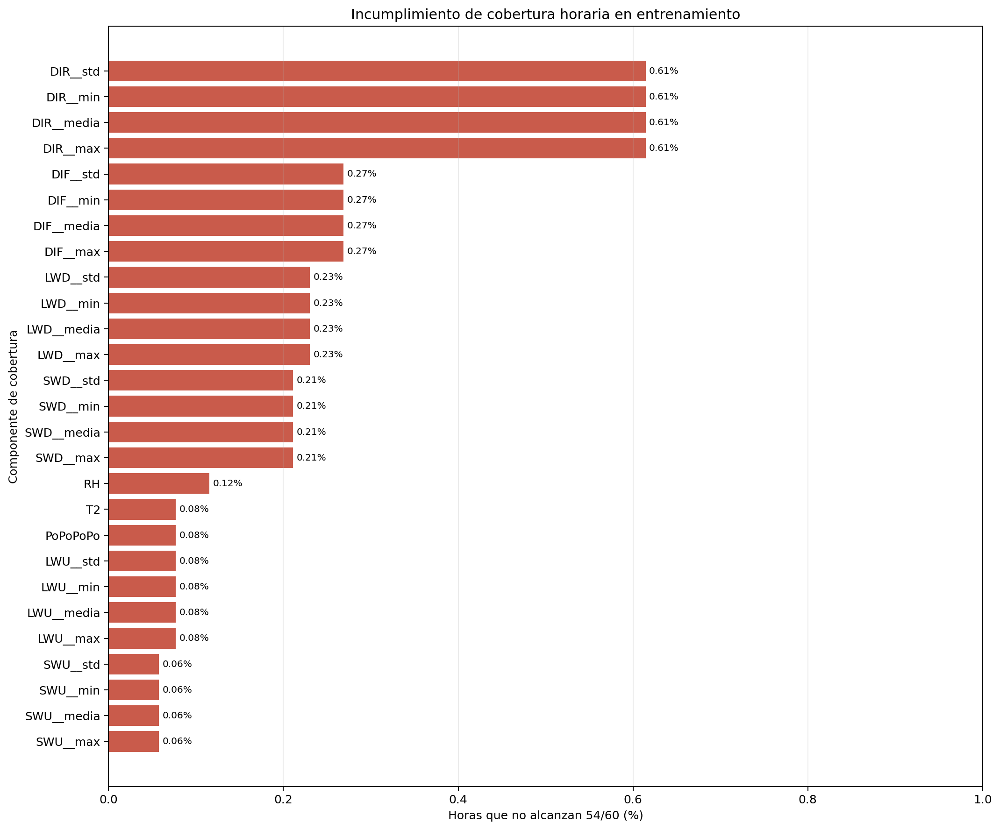


=== FIGURA 2 · COBERTURA MENSUAL EN TRAIN ===


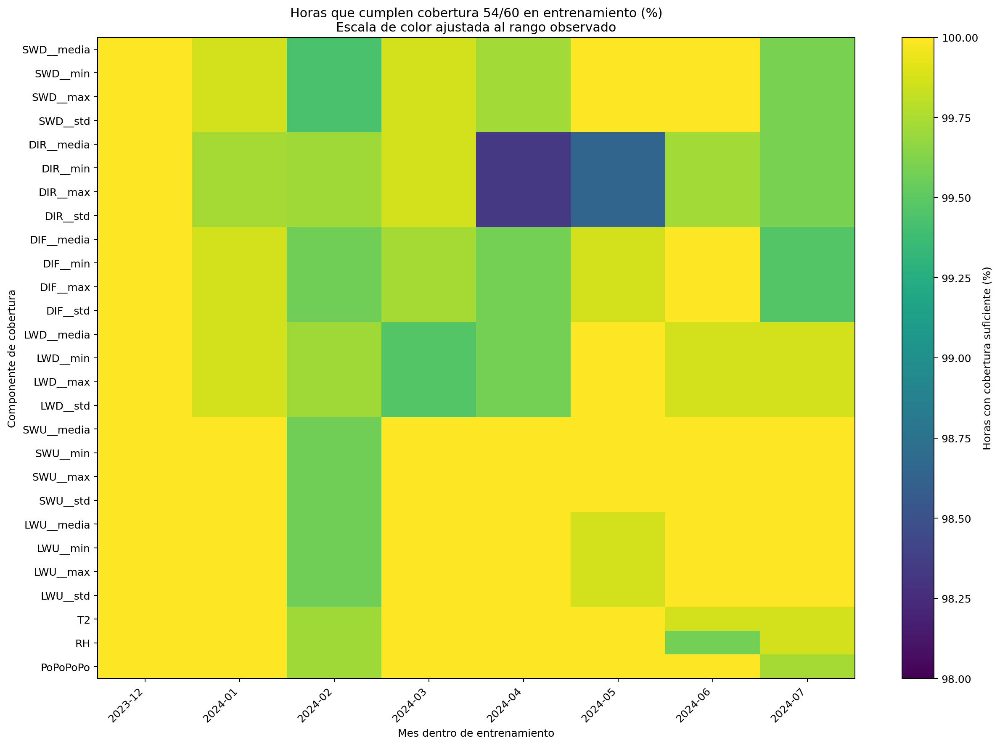


=== PROTECCIÓN DE PARTICIONES ===
Partición analizada: TRAIN
Validation analizada: NO
Test analizado: NO
Filas eliminadas: 0
Valores imputados: 0
Agregados enmascarados: 0

=== ZIP ===
Nombre: EDA_multivariante_F2_S2_1_20261102T163533Z_3f784d6b.zip
Tamaño: 1.29 MiB (1,352,031 bytes)
SHA-256: 2ced5bd53f378a869a6c9ba9b90b65c34bb485f2b3700cbeb3aab686560ee0e0
Integridad: CORRECTA
Contenido:
 - README.md
 - checkpoints/
 - checkpoints/04_tabla_horaria_particionada_sin_cambios.parquet
 - configuracion/
 - configuracion/configuracion_2_1.json
 - figuras/
 - figuras/01_horas_sin_cobertura_train.png
 - figuras/02_cobertura_mensual_train.png
 - inventario_archivos.csv
 - resumen_ejecucion.json
 - tablas/
 - tablas/01_resumen_tecnico.csv
 - tablas/02_ausencias_agregados_train.csv
 - tablas/03_cobertura_componentes_train.csv
 - tablas/04_cobertura_mensual_train.csv
 - tablas/05_cobertura_familias_train.csv
 - tablas/06_reglas_validez_agregados.csv
 - tablas/07_advertencias_y_alcance.csv
 - tablas

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


SUBSECCIÓN 2.1 EJECUTADA SIN ERRORES.


In [5]:
from __future__ import annotations
import gc
import hashlib
import importlib.util
import io
import json
import os
import platform
import shutil
import subprocess
import sys
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path

# Instalar solo el motor Parquet si el entorno no lo incluye.
if importlib.util.find_spec("pyarrow") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyarrow==19.0.1"])

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow
try:
    from IPython.display import Image, display
except ImportError:
    Image, display = None, print

try:
    from google.colab import files as colab_files
    EN_COLAB = True
except ImportError:
    colab_files, EN_COLAB = None, False


# ---------- Contrato ----------
COL_FECHA = "Date/Time"
COL_PARTICION = "particion_observacion"
PARTICION_ANALIZADA = "train"
N_HORAS_TRAIN = 5_208
MINUTOS_ESPERADOS = 60
MINUTOS_COBERTURA = 54
FAMILIAS_RADIOMETRICAS = ["SWD", "DIR", "DIF", "LWD", "SWU", "LWU"]
METEOROLOGIA = {"T2": "T2 [°C]", "RH": "RH [%]", "PoPoPoPo": "PoPoPoPo [hPa]"}

def exigir(condicion, mensaje):
    if not bool(condicion):
        raise AssertionError(mensaje)

def sha256_bytes(datos):
    return hashlib.sha256(datos).hexdigest()

def sha256_archivo(ruta, bloque=1024 * 1024):
    digest = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        for fragmento in iter(lambda: archivo.read(bloque), b""):
            digest.update(fragmento)

    return digest.hexdigest()

def porcentaje(numerador, denominador):
    if denominador == 0:
        return np.nan

    return 100.0 * numerador / denominador


# ---------- Cargar el ZIP validado de 1.3 ----------
ruta_local = os.environ.get("EDA_ZIP_1_3_LOCAL")
if ruta_local:
    ruta_local = Path(ruta_local).expanduser().resolve()
    exigir(ruta_local.is_file(), f"No existe: {ruta_local}")
    exigir(ruta_local.suffix.lower() == ".zip", "La entrada debe ser un ZIP.")
    nombre_entrada = ruta_local.name
    contenido_entrada = ruta_local.read_bytes()

elif EN_COLAB:
    print("Selecciona el ZIP generado y validado " "en la subsección 1.3.")
    subidos = colab_files.upload()
    exigir(len(subidos) == 1, "Selecciona exactamente un archivo ZIP.")
    nombre_entrada, contenido_entrada = next(iter(subidos.items()))
    exigir(Path(nombre_entrada).suffix.lower() == ".zip", "La entrada debe ser un ZIP.")
    del subidos

else:
    raise RuntimeError("Fuera de Colab, define EDA_ZIP_1_3_LOCAL.")

tamano_entrada = len(contenido_entrada)
sha_entrada = sha256_bytes(contenido_entrada)
with zipfile.ZipFile(io.BytesIO(contenido_entrada), "r") as zip_entrada:
    exigir(zip_entrada.testzip() is None, "El ZIP de 1.3 está dañado.")
    nombres_entrada = set(zip_entrada.namelist())
    ruta_checkpoint_interna = "checkpoints/" "03_tabla_horaria_con_particion_observacion.parquet"
    ruta_config_interna = "configuracion/" "configuracion_1_3.json"
    ruta_diccionario_interna = "tablas/" "06_diccionario_columnas.csv"
    ruta_metadatos_interna = "tablas/" "07_metadatos_y_advertencias.csv"
    for ruta_requerida in (
        ruta_checkpoint_interna,
        ruta_config_interna,
        ruta_diccionario_interna,
        ruta_metadatos_interna,
    ):
        exigir(ruta_requerida in nombres_entrada, f"Falta en el ZIP: {ruta_requerida}")

    configuracion_1_3 = json.loads(zip_entrada.read(ruta_config_interna))
    bytes_checkpoint = zip_entrada.read(ruta_checkpoint_interna)
    diccionario_1_3 = pd.read_csv(zip_entrada.open(ruta_diccionario_interna))
    metadatos_previos = pd.read_csv(zip_entrada.open(ruta_metadatos_interna))

exigir(configuracion_1_3.get("fase") == 1, "La fase de entrada no es la esperada.")
exigir(configuracion_1_3.get("subseccion") == "1.3", "La subsección de entrada no es 1.3.")
exigir(
    sha256_bytes(bytes_checkpoint) == configuracion_1_3["checkpoint"]["sha256"],
    "La huella del checkpoint no coincide " "con la configuración de 1.3.",
)
tabla_horaria_1_3 = pd.read_parquet(io.BytesIO(bytes_checkpoint), engine="pyarrow")
del contenido_entrada, bytes_checkpoint
gc.collect()


# ---------- Auditoría estructural previa ----------
# No se inspecciona el contenido de validation o test.
exigir(tabla_horaria_1_3.shape == (9_504, 132), "Forma de entrada inesperada.")
exigir(tabla_horaria_1_3.columns.is_unique, "Hay columnas duplicadas.")
exigir(tabla_horaria_1_3[COL_FECHA].is_unique, "Hay horas duplicadas.")
exigir(tabla_horaria_1_3[COL_FECHA].is_monotonic_increasing, "Las horas no están ordenadas.")
exigir(
    diccionario_1_3["columna"].tolist() == tabla_horaria_1_3.columns.tolist(),
    "El diccionario no coincide " "con el checkpoint.",
)
conteos_particion = tabla_horaria_1_3[COL_PARTICION].value_counts(sort=False).to_dict()
conteos_esperados = {"pre_segmento": 1_368, "train": 5_208, "validation": 1_464, "test": 1_464}
exigir(conteos_particion == conteos_esperados, "Las particiones han cambiado.")


# A partir de aquí, todas las métricas se calculan solo en train.
train_2_1 = (
    tabla_horaria_1_3.loc[tabla_horaria_1_3[COL_PARTICION].eq(PARTICION_ANALIZADA)]
    .copy(deep=True)
    .reset_index(drop=True)
)
exigir(len(train_2_1) == N_HORAS_TRAIN, "Número de horas de train inesperado.")
exigir(train_2_1[COL_PARTICION].eq("train").all(), "Se mezclaron particiones.")
exigir(
    train_2_1[COL_FECHA].min() == pd.Timestamp("2023-12-28 00:00:00"), "Inicio de train incorrecto."
)
exigir(
    train_2_1[COL_FECHA].max() == pd.Timestamp("2024-07-31 23:00:00"), "Final de train incorrecto."
)


# ---------- Identificar agregados y coberturas ----------
columnas_agregadas = diccionario_1_3.loc[diccionario_1_3["tipo"].eq("agregado"), "columna"].tolist()
exigir(len(columnas_agregadas) == 45, "Se esperaban 45 columnas agregadas.")
exigir(set(columnas_agregadas).issubset(train_2_1.columns), "Faltan agregados.")
columnas_n = [columna for columna in train_2_1.columns if columna.endswith("__n_disponibles")]
exigir(len(columnas_n) == 27, "Se esperaban 27 conteos " "de disponibilidad.")
aliases_cobertura = [columna.removesuffix("__n_disponibles") for columna in columnas_n]
for alias in aliases_cobertura:
    col_n = f"{alias}__n_disponibles"
    col_p = f"{alias}__prop_disponible"
    col_ok = f"{alias}__cobertura_90_ok"
    exigir(col_p in train_2_1 and col_ok in train_2_1, f"Faltan controles para {alias}.")
    exigir(train_2_1[col_n].between(0, 60).all(), f"Conteo fuera de rango: {alias}.")
    exigir(
        np.allclose(train_2_1[col_p], (train_2_1[col_n] / MINUTOS_ESPERADOS)),
        f"Proporción incoherente: {alias}.",
    )
    exigir(
        train_2_1[col_ok].eq(train_2_1[col_n].ge(MINUTOS_COBERTURA)).all(),
        f"Indicador incoherente: {alias}.",
    )


# ---------- 1. Ausencias y no finitos ----------
filas_ausencias = []
for columna in columnas_agregadas:
    serie = train_2_1[columna]
    exigir(pd.api.types.is_numeric_dtype(serie), f"Agregado no numérico: {columna}")
    n_ausentes = int(serie.isna().sum())
    valores = serie.to_numpy(dtype="float64", na_value=np.nan)
    n_pos_inf = int(np.isposinf(valores).sum())
    n_neg_inf = int(np.isneginf(valores).sum())
    n_finitos = int(np.isfinite(valores).sum())
    filas_ausencias.append(
        {
            "columna": columna,
            "dtype": str(serie.dtype),
            "n_horas_train": N_HORAS_TRAIN,
            "n_ausentes": n_ausentes,
            "pct_ausentes": porcentaje(n_ausentes, N_HORAS_TRAIN),
            "n_pos_inf": n_pos_inf,
            "n_neg_inf": n_neg_inf,
            "n_finitos": n_finitos,
            "pct_finitos": porcentaje(n_finitos, N_HORAS_TRAIN),
            "recuento_reconciliado": (
                n_ausentes + n_pos_inf + n_neg_inf + n_finitos == N_HORAS_TRAIN
            ),
        }
    )

tabla_ausencias_2_1 = pd.DataFrame(filas_ausencias).sort_values(
    ["pct_ausentes", "columna"], ascending=[False, True], ignore_index=True
)
exigir(tabla_ausencias_2_1["recuento_reconciliado"].all(), "No reconcilian los no finitos.")


# ---------- 2. Cobertura por componente ----------
filas_cobertura = []
for alias in aliases_cobertura:
    conteo = train_2_1[f"{alias}__n_disponibles"]
    ok = train_2_1[f"{alias}__cobertura_90_ok"]
    n_ok = int(ok.sum())
    n_no_ok = int((~ok).sum())
    n_cero = int(conteo.eq(0).sum())
    n_1_53 = int(conteo.between(1, 53).sum())
    n_54_59 = int(conteo.between(54, 59).sum())
    n_60 = int(conteo.eq(60).sum())
    exigir(
        (n_cero + n_1_53 + n_54_59 + n_60) == N_HORAS_TRAIN, "Clases no reconciliadas: " f"{alias}"
    )
    filas_cobertura.append(
        {
            "serie_cobertura": alias,
            "n_horas_train": N_HORAS_TRAIN,
            "n_horas_cobertura_ok": n_ok,
            "pct_horas_cobertura_ok": porcentaje(n_ok, N_HORAS_TRAIN),
            "n_horas_no_cobertura": n_no_ok,
            "pct_horas_no_cobertura": porcentaje(n_no_ok, N_HORAS_TRAIN),
            "n_horas_0_minutos": n_cero,
            "n_horas_1_a_53": n_1_53,
            "n_horas_54_a_59": n_54_59,
            "n_horas_60": n_60,
            "min_minutos_disponibles": int(conteo.min()),
            "mediana_minutos_disponibles": float(conteo.median()),
            "max_minutos_disponibles": int(conteo.max()),
        }
    )

tabla_cobertura_2_1 = pd.DataFrame(filas_cobertura).sort_values(
    ["pct_horas_no_cobertura", "serie_cobertura"], ascending=[False, True], ignore_index=True
)


# ---------- 3. Cobertura mensual ----------
train_2_1["mes_train"] = train_2_1[COL_FECHA].dt.to_period("M").astype(str)
meses_esperados = [
    "2023-12",
    "2024-01",
    "2024-02",
    "2024-03",
    "2024-04",
    "2024-05",
    "2024-06",
    "2024-07",
]
exigir(
    train_2_1["mes_train"].drop_duplicates().tolist() == meses_esperados,
    "Meses de train inesperados.",
)
filas_mensuales = []
for alias in aliases_cobertura:
    col_n = f"{alias}__n_disponibles"
    col_ok = f"{alias}__cobertura_90_ok"
    for mes, bloque in train_2_1.groupby("mes_train", sort=True, observed=True):
        n_horas = len(bloque)
        horas_ok = int(bloque[col_ok].sum())
        minutos_disponibles = int(bloque[col_n].sum())
        minutos_esperados = n_horas * MINUTOS_ESPERADOS
        filas_mensuales.append(
            {
                "mes": mes,
                "serie_cobertura": alias,
                "n_horas_train": n_horas,
                "n_horas_cobertura_ok": horas_ok,
                "pct_horas_cobertura_ok": porcentaje(horas_ok, n_horas),
                "n_horas_no_cobertura": n_horas - horas_ok,
                "minutos_disponibles": minutos_disponibles,
                "minutos_esperados": minutos_esperados,
                "pct_minutos_disponibles": porcentaje(minutos_disponibles, minutos_esperados),
            }
        )

tabla_mensual_2_1 = pd.DataFrame(filas_mensuales)
exigir(
    len(tabla_mensual_2_1) == (len(aliases_cobertura) * len(meses_esperados)),
    "Tabla mensual incompleta.",
)
exigir(
    tabla_mensual_2_1.groupby("serie_cobertura")["n_horas_train"].sum().eq(N_HORAS_TRAIN).all(),
    "Las horas mensuales no reconcilian.",
)


# ---------- 4. Cobertura por familia ----------
filas_familias = []
for familia in FAMILIAS_RADIOMETRICAS:
    flags = {
        componente: train_2_1[f"{familia}__{componente}" "__cobertura_90_ok"]
        for componente in ("media", "min", "max", "std")
    }
    todos = pd.DataFrame(flags).all(axis=1)
    fila = {"familia": familia, "tipo": "radiometrica", "n_horas_train": N_HORAS_TRAIN}
    for componente, flag in flags.items():
        n_componente = int(flag.sum())
        fila[f"n_horas_{componente}_ok"] = n_componente
        fila[f"pct_horas_{componente}_ok"] = porcentaje(n_componente, N_HORAS_TRAIN)

    fila["n_horas_todos_componentes_ok"] = int(todos.sum())
    fila["pct_horas_todos_componentes_ok"] = porcentaje(int(todos.sum()), N_HORAS_TRAIN)
    filas_familias.append(fila)

for alias in METEOROLOGIA:
    flag = train_2_1[f"{alias}__cobertura_90_ok"]
    n_ok = int(flag.sum())
    filas_familias.append(
        {
            "familia": alias,
            "tipo": "meteorologica",
            "n_horas_train": N_HORAS_TRAIN,
            "n_horas_media_ok": n_ok,
            "pct_horas_media_ok": porcentaje(n_ok, N_HORAS_TRAIN),
            "n_horas_min_ok": np.nan,
            "pct_horas_min_ok": np.nan,
            "n_horas_max_ok": np.nan,
            "pct_horas_max_ok": np.nan,
            "n_horas_std_ok": np.nan,
            "pct_horas_std_ok": np.nan,
            "n_horas_todos_componentes_ok": n_ok,
            "pct_horas_todos_componentes_ok": porcentaje(n_ok, N_HORAS_TRAIN),
        }
    )

tabla_familias_2_1 = pd.DataFrame(filas_familias)


# ---------- 5. Reglas de cobertura ----------
reglas_validez = []

def registrar_regla(columna_agregada, flags_requeridos):
    mascara_ok = train_2_1[flags_requeridos].all(axis=1)
    n_ok = int(mascara_ok.sum())
    reglas_validez.append(
        {
            "columna_agregada": columna_agregada,
            "flags_cobertura_requeridos": " & ".join(flags_requeridos),
            "n_flags_requeridos": len(flags_requeridos),
            "n_horas_regla_ok": n_ok,
            "pct_horas_regla_ok": porcentaje(n_ok, N_HORAS_TRAIN),
            "n_horas_regla_no_ok": N_HORAS_TRAIN - n_ok,
            "accion_aplicada": "ninguna; agregado conservado",
        }
    )

for familia in FAMILIAS_RADIOMETRICAS:
    flag_media = f"{familia}__media" "__cobertura_90_ok"
    flag_min = f"{familia}__min" "__cobertura_90_ok"
    flag_max = f"{familia}__max" "__cobertura_90_ok"
    flag_std = f"{familia}__std" "__cobertura_90_ok"
    registrar_regla(f"{familia}__media_h", [flag_media])
    registrar_regla(f"{familia}__min_h", [flag_min])
    registrar_regla(f"{familia}__max_h", [flag_max])
    registrar_regla(f"{familia}__std_media_h", [flag_std])
    registrar_regla(f"{familia}__std_p90_h", [flag_std])
    registrar_regla(f"{familia}__rango_h", [flag_min, flag_max])
    registrar_regla(f"{familia}" "__std_medias_minutales_h", [flag_media])

for alias in METEOROLOGIA:
    registrar_regla(f"{alias}__media_h", [f"{alias}" "__cobertura_90_ok"])

tabla_reglas_validez_2_1 = pd.DataFrame(reglas_validez)
exigir(
    set(tabla_reglas_validez_2_1["columna_agregada"]) == set(columnas_agregadas),
    "No se documentó la cobertura " "de todos los agregados.",
)


# ---------- Resumen y advertencias ----------
n_inf_total = int(tabla_ausencias_2_1[["n_pos_inf", "n_neg_inf"]].to_numpy().sum())
controles = [
    ("Partición analizada", PARTICION_ANALIZADA, "train", PARTICION_ANALIZADA == "train"),
    ("Horas de entrenamiento", len(train_2_1), N_HORAS_TRAIN, len(train_2_1) == N_HORAS_TRAIN),
    ("Agregados horarios auditados", len(columnas_agregadas), 45, len(columnas_agregadas) == 45),
    ("Series de cobertura auditadas", len(aliases_cobertura), 27, len(aliases_cobertura) == 27),
    ("Meses de entrenamiento", len(meses_esperados), 8, len(meses_esperados) == 8),
    ("Filas de cobertura mensual", len(tabla_mensual_2_1), 216, len(tabla_mensual_2_1) == 216),
    ("Familias resumidas", len(tabla_familias_2_1), 9, len(tabla_familias_2_1) == 9),
    (
        "Reglas de validez de agregados",
        len(tabla_reglas_validez_2_1),
        45,
        (len(tabla_reglas_validez_2_1) == 45),
    ),
    ("Valores infinitos detectados", n_inf_total, "registrados sin modificación", True),
    ("Filas eliminadas", 0, 0, True),
    ("Valores imputados", 0, 0, True),
    ("Agregados enmascarados por cobertura", 0, 0, True),
    ("Validation analizada", False, False, True),
    ("Test analizado", False, False, True),
]
tabla_resumen_2_1 = pd.DataFrame(
    controles, columns=["comprobacion", "resultado", "esperado", "superado"]
)
exigir(tabla_resumen_2_1["superado"].all(), "Algún control de 2.1 " "no fue superado.")
advertencias = [
    {
        "id": "Q001",
        "advertencia": ("Disponible significa no ausente; " "todavía no implica validez física."),
        "decision": ("No eliminar, imputar " "ni corregir en 2.1."),
        "resolver_en": ("Fase 2: coherencia " "y calidad física"),
    },
    {
        "id": "Q002",
        "advertencia": ("Los agregados con cobertura inferior " "a 54/60 permanecen calculados."),
        "decision": ("Conservar agregado, conteo, " "proporción y bandera."),
        "resolver_en": ("Después de revisar cobertura " "y disponibilidad de ventanas"),
    },
    {
        "id": "Q003",
        "advertencia": ("Esta subsección no estudia rachas " "ni patrones de ausencia conjunta."),
        "decision": ("Diferir el análisis " "sin anticipar conclusiones."),
        "resolver_en": ("Subsección siguiente de la Fase 2"),
    },
]
if n_inf_total > 0:
    advertencias.append(
        {
            "id": "Q004",
            "advertencia": (
                f"Se detectaron {n_inf_total} " "valores infinitos en agregados " "de train."
            ),
            "decision": ("Registrar; no reemplazar " "automáticamente."),
            "resolver_en": ("Fase 2: coherencia " "y calidad física"),
        }
    )

tabla_advertencias_2_1 = pd.DataFrame(advertencias)


# ---------- Guardado versionado ----------
marca = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
id_ejecucion = f"{marca}_{uuid.uuid4().hex[:8]}"
nombre_salida = "EDA_multivariante_F2_S2_1_" f"{id_ejecucion}"
raiz = (
    Path(
        os.environ.get(
            "EDA_RESULTADOS_ROOT",
            (
                "/content/" "eda_multivariante_resultados"
                if EN_COLAB
                else "./eda_multivariante_resultados"
            ),
        )
    )
    .expanduser()
    .resolve()
)
carpeta = raiz / nombre_salida
tablas_dir = carpeta / "tablas"
figuras_dir = carpeta / "figuras"
checkpoints_dir = carpeta / "checkpoints"
config_dir = carpeta / "configuracion"
exigir(not carpeta.exists(), "La carpeta versionada ya existe.")
for directorio in (tablas_dir, figuras_dir, checkpoints_dir, config_dir):
    directorio.mkdir(parents=True, exist_ok=False)


# ---------- Figura 1 ----------
datos_barra = tabla_cobertura_2_1.sort_values(
    ["pct_horas_no_cobertura", "serie_cobertura"], ascending=[True, True]
)
fig, ax = plt.subplots(figsize=(12, 10))
barra = ax.barh(
    datos_barra["serie_cobertura"], datos_barra["pct_horas_no_cobertura"], color="#C95B4B"
)
max_fallo = float(datos_barra["pct_horas_no_cobertura"].max())
limite_x = max(1.0, max_fallo * 1.25)
ax.set_xlim(0, limite_x)
ax.bar_label(barra, fmt="%.2f%%", padding=3, fontsize=8)
ax.set_xlabel("Horas que no alcanzan 54/60 (%)")
ax.set_ylabel("Componente de cobertura")
ax.set_title("Incumplimiento de cobertura " "horaria en entrenamiento")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
ruta_figura_barra = figuras_dir / "01_horas_sin_cobertura_train.png"
fig.savefig(ruta_figura_barra, dpi=180, bbox_inches="tight")
plt.close(fig)


# ---------- Figura 2 ----------
pivot_mensual = tabla_mensual_2_1.pivot(
    index="serie_cobertura", columns="mes", values="pct_horas_cobertura_ok"
).reindex(index=aliases_cobertura, columns=meses_esperados)
exigir(pivot_mensual.notna().all().all(), "La matriz mensual contiene " "huecos estructurales.")
fig, ax = plt.subplots(figsize=(14, 10))
min_cobertura_observada = float(np.nanmin(pivot_mensual.to_numpy()))
limite_inferior_color = min(99.0, max(0.0, (np.floor(min_cobertura_observada * 2) / 2)))
imagen = ax.imshow(
    pivot_mensual.to_numpy(),
    aspect="auto",
    interpolation="nearest",
    cmap="viridis",
    vmin=limite_inferior_color,
    vmax=100,
)
ax.set_xticks(np.arange(len(pivot_mensual.columns)))
ax.set_xticklabels(pivot_mensual.columns, rotation=45, ha="right")
ax.set_yticks(np.arange(len(pivot_mensual.index)))
ax.set_yticklabels(pivot_mensual.index)
ax.set_xlabel("Mes dentro de entrenamiento")
ax.set_ylabel("Componente de cobertura")
ax.set_title(
    "Horas que cumplen cobertura 54/60 "
    "en entrenamiento (%)\n"
    "Escala de color ajustada "
    "al rango observado"
)
barra_color = fig.colorbar(imagen, ax=ax)
barra_color.set_label("Horas con cobertura suficiente (%)")
fig.tight_layout()
ruta_figura_mensual = figuras_dir / "02_cobertura_mensual_train.png"
fig.savefig(ruta_figura_mensual, dpi=180, bbox_inches="tight")
plt.close(fig)
exigir(ruta_figura_barra.is_file(), "No se creó la figura " "de cobertura global.")
exigir(ruta_figura_mensual.is_file(), "No se creó la figura mensual.")


# ---------- Checkpoint sin cambios físicos ----------
ruta_checkpoint = checkpoints_dir / "04_tabla_horaria_particionada_sin_cambios.parquet"
tabla_horaria_1_3.to_parquet(ruta_checkpoint, index=False, engine="pyarrow", compression="snappy")
recarga = pd.read_parquet(ruta_checkpoint, engine="pyarrow")
checkpoint_identico = bool(recarga.equals(tabla_horaria_1_3))
del recarga
gc.collect()
exigir(checkpoint_identico, "El checkpoint cambió " "durante la subsección 2.1.")


# ---------- Tablas auditables ----------
tablas_para_guardar = {
    "01_resumen_tecnico.csv": tabla_resumen_2_1,
    "02_ausencias_agregados_train.csv": tabla_ausencias_2_1,
    "03_cobertura_componentes_train.csv": tabla_cobertura_2_1,
    "04_cobertura_mensual_train.csv": tabla_mensual_2_1,
    "05_cobertura_familias_train.csv": tabla_familias_2_1,
    "06_reglas_validez_agregados.csv": tabla_reglas_validez_2_1,
    "07_advertencias_y_alcance.csv": tabla_advertencias_2_1,
    "08_metadatos_pendientes.csv": metadatos_previos,
}
for archivo, tabla in tablas_para_guardar.items():
    tabla.to_csv(tablas_dir / archivo, index=False, encoding="utf-8-sig")


# ---------- Configuración ----------
configuracion = {
    "fase": 2,
    "subseccion": "2.1",
    "id_ejecucion": id_ejecucion,
    "fecha_utc": datetime.now(timezone.utc).isoformat(),
    "entorno": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "matplotlib": matplotlib.__version__,
        "pyarrow": pyarrow.__version__,
        "colab": EN_COLAB,
    },
    "entrada": {
        "nombre_zip_1_3": nombre_entrada,
        "tamano_bytes": tamano_entrada,
        "sha256_zip_1_3": sha_entrada,
        "sha256_checkpoint_1_3": (configuracion_1_3["checkpoint"]["sha256"]),
    },
    "alcance": {
        "particion_analizada": "train",
        "inicio_inclusivo": "2023-12-28 00:00:00",
        "fin_exclusivo": "2024-08-01 00:00:00",
        "n_horas": N_HORAS_TRAIN,
        "validation_analizada": False,
        "test_analizado": False,
    },
    "definiciones": {
        "disponible": ("valor no ausente en la " "columna minutal fuente"),
        "cobertura_suficiente": ("al menos 54 de 60 " "valores disponibles"),
        "valor_fisicamente_valido_evaluado": False,
        "agregados_enmascarados": False,
        "imputacion": False,
        "eliminacion": False,
    },
    "analisis_diferidos": [
        "rachas de ausencias",
        "patrones de ausencia conjunta",
        "coherencia física min-media-max",
        "cambios instrumentales",
        "ventanas históricas de 48 horas",
    ],
    "checkpoint": {
        "ruta": ("checkpoints/" "04_tabla_horaria_particionada_sin_cambios.parquet"),
        "forma": list(tabla_horaria_1_3.shape),
        "sha256": sha256_archivo(ruta_checkpoint),
        "identico_a_entrada": checkpoint_identico,
    },
}
(config_dir / "configuracion_2_1.json").write_text(
    json.dumps(configuracion, ensure_ascii=False, indent=2), encoding="utf-8"
)


# ---------- Resumen de ejecución ----------
(carpeta / "resumen_ejecucion.json").write_text(
    json.dumps(
        {
            "estado": "COMPLETADO",
            "particion_analizada": "train",
            "n_horas_train": N_HORAS_TRAIN,
            "n_agregados_auditados": len(columnas_agregadas),
            "n_series_cobertura": len(aliases_cobertura),
            "n_infinidades_detectadas": n_inf_total,
            "filas_eliminadas": 0,
            "valores_imputados": 0,
            "validation_analizada": False,
            "test_analizado": False,
        },
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)


# Sin cercas Markdown internas para evitar cortes.
readme = f"""# Fase 2 · Subsección 2.1

Ejecución: {id_ejecucion}

Se estudian ausencias y cobertura únicamente en las {N_HORAS_TRAIN} horas de
entrenamiento. Disponible significa no ausente y no implica todavía validez
física. No se eliminan filas, no se imputan valores y no se enmascaran agregados.

Validation y test no se analizan. El checkpoint es una copia lógica sin cambios
de la tabla horaria particionada recibida de la subsección 1.3.

Recarga:

1. Sube este ZIP en Colab.
2. Extráelo en una carpeta nueva con zipfile.ZipFile.
3. Carga checkpoints/04_tabla_horaria_particionada_sin_cambios.parquet.
4. Comprueba que la forma sea {tabla_horaria_1_3.shape}.
"""
(carpeta / "README.md").write_text(readme, encoding="utf-8")


# ---------- Inventario ----------
archivos = sorted(ruta for ruta in carpeta.rglob("*") if ruta.is_file())
inventario = pd.DataFrame(
    [
        {
            "ruta_relativa": (ruta.relative_to(carpeta).as_posix()),
            "tamano_bytes": ruta.stat().st_size,
            "sha256": sha256_archivo(ruta),
        }
        for ruta in archivos
    ]
)
inventario.to_csv(carpeta / "inventario_archivos.csv", index=False, encoding="utf-8-sig")


# ---------- ZIP ----------
ruta_zip = raiz / f"{nombre_salida}.zip"
exigir(not ruta_zip.exists(), "Ya existe el ZIP de esta ejecución.")
ruta_zip_2_1 = Path(shutil.make_archive(str(raiz / nombre_salida), "zip", root_dir=carpeta))
exigir(ruta_zip_2_1.is_file(), "No se creó el ZIP.")
with zipfile.ZipFile(ruta_zip_2_1, "r") as archivo_zip:
    archivo_danado = archivo_zip.testzip()
    contenido_zip = sorted(archivo_zip.namelist())

exigir(archivo_danado is None, f"Archivo dañado en el ZIP: " f"{archivo_danado}")
exigir(
    ("checkpoints/" "04_tabla_horaria_particionada_sin_cambios.parquet") in contenido_zip,
    "Falta el checkpoint en el ZIP.",
)
tamano_zip = ruta_zip_2_1.stat().st_size
tamano_zip_mib = tamano_zip / 1024**2
sha_zip = sha256_archivo(ruta_zip_2_1)


# ---------- Resultados visibles: solo train ----------
print("\n=== RESUMEN TÉCNICO 2.1 ===")
display(tabla_resumen_2_1)
print("\n=== AUSENCIAS EN AGREGADOS " "HORARIOS · TRAIN ===")
display(tabla_ausencias_2_1)
print("\n=== COBERTURA DE COMPONENTES " "· TRAIN ===")
display(tabla_cobertura_2_1)
print("\n=== COBERTURA POR FAMILIA " "· TRAIN ===")
display(tabla_familias_2_1)
print("\n=== COBERTURA MENSUAL (%) " "· TRAIN ===")
display(pivot_mensual.round(2))
print("\n=== ADVERTENCIAS Y ALCANCE ===")
display(tabla_advertencias_2_1)
if Image is not None:
    print("\n=== FIGURA 1 · INCUMPLIMIENTO " "DE COBERTURA EN TRAIN ===")
    display(Image(filename=str(ruta_figura_barra)))
    print("\n=== FIGURA 2 · COBERTURA " "MENSUAL EN TRAIN ===")
    display(Image(filename=str(ruta_figura_mensual)))

print("\n=== PROTECCIÓN DE PARTICIONES ===")
print("Partición analizada: TRAIN")
print("Validation analizada: NO")
print("Test analizado: NO")
print("Filas eliminadas: 0")
print("Valores imputados: 0")
print("Agregados enmascarados: 0")
print("\n=== ZIP ===")
print("Nombre:", ruta_zip_2_1.name)
print("Tamaño:", f"{tamano_zip_mib:.2f} MiB " f"({tamano_zip:,} bytes)")
print("SHA-256:", sha_zip)
print("Integridad: CORRECTA")
print("Contenido:")
for elemento in contenido_zip:
    print(" -", elemento)

print("Recarga: consulta README.md " "dentro del ZIP.")


# ---------- Descarga ----------
if tamano_zip_mib > 250:
    raise RuntimeError(
        f"El ZIP ocupa {tamano_zip_mib:.2f} MiB; " "se detiene la descarga automática."
    )

if EN_COLAB:
    colab_files.download(str(ruta_zip_2_1))
else:
    print("ZIP local:", ruta_zip_2_1)


# ---------- Controles finales ----------
assert tabla_resumen_2_1["superado"].all()
assert checkpoint_identico
assert archivo_danado is None
assert ruta_zip_2_1.exists()
print("\nSUBSECCIÓN 2.1 " "EJECUTADA SIN ERRORES.")

### 2.2 Rachas y patrones de ausencia conjunta

Los conteos de la subsección anterior no indican si los fallos de cobertura aparecen como horas aisladas, como episodios consecutivos o de forma simultánea en varias familias, algo relevante para las futuras ventanas de 48 horas. Sobre las horas de entrenamiento se distinguen tres tipos de evento —cobertura insuficiente (menos de 54 de 60 minutos), hora incompleta (menos de 60) y ausencia total (0 minutos)— y se detectan sus rachas sobre la rejilla horaria continua. La coocurrencia entre familias se mide con tablas de contingencia y con el índice de Jaccard, $J(A,B)=\frac{|A\cap B|}{|A\cup B|}$, que se interpreta junto con los conteos porque los porcentajes basados en pocos eventos pueden ser inestables. También se comprueba si media, mínimo, máximo y desviación comparten el mismo patrón de disponibilidad dentro de cada familia radiométrica.

> *Subsección complementaria: no se utiliza en la memoria. Se mantiene porque genera la entrada de la subsección 2.3.*

Selecciona exclusivamente el ZIP generado y validado en la subsección 2.1.


Saving EDA_multivariante_F2_S2_1_20261102T163533Z_3f784d6b.zip to EDA_multivariante_F2_S2_1_20261102T163533Z_3f784d6b.zip

=== RESUMEN TÉCNICO 2.2 ===


,comprobacion,resultado,esperado,superado
0,Partición analizada,train,train,True
1,Horas de entrenamiento,5208,5208,True
2,Componentes analizados,27,27,True
3,Familias analizadas,9,9,True
4,Tipos de evento,3,3,True
5,Pares de familias por evento,36,36,True
6,Reconciliación con cobertura 2.1,True,True,True
7,Rejilla train continua,True,True,True
8,Filas eliminadas,0,0,True
9,Valores imputados,0,0,True



=== HALLAZGOS ESTRUCTURALES DE AUSENCIA · TRAIN ===


,indicador,resultado,unidad
0,Horas con alguna familia bajo 54/60,58,horas
1,Horas con dos o más familias bajo 54/60,12,horas
2,Horas con alguna familia con 0/60,1,horas
3,Mayor racha bajo 54/60,4,horas consecutivas



=== RESUMEN DE RACHAS POR FAMILIA · TRAIN ===


... (6 outputs left out)

,familia,evento,componentes_comparados,n_horas_alguno_afectado,n_horas_todos_afectados,n_horas_patron_discordante,pct_concordancia_entre_componentes,patrones_binarios_distintos
0,SWD,cobertura_insuficiente,media + min + max + std,11,11,0,100.0,2
1,SWD,hora_incompleta,media + min + max + std,133,133,0,100.0,2
2,SWD,ausencia_total,media + min + max + std,0,0,0,100.0,1
3,DIR,cobertura_insuficiente,media + min + max + std,32,32,0,100.0,2
4,DIR,hora_incompleta,media + min + max + std,105,105,0,100.0,2
5,DIR,ausencia_total,media + min + max + std,0,0,0,100.0,1
6,DIF,cobertura_insuficiente,media + min + max + std,14,14,0,100.0,2
7,DIF,hora_incompleta,media + min + max + std,132,132,0,100.0,2
8,DIF,ausencia_total,media + min + max + std,0,0,0,100.0,1
9,LWD,cobertura_insuficiente,media + min + max + std,12,12,0,100.0,2



=== ADVERTENCIAS Y ALCANCE ===


,id,advertencia,decision,resolver_en
0,Q101,Los eventos son escasos; Jaccard y los porcent...,"Mostrar siempre n_ambos, n_union, n_evento_a y...",Interpretación de 2.2 y estabilidad posterior
1,Q102,La coincidencia temporal no demuestra una caus...,Interpretar la coocurrencia solo como diagnóst...,Cambios instrumentales y documentación técnica
2,Q103,Una hora incompleta (<60) no equivale a incump...,Mantener separados los tres tipos de evento.,Disponibilidad de ventanas históricas
3,Q104,"No se elimina, imputa, enmascara ni corrige ni...",Conservar el checkpoint sin cambios.,Decisión posterior basada en toda la Fase 2
4,Q105,La zona horaria sigue sin confirmar.,Usar las fechas solo como orden temporal; no i...,Antes de perfiles horarios y geometría solar



=== FIGURA 1 · DURACIÓN MÁXIMA DE RACHAS ===


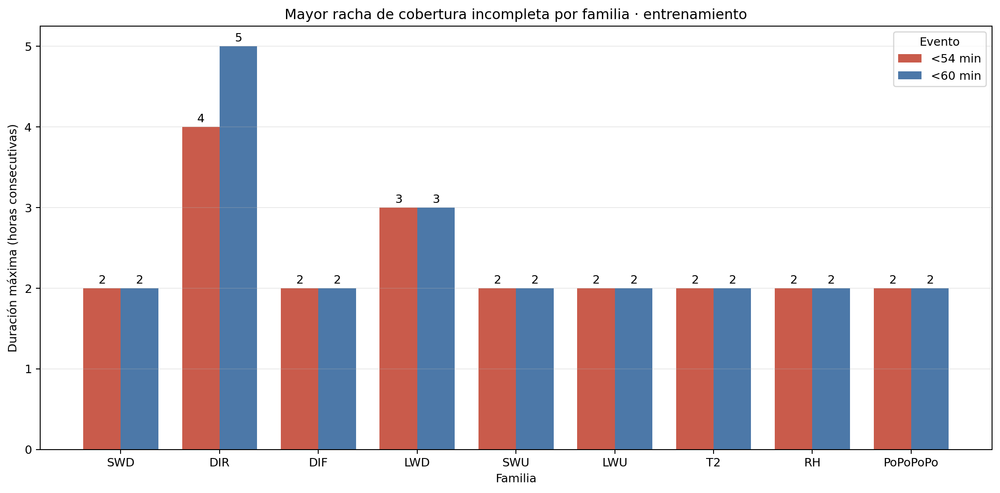


=== FIGURA 2 · CRONOLOGÍA DE INCUMPLIMIENTOS ===


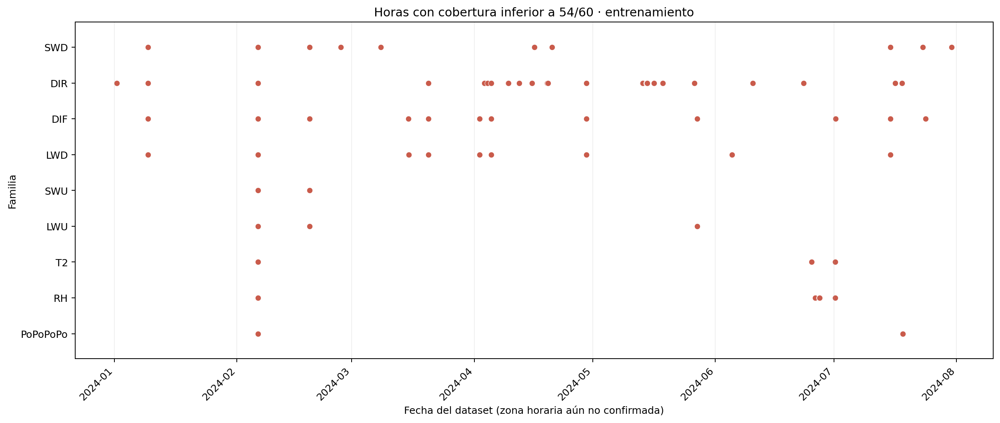


=== FIGURA 3 · JACCARD ENTRE FAMILIAS ===


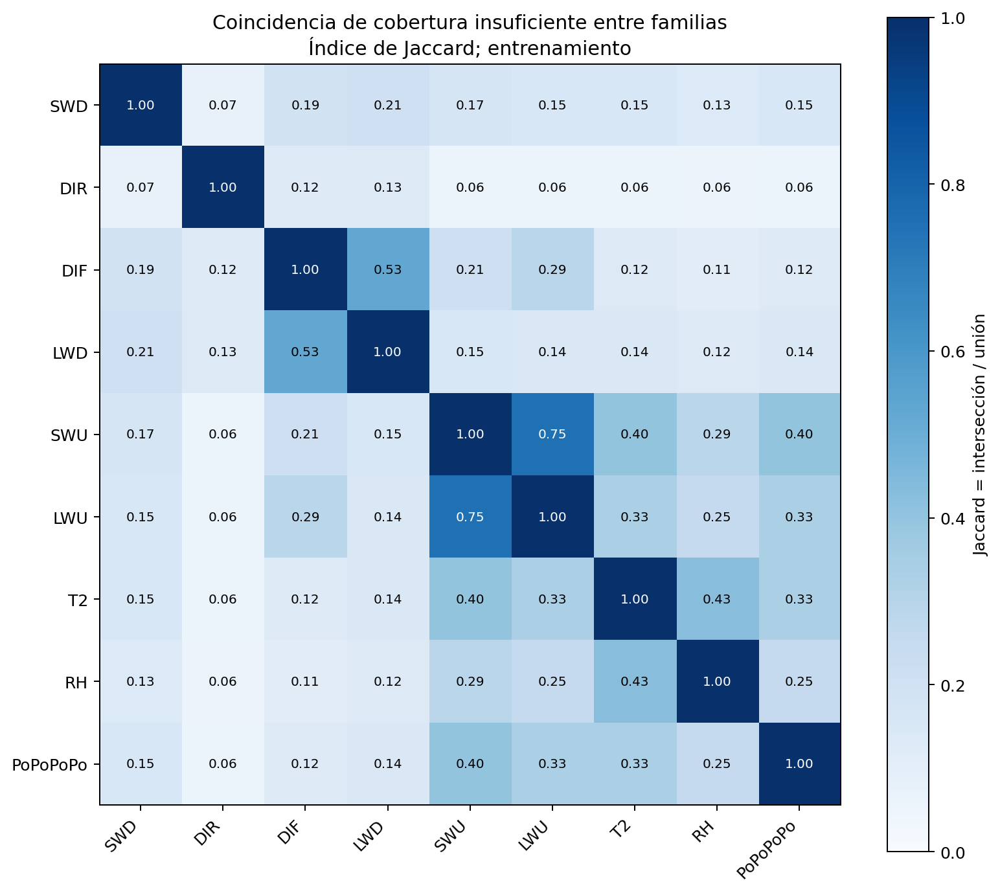


=== PROTECCIÓN DE PARTICIONES ===
Partición analizada: TRAIN
Validation analizada: NO
Test analizado: NO
Filas eliminadas: 0
Valores imputados: 0
Agregados enmascarados: 0

=== ZIP ===
Nombre: EDA_multivariante_F2_S2_2_20261102T163618Z_d35d4c19.zip
Tamaño: 1.29 MiB (1,350,705 bytes)
SHA-256: 51720994a13583bbaba53a2ed4080dfb51b8d717252942f60cf8cd8436f059cf
Integridad: CORRECTA
Contenido:
 - README.md
 - checkpoints/
 - checkpoints/05_tabla_horaria_particionada_sin_cambios.parquet
 - configuracion/
 - configuracion/configuracion_2_2.json
 - figuras/
 - figuras/01_duracion_maxima_rachas_train.png
 - figuras/02_cronologia_incumplimientos_train.png
 - figuras/03_jaccard_familias_train.png
 - inventario_archivos.csv
 - resumen_ejecucion.json
 - tablas/
 - tablas/01_resumen_tecnico.csv
 - tablas/02_resumen_rachas_train.csv
 - tablas/03_detalle_rachas_train.csv
 - tablas/04_patrones_conjuntos_familias_train.csv
 - tablas/05_patrones_conjuntos_componentes_train.csv
 - tablas/06_coocurrencia_fa

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


SUBSECCIÓN 2.2 EJECUTADA SIN ERRORES.


In [6]:
from __future__ import annotations
import gc
import hashlib
import importlib.util
import io
import json
import os
import platform
import shutil
import subprocess
import sys
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath

# Instalar únicamente el motor Parquet si falta en el entorno.
if importlib.util.find_spec("pyarrow") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyarrow==19.0.1"])

import matplotlib
matplotlib.use("Agg")
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow
try:
    from IPython.display import Image, display
except ImportError:
    Image, display = None, print

try:
    from google.colab import files as colab_files
    EN_COLAB = True
except ImportError:
    colab_files, EN_COLAB = None, False


# ---------- Contrato ----------
COL_FECHA = "Date/Time"
COL_PARTICION = "particion_observacion"
N_HORAS_TRAIN = 5_208
MINUTOS_ESPERADOS = 60
MINUTOS_COBERTURA = 54
FAMILIAS_RADIOMETRICAS = ["SWD", "DIR", "DIF", "LWD", "SWU", "LWU"]
FAMILIAS_METEOROLOGICAS = ["T2", "RH", "PoPoPoPo"]
FAMILIAS = FAMILIAS_RADIOMETRICAS + FAMILIAS_METEOROLOGICAS
COMPONENTES_RAD = ["media", "min", "max", "std"]
EVENTOS = {
    "cobertura_insuficiente": "menos de 54 minutos disponibles",
    "hora_incompleta": "menos de 60 minutos disponibles",
    "ausencia_total": "cero minutos disponibles",
}

def exigir(condicion, mensaje):
    if not bool(condicion):
        raise AssertionError(mensaje)

def sha256_bytes(datos):
    return hashlib.sha256(datos).hexdigest()

def sha256_archivo(ruta, bloque=1024 * 1024):
    digest = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        for fragmento in iter(lambda: archivo.read(bloque), b""):
            digest.update(fragmento)
    return digest.hexdigest()

def porcentaje(numerador, denominador):
    return 100.0 * numerador / denominador if denominador else np.nan

def mascara_evento(conteos, evento):
    if evento == "cobertura_insuficiente":
        return conteos.lt(MINUTOS_COBERTURA)
    if evento == "hora_incompleta":
        return conteos.lt(MINUTOS_ESPERADOS)
    if evento == "ausencia_total":
        return conteos.eq(0)
    raise ValueError(f"Evento desconocido: {evento}")

def extraer_rachas(mascara, fechas, nivel, unidad, evento):
    """Extrae intervalos consecutivos de True sobre la rejilla horaria."""
    valores = np.asarray(mascara, dtype=bool)
    cambios = np.diff(np.r_[False, valores, False].astype(np.int8))
    inicios = np.flatnonzero(cambios == 1)
    finales = np.flatnonzero(cambios == -1) - 1
    exigir(len(inicios) == len(finales), f"Rachas no reconciliadas: {unidad}")
    filas = []
    for numero, (i, j) in enumerate(zip(inicios, finales), start=1):
        longitud = int(j - i + 1)
        fecha_inicio = fechas.iloc[i]
        fecha_fin = fechas.iloc[j]
        exigir(
            fecha_fin - fecha_inicio == pd.Timedelta(hours=longitud - 1),
            f"Racha no horaria: {unidad}",
        )
        filas.append(
            {
                "nivel": nivel,
                "unidad": unidad,
                "evento": evento,
                "id_racha_unidad": numero,
                "inicio": fecha_inicio,
                "fin": fecha_fin,
                "duracion_horas": longitud,
                "aislada_1h": longitud == 1,
            }
        )
    return filas

def resumir_rachas(mascara, nivel, unidad, evento, detalle):
    seleccion = detalle.loc[
        detalle["nivel"].eq(nivel) & detalle["unidad"].eq(unidad) & detalle["evento"].eq(evento)
    ]
    duraciones = seleccion["duracion_horas"].to_numpy(dtype=float)
    n_horas_evento = int(np.asarray(mascara, dtype=bool).sum())
    exigir(
        (int(duraciones.sum()) if len(duraciones) else 0) == n_horas_evento,
        f"No reconcilian las horas: {nivel}/{unidad}/{evento}",
    )
    if len(duraciones):
        fila_max = seleccion.loc[seleccion["duracion_horas"].idxmax()]
        mediana = float(np.median(duraciones))
        p90 = float(np.quantile(duraciones, 0.90, method="higher"))
        maximo = int(duraciones.max())
        inicio_max = fila_max["inicio"]
        fin_max = fila_max["fin"]
    else:
        mediana = np.nan
        p90 = np.nan
        maximo = 0
        inicio_max = pd.NaT
        fin_max = pd.NaT

    return {
        "nivel": nivel,
        "unidad": unidad,
        "evento": evento,
        "definicion": EVENTOS[evento],
        "n_horas_train": N_HORAS_TRAIN,
        "n_horas_evento": n_horas_evento,
        "pct_horas_evento": porcentaje(n_horas_evento, N_HORAS_TRAIN),
        "n_rachas": int(len(duraciones)),
        "n_rachas_1h": int((duraciones == 1).sum()),
        "n_rachas_ge_2h": int((duraciones >= 2).sum()),
        "n_rachas_ge_6h": int((duraciones >= 6).sum()),
        "n_rachas_ge_24h": int((duraciones >= 24).sum()),
        "duracion_mediana_h": mediana,
        "duracion_p90_h": p90,
        "duracion_max_h": maximo,
        "inicio_racha_max": inicio_max,
        "fin_racha_max": fin_max,
    }

def contar_patrones(matriz, fechas, nivel, evento):
    """Cuenta las combinaciones exactas de unidades afectadas."""
    exigir(matriz.index.equals(fechas.index), "Índices no alineados")
    nombres = np.asarray(matriz.columns, dtype=object)
    codigos = []
    listas = []
    cantidades = []
    for fila in matriz.to_numpy(dtype=bool):
        afectadas = nombres[fila].tolist()
        codigos.append("|".join(afectadas) if afectadas else "NINGUNA")
        listas.append(" + ".join(afectadas) if afectadas else "NINGUNA")
        cantidades.append(len(afectadas))

    auxiliar = pd.DataFrame(
        {
            COL_FECHA: fechas.to_numpy(),
            "codigo_patron": codigos,
            "unidades_afectadas": listas,
            "n_unidades_afectadas": cantidades,
        }
    )
    resumen = (
        auxiliar.groupby(
            ["codigo_patron", "unidades_afectadas", "n_unidades_afectadas"],
            sort=False,
            dropna=False,
        )
        .agg(
            n_horas=(COL_FECHA, "size"),
            primera_hora=(COL_FECHA, "min"),
            ultima_hora=(COL_FECHA, "max"),
        )
        .reset_index()
    )
    resumen.insert(0, "evento", evento)
    resumen.insert(0, "nivel", nivel)
    resumen["pct_horas_train"] = 100 * resumen["n_horas"] / N_HORAS_TRAIN
    resumen = resumen.sort_values(
        ["n_horas", "n_unidades_afectadas", "codigo_patron"],
        ascending=[False, True, True],
        ignore_index=True,
    )
    exigir(resumen["n_horas"].sum() == N_HORAS_TRAIN, "Patrones no reconciliados")
    return resumen, auxiliar

def coocurrencia_pares(matriz, nivel, evento):
    """Calcula conteos, Jaccard y porcentajes condicionales."""
    filas = []
    columnas = list(matriz.columns)
    for i, unidad_a in enumerate(columnas):
        a = matriz[unidad_a].to_numpy(dtype=bool)
        n_a = int(a.sum())
        for unidad_b in columnas[i + 1 :]:
            b = matriz[unidad_b].to_numpy(dtype=bool)
            n_b = int(b.sum())
            ambos = int(np.logical_and(a, b).sum())
            union = int(np.logical_or(a, b).sum())
            filas.append(
                {
                    "nivel": nivel,
                    "evento": evento,
                    "unidad_a": unidad_a,
                    "unidad_b": unidad_b,
                    "n_evento_a": n_a,
                    "n_evento_b": n_b,
                    "n_ambos": ambos,
                    "n_union": union,
                    "jaccard": ambos / union if union else np.nan,
                    "pct_a_dado_b": porcentaje(ambos, n_b),
                    "pct_b_dado_a": porcentaje(ambos, n_a),
                }
            )

    return pd.DataFrame(filas).sort_values(
        ["evento", "jaccard", "n_ambos", "unidad_a", "unidad_b"],
        ascending=[True, False, False, True, True],
        ignore_index=True,
    )


# ---------- Cargar exclusivamente el ZIP validado de 2.1 ----------
ruta_local = os.environ.get("EDA_ZIP_2_1_LOCAL")
if ruta_local:
    ruta_local = Path(ruta_local).expanduser().resolve()
    exigir(ruta_local.is_file(), f"No existe: {ruta_local}")
    exigir(ruta_local.suffix.lower() == ".zip", "La entrada debe ser un ZIP")
    nombre_entrada = ruta_local.name
    contenido_entrada = ruta_local.read_bytes()
elif EN_COLAB:
    print("Selecciona exclusivamente el ZIP generado y validado en la subsección 2.1.")
    subidos = colab_files.upload()
    exigir(len(subidos) == 1, "Selecciona exactamente un archivo ZIP")
    nombre_entrada, contenido_entrada = next(iter(subidos.items()))
    exigir(Path(nombre_entrada).suffix.lower() == ".zip", "La entrada debe ser un ZIP")
    del subidos
else:
    raise RuntimeError("Fuera de Colab, define EDA_ZIP_2_1_LOCAL")

tamano_entrada = len(contenido_entrada)
sha_entrada = sha256_bytes(contenido_entrada)
ruta_checkpoint_interna = "checkpoints/04_tabla_horaria_particionada_sin_cambios.parquet"
ruta_config_interna = "configuracion/configuracion_2_1.json"
ruta_cobertura_interna = "tablas/03_cobertura_componentes_train.csv"
ruta_metadatos_interna = "tablas/08_metadatos_pendientes.csv"
with zipfile.ZipFile(io.BytesIO(contenido_entrada), "r") as zip_entrada:
    exigir(zip_entrada.testzip() is None, "El ZIP de 2.1 está dañado")
    nombres_entrada = zip_entrada.namelist()
    for nombre in nombres_entrada:
        partes = PurePosixPath(nombre).parts
        exigir(not PurePosixPath(nombre).is_absolute(), f"Ruta absoluta insegura: {nombre}")
        exigir(".." not in partes, f"Ruta insegura en ZIP: {nombre}")

    rutas_requeridas = [
        ruta_checkpoint_interna,
        ruta_config_interna,
        ruta_cobertura_interna,
        ruta_metadatos_interna,
        "inventario_archivos.csv",
        "resumen_ejecucion.json",
    ]
    for ruta_requerida in rutas_requeridas:
        exigir(ruta_requerida in nombres_entrada, f"Falta: {ruta_requerida}")

    configuracion_2_1 = json.loads(zip_entrada.read(ruta_config_interna))
    resumen_2_1 = json.loads(zip_entrada.read("resumen_ejecucion.json"))
    bytes_checkpoint = zip_entrada.read(ruta_checkpoint_interna)
    cobertura_previa = pd.read_csv(zip_entrada.open(ruta_cobertura_interna))
    metadatos_previos = pd.read_csv(zip_entrada.open(ruta_metadatos_interna))
    inventario_previo = pd.read_csv(zip_entrada.open("inventario_archivos.csv"))
    for fila in inventario_previo.itertuples(index=False):
        exigir(
            fila.ruta_relativa in nombres_entrada,
            f"Falta el archivo inventariado: {fila.ruta_relativa}",
        )
        datos = zip_entrada.read(fila.ruta_relativa)
        exigir(len(datos) == int(fila.tamano_bytes), f"Tamaño incorrecto: {fila.ruta_relativa}")
        exigir(sha256_bytes(datos) == fila.sha256, f"SHA-256 incorrecto: {fila.ruta_relativa}")

exigir(configuracion_2_1.get("fase") == 2, "La fase de entrada no es 2")
exigir(configuracion_2_1.get("subseccion") == "2.1", "La entrada no es 2.1")
exigir(resumen_2_1.get("estado") == "COMPLETADO", "2.1 no figura completada")
exigir(not configuracion_2_1["alcance"]["validation_analizada"], "2.1 analizó validation")
exigir(not configuracion_2_1["alcance"]["test_analizado"], "2.1 analizó test")
exigir(
    sha256_bytes(bytes_checkpoint) == configuracion_2_1["checkpoint"]["sha256"],
    "La huella del checkpoint no coincide con 2.1",
)
tabla_horaria = pd.read_parquet(io.BytesIO(bytes_checkpoint), engine="pyarrow")


# ---------- Comprobaciones estructurales ----------
exigir(tabla_horaria.shape == (9_504, 132), "Forma de entrada inesperada")
exigir(tabla_horaria.columns.is_unique, "Hay columnas duplicadas")
exigir(tabla_horaria[COL_FECHA].is_unique, "Hay horas duplicadas")
exigir(tabla_horaria[COL_FECHA].is_monotonic_increasing, "Horas no ordenadas")
conteos_particion = tabla_horaria[COL_PARTICION].value_counts(sort=False).to_dict()
exigir(
    conteos_particion
    == {"pre_segmento": 1_368, "train": 5_208, "validation": 1_464, "test": 1_464},
    "Las particiones han cambiado",
)

# A partir de aquí, todas las métricas se calculan únicamente en train.
train = (
    tabla_horaria.loc[tabla_horaria[COL_PARTICION].eq("train")]
    .copy(deep=True)
    .reset_index(drop=True)
)
exigir(len(train) == N_HORAS_TRAIN, "Número de horas de train inesperado")
exigir(train[COL_PARTICION].eq("train").all(), "Se mezclaron particiones")
exigir(train[COL_FECHA].min() == pd.Timestamp("2023-12-28 00:00:00"), "Inicio de train incorrecto")
exigir(train[COL_FECHA].max() == pd.Timestamp("2024-07-31 23:00:00"), "Final de train incorrecto")
exigir(
    train[COL_FECHA].diff().dropna().eq(pd.Timedelta(hours=1)).all(),
    "La rejilla de entrenamiento no es horaria y continua",
)


# ---------- Validar las 27 series de disponibilidad ----------
aliases = [
    f"{familia}__{componente}"
    for familia in FAMILIAS_RADIOMETRICAS
    for componente in COMPONENTES_RAD
] + FAMILIAS_METEOROLOGICAS
exigir(len(aliases) == 27, "Se esperaban 27 componentes")
for alias in aliases:
    col_n = f"{alias}__n_disponibles"
    col_ok = f"{alias}__cobertura_90_ok"
    exigir(col_n in train, f"Falta {col_n}")
    exigir(col_ok in train, f"Falta {col_ok}")
    exigir(train[col_n].between(0, 60).all(), f"Conteo fuera de rango: {alias}")
    exigir(
        train[col_ok].eq(train[col_n].ge(MINUTOS_COBERTURA)).all(),
        f"Indicador incoherente: {alias}",
    )

cobertura_previa = cobertura_previa.set_index("serie_cobertura")
exigir(set(cobertura_previa.index) == set(aliases), "Cobertura 2.1 incompleta")
for alias in aliases:
    conteo = train[f"{alias}__n_disponibles"]
    exigir(
        int(conteo.lt(54).sum()) == int(cobertura_previa.loc[alias, "n_horas_no_cobertura"]),
        f"No reconcilia <54: {alias}",
    )
    exigir(
        int(conteo.eq(0).sum()) == int(cobertura_previa.loc[alias, "n_horas_0_minutos"]),
        f"No reconcilia =0: {alias}",
    )
    exigir(
        int(conteo.eq(60).sum()) == int(cobertura_previa.loc[alias, "n_horas_60"]),
        f"No reconcilia =60: {alias}",
    )


# ---------- Matrices de eventos ----------
conteos_componentes = pd.DataFrame(
    {alias: train[f"{alias}__n_disponibles"].astype("int16") for alias in aliases}
)
aliases_por_familia = {
    familia: [f"{familia}__{componente}" for componente in COMPONENTES_RAD]
    for familia in FAMILIAS_RADIOMETRICAS
}
aliases_por_familia.update({familia: [familia] for familia in FAMILIAS_METEOROLOGICAS})

# El mínimo familiar hace que una familia quede afectada si al menos uno
# de sus componentes presenta el evento.
conteos_familias = pd.DataFrame(
    {
        familia: conteos_componentes[componentes].min(axis=1).astype("int16")
        for familia, componentes in aliases_por_familia.items()
    }
)
matrices_componentes = {evento: mascara_evento(conteos_componentes, evento) for evento in EVENTOS}
matrices_familias = {evento: mascara_evento(conteos_familias, evento) for evento in EVENTOS}


# ---------- 1. Rachas ----------
filas_rachas = []
for evento in EVENTOS:
    for alias in aliases:
        filas_rachas.extend(
            extraer_rachas(
                matrices_componentes[evento][alias], train[COL_FECHA], "componente", alias, evento
            )
        )

    for familia in FAMILIAS:
        filas_rachas.extend(
            extraer_rachas(
                matrices_familias[evento][familia], train[COL_FECHA], "familia", familia, evento
            )
        )

columnas_rachas = [
    "nivel",
    "unidad",
    "evento",
    "id_racha_unidad",
    "inicio",
    "fin",
    "duracion_horas",
    "aislada_1h",
]
tabla_rachas = pd.DataFrame(filas_rachas, columns=columnas_rachas)
if not tabla_rachas.empty:
    tabla_rachas = tabla_rachas.sort_values(
        ["nivel", "evento", "unidad", "inicio"], ignore_index=True
    )

filas_resumen_rachas = []
for evento in EVENTOS:
    for alias in aliases:
        filas_resumen_rachas.append(
            resumir_rachas(
                matrices_componentes[evento][alias], "componente", alias, evento, tabla_rachas
            )
        )

    for familia in FAMILIAS:
        filas_resumen_rachas.append(
            resumir_rachas(
                matrices_familias[evento][familia], "familia", familia, evento, tabla_rachas
            )
        )

tabla_resumen_rachas = pd.DataFrame(filas_resumen_rachas).sort_values(
    ["nivel", "evento", "n_horas_evento", "unidad"],
    ascending=[True, True, False, True],
    ignore_index=True,
)


# ---------- 2. Patrones conjuntos ----------
patrones_familias = []
patrones_componentes = []
eventos_horarios = []
for evento in EVENTOS:
    resumen_f, auxiliar_f = contar_patrones(
        matrices_familias[evento], train[COL_FECHA], "familia", evento
    )
    resumen_c, _ = contar_patrones(
        matrices_componentes[evento], train[COL_FECHA], "componente", evento
    )
    patrones_familias.append(resumen_f)
    patrones_componentes.append(resumen_c)
    horas_afectadas = auxiliar_f.loc[auxiliar_f["n_unidades_afectadas"].gt(0)].copy()
    horas_afectadas.insert(0, "evento", evento)
    horas_afectadas = horas_afectadas.rename(
        columns={
            "unidades_afectadas": "familias_afectadas",
            "n_unidades_afectadas": "n_familias_afectadas",
        }
    )
    eventos_horarios.append(
        horas_afectadas[
            ["evento", COL_FECHA, "n_familias_afectadas", "familias_afectadas", "codigo_patron"]
        ]
    )

tabla_patrones_familias = pd.concat(patrones_familias, ignore_index=True)
tabla_patrones_componentes = pd.concat(patrones_componentes, ignore_index=True)
tabla_eventos_horarios = pd.concat(eventos_horarios, ignore_index=True)
tabla_eventos_horarios = tabla_eventos_horarios.sort_values(
    [COL_FECHA, "evento"], ignore_index=True
)


# ---------- 3. Coocurrencia entre familias ----------
tabla_coocurrencia = pd.concat(
    [coocurrencia_pares(matrices_familias[evento], "familia", evento) for evento in EVENTOS],
    ignore_index=True,
)
exigir(len(tabla_coocurrencia) == len(EVENTOS) * 36, "Tabla de coocurrencia incompleta")


# ---------- 4. Consistencia media/min/max/std ----------
filas_consistencia = []
for familia in FAMILIAS_RADIOMETRICAS:
    componentes = aliases_por_familia[familia]
    for evento in EVENTOS:
        bloque = matrices_componentes[evento][componentes]
        n_alguno = int(bloque.any(axis=1).sum())
        n_todos = int(bloque.all(axis=1).sum())
        n_discordantes = int((bloque.nunique(axis=1) > 1).sum())
        filas_consistencia.append(
            {
                "familia": familia,
                "evento": evento,
                "componentes_comparados": "media + min + max + std",
                "n_horas_alguno_afectado": n_alguno,
                "n_horas_todos_afectados": n_todos,
                "n_horas_patron_discordante": n_discordantes,
                "pct_concordancia_entre_componentes": porcentaje(
                    N_HORAS_TRAIN - n_discordantes, N_HORAS_TRAIN
                ),
                "patrones_binarios_distintos": int(bloque.drop_duplicates().shape[0]),
            }
        )

tabla_consistencia = pd.DataFrame(filas_consistencia)


# ---------- 5. Número de familias afectadas ----------
filas_distribucion = []
for evento, matriz in matrices_familias.items():
    numero = matriz.sum(axis=1).astype(int)
    conteos = numero.value_counts().reindex(range(0, len(FAMILIAS) + 1), fill_value=0)
    for n_familias, n_horas in conteos.items():
        filas_distribucion.append(
            {
                "evento": evento,
                "n_familias_afectadas": int(n_familias),
                "n_horas": int(n_horas),
                "pct_horas_train": porcentaje(int(n_horas), N_HORAS_TRAIN),
            }
        )

tabla_distribucion = pd.DataFrame(filas_distribucion)
exigir(
    tabla_distribucion.groupby("evento")["n_horas"].sum().eq(N_HORAS_TRAIN).all(),
    "La distribución de familias no reconcilia",
)


# ---------- Hallazgos y controles ----------
max_racha_insuficiente = int(
    tabla_resumen_rachas.loc[
        tabla_resumen_rachas["evento"].eq("cobertura_insuficiente"), "duracion_max_h"
    ].max()
)
n_alguna_familia = int(matrices_familias["cobertura_insuficiente"].any(axis=1).sum())
n_varias_familias = int(matrices_familias["cobertura_insuficiente"].sum(axis=1).ge(2).sum())
n_ausencia_total = int(matrices_familias["ausencia_total"].any(axis=1).sum())
tabla_hallazgos = pd.DataFrame(
    [
        {
            "indicador": "Horas con alguna familia bajo 54/60",
            "resultado": n_alguna_familia,
            "unidad": "horas",
        },
        {
            "indicador": "Horas con dos o más familias bajo 54/60",
            "resultado": n_varias_familias,
            "unidad": "horas",
        },
        {
            "indicador": "Horas con alguna familia con 0/60",
            "resultado": n_ausencia_total,
            "unidad": "horas",
        },
        {
            "indicador": "Mayor racha bajo 54/60",
            "resultado": max_racha_insuficiente,
            "unidad": "horas consecutivas",
        },
    ]
)
controles = [
    ("Partición analizada", "train", "train", True),
    ("Horas de entrenamiento", len(train), 5208, len(train) == 5208),
    ("Componentes analizados", len(aliases), 27, len(aliases) == 27),
    ("Familias analizadas", len(FAMILIAS), 9, len(FAMILIAS) == 9),
    ("Tipos de evento", len(EVENTOS), 3, len(EVENTOS) == 3),
    ("Pares de familias por evento", 36, 36, True),
    ("Reconciliación con cobertura 2.1", True, True, True),
    ("Rejilla train continua", True, True, True),
    ("Filas eliminadas", 0, 0, True),
    ("Valores imputados", 0, 0, True),
    ("Agregados enmascarados", 0, 0, True),
    ("Validation analizada", False, False, True),
    ("Test analizado", False, False, True),
]
tabla_resumen_tecnico = pd.DataFrame(
    controles, columns=["comprobacion", "resultado", "esperado", "superado"]
)
exigir(tabla_resumen_tecnico["superado"].all(), "Falló un control de 2.2")
tabla_advertencias = pd.DataFrame(
    [
        {
            "id": "Q101",
            "advertencia": (
                "Los eventos son escasos; Jaccard y los porcentajes "
                "condicionales pueden ser inestables."
            ),
            "decision": ("Mostrar siempre n_ambos, n_union, n_evento_a y n_evento_b."),
            "resolver_en": "Interpretación de 2.2 y estabilidad posterior",
        },
        {
            "id": "Q102",
            "advertencia": (
                "La coincidencia temporal no demuestra una causa " "instrumental común."
            ),
            "decision": "Interpretar la coocurrencia solo como diagnóstico.",
            "resolver_en": "Cambios instrumentales y documentación técnica",
        },
        {
            "id": "Q103",
            "advertencia": ("Una hora incompleta (<60) no equivale a incumplir 54/60."),
            "decision": "Mantener separados los tres tipos de evento.",
            "resolver_en": "Disponibilidad de ventanas históricas",
        },
        {
            "id": "Q104",
            "advertencia": ("No se elimina, imputa, enmascara ni corrige ningún valor."),
            "decision": "Conservar el checkpoint sin cambios.",
            "resolver_en": "Decisión posterior basada en toda la Fase 2",
        },
        {
            "id": "Q105",
            "advertencia": "La zona horaria sigue sin confirmar.",
            "decision": (
                "Usar las fechas solo como orden temporal; no interpretar " "hora solar o local."
            ),
            "resolver_en": "Antes de perfiles horarios y geometría solar",
        },
    ]
)


# ---------- Crear carpeta versionada ----------
marca = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
id_ejecucion = f"{marca}_{uuid.uuid4().hex[:8]}"
nombre_salida = f"EDA_multivariante_F2_S2_2_{id_ejecucion}"
raiz = (
    Path(
        os.environ.get(
            "EDA_RESULTADOS_ROOT",
            (
                "/content/eda_multivariante_resultados"
                if EN_COLAB
                else "./eda_multivariante_resultados"
            ),
        )
    )
    .expanduser()
    .resolve()
)
carpeta = raiz / nombre_salida
tablas_dir = carpeta / "tablas"
figuras_dir = carpeta / "figuras"
checkpoints_dir = carpeta / "checkpoints"
config_dir = carpeta / "configuracion"
exigir(not carpeta.exists(), "La carpeta versionada ya existe")
for directorio in (tablas_dir, figuras_dir, checkpoints_dir, config_dir):
    directorio.mkdir(parents=True, exist_ok=False)


# ---------- Figura 1: máxima duración de las rachas ----------
datos_figura = (
    tabla_resumen_rachas.loc[
        tabla_resumen_rachas["nivel"].eq("familia")
        & tabla_resumen_rachas["evento"].isin(["cobertura_insuficiente", "hora_incompleta"])
    ]
    .pivot(index="unidad", columns="evento", values="duracion_max_h")
    .reindex(FAMILIAS)
)
x = np.arange(len(FAMILIAS))
ancho = 0.38
fig, ax = plt.subplots(figsize=(12, 6))
b1 = ax.bar(
    x - ancho / 2, datos_figura["cobertura_insuficiente"], ancho, label="<54 min", color="#C95B4B"
)
b2 = ax.bar(x + ancho / 2, datos_figura["hora_incompleta"], ancho, label="<60 min", color="#4C78A8")
ax.bar_label(b1, fmt="%.0f", padding=2)
ax.bar_label(b2, fmt="%.0f", padding=2)
ax.set_xticks(x)
ax.set_xticklabels(FAMILIAS)
ax.set_ylabel("Duración máxima (horas consecutivas)")
ax.set_xlabel("Familia")
ax.set_title("Mayor racha de cobertura incompleta por familia · entrenamiento")
ax.legend(title="Evento")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
ruta_figura_1 = figuras_dir / "01_duracion_maxima_rachas_train.png"
fig.savefig(ruta_figura_1, dpi=180, bbox_inches="tight")
plt.close(fig)


# ---------- Figura 2: cronología de incumplimientos ----------
fig, ax = plt.subplots(figsize=(14, 6))
for posicion, familia in enumerate(FAMILIAS):
    mascara = matrices_familias["cobertura_insuficiente"][familia]
    fechas_evento = train.loc[mascara, COL_FECHA]
    if len(fechas_evento):
        ax.scatter(
            fechas_evento,
            np.full(len(fechas_evento), posicion),
            s=34,
            color="#C95B4B",
            edgecolor="white",
            linewidth=0.4,
        )

ax.set_yticks(np.arange(len(FAMILIAS)))
ax.set_yticklabels(FAMILIAS)
ax.set_ylim(-0.7, len(FAMILIAS) - 0.3)
ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_xlabel("Fecha del dataset (zona horaria aún no confirmada)")
ax.set_ylabel("Familia")
ax.set_title("Horas con cobertura inferior a 54/60 · entrenamiento")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
ruta_figura_2 = figuras_dir / "02_cronologia_incumplimientos_train.png"
fig.savefig(ruta_figura_2, dpi=180, bbox_inches="tight")
plt.close(fig)


# ---------- Figura 3: Jaccard entre familias ----------
pares_insuficientes = tabla_coocurrencia.loc[
    tabla_coocurrencia["evento"].eq("cobertura_insuficiente")
]
matriz_jaccard = pd.DataFrame(np.eye(len(FAMILIAS)), index=FAMILIAS, columns=FAMILIAS)
for fila in pares_insuficientes.itertuples(index=False):
    matriz_jaccard.loc[fila.unidad_a, fila.unidad_b] = fila.jaccard
    matriz_jaccard.loc[fila.unidad_b, fila.unidad_a] = fila.jaccard

fig, ax = plt.subplots(figsize=(9, 8))
imagen = ax.imshow(matriz_jaccard.to_numpy(), vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(np.arange(len(FAMILIAS)))
ax.set_xticklabels(FAMILIAS, rotation=45, ha="right")
ax.set_yticks(np.arange(len(FAMILIAS)))
ax.set_yticklabels(FAMILIAS)
for i in range(len(FAMILIAS)):
    for j in range(len(FAMILIAS)):
        valor = matriz_jaccard.iat[i, j]
        color = "white" if valor > 0.55 else "black"
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center", color=color, fontsize=8)

ax.set_title(
    "Coincidencia de cobertura insuficiente entre familias\n" "Índice de Jaccard; entrenamiento"
)
barra = fig.colorbar(imagen, ax=ax)
barra.set_label("Jaccard = intersección / unión")
fig.tight_layout()
ruta_figura_3 = figuras_dir / "03_jaccard_familias_train.png"
fig.savefig(ruta_figura_3, dpi=180, bbox_inches="tight")
plt.close(fig)
for ruta_figura in (ruta_figura_1, ruta_figura_2, ruta_figura_3):
    exigir(
        ruta_figura.is_file() and ruta_figura.stat().st_size > 0, f"No se creó {ruta_figura.name}"
    )


# ---------- Checkpoint sin modificaciones ----------
ruta_checkpoint = checkpoints_dir / "05_tabla_horaria_particionada_sin_cambios.parquet"
ruta_checkpoint.write_bytes(bytes_checkpoint)
exigir(sha256_archivo(ruta_checkpoint) == sha256_bytes(bytes_checkpoint), "El checkpoint cambió")
recarga = pd.read_parquet(ruta_checkpoint, engine="pyarrow")
checkpoint_identico = bool(recarga.equals(tabla_horaria))
del recarga
gc.collect()
exigir(checkpoint_identico, "La recarga del checkpoint no es idéntica")


# ---------- Guardar tablas ----------
tablas_salida = {
    "01_resumen_tecnico.csv": tabla_resumen_tecnico,
    "02_resumen_rachas_train.csv": tabla_resumen_rachas,
    "03_detalle_rachas_train.csv": tabla_rachas,
    "04_patrones_conjuntos_familias_train.csv": tabla_patrones_familias,
    "05_patrones_conjuntos_componentes_train.csv": tabla_patrones_componentes,
    "06_coocurrencia_familias_train.csv": tabla_coocurrencia,
    "07_consistencia_componentes_familia_train.csv": tabla_consistencia,
    "08_distribucion_familias_afectadas_train.csv": tabla_distribucion,
    "09_eventos_horarios_familias_train.csv": tabla_eventos_horarios,
    "10_hallazgos_clave_train.csv": tabla_hallazgos,
    "11_advertencias_y_alcance.csv": tabla_advertencias,
    "12_metadatos_pendientes.csv": metadatos_previos,
}
for nombre, tabla in tablas_salida.items():
    tabla.to_csv(tablas_dir / nombre, index=False, encoding="utf-8-sig")


# ---------- Configuración ----------
configuracion = {
    "fase": 2,
    "subseccion": "2.2",
    "id_ejecucion": id_ejecucion,
    "fecha_utc": datetime.now(timezone.utc).isoformat(),
    "entorno": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "matplotlib": matplotlib.__version__,
        "pyarrow": pyarrow.__version__,
        "colab": EN_COLAB,
    },
    "entrada": {
        "nombre_zip_2_1": nombre_entrada,
        "tamano_bytes": tamano_entrada,
        "sha256_zip_2_1": sha_entrada,
        "sha256_checkpoint_2_1": configuracion_2_1["checkpoint"]["sha256"],
        "inventario_2_1_verificado": True,
    },
    "alcance": {
        "particion_analizada": "train",
        "inicio_inclusivo": "2023-12-28 00:00:00",
        "fin_exclusivo": "2024-08-01 00:00:00",
        "n_horas": N_HORAS_TRAIN,
        "validation_analizada": False,
        "test_analizado": False,
    },
    "definiciones": {
        "cobertura_insuficiente": ("algún componente de la unidad tiene menos de 54/60 minutos"),
        "hora_incompleta": ("algún componente de la unidad tiene menos de 60/60 minutos"),
        "ausencia_total": ("algún componente de la unidad tiene 0/60 minutos"),
        "racha": ("horas consecutivas con el mismo evento en la rejilla de train"),
        "jaccard": ("horas con evento en ambas / horas con evento en al menos una"),
        "zona_horaria_interpretada": False,
        "imputacion": False,
        "eliminacion": False,
        "enmascarado": False,
    },
    "analisis_diferidos": [
        "coherencia física min-media-max",
        "rangos y desviaciones no negativos",
        "posibles cambios instrumentales",
        "disponibilidad de ventanas históricas de 48 horas",
        "pérdida de ventanas según familias",
    ],
    "checkpoint": {
        "ruta": ("checkpoints/" "05_tabla_horaria_particionada_sin_cambios.parquet"),
        "forma": list(tabla_horaria.shape),
        "sha256": sha256_archivo(ruta_checkpoint),
        "identico_a_entrada": checkpoint_identico,
    },
}
(config_dir / "configuracion_2_2.json").write_text(
    json.dumps(configuracion, ensure_ascii=False, indent=2), encoding="utf-8"
)
resumen_ejecucion = {
    "estado": "COMPLETADO",
    "particion_analizada": "train",
    "n_horas_train": N_HORAS_TRAIN,
    "n_componentes": len(aliases),
    "n_familias": len(FAMILIAS),
    "n_tipos_evento": len(EVENTOS),
    "n_rachas_detalladas": len(tabla_rachas),
    "n_horas_alguna_familia_bajo_54": n_alguna_familia,
    "n_horas_varias_familias_bajo_54": n_varias_familias,
    "mayor_racha_bajo_54_h": max_racha_insuficiente,
    "filas_eliminadas": 0,
    "valores_imputados": 0,
    "validation_analizada": False,
    "test_analizado": False,
}
(carpeta / "resumen_ejecucion.json").write_text(
    json.dumps(resumen_ejecucion, ensure_ascii=False, indent=2), encoding="utf-8"
)
readme = f"""# Fase 2 · Subsección 2.2

Ejecución: {id_ejecucion}

Se analizan exclusivamente las {N_HORAS_TRAIN} horas de entrenamiento para
describir rachas consecutivas y patrones de ausencia conjunta. Se distinguen
menos de 54/60 minutos, menos de 60/60 y 0/60 minutos disponibles.

La coocurrencia es descriptiva y no implica una causa común. No se eliminan,
imputan, enmascaran ni corrigen valores. Validation y test no se analizan.

Recarga:

1. Sube este ZIP en Colab.
2. Extráelo en una carpeta nueva con zipfile.ZipFile.
3. Carga checkpoints/05_tabla_horaria_particionada_sin_cambios.parquet.
4. Comprueba que la forma sea {tabla_horaria.shape}.
"""
(carpeta / "README.md").write_text(readme, encoding="utf-8")


# ---------- Inventario ----------
archivos = sorted(ruta for ruta in carpeta.rglob("*") if ruta.is_file())
inventario = pd.DataFrame(
    [
        {
            "ruta_relativa": ruta.relative_to(carpeta).as_posix(),
            "tamano_bytes": ruta.stat().st_size,
            "sha256": sha256_archivo(ruta),
        }
        for ruta in archivos
    ]
)
inventario.to_csv(carpeta / "inventario_archivos.csv", index=False, encoding="utf-8-sig")


# ---------- Crear y validar ZIP ----------
ruta_zip = raiz / f"{nombre_salida}.zip"
exigir(not ruta_zip.exists(), "Ya existe el ZIP de esta ejecución")
ruta_zip_2_2 = Path(shutil.make_archive(str(raiz / nombre_salida), "zip", root_dir=carpeta))
exigir(ruta_zip_2_2.is_file(), "No se creó el ZIP")
with zipfile.ZipFile(ruta_zip_2_2, "r") as z:
    archivo_danado = z.testzip()
    contenido_zip = sorted(z.namelist())

exigir(archivo_danado is None, f"Archivo dañado dentro del ZIP: {archivo_danado}")
exigir(
    ("checkpoints/" "05_tabla_horaria_particionada_sin_cambios.parquet") in contenido_zip,
    "Falta el checkpoint en el ZIP",
)
tamano_zip = ruta_zip_2_2.stat().st_size
tamano_zip_mib = tamano_zip / 1024**2
sha_zip = sha256_archivo(ruta_zip_2_2)


# ---------- Resultados visibles: exclusivamente train ----------
print("\n=== RESUMEN TÉCNICO 2.2 ===")
display(tabla_resumen_tecnico)
print("\n=== HALLAZGOS ESTRUCTURALES DE AUSENCIA · TRAIN ===")
display(tabla_hallazgos)
print("\n=== RESUMEN DE RACHAS POR FAMILIA · TRAIN ===")
display(
    tabla_resumen_rachas.loc[tabla_resumen_rachas["nivel"].eq("familia")].reset_index(drop=True)
)
print("\n=== PATRONES FAMILIARES BAJO 54/60 · TRAIN ===")
display(
    tabla_patrones_familias.loc[
        tabla_patrones_familias["evento"].eq("cobertura_insuficiente")
    ].reset_index(drop=True)
)
print("\n=== 15 PARES CON MAYOR JACCARD BAJO 54/60 · TRAIN ===")
display(
    pares_insuficientes.loc[pares_insuficientes["n_ambos"].gt(0)]
    .sort_values(["jaccard", "n_ambos"], ascending=[False, False])
    .head(15)
    .reset_index(drop=True)
)
print("\n=== CONSISTENCIA ENTRE MEDIA/MIN/MAX/STD · TRAIN ===")
display(tabla_consistencia)
print("\n=== ADVERTENCIAS Y ALCANCE ===")
display(tabla_advertencias)
if Image is not None:
    print("\n=== FIGURA 1 · DURACIÓN MÁXIMA DE RACHAS ===")
    display(Image(filename=str(ruta_figura_1)))
    print("\n=== FIGURA 2 · CRONOLOGÍA DE INCUMPLIMIENTOS ===")
    display(Image(filename=str(ruta_figura_2)))
    print("\n=== FIGURA 3 · JACCARD ENTRE FAMILIAS ===")
    display(Image(filename=str(ruta_figura_3)))

print("\n=== PROTECCIÓN DE PARTICIONES ===")
print("Partición analizada: TRAIN")
print("Validation analizada: NO")
print("Test analizado: NO")
print("Filas eliminadas: 0")
print("Valores imputados: 0")
print("Agregados enmascarados: 0")
print("\n=== ZIP ===")
print("Nombre:", ruta_zip_2_2.name)
print("Tamaño:", f"{tamano_zip_mib:.2f} MiB ({tamano_zip:,} bytes)")
print("SHA-256:", sha_zip)
print("Integridad: CORRECTA")
print("Contenido:")
for elemento in contenido_zip:
    print(" -", elemento)

print("Recarga: consulta README.md dentro del ZIP.")
if tamano_zip_mib > 250:
    raise RuntimeError(
        f"El ZIP ocupa {tamano_zip_mib:.2f} MiB; " "se detiene la descarga automática."
    )

if EN_COLAB:
    colab_files.download(str(ruta_zip_2_2))
else:
    print("ZIP local:", ruta_zip_2_2)

assert tabla_resumen_tecnico["superado"].all()
assert checkpoint_identico
assert archivo_danado is None
assert ruta_zip_2_2.exists()
print("\nSUBSECCIÓN 2.2 EJECUTADA SIN ERRORES.")

**Resultados.**

Se analizó la continuidad de las variables exclusivamente sobre las 5.208 observaciones horarias pertenecientes al conjunto de entrenamiento. Para ello se diferenciaron tres situaciones: horas incompletas, con menos de 60 valores minutales; horas con cobertura insuficiente, con menos de 54 de los 60 valores esperados; y horas completamente ausentes. Esta distinción permite evitar que la pérdida de un número reducido de minutos se considere equivalente a la ausencia de información suficiente para representar una hora.

Los resultados muestran una disponibilidad global elevada. En 5.150 horas, equivalentes al 98,89 % del periodo de entrenamiento, todas las familias alcanzaron simultáneamente el umbral mínimo de cobertura. Solo 58 horas, un 1,11 %, presentaron cobertura insuficiente en al menos una familia. De estas, 46 afectaron exclusivamente a una familia y 12 a varias de forma simultánea. Aunque se identificaron 237 horas con alguna pérdida minutal, en 179 de ellas todas las variables afectadas conservaron al menos 54 observaciones y, por tanto, continuaron cumpliendo el criterio de cobertura establecido.

Los incumplimientos fueron, en general, breves. No se observaron rachas de seis horas o más. La mayor correspondió a DIR, con cuatro horas consecutivas de cobertura insuficiente, seguida de LWD, con tres horas. En la variable objetivo DIF se identificaron 14 horas con cobertura insuficiente, distribuidas en doce episodios y con una duración máxima de dos horas. No se registró ninguna hora completamente ausente de DIF. La única ausencia total del conjunto de entrenamiento correspondió a LWD y tuvo una duración de una hora.

El análisis conjunto detectó dos horas consecutivas, el 6 de febrero de 2024, en las que las nueve familias presentaron cobertura insuficiente. Este patrón es compatible con una interrupción general del sistema de adquisición, aunque su causa no puede determinarse únicamente a partir de los datos disponibles. También se observó una coincidencia relativamente frecuente entre las ausencias de DIF y LWD, con nueve horas compartidas y un índice de Jaccard de 0,529. No obstante, estas asociaciones se interpretan únicamente como patrones de disponibilidad y no como evidencia de una relación física o causal.

Las estadísticas de media, mínimo, máximo y desviación estándar mostraron una concordancia completa en sus patrones de disponibilidad dentro de cada familia radiométrica. Este resultado permite considerar una representación común de la cobertura por familia en etapas posteriores, pero no implica que dichas estadísticas sean redundantes desde el punto de vista de su contenido numérico o utilidad predictiva.

A partir de estos resultados no se consideró justificado eliminar, imputar o corregir observaciones en esta etapa. Se conservaron los agregados originales y sus indicadores de cobertura. La decisión definitiva sobre el tratamiento de las horas insuficientes se realizará después de cuantificar su efecto sobre la construcción de ventanas históricas de 48 horas. Asimismo, los timestamps de DIF que no cumplen el umbral de cobertura no se considerarán objetivos válidos al construir los ejemplos supervisados.

### 2.3 Coherencia interna de los estadísticos minutales y horarios

Antes de interpretar las variables radiométricas se comprueba que sus relaciones algebraicas internas son coherentes en las seis familias (SWD, DIR, DIF, LWD, SWU y LWU), tanto en los registros minutales como en la tabla horaria de entrenamiento. Se verifica que mínimo ≤ media ≤ máximo y que las desviaciones estándar no son negativas y, en la escala horaria, además, que el rango es no negativo y coincide con máximo − mínimo. Cada incumplimiento se registra sin corregir los datos, separando las comparaciones estrictas de las que superan una tolerancia puramente computacional de 10⁻⁹ W/m², y el recuento se repite para las horas que cumplen la cobertura 54/60.

> *Subsección complementaria: no se utiliza en la memoria. Se mantiene porque genera la entrada de la subsección 2.4.*

Selecciona conjuntamente los dos ZIP validados: subsecciones 1.1 y 2.2.


Saving EDA_multivariante_F2_S2_2_20261102T163618Z_d35d4c19.zip to EDA_multivariante_F2_S2_2_20261102T163618Z_d35d4c19.zip
Saving EDA_multivariante_F1_S1_1_20261102T163348Z_ac11f500.zip to EDA_multivariante_F1_S1_1_20261102T163348Z_ac11f500 (1).zip

=== RESUMEN TÉCNICO 2.3 ===


,comprobacion,resultado,esperado,superado
0,ZIP 1.1 identificado,True,True,True
1,ZIP 2.2 identificado,True,True,True
2,Inventarios de entrada verificados,True,True,True
3,Minutos de entrenamiento,312480,312480,True
4,Horas de entrenamiento,5208,5208,True
5,Familias radiométricas,6,6,True
6,Reglas minutales evaluadas,24,24,True
7,Reglas horarias evaluadas,48,48,True
8,Violaciones detectadas,0,registradas sin corregir,True
9,Filas eliminadas,0,0,True



=== HALLAZGOS DE COHERENCIA · TRAIN ===


,indicador,resultado,unidad
0,Violaciones minutales superiores a tolerancia,0,comparaciones
1,Violaciones horarias superiores a tolerancia,0,comparaciones
2,Violaciones horarias con cobertura 54/60,0,comparaciones
3,Valores infinitos radiométricos minutales,0,valores



=== NO FINITOS MINUTALES · TRAIN ===


... (4 outputs left out)

,nivel,familia,regla,descripcion,tipo_comparacion,tolerancia_numerica_W_m2,n_filas_totales,n_evaluables,n_no_evaluables,n_violaciones_estrictas,n_violaciones_tolerancia,pct_violaciones_sobre_evaluables,max_magnitud_violacion_W_m2,aplica_control_cobertura,n_evaluables_con_cobertura,n_violaciones_con_cobertura
0,horario,SWD,min_le_media,mínimo horario ≤ media horaria,le,1.000000e-09,5208,5208,0,0,0,0.0,0.0,True,5197,0
1,horario,SWD,media_le_max,media horaria ≤ máximo horario,le,1.000000e-09,5208,5208,0,0,0,0.0,0.0,True,5197,0
2,horario,SWD,min_le_max,mínimo horario ≤ máximo horario,le,1.000000e-09,5208,5208,0,0,0,0.0,0.0,True,5197,0
3,horario,SWD,rango_ge_0,rango horario ≥ 0,ge,1.000000e-09,5208,5208,0,0,0,0.0,0.0,True,5197,0
4,horario,SWD,rango_eq_max_min,rango horario = máximo − mínimo,eq,1.000000e-09,5208,5208,0,0,0,0.0,0.0,True,5197,0
5,horario,SWD,std_media_ge_0,media horaria de std minutal ≥ 0,ge,1.000000e-09,5208,5208,0,0,0,0.0,0.0,True,5197,0
6,horario,SWD,std_p90_ge_0,percentil 90 horario de std minutal ≥ 0,ge,1.000000e-09,5208,5208,0,0,0,0.0,0.0,True,5197,0
7,horario,SWD,std_minutos_ge_0,std de las medias minutales ≥ 0,ge,1.000000e-09,5208,5208,0,0,0,0.0,0.0,True,5197,0
8,horario,DIR,min_le_media,mínimo horario ≤ media horaria,le,1.000000e-09,5208,5208,0,0,0,0.0,0.0,True,5176,0
9,horario,DIR,media_le_max,media horaria ≤ máximo horario,le,1.000000e-09,5208,5208,0,0,0,0.0,0.0,True,5176,0



=== ADVERTENCIAS Y ALCANCE ===


,id,advertencia,decision,resolver_en
0,Q201,La coherencia algebraica no demuestra validez ...,No establecer límites físicos ni corregir valo...,Calidad física y documentación instrumental
1,Q202,Una hora puede ser algebraicamente coherente a...,Mantener separadas coherencia y cobertura.,Disponibilidad de ventanas de 48 horas
2,Q203,La tolerancia 1e-9 W/m² solo absorbe diferenci...,No interpretarla como tolerancia instrumental.,Documentación metodológica
3,Q204,El checkpoint minutal no se duplica en el ZIP.,Registrar el nombre y SHA del ZIP 1.1.,Recarga de análisis minutales



=== FIGURA 1 · COHERENCIA MINUTAL ===


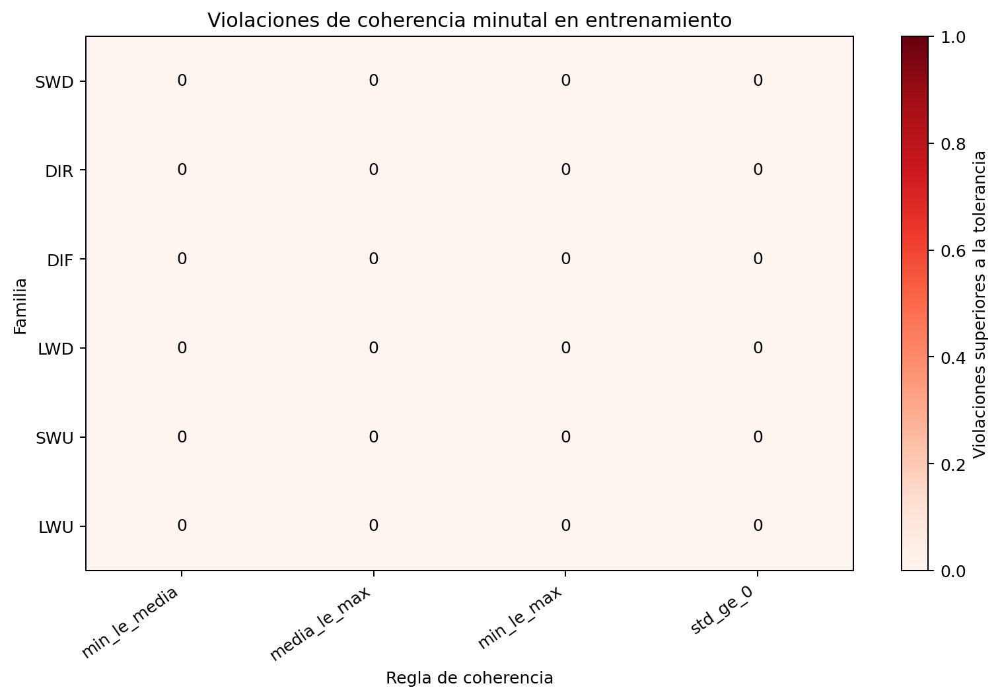


=== FIGURA 2 · COHERENCIA HORARIA ===


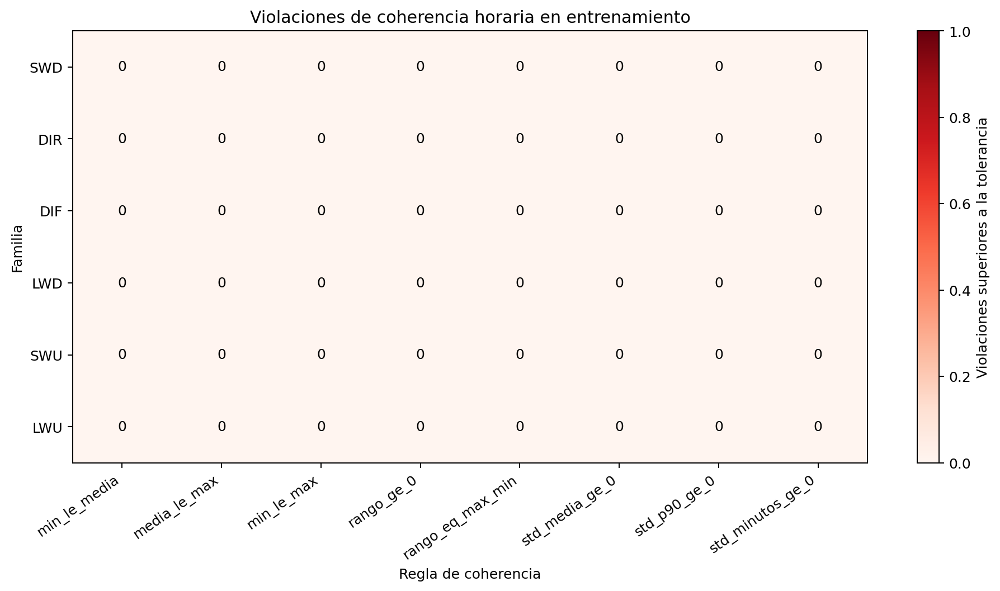


=== PROTECCIÓN DE PARTICIONES ===
Partición analizada: TRAIN
Validation analizada: NO
Test analizado: NO
Filas eliminadas: 0
Valores imputados: 0
Valores corregidos: 0

=== ZIP ===
Nombre: EDA_multivariante_F2_S2_3_20261102T164510Z_b40245b3.zip
Tamaño: 1.21 MiB (1,265,975 bytes)
SHA-256: e8c8ff59fcfbb38673ba2718697c7b45937aa8d879af366c1ed69b43cf2e1a82
Integridad: CORRECTA
Contenido:
 - README.md
 - checkpoints/
 - checkpoints/06_tabla_horaria_particionada_sin_cambios.parquet
 - configuracion/
 - configuracion/configuracion_2_3.json
 - figuras/
 - figuras/01_coherencia_minutal_train.png
 - figuras/02_coherencia_horaria_train.png
 - inventario_archivos.csv
 - resumen_ejecucion.json
 - tablas/
 - tablas/01_resumen_tecnico.csv
 - tablas/02_no_finitos_minutales_train.csv
 - tablas/03_resumen_coherencia_minutal_train.csv
 - tablas/04_detalle_violaciones_minutales_train.csv
 - tablas/05_resumen_coherencia_horaria_train.csv
 - tablas/06_detalle_violaciones_horarias_train.csv
 - tablas/07_hall

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


SUBSECCIÓN 2.3 EJECUTADA SIN ERRORES.


In [7]:
from __future__ import annotations
import gc
import hashlib
import importlib.util
import io
import json
import os
import platform
import shutil
import subprocess
import sys
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath

# Instalar únicamente el motor Parquet si falta.
if importlib.util.find_spec("pyarrow") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyarrow==19.0.1"])

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow
try:
    from IPython.display import Image, display
except ImportError:
    Image, display = None, print

try:
    from google.colab import files as colab_files
    EN_COLAB = True
except ImportError:
    colab_files, EN_COLAB = None, False


# ---------- Contrato ----------
COL_FECHA = "Date/Time"
COL_PARTICION = "particion_observacion"
INICIO_TRAIN = pd.Timestamp("2023-12-28 00:00:00")
FIN_TRAIN = pd.Timestamp("2024-08-01 00:00:00")
N_MINUTOS_TRAIN = 312_480
N_HORAS_TRAIN = 5_208
FAMILIAS = ["SWD", "DIR", "DIF", "LWD", "SWU", "LWU"]

# Solo absorbe diferencias de representación numérica.
# No es una tolerancia física ni instrumental.
TOLERANCIA_NUMERICA = 1e-9

def exigir(condicion, mensaje):
    if not bool(condicion):
        raise AssertionError(mensaje)

def sha256_bytes(datos):
    return hashlib.sha256(datos).hexdigest()

def sha256_archivo(ruta, bloque=1024 * 1024):
    digest = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        for fragmento in iter(lambda: archivo.read(bloque), b""):
            digest.update(fragmento)

    return digest.hexdigest()

def porcentaje(numerador, denominador):
    return 100.0 * numerador / denominador if denominador else np.nan

def inspeccionar_zip(nombre, contenido):
    """
    Comprueba la integridad del ZIP, la seguridad de sus rutas y las
    huellas declaradas en su inventario.
    """
    with zipfile.ZipFile(io.BytesIO(contenido), "r") as z:
        exigir(z.testzip() is None, f"ZIP dañado: {nombre}")
        miembros = z.namelist()
        for miembro in miembros:
            ruta = PurePosixPath(miembro)
            exigir(not ruta.is_absolute(), f"Ruta absoluta dentro de {nombre}: {miembro}")
            exigir(".." not in ruta.parts, f"Ruta insegura dentro de {nombre}: {miembro}")

        exigir("inventario_archivos.csv" in miembros, f"Falta el inventario en {nombre}")
        inventario = pd.read_csv(z.open("inventario_archivos.csv"))
        for fila in inventario.itertuples(index=False):
            exigir(fila.ruta_relativa in miembros, f"Falta {fila.ruta_relativa} en {nombre}")
            datos = z.read(fila.ruta_relativa)
            exigir(len(datos) == int(fila.tamano_bytes), f"Tamaño incorrecto: {fila.ruta_relativa}")
            exigir(sha256_bytes(datos) == fila.sha256, f"SHA-256 incorrecto: {fila.ruta_relativa}")

        return miembros

def registrar_regla(
    *,
    nivel,
    familia,
    regla,
    descripcion,
    fechas,
    izquierda,
    derecha,
    tipo,
    cobertura_ok=None,
    detalle_salida,
):
    """
    Evalúa una regla algebraica y registra las violaciones que superan
    la tolerancia numérica.
    """
    izquierda = pd.Series(izquierda, index=fechas.index, dtype="float64")
    derecha = pd.Series(derecha, index=fechas.index, dtype="float64")
    evaluable = np.isfinite(izquierda) & np.isfinite(derecha)
    if tipo == "le":
        # Regla: izquierda <= derecha
        exceso = izquierda - derecha
        violacion_estricta = evaluable & izquierda.gt(derecha)
        violacion_tolerancia = evaluable & exceso.gt(TOLERANCIA_NUMERICA)

    elif tipo == "ge":
        # Regla: izquierda >= derecha
        exceso = derecha - izquierda
        violacion_estricta = evaluable & izquierda.lt(derecha)
        violacion_tolerancia = evaluable & exceso.gt(TOLERANCIA_NUMERICA)

    elif tipo == "eq":
        # Regla: izquierda == derecha
        exceso = (izquierda - derecha).abs()
        violacion_estricta = evaluable & izquierda.ne(derecha)
        violacion_tolerancia = evaluable & exceso.gt(TOLERANCIA_NUMERICA)

    else:
        raise ValueError(f"Tipo de regla desconocido: {tipo}")

    if cobertura_ok is None:
        cobertura = pd.Series(True, index=fechas.index, dtype=bool)
        aplica_cobertura = False
    else:
        cobertura = pd.Series(cobertura_ok, index=fechas.index, dtype=bool)
        aplica_cobertura = True

    if violacion_tolerancia.any():
        detalle_salida.append(
            pd.DataFrame(
                {
                    "nivel": nivel,
                    COL_FECHA: fechas.loc[violacion_tolerancia].to_numpy(),
                    "familia": familia,
                    "regla": regla,
                    "descripcion": descripcion,
                    "valor_izquierda": izquierda.loc[violacion_tolerancia].to_numpy(),
                    "valor_derecha": derecha.loc[violacion_tolerancia].to_numpy(),
                    "magnitud_violacion": exceso.loc[violacion_tolerancia].to_numpy(),
                    "cobertura_suficiente": cobertura.loc[violacion_tolerancia].to_numpy(),
                }
            )
        )

    evaluable_con_cobertura = evaluable & cobertura
    violacion_con_cobertura = violacion_tolerancia & cobertura
    if evaluable.any():
        max_exceso = float(exceso.loc[evaluable].clip(lower=0).max())
    else:
        max_exceso = np.nan

    return {
        "nivel": nivel,
        "familia": familia,
        "regla": regla,
        "descripcion": descripcion,
        "tipo_comparacion": tipo,
        "tolerancia_numerica_W_m2": TOLERANCIA_NUMERICA,
        "n_filas_totales": int(len(fechas)),
        "n_evaluables": int(evaluable.sum()),
        "n_no_evaluables": int((~evaluable).sum()),
        "n_violaciones_estrictas": int(violacion_estricta.sum()),
        "n_violaciones_tolerancia": int(violacion_tolerancia.sum()),
        "pct_violaciones_sobre_evaluables": porcentaje(
            int(violacion_tolerancia.sum()), int(evaluable.sum())
        ),
        "max_magnitud_violacion_W_m2": max_exceso,
        "aplica_control_cobertura": aplica_cobertura,
        "n_evaluables_con_cobertura": (
            int(evaluable_con_cobertura.sum()) if aplica_cobertura else np.nan
        ),
        "n_violaciones_con_cobertura": (
            int(violacion_con_cobertura.sum()) if aplica_cobertura else np.nan
        ),
    }

def figura_conteos(tabla, reglas, titulo, ruta):
    """
    Crea una matriz familia × regla con el número de violaciones.
    """
    matriz = tabla.pivot(
        index="familia", columns="regla", values="n_violaciones_tolerancia"
    ).reindex(index=FAMILIAS, columns=reglas)
    exigir(matriz.notna().all().all(), f"Matriz incompleta: {titulo}")
    valores = matriz.to_numpy(dtype=float)
    vmax = max(1.0, float(np.nanmax(valores)))
    fig, ax = plt.subplots(figsize=(max(9, len(reglas) * 1.35), 6))
    imagen = ax.imshow(valores, aspect="auto", cmap="Reds", vmin=0, vmax=vmax)
    ax.set_xticks(np.arange(len(reglas)))
    ax.set_xticklabels(reglas, rotation=35, ha="right")
    ax.set_yticks(np.arange(len(FAMILIAS)))
    ax.set_yticklabels(FAMILIAS)
    ax.set_xlabel("Regla de coherencia")
    ax.set_ylabel("Familia")
    ax.set_title(titulo)
    for i in range(len(FAMILIAS)):
        for j in range(len(reglas)):
            valor = int(valores[i, j])
            color = "white" if valor > vmax * 0.55 else "black"
            ax.text(j, i, str(valor), ha="center", va="center", color=color)

    barra = fig.colorbar(imagen, ax=ax)
    barra.set_label("Violaciones superiores a la tolerancia")
    fig.tight_layout()
    fig.savefig(ruta, dpi=180, bbox_inches="tight")
    plt.close(fig)
    exigir(ruta.is_file() and ruta.stat().st_size > 0, f"No se creó {ruta.name}")
    return matriz


# 1. CARGA DE LOS ZIP 1.1 Y 2.2
if EN_COLAB:
    print("Selecciona conjuntamente los dos ZIP validados: " "subsecciones 1.1 y 2.2.")
    archivos_subidos = dict(colab_files.upload())
    exigir(len(archivos_subidos) == 2, "Debes seleccionar exactamente dos archivos ZIP.")

else:
    ruta_1_1 = os.environ.get("EDA_ZIP_1_1_LOCAL")
    ruta_2_2 = os.environ.get("EDA_ZIP_2_2_LOCAL")
    exigir(
        ruta_1_1 and ruta_2_2,
        "Fuera de Colab debes definir EDA_ZIP_1_1_LOCAL " "y EDA_ZIP_2_2_LOCAL.",
    )
    archivos_subidos = {
        Path(ruta_1_1).name: (Path(ruta_1_1).expanduser().resolve().read_bytes()),
        Path(ruta_2_2).name: (Path(ruta_2_2).expanduser().resolve().read_bytes()),
    }


# Identificar los ZIP por su contenido, no por su nombre.
entradas = {}
for nombre, contenido in archivos_subidos.items():
    exigir(Path(nombre).suffix.lower() == ".zip", f"No es un archivo ZIP: {nombre}")
    miembros = inspeccionar_zip(nombre, contenido)
    if "configuracion/configuracion_1_1.json" in miembros:
        clave = "1.1"

    elif "configuracion/configuracion_2_2.json" in miembros:
        clave = "2.2"

    else:
        raise AssertionError(f"No se reconoce el origen del ZIP: {nombre}")

    exigir(clave not in entradas, f"Se ha seleccionado dos veces la subsección {clave}")
    entradas[clave] = {"nombre": nombre, "contenido": contenido, "miembros": miembros}

exigir(set(entradas) == {"1.1", "2.2"}, "Se necesitan exactamente los ZIP 1.1 y 2.2.")


# ---------- Leer el checkpoint minutal de 1.1 ----------
with zipfile.ZipFile(io.BytesIO(entradas["1.1"]["contenido"]), "r") as z:
    config_1_1 = json.loads(z.read("configuracion/configuracion_1_1.json"))
    bytes_minutal = z.read("checkpoints/01_datos_minutales_normalizados.parquet")


# ---------- Leer el checkpoint horario de 2.2 ----------
with zipfile.ZipFile(io.BytesIO(entradas["2.2"]["contenido"]), "r") as z:
    config_2_2 = json.loads(z.read("configuracion/configuracion_2_2.json"))
    resumen_2_2 = json.loads(z.read("resumen_ejecucion.json"))
    bytes_horario = z.read("checkpoints/" "05_tabla_horaria_particionada_sin_cambios.parquet")
    metadatos_previos = pd.read_csv(z.open("tablas/12_metadatos_pendientes.csv"))


# ---------- Validar procedencia ----------
exigir(
    config_1_1.get("fase") == 1 and config_1_1.get("subseccion") == "1.1",
    "El ZIP identificado como 1.1 no es correcto.",
)
exigir(
    config_2_2.get("fase") == 2 and config_2_2.get("subseccion") == "2.2",
    "El ZIP identificado como 2.2 no es correcto.",
)
exigir(resumen_2_2.get("estado") == "COMPLETADO", "La subsección 2.2 no figura completada.")
exigir(
    not config_2_2["alcance"]["validation_analizada"],
    "La entrada 2.2 indica que se analizó validation.",
)
exigir(not config_2_2["alcance"]["test_analizado"], "La entrada 2.2 indica que se analizó test.")
exigir(
    sha256_bytes(bytes_minutal) == config_1_1["checkpoint"]["sha256"],
    "La huella del checkpoint minutal no coincide.",
)
exigir(
    sha256_bytes(bytes_horario) == config_2_2["checkpoint"]["sha256"],
    "La huella del checkpoint horario no coincide.",
)


# ---------- Cargar los dos checkpoints ----------
df_minutal = pd.read_parquet(io.BytesIO(bytes_minutal), engine="pyarrow")
df_horario = pd.read_parquet(io.BytesIO(bytes_horario), engine="pyarrow")


# 2. SELECCIÓN ESTRICTA DE ENTRENAMIENTO
exigir(df_minutal.shape == (570_240, 31), "Forma inesperada del checkpoint minutal.")
exigir(df_horario.shape == (9_504, 132), "Forma inesperada del checkpoint horario.")
exigir(df_minutal[COL_FECHA].is_unique, "Existen timestamps minutales duplicados.")
exigir(df_horario[COL_FECHA].is_unique, "Existen timestamps horarios duplicados.")
exigir(df_minutal[COL_FECHA].is_monotonic_increasing, "Los minutos no están ordenados.")
exigir(df_horario[COL_FECHA].is_monotonic_increasing, "Las horas no están ordenadas.")
train_min = (
    df_minutal.loc[df_minutal[COL_FECHA].ge(INICIO_TRAIN) & df_minutal[COL_FECHA].lt(FIN_TRAIN)]
    .copy(deep=True)
    .reset_index(drop=True)
)
train_h = (
    df_horario.loc[df_horario[COL_PARTICION].eq("train")].copy(deep=True).reset_index(drop=True)
)
exigir(len(train_min) == N_MINUTOS_TRAIN, "Número inesperado de minutos de entrenamiento.")
exigir(len(train_h) == N_HORAS_TRAIN, "Número inesperado de horas de entrenamiento.")
exigir(train_h[COL_PARTICION].eq("train").all(), "Se mezclaron particiones.")
exigir(train_min[COL_FECHA].min() == INICIO_TRAIN, "Inicio minutal incorrecto.")
exigir(
    train_min[COL_FECHA].max() == FIN_TRAIN - pd.Timedelta(minutes=1), "Final minutal incorrecto."
)
exigir(train_h[COL_FECHA].min() == INICIO_TRAIN, "Inicio horario incorrecto.")
exigir(train_h[COL_FECHA].max() == FIN_TRAIN - pd.Timedelta(hours=1), "Final horario incorrecto.")
exigir(
    train_min[COL_FECHA].diff().dropna().eq(pd.Timedelta(minutes=1)).all(),
    "La rejilla minutal no es continua.",
)
exigir(
    train_h[COL_FECHA].diff().dropna().eq(pd.Timedelta(hours=1)).all(),
    "La rejilla horaria no es continua.",
)
horas_desde_minutos = train_min[COL_FECHA].dt.floor("h").drop_duplicates().reset_index(drop=True)
exigir(
    horas_desde_minutos.equals(train_h[COL_FECHA]),
    "Las horas representadas por ambos checkpoints no coinciden.",
)
exigir(
    train_min.groupby(train_min[COL_FECHA].dt.floor("h")).size().eq(60).all(),
    "No existen 60 filas estructurales por hora.",
)


# 3. NO FINITOS EN LOS CAMPOS MINUTALES
filas_no_finitos = []
for familia in FAMILIAS:
    columnas = {
        "media": f"{familia} [W/m**2]",
        "min": f"{familia} min [W/m**2]",
        "max": f"{familia} max [W/m**2]",
        "std": f"{familia} std dev [W/m**2]",
    }
    for estadistico, columna in columnas.items():
        exigir(columna in train_min, f"Falta la columna {columna}")
        valores = train_min[columna].to_numpy(dtype="float64", na_value=np.nan)
        filas_no_finitos.append(
            {
                "familia": familia,
                "estadistico": estadistico,
                "columna": columna,
                "n_minutos_train": N_MINUTOS_TRAIN,
                "n_nan": int(np.isnan(valores).sum()),
                "n_pos_inf": int(np.isposinf(valores).sum()),
                "n_neg_inf": int(np.isneginf(valores).sum()),
                "n_finitos": int(np.isfinite(valores).sum()),
            }
        )

tabla_no_finitos = pd.DataFrame(filas_no_finitos)
exigir(
    (
        tabla_no_finitos[["n_nan", "n_pos_inf", "n_neg_inf", "n_finitos"]]
        .sum(axis=1)
        .eq(N_MINUTOS_TRAIN)
        .all()
    ),
    "Los conteos de no finitos no reconcilian.",
)
n_inf_minutales = int(tabla_no_finitos[["n_pos_inf", "n_neg_inf"]].to_numpy().sum())


# 4. COHERENCIA MINUTAL
resumen_minutal = []
detalle_minutal = []
reglas_minutales = ["min_le_media", "media_le_max", "min_le_max", "std_ge_0"]
for familia in FAMILIAS:
    fechas = train_min[COL_FECHA]
    media = train_min[f"{familia} [W/m**2]"]
    minimo = train_min[f"{familia} min [W/m**2]"]
    maximo = train_min[f"{familia} max [W/m**2]"]
    std = train_min[f"{familia} std dev [W/m**2]"]
    resumen_minutal.extend(
        [
            registrar_regla(
                nivel="minutal",
                familia=familia,
                regla="min_le_media",
                descripcion="mínimo minutal ≤ media minutal",
                fechas=fechas,
                izquierda=minimo,
                derecha=media,
                tipo="le",
                detalle_salida=detalle_minutal,
            ),
            registrar_regla(
                nivel="minutal",
                familia=familia,
                regla="media_le_max",
                descripcion="media minutal ≤ máximo minutal",
                fechas=fechas,
                izquierda=media,
                derecha=maximo,
                tipo="le",
                detalle_salida=detalle_minutal,
            ),
            registrar_regla(
                nivel="minutal",
                familia=familia,
                regla="min_le_max",
                descripcion="mínimo minutal ≤ máximo minutal",
                fechas=fechas,
                izquierda=minimo,
                derecha=maximo,
                tipo="le",
                detalle_salida=detalle_minutal,
            ),
            registrar_regla(
                nivel="minutal",
                familia=familia,
                regla="std_ge_0",
                descripcion="desviación minutal ≥ 0",
                fechas=fechas,
                izquierda=std,
                derecha=pd.Series(0.0, index=fechas.index),
                tipo="ge",
                detalle_salida=detalle_minutal,
            ),
        ]
    )

tabla_resumen_minutal = pd.DataFrame(resumen_minutal)
columnas_detalle = [
    "nivel",
    COL_FECHA,
    "familia",
    "regla",
    "descripcion",
    "valor_izquierda",
    "valor_derecha",
    "magnitud_violacion",
    "cobertura_suficiente",
]
if detalle_minutal:
    tabla_detalle_minutal = pd.concat(detalle_minutal, ignore_index=True)
else:
    tabla_detalle_minutal = pd.DataFrame(columns=columnas_detalle)


# 5. COHERENCIA HORARIA
resumen_horario = []
detalle_horario = []
reglas_horarias = [
    "min_le_media",
    "media_le_max",
    "min_le_max",
    "rango_ge_0",
    "rango_eq_max_min",
    "std_media_ge_0",
    "std_p90_ge_0",
    "std_minutos_ge_0",
]
for familia in FAMILIAS:
    fechas = train_h[COL_FECHA]
    media = train_h[f"{familia}__media_h"]
    minimo = train_h[f"{familia}__min_h"]
    maximo = train_h[f"{familia}__max_h"]
    rango = train_h[f"{familia}__rango_h"]
    std_media = train_h[f"{familia}__std_media_h"]
    std_p90 = train_h[f"{familia}__std_p90_h"]
    std_minutos = train_h[f"{familia}__std_medias_minutales_h"]
    cobertura_media = train_h[f"{familia}__media__cobertura_90_ok"]
    cobertura_min = train_h[f"{familia}__min__cobertura_90_ok"]
    cobertura_max = train_h[f"{familia}__max__cobertura_90_ok"]
    cobertura_std = train_h[f"{familia}__std__cobertura_90_ok"]
    reglas = [
        (
            "min_le_media",
            "mínimo horario ≤ media horaria",
            minimo,
            media,
            "le",
            cobertura_min & cobertura_media,
        ),
        (
            "media_le_max",
            "media horaria ≤ máximo horario",
            media,
            maximo,
            "le",
            cobertura_media & cobertura_max,
        ),
        (
            "min_le_max",
            "mínimo horario ≤ máximo horario",
            minimo,
            maximo,
            "le",
            cobertura_min & cobertura_max,
        ),
        (
            "rango_ge_0",
            "rango horario ≥ 0",
            rango,
            pd.Series(0.0, index=fechas.index),
            "ge",
            cobertura_min & cobertura_max,
        ),
        (
            "rango_eq_max_min",
            "rango horario = máximo − mínimo",
            rango,
            maximo - minimo,
            "eq",
            cobertura_min & cobertura_max,
        ),
        (
            "std_media_ge_0",
            "media horaria de std minutal ≥ 0",
            std_media,
            pd.Series(0.0, index=fechas.index),
            "ge",
            cobertura_std,
        ),
        (
            "std_p90_ge_0",
            "percentil 90 horario de std minutal ≥ 0",
            std_p90,
            pd.Series(0.0, index=fechas.index),
            "ge",
            cobertura_std,
        ),
        (
            "std_minutos_ge_0",
            "std de las medias minutales ≥ 0",
            std_minutos,
            pd.Series(0.0, index=fechas.index),
            "ge",
            cobertura_media,
        ),
    ]
    for regla, descripcion, izquierda, derecha, tipo, cobertura in reglas:
        resumen_horario.append(
            registrar_regla(
                nivel="horario",
                familia=familia,
                regla=regla,
                descripcion=descripcion,
                fechas=fechas,
                izquierda=izquierda,
                derecha=derecha,
                tipo=tipo,
                cobertura_ok=cobertura,
                detalle_salida=detalle_horario,
            )
        )

tabla_resumen_horario = pd.DataFrame(resumen_horario)
if detalle_horario:
    tabla_detalle_horario = pd.concat(detalle_horario, ignore_index=True)
else:
    tabla_detalle_horario = pd.DataFrame(columns=columnas_detalle)


# 6. HALLAZGOS, CONTROLES Y ADVERTENCIAS
n_violaciones_minutales = int(tabla_resumen_minutal["n_violaciones_tolerancia"].sum())
n_violaciones_horarias = int(tabla_resumen_horario["n_violaciones_tolerancia"].sum())
n_violaciones_horarias_con_cobertura = int(
    tabla_resumen_horario["n_violaciones_con_cobertura"].sum()
)
tabla_hallazgos = pd.DataFrame(
    [
        {
            "indicador": ("Violaciones minutales superiores a tolerancia"),
            "resultado": n_violaciones_minutales,
            "unidad": "comparaciones",
        },
        {
            "indicador": ("Violaciones horarias superiores a tolerancia"),
            "resultado": n_violaciones_horarias,
            "unidad": "comparaciones",
        },
        {
            "indicador": ("Violaciones horarias con cobertura 54/60"),
            "resultado": (n_violaciones_horarias_con_cobertura),
            "unidad": "comparaciones",
        },
        {
            "indicador": ("Valores infinitos radiométricos minutales"),
            "resultado": n_inf_minutales,
            "unidad": "valores",
        },
    ]
)
controles = [
    ("ZIP 1.1 identificado", True, True, True),
    ("ZIP 2.2 identificado", True, True, True),
    ("Inventarios de entrada verificados", True, True, True),
    (
        "Minutos de entrenamiento",
        len(train_min),
        N_MINUTOS_TRAIN,
        len(train_min) == N_MINUTOS_TRAIN,
    ),
    ("Horas de entrenamiento", len(train_h), N_HORAS_TRAIN, len(train_h) == N_HORAS_TRAIN),
    ("Familias radiométricas", len(FAMILIAS), 6, len(FAMILIAS) == 6),
    (
        "Reglas minutales evaluadas",
        len(tabla_resumen_minutal),
        24,
        len(tabla_resumen_minutal) == 24,
    ),
    ("Reglas horarias evaluadas", len(tabla_resumen_horario), 48, len(tabla_resumen_horario) == 48),
    (
        "Violaciones detectadas",
        n_violaciones_minutales + n_violaciones_horarias,
        "registradas sin corregir",
        True,
    ),
    ("Filas eliminadas", 0, 0, True),
    ("Valores imputados", 0, 0, True),
    ("Validation analizada", False, False, True),
    ("Test analizado", False, False, True),
]
tabla_resumen_tecnico = pd.DataFrame(
    controles, columns=["comprobacion", "resultado", "esperado", "superado"]
)
exigir(tabla_resumen_tecnico["superado"].all(), "Falló un control técnico de 2.3.")
advertencias = [
    {
        "id": "Q201",
        "advertencia": (
            "La coherencia algebraica no demuestra validez " "física ni calibración correcta."
        ),
        "decision": ("No establecer límites físicos ni corregir valores."),
        "resolver_en": ("Calidad física y documentación instrumental"),
    },
    {
        "id": "Q202",
        "advertencia": (
            "Una hora puede ser algebraicamente coherente " "aunque tenga menos de 54 minutos."
        ),
        "decision": ("Mantener separadas coherencia y cobertura."),
        "resolver_en": ("Disponibilidad de ventanas de 48 horas"),
    },
    {
        "id": "Q203",
        "advertencia": ("La tolerancia 1e-9 W/m² solo absorbe " "diferencias de redondeo."),
        "decision": ("No interpretarla como tolerancia instrumental."),
        "resolver_en": "Documentación metodológica",
    },
    {
        "id": "Q204",
        "advertencia": ("El checkpoint minutal no se duplica en el ZIP."),
        "decision": ("Registrar el nombre y SHA del ZIP 1.1."),
        "resolver_en": "Recarga de análisis minutales",
    },
]
if n_violaciones_minutales + n_violaciones_horarias > 0:
    advertencias.append(
        {
            "id": "Q205",
            "advertencia": (
                f"Se detectaron "
                f"{n_violaciones_minutales + n_violaciones_horarias} "
                f"violaciones superiores a tolerancia."
            ),
            "decision": ("Revisar el detalle; no corregir automáticamente."),
            "resolver_en": "Revisión de resultados de 2.3",
        }
    )

if n_inf_minutales > 0:
    advertencias.append(
        {
            "id": "Q206",
            "advertencia": (f"Se detectaron {n_inf_minutales} infinitos " f"en campos minutales."),
            "decision": ("Revisarlos antes de cualquier tratamiento."),
            "resolver_en": "Revisión de resultados de 2.3",
        }
    )

tabla_advertencias = pd.DataFrame(advertencias)


# 7. CARPETA VERSIONADA Y FIGURAS
marca = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
id_ejecucion = f"{marca}_{uuid.uuid4().hex[:8]}"
nombre_salida = f"EDA_multivariante_F2_S2_3_{id_ejecucion}"
raiz = (
    Path("/content/eda_multivariante_resultados" if EN_COLAB else "./eda_multivariante_resultados")
    .expanduser()
    .resolve()
)
carpeta = raiz / nombre_salida
tablas_dir = carpeta / "tablas"
figuras_dir = carpeta / "figuras"
checkpoints_dir = carpeta / "checkpoints"
config_dir = carpeta / "configuracion"
exigir(not carpeta.exists(), "La carpeta versionada ya existe.")
for directorio in (tablas_dir, figuras_dir, checkpoints_dir, config_dir):
    directorio.mkdir(parents=True, exist_ok=False)

figura_conteos(
    tabla_resumen_minutal,
    reglas_minutales,
    "Violaciones de coherencia minutal en entrenamiento",
    figuras_dir / "01_coherencia_minutal_train.png",
)
figura_conteos(
    tabla_resumen_horario,
    reglas_horarias,
    "Violaciones de coherencia horaria en entrenamiento",
    figuras_dir / "02_coherencia_horaria_train.png",
)


# 8. CHECKPOINT HORARIO SIN CAMBIOS
ruta_checkpoint = checkpoints_dir / "06_tabla_horaria_particionada_sin_cambios.parquet"

# Copia binaria para garantizar que no se transforme.
ruta_checkpoint.write_bytes(bytes_horario)
exigir(sha256_archivo(ruta_checkpoint) == sha256_bytes(bytes_horario), "El checkpoint cambió.")
recarga = pd.read_parquet(ruta_checkpoint, engine="pyarrow")
checkpoint_identico = bool(recarga.equals(df_horario))
del recarga
gc.collect()
exigir(checkpoint_identico, "La recarga del checkpoint no es idéntica.")


# 9. GUARDADO DE TABLAS
tablas_salida = {
    "01_resumen_tecnico.csv": tabla_resumen_tecnico,
    "02_no_finitos_minutales_train.csv": tabla_no_finitos,
    "03_resumen_coherencia_minutal_train.csv": tabla_resumen_minutal,
    "04_detalle_violaciones_minutales_train.csv": tabla_detalle_minutal,
    "05_resumen_coherencia_horaria_train.csv": tabla_resumen_horario,
    "06_detalle_violaciones_horarias_train.csv": tabla_detalle_horario,
    "07_hallazgos_clave_train.csv": tabla_hallazgos,
    "08_advertencias_y_alcance.csv": tabla_advertencias,
    "09_metadatos_pendientes.csv": metadatos_previos,
}
for nombre, tabla in tablas_salida.items():
    tabla.to_csv(tablas_dir / nombre, index=False, encoding="utf-8-sig")


# 10. CONFIGURACIÓN, RESUMEN Y README
configuracion = {
    "fase": 2,
    "subseccion": "2.3",
    "id_ejecucion": id_ejecucion,
    "fecha_utc": datetime.now(timezone.utc).isoformat(),
    "entorno": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "matplotlib": matplotlib.__version__,
        "pyarrow": pyarrow.__version__,
        "colab": EN_COLAB,
    },
    "entradas": {
        "zip_1_1": {
            "nombre": entradas["1.1"]["nombre"],
            "tamano_bytes": len(entradas["1.1"]["contenido"]),
            "sha256_zip": sha256_bytes(entradas["1.1"]["contenido"]),
            "sha256_checkpoint_minutal": (config_1_1["checkpoint"]["sha256"]),
        },
        "zip_2_2": {
            "nombre": entradas["2.2"]["nombre"],
            "tamano_bytes": len(entradas["2.2"]["contenido"]),
            "sha256_zip": sha256_bytes(entradas["2.2"]["contenido"]),
            "sha256_checkpoint_horario": (config_2_2["checkpoint"]["sha256"]),
        },
        "inventarios_verificados": True,
    },
    "alcance": {
        "particion_analizada": "train",
        "inicio_inclusivo": str(INICIO_TRAIN),
        "fin_exclusivo": str(FIN_TRAIN),
        "n_minutos": N_MINUTOS_TRAIN,
        "n_horas": N_HORAS_TRAIN,
        "validation_analizada": False,
        "test_analizado": False,
    },
    "metodologia": {
        "familias": FAMILIAS,
        "tolerancia_numerica_W_m2": (TOLERANCIA_NUMERICA),
        "tolerancia_instrumental_asumida": False,
        "limites_fisicos_aplicados": False,
        "imputacion": False,
        "eliminacion": False,
        "correccion": False,
    },
    "analisis_diferidos": [
        "posibles cambios instrumentales",
        "disponibilidad de ventanas históricas de 48 horas",
        "pérdida de ventanas según familias",
    ],
    "checkpoint": {
        "ruta": ("checkpoints/" "06_tabla_horaria_particionada_sin_cambios.parquet"),
        "forma": list(df_horario.shape),
        "sha256": sha256_archivo(ruta_checkpoint),
        "identico_a_entrada": checkpoint_identico,
    },
}
(config_dir / "configuracion_2_3.json").write_text(
    json.dumps(configuracion, ensure_ascii=False, indent=2), encoding="utf-8"
)
resumen_ejecucion = {
    "estado": "COMPLETADO",
    "particion_analizada": "train",
    "n_minutos_train": N_MINUTOS_TRAIN,
    "n_horas_train": N_HORAS_TRAIN,
    "n_reglas_minutales": len(tabla_resumen_minutal),
    "n_reglas_horarias": len(tabla_resumen_horario),
    "n_violaciones_minutales": (n_violaciones_minutales),
    "n_violaciones_horarias": (n_violaciones_horarias),
    "n_infinitos_minutales": (n_inf_minutales),
    "filas_eliminadas": 0,
    "valores_imputados": 0,
    "validation_analizada": False,
    "test_analizado": False,
}
(carpeta / "resumen_ejecucion.json").write_text(
    json.dumps(resumen_ejecucion, ensure_ascii=False, indent=2), encoding="utf-8"
)
readme = f"""# Fase 2 · Subsección 2.3

Ejecución: {id_ejecucion}

Auditoría algebraica de media, mínimo, máximo, desviación estándar y rango,
realizada exclusivamente en entrenamiento a nivel minutal y horario.

La tolerancia de {TOLERANCIA_NUMERICA} W/m² es únicamente numérica. No se
aplican límites físicos, no se corrigen datos y no se analiza validation o test.

El checkpoint minutal no se duplica; su ZIP y SHA constan en la configuración.
El checkpoint horario de salida es idéntico al recibido de 2.2.

Recarga:

1. Extrae este ZIP.
2. Carga checkpoints/06_tabla_horaria_particionada_sin_cambios.parquet.
3. Comprueba que la forma sea {df_horario.shape}.
4. Para reproducir la parte minutal conserva también el ZIP 1.1 identificado
   en configuracion/configuracion_2_3.json.
"""
(carpeta / "README.md").write_text(readme, encoding="utf-8")


# 11. INVENTARIO Y ZIP
archivos = sorted(ruta for ruta in carpeta.rglob("*") if ruta.is_file())
inventario = pd.DataFrame(
    [
        {
            "ruta_relativa": ruta.relative_to(carpeta).as_posix(),
            "tamano_bytes": ruta.stat().st_size,
            "sha256": sha256_archivo(ruta),
        }
        for ruta in archivos
    ]
)
inventario.to_csv(carpeta / "inventario_archivos.csv", index=False, encoding="utf-8-sig")
ruta_zip = raiz / f"{nombre_salida}.zip"
exigir(not ruta_zip.exists(), "Ya existe el ZIP de esta ejecución.")
ruta_zip_2_3 = Path(shutil.make_archive(str(raiz / nombre_salida), "zip", root_dir=carpeta))
exigir(ruta_zip_2_3.is_file(), "No se creó el ZIP.")
with zipfile.ZipFile(ruta_zip_2_3, "r") as z:
    archivo_danado = z.testzip()
    contenido_zip = sorted(z.namelist())

exigir(archivo_danado is None, f"Archivo dañado dentro del ZIP: {archivo_danado}")
exigir(
    ("checkpoints/" "06_tabla_horaria_particionada_sin_cambios.parquet") in contenido_zip,
    "Falta el checkpoint dentro del ZIP.",
)
tamano_zip = ruta_zip_2_3.stat().st_size
tamano_zip_mib = tamano_zip / 1024**2
sha_zip = sha256_archivo(ruta_zip_2_3)


# 12. RESULTADOS VISIBLES: SOLO ENTRENAMIENTO
print("\n=== RESUMEN TÉCNICO 2.3 ===")
display(tabla_resumen_tecnico)
print("\n=== HALLAZGOS DE COHERENCIA · TRAIN ===")
display(tabla_hallazgos)
print("\n=== NO FINITOS MINUTALES · TRAIN ===")
display(tabla_no_finitos)
print("\n=== COHERENCIA MINUTAL · TRAIN ===")
display(tabla_resumen_minutal)
print("\n=== COHERENCIA HORARIA · TRAIN ===")
display(tabla_resumen_horario)
print("\n=== ADVERTENCIAS Y ALCANCE ===")
display(tabla_advertencias)
if Image is not None:
    print("\n=== FIGURA 1 · COHERENCIA MINUTAL ===")
    display(Image(filename=str(figuras_dir / "01_coherencia_minutal_train.png")))
    print("\n=== FIGURA 2 · COHERENCIA HORARIA ===")
    display(Image(filename=str(figuras_dir / "02_coherencia_horaria_train.png")))

print("\n=== PROTECCIÓN DE PARTICIONES ===")
print("Partición analizada: TRAIN")
print("Validation analizada: NO")
print("Test analizado: NO")
print("Filas eliminadas: 0")
print("Valores imputados: 0")
print("Valores corregidos: 0")
print("\n=== ZIP ===")
print("Nombre:", ruta_zip_2_3.name)
print("Tamaño:", f"{tamano_zip_mib:.2f} MiB " f"({tamano_zip:,} bytes)")
print("SHA-256:", sha_zip)
print("Integridad: CORRECTA")
print("Contenido:")
for elemento in contenido_zip:
    print(" -", elemento)

print("Recarga: consulta README.md dentro del ZIP.")
if tamano_zip_mib > 250:
    raise RuntimeError(
        f"El ZIP ocupa {tamano_zip_mib:.2f} MiB; " "se detiene la descarga automática."
    )

if EN_COLAB:
    colab_files.download(str(ruta_zip_2_3))
else:
    print("ZIP local:", ruta_zip_2_3)

assert tabla_resumen_tecnico["superado"].all()
assert checkpoint_identico
assert archivo_danado is None
assert ruta_zip_2_3.exists()
print("\nSUBSECCIÓN 2.3 EJECUTADA SIN ERRORES.")

**Resultados.**

Se evaluó la coherencia interna de las variables radiométricas en la partición de entrenamiento, formada por 312.480 observaciones minutales y 5.208 observaciones horarias. El análisis comprendió las familias SWD, DIR, DIF, LWD, SWU y LWU, y se realizó sin eliminar, imputar ni corregir valores. A escala minutal se comprobaron las relaciones mínimo ≤ media ≤ máximo y la no negatividad de la desviación estándar. A escala horaria se verificaron adicionalmente la no negatividad del rango, su equivalencia con la diferencia entre máximo y mínimo y la no negatividad de las distintas medidas de variabilidad construidas.

No se detectó ninguna violación en las 24 reglas minutales ni en las 48 reglas horarias evaluadas, tanto mediante comparación estricta como aplicando una tolerancia numérica de 10⁻⁹ W/m². Tampoco se encontraron valores infinitos. Los registros ausentes se excluyeron explícitamente de cada comparación y fueron contabilizados, manteniéndose la proporción de observaciones minutales evaluables entre el 99,79 % y el 99,93 % según la familia. A escala horaria, todas las familias fueron evaluables en las 5.208 horas de entrenamiento, salvo LWD, que presentó una hora completamente ausente ya identificada en el análisis de cobertura.

Estos resultados indican que las estadísticas radiométricas y los agregados horarios son algebraicamente consistentes, por lo que no se considera necesaria ninguna corrección en esta etapa. No obstante, esta comprobación no permite establecer la validez física o la calibración de las mediciones ni determinar la utilidad predictiva de cada estadística. Estas cuestiones deberán evaluarse posteriormente mediante el análisis de estabilidad instrumental, redundancia y relaciones retardadas con DIF<sub>t+1</sub>.

### 2.4 Estabilidad temporal y posibles cambios instrumentales

Una serie puede tener buena cobertura y ser algebraicamente coherente y, aun así, reflejar cambios en el sistema de medida, en la resolución de registro o en el procesamiento. Esta subsección realiza un cribado de esas posibilidades en entrenamiento mediante la cobertura y los resúmenes robustos semanales (mediana y rango intercuartílico), la resolución numérica aparente de cada mes, las rachas de valores exactamente constantes y la comparación de perfiles horarios entre ventanas adyacentes de 14 días, normalizada con la mediana y la desviación absoluta mediana. Los umbrales de cribado se fijaron antes de observar los resultados, y lo detectado se trata como indicio para revisión y no como prueba de un cambio instrumental, ya que la meteorología, la estacionalidad o el redondeo también pueden producir cambios aparentes.

> *Subsección complementaria: no se utiliza en la memoria. Se mantiene porque genera la entrada de la subsección 2.5.*

In [8]:
import sys
import subprocess
import importlib.util

# PyArrow solo es necesario para trabajar con Parquet.
if importlib.util.find_spec("pyarrow") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyarrow"])

import io
import json
import hashlib
import platform
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pyarrow
from IPython.display import display
from google.colab import files

# 1. Configuración congelada
TRAIN_START = pd.Timestamp("2023-12-28 00:00:00")
TRAIN_END = pd.Timestamp("2024-08-01 00:00:00")

# Umbrales de cribado. No son tolerancias instrumentales ni implican corrección.
UMBRAL_CAMBIO_COBERTURA_PP = 5.0
UMBRAL_RACHA_CONSTANTE_MIN = 1440  # 24 horas
UMBRAL_CAMBIO_DECIMALES = 1
UMBRAL_CAMBIO_NO_ENTEROS_PP = 20.0
UMBRAL_Z_CAMBIO_PERFIL = 4.0
UMBRAL_CONSISTENCIA_DIRECCION = 0.75
MIN_HORAS_RELOJ_COMPARABLES = 18
VENTANA_PERFIL_DIAS = 14
MINUTE_CHECKPOINT = "checkpoints/01_datos_minutales_normalizados.parquet"
HOURLY_CHECKPOINT = "checkpoints/06_tabla_horaria_particionada_sin_cambios.parquet"
MINUTE_COLUMNS = {
    "SWD": "SWD [W/m**2]",
    "DIR": "DIR [W/m**2]",
    "DIF": "DIF [W/m**2]",
    "LWD": "LWD [W/m**2]",
    "SWU": "SWU [W/m**2]",
    "LWU": "LWU [W/m**2]",
    "T2": "T2 [°C]",
    "RH": "RH [%]",
    "PoPoPoPo": "PoPoPoPo [hPa]",
}
HOURLY_COLUMNS = {family: f"{family}__media_h" for family in MINUTE_COLUMNS}
COVERAGE_COLUMNS = {
    **{
        family: f"{family}__media__cobertura_90_ok"
        for family in ["SWD", "DIR", "DIF", "LWD", "SWU", "LWU"]
    },
    "T2": "T2__cobertura_90_ok",
    "RH": "RH__cobertura_90_ok",
    "PoPoPoPo": "PoPoPoPo__cobertura_90_ok",
}
UNITS = {
    "SWD": "W/m²",
    "DIR": "W/m²",
    "DIF": "W/m²",
    "LWD": "W/m²",
    "SWU": "W/m²",
    "LWU": "W/m²",
    "T2": "°C",
    "RH": "%",
    "PoPoPoPo": "hPa",
}
FAMILIES = list(MINUTE_COLUMNS)
RADIOMETRIC = ["SWD", "DIR", "DIF", "LWD", "SWU", "LWU"]
METEOROLOGICAL = ["T2", "RH", "PoPoPoPo"]


# 2. Funciones auxiliares
def sha256_bytes(data):
    """Calcula el SHA-256 de un objeto bytes."""
    return hashlib.sha256(data).hexdigest()

def sha256_file(path, chunk_size=1024 * 1024):
    """Calcula el SHA-256 de un archivo sin cargarlo entero en memoria."""
    digest = hashlib.sha256()
    with Path(path).open("rb") as file:
        while True:
            chunk = file.read(chunk_size)
            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()

def verify_zip_inventory(raw_zip, label):
    """
    Verifica:
    - integridad CRC;
    - existencia de los archivos inventariados;
    - tamaños;
    - hashes SHA-256.
    """
    with zipfile.ZipFile(io.BytesIO(raw_zip)) as zip_file:
        assert zip_file.testzip() is None, f"{label}: el ZIP contiene un archivo dañado."
        assert (
            "inventario_archivos.csv" in zip_file.namelist()
        ), f"{label}: falta inventario_archivos.csv."
        inventory = pd.read_csv(
            io.BytesIO(zip_file.read("inventario_archivos.csv")), encoding="utf-8-sig"
        )
        required_columns = {"ruta_relativa", "tamano_bytes", "sha256"}
        assert required_columns.issubset(inventory.columns), f"{label}: inventario incompleto."
        for row in inventory.itertuples(index=False):
            relative_path = str(row.ruta_relativa)
            assert relative_path in zip_file.namelist(), f"{label}: falta {relative_path}."
            content = zip_file.read(relative_path)
            assert len(content) == int(
                row.tamano_bytes
            ), f"{label}: tamaño incorrecto en {relative_path}."
            assert sha256_bytes(content) == str(
                row.sha256
            ), f"{label}: SHA-256 incorrecto en {relative_path}."

    return inventory

def week_start_from_timestamp(series):
    """
    Calcula el lunes de cada semana según el reloj del dataset.
    No asigna ni supone una zona horaria.
    """
    return (series - pd.to_timedelta(series.dt.weekday, unit="D")).dt.normalize()

def decimal_places_95(values, max_decimals=6):
    """
    Obtiene el menor número de decimales que permite representar
    al menos el 95 % de los valores.
    """
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if values.size == 0:
        return -1

    values = np.round(values, max_decimals)
    for decimals in range(max_decimals + 1):
        fitted = np.isclose(values, np.round(values, decimals), rtol=0.0, atol=1e-8)
        if float(fitted.mean()) >= 0.95:
            return decimals

    return max_decimals

def robust_positive_z(series):
    """
    Calcula una puntuación robusta respecto a la mediana.
    Si la serie no tiene dispersión, devuelve cero.
    """
    values = pd.to_numeric(series, errors="coerce").to_numpy(dtype=float)
    result = np.full(values.shape, np.nan, dtype=float)
    valid = np.isfinite(values)
    if not valid.any():
        return pd.Series(result, index=series.index)

    median = float(np.median(values[valid]))
    mad = float(np.median(np.abs(values[valid] - median)))
    if mad <= np.finfo(float).eps:
        result[valid] = 0.0
    else:
        result[valid] = 0.67448975 * (values[valid] - median) / mad

    return pd.Series(result, index=series.index)

def save_csv(dataframe, path):
    """Guarda un CSV con codificación compatible con Excel."""
    dataframe.to_csv(path, index=False, encoding="utf-8-sig")


# 3. Carga e identificación de los ZIP de entrada
print("Selecciona conjuntamente los dos ZIP validados: " "subsecciones 1.1 y 2.3.")
uploaded = files.upload()
assert len(uploaded) == 2, (
    "Debes seleccionar exactamente dos ZIP: " "el correspondiente a 1.1 y el correspondiente a 2.3."
)
identified = {}
for uploaded_name, raw_zip in uploaded.items():
    assert zipfile.is_zipfile(io.BytesIO(raw_zip)), f"{uploaded_name} no es un ZIP válido."
    with zipfile.ZipFile(io.BytesIO(raw_zip)) as zip_file:
        members = set(zip_file.namelist())
        if MINUTE_CHECKPOINT in members:
            assert "zip_1_1" not in identified, "Se seleccionaron dos ZIP de la subsección 1.1."
            identified["zip_1_1"] = (uploaded_name, raw_zip)

        if HOURLY_CHECKPOINT in members:
            assert "zip_2_3" not in identified, "Se seleccionaron dos ZIP de la subsección 2.3."
            identified["zip_2_3"] = (uploaded_name, raw_zip)

assert set(identified) == {"zip_1_1", "zip_2_3"}, (
    "No se pudieron identificar conjuntamente " "los ZIP de 1.1 y 2.3."
)
name_11, raw_zip_11 = identified["zip_1_1"]
name_23, raw_zip_23 = identified["zip_2_3"]
inventory_11 = verify_zip_inventory(raw_zip_11, "ZIP 1.1")
inventory_23 = verify_zip_inventory(raw_zip_23, "ZIP 2.3")
with zipfile.ZipFile(io.BytesIO(raw_zip_11)) as zip_file:
    minute_checkpoint_bytes = zip_file.read(MINUTE_CHECKPOINT)
    config_11 = json.loads(zip_file.read("configuracion/configuracion_1_1.json"))

with zipfile.ZipFile(io.BytesIO(raw_zip_23)) as zip_file:
    hourly_checkpoint_bytes = zip_file.read(HOURLY_CHECKPOINT)
    config_23 = json.loads(zip_file.read("configuracion/configuracion_2_3.json"))

sha_minute_checkpoint = sha256_bytes(minute_checkpoint_bytes)
sha_hourly_checkpoint = sha256_bytes(hourly_checkpoint_bytes)
assert config_11["fase"] == 1
assert str(config_11["subseccion"]) == "1.1"
assert config_23["fase"] == 2
assert str(config_23["subseccion"]) == "2.3"
assert sha_minute_checkpoint == config_11["checkpoint"]["sha256"]
assert sha_hourly_checkpoint == config_23["checkpoint"]["sha256"]
assert sha_minute_checkpoint == config_23["entradas"]["zip_1_1"]["sha256_checkpoint_minutal"], (
    "El checkpoint minutal no coincide " "con el linaje registrado en 2.3."
)
df_minute_source = pd.read_parquet(io.BytesIO(minute_checkpoint_bytes))
df_hourly_source = pd.read_parquet(io.BytesIO(hourly_checkpoint_bytes))
assert df_minute_source.shape == (570240, 31)
assert df_hourly_source.shape == (9504, 132)
required_minute = {"Date/Time", *MINUTE_COLUMNS.values()}
required_hourly = {
    "Date/Time",
    "particion_observacion",
    *HOURLY_COLUMNS.values(),
    *COVERAGE_COLUMNS.values(),
}
assert required_minute.issubset(df_minute_source.columns)
assert required_hourly.issubset(df_hourly_source.columns)
assert pd.api.types.is_datetime64_any_dtype(df_minute_source["Date/Time"])
assert pd.api.types.is_datetime64_any_dtype(df_hourly_source["Date/Time"])
assert df_minute_source["Date/Time"].dt.tz is None
assert df_hourly_source["Date/Time"].dt.tz is None
assert df_minute_source["Date/Time"].is_monotonic_increasing
assert df_hourly_source["Date/Time"].is_monotonic_increasing
assert not df_minute_source["Date/Time"].duplicated().any()
assert not df_hourly_source["Date/Time"].duplicated().any()


# 4. Copias exclusivas de entrenamiento
minute_train_mask = df_minute_source["Date/Time"].between(TRAIN_START, TRAIN_END, inclusive="left")
hourly_train_mask = df_hourly_source["particion_observacion"].eq("train")
minute_train = df_minute_source.loc[
    minute_train_mask, ["Date/Time", *MINUTE_COLUMNS.values()]
].copy()
hourly_train = df_hourly_source.loc[
    hourly_train_mask,
    ["Date/Time", "particion_observacion", *HOURLY_COLUMNS.values(), *COVERAGE_COLUMNS.values()],
].copy()
assert len(minute_train) == 312480
assert len(hourly_train) == 5208
assert minute_train["Date/Time"].min() == TRAIN_START
assert minute_train["Date/Time"].max() == TRAIN_END - pd.Timedelta(minutes=1)
assert hourly_train["Date/Time"].min() == TRAIN_START
assert hourly_train["Date/Time"].max() == TRAIN_END - pd.Timedelta(hours=1)
assert minute_train["Date/Time"].diff().dropna().eq(pd.Timedelta(minutes=1)).all()
assert hourly_train["Date/Time"].diff().dropna().eq(pd.Timedelta(hours=1)).all()
assert hourly_train["particion_observacion"].eq("train").all()


# 5. Cobertura semanal de las variables primarias
minute_train["semana_inicio"] = week_start_from_timestamp(minute_train["Date/Time"])
weekly_coverage_parts = []
for family, column in MINUTE_COLUMNS.items():
    values = pd.to_numeric(minute_train[column], errors="coerce").to_numpy(dtype=float)
    temporary = pd.DataFrame(
        {"semana_inicio": (minute_train["semana_inicio"].to_numpy()), "valido": np.isfinite(values)}
    )
    grouped = temporary.groupby("semana_inicio", sort=True, as_index=False).agg(
        n_minutos_estructurales=("valido", "size"), n_minutos_validos=("valido", "sum")
    )
    grouped.insert(0, "familia", family)
    grouped["semana_fin_exclusiva"] = grouped["semana_inicio"] + pd.Timedelta(days=7)
    grouped["pct_validos"] = (
        100.0 * grouped["n_minutos_validos"] / grouped["n_minutos_estructurales"]
    )
    grouped["pct_ausentes"] = 100.0 - grouped["pct_validos"]
    grouped["delta_cobertura_pp"] = grouped["pct_validos"].diff()
    grouped["indicio_cambio_cobertura"] = (
        grouped["delta_cobertura_pp"].abs().ge(UMBRAL_CAMBIO_COBERTURA_PP)
    )
    weekly_coverage_parts.append(grouped)

weekly_coverage = pd.concat(weekly_coverage_parts, ignore_index=True)
weekly_coverage = weekly_coverage.sort_values(["familia", "semana_inicio"], ignore_index=True)


# 6. Resumen semanal robusto de los valores horarios
hourly_train["semana_inicio"] = week_start_from_timestamp(hourly_train["Date/Time"])
weekly_value_parts = []
for family in FAMILIES:
    value_column = HOURLY_COLUMNS[family]
    coverage_column = COVERAGE_COLUMNS[family]
    values = pd.to_numeric(hourly_train[value_column], errors="coerce")
    coverage_ok = hourly_train[coverage_column].fillna(False).astype(bool)
    finite = np.isfinite(values.to_numpy(dtype=float))
    valid = coverage_ok.to_numpy() & finite
    temporary = pd.DataFrame(
        {
            "semana_inicio": (hourly_train["semana_inicio"].to_numpy()),
            "valor": values.to_numpy(dtype=float),
            "valor_valido": (values.where(valid).to_numpy(dtype=float)),
            "valido": valid,
        }
    )
    grouped = temporary.groupby("semana_inicio", sort=True, as_index=False).agg(
        n_horas_estructurales=("valor", "size"),
        n_horas_cobertura_ok=("valido", "sum"),
        mediana=("valor_valido", "median"),
        q25=("valor_valido", lambda x: x.quantile(0.25)),
        q75=("valor_valido", lambda x: x.quantile(0.75)),
    )
    grouped.insert(0, "familia", family)
    grouped.insert(1, "unidad", UNITS[family])
    grouped["semana_fin_exclusiva"] = grouped["semana_inicio"] + pd.Timedelta(days=7)
    grouped["semana_estructural_completa"] = grouped["n_horas_estructurales"].eq(168)
    grouped["pct_horas_cobertura_ok"] = (
        100.0 * grouped["n_horas_cobertura_ok"] / grouped["n_horas_estructurales"]
    )
    grouped["iqr"] = grouped["q75"] - grouped["q25"]
    weekly_value_parts.append(grouped)

weekly_values = pd.concat(weekly_value_parts, ignore_index=True)
weekly_values = weekly_values.sort_values(["familia", "semana_inicio"], ignore_index=True)


# 7. Resolución numérica aparente por mes
minute_train["mes"] = minute_train["Date/Time"].dt.to_period("M").astype(str)
resolution_records = []
for family, column in MINUTE_COLUMNS.items():
    for month, block in minute_train.groupby("mes", sort=True):
        values = pd.to_numeric(block[column], errors="coerce").to_numpy(dtype=float)
        values = values[np.isfinite(values)]
        if values.size:
            rounded = np.round(values, 6)
            unique_values, counts = np.unique(rounded, return_counts=True)
            differences = np.diff(unique_values)
            positive_steps = differences[differences > 1e-8]
            mode_position = int(np.argmax(counts))
            pct_non_integer = 100.0 * float(
                (~np.isclose(rounded, np.round(rounded), rtol=0.0, atol=1e-8)).mean()
            )
            if positive_steps.size:
                minimum_positive_step = float(positive_steps.min())
            else:
                minimum_positive_step = np.nan

            mode_value = float(unique_values[mode_position])
            mode_pct = 100.0 * float(counts[mode_position]) / float(values.size)
            decimals_95 = decimal_places_95(rounded)

        else:
            unique_values = np.array([])
            pct_non_integer = np.nan
            minimum_positive_step = np.nan
            mode_value = np.nan
            mode_pct = np.nan
            decimals_95 = -1

        resolution_records.append(
            {
                "familia": family,
                "unidad": UNITS[family],
                "mes": month,
                "n_validos": int(values.size),
                "n_valores_unicos": int(unique_values.size),
                "pct_valores_no_enteros": (pct_non_integer),
                "decimales_necesarios_95pct": int(decimals_95),
                "paso_minimo_positivo_aprox": (minimum_positive_step),
                "valor_modal": mode_value,
                "pct_valor_modal": mode_pct,
            }
        )

monthly_resolution = pd.DataFrame(resolution_records).sort_values(
    ["familia", "mes"], ignore_index=True
)
monthly_resolution["mes_previo"] = monthly_resolution.groupby("familia")["mes"].shift()
monthly_resolution["cambio_decimales_95"] = monthly_resolution.groupby("familia")[
    "decimales_necesarios_95pct"
].diff()
monthly_resolution["cambio_pct_no_enteros_pp"] = monthly_resolution.groupby("familia")[
    "pct_valores_no_enteros"
].diff()
monthly_resolution["indicio_cambio_resolucion"] = monthly_resolution[
    "cambio_decimales_95"
].abs().ge(UMBRAL_CAMBIO_DECIMALES) | monthly_resolution["cambio_pct_no_enteros_pp"].abs().ge(
    UMBRAL_CAMBIO_NO_ENTEROS_PP
)


# 8. Rachas exactas de valores constantes
timestamps_minute = minute_train["Date/Time"].to_numpy()
run_summary_records = []
top_run_records = []
flatline_candidate_records = []
for family, column in MINUTE_COLUMNS.items():
    values = pd.to_numeric(minute_train[column], errors="coerce").to_numpy(dtype=float)
    finite = np.isfinite(values)
    same_as_previous = finite[1:] & finite[:-1] & (values[1:] == values[:-1])
    boundaries = np.flatnonzero(~same_as_previous)
    starts = np.r_[0, boundaries + 1]
    ends = np.r_[boundaries, len(values) - 1]
    valid_runs = finite[starts]
    starts = starts[valid_runs]
    ends = ends[valid_runs]
    lengths = ends - starts + 1
    if lengths.size:
        max_position = int(np.argmax(lengths))
        max_length = int(lengths[max_position])
        max_start = int(starts[max_position])
        max_end = int(ends[max_position])
        max_value = float(values[max_start])
        order = np.argsort(-lengths, kind="stable")[:10]

    else:
        max_length = 0
        max_start = None
        max_end = None
        max_value = np.nan
        order = np.array([], dtype=int)

    minutes_in_runs_ge_60 = int(lengths[lengths >= 60].sum())
    number_finite = int(finite.sum())
    run_summary_records.append(
        {
            "familia": family,
            "unidad": UNITS[family],
            "n_valores_finitos": number_finite,
            "n_rachas_finitas": int(lengths.size),
            "n_rachas_ge_60min": int((lengths >= 60).sum()),
            "n_rachas_ge_180min": int((lengths >= 180).sum()),
            "n_rachas_ge_360min": int((lengths >= 360).sum()),
            "n_rachas_ge_1440min": int((lengths >= 1440).sum()),
            "pct_minutos_en_rachas_ge_60min": (
                100.0 * minutes_in_runs_ge_60 / number_finite if number_finite else np.nan
            ),
            "racha_max_minutos": max_length,
            "inicio_racha_max": (
                pd.Timestamp(timestamps_minute[max_start]) if max_start is not None else pd.NaT
            ),
            "fin_racha_max_inclusivo": (
                pd.Timestamp(timestamps_minute[max_end]) if max_end is not None else pd.NaT
            ),
            "valor_racha_max": max_value,
        }
    )
    for ranking, position in enumerate(order, start=1):
        start_position = int(starts[position])
        end_position = int(ends[position])
        top_run_records.append(
            {
                "familia": family,
                "unidad": UNITS[family],
                "ranking_familia": ranking,
                "inicio": pd.Timestamp(timestamps_minute[start_position]),
                "fin_inclusivo": pd.Timestamp(timestamps_minute[end_position]),
                "duracion_minutos": int(lengths[position]),
                "valor_constante": float(values[start_position]),
                "supera_60min": bool(lengths[position] >= 60),
                "supera_1440min": bool(lengths[position] >= UMBRAL_RACHA_CONSTANTE_MIN),
            }
        )

    candidate_positions = np.flatnonzero(lengths >= UMBRAL_RACHA_CONSTANTE_MIN)
    for position in candidate_positions:
        start_position = int(starts[position])
        end_position = int(ends[position])
        flatline_candidate_records.append(
            {
                "familia": family,
                "inicio": pd.Timestamp(timestamps_minute[start_position]),
                "fin_inclusivo": pd.Timestamp(timestamps_minute[end_position]),
                "duracion_minutos": int(lengths[position]),
                "valor_constante": float(values[start_position]),
            }
        )

run_summary = pd.DataFrame(run_summary_records)
top_runs = pd.DataFrame(top_run_records).sort_values(
    ["familia", "ranking_familia"], ignore_index=True
)
flatline_candidates = pd.DataFrame(flatline_candidate_records)


# 9. Cambios persistentes del perfil horario
cut_dates = pd.date_range(
    start=(TRAIN_START + pd.Timedelta(days=VENTANA_PERFIL_DIAS)),
    end=(TRAIN_END - pd.Timedelta(days=VENTANA_PERFIL_DIAS)),
    freq="7D",
)
profile_records = []
for family in FAMILIES:
    value_column = HOURLY_COLUMNS[family]
    coverage_column = COVERAGE_COLUMNS[family]
    values = pd.to_numeric(hourly_train[value_column], errors="coerce").to_numpy(dtype=float)
    valid = hourly_train[coverage_column].fillna(False).astype(bool).to_numpy() & np.isfinite(
        values
    )
    work = pd.DataFrame(
        {
            "timestamp": (hourly_train["Date/Time"].to_numpy()),
            "hora_reloj_dataset": (hourly_train["Date/Time"].dt.hour.to_numpy()),
            "valor": values,
            "valido": valid,
        }
    )
    global_values = values[valid]
    assert global_values.size > 0, f"No existen valores válidos para {family}."
    q25, q75 = np.quantile(global_values, [0.25, 0.75])
    scale = float(q75 - q25)
    if scale <= np.finfo(float).eps:
        median = float(np.median(global_values))
        scale = 1.4826 * float(np.median(np.abs(global_values - median)))

    if scale <= np.finfo(float).eps:
        scale = float(np.std(global_values, ddof=0))

    if scale <= np.finfo(float).eps:
        scale = np.nan

    for cut_date in cut_dates:
        before_start = cut_date - pd.Timedelta(days=VENTANA_PERFIL_DIAS)
        after_end = cut_date + pd.Timedelta(days=VENTANA_PERFIL_DIAS)
        before = work.loc[
            work["timestamp"].between(before_start, cut_date, inclusive="left") & work["valido"]
        ]
        after = work.loc[
            work["timestamp"].between(cut_date, after_end, inclusive="left") & work["valido"]
        ]
        before_stats = before.groupby("hora_reloj_dataset")["valor"].agg(
            n_antes="count", mediana_antes="median"
        )
        after_stats = after.groupby("hora_reloj_dataset")["valor"].agg(
            n_despues="count", mediana_despues="median"
        )
        comparison = before_stats.join(after_stats, how="inner")
        comparison = comparison.loc[
            comparison["n_antes"].ge(10) & comparison["n_despues"].ge(10)
        ].copy()
        if comparison.empty:
            number_hours = 0
            median_absolute_delta = np.nan
            median_signed_delta = np.nan
            direction_consistency = np.nan
            score_iqr = np.nan

        else:
            delta = (comparison["mediana_despues"] - comparison["mediana_antes"]).to_numpy(
                dtype=float
            )
            number_hours = int(delta.size)
            median_absolute_delta = float(np.median(np.abs(delta)))
            median_signed_delta = float(np.median(delta))
            nonzero = delta[delta != 0]
            if nonzero.size:
                direction_consistency = float(max((nonzero > 0).mean(), (nonzero < 0).mean()))

            else:
                direction_consistency = 0.0

            if np.isfinite(scale):
                score_iqr = median_absolute_delta / scale
            else:
                score_iqr = np.nan

        profile_records.append(
            {
                "familia": family,
                "unidad": UNITS[family],
                "fecha_corte": cut_date,
                "inicio_ventana_antes": (before_start),
                "fin_ventana_despues_exclusivo": (after_end),
                "n_horas_reloj_comparables": (number_hours),
                "delta_mediana_abs_perfil": (median_absolute_delta),
                "delta_mediana_signed_perfil": (median_signed_delta),
                "consistencia_direccion": (direction_consistency),
                "escala_iqr_train": scale,
                "score_iqr": score_iqr,
            }
        )

profile_scores = pd.DataFrame(profile_records).sort_values(
    ["familia", "fecha_corte"], ignore_index=True
)
profile_scores["z_robusto_score"] = profile_scores.groupby("familia", group_keys=False)[
    "score_iqr"
].transform(robust_positive_z)
profile_scores["indicio_cambio_perfil"] = (
    profile_scores["z_robusto_score"].ge(UMBRAL_Z_CAMBIO_PERFIL)
    & profile_scores["consistencia_direccion"].ge(UMBRAL_CONSISTENCIA_DIRECCION)
    & profile_scores["n_horas_reloj_comparables"].ge(MIN_HORAS_RELOJ_COMPARABLES)
)


# 10. Registro unificado de indicios
candidate_columns = [
    "tipo_indicio",
    "familia",
    "inicio",
    "fin_exclusivo",
    "magnitud",
    "unidad_magnitud",
    "criterio_cribado",
    "cambio_instrumental_confirmado",
    "accion_automatica",
    "cautela",
]
candidate_records = []


# Cambios de cobertura
coverage_candidates = weekly_coverage.loc[weekly_coverage["indicio_cambio_cobertura"]]
for row in coverage_candidates.itertuples(index=False):
    candidate_records.append(
        {
            "tipo_indicio": ("cambio_cobertura_semanal"),
            "familia": row.familia,
            "inicio": row.semana_inicio,
            "fin_exclusivo": (row.semana_fin_exclusiva),
            "magnitud": float(row.delta_cobertura_pp),
            "unidad_magnitud": ("puntos porcentuales"),
            "criterio_cribado": (f"|Δ cobertura| ≥ " f"{UMBRAL_CAMBIO_COBERTURA_PP} pp"),
            "cambio_instrumental_confirmado": False,
            "accion_automatica": "ninguna",
            "cautela": ("Puede corresponder a una incidencia " "de disponibilidad."),
        }
    )


# Cambios de resolución aparente
resolution_candidates = monthly_resolution.loc[monthly_resolution["indicio_cambio_resolucion"]]
for row in resolution_candidates.itertuples(index=False):
    start = pd.Timestamp(f"{row.mes}-01")
    if abs(float(row.cambio_decimales_95)) >= UMBRAL_CAMBIO_DECIMALES:
        resolution_magnitude = float(row.cambio_decimales_95)
        resolution_unit = "decimales necesarios (cambio)"

    else:
        resolution_magnitude = float(row.cambio_pct_no_enteros_pp)
        resolution_unit = "puntos porcentuales no enteros"

    candidate_records.append(
        {
            "tipo_indicio": ("cambio_resolucion_aparente"),
            "familia": row.familia,
            "inicio": start,
            "fin_exclusivo": (start + pd.offsets.MonthBegin(1)),
            "magnitud": resolution_magnitude,
            "unidad_magnitud": resolution_unit,
            "criterio_cribado": (
                f"|Δ decimales| ≥ "
                f"{UMBRAL_CAMBIO_DECIMALES} o "
                f"|Δ % no enteros| ≥ "
                f"{UMBRAL_CAMBIO_NO_ENTEROS_PP} pp"
            ),
            "cambio_instrumental_confirmado": False,
            "accion_automatica": "ninguna",
            "cautela": ("Puede deberse al formato o " "redondeo del archivo fuente."),
        }
    )


# Rachas constantes de al menos 24 horas
if not flatline_candidates.empty:
    for row in flatline_candidates.itertuples(index=False):
        candidate_records.append(
            {
                "tipo_indicio": ("racha_exactamente_constante"),
                "familia": row.familia,
                "inicio": row.inicio,
                "fin_exclusivo": (row.fin_inclusivo + pd.Timedelta(minutes=1)),
                "magnitud": float(row.duracion_minutos),
                "unidad_magnitud": "minutos",
                "criterio_cribado": (f"racha exacta ≥ " f"{UMBRAL_RACHA_CONSTANTE_MIN} min"),
                "cambio_instrumental_confirmado": False,
                "accion_automatica": "ninguna",
                "cautela": ("Un valor constante puede ser natural " "o consecuencia del redondeo."),
            }
        )


# Cambios persistentes del perfil horario
profile_candidates = profile_scores.loc[profile_scores["indicio_cambio_perfil"]]
for row in profile_candidates.itertuples(index=False):
    candidate_records.append(
        {
            "tipo_indicio": ("cambio_persistente_perfil_horario"),
            "familia": row.familia,
            "inicio": row.inicio_ventana_antes,
            "fin_exclusivo": (row.fin_ventana_despues_exclusivo),
            "magnitud": float(row.z_robusto_score),
            "unidad_magnitud": ("z robusto de cribado"),
            "criterio_cribado": (
                f"z ≥ {UMBRAL_Z_CAMBIO_PERFIL}, "
                f"consistencia ≥ "
                f"{UMBRAL_CONSISTENCIA_DIRECCION:.2f} "
                f"y ≥ {MIN_HORAS_RELOJ_COMPARABLES} "
                f"horas comparables"
            ),
            "cambio_instrumental_confirmado": False,
            "accion_automatica": "ninguna",
            "cautela": (
                "La meteorología y la estacionalidad " "residual también pueden producirlo."
            ),
        }
    )

candidates = pd.DataFrame(candidate_records, columns=candidate_columns)
if not candidates.empty:
    candidates = candidates.sort_values(["inicio", "tipo_indicio", "familia"], ignore_index=True)


# 11. Resumen de indicios por familia
family_summary_records = []
for family in FAMILIES:
    family_candidates = candidates.loc[candidates["familia"].eq(family)]
    family_profile = profile_scores.loc[profile_scores["familia"].eq(family)]
    family_coverage = weekly_coverage.loc[weekly_coverage["familia"].eq(family)]
    family_resolution = monthly_resolution.loc[monthly_resolution["familia"].eq(family)]
    family_runs = run_summary.loc[run_summary["familia"].eq(family)].iloc[0]
    family_summary_records.append(
        {
            "familia": family,
            "max_cambio_abs_cobertura_pp": float(
                family_coverage["delta_cobertura_pp"].abs().max(skipna=True)
            ),
            "n_indicios_cobertura": int(family_coverage["indicio_cambio_cobertura"].sum()),
            "n_indicios_resolucion": int(family_resolution["indicio_cambio_resolucion"].sum()),
            "racha_exacta_max_minutos": int(family_runs["racha_max_minutos"]),
            "n_indicios_racha_24h": int(family_runs["n_rachas_ge_1440min"]),
            "max_z_cambio_perfil": float(family_profile["z_robusto_score"].max(skipna=True)),
            "n_indicios_perfil": int(family_profile["indicio_cambio_perfil"].sum()),
            "n_indicios_totales": int(len(family_candidates)),
            "cambio_instrumental_confirmado": False,
            "decision": (
                "revisión contextual; sin corrección"
                if len(family_candidates)
                else ("sin indicios sobre los umbrales; " "sin corrección")
            ),
        }
    )

family_summary = pd.DataFrame(family_summary_records)


# 12. Figuras diagnósticas
plt.style.use("seaborn-v0_8-whitegrid")


# Figura 1: cobertura semanal
fig_coverage, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
plot_groups = [
    (axes[0], RADIOMETRIC, "Familias radiométricas"),
    (axes[1], METEOROLOGICAL, "Variables meteorológicas"),
]
for axis, families, title in plot_groups:
    for family in families:
        block = weekly_coverage.loc[weekly_coverage["familia"].eq(family)]
        axis.plot(
            block["semana_inicio"],
            block["pct_ausentes"],
            marker="o",
            markersize=3,
            linewidth=1.2,
            label=family,
        )

    axis.set_ylabel("Minutos ausentes (%)")
    axis.set_title(title)
    axis.legend(ncol=min(3, len(families)), fontsize=9)

axes[-1].set_xlabel("Fecha del dataset " "(zona horaria pendiente)")
axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
fig_coverage.suptitle("Cobertura semanal de variables primarias · entrenamiento", fontsize=15)
fig_coverage.autofmt_xdate()
fig_coverage.tight_layout()


# Figura 2: evolución semanal robusta
fig_weekly, axes_weekly = plt.subplots(3, 3, figsize=(17, 12), sharex=True)
for axis, family in zip(axes_weekly.ravel(), FAMILIES):
    block = weekly_values.loc[weekly_values["familia"].eq(family)]
    x = block["semana_inicio"].to_numpy()
    median_values = block["mediana"].to_numpy(dtype=float)
    q25_values = block["q25"].to_numpy(dtype=float)
    q75_values = block["q75"].to_numpy(dtype=float)
    axis.plot(x, median_values, color="#1f77b4", linewidth=1.5, label="mediana")
    axis.fill_between(x, q25_values, q75_values, color="#1f77b4", alpha=0.20, label="IQR")
    axis.set_title(f"{family} [{UNITS[family]}]")
    axis.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    axis.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

for axis in axes_weekly[-1, :]:
    axis.set_xlabel("Fecha del dataset")

fig_weekly.suptitle("Mediana e IQR semanales con cobertura ≥54/60 · entrenamiento", fontsize=15)
fig_weekly.autofmt_xdate()
fig_weekly.tight_layout()


# Figura 3: puntuaciones de cambio del perfil
profile_pivot = profile_scores.pivot(
    index="familia", columns="fecha_corte", values="z_robusto_score"
).reindex(FAMILIES)
profile_matrix = profile_pivot.to_numpy(dtype=float)
profile_display_matrix = np.where(np.isfinite(profile_matrix), np.maximum(profile_matrix, 0), 0)
upper_colour = max(4.0, float(np.nanpercentile(profile_display_matrix, 99)))
fig_profile, axis_profile = plt.subplots(figsize=(16, 6))
image_profile = axis_profile.imshow(
    profile_display_matrix, aspect="auto", cmap="magma", vmin=0, vmax=upper_colour
)
axis_profile.set_yticks(range(len(profile_pivot.index)))
axis_profile.set_yticklabels(profile_pivot.index)
tick_step = max(1, len(profile_pivot.columns) // 10)
tick_positions = np.arange(0, len(profile_pivot.columns), tick_step)
axis_profile.set_xticks(tick_positions)
axis_profile.set_xticklabels(
    [profile_pivot.columns[position].strftime("%Y-%m-%d") for position in tick_positions],
    rotation=45,
    ha="right",
)
axis_profile.set_xlabel("Fecha central del contraste " "entre ventanas de 14 días")
axis_profile.set_ylabel("Familia")
axis_profile.set_title(
    "Puntuación robusta de cambio del perfil horario · entrenamiento\n"
    "Cribado diagnóstico; no confirma cambios instrumentales"
)
fig_profile.colorbar(
    image_profile, ax=axis_profile, label=("z robusto " "(valores negativos truncados a 0)")
)
fig_profile.tight_layout()


# Figura 4: resolución decimal aparente
resolution_pivot = monthly_resolution.pivot(
    index="familia", columns="mes", values="decimales_necesarios_95pct"
).reindex(FAMILIES)
resolution_matrix = resolution_pivot.to_numpy(dtype=float)
fig_resolution, axis_resolution = plt.subplots(figsize=(13, 6))
image_resolution = axis_resolution.imshow(
    resolution_matrix,
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=max(1.0, float(np.nanmax(resolution_matrix))),
)
axis_resolution.set_yticks(range(len(resolution_pivot.index)))
axis_resolution.set_yticklabels(resolution_pivot.index)
axis_resolution.set_xticks(range(len(resolution_pivot.columns)))
axis_resolution.set_xticklabels(resolution_pivot.columns, rotation=45, ha="right")
for row_position in range(resolution_matrix.shape[0]):
    for column_position in range(resolution_matrix.shape[1]):
        current_value = resolution_matrix[row_position, column_position]
        if np.isfinite(current_value):
            axis_resolution.text(
                column_position,
                row_position,
                f"{int(current_value)}",
                ha="center",
                va="center",
                color="white",
                fontsize=9,
            )

axis_resolution.set_xlabel("Mes del dataset")
axis_resolution.set_ylabel("Familia")
axis_resolution.set_title(
    "Resolución decimal aparente mensual · entrenamiento\n"
    "Decimales necesarios para representar al menos el 95 %"
)
fig_resolution.colorbar(image_resolution, ax=axis_resolution, label="Número de decimales")
fig_resolution.tight_layout()


# Figura 5: rachas constantes
fig_runs, axis_runs = plt.subplots(figsize=(12, 6))
bars = axis_runs.bar(run_summary["familia"], run_summary["racha_max_minutos"], color="#4c78a8")
axis_runs.axhline(
    UMBRAL_RACHA_CONSTANTE_MIN,
    color="#d62728",
    linestyle="--",
    linewidth=1.5,
    label=("Umbral de cribado: " f"{UMBRAL_RACHA_CONSTANTE_MIN} min"),
)
for bar, value in zip(bars, run_summary["racha_max_minutos"]):
    axis_runs.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(value)}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

axis_runs.set_ylabel("Duración máxima (minutos)")
axis_runs.set_xlabel("Familia")
axis_runs.set_title(
    "Mayor racha de valores exactamente constantes · entrenamiento\n"
    "Una racha no implica por sí sola un fallo instrumental"
)
axis_runs.legend()
fig_runs.tight_layout()


# 13. Controles, advertencias y alcance
if candidates.empty:
    candidate_type_counts = {}
else:
    candidate_type_counts = candidates["tipo_indicio"].value_counts().to_dict()

technical_summary = pd.DataFrame(
    [
        ["ZIP 1.1 identificado", True, True, True],
        ["ZIP 2.3 identificado", True, True, True],
        ["Inventarios verificados", True, True, True],
        ["Checkpoint idéntico a 2.3", True, True, True],
        ["Minutos de entrenamiento", len(minute_train), 312480, len(minute_train) == 312480],
        ["Horas de entrenamiento", len(hourly_train), 5208, len(hourly_train) == 5208],
        ["Variables primarias analizadas", len(FAMILIES), 9, len(FAMILIES) == 9],
        ["Filas eliminadas", 0, 0, True],
        ["Valores imputados", 0, 0, True],
        ["Valores corregidos", 0, 0, True],
        ["Validation analizada", False, False, True],
        ["Test analizado", False, False, True],
    ],
    columns=["comprobacion", "resultado", "esperado", "superado"],
)
assert technical_summary["superado"].all()
assert not candidates["cambio_instrumental_confirmado"].any()
warnings = pd.DataFrame(
    [
        {
            "id": "I401",
            "advertencia": (
                "Un indicio estadístico no demuestra "
                "un cambio instrumental; también puede "
                "reflejar meteorología o estacionalidad."
            ),
            "decision": ("Revisión contextual y documental; " "ninguna corrección automática."),
            "resolver_en": ("Documentación instrumental y " "fases temporales posteriores"),
        },
        {
            "id": "I402",
            "advertencia": (
                "La zona horaria no está confirmada; "
                "la hora solo empareja posiciones "
                "equivalentes del reloj del dataset."
            ),
            "decision": ("No interpretar las horas como " "hora solar o local."),
            "resolver_en": ("Antes de geometría solar y perfiles " "por hora local"),
        },
        {
            "id": "I403",
            "advertencia": ("La definición física de DIR " "continúa pendiente."),
            "decision": ("No atribuir significado físico " "a sus posibles cambios."),
            "resolver_en": ("Antes de índices físicos e " "interpretación de DIR"),
        },
        {
            "id": "I404",
            "advertencia": (
                "Las rachas exactas pueden surgir " "por redondeo o regímenes naturales."
            ),
            "decision": ("Solo se registran; no se etiquetan " "como fallo."),
            "resolver_en": ("Control solar, documentación " "y revisión visual"),
        },
        {
            "id": "I405",
            "advertencia": (
                "Los umbrales son de cribado " "reproducible y no tolerancias " "del fabricante."
            ),
            "decision": ("No utilizarlos para invalidar " "observaciones."),
            "resolver_en": ("Si se obtiene documentación " "técnica instrumental"),
        },
    ]
)
metadata = pd.DataFrame(
    [
        [
            "W001",
            "pendiente",
            "Zona horaria no confirmada",
            ("Antes de geometría solar y " "perfiles por hora local"),
        ],
        [
            "W002",
            "resuelta",
            ("Timestamp = extremo izquierdo " "del minuto [t, t+1 min)"),
            "Aplicada desde 1.2",
        ],
        [
            "W003",
            "pendiente",
            ("Definición física de DIR " "no confirmada"),
            ("Antes de interpretar DIR " "o crear índices físicos"),
        ],
        [
            "W004",
            "resuelta",
            ("Valor principal, min, max y std " "resumen los mismos 60 segundos"),
            "Aplicada desde 1.2",
        ],
        [
            "W005",
            "pendiente",
            ("Altitud real de la estación " "no confirmada"),
            "Antes de geometría solar",
        ],
    ],
    columns=["id", "estado", "descripcion", "efecto"],
)
screening_rules = pd.DataFrame(
    [
        [
            "cambio_cobertura_semanal",
            (f"|Δ cobertura| ≥ " f"{UMBRAL_CAMBIO_COBERTURA_PP} pp"),
            "indicio; no corrección",
        ],
        [
            "cambio_resolucion_aparente",
            (
                f"|Δ decimales| ≥ "
                f"{UMBRAL_CAMBIO_DECIMALES} o "
                f"|Δ no enteros| ≥ "
                f"{UMBRAL_CAMBIO_NO_ENTEROS_PP} pp"
            ),
            "indicio; no corrección",
        ],
        [
            "racha_exactamente_constante",
            (f"duración ≥ " f"{UMBRAL_RACHA_CONSTANTE_MIN} min"),
            "indicio; no corrección",
        ],
        [
            "cambio_persistente_perfil_horario",
            (
                f"z ≥ {UMBRAL_Z_CAMBIO_PERFIL}; "
                f"dirección ≥ "
                f"{UMBRAL_CONSISTENCIA_DIRECCION}; "
                f"horas ≥ "
                f"{MIN_HORAS_RELOJ_COMPARABLES}"
            ),
            "indicio; no corrección",
        ],
    ],
    columns=["tipo_indicio", "criterio", "uso"],
)


# 14. Guardado versionado
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8]
base_output = Path("/content/eda_multivariante_resultados")
run_dir = base_output / (f"F2_S2_4_{run_id}")
tables_dir = run_dir / "tablas"
figures_dir = run_dir / "figuras"
config_dir = run_dir / "configuracion"
checkpoints_dir = run_dir / "checkpoints"
run_dir.mkdir(parents=True, exist_ok=False)
tables_dir.mkdir()
figures_dir.mkdir()
config_dir.mkdir()
checkpoints_dir.mkdir()
save_csv(technical_summary, tables_dir / "01_resumen_tecnico.csv")
save_csv(weekly_coverage, tables_dir / "02_cobertura_semanal_train.csv")
save_csv(weekly_values, tables_dir / "03_resumen_semanal_valores_train.csv")
save_csv(monthly_resolution, tables_dir / "04_resolucion_mensual_train.csv")
save_csv(run_summary, tables_dir / "05_resumen_rachas_constantes_train.csv")
save_csv(top_runs, tables_dir / "06_top_rachas_constantes_train.csv")
save_csv(profile_scores, tables_dir / "07_puntuaciones_cambio_perfil_train.csv")
save_csv(candidates, tables_dir / "08_indicios_para_revision_train.csv")
save_csv(family_summary, tables_dir / "09_resumen_indicios_por_familia_train.csv")
save_csv(screening_rules, tables_dir / "10_reglas_cribado.csv")
save_csv(warnings, tables_dir / "11_advertencias_y_alcance.csv")
save_csv(metadata, tables_dir / "12_metadatos_pendientes.csv")
fig_coverage.savefig(figures_dir / "01_cobertura_semanal_train.png", dpi=170, bbox_inches="tight")
fig_weekly.savefig(
    figures_dir / "02_evolucion_semanal_robusta_train.png", dpi=170, bbox_inches="tight"
)
fig_profile.savefig(figures_dir / "03_scores_cambio_perfil_train.png", dpi=170, bbox_inches="tight")
fig_resolution.savefig(
    figures_dir / "04_resolucion_mensual_train.png", dpi=170, bbox_inches="tight"
)
fig_runs.savefig(figures_dir / "05_rachas_constantes_train.png", dpi=170, bbox_inches="tight")
plt.close("all")


# El checkpoint permanece idéntico al recibido.
checkpoint_output = checkpoints_dir / "07_tabla_horaria_particionada_sin_cambios.parquet"
checkpoint_output.write_bytes(hourly_checkpoint_bytes)
assert sha256_file(checkpoint_output) == sha_hourly_checkpoint
config = {
    "fase": 2,
    "subseccion": "2.4",
    "id_ejecucion": run_id,
    "fecha_utc": (datetime.now(timezone.utc).isoformat()),
    "entorno": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "matplotlib": matplotlib.__version__,
        "pyarrow": pyarrow.__version__,
        "colab": True,
    },
    "entradas": {
        "zip_1_1": {
            "nombre": name_11,
            "tamano_bytes": len(raw_zip_11),
            "sha256_zip": sha256_bytes(raw_zip_11),
            "sha256_checkpoint_minutal": (sha_minute_checkpoint),
        },
        "zip_2_3": {
            "nombre": name_23,
            "tamano_bytes": len(raw_zip_23),
            "sha256_zip": sha256_bytes(raw_zip_23),
            "sha256_checkpoint_horario": (sha_hourly_checkpoint),
        },
        "inventarios_verificados": True,
    },
    "alcance": {
        "particion_analizada": "train",
        "inicio_inclusivo": str(TRAIN_START),
        "fin_exclusivo": str(TRAIN_END),
        "n_minutos": int(len(minute_train)),
        "n_horas": int(len(hourly_train)),
        "familias": FAMILIES,
        "validation_analizada": False,
        "test_analizado": False,
    },
    "metodologia": {
        "cobertura_semanal_minutal": True,
        "resumen_semanal_horario_solo_cobertura_54_60": True,
        "resolucion_aparente_mensual": True,
        "rachas_constantes_exactas": True,
        "comparacion_perfil_horario": {
            "ventanas_dias_antes_y_despues": (VENTANA_PERFIL_DIAS),
            "frecuencia_fechas_corte_dias": 7,
            "emparejamiento": ("misma hora del reloj del dataset"),
            "control_solar_completo": False,
        },
        "umbrales_cribado": {
            "cambio_cobertura_pp": (UMBRAL_CAMBIO_COBERTURA_PP),
            "racha_constante_minutos": (UMBRAL_RACHA_CONSTANTE_MIN),
            "cambio_decimales": (UMBRAL_CAMBIO_DECIMALES),
            "cambio_pct_no_enteros_pp": (UMBRAL_CAMBIO_NO_ENTEROS_PP),
            "z_cambio_perfil": (UMBRAL_Z_CAMBIO_PERFIL),
            "consistencia_direccion": (UMBRAL_CONSISTENCIA_DIRECCION),
            "min_horas_reloj_comparables": (MIN_HORAS_RELOJ_COMPARABLES),
        },
        "confirmacion_automatica_cambio_instrumental": False,
        "imputacion": False,
        "eliminacion": False,
        "correccion": False,
    },
    "resultados_estructurales": {
        "n_indicios_totales": int(len(candidates)),
        "n_indicios_por_tipo": {key: int(value) for key, value in candidate_type_counts.items()},
        "cambios_instrumentales_confirmados": 0,
    },
    "checkpoint": {
        "ruta": ("checkpoints/" "07_tabla_horaria_particionada_sin_cambios.parquet"),
        "forma": [int(df_hourly_source.shape[0]), int(df_hourly_source.shape[1])],
        "sha256": sha_hourly_checkpoint,
        "identico_a_entrada_2_3": True,
    },
}
with (config_dir / "configuracion_2_4.json").open("w", encoding="utf-8") as file:
    json.dump(config, file, ensure_ascii=False, indent=2)

execution_summary = {
    "estado": "COMPLETADO",
    "particion_analizada": "train",
    "n_minutos_train": int(len(minute_train)),
    "n_horas_train": int(len(hourly_train)),
    "n_familias": int(len(FAMILIES)),
    "n_indicios_para_revision": int(len(candidates)),
    "cambios_instrumentales_confirmados": 0,
    "filas_eliminadas": 0,
    "valores_imputados": 0,
    "valores_corregidos": 0,
    "validation_analizada": False,
    "test_analizado": False,
}
with (run_dir / "resumen_ejecucion.json").open("w", encoding="utf-8") as file:
    json.dump(execution_summary, file, ensure_ascii=False, indent=2)

readme = f"""# Fase 2 · Subsección 2.4

Ejecución: {run_id}

Cribado de posibles cambios instrumentales realizado exclusivamente en
entrenamiento. Se estudian cobertura semanal, resolución aparente mensual,
rachas exactas y cambios persistentes del perfil horario.

Los resultados son indicios para revisión, no pruebas de fallo instrumental.
No se eliminan, imputan, enmascaran ni corrigen observaciones. La zona horaria
y la definición física de DIR continúan pendientes.

Recarga:

1. Extrae este ZIP.
2. Carga checkpoints/07_tabla_horaria_particionada_sin_cambios.parquet.
3. Comprueba que la forma sea (9504, 132).
4. Para repetir los diagnósticos minutales conserva también el ZIP 1.1 cuya
   identidad y SHA-256 figuran en configuracion/configuracion_2_4.json.
"""
(run_dir / "README.md").write_text(readme, encoding="utf-8")

# Inventario de todos los archivos salvo el propio inventario.
inventory_rows = []
for path in sorted(current for current in run_dir.rglob("*") if current.is_file()):
    relative_path = path.relative_to(run_dir).as_posix()
    inventory_rows.append(
        {
            "ruta_relativa": relative_path,
            "tamano_bytes": (path.stat().st_size),
            "sha256": sha256_file(path),
        }
    )

inventory_output = pd.DataFrame(inventory_rows)
save_csv(inventory_output, run_dir / "inventario_archivos.csv")
zip_path = base_output / (f"EDA_multivariante_F2_S2_4_{run_id}.zip")
assert not zip_path.exists(), "El nombre versionado del ZIP ya existe."
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zip_file:
    for path in sorted(current for current in run_dir.rglob("*") if current.is_file()):
        zip_file.write(path, arcname=(path.relative_to(run_dir).as_posix()))

assert zip_path.exists()
with zipfile.ZipFile(zip_path) as zip_file:
    assert zip_file.testzip() is None
    zip_contents = sorted(zip_file.namelist())

zip_size = zip_path.stat().st_size
zip_sha = sha256_file(zip_path)


# 15. Salida visible y descarga
print("\n=== RESUMEN TÉCNICO 2.4 ===")
display(technical_summary)
print("\n=== RESUMEN DE INDICIOS " "POR FAMILIA · TRAIN ===")
display(family_summary)
print("\n=== INDICIOS QUE SUPERAN " "LOS UMBRALES DE CRIBADO ===")
if candidates.empty:
    print("Ningún indicio supera " "los umbrales predefinidos.")

else:
    display(candidates.head(50))
    if len(candidates) > 50:
        print(f"Se muestran 50 de " f"{len(candidates)} indicios; " "el CSV contiene todos.")

print("\n=== ADVERTENCIAS Y ALCANCE ===")
display(warnings)
print("\n=== PROTECCIÓN DE PARTICIONES ===")
print("Partición analizada: TRAIN")
print("Validation analizada: NO")
print("Test analizado: NO")
print("Filas eliminadas: 0")
print("Valores imputados: 0")
print("Valores corregidos: 0")
print("Cambios instrumentales " "confirmados automáticamente: 0")
print("\n=== ZIP ===")
print(f"Nombre: {zip_path.name}")
print(f"Tamaño: " f"{zip_size / (1024 ** 2):.2f} MiB " f"({zip_size:,} bytes)")
print(f"SHA-256: {zip_sha}")
print("Integridad: CORRECTA")
print("Contenido:")
for member in zip_contents:
    print(f"- {member}")

print("Recarga: consulta README.md " "dentro del ZIP.")
if zip_size > 100 * 1024**2:
    raise RuntimeError(
        "El ZIP supera 100 MiB. "
        "No se inicia la descarga automática; "
        "revisa su tamaño antes de cambiar "
        "el sistema de guardado."
    )

print("\nSUBSECCIÓN 2.4 " "EJECUTADA SIN ERRORES.")
files.download(str(zip_path))

Selecciona conjuntamente los dos ZIP validados: subsecciones 1.1 y 2.3.


Saving EDA_multivariante_F2_S2_3_20261102T164510Z_b40245b3.zip to EDA_multivariante_F2_S2_3_20261102T164510Z_b40245b3.zip
Saving EDA_multivariante_F1_S1_1_20261102T163348Z_ac11f500.zip to EDA_multivariante_F1_S1_1_20261102T163348Z_ac11f500 (2).zip

=== RESUMEN TÉCNICO 2.4 ===


,comprobacion,resultado,esperado,superado
0,ZIP 1.1 identificado,True,True,True
1,ZIP 2.3 identificado,True,True,True
2,Inventarios verificados,True,True,True
3,Checkpoint idéntico a 2.3,True,True,True
4,Minutos de entrenamiento,312480,312480,True
5,Horas de entrenamiento,5208,5208,True
6,Variables primarias analizadas,9,9,True
7,Filas eliminadas,0,0,True
8,Valores imputados,0,0,True
9,Valores corregidos,0,0,True



=== RESUMEN DE INDICIOS POR FAMILIA · TRAIN ===


,familia,max_cambio_abs_cobertura_pp,n_indicios_cobertura,n_indicios_resolucion,racha_exacta_max_minutos,n_indicios_racha_24h,max_z_cambio_perfil,n_indicios_perfil,n_indicios_totales,cambio_instrumental_confirmado,decision
0,SWD,0.436508,0,0,917,0,1.399499,0,0,False,sin indicios sobre los umbrales; sin corrección
1,DIR,1.468254,0,0,1169,0,3.090374,0,0,False,sin indicios sobre los umbrales; sin corrección
2,DIF,0.446429,0,0,910,0,3.686765,0,0,False,sin indicios sobre los umbrales; sin corrección
3,LWD,0.863095,0,0,138,0,4.469217,1,1,False,revisión contextual; sin corrección
4,SWU,0.436508,0,0,997,0,1.828011,0,0,False,sin indicios sobre los umbrales; sin corrección
5,LWU,0.426587,0,0,272,0,2.683464,0,0,False,sin indicios sobre los umbrales; sin corrección
6,T2,0.456349,0,0,106,0,2.172575,0,0,False,sin indicios sobre los umbrales; sin corrección
7,RH,0.496032,0,0,474,0,3.310905,0,0,False,sin indicios sobre los umbrales; sin corrección
8,PoPoPoPo,0.773810,0,0,1248,0,2.412511,0,0,False,sin indicios sobre los umbrales; sin corrección



=== INDICIOS QUE SUPERAN LOS UMBRALES DE CRIBADO ===


... (2 outputs left out)

,id,advertencia,decision,resolver_en
0,I401,Un indicio estadístico no demuestra un cambio ...,Revisión contextual y documental; ninguna corr...,Documentación instrumental y fases temporales ...
1,I402,La zona horaria no está confirmada; la hora so...,No interpretar las horas como hora solar o local.,Antes de geometría solar y perfiles por hora l...
2,I403,La definición física de DIR continúa pendiente.,No atribuir significado físico a sus posibles ...,Antes de índices físicos e interpretación de DIR
3,I404,Las rachas exactas pueden surgir por redondeo ...,Solo se registran; no se etiquetan como fallo.,"Control solar, documentación y revisión visual"
4,I405,Los umbrales son de cribado reproducible y no ...,No utilizarlos para invalidar observaciones.,Si se obtiene documentación técnica instrumental



=== PROTECCIÓN DE PARTICIONES ===
Partición analizada: TRAIN
Validation analizada: NO
Test analizado: NO
Filas eliminadas: 0
Valores imputados: 0
Valores corregidos: 0
Cambios instrumentales confirmados automáticamente: 0

=== ZIP ===
Nombre: EDA_multivariante_F2_S2_4_20261102T165224Z_b41d10be.zip
Tamaño: 2.12 MiB (2,224,678 bytes)
SHA-256: f92283a955173f094b63d892dbeeda4f29eef4179900ad9e2668e491ad9aed27
Integridad: CORRECTA
Contenido:
- README.md
- checkpoints/07_tabla_horaria_particionada_sin_cambios.parquet
- configuracion/configuracion_2_4.json
- figuras/01_cobertura_semanal_train.png
- figuras/02_evolucion_semanal_robusta_train.png
- figuras/03_scores_cambio_perfil_train.png
- figuras/04_resolucion_mensual_train.png
- figuras/05_rachas_constantes_train.png
- inventario_archivos.csv
- resumen_ejecucion.json
- tablas/01_resumen_tecnico.csv
- tablas/02_cobertura_semanal_train.csv
- tablas/03_resumen_semanal_valores_train.csv
- tablas/04_resolucion_mensual_train.csv
- tablas/05_resum

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Resultados.**

Con el fin de identificar posibles alteraciones temporales en el sistema de medida, se realizó un procedimiento de detección preliminar sobre las 312.480 observaciones minutales y las 5.208 observaciones horarias de la partición de entrenamiento. El análisis consideró cuatro dimensiones complementarias: estabilidad semanal de la cobertura, resolución numérica aparente por mes, presencia de rachas prolongadas de valores exactamente constantes y cambios persistentes del perfil horario. Los umbrales se establecieron previamente como criterios de cribado y no como límites instrumentales, por lo que su superación se interpretó únicamente como una señal que requería revisión.

No se detectaron cambios relevantes en la cobertura semanal, dado que ninguna familia superó el umbral de cinco puntos porcentuales. Tampoco se observaron modificaciones de la resolución aparente: las variables radiométricas y la presión mantuvieron una representación predominantemente entera, mientras que la temperatura y la humedad relativa conservaron un decimal durante todo el periodo. Asimismo, ninguna variable presentó rachas exactamente constantes de 24 horas o más.

El análisis del perfil horario identificó un único aviso en LWD alrededor del 1 de febrero de 2024. Al comparar las ventanas comprendidas entre el 18 y el 31 de enero y entre el 1 y el 14 de febrero, el perfil posterior resultó superior en las 24 horas consideradas. La diferencia mediana fue de 58,66 W/m² y la puntuación robusta alcanzó 4,469, por encima del umbral de cribado establecido en 4. Sin embargo, este cambio no estuvo acompañado de una reducción relevante de la cobertura, una modificación de la resolución o una racha prolongada de valores constantes.

Durante el mismo periodo también se observaron variaciones en T2, RH, LWU y presión, lo que indica que el cambio de LWD no se produjo de forma aislada.

### 2.5 Disponibilidad estructural de ventanas de 48 horas

Para predecir DIF<sub>t+1</sub>, cada ejemplo necesita las observaciones horarias comprendidas entre t-47 y *t*, por lo que esta subsección comprueba que esos 48 timestamps existen en la rejilla, con independencia de que las variables tengan o no valores disponibles. Cada posible ejemplo se asigna a la partición de su timestamp objetivo y se audita la procedencia de su historia en las fronteras: se admite que proceda de la partición anterior, porque era observable en el origen del pronóstico, pero nunca de una partición posterior ni del propio timestamp objetivo. Solo se construyen los índices temporales de las ventanas, sin materializar retardos ni valores del objetivo.

In [9]:
import sys
import subprocess
import importlib.util

# PyArrow es la única dependencia que podría no estar instalada.
if importlib.util.find_spec("pyarrow") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyarrow"])

import io
import json
import hashlib
import platform
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import pyarrow
import pyarrow.parquet as pq
from IPython.display import display
from google.colab import files

# 1. Contrato predictivo y configuración congelada
HISTORY_HOURS = 48
HORIZON_HOURS = 1
PARTITIONS = [
    {
        "particion": "pre_segmento",
        "inicio_inclusivo": pd.Timestamp("2023-11-01 00:00:00"),
        "fin_exclusivo": pd.Timestamp("2023-12-28 00:00:00"),
        "uso": "contexto cronológico previo; no selección estadística",
    },
    {
        "particion": "train",
        "inicio_inclusivo": pd.Timestamp("2023-12-28 00:00:00"),
        "fin_exclusivo": pd.Timestamp("2024-08-01 00:00:00"),
        "uso": "EDA, selección y ajuste de transformaciones",
    },
    {
        "particion": "validation",
        "inicio_inclusivo": pd.Timestamp("2024-08-01 00:00:00"),
        "fin_exclusivo": pd.Timestamp("2024-10-01 00:00:00"),
        "uso": "solo control estructural en 2.5",
    },
    {
        "particion": "test",
        "inicio_inclusivo": pd.Timestamp("2024-10-01 00:00:00"),
        "fin_exclusivo": pd.Timestamp("2024-12-01 00:00:00"),
        "uso": "solo control estructural en 2.5",
    },
]
PARTITION_ORDER = {
    name: position for position, name in enumerate([row["particion"] for row in PARTITIONS])
}
INPUT_CHECKPOINT = "checkpoints/" "07_tabla_horaria_particionada_sin_cambios.parquet"


# 2. Funciones auxiliares
def sha256_bytes(data):
    """Calcula el SHA-256 de un objeto bytes."""
    return hashlib.sha256(data).hexdigest()

def sha256_file(path, chunk_size=1024 * 1024):
    """Calcula el SHA-256 de un archivo."""
    digest = hashlib.sha256()
    with Path(path).open("rb") as file:
        while True:
            chunk = file.read(chunk_size)
            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()

def verify_zip_inventory(raw_zip):
    """
    Verifica:
    - integridad CRC;
    - rutas inventariadas;
    - tamaños;
    - hashes SHA-256.
    """
    with zipfile.ZipFile(io.BytesIO(raw_zip)) as zip_file:
        assert zip_file.testzip() is None, "El ZIP contiene un archivo dañado."
        assert "inventario_archivos.csv" in zip_file.namelist(), "Falta inventario_archivos.csv."
        inventory = pd.read_csv(
            io.BytesIO(zip_file.read("inventario_archivos.csv")), encoding="utf-8-sig"
        )
        required = {"ruta_relativa", "tamano_bytes", "sha256"}
        assert required.issubset(inventory.columns), "El inventario está incompleto."
        for row in inventory.itertuples(index=False):
            relative_path = str(row.ruta_relativa)
            assert relative_path in zip_file.namelist(), (
                "Falta el archivo inventariado: " f"{relative_path}"
            )
            content = zip_file.read(relative_path)
            assert len(content) == int(row.tamano_bytes), "Tamaño incorrecto: " f"{relative_path}"
            assert sha256_bytes(content) == str(row.sha256), (
                "SHA-256 incorrecto: " f"{relative_path}"
            )

    return inventory

def assign_partition(timestamp_series):
    """
    Asigna la partición esperada utilizando
    exclusivamente el timestamp.
    """
    result = pd.Series(pd.NA, index=timestamp_series.index, dtype="string")
    for definition in PARTITIONS:
        mask = timestamp_series.between(
            definition["inicio_inclusivo"], definition["fin_exclusivo"], inclusive="left"
        )
        result.loc[mask] = definition["particion"]

    return result

def save_csv(dataframe, path):
    """Guarda un CSV compatible con Excel."""
    dataframe.to_csv(path, index=False, encoding="utf-8-sig")


# 3. Carga segura del ZIP 2.4
print("Selecciona exclusivamente el ZIP " "validado de la subsección 2.4.")
uploaded = files.upload()
assert len(uploaded) == 1, "Debes seleccionar exactamente " "un ZIP: el de 2.4."
uploaded_name, raw_zip = next(iter(uploaded.items()))
assert zipfile.is_zipfile(io.BytesIO(raw_zip)), "El archivo seleccionado no es ZIP."
with zipfile.ZipFile(io.BytesIO(raw_zip)) as zip_file:
    members = set(zip_file.namelist())
    assert INPUT_CHECKPOINT in members, (
        "El ZIP no contiene el checkpoint " "esperado de la subsección 2.4."
    )
    assert "configuracion/configuracion_2_4.json" in members, (
        "El ZIP no contiene " "configuracion_2_4.json."
    )

input_inventory = verify_zip_inventory(raw_zip)
with zipfile.ZipFile(io.BytesIO(raw_zip)) as zip_file:
    hourly_checkpoint_bytes = zip_file.read(INPUT_CHECKPOINT)
    input_config = json.loads(zip_file.read("configuracion/" "configuracion_2_4.json"))

input_checkpoint_sha = sha256_bytes(hourly_checkpoint_bytes)
assert input_config["fase"] == 2
assert str(input_config["subseccion"]) == "2.4"
assert input_checkpoint_sha == input_config["checkpoint"]["sha256"]
assert input_config["checkpoint"]["identico_a_entrada_2_3"] is True

# Se inspecciona el esquema sin cargar valores físicos.
parquet_file = pq.ParquetFile(io.BytesIO(hourly_checkpoint_bytes))
source_shape = (int(parquet_file.metadata.num_rows), int(parquet_file.metadata.num_columns))
source_columns = parquet_file.schema.names
assert source_shape == (9504, 132)
assert "Date/Time" in source_columns
assert "particion_observacion" in source_columns

# Se cargan solamente las dos columnas estructurales.
structural_source = pd.read_parquet(
    io.BytesIO(hourly_checkpoint_bytes), columns=["Date/Time", "particion_observacion"]
)
assert list(structural_source.columns) == ["Date/Time", "particion_observacion"]
assert structural_source.shape == (9504, 2)
assert pd.api.types.is_datetime64_any_dtype(structural_source["Date/Time"])
assert structural_source["Date/Time"].dt.tz is None
assert structural_source["Date/Time"].is_monotonic_increasing
assert not structural_source["Date/Time"].duplicated().any()
assert structural_source["Date/Time"].diff().dropna().eq(pd.Timedelta(hours=1)).all()
assert structural_source["Date/Time"].iloc[0] == pd.Timestamp("2023-11-01 00:00:00")
assert structural_source["Date/Time"].iloc[-1] == pd.Timestamp("2024-11-30 23:00:00")


# 4. Verificación de las particiones
expected_partition = assign_partition(structural_source["Date/Time"])
assert expected_partition.notna().all()
assert expected_partition.eq(structural_source["particion_observacion"].astype("string")).all(), (
    "Las etiquetas de partición no coinciden " "con las fronteras congeladas."
)
partition_definition_rows = []
for definition in PARTITIONS:
    expected_hours = int(
        (definition["fin_exclusivo"] - definition["inicio_inclusivo"]) / pd.Timedelta(hours=1)
    )
    partition_definition_rows.append(
        {
            "particion": (definition["particion"]),
            "inicio_inclusivo": (definition["inicio_inclusivo"]),
            "fin_exclusivo": (definition["fin_exclusivo"]),
            "n_horas_esperadas": (expected_hours),
            "uso_en_2_5": (definition["uso"]),
        }
    )

partition_definitions = pd.DataFrame(partition_definition_rows)


# 5. Catálogo estructural de ventanas
timestamps = structural_source["Date/Time"].reset_index(drop=True)
partitions = structural_source["particion_observacion"].astype("string").reset_index(drop=True)
window_catalog = pd.DataFrame(
    {
        "target_timestamp": timestamps,
        "target_partition": partitions,
        "origin_timestamp": (timestamps - pd.Timedelta(hours=HORIZON_HOURS)),
        "history_start_expected": (timestamps - pd.Timedelta(hours=HISTORY_HOURS)),
        "history_end_expected": (timestamps - pd.Timedelta(hours=1)),
        "history_hours_expected": (HISTORY_HOURS),
        "horizon_hours": (HORIZON_HOURS),
    }
)

# Para cada objetivo se cuentan exclusivamente
# las observaciones estrictamente anteriores.
history_count_columns = []
for partition_name in PARTITION_ORDER:
    indicator = partitions.eq(partition_name).astype(np.int16)
    history_count = (
        indicator.shift(1, fill_value=0)
        .rolling(window=HISTORY_HOURS, min_periods=1)
        .sum()
        .astype(np.int16)
    )
    column_name = "history_hours_from_" f"{partition_name}"
    window_catalog[column_name] = history_count
    history_count_columns.append(column_name)

window_catalog["history_hours_available"] = (
    window_catalog[history_count_columns].sum(axis=1).astype(np.int16)
)
window_catalog["history_hours_missing"] = (
    HISTORY_HOURS - window_catalog["history_hours_available"]
).astype(np.int16)
window_catalog["window_48h_structurally_complete"] = window_catalog["history_hours_available"].eq(
    HISTORY_HOURS
)
target_same_partition_history = np.zeros(len(window_catalog), dtype=np.int16)
for partition_name in PARTITION_ORDER:
    mask = window_catalog["target_partition"].eq(partition_name)
    target_same_partition_history[mask] = window_catalog.loc[
        mask, ("history_hours_from_" f"{partition_name}")
    ].to_numpy(dtype=np.int16)

window_catalog["uses_previous_partition_context"] = (
    window_catalog["history_hours_available"].to_numpy() > target_same_partition_history
)

# Posiciones realmente disponibles.
positions = np.arange(len(window_catalog), dtype=int)
first_available_positions = np.maximum(0, positions - HISTORY_HOURS)
has_previous_observation = positions > 0
first_available_timestamp = pd.Series(pd.NaT, index=window_catalog.index, dtype="datetime64[ns]")
last_available_timestamp = pd.Series(pd.NaT, index=window_catalog.index, dtype="datetime64[ns]")
first_available_timestamp.loc[has_previous_observation] = timestamps.iloc[
    first_available_positions[has_previous_observation]
].to_numpy()
last_available_timestamp.loc[has_previous_observation] = timestamps.iloc[
    positions[has_previous_observation] - 1
].to_numpy()
window_catalog["history_start_available"] = first_available_timestamp
window_catalog["history_end_available"] = last_available_timestamp


# 6. Controles contra información presente o futura
complete_mask = window_catalog["window_48h_structurally_complete"]
assert (
    window_catalog.loc[complete_mask, "history_start_available"]
    .eq(window_catalog.loc[complete_mask, "history_start_expected"])
    .all()
)
assert (
    window_catalog.loc[complete_mask, "history_end_available"]
    .eq(window_catalog.loc[complete_mask, "history_end_expected"])
    .all()
)
assert (
    window_catalog.loc[complete_mask, "history_end_available"]
    < window_catalog.loc[complete_mask, "target_timestamp"]
).all()
assert (
    window_catalog.loc[complete_mask, "origin_timestamp"]
    .eq(window_catalog.loc[complete_mask, "history_end_available"])
    .all()
)

# Ninguna ventana puede contener una
# partición posterior a la del objetivo.
for row in window_catalog.itertuples(index=False):
    target_order = PARTITION_ORDER[row.target_partition]
    for history_partition, history_order in PARTITION_ORDER.items():
        count = getattr(row, ("history_hours_from_" f"{history_partition}"))
        if count > 0:
            assert history_order <= target_order, (
                "Se ha detectado contexto " "procedente de una partición futura."
            )


# 7. Resumen por partición del objetivo
partition_summary_rows = []
for definition in PARTITIONS:
    partition_name = definition["particion"]
    block = window_catalog.loc[window_catalog["target_partition"].eq(partition_name)]
    expected_targets = int(
        (definition["fin_exclusivo"] - definition["inicio_inclusivo"]) / pd.Timedelta(hours=1)
    )
    complete = int(block["window_48h_structurally_complete"].sum())
    incomplete = int(len(block) - complete)
    complete_timestamps = block.loc[block["window_48h_structurally_complete"], "target_timestamp"]
    partition_summary_rows.append(
        {
            "target_partition": (partition_name),
            "n_target_timestamps": int(len(block)),
            "n_target_timestamps_expected": (expected_targets),
            "n_windows_48h_complete": (complete),
            "n_windows_48h_incomplete": (incomplete),
            "pct_windows_complete": (100.0 * complete / len(block)),
            "n_windows_using_previous_partition": int(
                block["uses_previous_partition_context"].sum()
            ),
            "first_target_timestamp": (block["target_timestamp"].min()),
            "last_target_timestamp": (block["target_timestamp"].max()),
            "first_complete_target_timestamp": (
                complete_timestamps.min() if len(complete_timestamps) else pd.NaT
            ),
            "structural_only": (partition_name in {"validation", "test"}),
        }
    )

partition_summary = pd.DataFrame(partition_summary_rows)
model_partition_mask = window_catalog["target_partition"].isin(["train", "validation", "test"])
model_windows = window_catalog.loc[model_partition_mask]
assert len(model_windows) == (5208 + 1464 + 1464)
assert model_windows["window_48h_structurally_complete"].all()
assert (
    int(
        window_catalog.loc[
            window_catalog["target_partition"].eq("train"), "window_48h_structurally_complete"
        ].sum()
    )
    == 5208
)


# 8. Auditoría de las fronteras
boundary_rows = []
for target_partition in ["train", "validation", "test"]:
    first_row = window_catalog.loc[window_catalog["target_partition"].eq(target_partition)].iloc[0]
    boundary_rows.append(
        {
            "target_partition": (target_partition),
            "first_target_timestamp": (first_row["target_timestamp"]),
            "origin_timestamp": (first_row["origin_timestamp"]),
            "history_start": (first_row["history_start_expected"]),
            "history_end": (first_row["history_end_expected"]),
            "history_hours_available": int(first_row["history_hours_available"]),
            "from_pre_segmento": int(first_row["history_hours_from_pre_segmento"]),
            "from_train": int(first_row["history_hours_from_train"]),
            "from_validation": int(first_row["history_hours_from_validation"]),
            "from_test": int(first_row["history_hours_from_test"]),
            "window_complete": bool(first_row["window_48h_structurally_complete"]),
            "history_strictly_before_target": bool(
                first_row["history_end_expected"] < first_row["target_timestamp"]
            ),
            "interpretation": (
                "El contexto anterior a la frontera "
                "era observable en el origen; "
                "no constituye fuga."
            ),
        }
    )

boundary_audit = pd.DataFrame(boundary_rows)
assert boundary_audit["window_complete"].all()
assert boundary_audit["history_strictly_before_target"].all()
assert boundary_audit["from_test"].sum() == 0


# 9. Ventanas incompletas
incomplete_windows = window_catalog.loc[
    ~window_catalog["window_48h_structurally_complete"],
    [
        "target_timestamp",
        "target_partition",
        "origin_timestamp",
        "history_start_expected",
        "history_start_available",
        "history_hours_available",
        "history_hours_missing",
    ],
].copy()
incomplete_windows["reason"] = (
    "Inicio del archivo: no existen " "48 timestamps horarios anteriores."
)
incomplete_windows["affects_model_partition"] = incomplete_windows["target_partition"].isin(
    ["train", "validation", "test"]
)
assert len(incomplete_windows) == HISTORY_HOURS
assert incomplete_windows["target_partition"].eq("pre_segmento").all()
assert not incomplete_windows["affects_model_partition"].any()


# 10. Convención temporal
temporal_convention = pd.DataFrame(
    [
        {
            "element": "timestamp objetivo",
            "notation": "t+1",
            "definition": ("Hora cuya media DIF " "se pretende predecir"),
            "relative_to_target": "0 h",
        },
        {
            "element": "origen del pronóstico",
            "notation": "t",
            "definition": ("Última hora observable " "antes del objetivo"),
            "relative_to_target": "-1 h",
        },
        {
            "element": "inicio de la historia",
            "notation": "t-47",
            "definition": ("Primera de las 48 " "horas históricas"),
            "relative_to_target": "-48 h",
        },
        {
            "element": "lag 1 futuro",
            "notation": "X_t → DIF_(t+1)",
            "definition": ("Se materializará más adelante; " "no se construye en 2.5"),
            "relative_to_target": ("predictor en -1 h"),
        },
        {
            "element": "lag 48 futuro",
            "notation": ("X_(t-47) → DIF_(t+1)"),
            "definition": ("Se materializará más adelante; " "no se construye en 2.5"),
            "relative_to_target": ("predictor en -48 h"),
        },
    ]
)
contract_summary = pd.DataFrame(
    [
        ["Objetivo", "media horaria de DIF"],
        ["Horizonte", "1 hora"],
        ["Ventana histórica", "48 horas"],
        [("Primera hora histórica " "relativa al objetivo"), "objetivo - 48 h"],
        [("Última hora histórica " "relativa al objetivo"), "objetivo - 1 h"],
        ["Asignación de partición", "timestamp del objetivo"],
        [("Valores físicos " "inspeccionados en 2.5"), "NO"],
        ["Lags materializados en 2.5", "NO"],
        [("DIF objetivo " "materializado en 2.5"), "NO"],
    ],
    columns=["component", "definition"],
)


# 11. Figuras puramente estructurales
plt.style.use("seaborn-v0_8-whitegrid")

# Figura 1: objetivos y ventanas completas.
fig_windows, axes = plt.subplots(2, 1, figsize=(11, 8), gridspec_kw={"height_ratios": [2.2, 1]})
x = np.arange(len(partition_summary))
width = 0.36
bars_targets = axes[0].bar(
    x - width / 2,
    partition_summary["n_target_timestamps"],
    width,
    label="Timestamps objetivo",
    color="#9ecae1",
)
bars_complete = axes[0].bar(
    x + width / 2,
    partition_summary["n_windows_48h_complete"],
    width,
    label="Ventanas completas",
    color="#3182bd",
)
axes[0].set_xticks(x)
axes[0].set_xticklabels(partition_summary["target_partition"])
axes[0].set_ylabel("Número de timestamps")
axes[0].set_title("Disponibilidad estructural de " "ventanas históricas de 48 horas")
axes[0].legend()
axes[0].bar_label(bars_targets, padding=3)
axes[0].bar_label(bars_complete, padding=3)
bars_incomplete = axes[1].bar(x, partition_summary["n_windows_48h_incomplete"], color="#e6550d")
axes[1].set_xticks(x)
axes[1].set_xticklabels(partition_summary["target_partition"])
axes[1].set_ylabel("Incompletas")
axes[1].set_title("Ventanas estructuralmente incompletas")
axes[1].bar_label(bars_incomplete, padding=3)
fig_windows.tight_layout()


# Figura 2: procedencia de la primera ventana.
fig_boundaries, axis_boundaries = plt.subplots(figsize=(11, 6))
boundary_x = np.arange(len(boundary_audit))
bottom = np.zeros(len(boundary_audit))
source_columns_plot = [
    ("from_pre_segmento", "pre_segmento", "#bdbdbd"),
    ("from_train", "train", "#31a354"),
    ("from_validation", "validation", "#3182bd"),
    ("from_test", "test", "#756bb1"),
]
for column, label, colour in source_columns_plot:
    values = boundary_audit[column].to_numpy(dtype=float)
    axis_boundaries.bar(boundary_x, values, bottom=bottom, label=label, color=colour)
    bottom += values

axis_boundaries.set_xticks(boundary_x)
axis_boundaries.set_xticklabels(
    [("Primer objetivo\n" f"{value}") for value in boundary_audit["target_partition"]]
)
axis_boundaries.set_ylabel("Horas históricas")
axis_boundaries.set_ylim(0, 54)
axis_boundaries.set_title("Procedencia de la historia en la " "primera ventana de cada partición")
axis_boundaries.legend(title="Partición de origen", ncol=4)
axis_boundaries.axhline(48, color="black", linewidth=1, linestyle="--")
fig_boundaries.tight_layout()


# 12. Resumen técnico y advertencias
technical_summary = pd.DataFrame(
    [
        ["ZIP 2.4 identificado", True, True, True],
        ["Inventario verificado", True, True, True],
        ["Filas del checkpoint", source_shape[0], 9504, source_shape[0] == 9504],
        ["Columnas del checkpoint", source_shape[1], 132, source_shape[1] == 132],
        [("Columnas cargadas " "para el análisis"), 2, 2, True],
        ["Rejilla horaria continua", True, True, True],
        [
            ("Catálogo estructural " "de objetivos"),
            len(window_catalog),
            9504,
            len(window_catalog) == 9504,
        ],
        [("Objetivos train con " "ventana completa"), 5208, 5208, True],
        [("Ventanas incompletas en " "train/validation/test"), 0, 0, True],
        ["Contexto futuro detectado", 0, 0, True],
        ["Valores físicos cargados", False, False, True],
        ["Lags materializados", False, False, True],
        [("Objetivo DIF_t+1 " "materializado"), False, False, True],
        ["Filas eliminadas", 0, 0, True],
        ["Valores imputados", 0, 0, True],
        [("Validation: contenido " "estadístico analizado"), False, False, True],
        [("Test: contenido " "estadístico analizado"), False, False, True],
    ],
    columns=["comprobacion", "resultado", "esperado", "superado"],
)
assert technical_summary["superado"].all()
warnings = pd.DataFrame(
    [
        {
            "id": "V501",
            "advertencia": (
                "Una ventana estructuralmente completa "
                "puede contener valores ausentes o "
                "familias con cobertura insuficiente."
            ),
            "decision": ("No equiparar continuidad temporal " "con disponibilidad multivariante."),
            "resolver_en": ("Subsección 2.6: pérdida de " "ventanas según familias"),
        },
        {
            "id": "V502",
            "advertencia": (
                "El catálogo contiene timestamps de " "validation y test, pero no sus valores."
            ),
            "decision": ("Limitarse a los controles " "estructurales autorizados."),
            "resolver_en": ("Validación y evaluación final"),
        },
        {
            "id": "V503",
            "advertencia": (
                "Las horas anteriores a una frontera " "pueden proceder de la partición previa."
            ),
            "decision": ("Conservarlas: eran observables en el " "origen y no constituyen fuga."),
            "resolver_en": ("Aplicar la misma convención " "al construir lags"),
        },
        {
            "id": "V504",
            "advertencia": ("En 2.5 no se construyen columnas lag " "ni valores de DIF_t+1."),
            "decision": ("Guardar únicamente el " "catálogo estructural."),
            "resolver_en": ("Fase 5: relaciones retardadas"),
        },
    ]
)


# 13. Guardado versionado
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8]
base_output = Path("/content/eda_multivariante_resultados")
run_dir = base_output / (f"F2_S2_5_{run_id}")
tables_dir = run_dir / "tablas"
figures_dir = run_dir / "figuras"
config_dir = run_dir / "configuracion"
checkpoints_dir = run_dir / "checkpoints"
run_dir.mkdir(parents=True, exist_ok=False)
tables_dir.mkdir()
figures_dir.mkdir()
config_dir.mkdir()
checkpoints_dir.mkdir()
save_csv(technical_summary, tables_dir / "01_resumen_tecnico.csv")
save_csv(contract_summary, tables_dir / "02_contrato_ventana_48h.csv")
save_csv(partition_definitions, tables_dir / "03_definicion_particiones.csv")
save_csv(partition_summary, tables_dir / "04_resumen_ventanas_por_particion.csv")
save_csv(boundary_audit, tables_dir / "05_auditoria_fronteras.csv")
save_csv(incomplete_windows, tables_dir / "06_ventanas_estructurales_incompletas.csv")
save_csv(temporal_convention, tables_dir / "07_convencion_temporal_lags.csv")
save_csv(warnings, tables_dir / "08_advertencias_y_alcance.csv")
fig_windows.savefig(
    figures_dir / "01_ventanas_estructurales_por_particion.png", dpi=170, bbox_inches="tight"
)
fig_boundaries.savefig(
    figures_dir / "02_contexto_historico_en_fronteras.png", dpi=170, bbox_inches="tight"
)
plt.close("all")

# Checkpoint horario idéntico al recibido.
hourly_output_path = checkpoints_dir / "08a_tabla_horaria_particionada_sin_cambios.parquet"
hourly_output_path.write_bytes(hourly_checkpoint_bytes)
assert sha256_file(hourly_output_path) == input_checkpoint_sha

# Nuevo checkpoint puramente estructural.
catalog_output_path = checkpoints_dir / "08b_catalogo_ventanas_estructurales_48h.parquet"
window_catalog.to_parquet(catalog_output_path, index=False)
catalog_reloaded = pd.read_parquet(catalog_output_path)
pd.testing.assert_frame_equal(catalog_reloaded, window_catalog, check_dtype=False)
catalog_sha = sha256_file(catalog_output_path)
config = {
    "fase": 2,
    "subseccion": "2.5",
    "id_ejecucion": run_id,
    "fecha_utc": (datetime.now(timezone.utc).isoformat()),
    "entorno": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "matplotlib": matplotlib.__version__,
        "pyarrow": pyarrow.__version__,
        "colab": True,
    },
    "entrada": {
        "nombre_zip_2_4": uploaded_name,
        "tamano_bytes": len(raw_zip),
        "sha256_zip_2_4": (sha256_bytes(raw_zip)),
        "sha256_checkpoint_horario": (input_checkpoint_sha),
        "inventario_verificado": True,
    },
    "contrato": {
        "objetivo": ("media horaria de DIF"),
        "horizonte_horas": (HORIZON_HOURS),
        "ventana_historica_horas": (HISTORY_HOURS),
        "asignacion_particion": ("timestamp del objetivo"),
        "historia_relativa_objetivo": ("[-48 h, -1 h]"),
    },
    "alcance": {
        "analisis": ("solo timestamps, " "particiones y continuidad"),
        "columnas_cargadas": ["Date/Time", "particion_observacion"],
        "valores_fisicos_cargados": False,
        "validation_contenido_estadistico_analizado": False,
        "test_contenido_estadistico_analizado": False,
        "lags_materializados": False,
        "objetivo_DIF_t1_materializado": False,
    },
    "resultados": {
        "n_timestamps_catalogados": int(len(window_catalog)),
        "n_ventanas_completas_total": int(window_catalog["window_48h_structurally_complete"].sum()),
        "n_ventanas_incompletas_total": int(len(incomplete_windows)),
        "n_ventanas_incompletas_train_validation_test": 0,
        "n_ventanas_train_completas": 5208,
    },
    "checkpoints": {
        "tabla_horaria": {
            "ruta": ("checkpoints/" "08a_tabla_horaria_particionada_" "sin_cambios.parquet"),
            "forma": [9504, 132],
            "sha256": (input_checkpoint_sha),
            "identico_a_entrada_2_4": True,
        },
        "catalogo_ventanas": {
            "ruta": ("checkpoints/" "08b_catalogo_ventanas_" "estructurales_48h.parquet"),
            "forma": [int(window_catalog.shape[0]), int(window_catalog.shape[1])],
            "sha256": catalog_sha,
        },
    },
}
with (config_dir / "configuracion_2_5.json").open("w", encoding="utf-8") as file:
    json.dump(config, file, ensure_ascii=False, indent=2)

execution_summary = {
    "estado": "COMPLETADO",
    "analisis": "estructural",
    "n_horas_tabla": 9504,
    "n_objetivos_train": 5208,
    "n_objetivos_validation": 1464,
    "n_objetivos_test": 1464,
    "n_ventanas_incompletas_modelo": 0,
    "n_ventanas_incompletas_pre_segmento": 48,
    "valores_fisicos_analizados": False,
    "lags_materializados": False,
    "filas_eliminadas": 0,
    "valores_imputados": 0,
}
with (run_dir / "resumen_ejecucion.json").open("w", encoding="utf-8") as file:
    json.dump(execution_summary, file, ensure_ascii=False, indent=2)

readme = f"""# Fase 2 · Subsección 2.5

Ejecución: {run_id}

Auditoría exclusivamente estructural de la disponibilidad de ventanas
históricas de 48 horas para un horizonte de una hora.

No se cargaron valores físicos: únicamente Date/Time y particion_observacion.
Validation y test se utilizaron solo para comprobar la posibilidad estructural
de construir ventanas. No se materializaron lags ni valores de DIF_t+1.

Recarga:

1. Extrae este ZIP.
2. Carga checkpoints/08a_tabla_horaria_particionada_sin_cambios.parquet para
   recuperar la tabla horaria completa.
3. Carga checkpoints/08b_catalogo_ventanas_estructurales_48h.parquet para
   recuperar el catálogo estructural.
4. Verifica sus SHA-256 en configuracion/configuracion_2_5.json.
"""
(run_dir / "README.md").write_text(readme, encoding="utf-8")

# Inventario de todos los archivos,
# salvo el propio inventario.
inventory_rows = []
for path in sorted(current for current in run_dir.rglob("*") if current.is_file()):
    inventory_rows.append(
        {
            "ruta_relativa": (path.relative_to(run_dir).as_posix()),
            "tamano_bytes": (path.stat().st_size),
            "sha256": sha256_file(path),
        }
    )

inventory_output = pd.DataFrame(inventory_rows)
save_csv(inventory_output, run_dir / "inventario_archivos.csv")
zip_path = base_output / ("EDA_multivariante_F2_S2_5_" f"{run_id}.zip")
assert not zip_path.exists(), "El nombre versionado del ZIP " "ya existe."
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zip_file:
    for path in sorted(current for current in run_dir.rglob("*") if current.is_file()):
        zip_file.write(path, arcname=(path.relative_to(run_dir).as_posix()))

assert zip_path.exists()
with zipfile.ZipFile(zip_path) as zip_file:
    assert zip_file.testzip() is None
    zip_contents = sorted(zip_file.namelist())

zip_size = zip_path.stat().st_size
zip_sha = sha256_file(zip_path)


# 14. Salida visible y descarga
print("\n=== RESUMEN TÉCNICO 2.5 ===")
display(technical_summary)
print("\n=== CONTRATO ESTRUCTURAL " "DE LA VENTANA ===")
display(contract_summary)
print("\n=== DISPONIBILIDAD DE VENTANAS " "POR PARTICIÓN DEL OBJETIVO ===")
display(partition_summary)
print("\n=== AUDITORÍA " "DE LAS FRONTERAS ===")
display(boundary_audit)
print("\n=== VENTANAS ESTRUCTURALMENTE " "INCOMPLETAS ===")
print(f"Total: {len(incomplete_windows)}")
print("Todas pertenecen a " "pre_segmento: SÍ")
print("Afectan a train, validation " "o test: NO")
display(incomplete_windows.head(5))
print("...")
display(incomplete_windows.tail(5))
print("\n=== PROTECCIÓN " "DE PARTICIONES ===")
print("Valores físicos cargados: NO")
print("Contenido estadístico de " "validation analizado: NO")
print("Contenido estadístico " "de test analizado: NO")
print("Lags materializados: NO")
print("Objetivo DIF_t+1 " "materializado: NO")
print("Contexto futuro utilizado: NO")
print("Filas eliminadas: 0")
print("Valores imputados: 0")
print("\n=== ZIP ===")
print(f"Nombre: {zip_path.name}")
print(f"Tamaño: " f"{zip_size / (1024 ** 2):.2f} MiB " f"({zip_size:,} bytes)")
print(f"SHA-256: {zip_sha}")
print("Integridad: CORRECTA")
print("Contenido:")
for member in zip_contents:
    print(f"- {member}")

print("Recarga: consulta README.md " "dentro del ZIP.")
if zip_size > 100 * 1024**2:
    raise RuntimeError(
        "El ZIP supera 100 MiB. "
        "No se inicia la descarga automática; "
        "revisa el tamaño antes de cambiar "
        "el sistema de guardado."
    )

print("\nSUBSECCIÓN 2.5 " "EJECUTADA SIN ERRORES.")
files.download(str(zip_path))

Selecciona exclusivamente el ZIP validado de la subsección 2.4.


Saving EDA_multivariante_F2_S2_4_20261102T165224Z_b41d10be.zip to EDA_multivariante_F2_S2_4_20261102T165224Z_b41d10be.zip

=== RESUMEN TÉCNICO 2.5 ===


,comprobacion,resultado,esperado,superado
0,ZIP 2.4 identificado,True,True,True
1,Inventario verificado,True,True,True
2,Filas del checkpoint,9504,9504,True
3,Columnas del checkpoint,132,132,True
4,Columnas cargadas para el análisis,2,2,True
5,Rejilla horaria continua,True,True,True
6,Catálogo estructural de objetivos,9504,9504,True
7,Objetivos train con ventana completa,5208,5208,True
8,Ventanas incompletas en train/validation/test,0,0,True
9,Contexto futuro detectado,0,0,True



=== CONTRATO ESTRUCTURAL DE LA VENTANA ===


,component,definition
0,Objetivo,media horaria de DIF
1,Horizonte,1 hora
2,Ventana histórica,48 horas
3,Primera hora histórica relativa al objetivo,objetivo - 48 h
4,Última hora histórica relativa al objetivo,objetivo - 1 h
5,Asignación de partición,timestamp del objetivo
6,Valores físicos inspeccionados en 2.5,NO
7,Lags materializados en 2.5,NO
8,DIF objetivo materializado en 2.5,NO



=== DISPONIBILIDAD DE VENTANAS POR PARTICIÓN DEL OBJETIVO ===


... (6 outputs left out)

,target_timestamp,target_partition,origin_timestamp,history_start_expected,history_start_available,history_hours_available,history_hours_missing,reason,affects_model_partition
43,2023-11-02 19:00:00,pre_segmento,2023-11-02 18:00:00,2023-10-31 19:00:00,2023-11-01,43,5,Inicio del archivo: no existen 48 timestamps h...,False
44,2023-11-02 20:00:00,pre_segmento,2023-11-02 19:00:00,2023-10-31 20:00:00,2023-11-01,44,4,Inicio del archivo: no existen 48 timestamps h...,False
45,2023-11-02 21:00:00,pre_segmento,2023-11-02 20:00:00,2023-10-31 21:00:00,2023-11-01,45,3,Inicio del archivo: no existen 48 timestamps h...,False
46,2023-11-02 22:00:00,pre_segmento,2023-11-02 21:00:00,2023-10-31 22:00:00,2023-11-01,46,2,Inicio del archivo: no existen 48 timestamps h...,False
47,2023-11-02 23:00:00,pre_segmento,2023-11-02 22:00:00,2023-10-31 23:00:00,2023-11-01,47,1,Inicio del archivo: no existen 48 timestamps h...,False



=== PROTECCIÓN DE PARTICIONES ===
Valores físicos cargados: NO
Contenido estadístico de validation analizado: NO
Contenido estadístico de test analizado: NO
Lags materializados: NO
Objetivo DIF_t+1 materializado: NO
Contexto futuro utilizado: NO
Filas eliminadas: 0
Valores imputados: 0

=== ZIP ===
Nombre: EDA_multivariante_F2_S2_5_20261102T165631Z_66c2e10f.zip
Tamaño: 1.52 MiB (1,596,905 bytes)
SHA-256: 83fc9a06ef66d70c67509b9a3b1af5588558c7b86275694437f72c4cac9125df
Integridad: CORRECTA
Contenido:
- README.md
- checkpoints/08a_tabla_horaria_particionada_sin_cambios.parquet
- checkpoints/08b_catalogo_ventanas_estructurales_48h.parquet
- configuracion/configuracion_2_5.json
- figuras/01_ventanas_estructurales_por_particion.png
- figuras/02_contexto_historico_en_fronteras.png
- inventario_archivos.csv
- resumen_ejecucion.json
- tablas/01_resumen_tecnico.csv
- tablas/02_contrato_ventana_48h.csv
- tablas/03_definicion_particiones.csv
- tablas/04_resumen_ventanas_por_particion.csv
- tabla

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 2.6 Pérdida potencial de ventanas según las familias

Esta subsección estima cuántos de los 5.208 ejemplos de entrenamiento conservarían una ventana histórica completa de 48 horas en función de las variables incluidas, tanto para cada familia por separado como para distintos escenarios multivariantes. Se comparan dos criterios de disponibilidad horaria: que la media sea finita y que, además, se apoye en al menos 54 de los 60 minutos; este segundo umbral se emplea como análisis de sensibilidad, no como regla de eliminación. Las horas de `pre_segmento` solo aportan historia a las primeras ventanas de entrenamiento, y la pérdida potencial se desglosa también por meses.

Selecciona exclusivamente el ZIP validado de la subsección 2.5.


Saving EDA_multivariante_F2_S2_5_20261102T165631Z_66c2e10f.zip to EDA_multivariante_F2_S2_5_20261102T165631Z_66c2e10f.zip

=== RESUMEN TÉCNICO 2.6 ===


,comprobacion,resultado,esperado,superado
0,ZIP 2.5 identificado,True,True,True
1,Inventario de entrada verificado,True,True,True
2,SHA checkpoint horario verificado,True,True,True
3,SHA catálogo estructural verificado,True,True,True
4,Filas del checkpoint horario,9504,9504,True
5,Columnas del checkpoint horario,132,132,True
6,Filas físicas cargadas,6576,6576,True
7,Columnas cargadas,20,20,True
8,Objetivos train,5208,5208,True
9,Ventanas train estructuralmente completas,5208,5208,True



=== CONTRATO DEL ANÁLISIS ===


,elemento,definicion
0,Universo de objetivos,5208 timestamps de train con ventana estructur...
1,Contexto permitido,pre_segmento y train; siempre anterior al obje...
2,Ventana histórica,48 horas: desde objetivo - 48 h hasta objetivo...
3,Horizonte,1 hora; objetivo = media horaria de DIF
4,Criterio finito,las 48 medias históricas y la media objetivo d...
5,Criterio 54/60,criterio finito y cada hora conserva al menos ...
6,Unidad de familia,media horaria de cada una de las 9 variables p...
7,Naturaleza del análisis,simulación descriptiva de retención; no regla ...
8,"Imputación, eliminación o corrección",ninguna
9,Materialización de lags,no



=== DISPONIBILIDAD DEL OBJETIVO DIF · TRAIN ===


... (6 outputs left out)

mes_objetivo,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07
codigo_escenario,,,,,,,,
S00_DIF,50.0,93.413978,85.775862,86.827957,80.972222,92.069892,100.000000,80.107527
S09_ONDA_CORTA,50.0,86.962366,78.879310,80.376344,44.861111,67.338710,86.666667,64.516129
S11_METEO,50.0,93.413978,85.775862,86.827957,80.972222,92.069892,86.527778,73.521505
S12_TODAS,50.0,86.962366,78.879310,80.107527,44.861111,67.338710,66.527778,63.844086



=== ADVERTENCIAS Y ALCANCE ===


,id,advertencia,decision,resolver_en
0,V601,El umbral 54/60 es un criterio de calidad prov...,Presentar en paralelo el criterio finito y el ...,Preparación de datos y validación de la políti...
1,V602,Una sola hora no válida puede afectar hasta 48...,Interpretar la pérdida de ventanas como propag...,"Diseño de imputación, máscaras o tolerancia po..."
2,V603,Los resultados dependen de una historia de 48 ...,Recalcular si cambia el contrato predictivo.,Si se modifica el backcast o el horizonte
3,V604,No se han cargado valores de validation ni test.,No anticipar su pérdida efectiva de ventanas a...,"Validación y evaluación final, respectivamente"
4,V605,La definición física de DIR continúa pendiente.,Cuantificar disponibilidad sin atribuir signif...,Antes de interpretar o seleccionar DIR
5,V606,La zona horaria del dataset aún no está confir...,Usar únicamente el orden temporal y no interpr...,Antes de geometría solar y perfiles por hora l...
6,V607,"SWD, DIR y DIF están físicamente relacionados;...",Esta subsección solo estudia historia anterior...,Selección causal de variables y relaciones ret...



=== FIGURAS ===
01_retencion_ventanas_por_familia_train.png


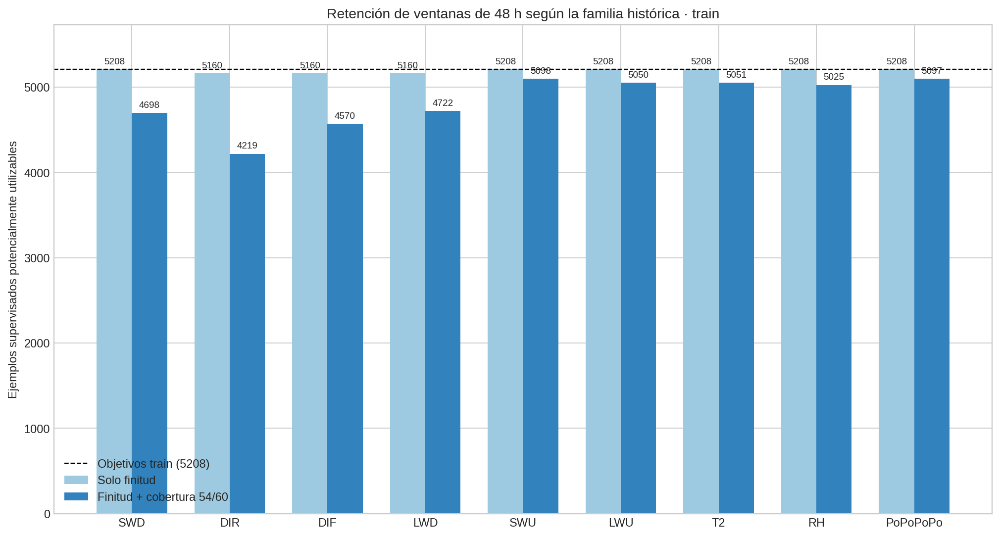

02_retencion_ventanas_por_escenario_train.png


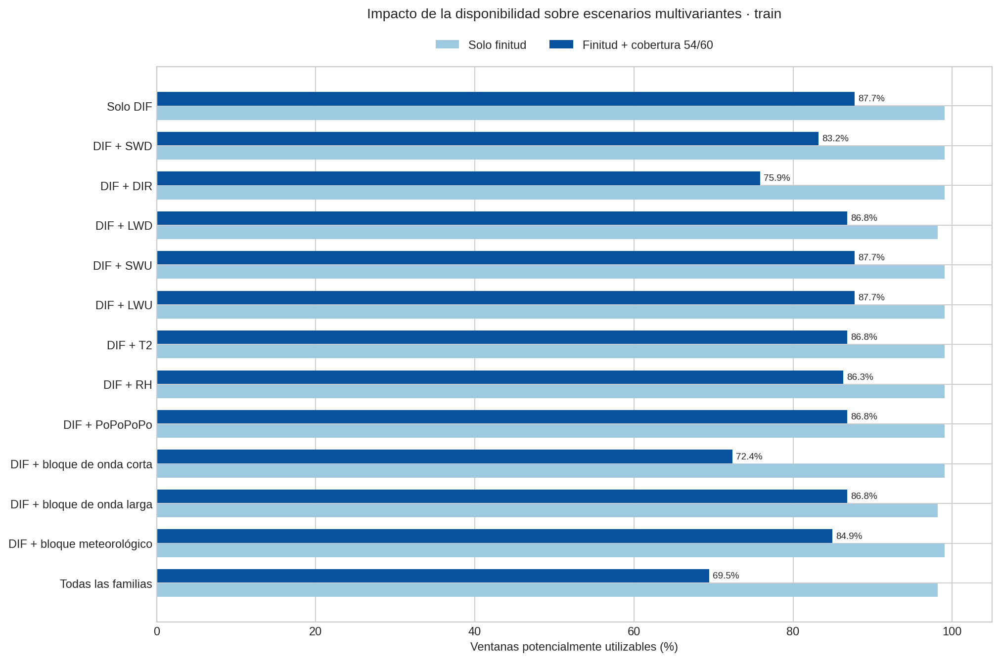

03_retencion_mensual_escenarios_train.png


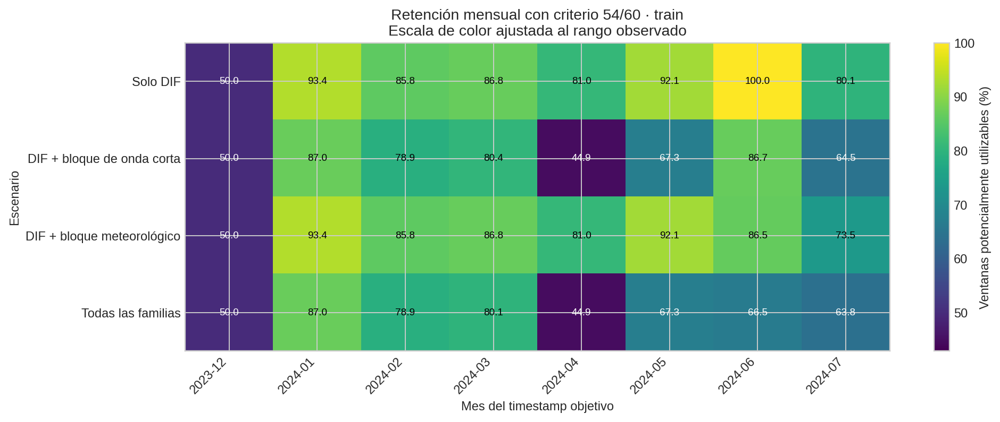


=== PROTECCIÓN DE PARTICIONES ===
Partición objetivo analizada: TRAIN
Contexto histórico permitido: pre_segmento + train
Valores de validation cargados: NO
Valores de test cargados: NO
Lags materializados: NO
Objetivo DIF_t+1 materializado: NO
Filas eliminadas: 0
Valores imputados: 0
Valores corregidos: 0

=== ZIP ===
Nombre: EDA_multivariante_F2_S2_6_20261102T165730Z_3fe4c1f3.zip
Tamaño: 1.79 MiB (1,880,416 bytes)
SHA-256: 0698feceb3f68fa01e7897d4f6ec9b328a10ee343c9648f48f91f7a0ea37b123
Integridad: CORRECTA
Contenido:
- README.md
- checkpoints/09a_tabla_horaria_particionada_sin_cambios.parquet
- checkpoints/09b_catalogo_ventanas_estructurales_48h_sin_cambios.parquet
- checkpoints/09c_catalogo_disponibilidad_ventanas_train.parquet
- configuracion/configuracion_2_6.json
- figuras/01_retencion_ventanas_por_familia_train.png
- figuras/02_retencion_ventanas_por_escenario_train.png
- figuras/03_retencion_mensual_escenarios_train.png
- inventario_archivos.csv
- resumen_ejecucion.json
- tabl

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
import sys
import subprocess
import importlib.util

# PyArrow es la única dependencia que podría no estar instalada.
if importlib.util.find_spec("pyarrow") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyarrow"])

import io
import json
import hashlib
import platform
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import pyarrow
import pyarrow.parquet as pq
from IPython.display import Image, display
from google.colab import files

# 1. Contrato predictivo y configuración congelada
HISTORY_HOURS = 48
HORIZON_HOURS = 1
MIN_MINUTES_QUALITY = 54
TRAIN_START = pd.Timestamp("2023-12-28 00:00:00")
TRAIN_END_EXCLUSIVE = pd.Timestamp("2024-08-01 00:00:00")
N_TRAIN_TARGETS = 5208
INPUT_HOURLY_CHECKPOINT = "checkpoints/08a_tabla_horaria_particionada_sin_cambios.parquet"
INPUT_STRUCTURAL_CATALOG = "checkpoints/08b_catalogo_ventanas_estructurales_48h.parquet"
FAMILIES = ["SWD", "DIR", "DIF", "LWD", "SWU", "LWU", "T2", "RH", "PoPoPoPo"]
FAMILY_COLUMNS = {
    "SWD": ("SWD__media_h", "SWD__media__cobertura_90_ok"),
    "DIR": ("DIR__media_h", "DIR__media__cobertura_90_ok"),
    "DIF": ("DIF__media_h", "DIF__media__cobertura_90_ok"),
    "LWD": ("LWD__media_h", "LWD__media__cobertura_90_ok"),
    "SWU": ("SWU__media_h", "SWU__media__cobertura_90_ok"),
    "LWU": ("LWU__media_h", "LWU__media__cobertura_90_ok"),
    "T2": ("T2__media_h", "T2__cobertura_90_ok"),
    "RH": ("RH__media_h", "RH__cobertura_90_ok"),
    "PoPoPoPo": ("PoPoPoPo__media_h", "PoPoPoPo__cobertura_90_ok"),
}

# Escenarios descriptivos. No constituyen una selección de variables.
SCENARIOS = [
    ("S00_DIF", "Solo DIF", ["DIF"]),
    ("S01_DIF_SWD", "DIF + SWD", ["DIF", "SWD"]),
    ("S02_DIF_DIR", "DIF + DIR", ["DIF", "DIR"]),
    ("S03_DIF_LWD", "DIF + LWD", ["DIF", "LWD"]),
    ("S04_DIF_SWU", "DIF + SWU", ["DIF", "SWU"]),
    ("S05_DIF_LWU", "DIF + LWU", ["DIF", "LWU"]),
    ("S06_DIF_T2", "DIF + T2", ["DIF", "T2"]),
    ("S07_DIF_RH", "DIF + RH", ["DIF", "RH"]),
    ("S08_DIF_P", "DIF + PoPoPoPo", ["DIF", "PoPoPoPo"]),
    ("S09_ONDA_CORTA", "DIF + bloque de onda corta", ["DIF", "SWD", "DIR", "SWU"]),
    ("S10_ONDA_LARGA", "DIF + bloque de onda larga", ["DIF", "LWD", "LWU"]),
    ("S11_METEO", "DIF + bloque meteorológico", ["DIF", "T2", "RH", "PoPoPoPo"]),
    ("S12_TODAS", "Todas las familias", FAMILIES.copy()),
]


# 2. Funciones auxiliares
def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()

def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open("rb") as file:
        while True:
            chunk = file.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)
    return digest.hexdigest()

def verify_zip_inventory(raw_zip):
    """Verifica CRC, rutas, tamaños y SHA-256 del ZIP de entrada."""
    with zipfile.ZipFile(io.BytesIO(raw_zip)) as zip_file:
        assert zip_file.testzip() is None, "El ZIP contiene un archivo dañado."
        assert "inventario_archivos.csv" in zip_file.namelist(), "Falta inventario_archivos.csv."
        inventory = pd.read_csv(
            io.BytesIO(zip_file.read("inventario_archivos.csv")), encoding="utf-8-sig"
        )
        required = {"ruta_relativa", "tamano_bytes", "sha256"}
        assert required.issubset(inventory.columns), "El inventario está incompleto."
        for row in inventory.itertuples(index=False):
            relative_path = str(row.ruta_relativa)
            assert (
                relative_path in zip_file.namelist()
            ), f"Falta el archivo inventariado: {relative_path}"
            content = zip_file.read(relative_path)
            assert len(content) == int(row.tamano_bytes), f"Tamaño incorrecto: {relative_path}"
            assert sha256_bytes(content) == str(row.sha256), f"SHA-256 incorrecto: {relative_path}"

    return inventory

def save_csv(dataframe, path):
    dataframe.to_csv(path, index=False, encoding="utf-8-sig")

def history_count(mask):
    """Cuenta horas válidas en [objetivo - 48 h, objetivo - 1 h]."""
    series = pd.Series(np.asarray(mask, dtype=bool))
    return (
        series.shift(1, fill_value=False)
        .rolling(window=HISTORY_HOURS, min_periods=HISTORY_HOURS)
        .sum()
        .fillna(0)
        .astype(np.int16)
    )

def longest_true_run(mask):
    """Longitud máxima de una racha de True."""
    values = np.asarray(mask, dtype=bool)
    if not values.any():
        return 0
    groups = np.cumsum(~values)
    return int(pd.Series(values).groupby(groups).sum().max())

def first_or_nat(timestamps, mask):
    values = timestamps.loc[np.asarray(mask, dtype=bool)]
    return values.iloc[0] if len(values) else pd.NaT

def last_or_nat(timestamps, mask):
    values = timestamps.loc[np.asarray(mask, dtype=bool)]
    return values.iloc[-1] if len(values) else pd.NaT


# 3. Carga segura del ZIP 2.5
print("Selecciona exclusivamente el ZIP validado de la subsección 2.5.")
uploaded = files.upload()
assert len(uploaded) == 1, "Debes seleccionar exactamente un ZIP: el de 2.5."
uploaded_name, raw_zip = next(iter(uploaded.items()))
assert zipfile.is_zipfile(io.BytesIO(raw_zip)), "El archivo seleccionado no es ZIP."
input_inventory = verify_zip_inventory(raw_zip)
with zipfile.ZipFile(io.BytesIO(raw_zip)) as zip_file:
    members = set(zip_file.namelist())
    required_members = {
        INPUT_HOURLY_CHECKPOINT,
        INPUT_STRUCTURAL_CATALOG,
        "configuracion/configuracion_2_5.json",
    }
    assert required_members.issubset(
        members
    ), "El ZIP no contiene los archivos esperados de la subsección 2.5."
    hourly_checkpoint_bytes = zip_file.read(INPUT_HOURLY_CHECKPOINT)
    structural_catalog_bytes = zip_file.read(INPUT_STRUCTURAL_CATALOG)
    input_config = json.loads(zip_file.read("configuracion/configuracion_2_5.json"))

assert input_config["fase"] == 2
assert str(input_config["subseccion"]) == "2.5"
hourly_input_sha = sha256_bytes(hourly_checkpoint_bytes)
catalog_input_sha = sha256_bytes(structural_catalog_bytes)
assert hourly_input_sha == input_config["checkpoints"]["tabla_horaria"]["sha256"]
assert catalog_input_sha == input_config["checkpoints"]["catalogo_ventanas"]["sha256"]
parquet_file = pq.ParquetFile(io.BytesIO(hourly_checkpoint_bytes))
source_shape = (int(parquet_file.metadata.num_rows), int(parquet_file.metadata.num_columns))
source_columns = set(parquet_file.schema.names)
assert source_shape == (9504, 132)
columns_to_load = ["Date/Time", "particion_observacion"]
for value_column, coverage_column in FAMILY_COLUMNS.values():
    columns_to_load.extend([value_column, coverage_column])

assert len(columns_to_load) == 20
assert set(columns_to_load).issubset(source_columns)

# Solo se cargan valores de pre_segmento y train. Validation y test no entran
# en memoria para este análisis estadístico.
analysis_source = (
    pd.read_parquet(
        io.BytesIO(hourly_checkpoint_bytes),
        columns=columns_to_load,
        filters=[("particion_observacion", "in", ["pre_segmento", "train"])],
    )
    .sort_values("Date/Time")
    .reset_index(drop=True)
)
assert analysis_source.shape == (1368 + N_TRAIN_TARGETS, 20)
assert set(analysis_source["particion_observacion"].unique()) == {"pre_segmento", "train"}
assert not analysis_source["particion_observacion"].isin(["validation", "test"]).any()
assert analysis_source["Date/Time"].is_monotonic_increasing
assert not analysis_source["Date/Time"].duplicated().any()
assert analysis_source["Date/Time"].diff().dropna().eq(pd.Timedelta(hours=1)).all()
structural_catalog = pd.read_parquet(io.BytesIO(structural_catalog_bytes))
assert structural_catalog.shape == (9504, 17)
structural_train = structural_catalog.loc[
    structural_catalog["target_partition"].astype("string").eq("train")
].reset_index(drop=True)
assert len(structural_train) == N_TRAIN_TARGETS
assert structural_train["window_48h_structurally_complete"].all()
assert structural_train["target_timestamp"].iloc[0] == TRAIN_START
assert structural_train["target_timestamp"].iloc[-1] == (
    TRAIN_END_EXCLUSIVE - pd.Timedelta(hours=1)
)


# 4. Máscaras horarias por familia
train_mask = analysis_source["particion_observacion"].eq("train").to_numpy()
train_positions = np.flatnonzero(train_mask)
train_timestamps = analysis_source.loc[train_mask, "Date/Time"].reset_index(drop=True)
assert len(train_positions) == N_TRAIN_TARGETS
assert train_timestamps.equals(structural_train["target_timestamp"].reset_index(drop=True))
hour_finite = {}
hour_quality90 = {}
hourly_availability_rows = []
for family in FAMILIES:
    value_column, coverage_column = FAMILY_COLUMNS[family]
    values = pd.to_numeric(analysis_source[value_column], errors="coerce").to_numpy(dtype=float)
    coverage = analysis_source[coverage_column].fillna(False).astype(bool).to_numpy()
    finite_mask = np.isfinite(values)
    quality_mask = finite_mask & coverage
    hour_finite[family] = finite_mask
    hour_quality90[family] = quality_mask
    for partition_name in ["pre_segmento", "train"]:
        partition_mask = analysis_source["particion_observacion"].eq(partition_name).to_numpy()
        n_hours = int(partition_mask.sum())
        n_finite = int((finite_mask & partition_mask).sum())
        n_quality = int((quality_mask & partition_mask).sum())
        hourly_availability_rows.append(
            {
                "familia": family,
                "particion_hora": partition_name,
                "n_horas": n_hours,
                "n_horas_media_finita": n_finite,
                "pct_horas_media_finita": 100.0 * n_finite / n_hours,
                "n_horas_cobertura_54_60": n_quality,
                "pct_horas_cobertura_54_60": 100.0 * n_quality / n_hours,
                "n_horas_media_no_finita": n_hours - n_finite,
                "n_horas_bajo_54_60": n_hours - n_quality,
            }
        )

hourly_availability = pd.DataFrame(hourly_availability_rows)

# El objetivo es siempre la media horaria de DIF en el timestamp objetivo.
target_DIF_finite = hour_finite["DIF"][train_positions]
target_DIF_quality90 = hour_quality90["DIF"][train_positions]


# 5. Disponibilidad de cada familia dentro de las ventanas históricas
availability_catalog = structural_train[
    [
        "target_timestamp",
        "target_partition",
        "origin_timestamp",
        "history_start_expected",
        "history_end_expected",
        "window_48h_structurally_complete",
        "uses_previous_partition_context",
    ]
].copy()
availability_catalog["target_DIF_finite"] = target_DIF_finite
availability_catalog["target_DIF_coverage_54_60_ok"] = target_DIF_quality90
family_summary_rows = []
for family in FAMILIES:
    finite_counts_all = history_count(hour_finite[family])
    quality_counts_all = history_count(hour_quality90[family])
    finite_counts = finite_counts_all.iloc[train_positions].to_numpy(dtype=np.int16)
    quality_counts = quality_counts_all.iloc[train_positions].to_numpy(dtype=np.int16)
    history_finite_ok = finite_counts == HISTORY_HOURS
    history_quality_ok = quality_counts == HISTORY_HOURS
    supervised_finite_ok = history_finite_ok & target_DIF_finite
    supervised_quality_ok = history_quality_ok & target_DIF_quality90
    availability_catalog[f"{family}__n_horas_historia_finitas"] = finite_counts
    availability_catalog[f"{family}__n_horas_historia_54_60"] = quality_counts
    availability_catalog[f"{family}__ventana_historia_finita"] = history_finite_ok
    availability_catalog[f"{family}__ventana_historia_54_60"] = history_quality_ok
    lost_finite = ~supervised_finite_ok
    lost_quality = ~supervised_quality_ok
    family_summary_rows.append(
        {
            "familia_historica": family,
            "n_objetivos_train": N_TRAIN_TARGETS,
            "n_ventanas_historia_finita": int(history_finite_ok.sum()),
            "n_ventanas_historia_54_60": int(history_quality_ok.sum()),
            "n_ejemplos_supervisados_finitos": int(supervised_finite_ok.sum()),
            "pct_ejemplos_supervisados_finitos": (100.0 * supervised_finite_ok.mean()),
            "n_perdidos_criterio_finito": int(lost_finite.sum()),
            "n_ejemplos_supervisados_54_60": int(supervised_quality_ok.sum()),
            "pct_ejemplos_supervisados_54_60": (100.0 * supervised_quality_ok.mean()),
            "n_perdidos_criterio_54_60": int(lost_quality.sum()),
            "perdida_adicional_por_umbral": int(lost_quality.sum() - lost_finite.sum()),
            "racha_max_perdida_54_60_h": longest_true_run(lost_quality),
            "primera_ventana_perdida_54_60": first_or_nat(train_timestamps, lost_quality),
            "ultima_ventana_perdida_54_60": last_or_nat(train_timestamps, lost_quality),
        }
    )

family_window_summary = pd.DataFrame(family_summary_rows)


# 6. Escenarios multivariantes y atribución de pérdidas
scenario_definition_rows = []
scenario_summary_rows = []
scenario_masks = {}
for scenario_code, scenario_label, scenario_families in SCENARIOS:
    history_finite_ok = np.logical_and.reduce(
        [
            availability_catalog[f"{family}__ventana_historia_finita"].to_numpy()
            for family in scenario_families
        ]
    )
    history_quality_ok = np.logical_and.reduce(
        [
            availability_catalog[f"{family}__ventana_historia_54_60"].to_numpy()
            for family in scenario_families
        ]
    )
    usable_finite = history_finite_ok & target_DIF_finite
    usable_quality = history_quality_ok & target_DIF_quality90
    scenario_masks[scenario_code] = {"finite": usable_finite, "quality90": usable_quality}
    availability_catalog[f"{scenario_code}__usable_finito"] = usable_finite
    availability_catalog[f"{scenario_code}__usable_54_60"] = usable_quality
    only_history_lost = (~history_quality_ok) & target_DIF_quality90
    only_target_lost = history_quality_ok & (~target_DIF_quality90)
    both_lost = (~history_quality_ok) & (~target_DIF_quality90)
    scenario_definition_rows.append(
        {
            "codigo_escenario": scenario_code,
            "escenario": scenario_label,
            "familias_historicas": " + ".join(scenario_families),
            "n_familias": len(scenario_families),
            "objetivo": "DIF__media_h en el timestamp objetivo",
            "es_seleccion_final": False,
        }
    )
    scenario_summary_rows.append(
        {
            "codigo_escenario": scenario_code,
            "escenario": scenario_label,
            "n_familias_historicas": len(scenario_families),
            "n_objetivos_train": N_TRAIN_TARGETS,
            "n_usable_criterio_finito": int(usable_finite.sum()),
            "pct_usable_criterio_finito": 100.0 * usable_finite.mean(),
            "n_perdidos_criterio_finito": int((~usable_finite).sum()),
            "n_usable_criterio_54_60": int(usable_quality.sum()),
            "pct_usable_criterio_54_60": 100.0 * usable_quality.mean(),
            "n_perdidos_criterio_54_60": int((~usable_quality).sum()),
            "perdidos_solo_historia_54_60": int(only_history_lost.sum()),
            "perdidos_solo_objetivo_54_60": int(only_target_lost.sum()),
            "perdidos_historia_y_objetivo_54_60": int(both_lost.sum()),
            "racha_max_perdida_54_60_h": longest_true_run(~usable_quality),
            "primera_ventana_perdida_54_60": first_or_nat(train_timestamps, ~usable_quality),
            "ultima_ventana_perdida_54_60": last_or_nat(train_timestamps, ~usable_quality),
        }
    )

scenario_definitions = pd.DataFrame(scenario_definition_rows)
scenario_summary = pd.DataFrame(scenario_summary_rows)
baseline_finite = int(
    scenario_summary.loc[
        scenario_summary["codigo_escenario"].eq("S00_DIF"), "n_usable_criterio_finito"
    ].iloc[0]
)
baseline_quality = int(
    scenario_summary.loc[
        scenario_summary["codigo_escenario"].eq("S00_DIF"), "n_usable_criterio_54_60"
    ].iloc[0]
)
scenario_summary["perdida_adicional_vs_DIF_finito"] = (
    baseline_finite - scenario_summary["n_usable_criterio_finito"]
)
scenario_summary["perdida_adicional_vs_DIF_54_60"] = (
    baseline_quality - scenario_summary["n_usable_criterio_54_60"]
)

# Comprobaciones de reconciliación de la atribución.
assert target_DIF_quality90.sum() <= target_DIF_finite.sum()
assert (
    family_window_summary["n_ejemplos_supervisados_54_60"]
    <= family_window_summary["n_ejemplos_supervisados_finitos"]
).all()
assert (
    scenario_summary["n_usable_criterio_54_60"] <= scenario_summary["n_usable_criterio_finito"]
).all()
assert (
    scenario_summary["n_perdidos_criterio_54_60"]
    == scenario_summary[
        [
            "perdidos_solo_historia_54_60",
            "perdidos_solo_objetivo_54_60",
            "perdidos_historia_y_objetivo_54_60",
        ]
    ].sum(axis=1)
).all()


# 7. Distribución mensual de la disponibilidad
month_labels = train_timestamps.dt.strftime("%Y-%m")
monthly_scenario_rows = []
for scenario_code, scenario_label, scenario_families in SCENARIOS:
    for month in sorted(month_labels.unique()):
        month_mask = month_labels.eq(month).to_numpy()
        n_targets = int(month_mask.sum())
        n_finite = int((scenario_masks[scenario_code]["finite"] & month_mask).sum())
        n_quality = int((scenario_masks[scenario_code]["quality90"] & month_mask).sum())
        monthly_scenario_rows.append(
            {
                "codigo_escenario": scenario_code,
                "escenario": scenario_label,
                "mes_objetivo": month,
                "n_objetivos": n_targets,
                "n_usable_criterio_finito": n_finite,
                "pct_usable_criterio_finito": 100.0 * n_finite / n_targets,
                "n_usable_criterio_54_60": n_quality,
                "pct_usable_criterio_54_60": 100.0 * n_quality / n_targets,
            }
        )

monthly_scenario_summary = pd.DataFrame(monthly_scenario_rows)
monthly_family_rows = []
for family in FAMILIES:
    history_quality_ok = availability_catalog[f"{family}__ventana_historia_54_60"].to_numpy()
    usable_quality = history_quality_ok & target_DIF_quality90
    for month in sorted(month_labels.unique()):
        month_mask = month_labels.eq(month).to_numpy()
        n_targets = int(month_mask.sum())
        n_usable = int((usable_quality & month_mask).sum())
        monthly_family_rows.append(
            {
                "familia_historica": family,
                "mes_objetivo": month,
                "n_objetivos": n_targets,
                "n_usable_criterio_54_60": n_usable,
                "pct_usable_criterio_54_60": 100.0 * n_usable / n_targets,
            }
        )

monthly_family_summary = pd.DataFrame(monthly_family_rows)
assert (
    monthly_scenario_summary.groupby("codigo_escenario")["n_objetivos"].sum() == N_TRAIN_TARGETS
).all()
assert (
    monthly_family_summary.groupby("familia_historica")["n_objetivos"].sum() == N_TRAIN_TARGETS
).all()


# 8. Contrato metodológico, resumen técnico y advertencias
criteria_contract = pd.DataFrame(
    [
        ["Universo de objetivos", "5208 timestamps de train con ventana estructural completa"],
        ["Contexto permitido", "pre_segmento y train; siempre anterior al objetivo"],
        ["Ventana histórica", "48 horas: desde objetivo - 48 h hasta objetivo - 1 h"],
        ["Horizonte", "1 hora; objetivo = media horaria de DIF"],
        ["Criterio finito", "las 48 medias históricas y la media objetivo de DIF son finitas"],
        ["Criterio 54/60", "criterio finito y cada hora conserva al menos 54 de 60 minutos"],
        ["Unidad de familia", "media horaria de cada una de las 9 variables primarias"],
        [
            "Naturaleza del análisis",
            "simulación descriptiva de retención; no regla final de descarte",
        ],
        ["Imputación, eliminación o corrección", "ninguna"],
        ["Materialización de lags", "no"],
        ["Materialización de DIF_t+1", "no; solo máscara de disponibilidad"],
    ],
    columns=["elemento", "definicion"],
)
target_summary = pd.DataFrame(
    [
        {
            "objetivo": "DIF__media_h",
            "n_objetivos_train": N_TRAIN_TARGETS,
            "n_objetivos_finitos": int(target_DIF_finite.sum()),
            "pct_objetivos_finitos": 100.0 * target_DIF_finite.mean(),
            "n_objetivos_cobertura_54_60": int(target_DIF_quality90.sum()),
            "pct_objetivos_cobertura_54_60": 100.0 * target_DIF_quality90.mean(),
            "n_objetivos_bajo_54_60": int((~target_DIF_quality90).sum()),
        }
    ]
)
technical_summary = pd.DataFrame(
    [
        ["ZIP 2.5 identificado", True, True, True],
        ["Inventario de entrada verificado", True, True, True],
        ["SHA checkpoint horario verificado", True, True, True],
        ["SHA catálogo estructural verificado", True, True, True],
        ["Filas del checkpoint horario", source_shape[0], 9504, source_shape[0] == 9504],
        ["Columnas del checkpoint horario", source_shape[1], 132, source_shape[1] == 132],
        ["Filas físicas cargadas", len(analysis_source), 6576, len(analysis_source) == 6576],
        ["Columnas cargadas", len(columns_to_load), 20, len(columns_to_load) == 20],
        ["Objetivos train", len(structural_train), 5208, len(structural_train) == 5208],
        [
            "Ventanas train estructuralmente completas",
            int(structural_train["window_48h_structurally_complete"].sum()),
            5208,
            structural_train["window_48h_structurally_complete"].all(),
        ],
        ["Familias evaluadas", len(FAMILIES), 9, len(FAMILIES) == 9],
        ["Escenarios descriptivos", len(SCENARIOS), 13, len(SCENARIOS) == 13],
        ["Validation: valores cargados", False, False, True],
        ["Test: valores cargados", False, False, True],
        ["Lags materializados", False, False, True],
        ["Objetivo DIF_t+1 materializado", False, False, True],
        ["Filas eliminadas", 0, 0, True],
        ["Valores imputados", 0, 0, True],
        ["Valores corregidos", 0, 0, True],
    ],
    columns=["comprobacion", "resultado", "esperado", "superado"],
)
assert technical_summary["superado"].all()
warnings = pd.DataFrame(
    [
        {
            "id": "V601",
            "advertencia": (
                "El umbral 54/60 es un criterio de calidad provisional; no demuestra "
                "que una hora deba descartarse."
            ),
            "decision": (
                "Presentar en paralelo el criterio finito y el criterio 54/60; "
                "no eliminar ni imputar."
            ),
            "resolver_en": "Preparación de datos y validación de la política de ausencias",
        },
        {
            "id": "V602",
            "advertencia": (
                "Una sola hora no válida puede afectar hasta 48 objetivos consecutivos."
            ),
            "decision": (
                "Interpretar la pérdida de ventanas como propagación temporal, "
                "no como número de horas defectuosas."
            ),
            "resolver_en": "Diseño de imputación, máscaras o tolerancia por ventana",
        },
        {
            "id": "V603",
            "advertencia": (
                "Los resultados dependen de una historia de 48 h y un horizonte de 1 h."
            ),
            "decision": "Recalcular si cambia el contrato predictivo.",
            "resolver_en": "Si se modifica el backcast o el horizonte",
        },
        {
            "id": "V604",
            "advertencia": ("No se han cargado valores de validation ni test."),
            "decision": ("No anticipar su pérdida efectiva de ventanas a partir de train."),
            "resolver_en": "Validación y evaluación final, respectivamente",
        },
        {
            "id": "V605",
            "advertencia": ("La definición física de DIR continúa pendiente."),
            "decision": (
                "Cuantificar disponibilidad sin atribuir significado físico ni "
                "seleccionar automáticamente DIR."
            ),
            "resolver_en": "Antes de interpretar o seleccionar DIR",
        },
        {
            "id": "V606",
            "advertencia": "La zona horaria del dataset aún no está confirmada.",
            "decision": (
                "Usar únicamente el orden temporal y no interpretar horas solares o locales."
            ),
            "resolver_en": "Antes de geometría solar y perfiles por hora local",
        },
        {
            "id": "V607",
            "advertencia": (
                "SWD, DIR y DIF están físicamente relacionados; los valores "
                "contemporáneos podrían introducir reconstrucción casi algebraica."
            ),
            "decision": (
                "Esta subsección solo estudia historia anterior al objetivo y no "
                "autoriza predictores contemporáneos."
            ),
            "resolver_en": "Selección causal de variables y relaciones retardadas",
        },
    ]
)


# 9. Figuras
plt.style.use("seaborn-v0_8-whitegrid")

# Figura 1: comparación por familia histórica.
fig_family, ax_family = plt.subplots(figsize=(12, 6.5))
x_family = np.arange(len(family_window_summary))
width = 0.36
bars_finite = ax_family.bar(
    x_family - width / 2,
    family_window_summary["n_ejemplos_supervisados_finitos"],
    width,
    label="Solo finitud",
    color="#9ecae1",
)
bars_quality = ax_family.bar(
    x_family + width / 2,
    family_window_summary["n_ejemplos_supervisados_54_60"],
    width,
    label="Finitud + cobertura 54/60",
    color="#3182bd",
)
ax_family.axhline(
    N_TRAIN_TARGETS, color="black", linestyle="--", linewidth=1, label="Objetivos train (5208)"
)
ax_family.set_xticks(x_family)
ax_family.set_xticklabels(family_window_summary["familia_historica"])
ax_family.set_ylabel("Ejemplos supervisados potencialmente utilizables")
ax_family.set_title("Retención de ventanas de 48 h según la familia histórica · train")
ax_family.set_ylim(0, N_TRAIN_TARGETS * 1.10)
ax_family.legend(loc="lower left")
for bars in [bars_finite, bars_quality]:
    ax_family.bar_label(bars, padding=3, fontsize=8)

fig_family.tight_layout()


# Figura 2: escenarios de familias.
fig_scenarios, ax_scenarios = plt.subplots(figsize=(12, 8))
y_scenarios = np.arange(len(scenario_summary))
ax_scenarios.barh(
    y_scenarios + 0.18,
    scenario_summary["pct_usable_criterio_finito"],
    height=0.34,
    label="Solo finitud",
    color="#9ecae1",
)
bars_scenario_quality = ax_scenarios.barh(
    y_scenarios - 0.18,
    scenario_summary["pct_usable_criterio_54_60"],
    height=0.34,
    label="Finitud + cobertura 54/60",
    color="#08519c",
)
ax_scenarios.set_yticks(y_scenarios)
ax_scenarios.set_yticklabels(scenario_summary["escenario"])
ax_scenarios.invert_yaxis()
ax_scenarios.set_xlim(0, 105)
ax_scenarios.set_xlabel("Ventanas potencialmente utilizables (%)")
ax_scenarios.set_title(
    "Impacto de la disponibilidad sobre escenarios multivariantes · train", pad=42
)
ax_scenarios.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2, frameon=False)
ax_scenarios.bar_label(
    bars_scenario_quality,
    labels=[f"{value:.1f}%" for value in scenario_summary["pct_usable_criterio_54_60"]],
    padding=3,
    fontsize=8,
)
fig_scenarios.tight_layout()


# Figura 3: estabilidad mensual de cuatro escenarios informativos.
selected_scenarios = ["S00_DIF", "S09_ONDA_CORTA", "S11_METEO", "S12_TODAS"]
monthly_pivot = (
    monthly_scenario_summary.loc[
        monthly_scenario_summary["codigo_escenario"].isin(selected_scenarios)
    ]
    .pivot(index="codigo_escenario", columns="mes_objetivo", values="pct_usable_criterio_54_60")
    .reindex(selected_scenarios)
)
selected_labels = (
    scenario_definitions.set_index("codigo_escenario").loc[selected_scenarios, "escenario"].tolist()
)
fig_monthly, ax_monthly = plt.subplots(figsize=(12, 4.8))
matrix = monthly_pivot.to_numpy(dtype=float)
vmin = max(0.0, float(np.nanmin(matrix)) - 2.0)
image_monthly = ax_monthly.imshow(matrix, aspect="auto", cmap="viridis", vmin=vmin, vmax=100.0)
ax_monthly.set_xticks(np.arange(len(monthly_pivot.columns)))
ax_monthly.set_xticklabels(monthly_pivot.columns, rotation=45, ha="right")
ax_monthly.set_yticks(np.arange(len(selected_labels)))
ax_monthly.set_yticklabels(selected_labels)
ax_monthly.set_xlabel("Mes del timestamp objetivo")
ax_monthly.set_ylabel("Escenario")
ax_monthly.set_title(
    "Retención mensual con criterio 54/60 · train\n" "Escala de color ajustada al rango observado"
)
for row in range(matrix.shape[0]):
    for column in range(matrix.shape[1]):
        value = matrix[row, column]
        text_colour = "white" if value < (vmin + 100.0) / 2 else "black"
        ax_monthly.text(
            column, row, f"{value:.1f}", ha="center", va="center", fontsize=8, color=text_colour
        )

colour_bar = fig_monthly.colorbar(image_monthly, ax=ax_monthly)
colour_bar.set_label("Ventanas potencialmente utilizables (%)")
fig_monthly.tight_layout()


# 10. Guardado versionado y verificable
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8]
base_output = Path("/content/eda_multivariante_resultados")
run_dir = base_output / f"F2_S2_6_{run_id}"
tables_dir = run_dir / "tablas"
figures_dir = run_dir / "figuras"
config_dir = run_dir / "configuracion"
checkpoints_dir = run_dir / "checkpoints"
run_dir.mkdir(parents=True, exist_ok=False)
tables_dir.mkdir()
figures_dir.mkdir()
config_dir.mkdir()
checkpoints_dir.mkdir()
save_csv(technical_summary, tables_dir / "01_resumen_tecnico.csv")
save_csv(criteria_contract, tables_dir / "02_contrato_disponibilidad_ventanas.csv")
save_csv(target_summary, tables_dir / "03_disponibilidad_objetivo_DIF_train.csv")
save_csv(hourly_availability, tables_dir / "04_disponibilidad_horaria_familias.csv")
save_csv(family_window_summary, tables_dir / "05_perdida_ventanas_por_familia_train.csv")
save_csv(scenario_definitions, tables_dir / "06_definicion_escenarios.csv")
save_csv(scenario_summary, tables_dir / "07_perdida_ventanas_por_escenario_train.csv")
save_csv(monthly_family_summary, tables_dir / "08_retencion_mensual_familias_train.csv")
save_csv(monthly_scenario_summary, tables_dir / "09_retencion_mensual_escenarios_train.csv")
save_csv(warnings, tables_dir / "10_advertencias_y_alcance.csv")
figure_paths = [
    figures_dir / "01_retencion_ventanas_por_familia_train.png",
    figures_dir / "02_retencion_ventanas_por_escenario_train.png",
    figures_dir / "03_retencion_mensual_escenarios_train.png",
]
fig_family.savefig(figure_paths[0], dpi=170, bbox_inches="tight")
fig_scenarios.savefig(figure_paths[1], dpi=170, bbox_inches="tight")
fig_monthly.savefig(figure_paths[2], dpi=170, bbox_inches="tight")

# Checkpoints de entrada conservados byte a byte.
hourly_output_path = checkpoints_dir / "09a_tabla_horaria_particionada_sin_cambios.parquet"
hourly_output_path.write_bytes(hourly_checkpoint_bytes)
assert sha256_file(hourly_output_path) == hourly_input_sha
structural_output_path = (
    checkpoints_dir / "09b_catalogo_ventanas_estructurales_48h_sin_cambios.parquet"
)
structural_output_path.write_bytes(structural_catalog_bytes)
assert sha256_file(structural_output_path) == catalog_input_sha

# Nuevo checkpoint: máscaras y conteos, nunca valores físicos ni columnas lag.
availability_output_path = checkpoints_dir / "09c_catalogo_disponibilidad_ventanas_train.parquet"
availability_catalog.to_parquet(availability_output_path, index=False)
availability_reloaded = pd.read_parquet(availability_output_path)
pd.testing.assert_frame_equal(availability_reloaded, availability_catalog, check_dtype=False)
availability_sha = sha256_file(availability_output_path)
config = {
    "fase": 2,
    "subseccion": "2.6",
    "id_ejecucion": run_id,
    "fecha_utc": datetime.now(timezone.utc).isoformat(),
    "entorno": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "matplotlib": matplotlib.__version__,
        "pyarrow": pyarrow.__version__,
        "colab": True,
    },
    "entrada": {
        "nombre_zip_2_5": uploaded_name,
        "tamano_bytes": len(raw_zip),
        "sha256_zip_2_5": sha256_bytes(raw_zip),
        "sha256_checkpoint_horario": hourly_input_sha,
        "sha256_catalogo_estructural": catalog_input_sha,
        "inventario_verificado": True,
    },
    "contrato": {
        "objetivo": "media horaria de DIF",
        "horizonte_horas": HORIZON_HOURS,
        "ventana_historica_horas": HISTORY_HOURS,
        "historia_relativa_objetivo": "[-48 h, -1 h]",
        "umbral_calidad_minutos": MIN_MINUTES_QUALITY,
        "umbral_calidad_provisional": True,
        "unidad_familia": "media horaria de la variable primaria",
    },
    "alcance": {
        "particion_objetivo_analizada": "train",
        "particiones_historicas_permitidas": ["pre_segmento", "train"],
        "n_filas_fisicas_cargadas": int(len(analysis_source)),
        "n_columnas_cargadas": int(len(columns_to_load)),
        "columnas_cargadas": columns_to_load,
        "validation_valores_cargados": False,
        "test_valores_cargados": False,
        "lags_materializados": False,
        "objetivo_DIF_t1_materializado": False,
        "filas_eliminadas": 0,
        "valores_imputados": 0,
        "valores_corregidos": 0,
    },
    "resultados": {
        "n_objetivos_train": N_TRAIN_TARGETS,
        "n_familias": len(FAMILIES),
        "n_escenarios": len(SCENARIOS),
        "objetivos_DIF_finitos": int(target_DIF_finite.sum()),
        "objetivos_DIF_54_60": int(target_DIF_quality90.sum()),
        "baseline_DIF_usable_finito": baseline_finite,
        "baseline_DIF_usable_54_60": baseline_quality,
        "todas_familias_usable_finito": int(
            scenario_summary.loc[
                scenario_summary["codigo_escenario"].eq("S12_TODAS"), "n_usable_criterio_finito"
            ].iloc[0]
        ),
        "todas_familias_usable_54_60": int(
            scenario_summary.loc[
                scenario_summary["codigo_escenario"].eq("S12_TODAS"), "n_usable_criterio_54_60"
            ].iloc[0]
        ),
    },
    "checkpoints": {
        "tabla_horaria": {
            "ruta": "checkpoints/09a_tabla_horaria_particionada_sin_cambios.parquet",
            "forma": [9504, 132],
            "sha256": hourly_input_sha,
            "identico_a_entrada_2_5": True,
        },
        "catalogo_estructural": {
            "ruta": "checkpoints/09b_catalogo_ventanas_estructurales_48h_sin_cambios.parquet",
            "forma": [9504, 17],
            "sha256": catalog_input_sha,
            "identico_a_entrada_2_5": True,
        },
        "catalogo_disponibilidad_train": {
            "ruta": "checkpoints/09c_catalogo_disponibilidad_ventanas_train.parquet",
            "forma": [int(availability_catalog.shape[0]), int(availability_catalog.shape[1])],
            "sha256": availability_sha,
            "contiene_valores_fisicos": False,
            "contiene_lags": False,
        },
    },
}
with (config_dir / "configuracion_2_6.json").open("w", encoding="utf-8") as file:
    json.dump(config, file, ensure_ascii=False, indent=2)

execution_summary = {
    "estado": "COMPLETADO",
    "particion_objetivo_analizada": "train",
    "n_objetivos_train": N_TRAIN_TARGETS,
    "n_familias": len(FAMILIES),
    "n_escenarios": len(SCENARIOS),
    "baseline_DIF_usable_finito": baseline_finite,
    "baseline_DIF_usable_54_60": baseline_quality,
    "validation_valores_analizados": False,
    "test_valores_analizados": False,
    "lags_materializados": False,
    "filas_eliminadas": 0,
    "valores_imputados": 0,
    "valores_corregidos": 0,
}
with (run_dir / "resumen_ejecucion.json").open("w", encoding="utf-8") as file:
    json.dump(execution_summary, file, ensure_ascii=False, indent=2)

readme = f"""# Fase 2 · Subsección 2.6

Ejecución: {run_id}

Cuantificación descriptiva de la pérdida potencial de ventanas históricas de
48 horas según las familias disponibles, exclusivamente para objetivos de train.

Se comparan dos criterios: (1) media horaria finita y (2) media finita con al
menos 54 de 60 minutos disponibles. El segundo es un umbral provisional de
sensibilidad y no una regla automática de descarte.

Las 48 horas de historia pueden proceder de pre_segmento o train, pero siempre
son anteriores al objetivo. No se cargaron valores de validation ni test. No se
materializaron lags ni DIF_t+1 y no se eliminaron, imputaron o corrigieron datos.

Recarga:

1. Extrae este ZIP.
2. Usa checkpoints/09a_tabla_horaria_particionada_sin_cambios.parquet para la
   tabla horaria original.
3. Usa checkpoints/09b_catalogo_ventanas_estructurales_48h_sin_cambios.parquet
   para el catálogo estructural original.
4. Usa checkpoints/09c_catalogo_disponibilidad_ventanas_train.parquet para las
   máscaras y conteos de disponibilidad de train.
5. Verifica los SHA-256 en configuracion/configuracion_2_6.json.
"""
(run_dir / "README.md").write_text(readme, encoding="utf-8")

# Inventario de todos los archivos, salvo el propio inventario.
inventory_rows = []
for path in sorted(p for p in run_dir.rglob("*") if p.is_file()):
    inventory_rows.append(
        {
            "ruta_relativa": path.relative_to(run_dir).as_posix(),
            "tamano_bytes": path.stat().st_size,
            "sha256": sha256_file(path),
        }
    )

inventory_output = pd.DataFrame(inventory_rows)
save_csv(inventory_output, run_dir / "inventario_archivos.csv")
zip_path = base_output / f"EDA_multivariante_F2_S2_6_{run_id}.zip"
assert not zip_path.exists(), "El nombre versionado del ZIP ya existe."
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zip_file:
    for path in sorted(p for p in run_dir.rglob("*") if p.is_file()):
        zip_file.write(path, arcname=path.relative_to(run_dir).as_posix())

assert zip_path.exists()
with zipfile.ZipFile(zip_path) as zip_file:
    assert zip_file.testzip() is None
    zip_contents = sorted(zip_file.namelist())

zip_size = zip_path.stat().st_size
zip_sha = sha256_file(zip_path)


# 11. Salida visible y descarga
print("\n=== RESUMEN TÉCNICO 2.6 ===")
display(technical_summary)
print("\n=== CONTRATO DEL ANÁLISIS ===")
display(criteria_contract)
print("\n=== DISPONIBILIDAD DEL OBJETIVO DIF · TRAIN ===")
display(target_summary)
print("\n=== PÉRDIDA POTENCIAL DE VENTANAS POR FAMILIA · TRAIN ===")
display(family_window_summary)
print("\n=== PÉRDIDA POTENCIAL POR ESCENARIO · TRAIN ===")
display(scenario_summary)
print("\n=== RETENCIÓN MENSUAL 54/60 · ESCENARIOS SELECCIONADOS ===")
display(monthly_pivot)
print("\n=== ADVERTENCIAS Y ALCANCE ===")
display(warnings)
print("\n=== FIGURAS ===")
for figure_path in figure_paths:
    print(figure_path.name)
    display(Image(filename=str(figure_path)))

plt.close("all")
print("\n=== PROTECCIÓN DE PARTICIONES ===")
print("Partición objetivo analizada: TRAIN")
print("Contexto histórico permitido: pre_segmento + train")
print("Valores de validation cargados: NO")
print("Valores de test cargados: NO")
print("Lags materializados: NO")
print("Objetivo DIF_t+1 materializado: NO")
print("Filas eliminadas: 0")
print("Valores imputados: 0")
print("Valores corregidos: 0")
print("\n=== ZIP ===")
print(f"Nombre: {zip_path.name}")
print(f"Tamaño: {zip_size / (1024**2):.2f} MiB ({zip_size:,} bytes)")
print(f"SHA-256: {zip_sha}")
print("Integridad: CORRECTA")
print("Contenido:")
for member in zip_contents:
    print(f"- {member}")
print("Recarga: consulta README.md dentro del ZIP.")
if zip_size > 100 * 1024**2:
    raise RuntimeError(
        "El ZIP supera 100 MiB. No se inicia la descarga automática; "
        "revisa el tamaño antes de cambiar el sistema de guardado."
    )

print("\nSUBSECCIÓN 2.6 EJECUTADA SIN ERRORES.")
files.download(str(zip_path))

**Resultados.**

Aunque la disponibilidad horaria de las variables fue elevada, la imposición estricta de una cobertura mínima de 54 minutos en cada una de las 48 horas históricas produjo una reducción considerable del número de ejemplos potencialmente utilizables. El escenario basado únicamente en valores finitos conservó el 98,16 % de las ventanas al considerar todas las familias, mientras que la exigencia conjunta de cobertura 54/60 redujo esta proporción al 69,47 %. Esta diferencia no responde a una ausencia generalizada de observaciones, sino al efecto de propagación inherente a las ventanas deslizantes: una única hora con cobertura insuficiente puede afectar a numerosos objetivos consecutivos.

**En consecuencia, el umbral 54/60 se interpreta como un indicador descriptivo de calidad y no como una regla automática de descarte. Para el desarrollo del modelo se plantea conservar las medias horarias finitas, incorporar indicadores de disponibilidad, aplicar procedimientos causales únicamente ante ausencias reales y evaluar mecanismos de respaldo ante la falta de covariables. Esta estrategia permite preservar la mayor parte de la información disponible y aproxima el proceso de entrenamiento a las condiciones que podrían presentarse durante la explotación del sistema.**

### 2.7 Sensibilidad del criterio de disponibilidad

Esta subsección analiza cómo varía el número de ventanas de entrenamiento utilizables al modificar el mínimo de minutos exigidos por hora (1, 30, 45, 48, 50, 54, 55 y 60) y al tolerar 0, 1, 2, 3, 4 o 6 timestamps deficientes dentro de cada ventana de 48 horas, tanto por familia como en escenarios multivariantes. Se distinguen dos modalidades: la tolerancia parcial, que admite horas por debajo del umbral siempre que tengan al menos un minuto disponible y, por tanto, una media observable, y la tolerancia operativa, que admite también horas con 0/60 minutos y exigiría después máscaras, imputación o un modelo preparado para valores ausentes. El análisis es descriptivo y sirve para identificar políticas candidatas, sin adoptar todavía una regla definitiva.

Selecciona exclusivamente el ZIP validado de la subsección 2.6.


Saving EDA_multivariante_F2_S2_6_20261102T165730Z_3fe4c1f3.zip to EDA_multivariante_F2_S2_6_20261102T165730Z_3fe4c1f3.zip

=== RESUMEN TÉCNICO 2.7 ===


,comprobacion,resultado,esperado,superado
0,ZIP 2.6 identificado,True,True,True
1,Inventario de entrada verificado,True,True,True
2,SHA checkpoint horario verificado,True,True,True
3,SHA catálogo estructural verificado,True,True,True
4,SHA catálogo disponibilidad verificado,True,True,True
5,Filas del checkpoint horario,9504,9504,True
6,Columnas del checkpoint horario,132,132,True
7,Filas cargadas,6576,6576,True
8,Columnas cargadas,11,11,True
9,Objetivos train,5208,5208,True



=== MÉTRICAS CLAVE · TRAIN ===


,indicador,retencion_pct
0,Todas las familias · criterio finito,98.16%
1,Todas las familias · 54/60 estricto,69.47%
2,Todas las familias · 54/60 + ≤1 h parcial,83.76%
3,Todas las familias · 54/60 + ≤2 h parciales,92.42%
4,Todas las familias · 54/60 + ≤3 h parciales,96.75%
5,Todas las familias · 54/60 + ≤2 h incl. 0/60*,92.49%
6,Solo DIF · 54/60 estricto,87.75%
7,Solo DIF · 54/60 + ≤2 h parciales,98.81%



=== HALLAZGOS CLAVE ===


,id,hallazgo,evidencia,implicacion
0,H271,El criterio 54/60 estricto amplifica defectos ...,La retención de 'Todas las familias' es 69.47%...,No adoptar 54/60 como descarte automático ante...
1,H272,Una tolerancia pequeña recupera numerosas vent...,Con 54/60 y hasta 2 timestamps parciales por v...,La disponibilidad debe tratarse como política ...
2,H273,Cobertura parcial y ausencia total no son equi...,En el ámbito horario relevante aparecen 716 re...,Las horas parciales conservan una media observ...
3,H274,La tolerancia que incluye 0/60 representa un l...,"Con 54/60 y hasta 2 horas deficientes, incluid...",Ese porcentaje no es directamente utilizable s...



=== FIGURAS ===
01_tipologia_horas_no_completas_train.png


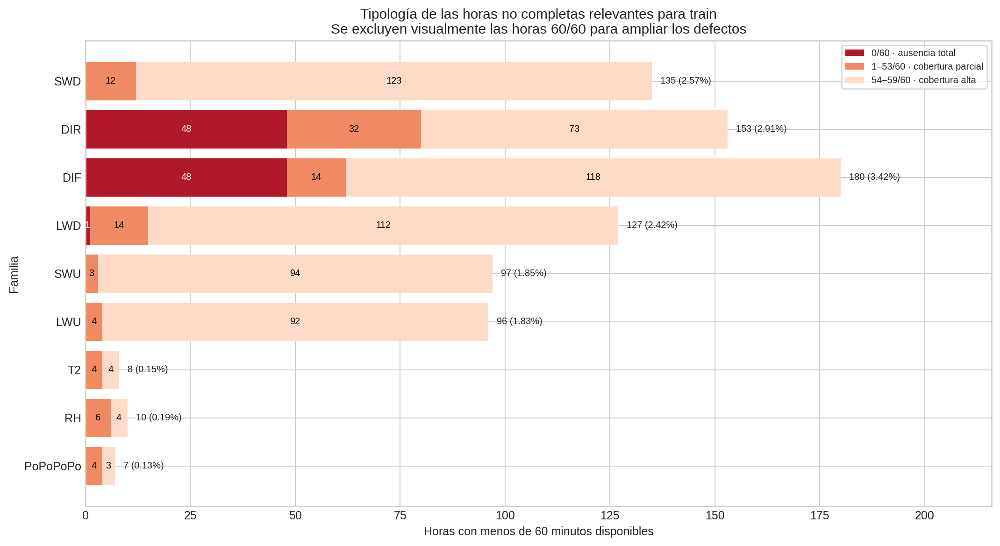

02_sensibilidad_umbral_estricto_train.png


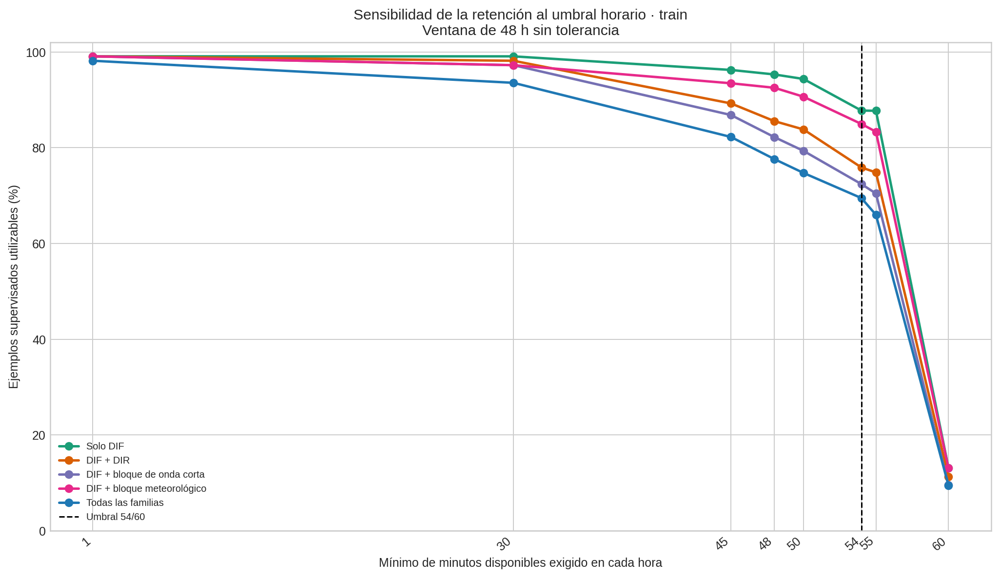

03_sensibilidad_tolerancia_54_60_train.png


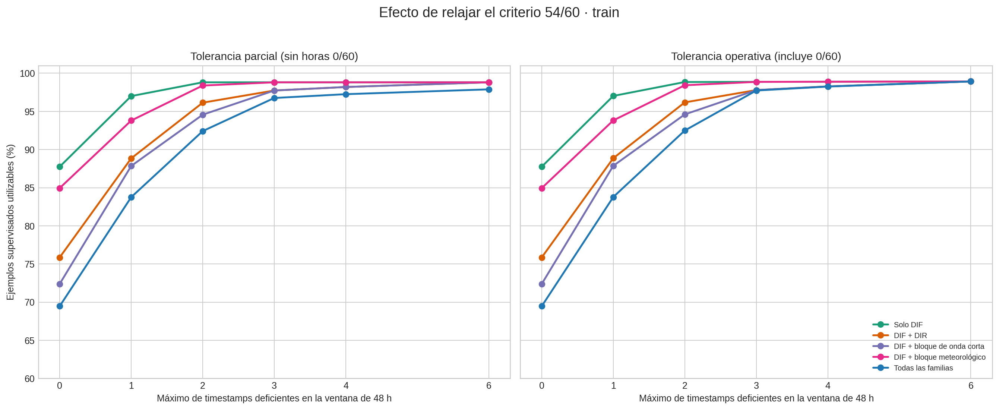

04_comparacion_politicas_candidatas_train.png


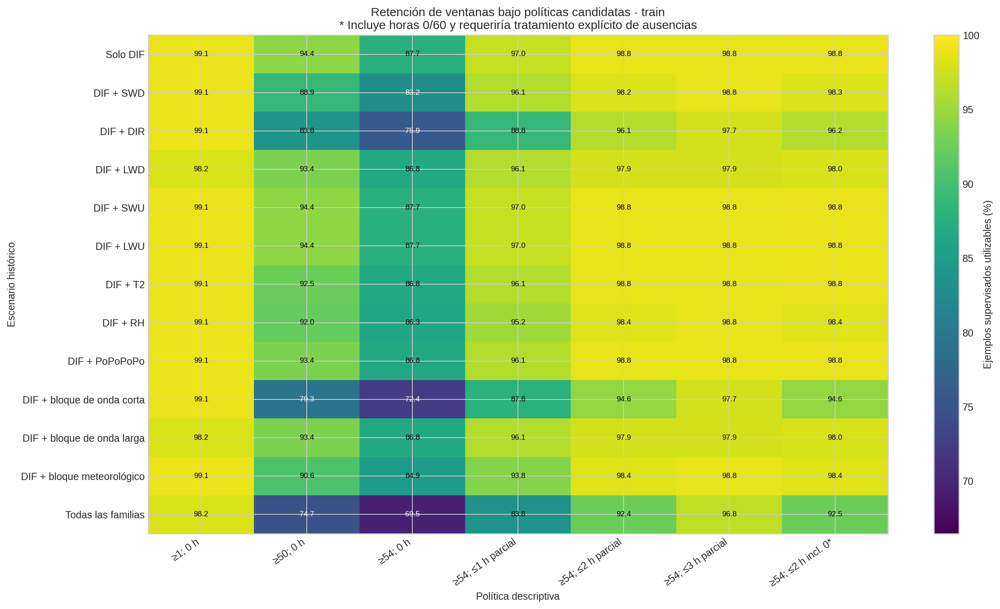

05_estabilidad_mensual_politicas_train.png


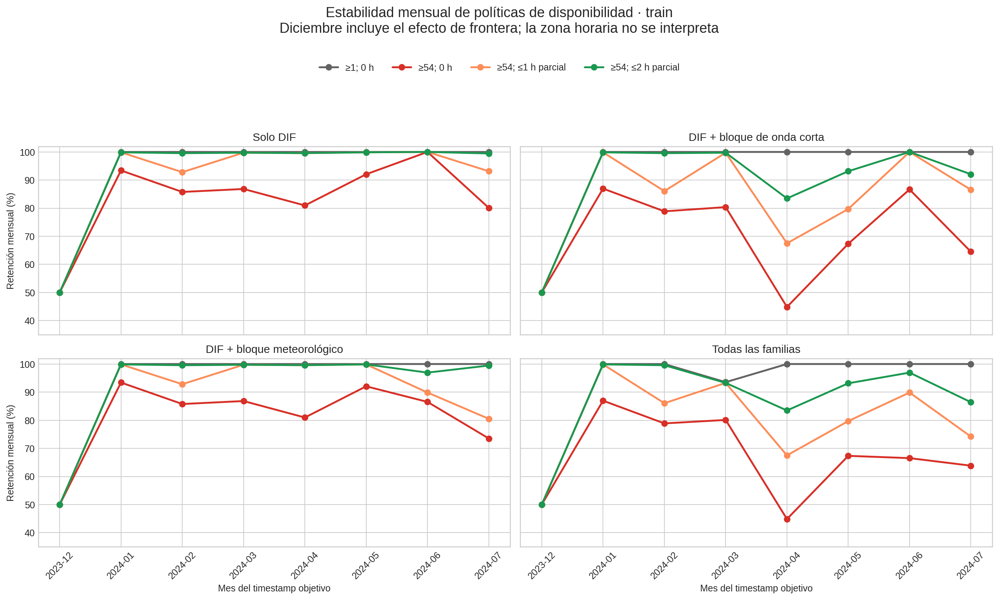


=== ADVERTENCIAS Y ALCANCE ===


,id,advertencia,decision,resolver_en
0,V701,Los umbrales y tolerancias son escenarios desc...,No eliminar ni imputar observaciones en esta s...,Preparación de datos y validación predictiva
1,V702,Aceptar una hora 0/60 deja un valor horario au...,Presentar esa retención como límite potencial ...,"Diseño de máscaras, imputación y pruebas de ro..."
2,V703,La calidad estadística de una media basada en ...,Comparar políticas mediante rendimiento predic...,Entrenamiento y validación temporal
3,V704,No se han cargado valores de validation ni test.,No anticipar su disponibilidad ni ajustar regl...,Después de congelar la política con train
4,V705,La zona horaria continúa sin confirmarse.,No interpretar los meses o timestamps como hor...,Antes de incorporar geometría solar
5,V706,La retención de diciembre incluye las primeras...,No interpretar el valor de diciembre como un p...,Interpretación temporal de los resultados



=== PROTECCIÓN DE PARTICIONES ===
Partición objetivo analizada: TRAIN
Contexto histórico permitido: pre_segmento + train
Valores físicos cargados: NO; solo conteos de minutos disponibles
Valores de validation cargados: NO
Valores de test cargados: NO
Lags materializados: NO
Filas eliminadas: 0
Valores imputados: 0
Valores corregidos: 0
Política final seleccionada: NO

=== ZIP ===
Nombre: EDA_multivariante_F2_S2_7_20261102T165824Z_3d765298.zip
Tamaño: 2.65 MiB (2,778,159 bytes)
SHA-256: 8c9088b0359359089ad3a20b75367f73af9bf3e4f9e199c5b70cc41a992c94e7
Integridad: CORRECTA
Contenido:
- README.md
- checkpoints/10a_tabla_horaria_particionada_sin_cambios.parquet
- checkpoints/10b_catalogo_ventanas_estructurales_48h_sin_cambios.parquet
- checkpoints/10c_catalogo_disponibilidad_ventanas_train_sin_cambios.parquet
- checkpoints/10d_catalogo_sensibilidad_disponibilidad_train.parquet
- configuracion/configuracion_2_7.json
- figuras/01_tipologia_horas_no_completas_train.png
- figuras/02_sensibilid

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import sys
import subprocess
import importlib.util

# PyArrow es la única dependencia que podría no estar instalada.
if importlib.util.find_spec("pyarrow") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyarrow"])

import io
import json
import hashlib
import os
import platform
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import pyarrow
import pyarrow.parquet as pq
try:
    from IPython.display import Image, display
except ImportError:
    # Respaldo para pruebas fuera de notebook; en Colab se usa IPython.
    class Image:
        def __init__(self, filename):
            self.filename = filename

        def __repr__(self):
            return f"Image({self.filename!r})"

    def display(value):
        print(value)

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    files = None
    IN_COLAB = False


# 1. Contrato predictivo y configuración congelada
HISTORY_HOURS = 48
HORIZON_HOURS = 1
TRAIN_START = pd.Timestamp("2023-12-28 00:00:00")
TRAIN_END_EXCLUSIVE = pd.Timestamp("2024-08-01 00:00:00")
N_TRAIN_TARGETS = 5208

# Umbrales de minutos disponibles evaluados por hora.
MINUTE_THRESHOLDS = [1, 30, 45, 48, 50, 54, 55, 60]

# Número máximo de timestamps que pueden quedar por debajo del umbral dentro
# de la ventana histórica de 48 h. En escenarios multivariantes, un timestamp
# se considera deficiente si falla al menos una de las familias requeridas.
DEFICIENT_HOUR_TOLERANCES = [0, 1, 2, 3, 4, 6]
INPUT_HOURLY_CHECKPOINT = "checkpoints/09a_tabla_horaria_particionada_sin_cambios.parquet"
INPUT_STRUCTURAL_CATALOG = "checkpoints/09b_catalogo_ventanas_estructurales_48h_sin_cambios.parquet"
INPUT_AVAILABILITY_CATALOG = "checkpoints/09c_catalogo_disponibilidad_ventanas_train.parquet"
INPUT_CONFIG = "configuracion/configuracion_2_6.json"
FAMILIES = ["SWD", "DIR", "DIF", "LWD", "SWU", "LWU", "T2", "RH", "PoPoPoPo"]
FAMILY_COUNT_COLUMNS = {
    "SWD": "SWD__media__n_disponibles",
    "DIR": "DIR__media__n_disponibles",
    "DIF": "DIF__media__n_disponibles",
    "LWD": "LWD__media__n_disponibles",
    "SWU": "SWU__media__n_disponibles",
    "LWU": "LWU__media__n_disponibles",
    "T2": "T2__n_disponibles",
    "RH": "RH__n_disponibles",
    "PoPoPoPo": "PoPoPoPo__n_disponibles",
}

# Son escenarios descriptivos; no constituyen una selección de variables.
SCENARIOS = [
    ("S00_DIF", "Solo DIF", ["DIF"]),
    ("S01_DIF_SWD", "DIF + SWD", ["DIF", "SWD"]),
    ("S02_DIF_DIR", "DIF + DIR", ["DIF", "DIR"]),
    ("S03_DIF_LWD", "DIF + LWD", ["DIF", "LWD"]),
    ("S04_DIF_SWU", "DIF + SWU", ["DIF", "SWU"]),
    ("S05_DIF_LWU", "DIF + LWU", ["DIF", "LWU"]),
    ("S06_DIF_T2", "DIF + T2", ["DIF", "T2"]),
    ("S07_DIF_RH", "DIF + RH", ["DIF", "RH"]),
    ("S08_DIF_P", "DIF + PoPoPoPo", ["DIF", "PoPoPoPo"]),
    ("S09_ONDA_CORTA", "DIF + bloque de onda corta", ["DIF", "SWD", "DIR", "SWU"]),
    ("S10_ONDA_LARGA", "DIF + bloque de onda larga", ["DIF", "LWD", "LWU"]),
    ("S11_METEO", "DIF + bloque meteorológico", ["DIF", "T2", "RH", "PoPoPoPo"]),
    ("S12_TODAS", "Todas las familias", FAMILIES.copy()),
]
SCENARIO_LABELS = {code: label for code, label, _ in SCENARIOS}
SCENARIO_FAMILIES = {code: families_ for code, _, families_ in SCENARIOS}
SELECTED_SCENARIOS = ["S00_DIF", "S02_DIF_DIR", "S09_ONDA_CORTA", "S11_METEO", "S12_TODAS"]

# Dos modos de tolerancia:
# - parcial_sin_ceros: permite horas por debajo del umbral, pero nunca 0/60.
# - operativa_con_ceros: permite también 0/60; solo sería aplicable con una
#   estrategia explícita de máscara, imputación o modelo tolerante a ausencias.
TOLERANCE_MODES = {
    "parcial_sin_ceros": "Tolerancia parcial (sin horas 0/60)",
    "operativa_con_ceros": "Tolerancia operativa (incluye 0/60)",
}
POLICIES = [
    {
        "codigo_politica": "P00_FINITO",
        "politica_corta": "≥1; 0 h",
        "politica": "Al menos 1/60 min en todas las horas",
        "umbral_minutos": 1,
        "tolerancia_horas": 0,
        "modo_tolerancia": "parcial_sin_ceros",
    },
    {
        "codigo_politica": "P01_50_ESTRICTO",
        "politica_corta": "≥50; 0 h",
        "politica": "Al menos 50/60 min en todas las horas",
        "umbral_minutos": 50,
        "tolerancia_horas": 0,
        "modo_tolerancia": "parcial_sin_ceros",
    },
    {
        "codigo_politica": "P02_54_ESTRICTO",
        "politica_corta": "≥54; 0 h",
        "politica": "Al menos 54/60 min en todas las horas",
        "umbral_minutos": 54,
        "tolerancia_horas": 0,
        "modo_tolerancia": "parcial_sin_ceros",
    },
    {
        "codigo_politica": "P03_54_TOL1_PARCIAL",
        "politica_corta": "≥54; ≤1 h parcial",
        "politica": "54/60 con hasta 1 timestamp deficiente en 48 h, sin 0/60",
        "umbral_minutos": 54,
        "tolerancia_horas": 1,
        "modo_tolerancia": "parcial_sin_ceros",
    },
    {
        "codigo_politica": "P04_54_TOL2_PARCIAL",
        "politica_corta": "≥54; ≤2 h parcial",
        "politica": "54/60 con hasta 2 timestamps deficientes en 48 h, sin 0/60",
        "umbral_minutos": 54,
        "tolerancia_horas": 2,
        "modo_tolerancia": "parcial_sin_ceros",
    },
    {
        "codigo_politica": "P05_54_TOL3_PARCIAL",
        "politica_corta": "≥54; ≤3 h parcial",
        "politica": "54/60 con hasta 3 timestamps deficientes en 48 h, sin 0/60",
        "umbral_minutos": 54,
        "tolerancia_horas": 3,
        "modo_tolerancia": "parcial_sin_ceros",
    },
    {
        "codigo_politica": "P06_54_TOL2_OPERATIVA",
        "politica_corta": "≥54; ≤2 h incl. 0*",
        "politica": "54/60 con hasta 2 timestamps deficientes, incluidos 0/60",
        "umbral_minutos": 54,
        "tolerancia_horas": 2,
        "modo_tolerancia": "operativa_con_ceros",
    },
]


# 2. Funciones auxiliares
def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()

def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open("rb") as file:
        while True:
            chunk = file.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)
    return digest.hexdigest()

def verify_zip_inventory(raw_zip):
    """Verifica CRC, rutas, tamaños y SHA-256 del ZIP de entrada."""
    with zipfile.ZipFile(io.BytesIO(raw_zip)) as zip_file:
        assert zip_file.testzip() is None, "El ZIP contiene un archivo dañado."
        assert "inventario_archivos.csv" in zip_file.namelist(), "Falta inventario_archivos.csv."
        inventory = pd.read_csv(
            io.BytesIO(zip_file.read("inventario_archivos.csv")), encoding="utf-8-sig"
        )
        required = {"ruta_relativa", "tamano_bytes", "sha256"}
        assert required.issubset(inventory.columns), "El inventario está incompleto."
        for row in inventory.itertuples(index=False):
            relative_path = str(row.ruta_relativa)
            assert (
                relative_path in zip_file.namelist()
            ), f"Falta el archivo inventariado: {relative_path}"
            content = zip_file.read(relative_path)
            assert len(content) == int(row.tamano_bytes), f"Tamaño incorrecto: {relative_path}"
            assert sha256_bytes(content) == str(row.sha256), f"SHA-256 incorrecto: {relative_path}"
    return inventory

def save_csv(dataframe, path):
    dataframe.to_csv(path, index=False, encoding="utf-8-sig")

def history_count(mask):
    """Cuenta horas válidas en [objetivo - 48 h, objetivo - 1 h]."""
    series = pd.Series(np.asarray(mask, dtype=bool))
    return (
        series.shift(1, fill_value=False)
        .rolling(window=HISTORY_HOURS, min_periods=HISTORY_HOURS)
        .sum()
        .fillna(0)
        .astype(np.int16)
    )

def load_input_zip():
    if IN_COLAB:
        print("Selecciona exclusivamente el ZIP validado de la subsección 2.6.")
        uploaded = files.upload()
        assert len(uploaded) == 1, "Debes seleccionar exactamente un ZIP: el de la subsección 2.6."
        return next(iter(uploaded.items()))

    local_path = os.environ.get("INPUT_ZIP_2_6")
    assert local_path, "Fuera de Colab define INPUT_ZIP_2_6 con la ruta del ZIP 2.6."
    path = Path(local_path)
    assert path.is_file(), f"No existe el ZIP indicado: {path}"
    return path.name, path.read_bytes()

def history_ok(counts_quality, counts_finite, tolerance, mode):
    quality_ok = counts_quality >= (HISTORY_HOURS - tolerance)
    if mode == "parcial_sin_ceros":
        return quality_ok & (counts_finite == HISTORY_HOURS)
    if mode == "operativa_con_ceros":
        return quality_ok
    raise ValueError(f"Modo de tolerancia desconocido: {mode}")


# 3. Carga segura del ZIP 2.6
uploaded_name, raw_zip = load_input_zip()
assert zipfile.is_zipfile(io.BytesIO(raw_zip)), "El archivo seleccionado no es ZIP."
input_inventory = verify_zip_inventory(raw_zip)
with zipfile.ZipFile(io.BytesIO(raw_zip)) as zip_file:
    members = set(zip_file.namelist())
    required_members = {
        INPUT_HOURLY_CHECKPOINT,
        INPUT_STRUCTURAL_CATALOG,
        INPUT_AVAILABILITY_CATALOG,
        INPUT_CONFIG,
    }
    assert required_members.issubset(
        members
    ), "El ZIP no contiene los archivos esperados de la subsección 2.6."
    hourly_checkpoint_bytes = zip_file.read(INPUT_HOURLY_CHECKPOINT)
    structural_catalog_bytes = zip_file.read(INPUT_STRUCTURAL_CATALOG)
    availability_catalog_bytes = zip_file.read(INPUT_AVAILABILITY_CATALOG)
    input_config = json.loads(zip_file.read(INPUT_CONFIG))

assert input_config["fase"] == 2
assert str(input_config["subseccion"]) == "2.6"
hourly_input_sha = sha256_bytes(hourly_checkpoint_bytes)
structural_input_sha = sha256_bytes(structural_catalog_bytes)
availability_input_sha = sha256_bytes(availability_catalog_bytes)
assert hourly_input_sha == input_config["checkpoints"]["tabla_horaria"]["sha256"]
assert structural_input_sha == input_config["checkpoints"]["catalogo_estructural"]["sha256"]
assert (
    availability_input_sha == input_config["checkpoints"]["catalogo_disponibilidad_train"]["sha256"]
)
parquet_file = pq.ParquetFile(io.BytesIO(hourly_checkpoint_bytes))
source_shape = (int(parquet_file.metadata.num_rows), int(parquet_file.metadata.num_columns))
source_columns = set(parquet_file.schema.names)
assert source_shape == (9504, 132)
columns_to_load = ["Date/Time", "particion_observacion", *FAMILY_COUNT_COLUMNS.values()]
assert len(columns_to_load) == 11
assert set(columns_to_load).issubset(source_columns)

# Solo se cargan conteos de minutos de pre_segmento y train. No se cargan
# valores físicos ni ninguna columna de validation o test.
analysis_source = (
    pd.read_parquet(
        io.BytesIO(hourly_checkpoint_bytes),
        columns=columns_to_load,
        filters=[("particion_observacion", "in", ["pre_segmento", "train"])],
    )
    .sort_values("Date/Time")
    .reset_index(drop=True)
)
assert analysis_source.shape == (6576, 11)
assert set(analysis_source["particion_observacion"].unique()) == {"pre_segmento", "train"}
assert not analysis_source["particion_observacion"].isin(["validation", "test"]).any()
assert analysis_source["Date/Time"].is_monotonic_increasing
assert not analysis_source["Date/Time"].duplicated().any()
assert analysis_source["Date/Time"].diff().dropna().eq(pd.Timedelta(hours=1)).all()
for column in FAMILY_COUNT_COLUMNS.values():
    converted = pd.to_numeric(analysis_source[column], errors="raise")
    assert converted.notna().all()
    assert converted.between(0, 60).all()
    analysis_source[column] = converted.astype(np.int16)

structural_catalog = pd.read_parquet(io.BytesIO(structural_catalog_bytes))
availability_input = pd.read_parquet(io.BytesIO(availability_catalog_bytes))
assert structural_catalog.shape == (9504, 17)
assert availability_input.shape == (5208, 71)
structural_train = structural_catalog.loc[
    structural_catalog["target_partition"].astype("string").eq("train")
].reset_index(drop=True)
assert len(structural_train) == N_TRAIN_TARGETS
assert structural_train["window_48h_structurally_complete"].all()
assert structural_train["target_timestamp"].iloc[0] == TRAIN_START
assert structural_train["target_timestamp"].iloc[-1] == (
    TRAIN_END_EXCLUSIVE - pd.Timedelta(hours=1)
)
train_mask = analysis_source["particion_observacion"].eq("train").to_numpy()
train_positions = np.flatnonzero(train_mask)
train_timestamps = analysis_source.loc[train_mask, "Date/Time"].reset_index(drop=True)
assert len(train_positions) == N_TRAIN_TARGETS
assert train_timestamps.equals(structural_train["target_timestamp"].reset_index(drop=True))
assert train_timestamps.equals(availability_input["target_timestamp"].reset_index(drop=True))


# 4. Conteos horarios y tipología de disponibilidad
hour_minutes = {
    family: analysis_source[column].to_numpy(dtype=np.int16)
    for family, column in FAMILY_COUNT_COLUMNS.items()
}
target_DIF_minutes = hour_minutes["DIF"][train_positions]
target_ok = {threshold: target_DIF_minutes >= threshold for threshold in MINUTE_THRESHOLDS}

# Ámbito horario que puede intervenir en algún objetivo de train: las 48 h
# previas al primer objetivo más todos los timestamps objetivo de train.
relevant_start = TRAIN_START - pd.Timedelta(hours=HISTORY_HOURS)
relevant_end = TRAIN_END_EXCLUSIVE - pd.Timedelta(hours=1)
relevant_mask = analysis_source["Date/Time"].between(relevant_start, relevant_end).to_numpy()
assert int(relevant_mask.sum()) == N_TRAIN_TARGETS + HISTORY_HOURS
availability_types = [
    ("ausencia_total", "0/60 · ausencia total", 0, 0),
    ("parcial_baja", "1–53/60 · cobertura parcial", 1, 53),
    ("alta_incompleta", "54–59/60 · cobertura alta", 54, 59),
    ("completa", "60/60 · hora completa", 60, 60),
]
typology_rows = []
for family in FAMILIES:
    values = hour_minutes[family][relevant_mask]
    for order, (type_code, type_label, lower, upper) in enumerate(availability_types):
        category_mask = (values >= lower) & (values <= upper)
        n_hours = int(category_mask.sum())
        typology_rows.append(
            {
                "familia": family,
                "orden_categoria": order,
                "tipo_disponibilidad": type_code,
                "categoria": type_label,
                "n_horas": n_hours,
                "pct_horas": 100.0 * n_hours / len(values),
                "n_horas_ambito": int(len(values)),
                "inicio_ambito": relevant_start,
                "fin_ambito": relevant_end,
            }
        )

availability_typology = pd.DataFrame(typology_rows)
assert (availability_typology.groupby("familia")["n_horas"].sum() == int(relevant_mask.sum())).all()


# 5. Sensibilidad por familia y por escenario
history_counts = {}
for threshold in MINUTE_THRESHOLDS:
    for family in FAMILIES:
        counts_all = history_count(hour_minutes[family] >= threshold)
        history_counts[(threshold, family)] = counts_all.iloc[train_positions].to_numpy(
            dtype=np.int16
        )

# Para un escenario multivariante se cuenta un timestamp como válido únicamente
# cuando todas sus familias cumplen el umbral. De esta forma, tolerar dos horas
# significa tolerar como máximo dos timestamps deficientes en toda la ventana,
# no dos horas independientes por cada variable.
scenario_history_counts = {}
for threshold in MINUTE_THRESHOLDS:
    for scenario_code, _, scenario_families in SCENARIOS:
        joint_hour_mask = np.logical_and.reduce(
            [hour_minutes[family] >= threshold for family in scenario_families]
        )
        counts_all = history_count(joint_hour_mask)
        scenario_history_counts[(threshold, scenario_code)] = counts_all.iloc[
            train_positions
        ].to_numpy(dtype=np.int16)

# Reconciliación exacta con los dos criterios ya calculados en 2.6.
assert np.array_equal(target_ok[1], availability_input["target_DIF_finite"].to_numpy(dtype=bool))
assert np.array_equal(
    target_ok[54], availability_input["target_DIF_coverage_54_60_ok"].to_numpy(dtype=bool)
)
for family in FAMILIES:
    assert np.array_equal(
        history_counts[(1, family)],
        availability_input[f"{family}__n_horas_historia_finitas"].to_numpy(dtype=np.int16),
    )
    assert np.array_equal(
        history_counts[(54, family)],
        availability_input[f"{family}__n_horas_historia_54_60"].to_numpy(dtype=np.int16),
    )

family_sensitivity_rows = []
scenario_sensitivity_rows = []
scenario_masks = {}
for threshold in MINUTE_THRESHOLDS:
    target_mask = target_ok[threshold]
    for tolerance in DEFICIENT_HOUR_TOLERANCES:
        for mode in TOLERANCE_MODES:
            for family in FAMILIES:
                history_mask = history_ok(
                    history_counts[(threshold, family)],
                    history_counts[(1, family)],
                    tolerance,
                    mode,
                )
                usable = target_mask & history_mask
                family_sensitivity_rows.append(
                    {
                        "familia_historica": family,
                        "umbral_minutos": threshold,
                        "tolerancia_horas_en_ventana": tolerance,
                        "modo_tolerancia": mode,
                        "descripcion_modo": TOLERANCE_MODES[mode],
                        "n_objetivos_train": N_TRAIN_TARGETS,
                        "n_objetivos_DIF_validos": int(target_mask.sum()),
                        "n_ventanas_historia_validas": int(history_mask.sum()),
                        "n_ejemplos_utilizables": int(usable.sum()),
                        "pct_ejemplos_utilizables": 100.0 * usable.mean(),
                        "n_ejemplos_no_utilizables": int((~usable).sum()),
                    }
                )

            for scenario_code, scenario_label, scenario_families in SCENARIOS:
                scenario_history_ok = history_ok(
                    scenario_history_counts[(threshold, scenario_code)],
                    scenario_history_counts[(1, scenario_code)],
                    tolerance,
                    mode,
                )
                usable = target_mask & scenario_history_ok
                scenario_masks[(threshold, tolerance, mode, scenario_code)] = usable
                scenario_sensitivity_rows.append(
                    {
                        "codigo_escenario": scenario_code,
                        "escenario": scenario_label,
                        "familias_historicas": " + ".join(scenario_families),
                        "n_familias": len(scenario_families),
                        "umbral_minutos": threshold,
                        "tolerancia_horas_en_ventana": tolerance,
                        "modo_tolerancia": mode,
                        "descripcion_modo": TOLERANCE_MODES[mode],
                        "n_objetivos_train": N_TRAIN_TARGETS,
                        "n_objetivos_DIF_validos": int(target_mask.sum()),
                        "n_ventanas_historia_validas": int(scenario_history_ok.sum()),
                        "n_ejemplos_utilizables": int(usable.sum()),
                        "pct_ejemplos_utilizables": 100.0 * usable.mean(),
                        "n_ejemplos_no_utilizables": int((~usable).sum()),
                    }
                )

family_sensitivity = pd.DataFrame(family_sensitivity_rows)
scenario_sensitivity = pd.DataFrame(scenario_sensitivity_rows)

# En tolerancia cero ambos modos deben ser idénticos.
zero_tolerance = scenario_sensitivity.loc[scenario_sensitivity["tolerancia_horas_en_ventana"].eq(0)]
zero_pivot = zero_tolerance.pivot_table(
    index=["codigo_escenario", "umbral_minutos"],
    columns="modo_tolerancia",
    values="n_ejemplos_utilizables",
)
assert zero_pivot.nunique(axis=1).eq(1).all()

# Reconciliación de los escenarios con 2.6 para finitud y 54/60 estrictos.
for scenario_code, _, _ in SCENARIOS:
    mask_finite = scenario_masks[(1, 0, "parcial_sin_ceros", scenario_code)]
    mask_54 = scenario_masks[(54, 0, "parcial_sin_ceros", scenario_code)]
    assert np.array_equal(
        mask_finite, availability_input[f"{scenario_code}__usable_finito"].to_numpy(bool)
    )
    assert np.array_equal(
        mask_54, availability_input[f"{scenario_code}__usable_54_60"].to_numpy(bool)
    )

# Monotonicidad esperada: elevar el umbral no puede aumentar la retención;
# elevar la tolerancia no puede reducirla.
for mode in TOLERANCE_MODES:
    for scenario_code, _, _ in SCENARIOS:
        for tolerance in DEFICIENT_HOUR_TOLERANCES:
            values = (
                scenario_sensitivity.loc[
                    scenario_sensitivity["modo_tolerancia"].eq(mode)
                    & scenario_sensitivity["codigo_escenario"].eq(scenario_code)
                    & scenario_sensitivity["tolerancia_horas_en_ventana"].eq(tolerance)
                ]
                .sort_values("umbral_minutos")["n_ejemplos_utilizables"]
                .to_numpy()
            )
            assert np.all(np.diff(values) <= 0)

        for threshold in MINUTE_THRESHOLDS:
            values = (
                scenario_sensitivity.loc[
                    scenario_sensitivity["modo_tolerancia"].eq(mode)
                    & scenario_sensitivity["codigo_escenario"].eq(scenario_code)
                    & scenario_sensitivity["umbral_minutos"].eq(threshold)
                ]
                .sort_values("tolerancia_horas_en_ventana")["n_ejemplos_utilizables"]
                .to_numpy()
            )
            assert np.all(np.diff(values) >= 0)


# 6. Políticas candidatas y estabilidad mensual
policy_rows = []
for order, policy in enumerate(POLICIES):
    subset = scenario_sensitivity.loc[
        scenario_sensitivity["umbral_minutos"].eq(policy["umbral_minutos"])
        & scenario_sensitivity["tolerancia_horas_en_ventana"].eq(policy["tolerancia_horas"])
        & scenario_sensitivity["modo_tolerancia"].eq(policy["modo_tolerancia"])
    ].copy()
    subset.insert(0, "orden_politica", order)
    subset.insert(1, "codigo_politica", policy["codigo_politica"])
    subset.insert(2, "politica_corta", policy["politica_corta"])
    subset.insert(3, "politica", policy["politica"])
    policy_rows.append(subset)

policy_summary = pd.concat(policy_rows, ignore_index=True)
MONTHLY_POLICIES = ["P00_FINITO", "P02_54_ESTRICTO", "P03_54_TOL1_PARCIAL", "P04_54_TOL2_PARCIAL"]
MONTHLY_SCENARIOS = ["S00_DIF", "S09_ONDA_CORTA", "S11_METEO", "S12_TODAS"]
month_labels = train_timestamps.dt.strftime("%Y-%m")
monthly_rows = []
for policy in POLICIES:
    if policy["codigo_politica"] not in MONTHLY_POLICIES:
        continue
    for scenario_code in MONTHLY_SCENARIOS:
        usable = scenario_masks[
            (
                policy["umbral_minutos"],
                policy["tolerancia_horas"],
                policy["modo_tolerancia"],
                scenario_code,
            )
        ]
        for month in sorted(month_labels.unique()):
            month_mask = month_labels.eq(month).to_numpy()
            n_targets = int(month_mask.sum())
            n_usable = int((usable & month_mask).sum())
            monthly_rows.append(
                {
                    "codigo_politica": policy["codigo_politica"],
                    "politica_corta": policy["politica_corta"],
                    "codigo_escenario": scenario_code,
                    "escenario": SCENARIO_LABELS[scenario_code],
                    "mes_objetivo": month,
                    "n_objetivos": n_targets,
                    "n_ejemplos_utilizables": n_usable,
                    "pct_ejemplos_utilizables": 100.0 * n_usable / n_targets,
                }
            )

monthly_policy_summary = pd.DataFrame(monthly_rows)
assert (
    monthly_policy_summary.groupby(["codigo_politica", "codigo_escenario"])["n_objetivos"].sum()
    == N_TRAIN_TARGETS
).all()


# 7. Resumen interpretativo y catálogo de sensibilidad
def get_pct(scenario_code, policy_code):
    row = policy_summary.loc[
        policy_summary["codigo_escenario"].eq(scenario_code)
        & policy_summary["codigo_politica"].eq(policy_code),
        "pct_ejemplos_utilizables",
    ]
    assert len(row) == 1
    return float(row.iloc[0])

strict_all = get_pct("S12_TODAS", "P02_54_ESTRICTO")
partial1_all = get_pct("S12_TODAS", "P03_54_TOL1_PARCIAL")
partial2_all = get_pct("S12_TODAS", "P04_54_TOL2_PARCIAL")
partial3_all = get_pct("S12_TODAS", "P05_54_TOL3_PARCIAL")
operational2_all = get_pct("S12_TODAS", "P06_54_TOL2_OPERATIVA")
finite_all = get_pct("S12_TODAS", "P00_FINITO")
strict_dif = get_pct("S00_DIF", "P02_54_ESTRICTO")
partial2_dif = get_pct("S00_DIF", "P04_54_TOL2_PARCIAL")
key_metrics = pd.DataFrame(
    [
        ["Todas las familias · criterio finito", finite_all],
        ["Todas las familias · 54/60 estricto", strict_all],
        ["Todas las familias · 54/60 + ≤1 h parcial", partial1_all],
        ["Todas las familias · 54/60 + ≤2 h parciales", partial2_all],
        ["Todas las familias · 54/60 + ≤3 h parciales", partial3_all],
        ["Todas las familias · 54/60 + ≤2 h incl. 0/60*", operational2_all],
        ["Solo DIF · 54/60 estricto", strict_dif],
        ["Solo DIF · 54/60 + ≤2 h parciales", partial2_dif],
    ],
    columns=["indicador", "retencion_pct"],
)
non_complete = availability_typology.loc[
    ~availability_typology["tipo_disponibilidad"].eq("completa")
]
n_zero_family_hours = int(
    non_complete.loc[non_complete["tipo_disponibilidad"].eq("ausencia_total"), "n_horas"].sum()
)
n_partial_family_hours = int(
    non_complete.loc[~non_complete["tipo_disponibilidad"].eq("ausencia_total"), "n_horas"].sum()
)
findings = pd.DataFrame(
    [
        {
            "id": "H271",
            "hallazgo": "El criterio 54/60 estricto amplifica defectos horarios aislados.",
            "evidencia": (
                f"La retención de 'Todas las familias' es {strict_all:.2f}% frente "
                f"a {finite_all:.2f}% con el criterio finito."
            ),
            "implicacion": (
                "No adoptar 54/60 como descarte automático antes de contrastar "
                "alternativas y rendimiento predictivo."
            ),
        },
        {
            "id": "H272",
            "hallazgo": "Una tolerancia pequeña recupera numerosas ventanas.",
            "evidencia": (
                f"Con 54/60 y hasta 2 timestamps parciales por ventana, la retención de "
                f"'Todas las familias' asciende a {partial2_all:.2f}%."
            ),
            "implicacion": (
                "La disponibilidad debe tratarse como política graduada y no como "
                "una regla binaria única."
            ),
        },
        {
            "id": "H273",
            "hallazgo": "Cobertura parcial y ausencia total no son equivalentes.",
            "evidencia": (
                f"En el ámbito horario relevante aparecen {n_partial_family_hours} "
                f"registros familia-hora parcialmente cubiertos y "
                f"{n_zero_family_hours} con 0/60 minutos."
            ),
            "implicacion": (
                "Las horas parciales conservan una media observable; las horas 0/60 "
                "requieren máscara, imputación o un modelo tolerante a ausencias."
            ),
        },
        {
            "id": "H274",
            "hallazgo": "La tolerancia que incluye 0/60 representa un límite operativo.",
            "evidencia": (
                f"Con 54/60 y hasta 2 horas deficientes, incluidas ausencias totales, "
                f"la retención potencial de 'Todas las familias' sería "
                f"{operational2_all:.2f}%."
            ),
            "implicacion": (
                "Ese porcentaje no es directamente utilizable sin diseñar y validar "
                "el tratamiento de valores ausentes."
            ),
        },
    ]
)
warnings = pd.DataFrame(
    [
        {
            "id": "V701",
            "advertencia": (
                "Los umbrales y tolerancias son escenarios descriptivos, no una "
                "política seleccionada."
            ),
            "decision": "No eliminar ni imputar observaciones en esta subsección.",
            "resolver_en": "Preparación de datos y validación predictiva",
        },
        {
            "id": "V702",
            "advertencia": ("Aceptar una hora 0/60 deja un valor horario ausente en la entrada."),
            "decision": ("Presentar esa retención como límite potencial y marcarla con asterisco."),
            "resolver_en": "Diseño de máscaras, imputación y pruebas de robustez",
        },
        {
            "id": "V703",
            "advertencia": (
                "La calidad estadística de una media basada en pocos minutos puede "
                "diferir de una hora completa."
            ),
            "decision": (
                "Comparar políticas mediante rendimiento predictivo y estabilidad, "
                "no solo por retención."
            ),
            "resolver_en": "Entrenamiento y validación temporal",
        },
        {
            "id": "V704",
            "advertencia": "No se han cargado valores de validation ni test.",
            "decision": "No anticipar su disponibilidad ni ajustar reglas con esas particiones.",
            "resolver_en": "Después de congelar la política con train",
        },
        {
            "id": "V705",
            "advertencia": "La zona horaria continúa sin confirmarse.",
            "decision": "No interpretar los meses o timestamps como hora solar/local.",
            "resolver_en": "Antes de incorporar geometría solar",
        },
        {
            "id": "V706",
            "advertencia": (
                "La retención de diciembre incluye las primeras ventanas de train "
                "y, por tanto, el efecto del contexto pre_segmento."
            ),
            "decision": ("No interpretar el valor de diciembre como un patrón estacional puro."),
            "resolver_en": "Interpretación temporal de los resultados",
        },
    ]
)
criteria_contract = pd.DataFrame(
    [
        ["Universo", "5208 objetivos de train con ventana estructural completa"],
        ["Historia", "48 horas anteriores: [objetivo − 48 h, objetivo − 1 h]"],
        ["Horizonte", "1 hora; objetivo = media horaria de DIF"],
        ["Umbrales", ", ".join(map(str, MINUTE_THRESHOLDS)) + " minutos por hora"],
        ["Tolerancias", ", ".join(map(str, DEFICIENT_HOUR_TOLERANCES)) + " timestamps por ventana"],
        [
            "Regla multivariante",
            "un timestamp falla si alguna familia requerida no alcanza el umbral",
        ],
        ["Modo parcial", "tolera baja cobertura, pero exige al menos 1/60 min en cada hora"],
        ["Modo operativo", "puede incluir 0/60; exige máscara, imputación o soporte nativo"],
        ["Particiones", "objetivo train; historia solo de pre_segmento y train"],
        ["Transformaciones", "ninguna eliminación, imputación o corrección"],
        ["Naturaleza", "análisis descriptivo; no selección automática de política"],
    ],
    columns=["elemento", "definicion"],
)

# Catálogo compacto y sin valores físicos para permitir recarga posterior.
sensitivity_catalog = structural_train[
    [
        "target_timestamp",
        "target_partition",
        "origin_timestamp",
        "history_start_expected",
        "history_end_expected",
        "window_48h_structurally_complete",
        "uses_previous_partition_context",
    ]
].copy()
sensitivity_catalog["target_DIF_n_disponibles"] = target_DIF_minutes
for threshold in MINUTE_THRESHOLDS:
    sensitivity_catalog[f"target_DIF_ge_{threshold}"] = target_ok[threshold]
    for family in FAMILIES:
        sensitivity_catalog[f"{family}__n_horas_historia_ge_{threshold}"] = history_counts[
            (threshold, family)
        ]


# 8. Figuras
plt.style.use("seaborn-v0_8-whitegrid")

# Figura 1: tipología de las horas no completas.
type_order = ["ausencia_total", "parcial_baja", "alta_incompleta"]
type_labels = {
    "ausencia_total": "0/60 · ausencia total",
    "parcial_baja": "1–53/60 · cobertura parcial",
    "alta_incompleta": "54–59/60 · cobertura alta",
}
type_colours = {
    "ausencia_total": "#b2182b",
    "parcial_baja": "#ef8a62",
    "alta_incompleta": "#fddbc7",
}
noncomplete_pivot = (
    availability_typology.loc[availability_typology["tipo_disponibilidad"].isin(type_order)]
    .pivot(index="familia", columns="tipo_disponibilidad", values="n_horas")
    .reindex(FAMILIES)
    .fillna(0)
)
fig_typology, ax_typology = plt.subplots(figsize=(12, 6.6))
left = np.zeros(len(FAMILIES))
for type_code in type_order:
    values = noncomplete_pivot[type_code].to_numpy(dtype=float)
    bars = ax_typology.barh(
        FAMILIES, values, left=left, label=type_labels[type_code], color=type_colours[type_code]
    )
    for bar, value, start in zip(bars, values, left):
        if value > 0:
            ax_typology.text(
                start + value / 2,
                bar.get_y() + bar.get_height() / 2,
                f"{int(value)}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if type_code == "ausencia_total" else "black",
            )
    left += values

for y, total in enumerate(left):
    pct = 100.0 * total / int(relevant_mask.sum())
    ax_typology.text(total + 2, y, f"{int(total)} ({pct:.2f}%)", va="center", fontsize=8)

ax_typology.set_xlabel("Horas con menos de 60 minutos disponibles")
ax_typology.set_ylabel("Familia")
ax_typology.set_title(
    "Tipología de las horas no completas relevantes para train\n"
    "Se excluyen visualmente las horas 60/60 para ampliar los defectos"
)
ax_typology.invert_yaxis()
ax_typology.legend(loc="upper right", frameon=True, fontsize=8)
ax_typology.set_xlim(0, max(left) * 1.20)
fig_typology.tight_layout()


# Figura 2: sensibilidad al umbral con tolerancia cero.
fig_threshold, ax_threshold = plt.subplots(figsize=(11.5, 6.7))
line_colours = ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#1f78b4"]
for scenario_code, colour in zip(SELECTED_SCENARIOS, line_colours):
    data = scenario_sensitivity.loc[
        scenario_sensitivity["codigo_escenario"].eq(scenario_code)
        & scenario_sensitivity["tolerancia_horas_en_ventana"].eq(0)
        & scenario_sensitivity["modo_tolerancia"].eq("parcial_sin_ceros")
    ].sort_values("umbral_minutos")
    ax_threshold.plot(
        data["umbral_minutos"],
        data["pct_ejemplos_utilizables"],
        marker="o",
        linewidth=2,
        label=SCENARIO_LABELS[scenario_code],
        color=colour,
    )

ax_threshold.axvline(54, color="black", linestyle="--", linewidth=1.2, label="Umbral 54/60")
ax_threshold.set_xticks(MINUTE_THRESHOLDS)
ax_threshold.set_xticklabels([str(value) for value in MINUTE_THRESHOLDS], rotation=40, ha="right")
ax_threshold.set_ylim(0, 102)
ax_threshold.set_xlabel("Mínimo de minutos disponibles exigido en cada hora")
ax_threshold.set_ylabel("Ejemplos supervisados utilizables (%)")
ax_threshold.set_title(
    "Sensibilidad de la retención al umbral horario · train\n" "Ventana de 48 h sin tolerancia"
)
ax_threshold.legend(loc="lower left", fontsize=8)
fig_threshold.tight_layout()


# Figura 3: efecto de la tolerancia a 54/60, separando los dos modos.
fig_tolerance, axes_tolerance = plt.subplots(1, 2, figsize=(15, 6.2), sharey=True)
for ax, mode in zip(axes_tolerance, TOLERANCE_MODES):
    for scenario_code, colour in zip(SELECTED_SCENARIOS, line_colours):
        data = scenario_sensitivity.loc[
            scenario_sensitivity["codigo_escenario"].eq(scenario_code)
            & scenario_sensitivity["umbral_minutos"].eq(54)
            & scenario_sensitivity["modo_tolerancia"].eq(mode)
        ].sort_values("tolerancia_horas_en_ventana")
        ax.plot(
            data["tolerancia_horas_en_ventana"],
            data["pct_ejemplos_utilizables"],
            marker="o",
            linewidth=2,
            label=SCENARIO_LABELS[scenario_code],
            color=colour,
        )
    ax.set_xticks(DEFICIENT_HOUR_TOLERANCES)
    ax.set_ylim(60, 101)
    ax.set_xlabel("Máximo de timestamps deficientes en la ventana de 48 h")
    ax.set_title(TOLERANCE_MODES[mode])

axes_tolerance[0].set_ylabel("Ejemplos supervisados utilizables (%)")
axes_tolerance[1].legend(loc="lower right", fontsize=8)
fig_tolerance.suptitle("Efecto de relajar el criterio 54/60 · train", fontsize=15)
fig_tolerance.tight_layout(rect=(0, 0, 1, 0.95))


# Figura 4: comparación compacta de políticas candidatas.
policy_pivot = (
    policy_summary.pivot(
        index="codigo_escenario", columns="codigo_politica", values="pct_ejemplos_utilizables"
    )
    .reindex([code for code, _, _ in SCENARIOS])
    .reindex(columns=[p["codigo_politica"] for p in POLICIES])
)
policy_labels_short = [p["politica_corta"] for p in POLICIES]
scenario_labels = [label for _, label, _ in SCENARIOS]
matrix_policy = policy_pivot.to_numpy(dtype=float)
fig_policy, ax_policy = plt.subplots(figsize=(15, 8.5))
vmin_policy = max(0.0, float(np.nanmin(matrix_policy)) - 3.0)
image_policy = ax_policy.imshow(
    matrix_policy, aspect="auto", cmap="viridis", vmin=vmin_policy, vmax=100
)
ax_policy.set_xticks(np.arange(len(policy_labels_short)))
ax_policy.set_xticklabels(policy_labels_short, rotation=35, ha="right")
ax_policy.set_yticks(np.arange(len(scenario_labels)))
ax_policy.set_yticklabels(scenario_labels)
ax_policy.set_xlabel("Política descriptiva")
ax_policy.set_ylabel("Escenario histórico")
ax_policy.set_title(
    "Retención de ventanas bajo políticas candidatas · train\n"
    "* Incluye horas 0/60 y requeriría tratamiento explícito de ausencias"
)
midpoint = (vmin_policy + 100.0) / 2
for row in range(matrix_policy.shape[0]):
    for column in range(matrix_policy.shape[1]):
        value = matrix_policy[row, column]
        ax_policy.text(
            column,
            row,
            f"{value:.1f}",
            ha="center",
            va="center",
            fontsize=7.5,
            color="white" if value < midpoint else "black",
        )

colour_bar_policy = fig_policy.colorbar(image_policy, ax=ax_policy)
colour_bar_policy.set_label("Ejemplos supervisados utilizables (%)")
fig_policy.tight_layout()


# Figura 5: estabilidad mensual de cuatro políticas y cuatro escenarios.
monthly_policy_labels = {
    p["codigo_politica"]: p["politica_corta"]
    for p in POLICIES
    if p["codigo_politica"] in MONTHLY_POLICIES
}
monthly_colours = {
    "P00_FINITO": "#636363",
    "P02_54_ESTRICTO": "#d73027",
    "P03_54_TOL1_PARCIAL": "#fc8d59",
    "P04_54_TOL2_PARCIAL": "#1a9850",
}
fig_monthly, axes_monthly = plt.subplots(2, 2, figsize=(15, 9), sharex=True, sharey=True)
for ax, scenario_code in zip(axes_monthly.flat, MONTHLY_SCENARIOS):
    for policy_code in MONTHLY_POLICIES:
        data = monthly_policy_summary.loc[
            monthly_policy_summary["codigo_escenario"].eq(scenario_code)
            & monthly_policy_summary["codigo_politica"].eq(policy_code)
        ].sort_values("mes_objetivo")
        ax.plot(
            data["mes_objetivo"],
            data["pct_ejemplos_utilizables"],
            marker="o",
            linewidth=2,
            label=monthly_policy_labels[policy_code],
            color=monthly_colours[policy_code],
        )
    ax.set_title(SCENARIO_LABELS[scenario_code])
    ax.set_ylim(35, 102)
    ax.tick_params(axis="x", rotation=45)

for ax in axes_monthly[:, 0]:
    ax.set_ylabel("Retención mensual (%)")
for ax in axes_monthly[-1, :]:
    ax.set_xlabel("Mes del timestamp objetivo")

handles, labels = axes_monthly[0, 0].get_legend_handles_labels()
fig_monthly.suptitle(
    "Estabilidad mensual de políticas de disponibilidad · train\n"
    "Diciembre incluye el efecto de frontera; la zona horaria no se interpreta",
    fontsize=15,
    y=0.99,
)
fig_monthly.legend(
    handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.91), ncol=4, frameon=False
)
fig_monthly.tight_layout(rect=(0, 0, 1, 0.86))


# 9. Resumen técnico
technical_summary = pd.DataFrame(
    [
        ["ZIP 2.6 identificado", True, True, True],
        ["Inventario de entrada verificado", True, True, True],
        ["SHA checkpoint horario verificado", True, True, True],
        ["SHA catálogo estructural verificado", True, True, True],
        ["SHA catálogo disponibilidad verificado", True, True, True],
        ["Filas del checkpoint horario", source_shape[0], 9504, source_shape[0] == 9504],
        ["Columnas del checkpoint horario", source_shape[1], 132, source_shape[1] == 132],
        ["Filas cargadas", len(analysis_source), 6576, len(analysis_source) == 6576],
        ["Columnas cargadas", len(columns_to_load), 11, len(columns_to_load) == 11],
        ["Objetivos train", N_TRAIN_TARGETS, 5208, N_TRAIN_TARGETS == 5208],
        ["Familias evaluadas", len(FAMILIES), 9, len(FAMILIES) == 9],
        ["Escenarios evaluados", len(SCENARIOS), 13, len(SCENARIOS) == 13],
        ["Umbrales evaluados", len(MINUTE_THRESHOLDS), 8, len(MINUTE_THRESHOLDS) == 8],
        [
            "Tolerancias evaluadas",
            len(DEFICIENT_HOUR_TOLERANCES),
            6,
            len(DEFICIENT_HOUR_TOLERANCES) == 6,
        ],
        ["Modos de tolerancia", len(TOLERANCE_MODES), 2, len(TOLERANCE_MODES) == 2],
        ["Reconciliación con 2.6", True, True, True],
        ["Validation: valores cargados", False, False, True],
        ["Test: valores cargados", False, False, True],
        ["Valores físicos cargados", False, False, True],
        ["Lags materializados", False, False, True],
        ["Filas eliminadas", 0, 0, True],
        ["Valores imputados", 0, 0, True],
        ["Valores corregidos", 0, 0, True],
    ],
    columns=["comprobacion", "resultado", "esperado", "superado"],
)
assert technical_summary["superado"].all()


# 10. Guardado versionado y verificable
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8]
if IN_COLAB:
    base_output = Path("/content/eda_multivariante_resultados")
else:
    base_output = Path(os.environ.get("OUTPUT_BASE_2_7", "./test_resultados_2_7"))

run_dir = base_output / f"F2_S2_7_{run_id}"
tables_dir = run_dir / "tablas"
figures_dir = run_dir / "figuras"
config_dir = run_dir / "configuracion"
checkpoints_dir = run_dir / "checkpoints"
run_dir.mkdir(parents=True, exist_ok=False)
tables_dir.mkdir()
figures_dir.mkdir()
config_dir.mkdir()
checkpoints_dir.mkdir()
save_csv(technical_summary, tables_dir / "01_resumen_tecnico.csv")
save_csv(criteria_contract, tables_dir / "02_contrato_sensibilidad.csv")
save_csv(availability_typology, tables_dir / "03_tipologia_disponibilidad_horaria_train.csv")
save_csv(family_sensitivity, tables_dir / "04_sensibilidad_familias_train.csv")
save_csv(scenario_sensitivity, tables_dir / "05_sensibilidad_escenarios_train.csv")
save_csv(policy_summary, tables_dir / "06_politicas_candidatas_train.csv")
save_csv(monthly_policy_summary, tables_dir / "07_retencion_mensual_politicas_train.csv")
save_csv(key_metrics, tables_dir / "08_metricas_clave_train.csv")
save_csv(findings, tables_dir / "09_hallazgos_clave_train.csv")
save_csv(warnings, tables_dir / "10_advertencias_y_alcance.csv")
figure_paths = [
    figures_dir / "01_tipologia_horas_no_completas_train.png",
    figures_dir / "02_sensibilidad_umbral_estricto_train.png",
    figures_dir / "03_sensibilidad_tolerancia_54_60_train.png",
    figures_dir / "04_comparacion_politicas_candidatas_train.png",
    figures_dir / "05_estabilidad_mensual_politicas_train.png",
]
fig_typology.savefig(figure_paths[0], dpi=180, bbox_inches="tight")
fig_threshold.savefig(figure_paths[1], dpi=180, bbox_inches="tight")
fig_tolerance.savefig(figure_paths[2], dpi=180, bbox_inches="tight")
fig_policy.savefig(figure_paths[3], dpi=180, bbox_inches="tight")
fig_monthly.savefig(figure_paths[4], dpi=180, bbox_inches="tight")

# Los tres checkpoints de entrada se conservan byte a byte.
hourly_output_path = checkpoints_dir / "10a_tabla_horaria_particionada_sin_cambios.parquet"
hourly_output_path.write_bytes(hourly_checkpoint_bytes)
assert sha256_file(hourly_output_path) == hourly_input_sha
structural_output_path = (
    checkpoints_dir / "10b_catalogo_ventanas_estructurales_48h_sin_cambios.parquet"
)
structural_output_path.write_bytes(structural_catalog_bytes)
assert sha256_file(structural_output_path) == structural_input_sha
availability_output_path = (
    checkpoints_dir / "10c_catalogo_disponibilidad_ventanas_train_sin_cambios.parquet"
)
availability_output_path.write_bytes(availability_catalog_bytes)
assert sha256_file(availability_output_path) == availability_input_sha

# Nuevo checkpoint: conteos de sensibilidad; nunca valores físicos ni lags.
sensitivity_output_path = checkpoints_dir / "10d_catalogo_sensibilidad_disponibilidad_train.parquet"
sensitivity_catalog.to_parquet(sensitivity_output_path, index=False)
sensitivity_reloaded = pd.read_parquet(sensitivity_output_path)
pd.testing.assert_frame_equal(sensitivity_reloaded, sensitivity_catalog, check_dtype=False)
sensitivity_sha = sha256_file(sensitivity_output_path)
config = {
    "fase": 2,
    "subseccion": "2.7",
    "id_ejecucion": run_id,
    "fecha_utc": datetime.now(timezone.utc).isoformat(),
    "entorno": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "matplotlib": matplotlib.__version__,
        "pyarrow": pyarrow.__version__,
        "colab": IN_COLAB,
    },
    "entrada": {
        "nombre_zip_2_6": uploaded_name,
        "tamano_bytes": len(raw_zip),
        "sha256_zip_2_6": sha256_bytes(raw_zip),
        "inventario_verificado": True,
        "sha256_checkpoint_horario": hourly_input_sha,
        "sha256_catalogo_estructural": structural_input_sha,
        "sha256_catalogo_disponibilidad": availability_input_sha,
    },
    "contrato": {
        "objetivo": "media horaria de DIF",
        "horizonte_horas": HORIZON_HOURS,
        "ventana_historica_horas": HISTORY_HOURS,
        "historia_relativa_objetivo": "[-48 h, -1 h]",
        "umbrales_minutos": MINUTE_THRESHOLDS,
        "tolerancias_timestamps_en_ventana": DEFICIENT_HOUR_TOLERANCES,
        "regla_escenario_multivariante": (
            "un timestamp es deficiente si falla alguna familia requerida"
        ),
        "modos_tolerancia": TOLERANCE_MODES,
        "umbral_objetivo": "el mismo umbral que la historia; sin tolerancia",
        "politica_seleccionada": None,
    },
    "alcance": {
        "particion_objetivo_analizada": "train",
        "particiones_historicas_permitidas": ["pre_segmento", "train"],
        "n_filas_cargadas": int(len(analysis_source)),
        "n_columnas_cargadas": int(len(columns_to_load)),
        "columnas_cargadas": columns_to_load,
        "valores_fisicos_cargados": False,
        "validation_valores_cargados": False,
        "test_valores_cargados": False,
        "lags_materializados": False,
        "filas_eliminadas": 0,
        "valores_imputados": 0,
        "valores_corregidos": 0,
    },
    "resultados": {
        "n_objetivos_train": N_TRAIN_TARGETS,
        "n_familias": len(FAMILIES),
        "n_escenarios": len(SCENARIOS),
        "retencion_todas_finito_pct": finite_all,
        "retencion_todas_54_estricto_pct": strict_all,
        "retencion_todas_54_tol1_parcial_pct": partial1_all,
        "retencion_todas_54_tol2_parcial_pct": partial2_all,
        "retencion_todas_54_tol3_parcial_pct": partial3_all,
        "retencion_todas_54_tol2_operativa_pct": operational2_all,
        "politica_final_decidida": False,
    },
    "checkpoints": {
        "tabla_horaria": {
            "ruta": "checkpoints/10a_tabla_horaria_particionada_sin_cambios.parquet",
            "forma": [9504, 132],
            "sha256": hourly_input_sha,
            "identico_a_entrada_2_6": True,
        },
        "catalogo_estructural": {
            "ruta": "checkpoints/10b_catalogo_ventanas_estructurales_48h_sin_cambios.parquet",
            "forma": [9504, 17],
            "sha256": structural_input_sha,
            "identico_a_entrada_2_6": True,
        },
        "catalogo_disponibilidad": {
            "ruta": "checkpoints/10c_catalogo_disponibilidad_ventanas_train_sin_cambios.parquet",
            "forma": [5208, 71],
            "sha256": availability_input_sha,
            "identico_a_entrada_2_6": True,
        },
        "catalogo_sensibilidad": {
            "ruta": "checkpoints/10d_catalogo_sensibilidad_disponibilidad_train.parquet",
            "forma": [int(sensitivity_catalog.shape[0]), int(sensitivity_catalog.shape[1])],
            "sha256": sensitivity_sha,
            "contiene_valores_fisicos": False,
            "contiene_lags": False,
        },
    },
}
with (config_dir / "configuracion_2_7.json").open("w", encoding="utf-8") as file:
    json.dump(config, file, ensure_ascii=False, indent=2)

execution_summary = {
    "estado": "COMPLETADO",
    "particion_objetivo_analizada": "train",
    "n_objetivos_train": N_TRAIN_TARGETS,
    "n_familias": len(FAMILIES),
    "n_escenarios": len(SCENARIOS),
    "n_figuras": len(figure_paths),
    "retencion_todas_54_estricto_pct": strict_all,
    "retencion_todas_54_tol2_parcial_pct": partial2_all,
    "politica_final_decidida": False,
    "validation_valores_analizados": False,
    "test_valores_analizados": False,
    "valores_fisicos_analizados": False,
    "filas_eliminadas": 0,
    "valores_imputados": 0,
    "valores_corregidos": 0,
}
with (run_dir / "resumen_ejecucion.json").open("w", encoding="utf-8") as file:
    json.dump(execution_summary, file, ensure_ascii=False, indent=2)

readme = f"""# Fase 2 · Subsección 2.7

Ejecución: {run_id}

Análisis descriptivo de sensibilidad de la disponibilidad para objetivos de train,
con historia de 48 horas y horizonte de 1 hora. Se comparan ocho umbrales de
minutos disponibles y seis tolerancias de timestamps deficientes por ventana.

Se separan dos casos: (1) tolerar únicamente horas parciales, conservando al
menos un minuto por hora, y (2) tolerar también horas 0/60. El segundo caso es
solo un límite de retención potencial: exige una estrategia posterior de máscara,
imputación o un modelo que admita valores ausentes.

No se selecciona una política final, no se cargan valores físicos de validation
ni test, no se materializan lags y no se elimina, imputa o corrige ningún dato.

Recarga:

1. Extrae este ZIP.
2. Consulta figuras/ para la interpretación visual.
3. Consulta tablas/ para los valores exactos que sustentan cada figura.
4. Usa checkpoints/10d_catalogo_sensibilidad_disponibilidad_train.parquet para
   recuperar los conteos de sensibilidad por objetivo sin cargar valores físicos.
5. Verifica los SHA-256 en configuracion/configuracion_2_7.json.
"""
(run_dir / "README.md").write_text(readme, encoding="utf-8")

# Inventario de todos los archivos salvo el propio inventario.
inventory_rows = []
for path in sorted(p for p in run_dir.rglob("*") if p.is_file()):
    inventory_rows.append(
        {
            "ruta_relativa": path.relative_to(run_dir).as_posix(),
            "tamano_bytes": path.stat().st_size,
            "sha256": sha256_file(path),
        }
    )

inventory_output = pd.DataFrame(inventory_rows)
save_csv(inventory_output, run_dir / "inventario_archivos.csv")
zip_path = base_output / f"EDA_multivariante_F2_S2_7_{run_id}.zip"
assert not zip_path.exists(), "El nombre versionado del ZIP ya existe."
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zip_file:
    for path in sorted(p for p in run_dir.rglob("*") if p.is_file()):
        zip_file.write(path, arcname=path.relative_to(run_dir).as_posix())

assert zip_path.exists()
with zipfile.ZipFile(zip_path) as zip_file:
    assert zip_file.testzip() is None
    zip_contents = sorted(zip_file.namelist())

zip_size = zip_path.stat().st_size
zip_sha = sha256_file(zip_path)


# 11. Salida visible y descarga
print("\n=== RESUMEN TÉCNICO 2.7 ===")
display(technical_summary)
print("\n=== MÉTRICAS CLAVE · TRAIN ===")
key_metrics_display = key_metrics.copy()
key_metrics_display["retencion_pct"] = key_metrics_display["retencion_pct"].map(
    lambda value: f"{value:.2f}%"
)
display(key_metrics_display)
print("\n=== HALLAZGOS CLAVE ===")
display(findings)
print("\n=== FIGURAS ===")
for figure_path in figure_paths:
    print(figure_path.name)
    display(Image(filename=str(figure_path)))

plt.close("all")
print("\n=== ADVERTENCIAS Y ALCANCE ===")
display(warnings)
print("\n=== PROTECCIÓN DE PARTICIONES ===")
print("Partición objetivo analizada: TRAIN")
print("Contexto histórico permitido: pre_segmento + train")
print("Valores físicos cargados: NO; solo conteos de minutos disponibles")
print("Valores de validation cargados: NO")
print("Valores de test cargados: NO")
print("Lags materializados: NO")
print("Filas eliminadas: 0")
print("Valores imputados: 0")
print("Valores corregidos: 0")
print("Política final seleccionada: NO")
print("\n=== ZIP ===")
print(f"Nombre: {zip_path.name}")
print(f"Tamaño: {zip_size / (1024**2):.2f} MiB ({zip_size:,} bytes)")
print(f"SHA-256: {zip_sha}")
print("Integridad: CORRECTA")
print("Contenido:")
for member in zip_contents:
    print(f"- {member}")
print("Recarga: consulta README.md dentro del ZIP.")
if zip_size > 100 * 1024**2:
    raise RuntimeError(
        "El ZIP supera 100 MiB. No se inicia la descarga automática; "
        "revisa el tamaño antes de cambiar el sistema de guardado."
    )

print("\nSUBSECCIÓN 2.7 EJECUTADA SIN ERRORES.")
if IN_COLAB:
    files.download(str(zip_path))
else:
    print(f"ZIP local: {zip_path.resolve()}")

**Resultados.**

El análisis de sensibilidad mostró que la aplicación estricta del criterio de cobertura 54/60 a todas las observaciones de una ventana histórica de 48 horas reduciría al 69,47 % el conjunto de ejemplos utilizables cuando se consideran todas las familias de variables. Esta pérdida resulta desproporcionada respecto al número de registros horarios realmente afectados y se explica por el solapamiento de las ventanas, mediante el cual una única hora deficiente puede invalidar numerosos ejemplos consecutivos. Al permitir hasta dos timestamps parcialmente cubiertos, pero sin aceptar horas totalmente ausentes, la retención aumentó hasta el 92,42 %. Estos resultados indican que el umbral 54/60 resulta útil como indicador de calidad, pero no debería emplearse como criterio automático de exclusión. La política definitiva deberá contrastarse posteriormente mediante el rendimiento predictivo del modelo y mediante pruebas específicas de robustez frente a datos ausentes.

### 2.8 Evaluación del criterio de disponibilidad 30/60

Tras el análisis de sensibilidad se examina en detalle el umbral 30/60, según el cual una variable está disponible en una hora si cuenta con al menos 30 minutos observados, para comprobar si conserva una parte elevada de la muestra de entrenamiento sin exigir una cobertura casi completa. Para cada una de las nueve familias se cuentan las horas que cumplen el criterio, las que tienen cobertura parcial (1–29 minutos) y las completamente ausentes (0/60). La regla se aplica después de forma conjunta y en su versión estricta, sin tolerancias: una hora es válida si las nueve familias alcanzan el umbral, y un ejemplo es utilizable si esto ocurre en las 48 horas de su historia y el objetivo de DIF también lo cumple. Así se separa la cobertura horaria de la retención de ventanas, ya que una sola hora deficiente puede afectar a varias ventanas consecutivas; el criterio se trata como política candidata, no como decisión definitiva.

Selecciona exclusivamente el ZIP validado de la subsección 2.7.


Saving EDA_multivariante_F2_S2_7_20261102T165824Z_3d765298.zip to EDA_multivariante_F2_S2_7_20261102T165824Z_3d765298.zip

=== SUBSECCIÓN 2.8 · CRITERIO 30/60 ===
Horas train válidas por variable: entre 99.96% y 100.00%
Horas train con las 9 variables válidas simultáneamente: 5,202/5,208 (99.88%)
Ventanas estrictas de 48 h utilizables: 4,872/5,208 (93.55%)
Incumplimientos de train: 7 registros familia-hora, concentrados en 6 timestamps.

=== FIGURAS DE RESUMEN ===
01_panel_cumplimiento_30_60_variables_train.png


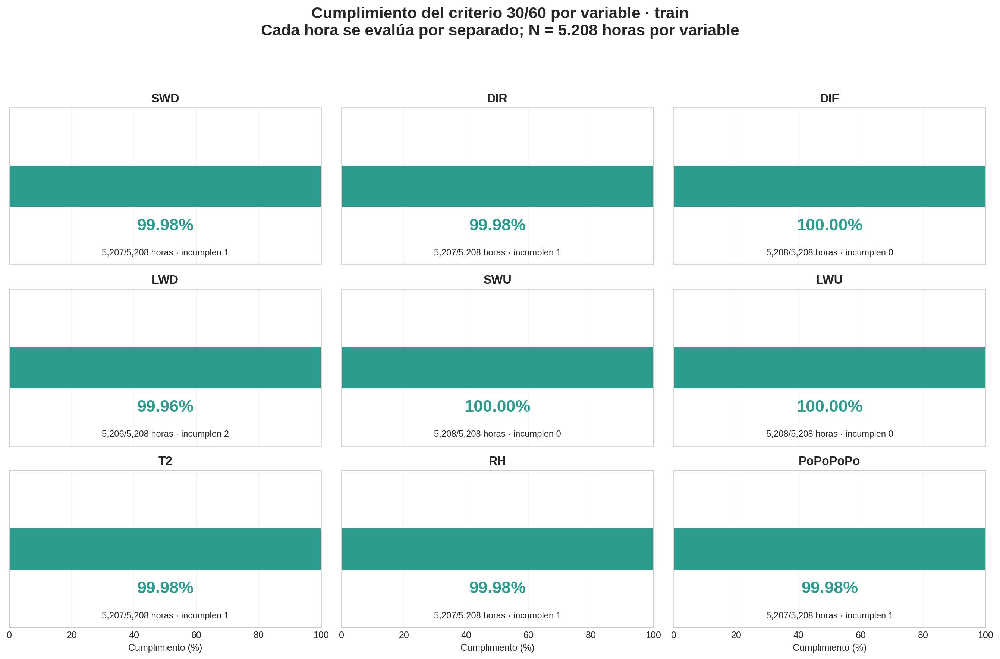

02_hora_vs_ventana_30_60_train.png


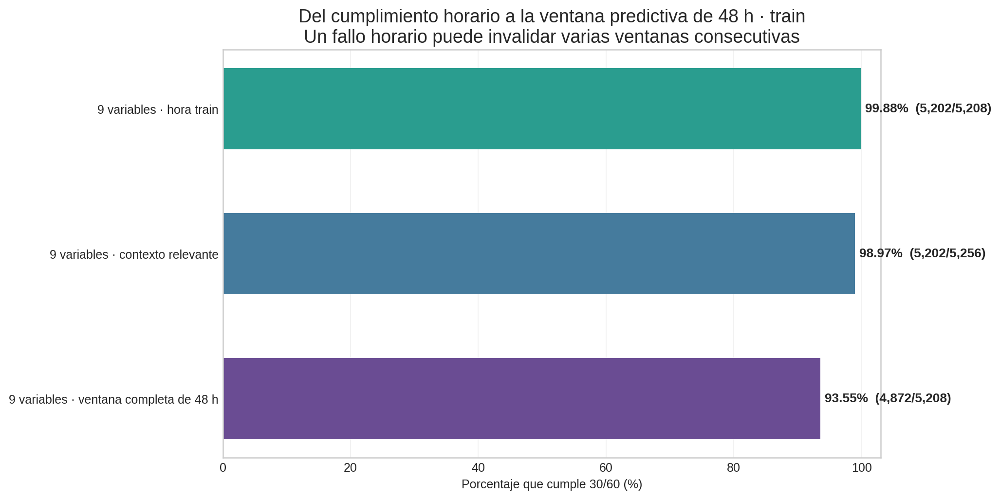

03_cronologia_incumplimientos_30_60.png


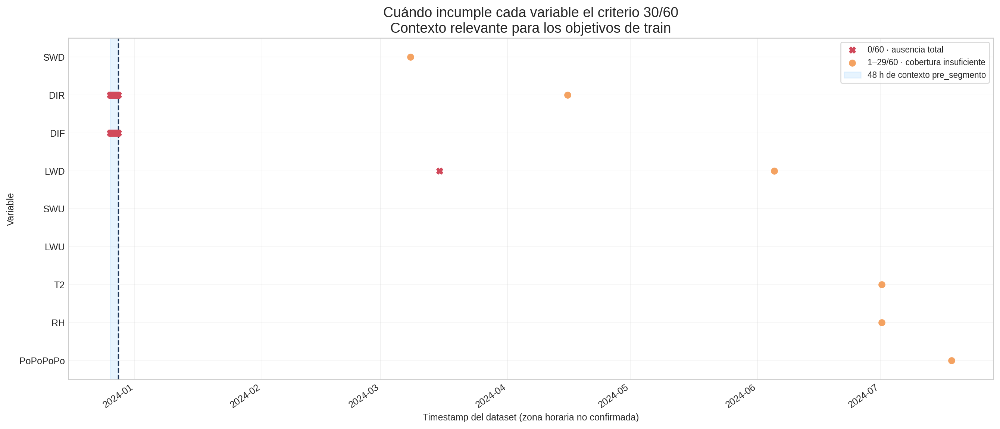

04_retencion_mensual_ventanas_30_60_train.png


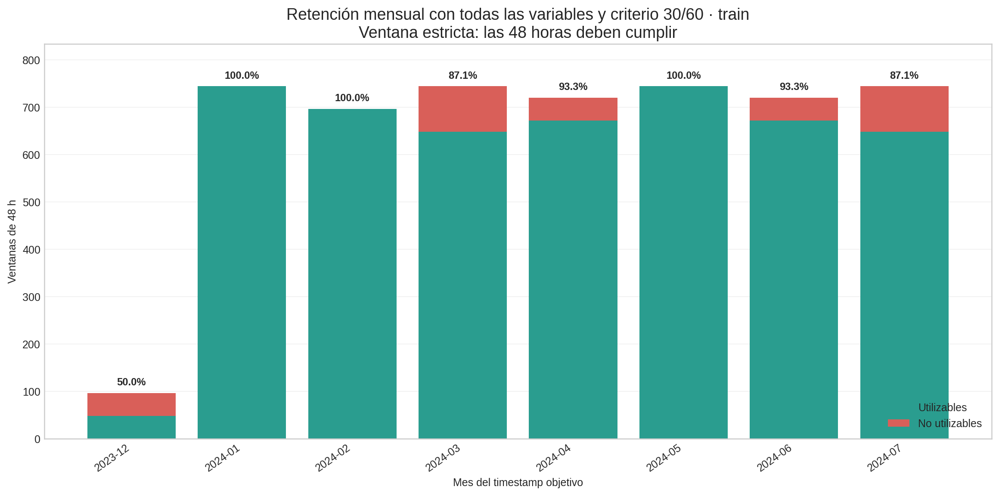


=== FICHAS INDIVIDUALES GUARDADAS ===
- figuras/variables/01_SWD_30_60_train.png
- figuras/variables/02_DIR_30_60_train.png
- figuras/variables/03_DIF_30_60_train.png
- figuras/variables/04_LWD_30_60_train.png
- figuras/variables/05_SWU_30_60_train.png
- figuras/variables/06_LWU_30_60_train.png
- figuras/variables/07_T2_30_60_train.png
- figuras/variables/08_RH_30_60_train.png
- figuras/variables/09_PoPoPoPo_30_60_train.png

=== HALLAZGOS CLAVE ===
- El criterio 30/60 apenas descarta horas individuales de train. La menor cobertura individual es LWD con 99.96%; las nueve familias coinciden en 99.88% de las horas.
- La ventana de 48 h amplifica incidencias horarias aisladas. Solo 6 timestamps de train incumplen de forma conjunta, pero el criterio estricto deja 336 ventanas fuera y conserva 93.55%.
- Los fallos bajo 30/60 están muy localizados. En train aparecen 7 incumplimientos familia-hora concentrados en 6 timestamps únicos.
- Una alta retención no prueba que 30 minutos basten estadí

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
import sys
import subprocess
import importlib.util

# PyArrow es la única dependencia que podría no estar instalada en el entorno.
if importlib.util.find_spec("pyarrow") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyarrow"])

import io
import json
import hashlib
import os
import platform
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Rectangle
import pyarrow
import pyarrow.parquet as pq
try:
    from IPython.display import Image, display
except ImportError:
    class Image:
        def __init__(self, filename):
            self.filename = filename

        def __repr__(self):
            return f"Image({self.filename!r})"

    def display(value):
        print(value)

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    files = None
    IN_COLAB = False


# 1. Contrato del análisis
MINUTES_REQUIRED = 30
HISTORY_HOURS = 48
HORIZON_HOURS = 1
TRAIN_START = pd.Timestamp("2023-12-28 00:00:00")
TRAIN_END_EXCLUSIVE = pd.Timestamp("2024-08-01 00:00:00")
N_TRAIN_TARGETS = 5208
INPUT_HOURLY_CHECKPOINT = "checkpoints/10a_tabla_horaria_particionada_sin_cambios.parquet"
INPUT_STRUCTURAL_CATALOG = "checkpoints/10b_catalogo_ventanas_estructurales_48h_sin_cambios.parquet"
INPUT_AVAILABILITY_CATALOG = (
    "checkpoints/10c_catalogo_disponibilidad_ventanas_train_sin_cambios.parquet"
)
INPUT_SENSITIVITY_CATALOG = "checkpoints/10d_catalogo_sensibilidad_disponibilidad_train.parquet"
INPUT_CONFIG = "configuracion/configuracion_2_7.json"
INPUT_PRIOR_SENSITIVITY = "tablas/05_sensibilidad_escenarios_train.csv"
FAMILIES = ["SWD", "DIR", "DIF", "LWD", "SWU", "LWU", "T2", "RH", "PoPoPoPo"]
FAMILY_COUNT_COLUMNS = {
    "SWD": "SWD__media__n_disponibles",
    "DIR": "DIR__media__n_disponibles",
    "DIF": "DIF__media__n_disponibles",
    "LWD": "LWD__media__n_disponibles",
    "SWU": "SWU__media__n_disponibles",
    "LWU": "LWU__media__n_disponibles",
    "T2": "T2__n_disponibles",
    "RH": "RH__n_disponibles",
    "PoPoPoPo": "PoPoPoPo__n_disponibles",
}
COLOUR_VALID = "#2a9d8f"
COLOUR_PARTIAL = "#f4a261"
COLOUR_ZERO = "#d1495b"
COLOUR_LOST = "#d95f59"
COLOUR_NEUTRAL = "#457b9d"


# 2. Funciones auxiliares
def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()

def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open("rb") as file:
        while True:
            chunk = file.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)
    return digest.hexdigest()

def verify_zip_inventory(raw_zip):
    """Verifica CRC, rutas, tamaños y SHA-256 del ZIP de entrada."""
    with zipfile.ZipFile(io.BytesIO(raw_zip)) as zip_file:
        assert zip_file.testzip() is None, "El ZIP contiene un archivo dañado."
        assert "inventario_archivos.csv" in zip_file.namelist(), "Falta inventario_archivos.csv."
        inventory = pd.read_csv(
            io.BytesIO(zip_file.read("inventario_archivos.csv")), encoding="utf-8-sig"
        )
        required = {"ruta_relativa", "tamano_bytes", "sha256"}
        assert required.issubset(inventory.columns), "El inventario está incompleto."
        for row in inventory.itertuples(index=False):
            relative_path = str(row.ruta_relativa)
            assert (
                relative_path in zip_file.namelist()
            ), f"Falta el archivo inventariado: {relative_path}"
            content = zip_file.read(relative_path)
            assert len(content) == int(row.tamano_bytes), f"Tamaño incorrecto: {relative_path}"
            assert sha256_bytes(content) == str(row.sha256), f"SHA-256 incorrecto: {relative_path}"
    return inventory

def save_csv(dataframe, path):
    dataframe.to_csv(path, index=False, encoding="utf-8-sig")

def history_count(mask):
    """Cuenta horas válidas en [objetivo - 48 h, objetivo - 1 h]."""
    series = pd.Series(np.asarray(mask, dtype=bool))
    return (
        series.shift(1, fill_value=False)
        .rolling(window=HISTORY_HOURS, min_periods=HISTORY_HOURS)
        .sum()
        .fillna(0)
        .astype(np.int16)
    )

def load_input_zip():
    if IN_COLAB:
        print("Selecciona exclusivamente el ZIP validado de la subsección 2.7.")
        uploaded = files.upload()
        assert len(uploaded) == 1, "Debes seleccionar exactamente un ZIP: el de la subsección 2.7."
        return next(iter(uploaded.items()))

    local_path = os.environ.get("INPUT_ZIP_2_7")
    assert local_path, "Fuera de Colab define INPUT_ZIP_2_7 con la ruta del ZIP 2.7."
    path = Path(local_path)
    assert path.is_file(), f"No existe el ZIP indicado: {path}"
    return path.name, path.read_bytes()

def build_hourly_summary(scope_name, scope_mask, timestamps, hour_minutes):
    rows = []
    scope_size = int(scope_mask.sum())
    scope_times = timestamps.loc[scope_mask]
    for family in FAMILIES:
        values = hour_minutes[family][scope_mask]
        valid = values >= MINUTES_REQUIRED
        low = (values > 0) & (values < MINUTES_REQUIRED)
        zero = values == 0
        rows.append(
            {
                "ambito": scope_name,
                "familia": family,
                "n_horas_totales": scope_size,
                "n_horas_ge_30": int(valid.sum()),
                "pct_horas_ge_30": 100.0 * valid.mean(),
                "n_horas_1_29": int(low.sum()),
                "pct_horas_1_29": 100.0 * low.mean(),
                "n_horas_0": int(zero.sum()),
                "pct_horas_0": 100.0 * zero.mean(),
                "n_horas_30_59": int(((values >= 30) & (values < 60)).sum()),
                "n_horas_60": int((values == 60).sum()),
                "primera_hora": scope_times.iloc[0],
                "ultima_hora": scope_times.iloc[-1],
            }
        )
    return pd.DataFrame(rows)

def plot_variable_card(family, row):
    """Ficha individual: KPI principal y desglose exacto de incumplimientos."""
    fig, (ax_kpi, ax_bad) = plt.subplots(
        1, 2, figsize=(10.5, 4.0), gridspec_kw={"width_ratios": [1.75, 1.0]}
    )
    ax_kpi.axis("off")
    pct = float(row["pct_horas_ge_30"])
    n_valid = int(row["n_horas_ge_30"])
    n_total = int(row["n_horas_totales"])
    n_bad = n_total - n_valid
    ax_kpi.text(
        0.5,
        0.72,
        f"{pct:.2f}%",
        ha="center",
        va="center",
        fontsize=34,
        fontweight="bold",
        color=COLOUR_VALID,
        transform=ax_kpi.transAxes,
    )
    ax_kpi.text(
        0.5,
        0.52,
        f"{n_valid:,} de {n_total:,} horas cumplen ≥30/60",
        ha="center",
        va="center",
        fontsize=12,
        transform=ax_kpi.transAxes,
    )
    ax_kpi.add_patch(
        Rectangle(
            (0.08, 0.30),
            0.84,
            0.10,
            transform=ax_kpi.transAxes,
            facecolor="#e9ecef",
            edgecolor="none",
        )
    )
    ax_kpi.add_patch(
        Rectangle(
            (0.08, 0.30),
            0.84 * pct / 100.0,
            0.10,
            transform=ax_kpi.transAxes,
            facecolor=COLOUR_VALID,
            edgecolor="none",
        )
    )
    ax_kpi.text(
        0.5,
        0.18,
        f"Incumplen: {n_bad} horas",
        ha="center",
        va="center",
        fontsize=11,
        color="#4a4a4a",
        transform=ax_kpi.transAxes,
    )
    bad_counts = [int(row["n_horas_1_29"]), int(row["n_horas_0"])]
    labels = ["1–29 min", "0/60 min"]
    bars = ax_bad.barh(labels, bad_counts, color=[COLOUR_PARTIAL, COLOUR_ZERO], height=0.55)
    max_bad = max(1, max(bad_counts))
    ax_bad.set_xlim(0, max_bad * 1.45)
    ax_bad.set_xlabel("Horas que incumplen")
    ax_bad.set_title("Desglose del incumplimiento", fontsize=11)
    ax_bad.grid(axis="x", alpha=0.25)
    ax_bad.grid(axis="y", visible=False)
    for bar, count in zip(bars, bad_counts):
        ax_bad.text(
            bar.get_width() + max_bad * 0.05,
            bar.get_y() + bar.get_height() / 2,
            str(count),
            va="center",
            fontsize=11,
            fontweight="bold",
        )

    fig.suptitle(
        f"{family} · cumplimiento horario del criterio 30/60 en train",
        fontsize=15,
        fontweight="bold",
    )
    fig.text(
        0.5,
        0.01,
        "La hora es válida cuando existen al menos 30 minutos observados.",
        ha="center",
        fontsize=9.5,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.05, 1, 0.92))
    return fig


# 3. Carga segura del ZIP 2.7
uploaded_name, raw_zip = load_input_zip()
assert zipfile.is_zipfile(io.BytesIO(raw_zip)), "El archivo seleccionado no es ZIP."
input_inventory = verify_zip_inventory(raw_zip)
with zipfile.ZipFile(io.BytesIO(raw_zip)) as zip_file:
    members = set(zip_file.namelist())
    required_members = {
        INPUT_HOURLY_CHECKPOINT,
        INPUT_STRUCTURAL_CATALOG,
        INPUT_AVAILABILITY_CATALOG,
        INPUT_SENSITIVITY_CATALOG,
        INPUT_CONFIG,
        INPUT_PRIOR_SENSITIVITY,
    }
    assert required_members.issubset(
        members
    ), "El ZIP no contiene los archivos esperados de la subsección 2.7."
    hourly_checkpoint_bytes = zip_file.read(INPUT_HOURLY_CHECKPOINT)
    structural_catalog_bytes = zip_file.read(INPUT_STRUCTURAL_CATALOG)
    availability_catalog_bytes = zip_file.read(INPUT_AVAILABILITY_CATALOG)
    sensitivity_catalog_input_bytes = zip_file.read(INPUT_SENSITIVITY_CATALOG)
    input_config = json.loads(zip_file.read(INPUT_CONFIG))
    prior_sensitivity = pd.read_csv(
        io.BytesIO(zip_file.read(INPUT_PRIOR_SENSITIVITY)), encoding="utf-8-sig"
    )

assert input_config["fase"] == 2
assert str(input_config["subseccion"]) == "2.7"
hourly_input_sha = sha256_bytes(hourly_checkpoint_bytes)
structural_input_sha = sha256_bytes(structural_catalog_bytes)
availability_input_sha = sha256_bytes(availability_catalog_bytes)
sensitivity_input_sha = sha256_bytes(sensitivity_catalog_input_bytes)
assert hourly_input_sha == input_config["checkpoints"]["tabla_horaria"]["sha256"]
assert structural_input_sha == input_config["checkpoints"]["catalogo_estructural"]["sha256"]
assert availability_input_sha == input_config["checkpoints"]["catalogo_disponibilidad"]["sha256"]
assert sensitivity_input_sha == input_config["checkpoints"]["catalogo_sensibilidad"]["sha256"]
parquet_file = pq.ParquetFile(io.BytesIO(hourly_checkpoint_bytes))
source_shape = (int(parquet_file.metadata.num_rows), int(parquet_file.metadata.num_columns))
source_columns = set(parquet_file.schema.names)
assert source_shape == (9504, 132)
columns_to_load = ["Date/Time", "particion_observacion", *FAMILY_COUNT_COLUMNS.values()]
assert len(columns_to_load) == 11
assert set(columns_to_load).issubset(source_columns)

# Solo se cargan conteos de minutos. No se cargan valores físicos.
analysis_source = (
    pd.read_parquet(
        io.BytesIO(hourly_checkpoint_bytes),
        columns=columns_to_load,
        filters=[("particion_observacion", "in", ["pre_segmento", "train"])],
    )
    .sort_values("Date/Time")
    .reset_index(drop=True)
)
assert analysis_source.shape == (6576, 11)
assert set(analysis_source["particion_observacion"].unique()) == {"pre_segmento", "train"}
assert analysis_source["Date/Time"].is_monotonic_increasing
assert not analysis_source["Date/Time"].duplicated().any()
assert analysis_source["Date/Time"].diff().dropna().eq(pd.Timedelta(hours=1)).all()
for column in FAMILY_COUNT_COLUMNS.values():
    converted = pd.to_numeric(analysis_source[column], errors="raise")
    assert converted.notna().all()
    assert converted.between(0, 60).all()
    analysis_source[column] = converted.astype(np.int16)

structural_catalog = pd.read_parquet(io.BytesIO(structural_catalog_bytes))
assert structural_catalog.shape == (9504, 17)
structural_train = structural_catalog.loc[
    structural_catalog["target_partition"].astype("string").eq("train")
].reset_index(drop=True)
assert len(structural_train) == N_TRAIN_TARGETS
assert structural_train["window_48h_structurally_complete"].all()
train_mask = analysis_source["particion_observacion"].eq("train").to_numpy()
train_positions = np.flatnonzero(train_mask)
train_timestamps = analysis_source.loc[train_mask, "Date/Time"].reset_index(drop=True)
assert len(train_positions) == N_TRAIN_TARGETS
assert train_timestamps.iloc[0] == TRAIN_START
assert train_timestamps.iloc[-1] == TRAIN_END_EXCLUSIVE - pd.Timedelta(hours=1)
assert train_timestamps.equals(structural_train["target_timestamp"].reset_index(drop=True))
relevant_start = TRAIN_START - pd.Timedelta(hours=HISTORY_HOURS)
relevant_end = TRAIN_END_EXCLUSIVE - pd.Timedelta(hours=1)
relevant_mask = analysis_source["Date/Time"].between(relevant_start, relevant_end).to_numpy()
assert int(relevant_mask.sum()) == N_TRAIN_TARGETS + HISTORY_HOURS
hour_minutes = {
    family: analysis_source[column].to_numpy(dtype=np.int16)
    for family, column in FAMILY_COUNT_COLUMNS.items()
}


# 4. Cumplimiento 30/60 por variable
hourly_train = build_hourly_summary("train", train_mask, analysis_source["Date/Time"], hour_minutes)
hourly_relevant = build_hourly_summary(
    "contexto_relevante_pre_segmento_mas_train",
    relevant_mask,
    analysis_source["Date/Time"],
    hour_minutes,
)
assert hourly_train["n_horas_totales"].eq(N_TRAIN_TARGETS).all()
assert hourly_relevant["n_horas_totales"].eq(N_TRAIN_TARGETS + HISTORY_HOURS).all()
assert (
    hourly_train["n_horas_ge_30"]
    .add(hourly_train["n_horas_1_29"])
    .add(hourly_train["n_horas_0"])
    .eq(N_TRAIN_TARGETS)
    .all()
)

# El modelo inicial usa todas las familias. Por eso, además de revisar cada
# variable por separado, una hora conjunta solo es válida si las nueve cumplen.
joint_hour_ok = np.logical_and.reduce(
    [hour_minutes[family] >= MINUTES_REQUIRED for family in FAMILIES]
)
n_joint_train = int(joint_hour_ok[train_mask].sum())
n_joint_relevant = int(joint_hour_ok[relevant_mask].sum())


# 5. Efecto sobre ventanas históricas de 48 horas
joint_history_counts_all = history_count(joint_hour_ok)
joint_history_counts_train = joint_history_counts_all.iloc[train_positions].to_numpy(dtype=np.int16)
history_window_ok = joint_history_counts_train == HISTORY_HOURS
target_DIF_minutes = hour_minutes["DIF"][train_positions]
target_DIF_ok = target_DIF_minutes >= MINUTES_REQUIRED
window_usable = history_window_ok & target_DIF_ok
n_windows_usable = int(window_usable.sum())
n_windows_lost = int((~window_usable).sum())
pct_windows_usable = 100.0 * window_usable.mean()

# Reconciliación exacta con el cálculo general ya realizado en 2.7.
prior_row = prior_sensitivity.loc[
    prior_sensitivity["codigo_escenario"].eq("S12_TODAS")
    & prior_sensitivity["umbral_minutos"].eq(MINUTES_REQUIRED)
    & prior_sensitivity["tolerancia_horas_en_ventana"].eq(0)
    & prior_sensitivity["modo_tolerancia"].eq("parcial_sin_ceros")
]
assert len(prior_row) == 1
assert int(prior_row.iloc[0]["n_ejemplos_utilizables"]) == n_windows_usable
assert np.isclose(float(prior_row.iloc[0]["pct_ejemplos_utilizables"]), pct_windows_usable)
window_catalog = structural_train[
    [
        "target_timestamp",
        "target_partition",
        "origin_timestamp",
        "history_start_expected",
        "history_end_expected",
        "window_48h_structurally_complete",
        "uses_previous_partition_context",
    ]
].copy()
window_catalog["target_DIF_n_disponibles"] = target_DIF_minutes
window_catalog["target_DIF_ge_30"] = target_DIF_ok
window_catalog["n_horas_historia_todas_familias_ge_30"] = joint_history_counts_train
window_catalog["n_horas_historia_deficientes_30_60"] = HISTORY_HOURS - joint_history_counts_train
window_catalog["historia_48h_todas_familias_ge_30"] = history_window_ok
window_catalog["ejemplo_usable_todas_familias_30_60"] = window_usable
month_labels = train_timestamps.dt.strftime("%Y-%m")
monthly_rows = []
for month in sorted(month_labels.unique()):
    month_mask = month_labels.eq(month).to_numpy()
    n_total = int(month_mask.sum())
    n_valid = int((window_usable & month_mask).sum())
    monthly_rows.append(
        {
            "mes_objetivo": month,
            "n_ventanas_totales": n_total,
            "n_ventanas_utilizables_30_60": n_valid,
            "n_ventanas_no_utilizables_30_60": n_total - n_valid,
            "pct_ventanas_utilizables_30_60": 100.0 * n_valid / n_total,
        }
    )
monthly_summary = pd.DataFrame(monthly_rows)
assert int(monthly_summary["n_ventanas_totales"].sum()) == N_TRAIN_TARGETS
assert int(monthly_summary["n_ventanas_utilizables_30_60"].sum()) == n_windows_usable


# 6. Localización de los incumplimientos
event_rows = []
for family in FAMILIES:
    values = hour_minutes[family]
    bad_positions = np.flatnonzero(relevant_mask & (values < MINUTES_REQUIRED))
    for position in bad_positions:
        minutes = int(values[position])
        event_rows.append(
            {
                "timestamp": analysis_source.at[position, "Date/Time"],
                "particion_observacion": analysis_source.at[position, "particion_observacion"],
                "familia": family,
                "minutos_disponibles": minutes,
                "tipo_incumplimiento": "0/60" if minutes == 0 else "1-29/60",
            }
        )
event_detail = pd.DataFrame(event_rows).sort_values(["timestamp", "familia"]).reset_index(drop=True)
joint_event_rows = []
for timestamp, group in event_detail.groupby("timestamp", sort=True):
    joint_event_rows.append(
        {
            "timestamp": timestamp,
            "particion_observacion": " + ".join(sorted(group["particion_observacion"].unique())),
            "familias_afectadas": " + ".join(group["familia"].tolist()),
            "n_familias_afectadas": int(group["familia"].nunique()),
            "min_minutos_disponibles": int(group["minutos_disponibles"].min()),
        }
    )
joint_events = pd.DataFrame(joint_event_rows)
train_joint_events = joint_events.loc[
    joint_events["particion_observacion"].eq("train")
].reset_index(drop=True)
n_unique_bad_train_hours = int(len(train_joint_events))
n_bad_family_hours_train = int(event_detail["particion_observacion"].eq("train").sum())


# 7. Resúmenes e interpretación
joint_summary = pd.DataFrame(
    [
        {
            "indicador": "Horas de train con las 9 familias válidas simultáneamente",
            "numerador": n_joint_train,
            "denominador": N_TRAIN_TARGETS,
            "porcentaje": 100.0 * n_joint_train / N_TRAIN_TARGETS,
        },
        {
            "indicador": "Horas del contexto relevante con las 9 familias válidas",
            "numerador": n_joint_relevant,
            "denominador": N_TRAIN_TARGETS + HISTORY_HOURS,
            "porcentaje": 100.0 * n_joint_relevant / (N_TRAIN_TARGETS + HISTORY_HOURS),
        },
        {
            "indicador": "Ventanas de 48 h utilizables con todas las variables",
            "numerador": n_windows_usable,
            "denominador": N_TRAIN_TARGETS,
            "porcentaje": pct_windows_usable,
        },
    ]
)
min_family_row = hourly_train.loc[hourly_train["pct_horas_ge_30"].idxmin()]
findings = pd.DataFrame(
    [
        {
            "id": "H281",
            "hallazgo": "El criterio 30/60 apenas descarta horas individuales de train.",
            "evidencia": (
                f"La menor cobertura individual es {min_family_row['familia']} con "
                f"{min_family_row['pct_horas_ge_30']:.2f}%; las nueve familias "
                f"coinciden en {100.0 * n_joint_train / N_TRAIN_TARGETS:.2f}% de las horas."
            ),
            "implicacion": "30/60 es un candidato razonable para continuar la comparación.",
        },
        {
            "id": "H282",
            "hallazgo": "La ventana de 48 h amplifica incidencias horarias aisladas.",
            "evidencia": (
                f"Solo {n_unique_bad_train_hours} timestamps de train incumplen de forma "
                f"conjunta, pero el criterio estricto deja {n_windows_lost} ventanas fuera "
                f"y conserva {pct_windows_usable:.2f}%."
            ),
            "implicacion": (
                "La cobertura por hora y la retención de ejemplos supervisados no deben "
                "interpretarse como la misma métrica."
            ),
        },
        {
            "id": "H283",
            "hallazgo": "Los fallos bajo 30/60 están muy localizados.",
            "evidencia": (
                f"En train aparecen {n_bad_family_hours_train} incumplimientos familia-hora "
                f"concentrados en {n_unique_bad_train_hours} timestamps únicos."
            ),
            "implicacion": (
                "Conviene conservar sus fechas como indicador de disponibilidad en lugar "
                "de corregirlas automáticamente."
            ),
        },
        {
            "id": "H284",
            "hallazgo": "Una alta retención no prueba que 30 minutos basten estadísticamente.",
            "evidencia": (
                "Esta subsección usa conteos de disponibilidad y no compara el error "
                "predictivo de medias construidas con 30 frente a 60 minutos."
            ),
            "implicacion": (
                "La decisión final debe contrastarse más adelante con validación temporal "
                "y pruebas de robustez del modelo."
            ),
        },
    ]
)
warnings = pd.DataFrame(
    [
        {
            "id": "V801",
            "advertencia": "30/60 se evalúa como candidato, no como regla definitiva.",
            "decision": "No eliminar, imputar ni corregir datos en 2.8.",
            "resolver_en": "Entrenamiento y validación temporal del modelo",
        },
        {
            "id": "V802",
            "advertencia": (
                "Una media horaria basada en 30 minutos puede sesgarse si la ausencia "
                "no es aleatoria dentro de la hora."
            ),
            "decision": "Comparar rendimiento y estabilidad frente a otros umbrales.",
            "resolver_en": "Análisis predictivo y pruebas de sensibilidad",
        },
        {
            "id": "V803",
            "advertencia": (
                "Para un modelo con todas las variables debe cumplirse la regla de forma "
                "conjunta, no basta con promediar porcentajes individuales."
            ),
            "decision": "Usar la máscara conjunta de las nueve familias.",
            "resolver_en": "Construcción de la matriz de diseño",
        },
        {
            "id": "V804",
            "advertencia": (
                "Diciembre incorpora la frontera inicial y 48 horas de pre_segmento; "
                "no representa un efecto mensual puro."
            ),
            "decision": "Separar frontera de estacionalidad en la interpretación.",
            "resolver_en": "Redacción de resultados",
        },
        {
            "id": "V805",
            "advertencia": "No se han cargado valores de validation ni test.",
            "decision": "No anticipar su disponibilidad ni ajustar con esas particiones.",
            "resolver_en": "Después de congelar la política con train",
        },
    ]
)
criteria_contract = pd.DataFrame(
    [
        ["Unidad de análisis horaria", "una variable en un timestamp horario"],
        ["Hora válida", "al menos 30 de 60 minutos disponibles; límite inclusivo"],
        ["Variables", "SWD, DIR, DIF, LWD, SWU, LWU, T2, RH y PoPoPoPo"],
        ["Regla conjunta", "la hora falla si al menos una de las nueve variables falla"],
        ["Ventana histórica", "48 horas: [objetivo - 48 h, objetivo - 1 h]"],
        ["Regla de ventana", "las 48 horas deben cumplir conjuntamente; sin tolerancia"],
        ["Objetivo", "media horaria de DIF en t+1, también con al menos 30/60"],
        ["Partición objetivo", "solo train"],
        ["Contexto histórico", "solo pre_segmento y train, siempre anterior al objetivo"],
        ["Transformaciones", "ninguna eliminación, imputación o corrección"],
        ["Naturaleza", "diagnóstico de disponibilidad; no selección final del umbral"],
    ],
    columns=["elemento", "definicion"],
)


# 8. Figuras: nueve fichas individuales y cuatro resúmenes visuales
plt.style.use("seaborn-v0_8-whitegrid")

# Figura resumen 1: panel 3 x 3 de variables.
fig_dashboard, axes_dashboard = plt.subplots(3, 3, figsize=(15, 10), sharex=True)
for ax, family in zip(axes_dashboard.flat, FAMILIES):
    row = hourly_train.loc[hourly_train["familia"].eq(family)].iloc[0]
    pct = float(row["pct_horas_ge_30"])
    n_valid = int(row["n_horas_ge_30"])
    n_total = int(row["n_horas_totales"])
    n_bad = n_total - n_valid
    ax.barh([0], [pct], color=COLOUR_VALID, height=0.42)
    ax.barh([0], [100.0 - pct], left=[pct], color=COLOUR_LOST, height=0.42)
    ax.set_xlim(0, 100)
    ax.set_ylim(-0.8, 0.8)
    ax.set_yticks([])
    ax.set_title(family, fontsize=13, fontweight="bold")
    ax.text(
        0.5,
        0.22,
        f"{pct:.2f}%",
        transform=ax.transAxes,
        ha="center",
        fontsize=18,
        fontweight="bold",
        color=COLOUR_VALID,
    )
    ax.text(
        0.5,
        0.06,
        f"{n_valid:,}/{n_total:,} horas · incumplen {n_bad}",
        transform=ax.transAxes,
        ha="center",
        fontsize=9.5,
    )
    ax.grid(axis="x", alpha=0.22)
    ax.grid(axis="y", visible=False)

for ax in axes_dashboard[-1, :]:
    ax.set_xlabel("Cumplimiento (%)")

fig_dashboard.suptitle(
    "Cumplimiento del criterio 30/60 por variable · train\n"
    "Cada hora se evalúa por separado; N = 5.208 horas por variable",
    fontsize=17,
    fontweight="bold",
)
fig_dashboard.tight_layout(rect=(0, 0, 1, 0.93))

# Figura resumen 2: diferencia entre hora individual y ventana completa.
joint_plot = joint_summary.copy()
joint_plot["etiqueta"] = [
    "9 variables · hora train",
    "9 variables · contexto relevante",
    "9 variables · ventana completa de 48 h",
]
fig_joint, ax_joint = plt.subplots(figsize=(11.5, 5.8))
bars = ax_joint.barh(
    joint_plot["etiqueta"],
    joint_plot["porcentaje"],
    color=[COLOUR_VALID, COLOUR_NEUTRAL, "#6a4c93"],
    height=0.56,
)
ax_joint.set_xlim(0, 103)
ax_joint.set_xlabel("Porcentaje que cumple 30/60 (%)")
ax_joint.set_title(
    "Del cumplimiento horario a la ventana predictiva de 48 h · train\n"
    "Un fallo horario puede invalidar varias ventanas consecutivas",
    fontsize=15,
)
ax_joint.invert_yaxis()
ax_joint.grid(axis="x", alpha=0.25)
ax_joint.grid(axis="y", visible=False)
for bar, row in zip(bars, joint_plot.itertuples(index=False)):
    ax_joint.text(
        bar.get_width() + 0.7,
        bar.get_y() + bar.get_height() / 2,
        f"{row.porcentaje:.2f}%  ({row.numerador:,}/{row.denominador:,})",
        va="center",
        fontsize=10.5,
        fontweight="bold",
    )
fig_joint.tight_layout()

# Figura resumen 3: cronología de los incumplimientos bajo 30/60.
fig_chronology, ax_chronology = plt.subplots(figsize=(15, 6.5))
family_y = {family: index for index, family in enumerate(FAMILIES)}
for event_type, colour, marker, label in [
    ("0/60", COLOUR_ZERO, "X", "0/60 · ausencia total"),
    ("1-29/60", COLOUR_PARTIAL, "o", "1–29/60 · cobertura insuficiente"),
]:
    data = event_detail.loc[event_detail["tipo_incumplimiento"].eq(event_type)]
    if len(data):
        ax_chronology.scatter(
            data["timestamp"],
            data["familia"].map(family_y),
            s=42,
            color=colour,
            marker=marker,
            label=label,
            zorder=3,
        )

ax_chronology.axvspan(
    relevant_start, TRAIN_START, color="#bde0fe", alpha=0.35, label="48 h de contexto pre_segmento"
)
ax_chronology.axvline(TRAIN_START, color="#1d3557", linestyle="--", linewidth=1.4)
ax_chronology.set_yticks(range(len(FAMILIES)))
ax_chronology.set_yticklabels(FAMILIES)
ax_chronology.set_ylim(len(FAMILIES) - 0.5, -0.5)
ax_chronology.set_xlabel("Timestamp del dataset (zona horaria no confirmada)")
ax_chronology.set_ylabel("Variable")
ax_chronology.set_title(
    "Cuándo incumple cada variable el criterio 30/60\n"
    "Contexto relevante para los objetivos de train",
    fontsize=15,
)
ax_chronology.xaxis.set_major_locator(mdates.MonthLocator())
ax_chronology.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.setp(ax_chronology.get_xticklabels(), rotation=35, ha="right")
ax_chronology.legend(loc="upper right", fontsize=9, frameon=True)
ax_chronology.grid(axis="x", alpha=0.25)
ax_chronology.grid(axis="y", alpha=0.15)
fig_chronology.tight_layout()

# Figura resumen 4: retención mensual de ventanas estrictas de 48 h.
fig_monthly, ax_monthly = plt.subplots(figsize=(13, 6.5))
x = np.arange(len(monthly_summary))
valid_values = monthly_summary["n_ventanas_utilizables_30_60"].to_numpy()
lost_values = monthly_summary["n_ventanas_no_utilizables_30_60"].to_numpy()
ax_monthly.bar(x, valid_values, color=COLOUR_VALID, label="Utilizables")
ax_monthly.bar(x, lost_values, bottom=valid_values, color=COLOUR_LOST, label="No utilizables")
ax_monthly.set_xticks(x)
ax_monthly.set_xticklabels(monthly_summary["mes_objetivo"], rotation=35, ha="right")
ax_monthly.set_ylabel("Ventanas de 48 h")
ax_monthly.set_xlabel("Mes del timestamp objetivo")
ax_monthly.set_title(
    "Retención mensual con todas las variables y criterio 30/60 · train\n"
    "Ventana estricta: las 48 horas deben cumplir",
    fontsize=15,
)
for index, row in monthly_summary.iterrows():
    ax_monthly.text(
        index,
        row["n_ventanas_totales"] + 12,
        f"{row['pct_ventanas_utilizables_30_60']:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
    )
ax_monthly.legend(loc="lower right")
ax_monthly.grid(axis="y", alpha=0.25)
ax_monthly.grid(axis="x", visible=False)
ax_monthly.set_ylim(0, monthly_summary["n_ventanas_totales"].max() * 1.12)
fig_monthly.tight_layout()


# 9. Resumen técnico
technical_summary = pd.DataFrame(
    [
        ["ZIP 2.7 identificado", True, True, True],
        ["Inventario de entrada verificado", True, True, True],
        ["SHA de cuatro checkpoints verificados", True, True, True],
        ["Filas del checkpoint horario", source_shape[0], 9504, source_shape[0] == 9504],
        ["Columnas del checkpoint horario", source_shape[1], 132, source_shape[1] == 132],
        ["Filas cargadas", len(analysis_source), 6576, len(analysis_source) == 6576],
        ["Columnas cargadas", len(columns_to_load), 11, len(columns_to_load) == 11],
        ["Objetivos train", N_TRAIN_TARGETS, 5208, N_TRAIN_TARGETS == 5208],
        ["Familias evaluadas", len(FAMILIES), 9, len(FAMILIES) == 9],
        ["Umbral aplicado", MINUTES_REQUIRED, 30, MINUTES_REQUIRED == 30],
        ["Ventana histórica", HISTORY_HOURS, 48, HISTORY_HOURS == 48],
        ["Reconciliación exacta con 2.7", True, True, True],
        ["Validation: valores cargados", False, False, True],
        ["Test: valores cargados", False, False, True],
        ["Valores físicos cargados", False, False, True],
        ["Lags materializados", False, False, True],
        ["Filas eliminadas", 0, 0, True],
        ["Valores imputados", 0, 0, True],
        ["Valores corregidos", 0, 0, True],
    ],
    columns=["comprobacion", "resultado", "esperado", "superado"],
)
assert technical_summary["superado"].all()


# 10. Guardado versionado, inventario y ZIP
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8]
if IN_COLAB:
    base_output = Path("/content/eda_multivariante_resultados")
else:
    base_output = Path(os.environ.get("OUTPUT_BASE_2_8", "./test_resultados_2_8"))

run_dir = base_output / f"F2_S2_8_{run_id}"
tables_dir = run_dir / "tablas"
figures_dir = run_dir / "figuras"
variable_figures_dir = figures_dir / "variables"
config_dir = run_dir / "configuracion"
checkpoints_dir = run_dir / "checkpoints"
run_dir.mkdir(parents=True, exist_ok=False)
tables_dir.mkdir()
figures_dir.mkdir()
variable_figures_dir.mkdir()
config_dir.mkdir()
checkpoints_dir.mkdir()
save_csv(technical_summary, tables_dir / "01_resumen_tecnico.csv")
save_csv(criteria_contract, tables_dir / "02_contrato_criterio_30_60.csv")
save_csv(hourly_train, tables_dir / "03_cumplimiento_30_60_por_variable_train.csv")
save_csv(hourly_relevant, tables_dir / "04_cumplimiento_30_60_contexto_relevante.csv")
save_csv(joint_summary, tables_dir / "05_resumen_conjunto_30_60_train.csv")
save_csv(monthly_summary, tables_dir / "06_retencion_mensual_ventanas_30_60_train.csv")
save_csv(event_detail, tables_dir / "07_detalle_incumplimientos_30_60.csv")
save_csv(joint_events, tables_dir / "08_eventos_conjuntos_incumplimiento_30_60.csv")
save_csv(findings, tables_dir / "09_hallazgos_clave_train.csv")
save_csv(warnings, tables_dir / "10_advertencias_y_alcance.csv")
summary_figure_paths = [
    figures_dir / "01_panel_cumplimiento_30_60_variables_train.png",
    figures_dir / "02_hora_vs_ventana_30_60_train.png",
    figures_dir / "03_cronologia_incumplimientos_30_60.png",
    figures_dir / "04_retencion_mensual_ventanas_30_60_train.png",
]
fig_dashboard.savefig(summary_figure_paths[0], dpi=180, bbox_inches="tight")
fig_joint.savefig(summary_figure_paths[1], dpi=180, bbox_inches="tight")
fig_chronology.savefig(summary_figure_paths[2], dpi=180, bbox_inches="tight")
fig_monthly.savefig(summary_figure_paths[3], dpi=180, bbox_inches="tight")
individual_figure_paths = []
for index, family in enumerate(FAMILIES, start=1):
    row = hourly_train.loc[hourly_train["familia"].eq(family)].iloc[0]
    fig_variable = plot_variable_card(family, row)
    figure_path = variable_figures_dir / f"{index:02d}_{family}_30_60_train.png"
    fig_variable.savefig(figure_path, dpi=180, bbox_inches="tight")
    plt.close(fig_variable)
    individual_figure_paths.append(figure_path)

figure_paths = summary_figure_paths + individual_figure_paths

# Los cuatro checkpoints de 2.7 se conservan byte a byte.
checkpoint_copies = [
    (
        hourly_checkpoint_bytes,
        hourly_input_sha,
        checkpoints_dir / "11a_tabla_horaria_particionada_sin_cambios.parquet",
    ),
    (
        structural_catalog_bytes,
        structural_input_sha,
        checkpoints_dir / "11b_catalogo_ventanas_estructurales_48h_sin_cambios.parquet",
    ),
    (
        availability_catalog_bytes,
        availability_input_sha,
        checkpoints_dir / "11c_catalogo_disponibilidad_ventanas_train_sin_cambios.parquet",
    ),
    (
        sensitivity_catalog_input_bytes,
        sensitivity_input_sha,
        checkpoints_dir / "11d_catalogo_sensibilidad_disponibilidad_train_sin_cambios.parquet",
    ),
]
for content, expected_sha, output_path in checkpoint_copies:
    output_path.write_bytes(content)
    assert sha256_file(output_path) == expected_sha

window_output_path = checkpoints_dir / "11e_catalogo_cumplimiento_30_60_train.parquet"
window_catalog.to_parquet(window_output_path, index=False)
window_reloaded = pd.read_parquet(window_output_path)
pd.testing.assert_frame_equal(window_reloaded, window_catalog, check_dtype=False)
window_output_sha = sha256_file(window_output_path)
config = {
    "fase": 2,
    "subseccion": "2.8",
    "id_ejecucion": run_id,
    "fecha_utc": datetime.now(timezone.utc).isoformat(),
    "entorno": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "matplotlib": matplotlib.__version__,
        "pyarrow": pyarrow.__version__,
        "colab": IN_COLAB,
    },
    "entrada": {
        "nombre_zip_2_7": uploaded_name,
        "tamano_bytes": len(raw_zip),
        "sha256_zip_2_7": sha256_bytes(raw_zip),
        "inventario_verificado": True,
    },
    "contrato": {
        "objetivo": "media horaria de DIF",
        "horizonte_horas": HORIZON_HOURS,
        "ventana_historica_horas": HISTORY_HOURS,
        "umbral_minutos_inclusivo": MINUTES_REQUIRED,
        "tolerancia_horas_deficientes": 0,
        "familias": FAMILIES,
        "regla_conjunta": "cada timestamp debe cumplir en las nueve familias",
        "regla_ventana": "los 48 timestamps históricos deben cumplir conjuntamente",
        "politica_final_decidida": False,
    },
    "alcance": {
        "particion_objetivo_analizada": "train",
        "particiones_historicas_permitidas": ["pre_segmento", "train"],
        "n_filas_cargadas": int(len(analysis_source)),
        "n_columnas_cargadas": int(len(columns_to_load)),
        "columnas_cargadas": columns_to_load,
        "valores_fisicos_cargados": False,
        "validation_valores_cargados": False,
        "test_valores_cargados": False,
        "lags_materializados": False,
        "filas_eliminadas": 0,
        "valores_imputados": 0,
        "valores_corregidos": 0,
    },
    "resultados": {
        "n_horas_train": N_TRAIN_TARGETS,
        "n_horas_train_todas_familias_ge_30": n_joint_train,
        "pct_horas_train_todas_familias_ge_30": 100.0 * n_joint_train / N_TRAIN_TARGETS,
        "n_timestamps_train_incumplimiento_conjunto": n_unique_bad_train_hours,
        "n_ventanas_48h_utilizables": n_windows_usable,
        "n_ventanas_48h_no_utilizables": n_windows_lost,
        "pct_ventanas_48h_utilizables": pct_windows_usable,
        "umbral_candidato": "30/60 estricto",
        "umbral_final_decidido": False,
    },
    "checkpoints": {
        "tabla_horaria": {
            "ruta": "checkpoints/11a_tabla_horaria_particionada_sin_cambios.parquet",
            "forma": [9504, 132],
            "sha256": hourly_input_sha,
            "identico_a_entrada_2_7": True,
        },
        "catalogo_estructural": {
            "ruta": "checkpoints/11b_catalogo_ventanas_estructurales_48h_sin_cambios.parquet",
            "forma": [9504, 17],
            "sha256": structural_input_sha,
            "identico_a_entrada_2_7": True,
        },
        "catalogo_disponibilidad": {
            "ruta": "checkpoints/11c_catalogo_disponibilidad_ventanas_train_sin_cambios.parquet",
            "sha256": availability_input_sha,
            "identico_a_entrada_2_7": True,
        },
        "catalogo_sensibilidad": {
            "ruta": "checkpoints/11d_catalogo_sensibilidad_disponibilidad_train_sin_cambios.parquet",
            "sha256": sensitivity_input_sha,
            "identico_a_entrada_2_7": True,
        },
        "catalogo_30_60": {
            "ruta": "checkpoints/11e_catalogo_cumplimiento_30_60_train.parquet",
            "forma": [int(window_catalog.shape[0]), int(window_catalog.shape[1])],
            "sha256": window_output_sha,
            "contiene_valores_fisicos": False,
            "contiene_lags": False,
        },
    },
}
with (config_dir / "configuracion_2_8.json").open("w", encoding="utf-8") as file:
    json.dump(config, file, ensure_ascii=False, indent=2)

execution_summary = {
    "estado": "COMPLETADO",
    "particion_objetivo_analizada": "train",
    "umbral_minutos": MINUTES_REQUIRED,
    "n_familias": len(FAMILIES),
    "n_figuras": len(figure_paths),
    "n_horas_train_todas_familias_validas": n_joint_train,
    "pct_horas_train_todas_familias_validas": 100.0 * n_joint_train / N_TRAIN_TARGETS,
    "n_ventanas_48h_utilizables": n_windows_usable,
    "pct_ventanas_48h_utilizables": pct_windows_usable,
    "umbral_final_decidido": False,
    "validation_valores_analizados": False,
    "test_valores_analizados": False,
    "valores_fisicos_analizados": False,
    "filas_eliminadas": 0,
    "valores_imputados": 0,
    "valores_corregidos": 0,
}
with (run_dir / "resumen_ejecucion.json").open("w", encoding="utf-8") as file:
    json.dump(execution_summary, file, ensure_ascii=False, indent=2)

readme = f"""# Fase 2 · Subsección 2.8

Ejecución: {run_id}

Evaluación detallada del criterio 30/60 para un modelo inicial que utiliza las
nueve familias de variables. Una hora se considera válida cuando cada variable
tiene al menos 30 minutos disponibles. Para una ventana predictiva estricta de
48 horas, todas las familias deben cumplir el criterio en cada uno de los 48
timestamps históricos. El objetivo DIF de t+1 también debe cumplir 30/60.

La subsección separa tres magnitudes que no son equivalentes: cumplimiento de
cada variable por hora, cumplimiento conjunto de las nueve variables por hora y
retención final de ventanas de 48 horas. El umbral se trata como candidato; no se
declara todavía como política definitiva.

Resultado principal de esta ejecución:

- horas de train con las nueve variables válidas: {n_joint_train:,}/{N_TRAIN_TARGETS:,}
  ({100.0 * n_joint_train / N_TRAIN_TARGETS:.2f}%);
- ventanas estrictas de 48 h utilizables: {n_windows_usable:,}/{N_TRAIN_TARGETS:,}
  ({pct_windows_usable:.2f}%);
- ventanas no utilizables: {n_windows_lost:,}.

Se generan 13 figuras: cuatro resúmenes y nueve fichas individuales, una por
variable. Las tablas conservan los valores exactos que sustentan los gráficos.

No se cargan valores físicos de validation o test, no se materializan lags y no
se elimina, imputa ni corrige ningún dato.
"""
(run_dir / "README.md").write_text(readme, encoding="utf-8")
inventory_rows = []
for path in sorted(p for p in run_dir.rglob("*") if p.is_file()):
    inventory_rows.append(
        {
            "ruta_relativa": path.relative_to(run_dir).as_posix(),
            "tamano_bytes": path.stat().st_size,
            "sha256": sha256_file(path),
        }
    )

inventory_output = pd.DataFrame(inventory_rows)
save_csv(inventory_output, run_dir / "inventario_archivos.csv")
zip_path = base_output / f"EDA_multivariante_F2_S2_8_{run_id}.zip"
assert not zip_path.exists(), "El nombre versionado del ZIP ya existe."
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zip_file:
    for path in sorted(p for p in run_dir.rglob("*") if p.is_file()):
        zip_file.write(path, arcname=path.relative_to(run_dir).as_posix())

with zipfile.ZipFile(zip_path) as zip_file:
    assert zip_file.testzip() is None
    zip_contents = sorted(zip_file.namelist())

zip_size = zip_path.stat().st_size
zip_sha = sha256_file(zip_path)


# 11. Salida visible y descarga
print("\n=== SUBSECCIÓN 2.8 · CRITERIO 30/60 ===")
print(
    f"Horas train válidas por variable: entre {hourly_train['pct_horas_ge_30'].min():.2f}% y 100.00%"
)
print(
    f"Horas train con las 9 variables válidas simultáneamente: "
    f"{n_joint_train:,}/{N_TRAIN_TARGETS:,} "
    f"({100.0 * n_joint_train / N_TRAIN_TARGETS:.2f}%)"
)
print(
    f"Ventanas estrictas de 48 h utilizables: {n_windows_usable:,}/{N_TRAIN_TARGETS:,} "
    f"({pct_windows_usable:.2f}%)"
)
print(
    f"Incumplimientos de train: {n_bad_family_hours_train} registros familia-hora, "
    f"concentrados en {n_unique_bad_train_hours} timestamps."
)
print("\n=== FIGURAS DE RESUMEN ===")
for figure_path in summary_figure_paths:
    print(figure_path.name)
    display(Image(filename=str(figure_path)))

print("\n=== FICHAS INDIVIDUALES GUARDADAS ===")
for figure_path in individual_figure_paths:
    print(f"- {figure_path.relative_to(run_dir).as_posix()}")

plt.close("all")
print("\n=== HALLAZGOS CLAVE ===")
for row in findings.itertuples(index=False):
    print(f"- {row.hallazgo} {row.evidencia}")

print("\n=== PROTECCIÓN DE PARTICIONES ===")
print("Partición objetivo analizada: TRAIN")
print("Contexto histórico permitido: pre_segmento + train")
print("Valores físicos cargados: NO; solo conteos de minutos disponibles")
print("Valores de validation cargados: NO")
print("Valores de test cargados: NO")
print("Lags materializados: NO")
print("Filas eliminadas: 0")
print("Valores imputados: 0")
print("Valores corregidos: 0")
print("Umbral final seleccionado: NO; 30/60 queda como candidato")
print("\n=== ZIP ===")
print(f"Nombre: {zip_path.name}")
print(f"Tamaño: {zip_size / (1024**2):.2f} MiB ({zip_size:,} bytes)")
print(f"SHA-256: {zip_sha}")
print("Integridad: CORRECTA")
print(f"Figuras incluidas: {len(figure_paths)}")
print("Recarga: consulta README.md dentro del ZIP.")
if zip_size > 100 * 1024**2:
    raise RuntimeError("El ZIP supera 100 MiB. No se inicia la descarga automática.")

print("\nSUBSECCIÓN 2.8 EJECUTADA SIN ERRORES.")
if IN_COLAB:
    files.download(str(zip_path))
else:
    print(f"ZIP local: {zip_path.resolve()}")

**Resultados.** La aplicación del criterio 30/60 muestra una disponibilidad horaria individual muy elevada: todas las variables cumplen en al menos el 99,96 % de las 5.208 horas de entrenamiento. Consideradas conjuntamente, las nueve variables son válidas en 5.202 horas, equivalentes al 99,88 % del periodo de entrenamiento. Los siete incumplimientos variable-hora detectados se concentran en únicamente seis timestamps, lo que indica que la falta de disponibilidad bajo este umbral es puntual y no generalizada.

Al exigir, además, que las nueve variables cumplan el criterio en cada una de las 48 horas de historia, se conservan 4.872 de los 5.208 ejemplos supervisados, es decir, el 93,55 %. Se pierden 336 ventanas porque cada incidencia horaria puede propagarse a los 48 objetivos posteriores. Este resultado mejora sustancialmente la retención obtenida con el criterio estricto 54/60 y respalda el uso de 30/60.

## 4. Geometría solar y relaciones contemporáneas con la DIF

### 4.1.1 Verificación de la referencia horaria

Antes de calcular la posición solar es necesario determinar si los timestamps de Cabauw están en UTC, en hora civil de Europe/Amsterdam con cambio estacional o en una hora fija equivalente a CET (UTC+1). Para ello se combinan dos evidencias: la estructura del reloj en los cambios de horario oficiales de los Países Bajos de marzo y octubre de 2024, donde una hora ausente o repetida delataría la hora civil, y la alineación entre la elevación solar calculada con pvlib bajo las tres interpretaciones y la SWD observada en entrenamiento. El umbral SWD > 10 W/m² se utiliza solo como apoyo diagnóstico, no para definir el día y la noche, y no se corrige ningún timestamp.

Selecciona los archivos originales de marzo, abril y octubre de 2024 (.tab/.csv), un ZIP que los contenga o el ZIP validado de la subsección 1.1.


Saving EDA_multivariante_F1_S1_1_20261102T163348Z_ac11f500.zip to EDA_multivariante_F1_S1_1_20261102T163348Z_ac11f500 (3).zip

=== AUDITORÍA DE ZONA HORARIA · CABAUW ===
Rango temporal cargado: 2023-11-01 00:00:00 → 2024-11-30 23:59:00
Registros con timestamp válido: 570,240
Timestamps inválidos excluidos del diagnóstico: 0
Offsets explícitos detectados: NO

=== TRANSICIONES ===
            codigo      fecha           cambio_civil  presente_en_datos  n_filas  n_minutos_unicos  n_duplicados_extra  n_filas_hora_02  n_minutos_unicos_hora_02  firma_hora_civil_con_DST  dia_continuo_1440
   fin_verano_2023 2023-10-29 03:00 CEST → 02:00 CET              False        0                 0                   0                0                         0                     False              False
inicio_verano_2024 2024-03-31 02:00 CET → 03:00 CEST               True     1440              1440                   0               60                        60                     False               Tr

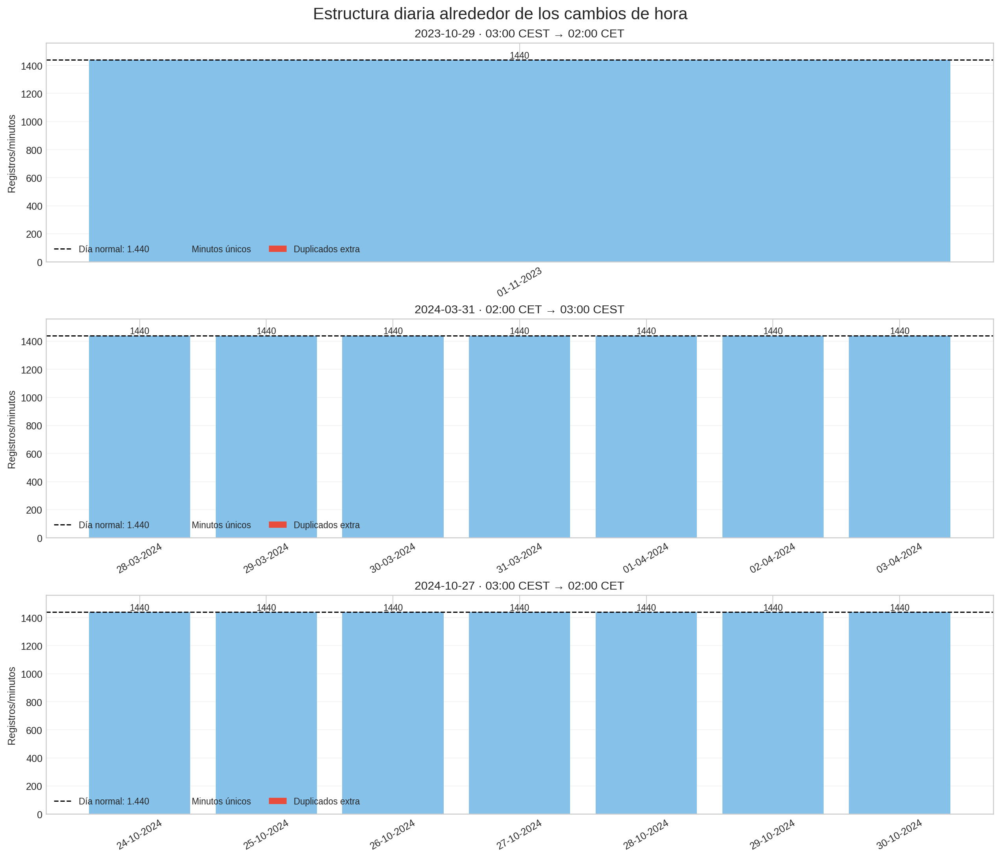

02_mapa_reloj_primavera_2024.png


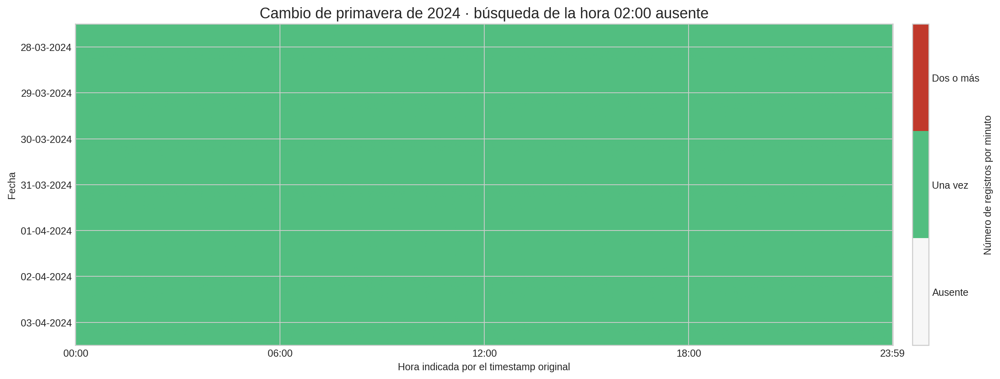

03_mapa_reloj_otono_2024.png


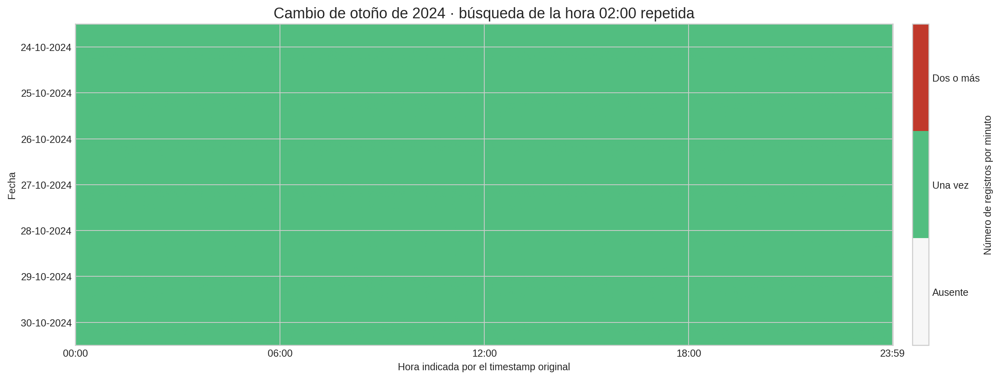

04_radiacion_vs_hipotesis_solar_primavera_2024.png


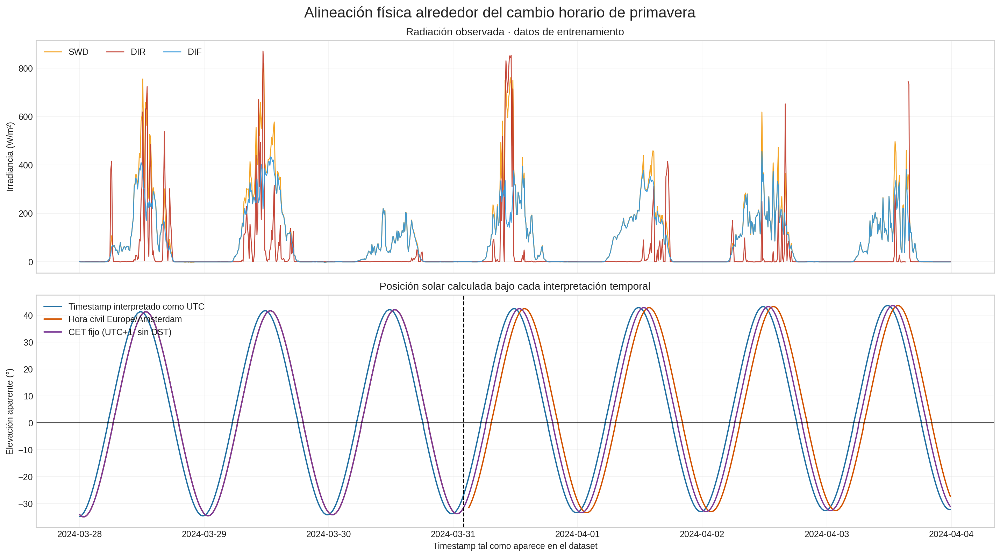

05_comparacion_hipotesis_temporales.png


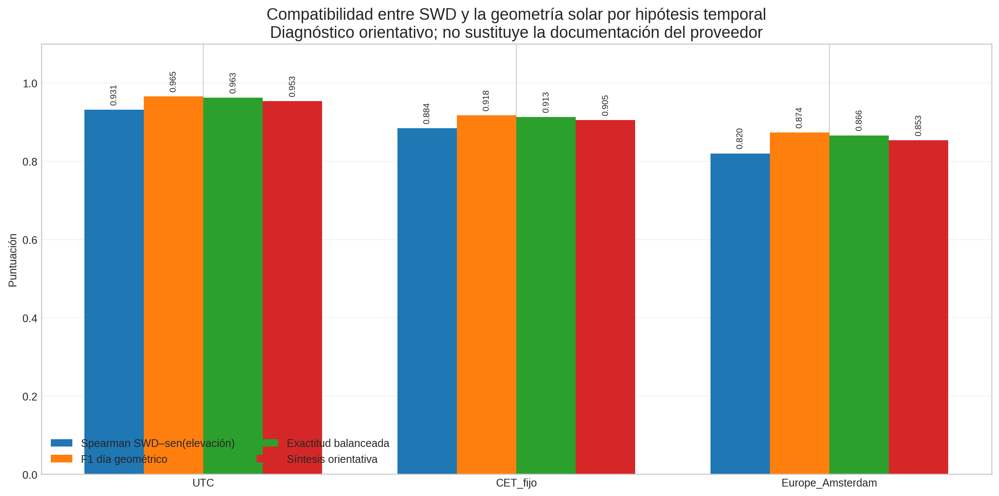


=== PROTECCIÓN DEL DATASET ===
Timestamps originales corregidos: 0
Filas eliminadas del dataset: 0
Valores imputados: 0
Radiación de validation/test usada para puntuar: NO

=== ZIP ===
Nombre: auditoria_zona_horaria_Cabauw_20261102T170047Z_54bcf8aa.zip
Tamaño: 1.83 MiB
SHA-256: f5a7638399ec0c4f218005b3f40920d111d6d5e388f2493d4ed8403a3675a90e
Integridad: CORRECTA


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
# Auditoría de la referencia horaria del dataset de Cabauw
import sys
import subprocess
import importlib.util

def instalar_si_falta(modulo, paquete):
    if importlib.util.find_spec(modulo) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])

instalar_si_falta("pvlib", "pvlib")
instalar_si_falta("pyarrow", "pyarrow")
import io
import json
import hashlib
import os
import platform
import re
import uuid
import zipfile
from datetime import datetime, timedelta, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
import pvlib
import pyarrow
try:
    from IPython.display import Image, display
except ImportError:
    class Image:
        def __init__(self, filename):
            self.filename = filename

        def __repr__(self):
            return f"Image({self.filename!r})"

    def display(value):
        print(value)

try:
    from google.colab import files
    EN_COLAB = True
except ImportError:
    files = None
    EN_COLAB = False


# 1. Contrato del análisis
LATITUD = 51.968
LONGITUD = 4.928
ALTITUD_M = 0.0
ZONA_CIVIL = "Europe/Amsterdam"

# Solo se usan valores radiométricos de entrenamiento para puntuar la alineación.
# Los timestamps de octubre de 2024 se inspeccionan únicamente de forma estructural.
INICIO_TRAIN = pd.Timestamp("2023-12-28 00:00:00")
FIN_TRAIN_EXCLUSIVO = pd.Timestamp("2024-08-01 00:00:00")
UMBRAL_SWD_DIA = 10.0
PASO_MUESTREO_GEOMETRIA_MIN = 5
TRANSICIONES = [
    {
        "codigo": "fin_verano_2023",
        "fecha": pd.Timestamp("2023-10-29"),
        "tipo": "atrasar",
        "descripcion": "03:00 CEST → 02:00 CET",
        "filas_locales_esperadas": 1500,
        "minutos_unicos_locales_esperados": 1440,
        "duplicados_locales_esperados": 60,
    },
    {
        "codigo": "inicio_verano_2024",
        "fecha": pd.Timestamp("2024-03-31"),
        "tipo": "adelantar",
        "descripcion": "02:00 CET → 03:00 CEST",
        "filas_locales_esperadas": 1380,
        "minutos_unicos_locales_esperados": 1380,
        "duplicados_locales_esperados": 0,
    },
    {
        "codigo": "fin_verano_2024",
        "fecha": pd.Timestamp("2024-10-27"),
        "tipo": "atrasar",
        "descripcion": "03:00 CEST → 02:00 CET",
        "filas_locales_esperadas": 1500,
        "minutos_unicos_locales_esperados": 1440,
        "duplicados_locales_esperados": 60,
    },
]
HIPOTESIS = [
    {
        "codigo": "UTC",
        "etiqueta": "Timestamp interpretado como UTC",
        "tz": "UTC",
        "color": "#2471a3",
    },
    {
        "codigo": "Europe_Amsterdam",
        "etiqueta": "Hora civil Europe/Amsterdam",
        "tz": ZONA_CIVIL,
        "color": "#d35400",
    },
    {
        "codigo": "CET_fijo",
        "etiqueta": "CET fijo (UTC+1, sin DST)",
        "tz": timezone(timedelta(hours=1)),
        "color": "#7d3c98",
    },
]
EXTENSIONES_ADMITIDAS = {".tab", ".tsv", ".csv", ".zip", ".parquet"}
CHECKPOINT_MINUTAL_1_1 = "checkpoints/01_datos_minutales_normalizados.parquet"


# 2. Funciones auxiliares de entrada y trazabilidad
def sha256_bytes(contenido):
    return hashlib.sha256(contenido).hexdigest()

def sha256_archivo(ruta, tamano_bloque=1024 * 1024):
    resumen = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        while True:
            bloque = archivo.read(tamano_bloque)
            if not bloque:
                break
            resumen.update(bloque)
    return resumen.hexdigest()

def guardar_csv(tabla, ruta):
    tabla.to_csv(ruta, index=False, encoding="utf-8-sig")

def obtener_entradas():
    """Devuelve una lista ordenada de (nombre, bytes)."""
    if EN_COLAB:
        print(
            "Selecciona los archivos originales de marzo, abril y octubre de 2024 "
            "(.tab/.csv), un ZIP que los contenga o el ZIP validado de la subsección 1.1."
        )
        subidos = files.upload()
        assert subidos, "No se ha seleccionado ningún archivo."
        return [(nombre, contenido) for nombre, contenido in subidos.items()]

    especificacion = os.environ.get("INPUT_TIME_AUDIT_FILES", "").strip()
    assert especificacion, (
        "Fuera de Colab define INPUT_TIME_AUDIT_FILES con una o varias rutas "
        f"separadas por {os.pathsep!r}."
    )
    rutas = []
    for elemento in especificacion.split(os.pathsep):
        ruta = Path(elemento).expanduser().resolve()
        if ruta.is_dir():
            rutas.extend(
                sorted(
                    archivo
                    for archivo in ruta.rglob("*")
                    if archivo.is_file() and archivo.suffix.lower() in EXTENSIONES_ADMITIDAS
                )
            )
        else:
            assert ruta.is_file(), f"No existe la entrada: {ruta}"
            assert (
                ruta.suffix.lower() in EXTENSIONES_ADMITIDAS
            ), f"Extensión no admitida: {ruta.name}"
            rutas.append(ruta)

    assert rutas, "No se encontraron archivos compatibles."
    return [(str(ruta), ruta.read_bytes()) for ruta in rutas]

def decodificar_texto(contenido):
    for codificacion in ("utf-8-sig", "utf-8", "latin-1"):
        try:
            return contenido.decode(codificacion), codificacion
        except UnicodeDecodeError:
            continue
    raise UnicodeDecodeError("desconocida", b"", 0, 1, "No se pudo decodificar")

def detectar_columna_timestamp(columnas):
    prioridades = {"datetime", "date/time", "date_time", "timestamp", "fecha_hora", "fechahora"}
    for columna in columnas:
        normalizada = str(columna).strip().lower()
        if normalizada in prioridades:
            return columna
    for columna in columnas:
        normalizada = re.sub(r"[^a-z0-9]", "", str(columna).lower())
        if normalizada in {"datetime", "timestamp", "fechahora"}:
            return columna
    return None

def leer_delimitado(contenido, nombre):
    texto, codificacion = decodificar_texto(contenido)
    lineas = texto.splitlines()
    candidatos = []
    for indice, linea in enumerate(lineas):
        if re.search(r"date\s*/?\s*time|datetime|timestamp|fecha.?hora", linea, re.I):
            conteos = {"\t": linea.count("\t"), ";": linea.count(";"), ",": linea.count(",")}
            delimitador = max(conteos, key=conteos.get)
            if conteos[delimitador] > 0:
                candidatos.append((conteos[delimitador], indice, delimitador))

    assert candidatos, f"No se encontró la cabecera temporal en {nombre}."
    _, indice_cabecera, delimitador = max(candidatos)
    cuerpo = "\n".join(lineas[indice_cabecera:])
    tabla = pd.read_csv(
        io.StringIO(cuerpo),
        sep=delimitador,
        engine="python",
        na_values=["", "NA", "NaN", "nan", "-999", "-999.0"],
        on_bad_lines="warn",
    )
    assert (
        detectar_columna_timestamp(tabla.columns) is not None
    ), f"La tabla leída desde {nombre} no contiene una columna temporal reconocible."
    tabla.attrs["codificacion"] = codificacion
    return tabla

def leer_parquet(contenido, nombre):
    try:
        tabla = pd.read_parquet(io.BytesIO(contenido))
    except Exception as error:
        raise RuntimeError(f"No se pudo leer el parquet {nombre}: {error}") from error
    assert (
        detectar_columna_timestamp(tabla.columns) is not None
    ), f"El parquet {nombre} no contiene una columna temporal reconocible."
    return tabla

def extraer_tablas(nombre_entrada, contenido):
    """Extrae solo tablas de datos; no interpreta tablas-resumen de ZIP previos."""
    sufijo = Path(nombre_entrada).suffix.lower()
    if sufijo == ".parquet":
        return [(nombre_entrada, leer_parquet(contenido, nombre_entrada))]
    if sufijo in {".tab", ".tsv", ".csv"}:
        return [(nombre_entrada, leer_delimitado(contenido, nombre_entrada))]

    assert sufijo == ".zip", f"Formato no soportado: {nombre_entrada}"
    assert zipfile.is_zipfile(io.BytesIO(contenido)), f"ZIP inválido: {nombre_entrada}"
    tablas = []
    with zipfile.ZipFile(io.BytesIO(contenido)) as archivo_zip:
        miembro_danado = archivo_zip.testzip()
        assert (
            miembro_danado is None
        ), f"Archivo dañado dentro de {nombre_entrada}: {miembro_danado}"
        miembros = [m for m in archivo_zip.namelist() if not m.endswith("/")]

        # Si es el ZIP validado 1.1, se usa exclusivamente su checkpoint minutal.
        if CHECKPOINT_MINUTAL_1_1 in miembros:
            datos = archivo_zip.read(CHECKPOINT_MINUTAL_1_1)
            etiqueta = f"{Path(nombre_entrada).name}::{CHECKPOINT_MINUTAL_1_1}"
            return [(etiqueta, leer_parquet(datos, etiqueta))]

        candidatos = [
            miembro
            for miembro in miembros
            if Path(miembro).suffix.lower() in {".tab", ".tsv", ".csv", ".parquet"}
        ]
        for miembro in sorted(candidatos):
            datos = archivo_zip.read(miembro)
            etiqueta = f"{Path(nombre_entrada).name}::{miembro}"
            try:
                if Path(miembro).suffix.lower() == ".parquet":
                    tabla = leer_parquet(datos, etiqueta)
                else:
                    tabla = leer_delimitado(datos, etiqueta)
            except (AssertionError, RuntimeError):
                # Un ZIP puede contener inventarios o tablas de resultados sin timestamps.
                continue
            tablas.append((etiqueta, tabla))

    assert tablas, f"No se encontraron tablas de datos con timestamps en {nombre_entrada}."
    return tablas

def convertir_timestamp(serie):
    texto = serie.astype("string").str.strip()
    tiene_offset = texto.str.contains(r"(?:Z|[+-]\d{2}:?\d{2})$", regex=True, na=False)
    offset_explicito = bool(tiene_offset.any())
    try:
        if offset_explicito:
            convertido = pd.to_datetime(texto, errors="coerce", format="mixed", utc=True)
            ingenuo = convertido.dt.tz_convert("UTC").dt.tz_localize(None)
        else:
            convertido = pd.to_datetime(texto, errors="coerce", format="mixed")
            if getattr(convertido.dt, "tz", None) is not None:
                offset_explicito = True
                ingenuo = convertido.dt.tz_convert("UTC").dt.tz_localize(None)
            else:
                ingenuo = convertido
    except (TypeError, ValueError):
        if offset_explicito:
            convertido = pd.to_datetime(texto, errors="coerce", utc=True)
            ingenuo = convertido.dt.tz_convert("UTC").dt.tz_localize(None)
        else:
            ingenuo = pd.to_datetime(texto, errors="coerce")

    return ingenuo, offset_explicito

def encontrar_variable_principal(columnas, familia):
    exactas = {
        "SWD": ["SWD [W/m**2]", "SWD [W/m²]", "SWD"],
        "DIR": ["DIR [W/m**2]", "DIR [W/m²]", "DIR"],
        "DIF": ["DIF [W/m**2]", "DIF [W/m²]", "DIF"],
    }
    for candidata in exactas[familia]:
        if candidata in columnas:
            return candidata

    excluidas = ("std", "dev", "min", "max", "dispon", "count", "n_")
    for columna in columnas:
        normalizada = str(columna).strip().lower()
        if normalizada.startswith(familia.lower()) and not any(x in normalizada for x in excluidas):
            return columna
    return None


# 3. Carga de los datos sin alterar timestamps ni duplicados
entradas = obtener_entradas()
inventario_entrada = []
tablas_cargadas = []
for nombre_entrada, contenido in entradas:
    inventario_entrada.append(
        {
            "archivo": Path(nombre_entrada).name,
            "tamano_bytes": len(contenido),
            "sha256": sha256_bytes(contenido),
        }
    )
    for origen_tabla, tabla in extraer_tablas(nombre_entrada, contenido):
        tabla = tabla.copy()
        columna_timestamp = detectar_columna_timestamp(tabla.columns)
        tabla["__timestamp_original"] = tabla[columna_timestamp].astype("string")
        timestamp_ingenuo, offset_explicito = convertir_timestamp(tabla[columna_timestamp])
        tabla["__timestamp_naive"] = timestamp_ingenuo
        tabla["__offset_explicito"] = offset_explicito
        tabla["__origen_tabla"] = origen_tabla
        tablas_cargadas.append(tabla)

assert tablas_cargadas, "No se pudo cargar ninguna tabla."
columnas_salida = [
    "__timestamp_original",
    "__timestamp_naive",
    "__offset_explicito",
    "__origen_tabla",
]
fragmentos = []
columnas_detectadas = []
for tabla in tablas_cargadas:
    fragmento = tabla[columnas_salida].copy()
    for familia in ("SWD", "DIR", "DIF"):
        columna = encontrar_variable_principal(tabla.columns, familia)
        if columna is not None:
            fragmento[familia] = pd.to_numeric(tabla[columna], errors="coerce")
            columnas_detectadas.append(
                {
                    "origen_tabla": str(tabla["__origen_tabla"].iloc[0]),
                    "familia": familia,
                    "columna_detectada": str(columna),
                }
            )
        else:
            fragmento[familia] = np.nan
    fragmentos.append(fragmento)

datos = pd.concat(fragmentos, ignore_index=True, sort=False)
n_timestamps_invalidos = int(datos["__timestamp_naive"].isna().sum())
datos_validos = datos.loc[datos["__timestamp_naive"].notna()].copy()
assert not datos_validos.empty, "Todos los timestamps son inválidos."
datos_validos["timestamp"] = pd.to_datetime(datos_validos["__timestamp_naive"])
datos_validos["timestamp_minuto"] = datos_validos["timestamp"].dt.floor("min")
datos_validos["fecha"] = datos_validos["timestamp_minuto"].dt.floor("D")
datos_validos = datos_validos.sort_values(
    ["timestamp_minuto", "__origen_tabla"], kind="mergesort"
).reset_index(drop=True)
assert datos_validos["timestamp_minuto"].dt.second.eq(0).all()
assert datos_validos["timestamp_minuto"].dt.microsecond.eq(0).all()
assert (
    datos_validos["SWD"].notna().any()
), "No se encontró la variable principal SWD, necesaria para contrastar la geometría."
offset_explicito_detectado = bool(datos_validos["__offset_explicito"].any())


# 4. Auditoría estructural del reloj
resumen_diario = datos_validos.groupby("fecha", as_index=False).agg(
    n_filas=("timestamp_minuto", "size"),
    n_minutos_unicos=("timestamp_minuto", "nunique"),
    n_archivos_origen=("__origen_tabla", "nunique"),
)
resumen_diario["n_duplicados_extra"] = (
    resumen_diario["n_filas"] - resumen_diario["n_minutos_unicos"]
)
resumen_diario["n_minutos_ausentes_rejilla_1440"] = np.maximum(
    1440 - resumen_diario["n_minutos_unicos"], 0
)
resumen_diario["rejilla_civil_normal_1440"] = (
    resumen_diario["n_filas"].eq(1440)
    & resumen_diario["n_minutos_unicos"].eq(1440)
    & resumen_diario["n_duplicados_extra"].eq(0)
)
filas_transiciones = []
for transicion in TRANSICIONES:
    fecha = transicion["fecha"]
    mascara_fecha = datos_validos["fecha"].eq(fecha)
    fila_dia = resumen_diario.loc[resumen_diario["fecha"].eq(fecha)]
    presente = not fila_dia.empty
    if presente:
        fila = fila_dia.iloc[0]
        n_filas = int(fila["n_filas"])
        n_unicos = int(fila["n_minutos_unicos"])
        n_duplicados = int(fila["n_duplicados_extra"])
        horas_02 = datos_validos.loc[mascara_fecha, "timestamp_minuto"].dt.hour.eq(2)
        n_filas_hora_02 = int(horas_02.sum())
        n_minutos_unicos_hora_02 = int(
            datos_validos.loc[
                mascara_fecha & datos_validos["timestamp_minuto"].dt.hour.eq(2), "timestamp_minuto"
            ].nunique()
        )
        coincide_firma_local = (
            n_filas == transicion["filas_locales_esperadas"]
            and n_unicos == transicion["minutos_unicos_locales_esperados"]
            and n_duplicados == transicion["duplicados_locales_esperados"]
        )
        dia_continuo_1440 = n_filas == 1440 and n_unicos == 1440 and n_duplicados == 0
    else:
        n_filas = n_unicos = n_duplicados = 0
        n_filas_hora_02 = n_minutos_unicos_hora_02 = 0
        coincide_firma_local = False
        dia_continuo_1440 = False

    filas_transiciones.append(
        {
            "codigo": transicion["codigo"],
            "fecha": fecha,
            "cambio_civil": transicion["descripcion"],
            "presente_en_datos": presente,
            "n_filas": n_filas,
            "n_minutos_unicos": n_unicos,
            "n_duplicados_extra": n_duplicados,
            "n_filas_hora_02": n_filas_hora_02,
            "n_minutos_unicos_hora_02": n_minutos_unicos_hora_02,
            "firma_hora_civil_con_DST": coincide_firma_local,
            "dia_continuo_1440": dia_continuo_1440,
        }
    )

auditoria_transiciones = pd.DataFrame(filas_transiciones)


# 5. Posición solar bajo tres hipótesis temporales
def calcular_elevacion_aparente(timestamps_naive, zona):
    indice = pd.DatetimeIndex(pd.to_datetime(timestamps_naive))
    if isinstance(zona, str):
        if zona == "UTC":
            localizado = indice.tz_localize("UTC")
        else:
            localizado = indice.tz_localize(zona, ambiguous="NaT", nonexistent="NaT")
    else:
        localizado = indice.tz_localize(zona)

    valido = ~pd.isna(localizado)
    elevacion = np.full(len(indice), np.nan, dtype=float)
    if valido.any():
        posicion = pvlib.solarposition.get_solarposition(
            time=localizado[valido],
            latitude=LATITUD,
            longitude=LONGITUD,
            altitude=ALTITUD_M,
            method="nrel_numpy",
        )
        elevacion[valido] = posicion["apparent_elevation"].to_numpy(dtype=float)
    return elevacion


# Se agrupan duplicados únicamente en una copia para calcular puntuaciones.
# La auditoría estructural anterior conserva todos los registros originales.
columnas_radiacion = [col for col in ["SWD", "DIR", "DIF"] if datos_validos[col].notna().any()]
datos_geometria = (
    datos_validos.loc[
        datos_validos["timestamp_minuto"].ge(INICIO_TRAIN)
        & datos_validos["timestamp_minuto"].lt(FIN_TRAIN_EXCLUSIVO),
        ["timestamp_minuto", *columnas_radiacion],
    ]
    .groupby("timestamp_minuto", as_index=False)[columnas_radiacion]
    .median()
    .sort_values("timestamp_minuto")
    .reset_index(drop=True)
)
assert not datos_geometria.empty, "No hay datos de entrenamiento para contrastar la geometría."

# Muestreo regular de 5 minutos para acelerar pvlib sin alterar el diagnóstico horario.
minuto_del_dia = (
    datos_geometria["timestamp_minuto"].dt.hour * 60 + datos_geometria["timestamp_minuto"].dt.minute
)
mascara_muestreo = minuto_del_dia.mod(PASO_MUESTREO_GEOMETRIA_MIN).eq(0)
muestra_geometria = datos_geometria.loc[mascara_muestreo].reset_index(drop=True)
filas_puntuacion = []
elevaciones_muestra = {}
for hipotesis in HIPOTESIS:
    elevacion = calcular_elevacion_aparente(muestra_geometria["timestamp_minuto"], hipotesis["tz"])
    elevaciones_muestra[hipotesis["codigo"]] = elevacion
    swd = muestra_geometria["SWD"].to_numpy(dtype=float)
    valido = np.isfinite(swd) & np.isfinite(elevacion)
    observado_dia = swd > UMBRAL_SWD_DIA
    geometria_dia = elevacion > 0
    tp = int(np.sum(valido & observado_dia & geometria_dia))
    tn = int(np.sum(valido & ~observado_dia & ~geometria_dia))
    fp = int(np.sum(valido & ~observado_dia & geometria_dia))
    fn = int(np.sum(valido & observado_dia & ~geometria_dia))
    sensibilidad = tp / (tp + fn) if (tp + fn) else np.nan
    especificidad = tn / (tn + fp) if (tn + fp) else np.nan
    precision = tp / (tp + fp) if (tp + fp) else np.nan
    f1_dia = (
        2 * precision * sensibilidad / (precision + sensibilidad)
        if np.isfinite(precision + sensibilidad) and (precision + sensibilidad) > 0
        else np.nan
    )
    exactitud_balanceada = np.nanmean([sensibilidad, especificidad])
    seno_altura = np.sin(np.radians(np.clip(elevacion, 0, None)))
    rho_spearman = pd.Series(swd[valido]).corr(pd.Series(seno_altura[valido]), method="spearman")
    puntuacion_orientativa = np.nanmean(
        [f1_dia, exactitud_balanceada, max(float(rho_spearman), 0.0)]
    )
    filas_puntuacion.append(
        {
            "hipotesis": hipotesis["codigo"],
            "descripcion": hipotesis["etiqueta"],
            "n_evaluables": int(valido.sum()),
            "rho_spearman_SWD_seno_elevacion": float(rho_spearman),
            "sensibilidad_dia": float(sensibilidad),
            "especificidad_noche": float(especificidad),
            "f1_dia": float(f1_dia),
            "exactitud_balanceada": float(exactitud_balanceada),
            "puntuacion_orientativa": float(puntuacion_orientativa),
            "falsos_dia_geometrico": fp,
            "falsas_noches_geometricas": fn,
        }
    )

puntuaciones = (
    pd.DataFrame(filas_puntuacion)
    .sort_values("puntuacion_orientativa", ascending=False)
    .reset_index(drop=True)
)
mejor_hipotesis = str(puntuaciones.iloc[0]["hipotesis"])
mejor_puntuacion = float(puntuaciones.iloc[0]["puntuacion_orientativa"])
margen_geometria = (
    mejor_puntuacion - float(puntuaciones.iloc[1]["puntuacion_orientativa"])
    if len(puntuaciones) > 1
    else np.nan
)
n_firmas_locales = int(auditoria_transiciones["firma_hora_civil_con_DST"].sum())
transiciones_presentes = auditoria_transiciones.loc[auditoria_transiciones["presente_en_datos"]]
n_dias_continuos = int(transiciones_presentes["dia_continuo_1440"].sum())
if offset_explicito_detectado:
    conclusion = (
        "Los timestamps contienen algún offset explícito. Debe conservarse ese offset y "
        "revisarse la mezcla de formatos antes de asignar una zona única."
    )
    nivel_evidencia = "REVISAR_OFFSETS_EXPLICITOS"
elif n_firmas_locales >= 2:
    conclusion = (
        "La estructura presenta las firmas de adelanto y retraso de Europe/Amsterdam; "
        "la hipótesis de hora civil con DST es la principal candidata."
    )
    nivel_evidencia = "FUERTE_HORA_CIVIL_DST"
elif n_firmas_locales == 1:
    conclusion = (
        "Una transición presenta firma de hora civil con DST. La evidencia es compatible "
        "con Europe/Amsterdam, pero conviene confirmar la segunda transición."
    )
    nivel_evidencia = "MODERADA_HORA_CIVIL_DST"
elif n_dias_continuos >= 1 and np.isfinite(margen_geometria) and margen_geometria >= 0.01:
    conclusion = (
        "Las transiciones disponibles conservan una rejilla continua de 1.440 minutos, "
        f"sin firma de hora civil. La alineación solar favorece {mejor_hipotesis}; "
        "debe contrastarse con la documentación del proveedor."
    )
    nivel_evidencia = "ORIENTATIVA_REJILLA_CONTINUA"
else:
    conclusion = (
        "La evidencia disponible no permite diferenciar con suficiente claridad UTC, "
        "hora civil de Ámsterdam y CET fijo."
    )
    nivel_evidencia = "NO_CONCLUYENTE"

decision = pd.DataFrame(
    [
        {
            "nivel_evidencia": nivel_evidencia,
            "mejor_hipotesis_geometrica": mejor_hipotesis,
            "puntuacion_mejor": mejor_puntuacion,
            "margen_frente_segunda": margen_geometria,
            "n_firmas_hora_civil_DST": n_firmas_locales,
            "n_transiciones_presentes": int(len(transiciones_presentes)),
            "n_transiciones_continuas_1440": n_dias_continuos,
            "conclusion": conclusion,
        }
    ]
)


# 6. Salida versionada
id_ejecucion = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8]
if EN_COLAB:
    base_salida = Path("/content/auditoria_zona_horaria_cabauw")
else:
    base_salida = Path(os.environ.get("OUTPUT_BASE_4_1_1", "./resultados_4_1_1"))

carpeta_ejecucion = base_salida / f"F4_S1_1_{id_ejecucion}"
carpeta_figuras = carpeta_ejecucion / "figuras"
carpeta_tablas = carpeta_ejecucion / "tablas"
carpeta_configuracion = carpeta_ejecucion / "configuracion"
carpeta_ejecucion.mkdir(parents=True, exist_ok=False)
carpeta_figuras.mkdir()
carpeta_tablas.mkdir()
carpeta_configuracion.mkdir()


# 7. Figuras
def ventana_diaria(fecha, dias_antes=3, dias_despues=3):
    return resumen_diario.loc[
        resumen_diario["fecha"].between(
            fecha - pd.Timedelta(days=dias_antes), fecha + pd.Timedelta(days=dias_despues)
        )
    ].copy()


# Figura 1: conteos diarios alrededor de las tres fechas oficiales.
figura, ejes = plt.subplots(3, 1, figsize=(14, 12), constrained_layout=True)
for eje, transicion in zip(ejes, TRANSICIONES):
    subconjunto = ventana_diaria(transicion["fecha"])
    if subconjunto.empty:
        eje.text(
            0.5, 0.5, "Periodo no disponible en los archivos cargados", ha="center", va="center"
        )
        eje.set_axis_off()
        eje.set_title(f"{transicion['codigo']} · {transicion['fecha'].date()}")
        continue
    posiciones = np.arange(len(subconjunto))
    eje.bar(posiciones, subconjunto["n_minutos_unicos"], color="#85c1e9", label="Minutos únicos")
    eje.bar(
        posiciones,
        subconjunto["n_duplicados_extra"],
        bottom=subconjunto["n_minutos_unicos"],
        color="#e74c3c",
        label="Duplicados extra",
    )
    eje.axhline(1440, color="black", linestyle="--", linewidth=1.2, label="Día normal: 1.440")
    for posicion, fila in enumerate(subconjunto.itertuples(index=False)):
        eje.text(posicion, fila.n_filas + 12, str(int(fila.n_filas)), ha="center", fontsize=9)
    eje.set_xticks(posiciones)
    eje.set_xticklabels([fecha.strftime("%d-%m-%Y") for fecha in subconjunto["fecha"]], rotation=30)
    eje.set_ylim(0, max(1560, int(subconjunto["n_filas"].max()) + 100))
    eje.set_ylabel("Registros/minutos")
    eje.set_title(f"{transicion['fecha'].date()} · {transicion['descripcion']}")
    eje.grid(axis="y", alpha=0.2)
    eje.legend(loc="lower left", ncols=3, fontsize=9)
figura.suptitle("Estructura diaria alrededor de los cambios de hora", fontsize=17)
ruta_figura_1 = carpeta_figuras / "01_conteo_minutos_transiciones.png"
figura.savefig(ruta_figura_1, dpi=180, bbox_inches="tight")
plt.close(figura)

def figura_mapa_reloj(fecha_cambio, titulo, nombre_archivo):
    fechas = pd.date_range(
        fecha_cambio - pd.Timedelta(days=3), fecha_cambio + pd.Timedelta(days=3), freq="D"
    )
    matriz = np.zeros((len(fechas), 1440), dtype=np.int16)
    for indice, fecha in enumerate(fechas):
        subconjunto = datos_validos.loc[datos_validos["fecha"].eq(fecha), "timestamp_minuto"]
        if subconjunto.empty:
            continue
        minutos = (subconjunto.dt.hour * 60 + subconjunto.dt.minute).to_numpy(dtype=int)
        conteos = np.bincount(minutos, minlength=1440)
        matriz[indice] = np.clip(conteos[:1440], 0, 2)

    mapa = ListedColormap(["#f7f7f7", "#52be80", "#c0392b"])
    norma = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], mapa.N)
    figura, eje = plt.subplots(figsize=(15, 5.4))
    imagen = eje.imshow(matriz, aspect="auto", cmap=mapa, norm=norma)
    eje.set_xticks([0, 360, 720, 1080, 1439])
    eje.set_xticklabels(["00:00", "06:00", "12:00", "18:00", "23:59"])
    eje.set_yticks(np.arange(len(fechas)))
    eje.set_yticklabels([fecha.strftime("%d-%m-%Y") for fecha in fechas])
    eje.set_xlabel("Hora indicada por el timestamp original")
    eje.set_ylabel("Fecha")
    eje.set_title(titulo, fontsize=15)
    barra = figura.colorbar(imagen, ax=eje, ticks=[0, 1, 2], pad=0.02)
    barra.ax.set_yticklabels(["Ausente", "Una vez", "Dos o más"])
    barra.set_label("Número de registros por minuto")
    figura.tight_layout()
    ruta = carpeta_figuras / nombre_archivo
    figura.savefig(ruta, dpi=180, bbox_inches="tight")
    plt.close(figura)
    return ruta

ruta_figura_2 = figura_mapa_reloj(
    pd.Timestamp("2024-03-31"),
    "Cambio de primavera de 2024 · búsqueda de la hora 02:00 ausente",
    "02_mapa_reloj_primavera_2024.png",
)
ruta_figura_3 = figura_mapa_reloj(
    pd.Timestamp("2024-10-27"),
    "Cambio de otoño de 2024 · búsqueda de la hora 02:00 repetida",
    "03_mapa_reloj_otono_2024.png",
)


# Figura 4: radiación y geometría durante el cambio de primavera (dentro de train).
inicio_grafico = pd.Timestamp("2024-03-28 00:00:00")
fin_grafico = pd.Timestamp("2024-04-04 00:00:00")
datos_grafico = datos_geometria.loc[
    datos_geometria["timestamp_minuto"].ge(inicio_grafico)
    & datos_geometria["timestamp_minuto"].lt(fin_grafico)
].copy()
if not datos_grafico.empty:
    datos_grafico = (
        datos_grafico.set_index("timestamp_minuto")[columnas_radiacion]
        .resample("10min")
        .median()
        .reset_index()
    )
    figura, (eje_rad, eje_sol) = plt.subplots(2, 1, figsize=(16, 9), sharex=True)
    colores_rad = {"SWD": "#f39c12", "DIR": "#c0392b", "DIF": "#3498db"}
    for variable in columnas_radiacion:
        eje_rad.plot(
            datos_grafico["timestamp_minuto"],
            datos_grafico[variable],
            label=variable,
            color=colores_rad[variable],
            linewidth=1.1,
            alpha=0.9,
        )
    eje_rad.set_ylabel("Irradiancia (W/m²)")
    eje_rad.set_title("Radiación observada · datos de entrenamiento")
    eje_rad.legend(loc="upper left", ncols=len(columnas_radiacion))
    eje_rad.grid(alpha=0.2)
    for hipotesis in HIPOTESIS:
        elevacion = calcular_elevacion_aparente(datos_grafico["timestamp_minuto"], hipotesis["tz"])
        eje_sol.plot(
            datos_grafico["timestamp_minuto"],
            elevacion,
            label=hipotesis["etiqueta"],
            color=hipotesis["color"],
            linewidth=1.5,
        )
    eje_sol.axhline(0, color="black", linewidth=0.9)
    eje_sol.axvline(
        pd.Timestamp("2024-03-31 02:00:00"), color="black", linestyle="--", linewidth=1.2
    )
    eje_sol.set_ylabel("Elevación aparente (°)")
    eje_sol.set_xlabel("Timestamp tal como aparece en el dataset")
    eje_sol.set_title("Posición solar calculada bajo cada interpretación temporal")
    eje_sol.legend(loc="upper left")
    eje_sol.grid(alpha=0.2)
    figura.suptitle("Alineación física alrededor del cambio horario de primavera", fontsize=17)
    figura.tight_layout()
else:
    figura, eje_sol = plt.subplots(figsize=(12, 4))
    eje_sol.text(
        0.5, 0.5, "No hay datos entre el 28-03-2024 y el 03-04-2024", ha="center", va="center"
    )
    eje_sol.set_axis_off()
    figura.tight_layout()

ruta_figura_4 = carpeta_figuras / "04_radiacion_vs_hipotesis_solar_primavera_2024.png"
figura.savefig(ruta_figura_4, dpi=180, bbox_inches="tight")
plt.close(figura)


# Figura 5: comparación cuantitativa, siempre presentada como diagnóstico orientativo.
metricas_grafico = [
    ("rho_spearman_SWD_seno_elevacion", "Spearman SWD–sen(elevación)"),
    ("f1_dia", "F1 día geométrico"),
    ("exactitud_balanceada", "Exactitud balanceada"),
    ("puntuacion_orientativa", "Síntesis orientativa"),
]
figura, eje = plt.subplots(figsize=(13, 6.5))
posiciones = np.arange(len(puntuaciones))
ancho = 0.19
for indice, (columna, etiqueta) in enumerate(metricas_grafico):
    desplazamiento = (indice - (len(metricas_grafico) - 1) / 2) * ancho
    barras = eje.bar(
        posiciones + desplazamiento, puntuaciones[columna], width=ancho, label=etiqueta
    )
    for barra, valor in zip(barras, puntuaciones[columna]):
        eje.text(
            barra.get_x() + barra.get_width() / 2,
            barra.get_height() + 0.012,
            f"{valor:.3f}",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=90,
        )
eje.set_xticks(posiciones)
eje.set_xticklabels(puntuaciones["hipotesis"])
eje.set_ylim(0, 1.10)
eje.set_ylabel("Puntuación")
eje.set_title(
    "Compatibilidad entre SWD y la geometría solar por hipótesis temporal\n"
    "Diagnóstico orientativo; no sustituye la documentación del proveedor",
    fontsize=15,
)
eje.grid(axis="y", alpha=0.25)
eje.legend(loc="lower left", ncols=2)
figura.tight_layout()
ruta_figura_5 = carpeta_figuras / "05_comparacion_hipotesis_temporales.png"
figura.savefig(ruta_figura_5, dpi=180, bbox_inches="tight")
plt.close(figura)
rutas_figuras = [ruta_figura_1, ruta_figura_2, ruta_figura_3, ruta_figura_4, ruta_figura_5]


# 8. Tablas, configuración, README e inventario
guardar_csv(pd.DataFrame(inventario_entrada), carpeta_tablas / "01_inventario_entradas.csv")
guardar_csv(
    pd.DataFrame(columnas_detectadas).drop_duplicates(),
    carpeta_tablas / "02_columnas_detectadas.csv",
)
guardar_csv(resumen_diario, carpeta_tablas / "03_auditoria_rejilla_diaria.csv")
guardar_csv(auditoria_transiciones, carpeta_tablas / "04_auditoria_transiciones_DST.csv")
guardar_csv(puntuaciones, carpeta_tablas / "05_puntuaciones_hipotesis_temporales.csv")
guardar_csv(decision, carpeta_tablas / "06_conclusion_zona_horaria.csv")
configuracion = {
    "fase": 4,
    "subseccion": "4.1.1",
    "id_ejecucion": id_ejecucion,
    "fecha_utc": datetime.now(timezone.utc).isoformat(),
    "estacion": {
        "nombre": "Cabauw",
        "codigo_bsrn": "CAB",
        "latitud": LATITUD,
        "longitud": LONGITUD,
        "altitud_m": ALTITUD_M,
        "zona_civil_candidata": ZONA_CIVIL,
        "altura_instrumento_m_no_usada_como_altitud": 2,
    },
    "alcance": {
        "timestamps_inspeccionados": "todos los aportados",
        "valores_para_alineacion_solar": "solo train",
        "inicio_train": str(INICIO_TRAIN),
        "fin_train_exclusivo": str(FIN_TRAIN_EXCLUSIVO),
        "validation_y_test_usados_para_modelado": False,
        "filas_eliminadas_del_dataset": 0,
        "valores_imputados": 0,
        "timestamps_corregidos": 0,
    },
    "hipotesis": [hipotesis["codigo"] for hipotesis in HIPOTESIS],
    "transiciones_oficiales": [
        {
            "codigo": transicion["codigo"],
            "fecha": str(transicion["fecha"].date()),
            "descripcion": transicion["descripcion"],
        }
        for transicion in TRANSICIONES
    ],
    "resultado": decision.iloc[0].to_dict(),
    "entorno": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "matplotlib": matplotlib.__version__,
        "pvlib": pvlib.__version__,
        "pyarrow": pyarrow.__version__,
        "colab": EN_COLAB,
    },
}
with (carpeta_configuracion / "configuracion_4_1_1.json").open("w", encoding="utf-8") as archivo:
    json.dump(configuracion, archivo, ensure_ascii=False, indent=2, default=str)

readme = f"""# Fase 4 · Subsección 4.1.1

Auditoría de la referencia horaria del dataset minutal de Cabauw.

Se comparan tres interpretaciones del timestamp: UTC, hora civil
Europe/Amsterdam y CET fijo. La evidencia combina la estructura de la rejilla
en los cambios horarios oficiales y la alineación de SWD con la elevación solar.

Resultado de esta ejecución:

- nivel de evidencia: {nivel_evidencia};
- mejor hipótesis geométrica: {mejor_hipotesis};
- margen orientativo: {margen_geometria:.4f};
- conclusión: {conclusion}

Los timestamps originales no se corrigen y no se eliminan ni imputan valores.
Los datos radiométricos de validation y test no se utilizan para puntuar las
hipótesis; octubre de 2024 se inspecciona solo como estructura temporal.
"""
(carpeta_ejecucion / "README.md").write_text(readme, encoding="utf-8")
filas_inventario = []
for ruta in sorted(archivo for archivo in carpeta_ejecucion.rglob("*") if archivo.is_file()):
    filas_inventario.append(
        {
            "ruta_relativa": ruta.relative_to(carpeta_ejecucion).as_posix(),
            "tamano_bytes": ruta.stat().st_size,
            "sha256": sha256_archivo(ruta),
        }
    )
guardar_csv(pd.DataFrame(filas_inventario), carpeta_ejecucion / "inventario_archivos.csv")
ruta_zip = base_salida / f"auditoria_zona_horaria_Cabauw_{id_ejecucion}.zip"
with zipfile.ZipFile(ruta_zip, "w", compression=zipfile.ZIP_DEFLATED) as archivo_zip:
    for ruta in sorted(archivo for archivo in carpeta_ejecucion.rglob("*") if archivo.is_file()):
        archivo_zip.write(ruta, arcname=ruta.relative_to(carpeta_ejecucion).as_posix())

with zipfile.ZipFile(ruta_zip) as archivo_zip:
    assert archivo_zip.testzip() is None


# 9. Salida visible
print("\n=== AUDITORÍA DE ZONA HORARIA · CABAUW ===")
print(
    f"Rango temporal cargado: {datos_validos['timestamp'].min()} → {datos_validos['timestamp'].max()}"
)
print(f"Registros con timestamp válido: {len(datos_validos):,}")
print(f"Timestamps inválidos excluidos del diagnóstico: {n_timestamps_invalidos:,}")
print(f"Offsets explícitos detectados: {'SÍ' if offset_explicito_detectado else 'NO'}")
print("\n=== TRANSICIONES ===")
print(auditoria_transiciones.to_string(index=False))
print("\n=== HIPÓTESIS TEMPORALES ===")
print(
    puntuaciones[
        [
            "hipotesis",
            "rho_spearman_SWD_seno_elevacion",
            "f1_dia",
            "exactitud_balanceada",
            "puntuacion_orientativa",
        ]
    ].to_string(index=False)
)
print("\n=== CONCLUSIÓN AUTOMÁTICA CAUTELOSA ===")
print(conclusion)
print("La decisión final debe contrastarse con la documentación de BSRN/PANGAEA.")
print("\n=== FIGURAS ===")
for ruta_figura in rutas_figuras:
    print(ruta_figura.name)
    display(Image(filename=str(ruta_figura)))

print("\n=== PROTECCIÓN DEL DATASET ===")
print("Timestamps originales corregidos: 0")
print("Filas eliminadas del dataset: 0")
print("Valores imputados: 0")
print("Radiación de validation/test usada para puntuar: NO")
print("\n=== ZIP ===")
print(f"Nombre: {ruta_zip.name}")
print(f"Tamaño: {ruta_zip.stat().st_size / (1024 ** 2):.2f} MiB")
print(f"SHA-256: {sha256_archivo(ruta_zip)}")
print("Integridad: CORRECTA")
if EN_COLAB:
    files.download(str(ruta_zip))

### 4.1.2 Cálculo de la posición solar

Una vez establecido en la subsección 4.1.1 que los timestamps se interpretan como UTC, se incorporan variables deterministas que describen la posición del Sol en cada instante de observación. Para Cabauw (latitud 51,968°, longitud 4,928°, altitud 0 m) se calculan con pvlib la elevación solar geométrica y aparente, el ángulo cenital, el azimut y un indicador de día geométrico, definido por una elevación geométrica estrictamente positiva y, por tanto, independiente de la nubosidad o de los fallos de medida. Estas variables se calculan en todas las particiones, porque son conocidas en el momento de la predicción, pero los resúmenes y gráficos se limitan a entrenamiento, y en su construcción no interviene ninguna irradiancia.

Selecciona exclusivamente el ZIP validado de la subsección 2.6 o el checkpoint horario parquet equivalente.


Saving EDA_multivariante_F2_S2_6_20261102T165730Z_3fe4c1f3.zip to EDA_multivariante_F2_S2_6_20261102T165730Z_3fe4c1f3 (1).zip


/tmp/ipykernel_646/4077788680.py:190: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["mes_utc"] = df["timestamp_utc"].dt.to_period("M").astype(str)


=== RESUMEN TÉCNICO 4.1.2 ===
Checkpoint de entrada: checkpoints/09a_tabla_horaria_particionada_sin_cambios.parquet
Horas analizadas: 9,504
Timestamp UTC: 2023-11-01 00:00:00+00:00 → 2024-11-30 23:00:00+00:00
Filas eliminadas: 0
Valores imputados: 0
Valores radiométricos usados en el cálculo: NO



,particion_observacion,n_horas,inicio_utc,fin_utc,horas_dia_geometrico,elevacion_max_deg,elevacion_min_deg,pct_horas_dia_geometrico
0,pre_segmento,1368,2023-11-01 00:00:00+00:00,2023-12-27 23:00:00+00:00,471,23.409557,-61.187127,34.429825
1,test,1464,2024-10-01 00:00:00+00:00,2024-11-30 23:00:00+00:00,577,34.197491,-59.340680,39.412568
2,train,5208,2023-12-28 00:00:00+00:00,2024-07-31 23:00:00+00:00,2802,61.264174,-61.116166,53.801843
3,validation,1464,2024-08-01 00:00:00+00:00,2024-09-30 23:00:00+00:00,819,55.742589,-40.913697,55.942623


=== FIGURAS ===
01_trayectoria_solar_semana_representativa_train.png


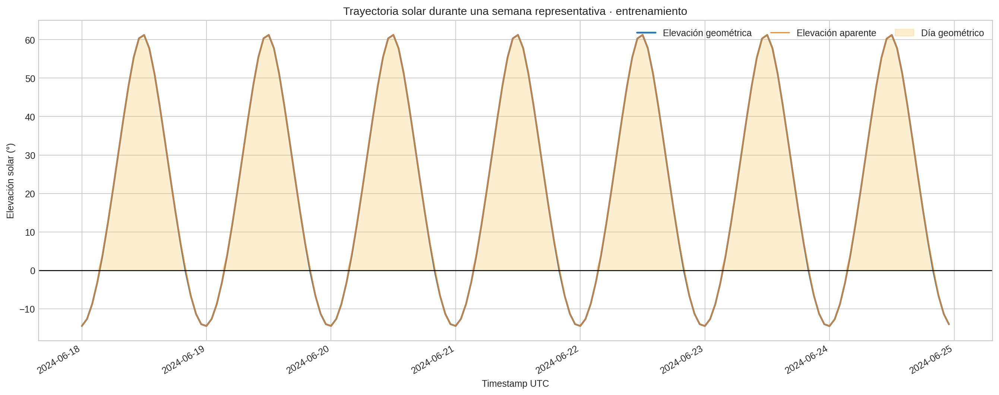

02_recorrido_solar_azimut_elevacion_train.png


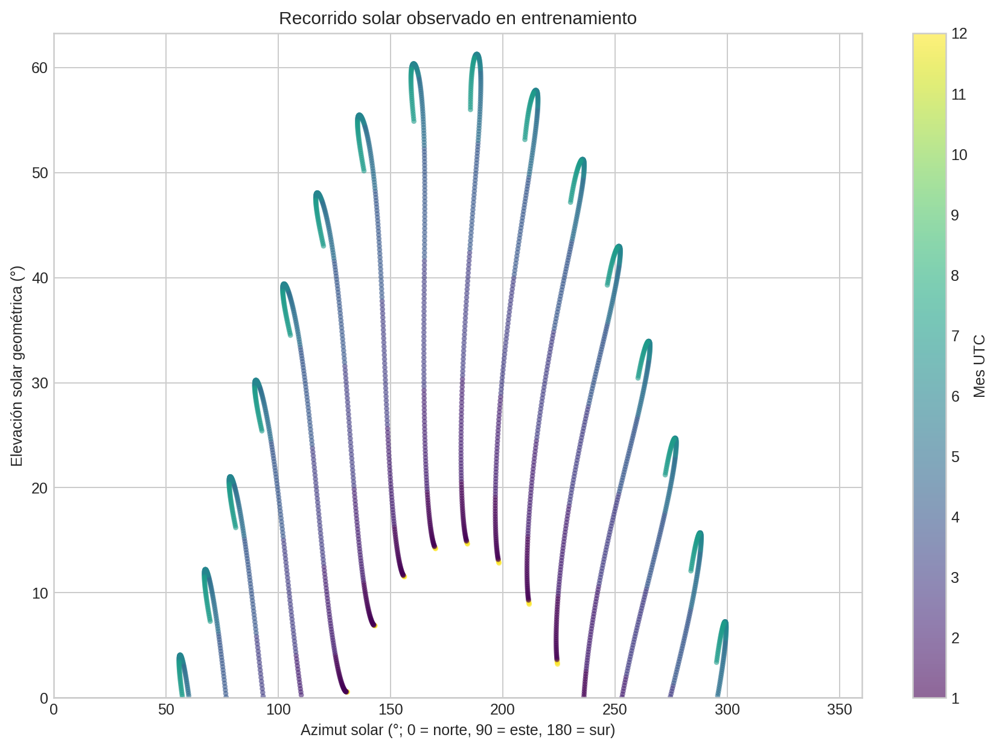

03_evolucion_mensual_geometria_solar_train.png


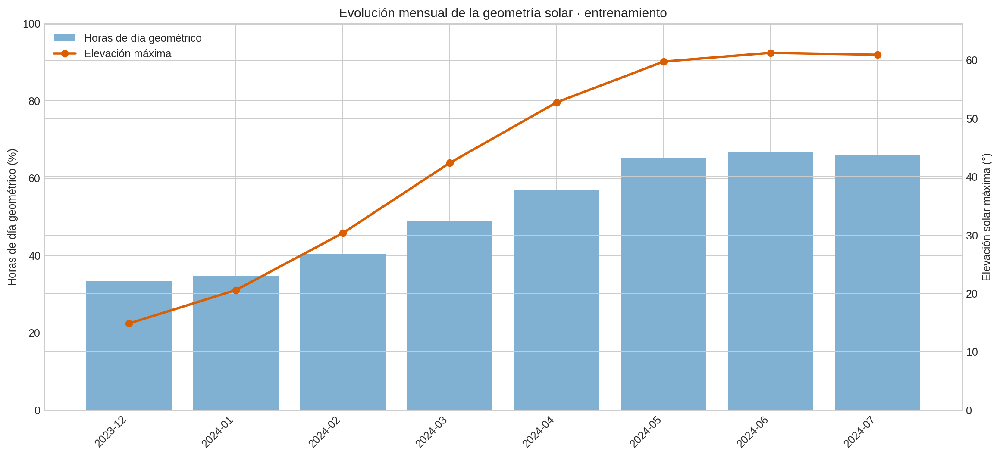

=== ZIP ===
Nombre: calculo_posicion_solar_Cabauw_20261102T170308Z_08b58701.zip
Tamaño: 2.04 MiB
SHA-256: 8a2acc7ee273ffaf1ab1756232908bdc1ab6b09a29af3ec90e406487d57c709b
Integridad: CORRECTA


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
# Cálculo de la posición solar en Cabauw
import sys
import subprocess
import importlib.util

def instalar_si_falta(modulo, paquete):
    if importlib.util.find_spec(modulo) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])

instalar_si_falta("pvlib", "pvlib")
instalar_si_falta("pyarrow", "pyarrow")
import io
import hashlib
import json
import os
import platform
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pvlib
try:
    from IPython.display import Image, display
except ImportError:
    class Image:
        def __init__(self, filename):
            self.filename = filename

    def display(value):
        print(value)

try:
    from google.colab import files
    EN_COLAB = True
except ImportError:
    files = None
    EN_COLAB = False


# 1. Contrato del cálculo

# Coordenadas de la estación BSRN de Cabauw.
LATITUD = 51.968
LONGITUD = 4.928
ALTITUD_M = 0.0

# Conclusión de la subsección 4.1.1: timestamps originales en UTC.
ZONA_HORARIA_DATASET = "UTC"

# Checkpoint creado en la subsección 2.6.
CHECKPOINT_PRIORITARIO = "checkpoints/09_tabla_horaria_particionada_sin_cambios.parquet"


# 2. Funciones auxiliares
def sha256_archivo(ruta, tamano_bloque=1024 * 1024):
    resumen = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        while True:
            bloque = archivo.read(tamano_bloque)
            if not bloque:
                break
            resumen.update(bloque)
    return resumen.hexdigest()

def guardar_csv(tabla, ruta):
    tabla.to_csv(ruta, index=False, encoding="utf-8-sig")

def obtener_entrada():
    """Devuelve el nombre y los bytes de un único ZIP/parquet de entrada."""
    if EN_COLAB:
        print(
            "Selecciona exclusivamente el ZIP validado de la subsección 2.6 "
            "o el checkpoint horario parquet equivalente."
        )
        subidos = files.upload()
        assert len(subidos) == 1, "Selecciona un único archivo de entrada."
        nombre, contenido = next(iter(subidos.items()))
        return nombre, contenido

    ruta_entrada = os.environ.get("INPUT_SOLAR_POSITION_FILE", "").strip()
    assert ruta_entrada, (
        "Fuera de Colab define INPUT_SOLAR_POSITION_FILE con la ruta al ZIP "
        "de la subsección 2.6 o al checkpoint parquet horario."
    )
    ruta = Path(ruta_entrada).expanduser().resolve()
    assert ruta.is_file(), f"No existe el archivo: {ruta}"
    return ruta.name, ruta.read_bytes()

def elegir_checkpoint_parquet(nombres):
    """Localiza el checkpoint horario más adecuado dentro del ZIP."""
    candidatos = [nombre for nombre in nombres if nombre.lower().endswith(".parquet")]
    assert candidatos, "El ZIP no contiene ningún checkpoint parquet."

    def prioridad(nombre):
        normalizado = nombre.lower()
        if normalizado == CHECKPOINT_PRIORITARIO.lower():
            return 0
        if "tabla_horaria_particionada_sin_cambios" in normalizado:
            return 1
        if "tabla_horaria" in normalizado:
            return 2
        return 3

    return sorted(candidatos, key=lambda nombre: (prioridad(nombre), nombre))[0]

def cargar_tabla_horaria(nombre, contenido):
    """Carga una tabla horaria desde ZIP o parquet."""
    if nombre.lower().endswith(".zip"):
        with zipfile.ZipFile(io.BytesIO(contenido)) as archivo_zip:
            checkpoint = elegir_checkpoint_parquet(archivo_zip.namelist())
            tabla = pd.read_parquet(io.BytesIO(archivo_zip.read(checkpoint)))
        return tabla, checkpoint

    if nombre.lower().endswith(".parquet"):
        return pd.read_parquet(io.BytesIO(contenido)), nombre

    raise AssertionError("La entrada debe ser un ZIP de la subsección 2.6 o un parquet horario.")

def detectar_columna(columnas, candidatos_exactos, terminos):
    """Encuentra una columna incluso si su nombre cambia ligeramente."""
    mapa = {str(columna).strip().lower(): columna for columna in columnas}
    for candidato in candidatos_exactos:
        if candidato.lower() in mapa:
            return mapa[candidato.lower()]

    for columna in columnas:
        nombre = str(columna).strip().lower()
        if all(termino in nombre for termino in terminos):
            return columna

    return None

def crear_inventario(ruta_base):
    filas = []
    for ruta in sorted(Path(ruta_base).rglob("*")):
        if ruta.is_file():
            filas.append(
                {
                    "archivo": str(ruta.relative_to(ruta_base)),
                    "tamano_bytes": ruta.stat().st_size,
                    "sha256": sha256_archivo(ruta),
                }
            )
    return pd.DataFrame(filas)


# 3. Carga, verificación temporal y cálculo físico
nombre_entrada, bytes_entrada = obtener_entrada()
df, checkpoint_utilizado = cargar_tabla_horaria(nombre_entrada, bytes_entrada)
columna_timestamp = detectar_columna(
    df.columns,
    candidatos_exactos=["Date/Time", "datetime", "timestamp", "fecha_hora"],
    terminos=["date", "time"],
)
assert columna_timestamp is not None, "No se encontró una columna temporal."
columna_particion = detectar_columna(
    df.columns, candidatos_exactos=["particion", "partition", "split"], terminos=["part"]
)

# utc=True interpreta como UTC los timestamps sin zona explícita.
df["timestamp_utc"] = pd.to_datetime(df[columna_timestamp], errors="coerce", utc=True)
n_timestamp_invalidos = int(df["timestamp_utc"].isna().sum())
assert n_timestamp_invalidos == 0, (
    f"Hay {n_timestamp_invalidos} timestamps no convertibles. " "Revísalos antes de continuar."
)
df = df.sort_values("timestamp_utc").reset_index(drop=True)
posicion_solar = pvlib.solarposition.get_solarposition(
    time=pd.DatetimeIndex(df["timestamp_utc"]),
    latitude=LATITUD,
    longitude=LONGITUD,
    altitude=ALTITUD_M,
    method="nrel_numpy",
)

# Variables deterministas: solo dependen del instante y de las coordenadas.
df["elevacion_solar_deg"] = posicion_solar["elevation"].to_numpy()
df["elevacion_solar_aparente_deg"] = posicion_solar["apparent_elevation"].to_numpy()
df["angulo_cenital_solar_deg"] = posicion_solar["zenith"].to_numpy()
df["azimut_solar_deg"] = posicion_solar["azimuth"].to_numpy()

# Día geométrico: centro del Sol por encima del horizonte geométrico.
df["dia_geometrico"] = df["elevacion_solar_deg"] > 0.0
df["periodo_geometrico"] = np.where(df["dia_geometrico"], "dia", "noche")

# Auxiliares para resúmenes y figuras, también expresadas en UTC.
df["fecha_utc"] = df["timestamp_utc"].dt.date.astype(str)
df["mes_utc"] = df["timestamp_utc"].dt.to_period("M").astype(str)
df["hora_utc"] = df["timestamp_utc"].dt.hour
if columna_particion is None:
    df["particion_analisis"] = "sin_particion"
    columna_particion_resultado = "particion_analisis"
    mascara_train = pd.Series(True, index=df.index)
else:
    columna_particion_resultado = columna_particion
    mascara_train = df[columna_particion].astype(str).str.strip().str.lower().eq("train")

assert mascara_train.any(), "No se encontraron filas de entrenamiento."
df_train = df.loc[mascara_train].copy()


# 4. Resúmenes y figuras de entrenamiento
resumen_particion = (
    df.groupby(columna_particion_resultado, dropna=False)
    .agg(
        n_horas=("timestamp_utc", "size"),
        inicio_utc=("timestamp_utc", "min"),
        fin_utc=("timestamp_utc", "max"),
        horas_dia_geometrico=("dia_geometrico", "sum"),
        elevacion_max_deg=("elevacion_solar_deg", "max"),
        elevacion_min_deg=("elevacion_solar_deg", "min"),
    )
    .reset_index()
)
resumen_particion["pct_horas_dia_geometrico"] = (
    100 * resumen_particion["horas_dia_geometrico"] / resumen_particion["n_horas"]
)
resumen_mensual_train = df_train.groupby("mes_utc", as_index=False).agg(
    n_horas=("timestamp_utc", "size"),
    horas_dia_geometrico=("dia_geometrico", "sum"),
    elevacion_max_deg=("elevacion_solar_deg", "max"),
    elevacion_aparente_media_dia_deg=(
        "elevacion_solar_aparente_deg",
        lambda serie: serie[serie > 0].mean(),
    ),
)
resumen_mensual_train["pct_horas_dia_geometrico"] = (
    100 * resumen_mensual_train["horas_dia_geometrico"] / resumen_mensual_train["n_horas"]
)

# Semana centrada en el instante de mayor elevación solar disponible en train.
instante_maximo = df_train.loc[df_train["elevacion_solar_deg"].idxmax(), "timestamp_utc"]
inicio_semana = instante_maximo.floor("D") - pd.Timedelta(days=3)
fin_semana = inicio_semana + pd.Timedelta(days=7)
muestra_semana = df_train[
    (df_train["timestamp_utc"] >= inicio_semana) & (df_train["timestamp_utc"] < fin_semana)
].copy()


# 5. Exportación, trazabilidad y descarga
marca_tiempo = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
identificador = f"F4_S1_2_{marca_tiempo}_{uuid.uuid4().hex[:8]}"
raiz_salida = Path(os.environ.get("OUTPUT_BASE_4_1_2", "resultados_4_1_2"))
directorio = raiz_salida / identificador
directorio_figuras = directorio / "figuras"
directorio_tablas = directorio / "tablas"
directorio_configuracion = directorio / "configuracion"
directorio_checkpoint = directorio / "checkpoints"
for ruta in [
    directorio_figuras,
    directorio_tablas,
    directorio_configuracion,
    directorio_checkpoint,
]:
    ruta.mkdir(parents=True, exist_ok=False)

plt.style.use("seaborn-v0_8-whitegrid")

# Figura 1: trayectoria solar durante una semana representativa.
fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(
    muestra_semana["timestamp_utc"],
    muestra_semana["elevacion_solar_deg"],
    color="#1f77b4",
    linewidth=1.8,
    label="Elevación geométrica",
)
ax.plot(
    muestra_semana["timestamp_utc"],
    muestra_semana["elevacion_solar_aparente_deg"],
    color="#ff7f0e",
    linewidth=1.2,
    alpha=0.9,
    label="Elevación aparente",
)
ax.axhline(0, color="black", linewidth=1)
ax.fill_between(
    muestra_semana["timestamp_utc"],
    0,
    muestra_semana["elevacion_solar_deg"].clip(lower=0),
    color="#f6c85f",
    alpha=0.30,
    label="Día geométrico",
)
ax.set_title("Trayectoria solar durante una semana representativa · entrenamiento")
ax.set_xlabel("Timestamp UTC")
ax.set_ylabel("Elevación solar (°)")
ax.legend(ncol=3, loc="upper right")
fig.autofmt_xdate()
fig.tight_layout()
ruta_figura_1 = directorio_figuras / "01_trayectoria_solar_semana_representativa_train.png"
fig.savefig(ruta_figura_1, dpi=180, bbox_inches="tight")
plt.close(fig)

# Figura 2: recorrido solar de las horas diurnas de entrenamiento.
df_dia_train = df_train[df_train["dia_geometrico"]].copy()
fig, ax = plt.subplots(figsize=(10, 7))
grafico = ax.scatter(
    df_dia_train["azimut_solar_deg"],
    df_dia_train["elevacion_solar_deg"],
    c=df_dia_train["timestamp_utc"].dt.month,
    cmap="viridis",
    s=12,
    alpha=0.60,
    edgecolors="none",
)
barra = fig.colorbar(grafico, ax=ax)
barra.set_label("Mes UTC")
barra.set_ticks(range(1, 13))
ax.set_title("Recorrido solar observado en entrenamiento")
ax.set_xlabel("Azimut solar (°; 0 = norte, 90 = este, 180 = sur)")
ax.set_ylabel("Elevación solar geométrica (°)")
ax.set_xlim(0, 360)
ax.set_ylim(0, max(5, df_dia_train["elevacion_solar_deg"].max() + 2))
fig.tight_layout()
ruta_figura_2 = directorio_figuras / "02_recorrido_solar_azimut_elevacion_train.png"
fig.savefig(ruta_figura_2, dpi=180, bbox_inches="tight")
plt.close(fig)

# Figura 3: evolución mensual de duración diurna y altura solar máxima.
fig, ax1 = plt.subplots(figsize=(13, 6))
eje_x = np.arange(len(resumen_mensual_train))
ax1.bar(
    eje_x,
    resumen_mensual_train["pct_horas_dia_geometrico"],
    color="#80b1d3",
    label="Horas de día geométrico",
)
ax1.set_ylabel("Horas de día geométrico (%)")
ax1.set_ylim(0, 100)
ax1.set_xticks(eje_x)
ax1.set_xticklabels(resumen_mensual_train["mes_utc"], rotation=45, ha="right")
ax2 = ax1.twinx()
ax2.plot(
    eje_x,
    resumen_mensual_train["elevacion_max_deg"],
    color="#d95f02",
    marker="o",
    linewidth=2.2,
    label="Elevación máxima",
)
ax2.set_ylabel("Elevación solar máxima (°)")
ax2.set_ylim(0, max(5, resumen_mensual_train["elevacion_max_deg"].max() + 5))
lineas_1, etiquetas_1 = ax1.get_legend_handles_labels()
lineas_2, etiquetas_2 = ax2.get_legend_handles_labels()
ax1.legend(lineas_1 + lineas_2, etiquetas_1 + etiquetas_2, loc="upper left")
ax1.set_title("Evolución mensual de la geometría solar · entrenamiento")
fig.tight_layout()
ruta_figura_3 = directorio_figuras / "03_evolucion_mensual_geometria_solar_train.png"
fig.savefig(ruta_figura_3, dpi=180, bbox_inches="tight")
plt.close(fig)

# Checkpoint reutilizable: conserva todas las columnas previas y añade las solares.
ruta_checkpoint = directorio_checkpoint / "10_tabla_horaria_con_geometria_solar.parquet"
df.to_parquet(ruta_checkpoint, index=False)
guardar_csv(resumen_particion, directorio_tablas / "01_resumen_geometria_por_particion.csv")
guardar_csv(resumen_mensual_train, directorio_tablas / "02_resumen_mensual_geometria_train.csv")
guardar_csv(
    muestra_semana[
        [
            "timestamp_utc",
            "elevacion_solar_deg",
            "elevacion_solar_aparente_deg",
            "angulo_cenital_solar_deg",
            "azimut_solar_deg",
            "dia_geometrico",
        ]
    ],
    directorio_tablas / "03_muestra_semana_representativa_train.csv",
)
configuracion = {
    "subseccion": "4.1.2_calculo_de_la_posicion_solar",
    "entrada": nombre_entrada,
    "checkpoint_entrada": checkpoint_utilizado,
    "columna_timestamp_original": str(columna_timestamp),
    "columna_particion": str(columna_particion) if columna_particion is not None else None,
    "interpretacion_timestamp": "UTC confirmado en subsección 4.1.1",
    "latitud": LATITUD,
    "longitud": LONGITUD,
    "altitud_m": ALTITUD_M,
    "metodo_pvlib": "nrel_numpy",
    "definicion_dia_geometrico": "elevacion_solar_deg > 0",
    "filas_entrada": int(len(df)),
    "timestamp_invalidos": n_timestamp_invalidos,
    "filas_eliminadas": 0,
    "valores_imputados": 0,
    "valores_radiometricos_usados_en_calculo": False,
}
with (directorio_configuracion / "configuracion_4_1_2.json").open("w", encoding="utf-8") as archivo:
    json.dump(configuracion, archivo, ensure_ascii=False, indent=2, default=str)

readme = f"""# Subsección 4.1.2 · Cálculo de la posición solar

## Resultado

Se añadieron al checkpoint horario las siguientes variables deterministas:

- elevacion_solar_deg;
- elevacion_solar_aparente_deg;
- angulo_cenital_solar_deg;
- azimut_solar_deg;
- dia_geometrico y periodo_geometrico.

## Referencia temporal y geográfica

Los timestamps se interpretaron como UTC, conclusión obtenida en la subsección 4.1.1.
La posición se calculó para Cabauw con latitud {LATITUD}, longitud {LONGITUD} y altitud {ALTITUD_M} m.

dia_geometrico=True significa que la elevación solar geométrica es estrictamente mayor que 0°.

## Alcance de particiones

Las variables solares se calcularon para todas las particiones porque dependen solo del instante y de las coordenadas. Las figuras y los resúmenes descriptivos se elaboraron solo con entrenamiento.

## Protección de datos

No se eliminaron filas, no se imputaron valores y no se utilizaron observaciones radiométricas ni la variable objetivo para calcular la posición solar.
"""
(directorio / "README.md").write_text(readme, encoding="utf-8")
inventario = crear_inventario(directorio)
guardar_csv(inventario, directorio / "inventario_archivos.csv")
ruta_zip = raiz_salida / f"calculo_posicion_solar_Cabauw_{marca_tiempo}_{identificador[-8:]}.zip"
with zipfile.ZipFile(ruta_zip, "w", compression=zipfile.ZIP_DEFLATED) as archivo_zip:
    for ruta in sorted(directorio.rglob("*")):
        if ruta.is_file():
            archivo_zip.write(ruta, arcname=str(ruta.relative_to(directorio)))

with zipfile.ZipFile(ruta_zip) as archivo_zip:
    assert archivo_zip.testzip() is None, "El ZIP generado contiene un archivo dañado."


# 6. Resumen visible y descarga
print("=== RESUMEN TÉCNICO 4.1.2 ===")
print(f"Checkpoint de entrada: {checkpoint_utilizado}")
print(f"Horas analizadas: {len(df):,}")
print(f"Timestamp UTC: {df['timestamp_utc'].min()} → {df['timestamp_utc'].max()}")
print("Filas eliminadas: 0")
print("Valores imputados: 0")
print("Valores radiométricos usados en el cálculo: NO")
print()
display(resumen_particion)
print("=== FIGURAS ===")
for ruta in [ruta_figura_1, ruta_figura_2, ruta_figura_3]:
    print(ruta.name)
    display(Image(filename=str(ruta)))

print("=== ZIP ===")
print(f"Nombre: {ruta_zip.name}")
print(f"Tamaño: {ruta_zip.stat().st_size / (1024 ** 2):.2f} MiB")
print(f"SHA-256: {sha256_archivo(ruta_zip)}")
print("Integridad: CORRECTA")
if EN_COLAB:
    files.download(str(ruta_zip))

In [15]:
fecha_ejemplo = "2024-06-21"
horas_ejemplo = [0, 4, 12, 20, 23]
tabla_ejemplo = df.loc[
    (df["timestamp_utc"].dt.strftime("%Y-%m-%d") == fecha_ejemplo)
    & (df["timestamp_utc"].dt.hour.isin(horas_ejemplo)),
    ["timestamp_utc", "elevacion_solar_deg", "periodo_geometrico"],
].copy()
tabla_ejemplo.columns = ["Date/Time (UTC)", "Elevación solar geométrica (°)", "Clasificación"]
tabla_ejemplo["Elevación solar geométrica (°)"] = tabla_ejemplo[
    "Elevación solar geométrica (°)"
].round(2)
tabla_ejemplo["Clasificación"] = tabla_ejemplo["Clasificación"].replace(
    {"dia": "Día", "noche": "Noche"}
)
display(tabla_ejemplo)

,Date/Time (UTC),Elevación solar geométrica (°),Clasificación
5592,2024-06-21 00:00:00+00:00,-14.49,Noche
5596,2024-06-21 04:00:00+00:00,3.99,Día
5604,2024-06-21 12:00:00+00:00,61.26,Día
5612,2024-06-21 20:00:00+00:00,-0.37,Noche
5615,2024-06-21 23:00:00+00:00,-14.03,Noche


**Resultados.**

A partir de los timestamps expresados en UTC y de las coordenadas geográficas de la estación de Cabauw, se calcularon con pvlib la elevación solar geométrica y aparente, el ángulo cenital y el azimut solar. Asimismo, se definió el indicador de día geométrico como aquellos instantes con elevación solar geométrica estrictamente superior a 0°. Esta clasificación es determinista y no depende de las observaciones radiométricas, por lo que permite distinguir entre condiciones de iluminación diurna y nocturna incluso cuando existan incidencias de medida o ausencia de radiación registrada.

Los resultados muestran una evolución estacional físicamente consistente. La elevación solar máxima horaria aumentó desde 14,84° a finales de diciembre de 2023 hasta 61,26° en junio de 2024, descendiendo ligeramente hasta 60,92° en julio. Paralelamente, la proporción de timestamps horarios clasificados como diurnos pasó del 33,3 % en el tramo disponible de diciembre al 66,7 % en junio. Estas variables no describen la nubosidad ni la irradiancia observada, pero aportan un contexto físico conocido en el instante de predicción que permitirá analizar posteriormente el comportamiento de DIF bajo distintos regímenes solares.

### 4.2.1 Inventario de variables

Esta subsección fija las 27 variables horarias observacionales del análisis contemporáneo: 24 radiométricas y 3 meteorológicas. Cada familia radiométrica (SWD, DIR, DIF, LWD, SWU y LWU) aporta cuatro descriptores: la media horaria; el mínimo y el máximo horarios, que son los extremos realmente registrados en la hora y conservan transitorios como el paso de nubes; y la media horaria de la desviación estándar minutal, que refleja la variabilidad intraminutal típica y no la dispersión de las 60 medias minutales. T2, RH y presión se representan por su media horaria. La variable objetivo contemporánea es `DIF__media_h`, con la que se comparan individualmente las otras 26 sin interpretar esas comparaciones como relaciones predictivas, mientras que la geometría solar queda fuera del inventario y se reserva para definir los regímenes solares de las subsecciones 4.2.8 a 4.2.12.

Selecciona exclusivamente el ZIP validado de la subsección 4.1.2 que contiene la tabla horaria con geometría solar.


Saving calculo_posicion_solar_Cabauw_20261102T170308Z_08b58701.zip to calculo_posicion_solar_Cabauw_20261102T170308Z_08b58701.zip
=== RESUMEN TÉCNICO 4.2.1 ===
Checkpoint de entrada: checkpoints/10_tabla_horaria_con_geometria_solar.parquet
Variables identificadas: 27 / 27
Objetivo contemporáneo: DIF__media_h
Comparaciones individuales X(t) ↔ DIF(t): 26
Horas de entrenamiento: 5,208
Filas eliminadas: 0
Valores imputados: 0
Criterio 30/60 aplicado como descarte: NO



,familia,tipo,estadistico,descripcion,columna_horaria,rol,objetivo,misma_familia_que_objetivo,n_horas_train,n_finitas_train,n_no_finitas_train,pct_finitas_train,etiqueta_grafico
0,SWD,radiométrica,media,Media horaria,SWD__media_h,comparación X(t) ↔ DIF(t),False,False,5208,5208,0,100.000000,SWD · media
1,SWD,radiométrica,min,Mínimo horario,SWD__min_h,comparación X(t) ↔ DIF(t),False,False,5208,5208,0,100.000000,SWD · min
2,SWD,radiométrica,max,Máximo horario,SWD__max_h,comparación X(t) ↔ DIF(t),False,False,5208,5208,0,100.000000,SWD · max
3,SWD,radiométrica,std_media,Media horaria de la desviación estándar minutal,SWD__std_media_h,comparación X(t) ↔ DIF(t),False,False,5208,5208,0,100.000000,SWD · std_media
4,DIR,radiométrica,media,Media horaria,DIR__media_h,comparación X(t) ↔ DIF(t),False,False,5208,5208,0,100.000000,DIR · media
5,DIR,radiométrica,min,Mínimo horario,DIR__min_h,comparación X(t) ↔ DIF(t),False,False,5208,5208,0,100.000000,DIR · min
6,DIR,radiométrica,max,Máximo horario,DIR__max_h,comparación X(t) ↔ DIF(t),False,False,5208,5208,0,100.000000,DIR · max
7,DIR,radiométrica,std_media,Media horaria de la desviación estándar minutal,DIR__std_media_h,comparación X(t) ↔ DIF(t),False,False,5208,5208,0,100.000000,DIR · std_media
8,DIF,radiométrica,media,Media horaria,DIF__media_h,objetivo contemporáneo,True,True,5208,5208,0,100.000000,DIF · media [objetivo]
9,DIF,radiométrica,min,Mínimo horario,DIF__min_h,comparación X(t) ↔ DIF(t),False,True,5208,5208,0,100.000000,DIF · min


=== FIGURAS ===
01_inventario_visual_27_variables.png


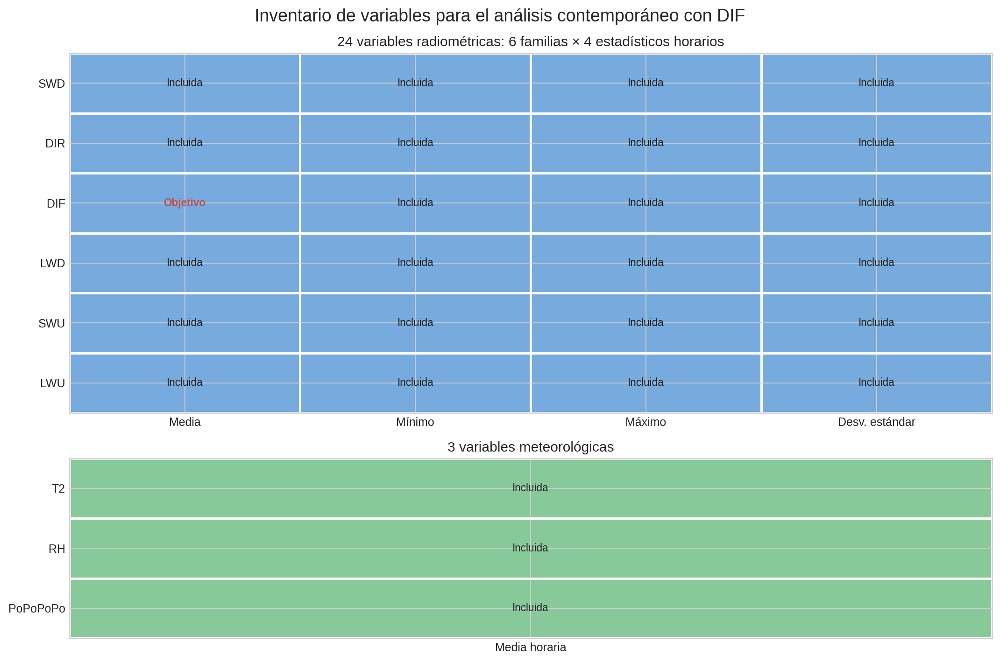

02_disponibilidad_numerica_27_variables_train.png


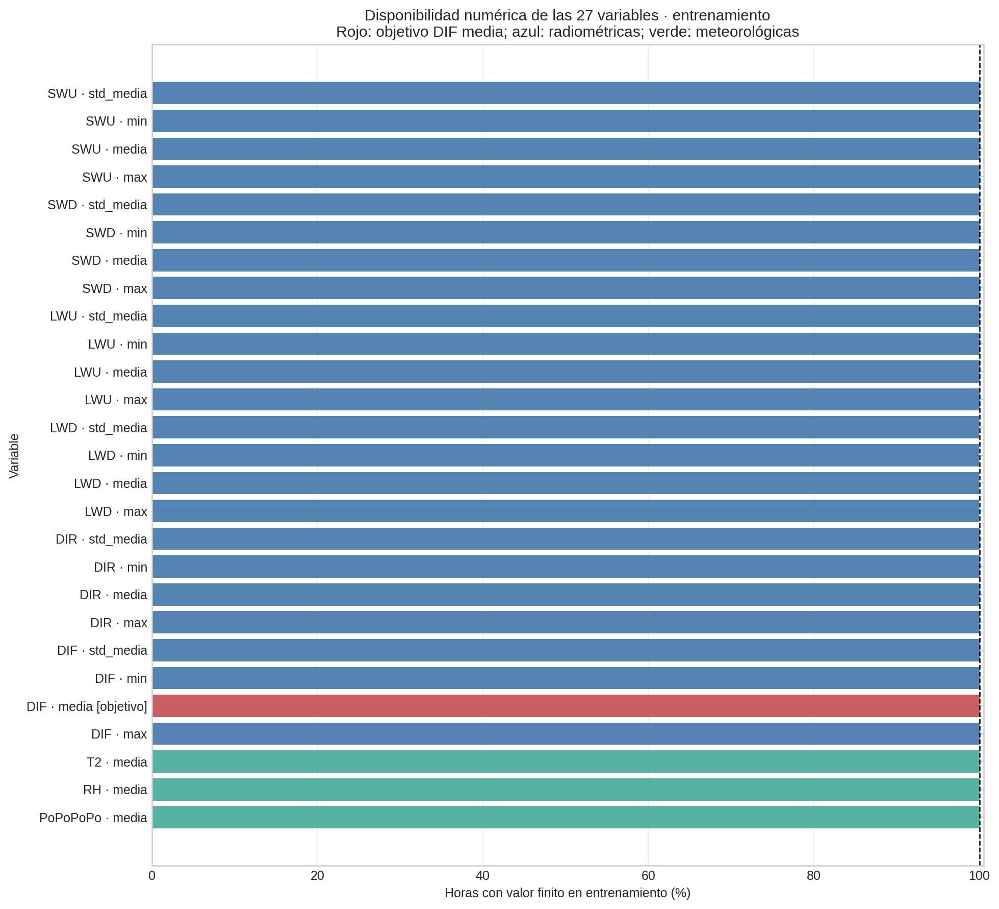

=== ZIP ===
Nombre: inventario_variables_Cabauw_20261102T170407Z_6bd1ce4b.zip
Tamaño: 1.63 MiB
SHA-256: 74740436db880d023862364b4da1abc4bb4a81f25c67d85a6b6ed28015551f58
Integridad: CORRECTA


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
# Inventario de las 27 variables para el análisis contemporáneo X(t) ↔ DIF(t)
import sys
import subprocess
import importlib.util

def instalar_si_falta(modulo, paquete):
    if importlib.util.find_spec(modulo) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])

instalar_si_falta("pyarrow", "pyarrow")
import io
import hashlib
import json
import os
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
try:
    from IPython.display import Image, display
except ImportError:
    class Image:
        def __init__(self, filename):
            self.filename = filename

    def display(value):
        print(value)

try:
    from google.colab import files
    EN_COLAB = True
except ImportError:
    files = None
    EN_COLAB = False


# 1. Contrato de la subsección
CHECKPOINT_PRIORITARIO = "checkpoints/10_tabla_horaria_con_geometria_solar.parquet"
COLUMNA_OBJETIVO = "DIF__media_h"
PARTICION_ANALIZADA = "train"
FAMILIAS_RADIOMETRICAS = ["SWD", "DIR", "DIF", "LWD", "SWU", "LWU"]
ESTADISTICOS_RADIOMETRICOS = [
    ("media", "__media_h", "Media horaria"),
    ("min", "__min_h", "Mínimo horario"),
    ("max", "__max_h", "Máximo horario"),
    ("std_media", "__std_media_h", "Media horaria de la desviación estándar minutal"),
]
VARIABLES_METEOROLOGICAS = [
    ("T2", "Temperatura a 2 m"),
    ("RH", "Humedad relativa"),
    ("PoPoPoPo", "Presión atmosférica"),
]


# 2. Funciones auxiliares
def sha256_archivo(ruta, tamano_bloque=1024 * 1024):
    resumen = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        while True:
            bloque = archivo.read(tamano_bloque)
            if not bloque:
                break
            resumen.update(bloque)
    return resumen.hexdigest()

def guardar_csv(tabla, ruta):
    tabla.to_csv(ruta, index=False, encoding="utf-8-sig")

def obtener_entrada():
    if EN_COLAB:
        print(
            "Selecciona exclusivamente el ZIP validado de la subsección 4.1.2 "
            "que contiene la tabla horaria con geometría solar."
        )
        subidos = files.upload()
        assert len(subidos) == 1, "Selecciona un único archivo ZIP o parquet."
        nombre, contenido = next(iter(subidos.items()))
        return nombre, contenido

    ruta_entrada = os.environ.get("INPUT_INVENTORY_FILE", "").strip()
    assert ruta_entrada, (
        "Fuera de Colab define INPUT_INVENTORY_FILE con la ruta al ZIP " "de la subsección 4.1.2."
    )
    ruta = Path(ruta_entrada).expanduser().resolve()
    assert ruta.is_file(), f"No existe el archivo: {ruta}"
    return ruta.name, ruta.read_bytes()

def elegir_checkpoint_parquet(nombres):
    candidatos = [nombre for nombre in nombres if nombre.lower().endswith(".parquet")]
    assert candidatos, "El ZIP no contiene ningún checkpoint parquet."

    def prioridad(nombre):
        normalizado = nombre.lower()
        if normalizado == CHECKPOINT_PRIORITARIO.lower():
            return 0
        if "tabla_horaria_con_geometria_solar" in normalizado:
            return 1
        if "tabla_horaria" in normalizado:
            return 2
        return 3

    return sorted(candidatos, key=lambda nombre: (prioridad(nombre), nombre))[0]

def cargar_tabla(nombre, contenido):
    if nombre.lower().endswith(".zip"):
        with zipfile.ZipFile(io.BytesIO(contenido)) as archivo_zip:
            checkpoint = elegir_checkpoint_parquet(archivo_zip.namelist())
            tabla = pd.read_parquet(io.BytesIO(archivo_zip.read(checkpoint)))
        return tabla, checkpoint

    if nombre.lower().endswith(".parquet"):
        return pd.read_parquet(io.BytesIO(contenido)), nombre

    raise AssertionError("La entrada debe ser un ZIP o parquet horario válido.")

def detectar_columna_particion(columnas):
    for candidata in ["particion_observacion", "particion", "partition", "split"]:
        if candidata in columnas:
            return candidata

    for columna in columnas:
        if "particion" in str(columna).lower() or "partition" in str(columna).lower():
            return columna

    return None

def crear_inventario_archivos(ruta_base):
    filas = []
    for ruta in sorted(Path(ruta_base).rglob("*")):
        if ruta.is_file():
            filas.append(
                {
                    "archivo": str(ruta.relative_to(ruta_base)),
                    "tamano_bytes": ruta.stat().st_size,
                    "sha256": sha256_archivo(ruta),
                }
            )
    return pd.DataFrame(filas)


# 3. Definición explícita de las 27 variables
def construir_especificacion():
    especificacion = []
    for familia in FAMILIAS_RADIOMETRICAS:
        for estadistico, sufijo, descripcion in ESTADISTICOS_RADIOMETRICOS:
            columna = f"{familia}{sufijo}"
            es_objetivo = columna == COLUMNA_OBJETIVO
            especificacion.append(
                {
                    "familia": familia,
                    "tipo": "radiométrica",
                    "estadistico": estadistico,
                    "descripcion": descripcion,
                    "columna_horaria": columna,
                    "rol": (
                        "objetivo contemporáneo" if es_objetivo else "comparación X(t) ↔ DIF(t)"
                    ),
                    "objetivo": es_objetivo,
                    "misma_familia_que_objetivo": familia == "DIF",
                }
            )

    for familia, descripcion in VARIABLES_METEOROLOGICAS:
        especificacion.append(
            {
                "familia": familia,
                "tipo": "meteorológica",
                "estadistico": "media",
                "descripcion": f"Media horaria de {descripcion.lower()}",
                "columna_horaria": f"{familia}__media_h",
                "rol": "comparación X(t) ↔ DIF(t)",
                "objetivo": False,
                "misma_familia_que_objetivo": False,
            }
        )

    return pd.DataFrame(especificacion)

especificacion = construir_especificacion()
assert len(especificacion) == 27, "La especificación debe contener exactamente 27 variables."
assert especificacion["columna_horaria"].is_unique, "Hay columnas duplicadas en el inventario."


# 4. Carga y validación del inventario
nombre_entrada, bytes_entrada = obtener_entrada()
df, checkpoint_utilizado = cargar_tabla(nombre_entrada, bytes_entrada)
columna_particion = detectar_columna_particion(df.columns)
assert columna_particion is not None, "No se encontró la columna de partición."
columnas_faltantes = sorted(set(especificacion["columna_horaria"]) - set(df.columns))
assert not columnas_faltantes, "Faltan columnas requeridas para el inventario: " + ", ".join(
    columnas_faltantes
)
mascara_train = df[columna_particion].astype(str).str.strip().str.lower().eq(PARTICION_ANALIZADA)
assert mascara_train.any(), "No se encontraron filas de entrenamiento."
df_train = df.loc[mascara_train].copy()
filas_inventario = []
for registro in especificacion.to_dict(orient="records"):
    columna = registro["columna_horaria"]
    valores = pd.to_numeric(df_train[columna], errors="coerce")
    mascara_finita = np.isfinite(valores.to_numpy(dtype=float, na_value=np.nan))
    n_horas = len(valores)
    n_finitas = int(mascara_finita.sum())
    filas_inventario.append(
        {
            **registro,
            "n_horas_train": n_horas,
            "n_finitas_train": n_finitas,
            "n_no_finitas_train": n_horas - n_finitas,
            "pct_finitas_train": 100 * n_finitas / n_horas,
        }
    )

inventario_variables = pd.DataFrame(filas_inventario)
inventario_variables["etiqueta_grafico"] = np.where(
    inventario_variables["objetivo"],
    inventario_variables["familia"] + " · media [objetivo]",
    inventario_variables["familia"] + " · " + inventario_variables["estadistico"],
)
assert (
    int(inventario_variables["objetivo"].sum()) == 1
), "Debe existir un único objetivo contemporáneo."
assert (
    inventario_variables.loc[inventario_variables["objetivo"], "columna_horaria"].iloc[0]
    == COLUMNA_OBJETIVO
)


# 5. Advertencias de interpretación
advertencias = pd.DataFrame(
    [
        {
            "id": "I201",
            "alcance": "DIF__min_h, DIF__max_h y DIF__std_media_h",
            "advertencia": (
                "Estas tres variables se derivan de las mismas observaciones minutales "
                "que DIF__media_h."
            ),
            "decision": (
                "Interpretar su relación contemporánea como estructural y descriptiva; "
                "no como evidencia de capacidad predictiva independiente."
            ),
        },
        {
            "id": "I202",
            "alcance": "Las 27 variables observacionales",
            "advertencia": (
                "La geometría solar no forma parte de las 26 comparaciones X(t) ↔ DIF(t)."
            ),
            "decision": (
                "Usar elevación solar y día/noche como variables de contexto y para "
                "separar regímenes en las subsecciones posteriores."
            ),
        },
        {
            "id": "I203",
            "alcance": "Disponibilidad",
            "advertencia": (
                "Este inventario solo verifica presencia numérica finita de las horas train."
            ),
            "decision": (
                "La sensibilidad al umbral 30/60 se evaluará separadamente en la "
                "subsección 4.2.10, sin descartar observaciones aquí."
            ),
        },
    ]
)


# 6. Figuras
marca_tiempo = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
identificador = f"F4_S2_1_{marca_tiempo}_{uuid.uuid4().hex[:8]}"
raiz_salida = Path(os.environ.get("OUTPUT_BASE_4_2_1", "resultados_4_2_1"))
directorio = raiz_salida / identificador
directorio_figuras = directorio / "figuras"
directorio_tablas = directorio / "tablas"
directorio_configuracion = directorio / "configuracion"
directorio_checkpoint = directorio / "checkpoints"
for ruta in [
    directorio_figuras,
    directorio_tablas,
    directorio_configuracion,
    directorio_checkpoint,
]:
    ruta.mkdir(parents=True, exist_ok=False)

plt.style.use("seaborn-v0_8-whitegrid")

# Figura 1: representación gráfica del contrato de las 27 variables.
fig, (ax_rad, ax_met) = plt.subplots(
    2, 1, figsize=(12, 8), gridspec_kw={"height_ratios": [3.0, 1.5]}
)
matriz_radiometrica = np.ones((len(FAMILIAS_RADIOMETRICAS), len(ESTADISTICOS_RADIOMETRICOS)))
cmap_radiometrica = ListedColormap(["#77aadd"])
ax_rad.imshow(matriz_radiometrica, cmap=cmap_radiometrica, vmin=0, vmax=1, aspect="auto")
ax_rad.set_xticks(range(len(ESTADISTICOS_RADIOMETRICOS)))
ax_rad.set_xticklabels(["Media", "Mínimo", "Máximo", "Desv. estándar"])
ax_rad.set_yticks(range(len(FAMILIAS_RADIOMETRICAS)))
ax_rad.set_yticklabels(FAMILIAS_RADIOMETRICAS)
ax_rad.set_title("24 variables radiométricas: 6 familias × 4 estadísticos horarios")
for fila, familia in enumerate(FAMILIAS_RADIOMETRICAS):
    for columna, (estadistico, _, _) in enumerate(ESTADISTICOS_RADIOMETRICOS):
        texto = "Objetivo" if familia == "DIF" and estadistico == "media" else "Incluida"
        color = "#c44e52" if texto == "Objetivo" else "#1f1f1f"
        ax_rad.text(
            columna,
            fila,
            texto,
            ha="center",
            va="center",
            fontsize=9,
            fontweight="bold" if texto == "Objetivo" else "normal",
            color=color,
        )

matriz_meteorologica = np.ones((len(VARIABLES_METEOROLOGICAS), 1))
cmap_meteorologica = ListedColormap(["#88c999"])
ax_met.imshow(matriz_meteorologica, cmap=cmap_meteorologica, vmin=0, vmax=1, aspect="auto")
ax_met.set_xticks([0])
ax_met.set_xticklabels(["Media horaria"])
ax_met.set_yticks(range(len(VARIABLES_METEOROLOGICAS)))
ax_met.set_yticklabels([familia for familia, _ in VARIABLES_METEOROLOGICAS])
ax_met.set_title("3 variables meteorológicas")
for fila in range(len(VARIABLES_METEOROLOGICAS)):
    ax_met.text(0, fila, "Incluida", ha="center", va="center", fontsize=9)

for eje in [ax_rad, ax_met]:
    eje.set_xticks(np.arange(-0.5, eje.get_xticks()[-1] + 1, 1), minor=True)
    eje.set_yticks(np.arange(-0.5, eje.get_yticks()[-1] + 1, 1), minor=True)
    eje.grid(which="minor", color="white", linewidth=2)
    eje.tick_params(which="minor", bottom=False, left=False)

fig.suptitle("Inventario de variables para el análisis contemporáneo con DIF", fontsize=15, y=0.98)
fig.tight_layout()
ruta_figura_1 = directorio_figuras / "01_inventario_visual_27_variables.png"
fig.savefig(ruta_figura_1, dpi=180, bbox_inches="tight")
plt.close(fig)

# Figura 2: disponibilidad numérica, sin aplicar ningún criterio de descarte.
orden = inventario_variables.sort_values(
    ["tipo", "familia", "estadistico"], ascending=[True, True, True]
).copy()
colores = np.where(
    orden["objetivo"], "#c44e52", np.where(orden["tipo"].eq("meteorológica"), "#44aa99", "#4477aa")
)
fig, ax = plt.subplots(figsize=(11, 10))
ax.barh(orden["etiqueta_grafico"], orden["pct_finitas_train"], color=colores, alpha=0.90)
ax.axvline(100, color="black", linestyle="--", linewidth=1)
ax.set_xlim(0, 100.5)
ax.set_xlabel("Horas con valor finito en entrenamiento (%)")
ax.set_ylabel("Variable")
ax.set_title(
    "Disponibilidad numérica de las 27 variables · entrenamiento\n"
    "Rojo: objetivo DIF media; azul: radiométricas; verde: meteorológicas"
)
ax.grid(axis="x", alpha=0.30)
fig.tight_layout()
ruta_figura_2 = directorio_figuras / "02_disponibilidad_numerica_27_variables_train.png"
fig.savefig(ruta_figura_2, dpi=180, bbox_inches="tight")
plt.close(fig)


# 7. Salida trazable

# El inventario no transforma el dataset: se conserva el checkpoint de 4.1.2.
ruta_checkpoint = directorio_checkpoint / "11_tabla_horaria_con_geometria_solar_sin_cambios.parquet"
df.to_parquet(ruta_checkpoint, index=False)
guardar_csv(inventario_variables, directorio_tablas / "01_inventario_27_variables_train.csv")
guardar_csv(advertencias, directorio_tablas / "02_advertencias_interpretacion.csv")
resumen = pd.DataFrame(
    [
        {
            "n_variables_esperadas": 27,
            "n_variables_identificadas": len(inventario_variables),
            "objetivo_contemporaneo": COLUMNA_OBJETIVO,
            "n_comparaciones_X_con_DIF": int((~inventario_variables["objetivo"]).sum()),
            "n_horas_train": len(df_train),
            "min_pct_finitas_train": inventario_variables["pct_finitas_train"].min(),
            "max_pct_finitas_train": inventario_variables["pct_finitas_train"].max(),
            "filas_eliminadas": 0,
            "valores_imputados": 0,
            "aplica_30_60_como_descarte": False,
        }
    ]
)
guardar_csv(resumen, directorio_tablas / "03_resumen_inventario.csv")
configuracion = {
    "subseccion": "4.2.1_inventario_de_variables",
    "entrada": nombre_entrada,
    "checkpoint_entrada": checkpoint_utilizado,
    "checkpoint_salida": str(ruta_checkpoint.name),
    "particion_descriptiva": PARTICION_ANALIZADA,
    "n_variables_esperadas": 27,
    "objetivo_contemporaneo": COLUMNA_OBJETIVO,
    "n_comparaciones": 26,
    "variables_geometria_solar_como_contexto": [
        "elevacion_solar_deg",
        "elevacion_solar_aparente_deg",
        "angulo_cenital_solar_deg",
        "azimut_solar_deg",
        "dia_geometrico",
    ],
    "filas_eliminadas": 0,
    "valores_imputados": 0,
}
with (directorio_configuracion / "configuracion_4_2_1.json").open("w", encoding="utf-8") as archivo:
    json.dump(configuracion, archivo, ensure_ascii=False, indent=2)

readme = f"""# Subsección 4.2.1 · Inventario de variables

## Resultado

Se verificaron 27 variables observacionales horarias:

- 24 radiométricas: media, mínimo, máximo y media horaria de la desviación estándar minutal para SWD, DIR, DIF, LWD, SWU y LWU;
- 3 meteorológicas: medias horarias de T2, RH y PoPoPoPo.

El objetivo contemporáneo es {COLUMNA_OBJETIVO}. Las restantes 26 variables quedan identificadas para las comparaciones X(t) ↔ DIF(t).

## Alcance

Los resúmenes de disponibilidad se elaboran sobre entrenamiento. No se aplicó el criterio 30/60 como filtro ni se modificó el checkpoint.

Las variables de posición solar no forman parte de las 27 comparaciones observacionales. Se reservaron como contexto físico y para la separación por regímenes solares.

## Cautela de interpretación

DIF__min_h, DIF__max_h y DIF__std_media_h se derivan de las mismas observaciones minutales que DIF__media_h. Su relación contemporánea con el objetivo es descriptiva y estructural, no evidencia de capacidad predictiva independiente.
"""
(directorio / "README.md").write_text(readme, encoding="utf-8")
inventario_archivos = crear_inventario_archivos(directorio)
guardar_csv(inventario_archivos, directorio / "inventario_archivos.csv")
ruta_zip = raiz_salida / f"inventario_variables_Cabauw_{marca_tiempo}_{identificador[-8:]}.zip"
with zipfile.ZipFile(ruta_zip, "w", compression=zipfile.ZIP_DEFLATED) as archivo_zip:
    for ruta in sorted(directorio.rglob("*")):
        if ruta.is_file():
            archivo_zip.write(ruta, arcname=str(ruta.relative_to(directorio)))

with zipfile.ZipFile(ruta_zip) as archivo_zip:
    assert archivo_zip.testzip() is None, "El ZIP generado contiene un archivo dañado."


# 8. Resumen visible
print("=== RESUMEN TÉCNICO 4.2.1 ===")
print(f"Checkpoint de entrada: {checkpoint_utilizado}")
print(f"Variables identificadas: {len(inventario_variables)} / 27")
print(f"Objetivo contemporáneo: {COLUMNA_OBJETIVO}")
print("Comparaciones individuales X(t) ↔ DIF(t): 26")
print(f"Horas de entrenamiento: {len(df_train):,}")
print("Filas eliminadas: 0")
print("Valores imputados: 0")
print("Criterio 30/60 aplicado como descarte: NO")
print()
display(inventario_variables)
print("=== FIGURAS ===")
for ruta in [ruta_figura_1, ruta_figura_2]:
    print(ruta.name)
    display(Image(filename=str(ruta)))

print("=== ZIP ===")
print(f"Nombre: {ruta_zip.name}")
print(f"Tamaño: {ruta_zip.stat().st_size / (1024 ** 2):.2f} MiB")
print(f"SHA-256: {sha256_archivo(ruta_zip)}")
print("Integridad: CORRECTA")
if EN_COLAB:
    files.download(str(ruta_zip))

### 4.2.2 Evolución conjunta durante el entrenamiento

Esta subsección describe cómo evoluciona cada una de las 26 variables horarias X(t) junto a `DIF__media_h` en la partición de entrenamiento, con el fin de identificar tendencias compartidas, estacionalidad, episodios atípicos y periodos en los que ambas series divergen, sin estimar todavía correlaciones ni seleccionar predictores. Para cada variable se muestran paneles temporales alineados con la serie horaria, su media diaria y una media móvil centrada de siete días, así como superposiciones normalizadas mediante z-score y tres semanas representativas de invierno, primavera y verano. La normalización tiene solo finalidad gráfica y las semanas son muestras visuales fijas; no se eliminan filas, no se imputan valores ni se aplica el criterio 30/60 como descarte.

> *Subsección complementaria: no se utiliza en la memoria. Se mantiene porque genera la entrada de la subsección 4.2.3.*

Selecciona el ZIP validado de la subsección 4.2.1 (inventario de variables).


Saving inventario_variables_Cabauw_20261102T170407Z_6bd1ce4b.zip to inventario_variables_Cabauw_20261102T170407Z_6bd1ce4b.zip
=== RESUMEN TÉCNICO 4.2.2 ===
Checkpoint de entrada: checkpoints/11_tabla_horaria_con_geometria_solar_sin_cambios.parquet
Partición analizada: train
Horas de entrenamiento: 5,208
Comparaciones X(t) ↔ DIF(t): 26
Figuras generadas: 53
Saltos no horarios detectados: 0
Filas eliminadas: 0
Valores imputados: 0
Criterio 30/60 aplicado como descarte: NO



,particion_analizada,n_horas_train,n_dias_train,n_variables_inventario,n_comparaciones_individuales,n_figuras_generadas,n_saltos_no_horarios_train,filtro_30_60_aplicado,filas_eliminadas,valores_imputados
0,train,5208,217,27,26,53,0,False,0,0


,id,etiqueta,inicio_utc,fin_utc,n_horas,uso
0,invierno,Invierno · 15–21 enero de 2024,2024-01-15 00:00:00+00:00,2024-01-21 23:00:00+00:00,168,muestra visual representativa; no filtra ni es...
1,primavera,Primavera · 15–21 abril de 2024,2024-04-15 00:00:00+00:00,2024-04-21 23:00:00+00:00,168,muestra visual representativa; no filtra ni es...
2,verano,Verano · 15–21 junio de 2024,2024-06-15 00:00:00+00:00,2024-06-21 23:00:00+00:00,168,muestra visual representativa; no filtra ni es...


=== MUESTRA DE FIGURAS ===
00_referencia_DIF_y_ventanas_estacionales.png


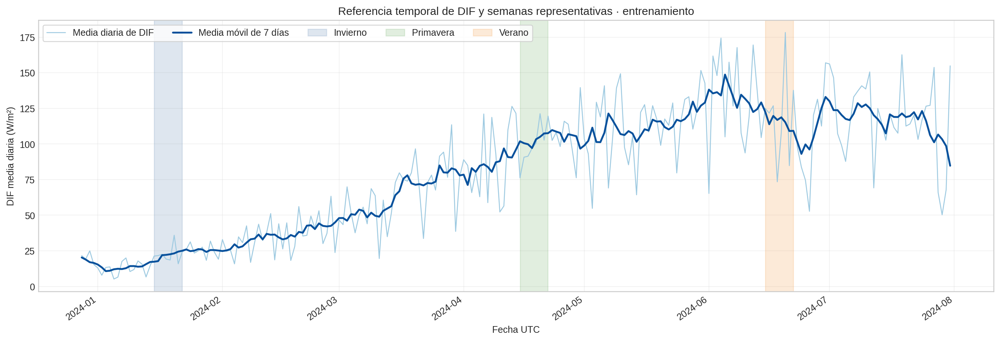

01_SWD__media_h_series_globales.png


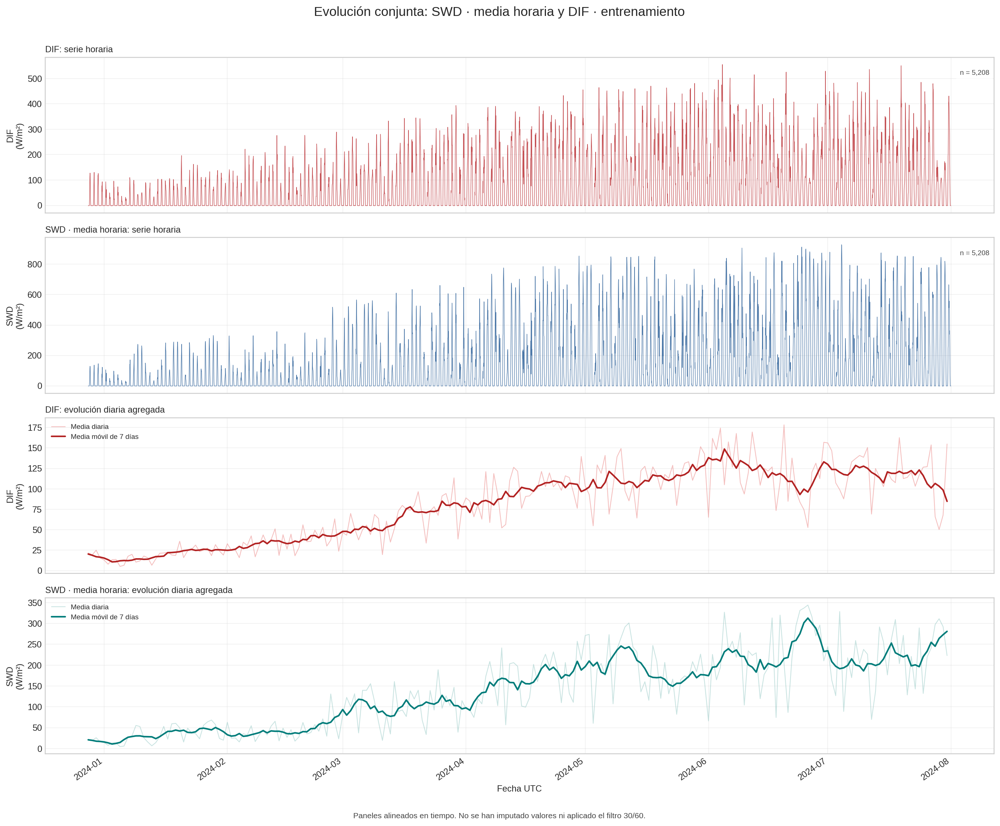

01_SWD__media_h_forma_y_ventanas.png


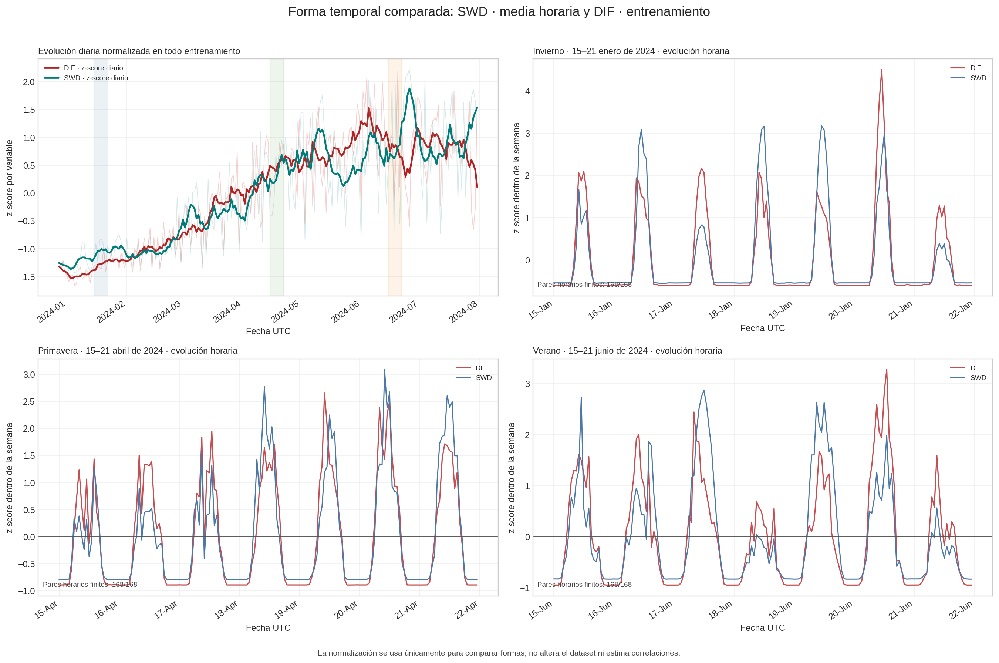

02_SWD__min_h_series_globales.png


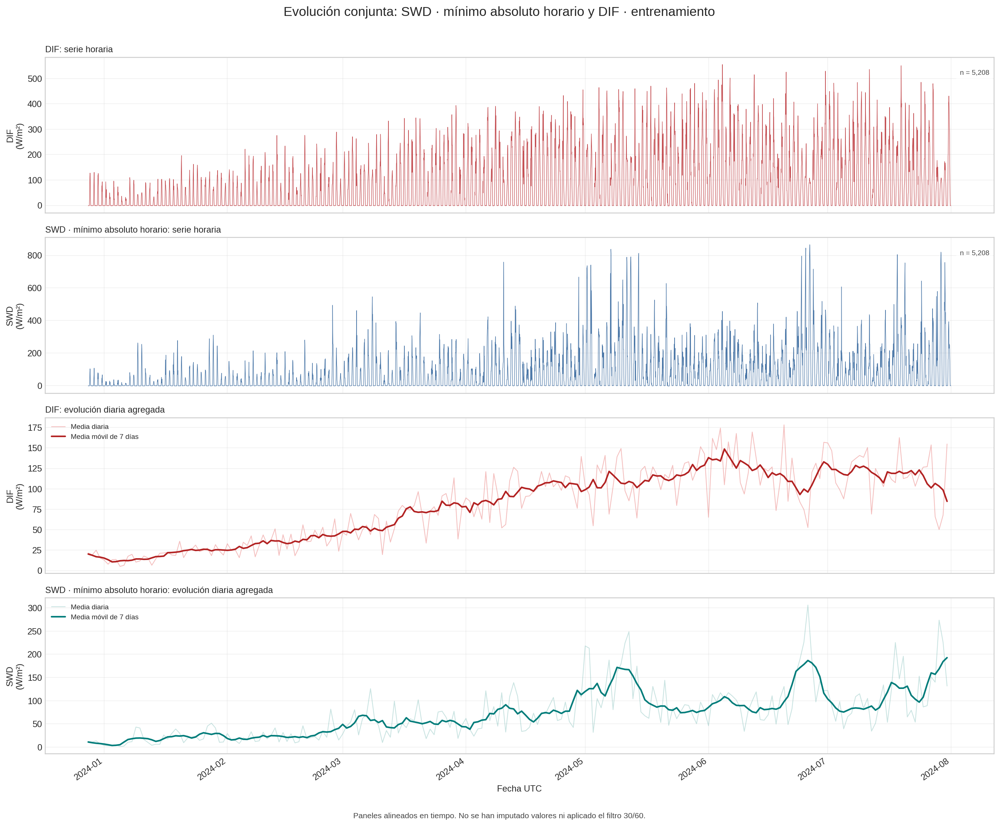

02_SWD__min_h_forma_y_ventanas.png


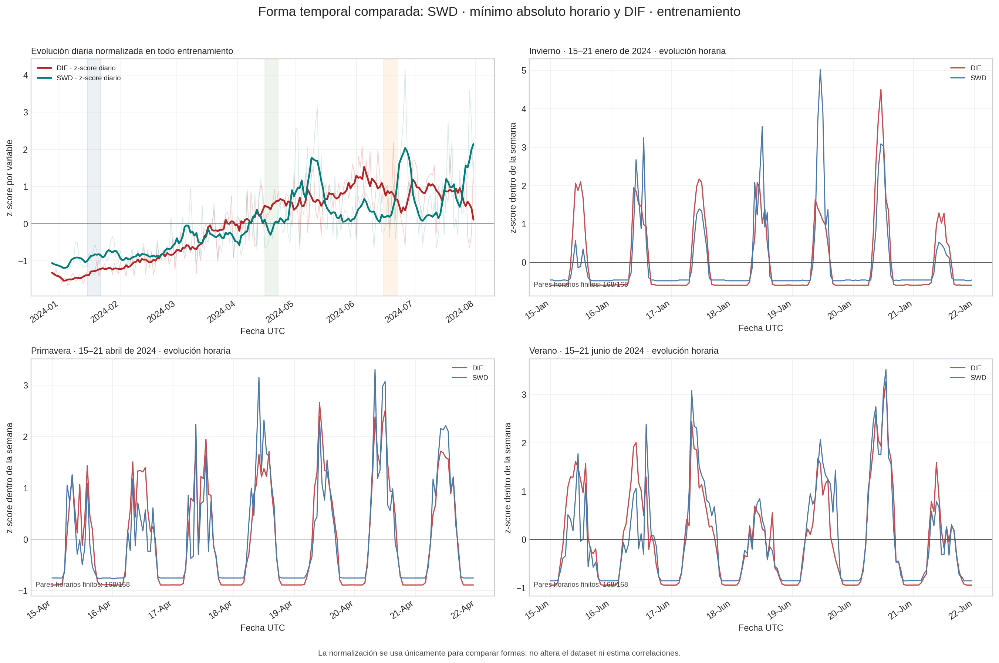

=== ZIP ===
Nombre: evolucion_conjunta_Cabauw_20261102T170514Z_f0ae5c21.zip
Tamaño: 38.10 MiB
SHA-256: 0cdec62f047211d7b3901b8997bfcec6bffea07ce610006a59485a84bdaf2ec6
Integridad: CORRECTA


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
# Evolución conjunta durante todo entrenamiento: X(t) ↔ DIF(t)
import sys
import subprocess
import importlib.util

def instalar_si_falta(modulo, paquete):
    if importlib.util.find_spec(modulo) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])

instalar_si_falta("pyarrow", "pyarrow")
import io
import hashlib
import json
import os
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
try:
    from IPython.display import Image, display
except ImportError:
    class Image:
        def __init__(self, filename):
            self.filename = filename

    def display(value):
        print(value)

try:
    from google.colab import files
    EN_COLAB = True
except ImportError:
    files = None
    EN_COLAB = False


# 1. Contrato de la subsección

# Se prioriza el checkpoint generado por 4.2.1, pero se permite el de 4.1.2
# para que el análisis sea reproducible aunque se ejecute de forma aislada.
CHECKPOINT_PRIORITARIO = "checkpoints/11_tabla_horaria_con_geometria_solar_sin_cambios.parquet"
COLUMNAS_CHECKPOINT_ALTERNATIVAS = [
    "checkpoints/10_tabla_horaria_con_geometria_solar.parquet",
    "checkpoints/10_tabla_horaria_con_geometria_solar_sin_cambios.parquet",
]
PARTICION_ANALIZADA = "train"
COLUMNA_OBJETIVO = "DIF__media_h"
VENTANA_SUAVIZADO_DIAS = 7

# Semanas fijas, completas y contenidas en el entrenamiento. Se eligen como
# muestras visuales; no se usan para calcular correlaciones ni para filtrar datos.
VENTANAS_ESTACIONALES = [
    {
        "id": "invierno",
        "etiqueta": "Invierno · 15–21 enero de 2024",
        "inicio": "2024-01-15 00:00:00+00:00",
        "fin": "2024-01-21 23:00:00+00:00",
        "color": "#4C78A8",
    },
    {
        "id": "primavera",
        "etiqueta": "Primavera · 15–21 abril de 2024",
        "inicio": "2024-04-15 00:00:00+00:00",
        "fin": "2024-04-21 23:00:00+00:00",
        "color": "#59A14F",
    },
    {
        "id": "verano",
        "etiqueta": "Verano · 15–21 junio de 2024",
        "inicio": "2024-06-15 00:00:00+00:00",
        "fin": "2024-06-21 23:00:00+00:00",
        "color": "#F28E2B",
    },
]
FAMILIAS_RADIOMETRICAS = ["SWD", "DIR", "DIF", "LWD", "SWU", "LWU"]
ESTADISTICOS_RADIOMETRICOS = [
    ("media", "__media_h", "Media horaria"),
    ("min", "__min_h", "Mínimo absoluto horario"),
    ("max", "__max_h", "Máximo absoluto horario"),
    ("std_media", "__std_media_h", "Media horaria de la desviación estándar minutal"),
]
VARIABLES_METEOROLOGICAS = [
    ("T2", "Temperatura a 2 m", "°C"),
    ("RH", "Humedad relativa", "%"),
    ("PoPoPoPo", "Presión atmosférica", "hPa"),
]

# Se muestran solo unas pocas figuras en la salida del notebook; las 53 figuras
# se guardan siempre en el ZIP descargable.
MAX_FIGURAS_MOSTRADAS = 5


# 2. Funciones auxiliares de trazabilidad y carga
def sha256_archivo(ruta, tamano_bloque=1024 * 1024):
    resumen = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        while True:
            bloque = archivo.read(tamano_bloque)
            if not bloque:
                break
            resumen.update(bloque)
    return resumen.hexdigest()

def guardar_csv(tabla, ruta):
    tabla.to_csv(ruta, index=False, encoding="utf-8-sig")

def obtener_entrada():
    if EN_COLAB:
        print("Selecciona el ZIP validado de la subsección 4.2.1 " "(inventario de variables).")
        subidos = files.upload()
        assert len(subidos) == 1, "Selecciona un único archivo ZIP o parquet."
        nombre, contenido = next(iter(subidos.items()))
        return nombre, contenido

    ruta_entrada = os.environ.get("INPUT_EVOLUCION_CONJUNTA_FILE", "").strip()
    assert ruta_entrada, (
        "Fuera de Colab define INPUT_EVOLUCION_CONJUNTA_FILE con la ruta "
        "al ZIP de la subsección 4.2.1."
    )
    ruta = Path(ruta_entrada).expanduser().resolve()
    assert ruta.is_file(), f"No existe el archivo: {ruta}"
    return ruta.name, ruta.read_bytes()

def elegir_checkpoint_parquet(nombres):
    candidatos = [nombre for nombre in nombres if nombre.lower().endswith(".parquet")]
    assert candidatos, "El ZIP no contiene ningún checkpoint parquet."
    prioridades = [CHECKPOINT_PRIORITARIO, *COLUMNAS_CHECKPOINT_ALTERNATIVAS]

    def prioridad(nombre):
        normalizado = nombre.lower()
        for posicion, esperado in enumerate(prioridades):
            if normalizado == esperado.lower():
                return posicion
        if "tabla_horaria_con_geometria_solar" in normalizado:
            return len(prioridades)
        if "tabla_horaria" in normalizado:
            return len(prioridades) + 1
        return len(prioridades) + 2

    return sorted(candidatos, key=lambda nombre: (prioridad(nombre), nombre))[0]

def cargar_tabla(nombre, contenido):
    if nombre.lower().endswith(".zip"):
        with zipfile.ZipFile(io.BytesIO(contenido)) as archivo_zip:
            checkpoint = elegir_checkpoint_parquet(archivo_zip.namelist())
            tabla = pd.read_parquet(io.BytesIO(archivo_zip.read(checkpoint)))
        return tabla, checkpoint

    if nombre.lower().endswith(".parquet"):
        return pd.read_parquet(io.BytesIO(contenido)), nombre

    raise AssertionError("La entrada debe ser un ZIP o parquet horario válido.")

def detectar_columna_particion(columnas):
    for candidata in ["particion_observacion", "particion", "partition", "split"]:
        if candidata in columnas:
            return candidata
    for columna in columnas:
        if "particion" in str(columna).lower() or "partition" in str(columna).lower():
            return columna
    return None

def detectar_columna_temporal(columnas):
    candidatas = ["Date/Time", "timestamp_utc", "timestamp", "fecha_hora", "datetime", "date_time"]
    for candidata in candidatas:
        if candidata in columnas:
            return candidata
    for columna in columnas:
        nombre = str(columna).lower().replace(" ", "")
        if "date" in nombre and "time" in nombre:
            return columna
        if "timestamp" in nombre:
            return columna
    return None

def crear_inventario_archivos(ruta_base):
    filas = []
    for ruta in sorted(Path(ruta_base).rglob("*")):
        if ruta.is_file():
            filas.append(
                {
                    "archivo": str(ruta.relative_to(ruta_base)),
                    "tamano_bytes": ruta.stat().st_size,
                    "sha256": sha256_archivo(ruta),
                }
            )
    return pd.DataFrame(filas)


# 3. Inventario explícito y convenciones de agregación
def construir_especificacion():
    especificacion = []
    for familia in FAMILIAS_RADIOMETRICAS:
        for estadistico, sufijo, descripcion in ESTADISTICOS_RADIOMETRICOS:
            columna = f"{familia}{sufijo}"
            especificacion.append(
                {
                    "familia": familia,
                    "tipo": "radiométrica",
                    "estadistico": estadistico,
                    "descripcion": descripcion,
                    "columna_horaria": columna,
                    "etiqueta": f"{familia} · {descripcion.lower()}",
                    "unidad": "W/m²",
                    "es_objetivo": columna == COLUMNA_OBJETIVO,
                }
            )

    for familia, descripcion, unidad in VARIABLES_METEOROLOGICAS:
        columna = f"{familia}__media_h"
        especificacion.append(
            {
                "familia": familia,
                "tipo": "meteorológica",
                "estadistico": "media",
                "descripcion": f"Media horaria de {descripcion.lower()}",
                "columna_horaria": columna,
                "etiqueta": f"{familia} · media horaria",
                "unidad": unidad,
                "es_objetivo": False,
            }
        )

    return pd.DataFrame(especificacion)

def zscore(serie):
    """Estandariza sin imputar; devuelve NaN si no hay variación suficiente."""
    serie = pd.to_numeric(serie, errors="coerce")
    centro = serie.mean(skipna=True)
    escala = serie.std(skipna=True, ddof=0)
    if not np.isfinite(escala) or escala <= np.finfo(float).eps:
        return pd.Series(np.nan, index=serie.index, dtype=float)
    return (serie - centro) / escala

def agregar_diario(tabla, columna_temporal, columnas):
    """Media diaria de los valores horarios disponibles; no rellena huecos."""
    auxiliar = tabla[[columna_temporal, *columnas]].copy()
    auxiliar = auxiliar.set_index(columna_temporal)
    for columna in columnas:
        auxiliar[columna] = pd.to_numeric(auxiliar[columna], errors="coerce")
    return auxiliar.groupby(pd.Grouper(freq="D")).mean()

def anotar_n_finito(eje, serie, prefijo="n"):
    n_finito = int(np.isfinite(pd.to_numeric(serie, errors="coerce")).sum())
    eje.text(
        0.995,
        0.92,
        f"{prefijo} = {n_finito:,}",
        transform=eje.transAxes,
        ha="right",
        va="top",
        fontsize=8,
        color="#444444",
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.75},
    )

def estilizar_eje_tiempo(eje, mostrar_etiquetas=True):
    eje.grid(alpha=0.25)
    eje.xaxis.set_major_locator(mdates.MonthLocator())
    eje.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    if mostrar_etiquetas:
        plt.setp(eje.get_xticklabels(), rotation=35, ha="right")
    else:
        eje.tick_params(labelbottom=False)

def mascara_ventana(tabla, columna_temporal, inicio, fin):
    inicio = pd.Timestamp(inicio)
    fin = pd.Timestamp(fin)
    return tabla[columna_temporal].between(inicio, fin, inclusive="both")


# 4. Carga, validación y preparación diagnóstica
especificacion = construir_especificacion()
assert len(especificacion) == 27, "El inventario debe contener exactamente 27 variables."
assert especificacion["columna_horaria"].is_unique, "Hay variables duplicadas."
nombre_entrada, bytes_entrada = obtener_entrada()
df_original, checkpoint_utilizado = cargar_tabla(nombre_entrada, bytes_entrada)
columna_particion = detectar_columna_particion(df_original.columns)
columna_temporal_original = detectar_columna_temporal(df_original.columns)
assert columna_particion is not None, "No se encontró la columna de partición."
assert columna_temporal_original is not None, "No se encontró una columna temporal."
columnas_necesarias = especificacion["columna_horaria"].tolist()
columnas_faltantes = sorted(set(columnas_necesarias) - set(df_original.columns))
assert not columnas_faltantes, "Faltan variables requeridas: " + ", ".join(columnas_faltantes)
mascara_train = (
    df_original[columna_particion].astype(str).str.strip().str.lower().eq(PARTICION_ANALIZADA)
)
assert mascara_train.any(), "No se encontraron registros de entrenamiento."

# Copia diagnóstica: localizar UTC y ordenar únicamente para representar series.
# El checkpoint final conserva df_original sin eliminar ni imputar valores.
df_train = df_original.loc[mascara_train].copy()
df_train["__timestamp_utc_diagnostico"] = pd.to_datetime(
    df_train[columna_temporal_original], errors="coerce", utc=True
)
assert (
    df_train["__timestamp_utc_diagnostico"].notna().all()
), "Hay timestamps de entrenamiento no interpretables."
df_train = df_train.sort_values("__timestamp_utc_diagnostico").reset_index(drop=True)
assert (
    not df_train["__timestamp_utc_diagnostico"].duplicated().any()
), "Hay timestamps duplicados en entrenamiento."
saltos = df_train["__timestamp_utc_diagnostico"].diff().dropna()
n_saltos_no_horarios = int((saltos != pd.Timedelta(hours=1)).sum())
for columna in columnas_necesarias:
    df_train[columna] = pd.to_numeric(df_train[columna], errors="coerce")

columnas_analisis = [
    COLUMNA_OBJETIVO,
    *[columna for columna in columnas_necesarias if columna != COLUMNA_OBJETIVO],
]
df_diario = agregar_diario(df_train, "__timestamp_utc_diagnostico", columnas_analisis).reset_index()
df_diario.rename(columns={"__timestamp_utc_diagnostico": "fecha_utc"}, inplace=True)
df_diario_indice = df_diario.set_index("fecha_utc")
objetivo_diario_z = zscore(df_diario_indice[COLUMNA_OBJETIVO])


# 5. Directorios de salida y tablas de respaldo
marca_tiempo = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
identificador = uuid.uuid4().hex
if EN_COLAB:
    raiz_salida = Path(".")
else:
    raiz_salida = Path(os.environ.get("OUTPUT_BASE_4_2_2", ".")).expanduser().resolve()

directorio = raiz_salida / f"F4_S2_2_{marca_tiempo}_{identificador[-8:]}"
directorio_figuras = directorio / "figuras"
directorio_global = directorio_figuras / "01_globales_y_diarias"
directorio_ventanas = directorio_figuras / "02_normalizadas_y_ventanas"
directorio_tablas = directorio / "tablas"
directorio_checkpoint = directorio / "checkpoints"
directorio_configuracion = directorio / "configuracion"
for ruta in [
    directorio_global,
    directorio_ventanas,
    directorio_tablas,
    directorio_checkpoint,
    directorio_configuracion,
]:
    ruta.mkdir(parents=True, exist_ok=True)

filas_ventanas = []
for ventana in VENTANAS_ESTACIONALES:
    mascara = mascara_ventana(
        df_train, "__timestamp_utc_diagnostico", ventana["inicio"], ventana["fin"]
    )
    n_horas = int(mascara.sum())
    assert (
        n_horas == 168
    ), f"La ventana {ventana['id']} debe contener 168 horas; contiene {n_horas}."
    filas_ventanas.append(
        {
            "id": ventana["id"],
            "etiqueta": ventana["etiqueta"],
            "inicio_utc": ventana["inicio"],
            "fin_utc": ventana["fin"],
            "n_horas": n_horas,
            "uso": "muestra visual representativa; no filtra ni estima correlaciones",
        }
    )
tabla_ventanas = pd.DataFrame(filas_ventanas)
filas_cobertura = []
for registro in especificacion.to_dict(orient="records"):
    columna = registro["columna_horaria"]
    x = df_train[columna]
    y = df_train[COLUMNA_OBJETIVO]
    parejas_finitas = np.isfinite(x.to_numpy()) & np.isfinite(y.to_numpy())
    filas_cobertura.append(
        {
            "columna_horaria": columna,
            "etiqueta": registro["etiqueta"],
            "tipo": registro["tipo"],
            "es_objetivo": registro["es_objetivo"],
            "n_horas_train": len(df_train),
            "n_finitos_variable": int(np.isfinite(x.to_numpy()).sum()),
            "n_pares_finitos_con_DIF": int(parejas_finitas.sum()),
            "pct_pares_finitos_con_DIF": 100 * parejas_finitas.mean(),
        }
    )
tabla_cobertura = pd.DataFrame(filas_cobertura)


# 6. Figura de referencia: objetivo y ventanas estacionales
fig, ax = plt.subplots(figsize=(15, 5.2))
serie_objetivo_diaria = df_diario_indice[COLUMNA_OBJETIVO]
suavizado_objetivo = serie_objetivo_diaria.rolling(
    VENTANA_SUAVIZADO_DIAS, center=True, min_periods=3
).mean()
ax.plot(
    serie_objetivo_diaria.index,
    serie_objetivo_diaria,
    color="#9ecae1",
    linewidth=1.0,
    label="Media diaria de DIF",
)
ax.plot(
    suavizado_objetivo.index,
    suavizado_objetivo,
    color="#08519c",
    linewidth=2.0,
    label=f"Media móvil de {VENTANA_SUAVIZADO_DIAS} días",
)
for ventana in VENTANAS_ESTACIONALES:
    ax.axvspan(
        pd.Timestamp(ventana["inicio"]),
        pd.Timestamp(ventana["fin"]),
        color=ventana["color"],
        alpha=0.18,
        label=ventana["id"].capitalize(),
    )
ax.set_title("Referencia temporal de DIF y semanas representativas · entrenamiento")
ax.set_ylabel("DIF media diaria (W/m²)")
ax.set_xlabel("Fecha UTC")
estilizar_eje_tiempo(ax)
ax.legend(ncol=5, loc="upper left", frameon=True)
fig.tight_layout()
ruta_referencia = directorio_figuras / "00_referencia_DIF_y_ventanas_estacionales.png"
fig.savefig(ruta_referencia, dpi=180, bbox_inches="tight")
plt.close(fig)


# 7. Figuras individuales: 26 comparaciones X(t) ↔ DIF(t)
colores = {
    "dif": "#C44E52",
    "x": "#4C78A8",
    "dif_diario": "#E45756",
    "x_diario": "#72B7B2",
    "suavizado_dif": "#B22222",
    "suavizado_x": "#007C7A",
}
comparaciones = especificacion.loc[~especificacion["es_objetivo"]].copy()
indice_figuras = []
for posicion, registro in enumerate(comparaciones.to_dict(orient="records"), start=1):
    columna_x = registro["columna_horaria"]
    etiqueta_x = registro["etiqueta"]
    unidad_x = registro["unidad"]
    identificador_archivo = f"{posicion:02d}_{columna_x}"

    # Figura A: series completas horarias y evolución diaria agregada.
    # Los paneles de cada pareja comparten eje temporal, no escala vertical.
    fig, ejes = plt.subplots(4, 1, figsize=(16, 13), sharex=True)
    fig.suptitle(f"Evolución conjunta: {etiqueta_x} y DIF · entrenamiento", fontsize=15, y=0.995)
    ejes[0].plot(
        df_train["__timestamp_utc_diagnostico"],
        df_train[COLUMNA_OBJETIVO],
        color=colores["dif"],
        linewidth=0.55,
    )
    ejes[0].set_ylabel("DIF\n(W/m²)")
    ejes[0].set_title("DIF: serie horaria", loc="left", fontsize=10)
    anotar_n_finito(ejes[0], df_train[COLUMNA_OBJETIVO])
    ejes[1].plot(
        df_train["__timestamp_utc_diagnostico"],
        df_train[columna_x],
        color=colores["x"],
        linewidth=0.55,
    )
    ejes[1].set_ylabel(f"{registro['familia']}\n({unidad_x})")
    ejes[1].set_title(f"{etiqueta_x}: serie horaria", loc="left", fontsize=10)
    anotar_n_finito(ejes[1], df_train[columna_x])
    objetivo_diario = df_diario_indice[COLUMNA_OBJETIVO]
    x_diario = df_diario_indice[columna_x]
    ejes[2].plot(
        objetivo_diario.index,
        objetivo_diario,
        color=colores["dif_diario"],
        alpha=0.38,
        linewidth=0.9,
        label="Media diaria",
    )
    ejes[2].plot(
        objetivo_diario.index,
        objetivo_diario.rolling(VENTANA_SUAVIZADO_DIAS, center=True, min_periods=3).mean(),
        color=colores["suavizado_dif"],
        linewidth=1.8,
        label=f"Media móvil de {VENTANA_SUAVIZADO_DIAS} días",
    )
    ejes[2].set_ylabel("DIF\n(W/m²)")
    ejes[2].set_title("DIF: evolución diaria agregada", loc="left", fontsize=10)
    ejes[2].legend(loc="upper left", fontsize=8)
    ejes[3].plot(
        x_diario.index,
        x_diario,
        color=colores["x_diario"],
        alpha=0.38,
        linewidth=0.9,
        label="Media diaria",
    )
    ejes[3].plot(
        x_diario.index,
        x_diario.rolling(VENTANA_SUAVIZADO_DIAS, center=True, min_periods=3).mean(),
        color=colores["suavizado_x"],
        linewidth=1.8,
        label=f"Media móvil de {VENTANA_SUAVIZADO_DIAS} días",
    )
    ejes[3].set_ylabel(f"{registro['familia']}\n({unidad_x})")
    ejes[3].set_title(f"{etiqueta_x}: evolución diaria agregada", loc="left", fontsize=10)
    ejes[3].legend(loc="upper left", fontsize=8)
    ejes[3].set_xlabel("Fecha UTC")
    for indice_eje, eje in enumerate(ejes):
        estilizar_eje_tiempo(eje, mostrar_etiquetas=indice_eje == len(ejes) - 1)
    fig.text(
        0.5,
        0.003,
        "Paneles alineados en tiempo. No se han imputado valores ni aplicado el filtro 30/60.",
        ha="center",
        fontsize=9,
        color="#444444",
    )
    fig.tight_layout(rect=(0, 0.02, 1, 0.985))
    ruta_global = directorio_global / f"{identificador_archivo}_series_globales.png"
    fig.savefig(ruta_global, dpi=170, bbox_inches="tight")
    plt.close(fig)

    # Figura B: forma temporal normalizada y tres semanas estacionales.
    # La normalización es descriptiva, se hace por separado para cada serie y
    # no se usa como preprocesamiento del dataset original.
    fig, ejes = plt.subplots(2, 2, figsize=(16, 10.5))
    fig.suptitle(
        f"Forma temporal comparada: {etiqueta_x} y DIF · entrenamiento", fontsize=15, y=0.99
    )
    eje_global = ejes.flat[0]
    x_diario_z = zscore(x_diario)
    eje_global.plot(
        objetivo_diario_z.index,
        objetivo_diario_z,
        color=colores["dif_diario"],
        alpha=0.28,
        linewidth=0.8,
    )
    eje_global.plot(
        objetivo_diario_z.index,
        objetivo_diario_z.rolling(VENTANA_SUAVIZADO_DIAS, center=True, min_periods=3).mean(),
        color=colores["suavizado_dif"],
        linewidth=2.0,
        label="DIF · z-score diario",
    )
    eje_global.plot(
        x_diario_z.index, x_diario_z, color=colores["x_diario"], alpha=0.28, linewidth=0.8
    )
    eje_global.plot(
        x_diario_z.index,
        x_diario_z.rolling(VENTANA_SUAVIZADO_DIAS, center=True, min_periods=3).mean(),
        color=colores["suavizado_x"],
        linewidth=2.0,
        label=f"{registro['familia']} · z-score diario",
    )
    for ventana in VENTANAS_ESTACIONALES:
        eje_global.axvspan(
            pd.Timestamp(ventana["inicio"]),
            pd.Timestamp(ventana["fin"]),
            color=ventana["color"],
            alpha=0.10,
        )
    eje_global.axhline(0, color="#555555", linewidth=0.8)
    eje_global.set_title(
        "Evolución diaria normalizada en todo entrenamiento", loc="left", fontsize=10
    )
    eje_global.set_ylabel("z-score por variable")
    eje_global.set_xlabel("Fecha UTC")
    eje_global.legend(loc="upper left", fontsize=8)
    estilizar_eje_tiempo(eje_global)
    for eje, ventana in zip(ejes.flat[1:], VENTANAS_ESTACIONALES):
        mascara = mascara_ventana(
            df_train, "__timestamp_utc_diagnostico", ventana["inicio"], ventana["fin"]
        )
        subtabla = df_train.loc[
            mascara, ["__timestamp_utc_diagnostico", COLUMNA_OBJETIVO, columna_x]
        ].copy()
        objetivo_ventana_z = zscore(subtabla[COLUMNA_OBJETIVO])
        x_ventana_z = zscore(subtabla[columna_x])
        eje.plot(
            subtabla["__timestamp_utc_diagnostico"],
            objetivo_ventana_z,
            color=colores["dif"],
            linewidth=1.35,
            label="DIF",
        )
        eje.plot(
            subtabla["__timestamp_utc_diagnostico"],
            x_ventana_z,
            color=colores["x"],
            linewidth=1.25,
            label=registro["familia"],
        )
        eje.axhline(0, color="#555555", linewidth=0.8)
        eje.set_title(f"{ventana['etiqueta']} · evolución horaria", loc="left", fontsize=10)
        eje.set_ylabel("z-score dentro de la semana")
        eje.set_xlabel("Fecha UTC")
        eje.grid(alpha=0.25)
        eje.xaxis.set_major_locator(mdates.DayLocator(interval=1))
        eje.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
        plt.setp(eje.get_xticklabels(), rotation=35, ha="right")
        eje.legend(loc="upper right", fontsize=8)
        n_pares = int(
            (
                np.isfinite(subtabla[COLUMNA_OBJETIVO].to_numpy())
                & np.isfinite(subtabla[columna_x].to_numpy())
            ).sum()
        )
        eje.text(
            0.01,
            0.04,
            f"Pares horarios finitos: {n_pares}/168",
            transform=eje.transAxes,
            fontsize=8,
            color="#444444",
        )

    fig.text(
        0.5,
        0.007,
        "La normalización se usa únicamente para comparar formas; no altera el dataset ni estima correlaciones.",
        ha="center",
        fontsize=9,
        color="#444444",
    )
    fig.tight_layout(rect=(0, 0.025, 1, 0.975))
    ruta_ventanas = directorio_ventanas / f"{identificador_archivo}_forma_y_ventanas.png"
    fig.savefig(ruta_ventanas, dpi=170, bbox_inches="tight")
    plt.close(fig)
    indice_figuras.extend(
        [
            {
                "orden": len(indice_figuras) + 1,
                "columna_x": columna_x,
                "etiqueta_x": etiqueta_x,
                "tipo_figura": "series_globales_y_diarias",
                "archivo": str(ruta_global.relative_to(directorio)),
            },
            {
                "orden": len(indice_figuras) + 2,
                "columna_x": columna_x,
                "etiqueta_x": etiqueta_x,
                "tipo_figura": "forma_normalizada_y_ventanas",
                "archivo": str(ruta_ventanas.relative_to(directorio)),
            },
        ]
    )


# 8. Salida trazable, sin modificaciones de los datos de entrada
ruta_checkpoint = directorio_checkpoint / "12_tabla_horaria_con_geometria_solar_sin_cambios.parquet"
df_original.to_parquet(ruta_checkpoint, index=False)
guardar_csv(tabla_ventanas, directorio_tablas / "01_ventanas_estacionales_representativas.csv")
guardar_csv(tabla_cobertura, directorio_tablas / "02_cobertura_pares_con_DIF_train.csv")
guardar_csv(df_diario, directorio_tablas / "03_evolucion_diaria_media_27_variables_train.csv")
guardar_csv(pd.DataFrame(indice_figuras), directorio_tablas / "04_indice_figuras.csv")
advertencias = pd.DataFrame(
    [
        {
            "id": "E221",
            "advertencia": "Las figuras describen coincidencia temporal, no causalidad ni capacidad predictiva.",
            "decision": "La selección de predictores y el horizonte t→t+1 se estudian en una fase posterior.",
        },
        {
            "id": "E222",
            "advertencia": "DIF mínimo, máximo y desviación estándar comparten mediciones de origen con DIF media.",
            "decision": "Su comparación contemporánea es descriptiva; su posible utilidad predictiva solo se evaluará con variables retrasadas.",
        },
        {
            "id": "E223",
            "advertencia": "La normalización z-score cambia la escala visual.",
            "decision": "Se usa exclusivamente para comparar formas temporales; las series originales permanecen en las figuras A y en el checkpoint.",
        },
        {
            "id": "E224",
            "advertencia": "El criterio 30/60 puede modificar la composición de las observaciones disponibles.",
            "decision": "No se aplica en esta subsección; se analizará explícitamente como sensibilidad en 4.2.10.",
        },
    ]
)
guardar_csv(advertencias, directorio_tablas / "05_advertencias_interpretacion.csv")
resumen = pd.DataFrame(
    [
        {
            "particion_analizada": PARTICION_ANALIZADA,
            "n_horas_train": len(df_train),
            "n_dias_train": len(df_diario),
            "n_variables_inventario": len(especificacion),
            "n_comparaciones_individuales": len(comparaciones),
            "n_figuras_generadas": 1 + 2 * len(comparaciones),
            "n_saltos_no_horarios_train": n_saltos_no_horarios,
            "filtro_30_60_aplicado": False,
            "filas_eliminadas": 0,
            "valores_imputados": 0,
        }
    ]
)
guardar_csv(resumen, directorio_tablas / "06_resumen_tecnico.csv")
configuracion = {
    "subseccion": "4.2.2_evolucion_conjunta_durante_entrenamiento",
    "entrada": nombre_entrada,
    "checkpoint_entrada": checkpoint_utilizado,
    "checkpoint_salida": str(ruta_checkpoint.name),
    "particion_analizada": PARTICION_ANALIZADA,
    "objetivo_contemporaneo": COLUMNA_OBJETIVO,
    "n_variables": int(len(especificacion)),
    "n_comparaciones": int(len(comparaciones)),
    "agregacion_diaria": "media de valores horarios finitos; sin imputación",
    "suavizado_diario": f"media móvil centrada de {VENTANA_SUAVIZADO_DIAS} días",
    "normalizacion": "z-score separado por serie; solo para visualización",
    "ventanas_estacionales": [
        {clave: valor for clave, valor in ventana.items() if clave != "color"}
        for ventana in VENTANAS_ESTACIONALES
    ],
    "n_saltos_no_horarios_train": n_saltos_no_horarios,
    "filtro_30_60_aplicado": False,
    "filas_eliminadas": 0,
    "valores_imputados": 0,
}
with (directorio_configuracion / "configuracion_4_2_2.json").open("w", encoding="utf-8") as archivo:
    json.dump(configuracion, archivo, ensure_ascii=False, indent=2)

readme = f"""# Subsección 4.2.2 · Evolución conjunta durante entrenamiento

## Objetivo

Se generan comparaciones visuales de las 26 variables X frente a `{COLUMNA_OBJETIVO}` en la partición de entrenamiento. El análisis es contemporáneo: X(t) ↔ DIF(t). No estima causalidad ni poder predictivo a una hora vista.

## Figuras generadas

- una figura de referencia con la evolución diaria de DIF y las tres semanas seleccionadas;
- para cada variable X, una figura con series horarias alineadas y evolución diaria agregada;
- para cada variable X, una figura con superposición normalizada y semanas de invierno, primavera y verano.

La agregación diaria es la media de los valores horarios disponibles. La normalización z-score se aplica por separado a cada serie únicamente para comparar su forma; no modifica el checkpoint.

## Integridad y alcance

No se eliminan filas, no se imputan valores y no se aplica el criterio 30/60. Las semanas estacionales son muestras visuales fijas de 168 horas y no se emplean como filtros ni para estimar correlaciones.

Las variables de geometría solar se conservan en el checkpoint, pero se utilizarán específicamente en la subsección 4.2.8 para separar regímenes solares.
"""
(directorio / "README.md").write_text(readme, encoding="utf-8")
inventario_archivos = crear_inventario_archivos(directorio)
guardar_csv(inventario_archivos, directorio / "inventario_archivos.csv")
ruta_zip = raiz_salida / f"evolucion_conjunta_Cabauw_{marca_tiempo}_{identificador[-8:]}.zip"
with zipfile.ZipFile(ruta_zip, "w", compression=zipfile.ZIP_DEFLATED) as archivo_zip:
    for ruta in sorted(directorio.rglob("*")):
        if ruta.is_file():
            archivo_zip.write(ruta, arcname=str(ruta.relative_to(directorio)))

with zipfile.ZipFile(ruta_zip) as archivo_zip:
    assert archivo_zip.testzip() is None, "El ZIP generado contiene un archivo dañado."


# 9. Resumen visible y descarga
print("=== RESUMEN TÉCNICO 4.2.2 ===")
print(f"Checkpoint de entrada: {checkpoint_utilizado}")
print(f"Partición analizada: {PARTICION_ANALIZADA}")
print(f"Horas de entrenamiento: {len(df_train):,}")
print(f"Comparaciones X(t) ↔ DIF(t): {len(comparaciones)}")
print(f"Figuras generadas: {1 + 2 * len(comparaciones)}")
print(f"Saltos no horarios detectados: {n_saltos_no_horarios}")
print("Filas eliminadas: 0")
print("Valores imputados: 0")
print("Criterio 30/60 aplicado como descarte: NO")
print()
display(resumen)
display(tabla_ventanas)
print("=== MUESTRA DE FIGURAS ===")
rutas_muestra = [ruta_referencia]
for fila in indice_figuras[: MAX_FIGURAS_MOSTRADAS - 1]:
    rutas_muestra.append(directorio / fila["archivo"])
for ruta in rutas_muestra:
    print(ruta.name)
    display(Image(filename=str(ruta)))

print("=== ZIP ===")
print(f"Nombre: {ruta_zip.name}")
print(f"Tamaño: {ruta_zip.stat().st_size / (1024 ** 2):.2f} MiB")
print(f"SHA-256: {sha256_archivo(ruta_zip)}")
print("Integridad: CORRECTA")
if EN_COLAB:
    files.download(str(ruta_zip))

**Resultados.**

En esta subsección se estudió la evolución contemporánea de las variables horarias disponibles en la partición de entrenamiento, comprendida entre el 28 de diciembre de 2023 y el 31 de julio de 2024. El objetivo de referencia fue la media horaria de irradiancia difusa, `DIF__media_h`, que se comparó con las otras 26 variables del inventario: estadísticos horarios de las seis familias radiométricas (`SWD`, `DIR`, `DIF`, `LWD`, `SWU` y `LWU`) y las variables meteorológicas `T2`, `RH` y `PoPoPoPo`.

El análisis tuvo carácter exclusivamente descriptivo y contemporáneo, es decir, se examinaron relaciones de la forma X(t) ↔ DIF(t). Por tanto, sus resultados permiten identificar patrones temporales compartidos, comportamientos opuestos y posibles señales físicas de interés, pero no constituyen todavía evidencia de causalidad ni de capacidad predictiva para estimar DIF(t+1).

Para cada variable se representaron las series horarias alineadas con `DIF`, sus medias diarias y una media móvil centrada de siete días. Este suavizado se empleó únicamente para facilitar la lectura de la evolución de escala diaria; no presupone la existencia de un ciclo físico semanal ni se utilizó para modificar los datos. Asimismo, se utilizaron representaciones normalizadas mediante puntuaciones *z* con el único objetivo de comparar la forma temporal de variables expresadas en unidades y escalas diferentes. La normalización fue exclusivamente gráfica y no alteró el conjunto de datos ni intervino en la construcción de variables posteriores.

Como complemento visual se incluyeron tres intervalos fijos de 168 horas correspondientes a enero, abril y junio de 2024. Estas semanas no se consideraron muestras estadísticamente representativas de cada estación, sino ejemplos ilustrativos de invierno, primavera y verano para facilitar la inspección de la dinámica horaria en periodos concretos. Durante toda la subsección no se eliminaron filas, no se imputaron valores y no se aplicó el criterio de disponibilidad 30/60 como filtro de exclusión.

### Evolución estacional de la irradiancia difusa

La media diaria de `DIF` muestra un incremento progresivo desde el invierno hacia el verano. La media mensual de entrenamiento pasa de 18,7 W/m² en enero a 120,8 W/m² en junio, con un valor ligeramente inferior en julio, de 117,3 W/m². Esta evolución es coherente con el aumento gradual de la duración del día geométrico y de la elevación solar calculada para Cabauw.

No obstante, la tendencia estacional no explica por sí sola toda la variabilidad observada. Sobre ella aparecen oscilaciones diarias y semanales de gran amplitud, especialmente desde primavera. Por ello, no resulta adecuado interpretar una media elevada de `DIF` como evidencia directa de un único fenómeno meteorológico. La geometría solar establece la radiación potencial disponible, mientras que las observaciones radiométricas permiten describir cómo se reparte esa energía entre las componentes directa y difusa en cada instante.

### Reparto entre radiación directa, global y difusa

El resultado más relevante de la evolución conjunta se observa en la relación entre `DIR`, `SWD` y `DIF`. Durante los meses de verano existen periodos en los que `DIF` es elevado y `DIR` reducido, junto con otros en los que ocurre el patrón contrario. Por ejemplo, el 20 de junio la media diaria de `DIF` alcanzó 178,2 W/m² mientras que la de `DIR` fue de 43,2 W/m². En cambio, el 26 de junio `DIF` descendió a 52,7 W/m² y `DIR` aumentó hasta 466,9 W/m².

Además, la media móvil de siete días de `DIF` alcanzó su máximo el 5 de junio, mientras que las medias móviles de `SWD`, `DIR` y `SWU` alcanzaron sus máximos hacia el 26 de junio. Este desfase confirma que una mayor radiación global disponible no implica necesariamente una mayor proporción de irradiancia difusa. La información relevante no es únicamente la cantidad total de radiación, sino cómo se distribuye entre sus componentes.

Esta observación no permite clasificar directamente los días como despejados o nubosos, ya que el conjunto de datos no contiene una etiqueta independiente de cobertura nubosa. Por tanto, se empleará una terminología prudente: los datos muestran distintos **regímenes radiativos observados**, compatibles con una mayor contribución relativa de la componente directa o de la componente difusa, sin atribuir de forma concluyente cada situación a la nubosidad.

Debe destacarse también que no es correcto imponer directamente la igualdad:


SWD = DIR + DIF

a las variables horarias disponibles. En los datos, `DIR` puede superar a `SWD`, lo que indica que no debe tratarse como una componente ya proyectada sobre el plano horizontal. Tras confirmar formalmente la definición instrumental de `DIR` en la documentación de origen, la relación física deberá evaluarse mediante la proyección geométrica correspondiente, de forma aproximada:

SWD ≈ DIF + DIR·cos(θ<sub>z</sub>)

donde θ<sub>z</sub> representa el ángulo cenital solar. Esta comprobación, si se incorpora, deberá realizarse preferentemente con datos coincidentes a resolución minutal. En consecuencia, no se ha creado ni aplicado ninguna regla de cierre radiativo sobre las medias horarias durante esta subsección.

### Comportamiento de SWU y albedo implícito

`SWU` representa la radiación de onda corta ascendente desde la superficie. Su evolución diaria es casi paralela a la de `SWD`: la correlación descriptiva entre ambas series diarias es 0,995. Por tanto, un valor elevado de `SWU` no puede interpretarse aisladamente como una señal de mayor reflectividad de la superficie ni como evidencia de nubosidad; en gran medida puede deberse simplemente a que está llegando más radiación de onda corta descendente.

La magnitud físicamente más informativa para estudiar la reflectividad superficial sería el cociente:

α ≈ SWU/SWD

siempre que se calcule durante horas con radiación suficiente y evitando situaciones próximas al amanecer, al atardecer o durante la noche. Como diagnóstico preliminar, el cociente diario calculado para días con `SWD` suficiente presenta una mediana aproximada de 0,26. Este resultado sugiere que el albedo implícito puede analizarse como una característica auxiliar, aunque no debe confundirse con la propia señal de nubosidad ni derivarse de `SWU` sin tener en cuenta simultáneamente `SWD`.

A igualdad de radiación incidente, un albedo mayor implica una mayor fracción reflejada y una menor radiación neta de onda corta absorbida por la superficie:

SW<sub>neto</sub> = SWD − SWU

Sin embargo, esta diferencia puede depender de propiedades de la superficie, de la geometría solar y de las condiciones de observación. Por ello, cualquier análisis del albedo se mantendrá separado de la interpretación de la partición directa–difusa.

### Papel de la radiación de onda larga y de las variables meteorológicas

La interpretación de `LWD` requiere distinguir correctamente la dirección de los flujos. `LWD` corresponde a la radiación de onda larga descendente emitida por la atmósfera y el cielo hacia la superficie, mientras que `LWU` representa la radiación de onda larga ascendente emitida principalmente por la superficie. Por tanto, `LWD` no es radiación ascendente “despejada” por las nubes.

Las nubes pueden contribuir a aumentar `LWD`, ya que son emisores de onda larga, pero este flujo también depende de la temperatura del aire, del vapor de agua, del perfil vertical de temperatura y humedad y de las propiedades térmicas del cielo. En consecuencia, una regla del tipo “mayor `LWD` implica más nubes y, por tanto, mayor `DIF`” no está justificada con los datos disponibles.

No obstante, `LWD` sí debe considerarse una variable potencialmente útil. Puede aportar información complementaria sobre el estado radiativo y termodinámico del cielo, especialmente cuando se analiza conjuntamente con `T2` y `RH` y cuando se incorporan retardos temporales. En la evolución diaria actual, la relación entre `LWD` y `DIF` no mantiene un signo estable entre meses, lo que refuerza la necesidad de estudiar relaciones condicionadas por hora, elevación solar y estacionalidad antes de extraer conclusiones predictivas.

Las variables `LWU` y `T2` muestran una evolución estacional ascendente desde el invierno hacia el verano, coherente con el calentamiento progresivo de la superficie y del aire. Sin embargo, este paralelismo temporal no demuestra una relación directa con `DIF`, ya que parte de la coincidencia puede deberse a la estacionalidad compartida. `RH` presenta, de forma general, una evolución estacional opuesta a la de la temperatura, aunque también con variabilidad diaria apreciable.

En el caso de la presión atmosférica (`PoPoPoPo`), no se aprecia una asociación contemporánea estable con `DIF`. La correlación lineal descriptiva entre las medias diarias de ambas variables es próxima a cero (r = 0,033). Por tanto, en esta fase no existe evidencia de una relación simple y persistente entre presión e irradiancia difusa. Esto no excluye una posible contribución no lineal, indirecta o retardada, pero evita asignarle una interpretación física no respaldada por los resultados exploratorios actuales.

### Cambio progresivo de patrones entre primavera y verano

La inspección de las series diarias muestra que las asociaciones entre `DIF` y otras variables no son constantes a lo largo del entrenamiento. Como comprobación descriptiva, la asociación diaria entre `DIF` y `SWD` es positiva en enero y febrero, se debilita durante marzo y abril y pasa a ser prácticamente nula o ligeramente negativa entre mayo y julio. De forma similar, la asociación diaria entre `DIF` y `DIR` se vuelve progresivamente negativa a partir de mayo.

Este resultado no debe interpretarse como un cambio brusco confirmado exactamente en las fechas astronómicas de inicio de estación. La evolución de la geometría solar es continua y los datos solo cubren el periodo comprendido entre invierno y verano. La evidencia observada indica, más prudentemente, que la forma de la relación contemporánea cambia de manera progresiva conforme aumenta la elevación solar, se alarga el periodo diurno y varía el reparto radiativo observado.

Este hallazgo es metodológicamente importante: una correlación global calculada sobre todo el entrenamiento podría mezclar efectos de día y noche, estacionalidad, geometría solar y condiciones radiativas de corto plazo. Por ello, las siguientes subsecciones analizarán los perfiles hora × mes, separarán los resultados por régimen de elevación solar y repetirán los análisis tras retirar parte de la estacionalidad compartida.

### Consideración de las variables derivadas de DIF

Las variables `DIF__min_h`, `DIF__max_h` y `DIF__std_media_h` se mantienen en el inventario porque describen distintos aspectos de la evolución intrahoraria de la irradiancia difusa: extremos observados y variabilidad minutal. Sin embargo, su asociación contemporánea con `DIF__media_h` es estructural, puesto que proceden de las mismas observaciones minutales dentro de la hora. Por tanto, una alta relación contemporánea entre estas variables no debe interpretarse como evidencia de información física independiente.

Esta limitación no implica que dichas variables carezcan de valor predictivo. En una fase posterior podrán evaluarse como predictores retrasados, por ejemplo mediante información disponible hasta el instante *t* para anticipar `DIF(t+1)`. Su utilidad deberá determinarse mediante validación temporal y evitando utilizar información perteneciente a la hora objetivo.

### Conclusión y pregunta guía para el modelado

La evolución conjunta confirma que la irradiancia difusa no puede entenderse únicamente a partir de una tendencia estacional o de una única variable radiométrica. La geometría solar define el nivel potencial de radiación disponible, pero el interés físico y predictivo reside en describir cómo se distribuye dicha energía entre las componentes directa, difusa, reflejada y de onda larga.

La pregunta que guiará las siguientes fases es la siguiente:

> A igualdad de geometría solar, ¿qué señales disponibles en el instante *t* describen el reparto actual entre radiación directa y difusa y permiten anticipar dicho reparto en t+1

En este marco, `SWD`, `DIR`, `DIF` previo, sus estadísticos intrahorarios, `LWD`, `LWU`, `T2`, `RH` y, de forma exploratoria, el albedo implícito, constituyen señales candidatas. No obstante, su contribución deberá evaluarse empíricamente mediante análisis por hora y mes, separación por régimen solar, estudio de relaciones no lineales y análisis de retardos temporales.

### 4.2.3 Perfiles hora × mes

Esta subsección examina si cada variable presenta ciclos diarios y estacionales parecidos, distintos o complementarios a los de `DIF__media_h`. Para DIF y para cada una de las 26 variables se calculan, en una malla hora UTC × mes UTC del entrenamiento, la media, la desviación estándar entre días del mismo mes y hora, el número de observaciones finitas y la cobertura, y se construyen mapas comparables de *X* y DIF sobre las mismas observaciones pareadas. El análisis es contemporáneo, X(t) ↔ DIF(t), y no implica causalidad; la columna de diciembre de 2023 es incompleta porque el entrenamiento comienza el 28 de diciembre.

> *Subsección complementaria: no se utiliza en la memoria. Se mantiene porque genera la entrada de la subsección 4.2.4.*

Selecciona exclusivamente el ZIP validado de la subsección 4.2.2 (evolución conjunta durante entrenamiento).


Saving evolucion_conjunta_Cabauw_20261102T170514Z_f0ae5c21.zip to evolucion_conjunta_Cabauw_20261102T170514Z_f0ae5c21 (1).zip
=== RESUMEN TÉCNICO 4.2.3 ===
Checkpoint de entrada: checkpoints/12_tabla_horaria_con_geometria_solar_sin_cambios.parquet
Partición analizada: train
Horas de entrenamiento: 5,208
Meses UTC analizados: 2023-12, 2024-01, 2024-02, 2024-03, 2024-04, 2024-05, 2024-06, 2024-07
Comparaciones X(t) ↔ DIF(t): 26
Figuras generadas: 28
Saltos no horarios detectados: 0
Filas eliminadas: 0
Valores imputados: 0
Criterio 30/60 aplicado como descarte: NO
Checkpoint de salida verificado idéntico: SÍ



,particion_analizada,n_horas_train,meses_utc_analizados,n_variables_inventario,n_comparaciones_individuales,n_celdas_hora_mes_por_variable,n_figuras_generadas,n_saltos_no_horarios_train,filtro_30_60_aplicado,filas_eliminadas,valores_imputados,checkpoint_salida_verificado_identico
0,train,5208,"2023-12, 2024-01, 2024-02, 2024-03, 2024-04, 2...",27,26,192,28,0,False,0,0,True


,columna_x,etiqueta_x,familia_x,tipo_x,unidad_x,n_celdas_hora_mes,n_pares_finitos,n_horas_estructurales,cobertura_media_pct,cobertura_minima_pct,cobertura_global_pct
0,DIF__max_h,DIF · máximo absoluto horario,DIF,radiométrica,W/m²,192,5208,5208,100.000000,100.000000,100.000000
1,DIF__min_h,DIF · mínimo absoluto horario,DIF,radiométrica,W/m²,192,5208,5208,100.000000,100.000000,100.000000
2,DIF__std_media_h,DIF · media horaria de la desviación estándar ...,DIF,radiométrica,W/m²,192,5208,5208,100.000000,100.000000,100.000000
3,DIR__max_h,DIR · máximo absoluto horario,DIR,radiométrica,W/m²,192,5208,5208,100.000000,100.000000,100.000000
4,DIR__media_h,DIR · media horaria,DIR,radiométrica,W/m²,192,5208,5208,100.000000,100.000000,100.000000
5,DIR__min_h,DIR · mínimo absoluto horario,DIR,radiométrica,W/m²,192,5208,5208,100.000000,100.000000,100.000000
6,DIR__std_media_h,DIR · media horaria de la desviación estándar ...,DIR,radiométrica,W/m²,192,5208,5208,100.000000,100.000000,100.000000
7,LWD__max_h,LWD · máximo absoluto horario,LWD,radiométrica,W/m²,192,5207,5208,99.983199,96.774194,99.980799
8,LWD__media_h,LWD · media horaria,LWD,radiométrica,W/m²,192,5207,5208,99.983199,96.774194,99.980799
9,LWD__min_h,LWD · mínimo absoluto horario,LWD,radiométrica,W/m²,192,5207,5208,99.983199,96.774194,99.980799


=== MUESTRA DE FIGURAS ===
00_referencia_DIF_hora_mes.png


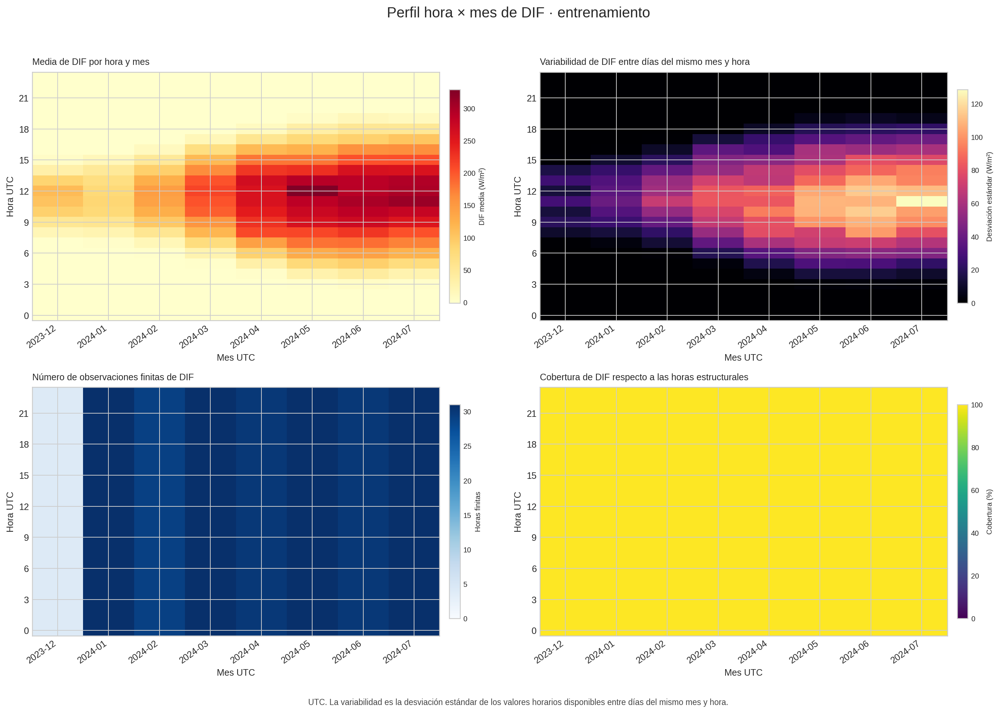

01_cobertura_pares_por_variable_y_mes.png


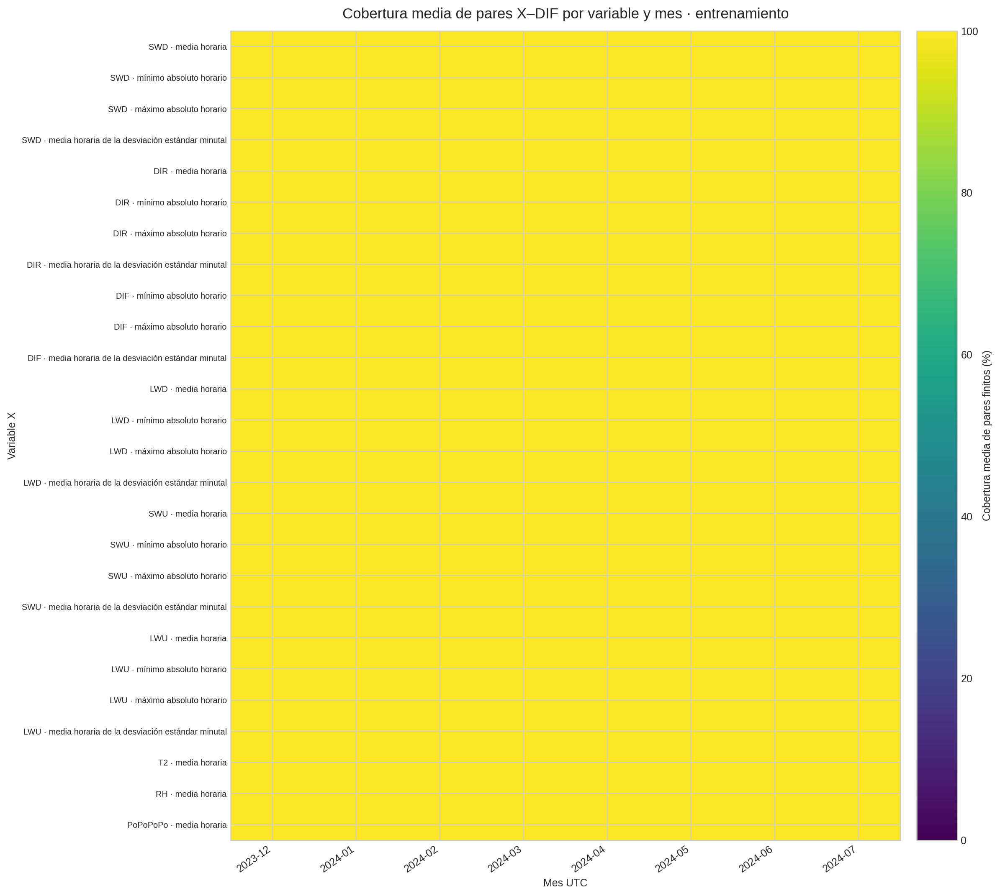

01_SWD__media_h_perfil_hora_mes.png


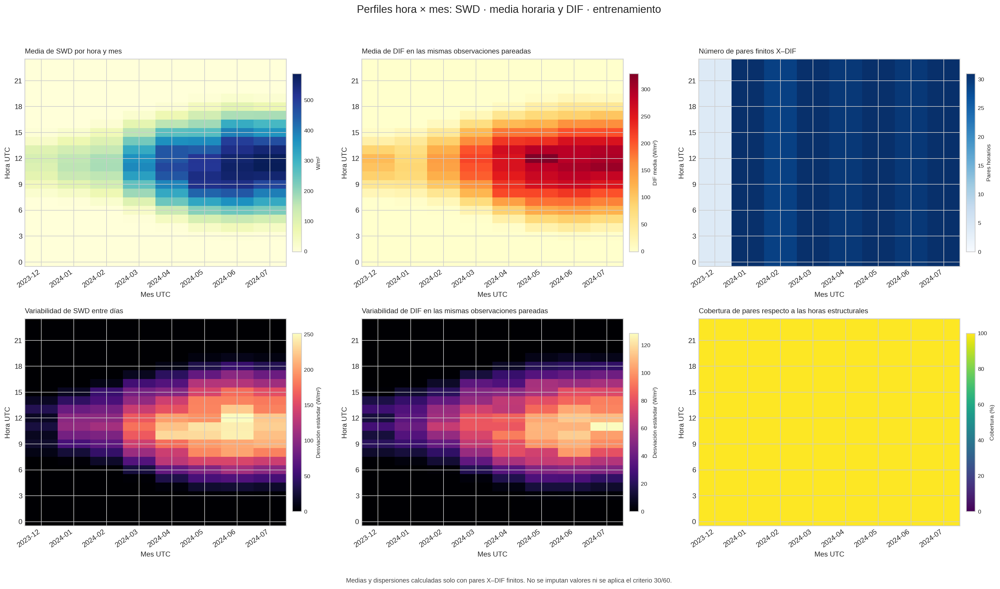

02_SWD__min_h_perfil_hora_mes.png


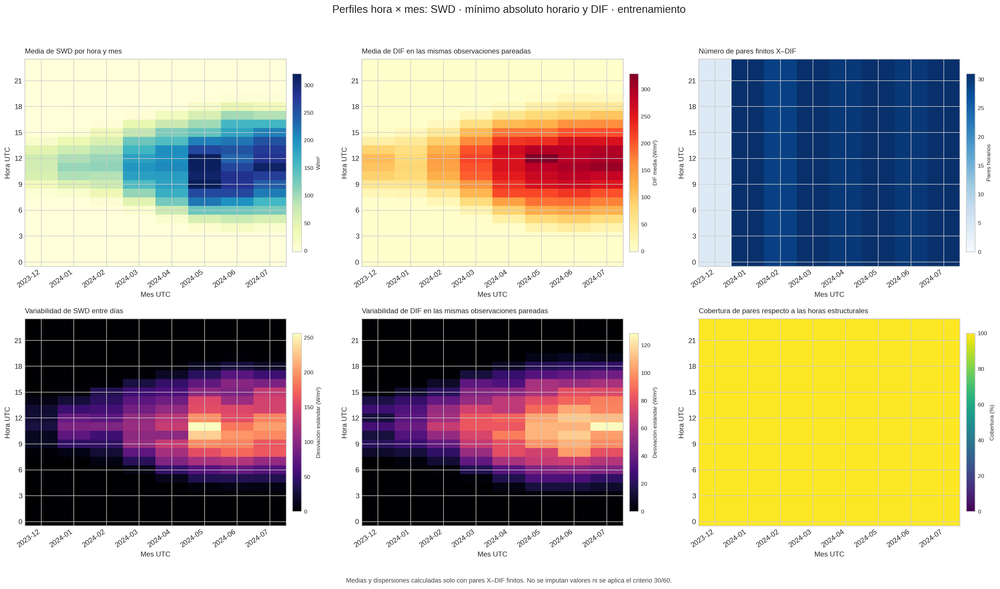

03_SWD__max_h_perfil_hora_mes.png


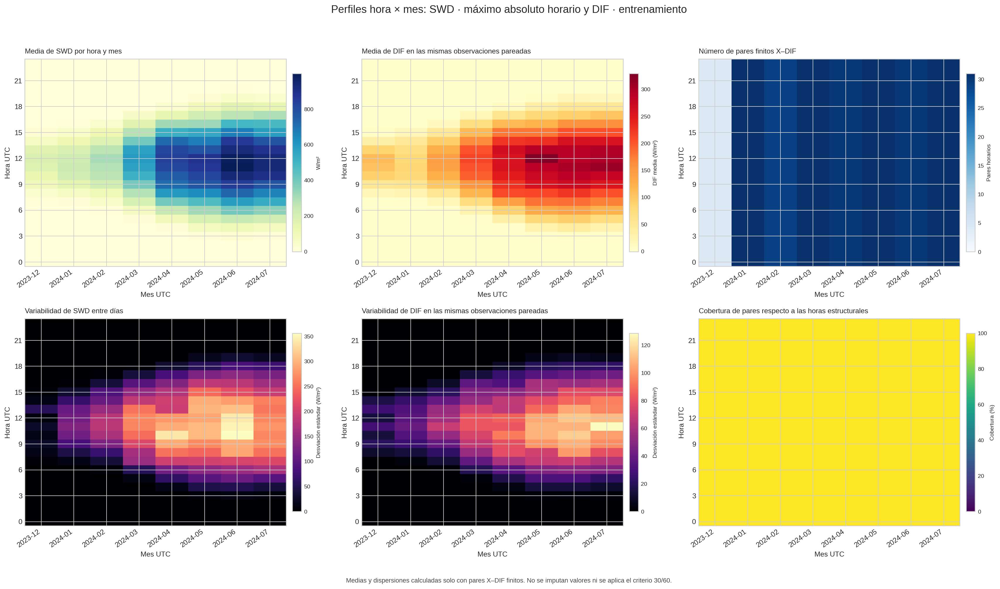

=== ZIP ===
Nombre: perfiles_hora_mes_Cabauw_20261102T171632Z_afb4ca5c.zip
Tamaño: 6.57 MiB
SHA-256: ede7f96f10537e0138f6f6e58781c7bd7cb5da0d0e6c15832b388b3586fc7ebd
Integridad: CORRECTA


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
# Perfiles hora × mes: X(t) ↔ DIF(t) durante entrenamiento
import sys
import subprocess
import importlib.util

def instalar_si_falta(modulo, paquete):
    if importlib.util.find_spec(modulo) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])

instalar_si_falta("pyarrow", "pyarrow")
import io
import hashlib
import json
import os
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
try:
    from IPython.display import Image, display
except ImportError:
    class Image:
        def __init__(self, filename):
            self.filename = filename

    def display(value):
        print(value)

try:
    from google.colab import files
    EN_COLAB = True
except ImportError:
    files = None
    EN_COLAB = False


# 1. Contrato de la subsección

# Se prioriza el ZIP de 4.2.2. Se permiten checkpoints con geometría solar de
# pasos anteriores para hacer reproducible el análisis de forma aislada.
CHECKPOINT_PRIORITARIO = "checkpoints/12_tabla_horaria_con_geometria_solar_sin_cambios.parquet"
CHECKPOINTS_ALTERNATIVOS = [
    "checkpoints/11_tabla_horaria_con_geometria_solar_sin_cambios.parquet",
    "checkpoints/10_tabla_horaria_con_geometria_solar.parquet",
    "checkpoints/10_tabla_horaria_con_geometria_solar_sin_cambios.parquet",
]
PARTICION_ANALIZADA = "train"
COLUMNA_OBJETIVO = "DIF__media_h"
MAX_FIGURAS_MOSTRADAS = 5
FAMILIAS_RADIOMETRICAS = ["SWD", "DIR", "DIF", "LWD", "SWU", "LWU"]
ESTADISTICOS_RADIOMETRICOS = [
    ("media", "__media_h", "Media horaria"),
    ("min", "__min_h", "Mínimo absoluto horario"),
    ("max", "__max_h", "Máximo absoluto horario"),
    ("std_media", "__std_media_h", "Media horaria de la desviación estándar minutal"),
]
VARIABLES_METEOROLOGICAS = [
    ("T2", "Temperatura a 2 m", "°C"),
    ("RH", "Humedad relativa", "%"),
    ("PoPoPoPo", "Presión atmosférica", "hPa"),
]


# 2. Funciones auxiliares
def sha256_archivo(ruta, tamano_bloque=1024 * 1024):
    resumen = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        while True:
            bloque = archivo.read(tamano_bloque)
            if not bloque:
                break
            resumen.update(bloque)
    return resumen.hexdigest()

def guardar_csv(tabla, ruta):
    tabla.to_csv(ruta, index=False, encoding="utf-8-sig")

def obtener_entrada():
    if EN_COLAB:
        print(
            "Selecciona exclusivamente el ZIP validado de la subsección 4.2.2 "
            "(evolución conjunta durante entrenamiento)."
        )
        subidos = files.upload()
        assert len(subidos) == 1, "Selecciona un único archivo ZIP o parquet."
        nombre, contenido = next(iter(subidos.items()))
        return nombre, contenido

    ruta_entrada = os.environ.get("INPUT_PERFILES_HORA_MES_FILE", "").strip()
    assert ruta_entrada, (
        "Fuera de Colab define INPUT_PERFILES_HORA_MES_FILE con la ruta al ZIP "
        "de la subsección 4.2.2."
    )
    ruta = Path(ruta_entrada).expanduser().resolve()
    assert ruta.is_file(), f"No existe el archivo: {ruta}"
    return ruta.name, ruta.read_bytes()

def elegir_checkpoint_parquet(nombres):
    candidatos = [nombre for nombre in nombres if nombre.lower().endswith(".parquet")]
    assert candidatos, "El ZIP no contiene ningún checkpoint parquet."
    prioridades = [CHECKPOINT_PRIORITARIO, *CHECKPOINTS_ALTERNATIVOS]

    def prioridad(nombre):
        normalizado = nombre.lower()
        for posicion, esperado in enumerate(prioridades):
            if normalizado == esperado.lower():
                return posicion
        if "tabla_horaria_con_geometria_solar" in normalizado:
            return len(prioridades)
        if "tabla_horaria" in normalizado:
            return len(prioridades) + 1
        return len(prioridades) + 2

    return sorted(candidatos, key=lambda nombre: (prioridad(nombre), nombre))[0]

def cargar_tabla(nombre, contenido):
    if nombre.lower().endswith(".zip"):
        with zipfile.ZipFile(io.BytesIO(contenido)) as archivo_zip:
            checkpoint = elegir_checkpoint_parquet(archivo_zip.namelist())
            tabla = pd.read_parquet(io.BytesIO(archivo_zip.read(checkpoint)))
        return tabla, checkpoint

    if nombre.lower().endswith(".parquet"):
        return pd.read_parquet(io.BytesIO(contenido)), nombre

    raise AssertionError("La entrada debe ser un ZIP o parquet horario válido.")

def detectar_columna_particion(columnas):
    for candidata in ["particion_observacion", "particion", "partition", "split"]:
        if candidata in columnas:
            return candidata
    for columna in columnas:
        nombre = str(columna).lower()
        if "particion" in nombre or "partition" in nombre:
            return columna
    return None

def detectar_columna_temporal(columnas):
    candidatas = ["Date/Time", "timestamp_utc", "timestamp", "fecha_hora", "datetime", "date_time"]
    for candidata in candidatas:
        if candidata in columnas:
            return candidata
    for columna in columnas:
        nombre = str(columna).lower().replace(" ", "")
        if ("date" in nombre and "time" in nombre) or "timestamp" in nombre:
            return columna
    return None

def crear_inventario_archivos(ruta_base):
    filas = []
    for ruta in sorted(Path(ruta_base).rglob("*")):
        if ruta.is_file():
            filas.append(
                {
                    "archivo": str(ruta.relative_to(ruta_base)),
                    "tamano_bytes": ruta.stat().st_size,
                    "sha256": sha256_archivo(ruta),
                }
            )
    return pd.DataFrame(filas)


# 3. Inventario y funciones de perfiles hora × mes
def construir_especificacion():
    filas = []
    for familia in FAMILIAS_RADIOMETRICAS:
        for estadistico, sufijo, descripcion in ESTADISTICOS_RADIOMETRICOS:
            columna = f"{familia}{sufijo}"
            filas.append(
                {
                    "familia": familia,
                    "tipo": "radiométrica",
                    "estadistico": estadistico,
                    "descripcion": descripcion,
                    "columna_horaria": columna,
                    "etiqueta": f"{familia} · {descripcion.lower()}",
                    "unidad": "W/m²",
                    "es_objetivo": columna == COLUMNA_OBJETIVO,
                }
            )

    for familia, descripcion, unidad in VARIABLES_METEOROLOGICAS:
        columna = f"{familia}__media_h"
        filas.append(
            {
                "familia": familia,
                "tipo": "meteorológica",
                "estadistico": "media",
                "descripcion": f"Media horaria de {descripcion.lower()}",
                "columna_horaria": columna,
                "etiqueta": f"{familia} · media horaria",
                "unidad": unidad,
                "es_objetivo": False,
            }
        )

    return pd.DataFrame(filas)

def reindexar_perfil(tabla, meses):
    indice = pd.MultiIndex.from_product([meses, range(24)], names=["mes_utc", "hora_utc"])
    return tabla.reindex(indice).reset_index()

def crear_perfil_objetivo(tabla_train, meses):
    base = tabla_train[["__mes_utc", "__hora_utc", COLUMNA_OBJETIVO]].copy()
    base.columns = ["mes_utc", "hora_utc", "dif"]
    base["dif"] = pd.to_numeric(base["dif"], errors="coerce")
    base["es_finito"] = np.isfinite(base["dif"].to_numpy())
    grupo = base.groupby(["mes_utc", "hora_utc"], observed=True)
    perfil = pd.DataFrame(
        {
            "media_dif": grupo["dif"].mean(),
            "desv_dif": grupo["dif"].std(ddof=0),
            "n_dif_finitos": grupo["es_finito"].sum(),
            "n_horas_estructurales": grupo.size(),
        }
    )
    perfil["pct_dif_finito"] = 100 * perfil["n_dif_finitos"] / perfil["n_horas_estructurales"]
    return reindexar_perfil(perfil, meses)

def crear_perfil_pareado(tabla_train, columna_x, meses):
    base = tabla_train[["__mes_utc", "__hora_utc", COLUMNA_OBJETIVO, columna_x]].copy()
    base.columns = ["mes_utc", "hora_utc", "dif", "x"]
    base["x"] = pd.to_numeric(base["x"], errors="coerce")
    base["dif"] = pd.to_numeric(base["dif"], errors="coerce")
    base["pareja_finita"] = np.isfinite(base["x"].to_numpy()) & np.isfinite(base["dif"].to_numpy())
    base["x_pareada"] = base["x"].where(base["pareja_finita"])
    base["dif_pareada"] = base["dif"].where(base["pareja_finita"])
    grupo = base.groupby(["mes_utc", "hora_utc"], observed=True)
    perfil = pd.DataFrame(
        {
            "media_x": grupo["x_pareada"].mean(),
            "desv_x": grupo["x_pareada"].std(ddof=0),
            "media_dif": grupo["dif_pareada"].mean(),
            "desv_dif": grupo["dif_pareada"].std(ddof=0),
            "n_pares_finitos": grupo["pareja_finita"].sum(),
            "n_horas_estructurales": grupo.size(),
        }
    )
    perfil["pct_pares_finitos"] = 100 * perfil["n_pares_finitos"] / perfil["n_horas_estructurales"]
    return reindexar_perfil(perfil, meses)

def matriz_perfil(tabla, valor, meses):
    return (
        tabla.pivot(index="hora_utc", columns="mes_utc", values=valor)
        .reindex(index=range(24), columns=meses)
        .astype(float)
    )

def limites_color(matriz, desde_cero=False, limite_superior_fijo=None):
    valores = matriz.to_numpy(dtype=float)
    finitos = valores[np.isfinite(valores)]
    if len(finitos) == 0:
        return 0.0, 1.0

    minimo = 0.0 if desde_cero else float(np.min(finitos))
    maximo = float(np.max(finitos)) if limite_superior_fijo is None else float(limite_superior_fijo)
    if not np.isfinite(maximo) or maximo <= minimo:
        maximo = minimo + max(1.0, 0.05 * abs(minimo))
    return minimo, maximo

def dibujar_mapa(figura, eje, matriz, titulo, etiqueta_color, mapa, vmin, vmax):
    imagen = eje.imshow(
        matriz.to_numpy(dtype=float),
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        cmap=mapa,
        vmin=vmin,
        vmax=vmax,
    )
    eje.set_title(titulo, loc="left", fontsize=10, pad=8)
    eje.set_xlabel("Mes UTC")
    eje.set_ylabel("Hora UTC")
    eje.set_xticks(range(len(matriz.columns)))
    eje.set_xticklabels(matriz.columns, rotation=35, ha="right")
    eje.set_yticks(range(0, 24, 3))
    eje.set_yticklabels(range(0, 24, 3))
    eje.set_ylim(-0.5, 23.5)
    barra = figura.colorbar(imagen, ax=eje, shrink=0.86, pad=0.02)
    barra.set_label(etiqueta_color, fontsize=8)
    barra.ax.tick_params(labelsize=8)

def guardar_figura_referencia(perfil_dif, meses, ruta):
    matrices = {
        "media": matriz_perfil(perfil_dif, "media_dif", meses),
        "desv": matriz_perfil(perfil_dif, "desv_dif", meses),
        "n": matriz_perfil(perfil_dif, "n_dif_finitos", meses),
        "cobertura": matriz_perfil(perfil_dif, "pct_dif_finito", meses),
    }
    vmin_media, vmax_media = limites_color(matrices["media"])
    _, vmax_desv = limites_color(matrices["desv"], desde_cero=True)
    _, vmax_n = limites_color(matrices["n"], desde_cero=True)
    figura, ejes = plt.subplots(2, 2, figsize=(16, 11))
    figura.suptitle("Perfil hora × mes de DIF · entrenamiento", fontsize=16, y=0.985)
    dibujar_mapa(
        figura,
        ejes[0, 0],
        matrices["media"],
        "Media de DIF por hora y mes",
        "DIF media (W/m²)",
        "YlOrRd",
        vmin_media,
        vmax_media,
    )
    dibujar_mapa(
        figura,
        ejes[0, 1],
        matrices["desv"],
        "Variabilidad de DIF entre días del mismo mes y hora",
        "Desviación estándar (W/m²)",
        "magma",
        0.0,
        vmax_desv,
    )
    dibujar_mapa(
        figura,
        ejes[1, 0],
        matrices["n"],
        "Número de observaciones finitas de DIF",
        "Horas finitas",
        "Blues",
        0.0,
        vmax_n,
    )
    dibujar_mapa(
        figura,
        ejes[1, 1],
        matrices["cobertura"],
        "Cobertura de DIF respecto a las horas estructurales",
        "Cobertura (%)",
        "viridis",
        0.0,
        100.0,
    )
    figura.text(
        0.5,
        0.012,
        "UTC. La variabilidad es la desviación estándar de los valores horarios disponibles entre días del mismo mes y hora.",
        ha="center",
        fontsize=9,
        color="#444444",
    )
    figura.tight_layout(rect=(0, 0.035, 1, 0.96))
    figura.savefig(ruta, dpi=180, bbox_inches="tight")
    plt.close(figura)
    return matrices

def guardar_figura_comparacion(perfil, registro, meses, limites_dif, limites_desv_dif, ruta):
    matrices = {
        "media_x": matriz_perfil(perfil, "media_x", meses),
        "media_dif": matriz_perfil(perfil, "media_dif", meses),
        "desv_x": matriz_perfil(perfil, "desv_x", meses),
        "desv_dif": matriz_perfil(perfil, "desv_dif", meses),
        "n": matriz_perfil(perfil, "n_pares_finitos", meses),
        "cobertura": matriz_perfil(perfil, "pct_pares_finitos", meses),
    }
    vmin_x, vmax_x = limites_color(matrices["media_x"])
    _, vmax_desv_x = limites_color(matrices["desv_x"], desde_cero=True)
    _, vmax_n = limites_color(matrices["n"], desde_cero=True)
    figura, ejes = plt.subplots(2, 3, figsize=(20, 11.5))
    figura.suptitle(
        f"Perfiles hora × mes: {registro['etiqueta']} y DIF · entrenamiento", fontsize=15, y=0.99
    )
    dibujar_mapa(
        figura,
        ejes[0, 0],
        matrices["media_x"],
        f"Media de {registro['familia']} por hora y mes",
        registro["unidad"],
        "YlGnBu",
        vmin_x,
        vmax_x,
    )
    dibujar_mapa(
        figura,
        ejes[0, 1],
        matrices["media_dif"],
        "Media de DIF en las mismas observaciones pareadas",
        "DIF media (W/m²)",
        "YlOrRd",
        limites_dif[0],
        limites_dif[1],
    )
    dibujar_mapa(
        figura,
        ejes[0, 2],
        matrices["n"],
        "Número de pares finitos X–DIF",
        "Pares horarios",
        "Blues",
        0.0,
        vmax_n,
    )
    dibujar_mapa(
        figura,
        ejes[1, 0],
        matrices["desv_x"],
        f"Variabilidad de {registro['familia']} entre días",
        f"Desviación estándar ({registro['unidad']})",
        "magma",
        0.0,
        vmax_desv_x,
    )
    dibujar_mapa(
        figura,
        ejes[1, 1],
        matrices["desv_dif"],
        "Variabilidad de DIF en las mismas observaciones pareadas",
        "Desviación estándar (W/m²)",
        "magma",
        0.0,
        limites_desv_dif[1],
    )
    dibujar_mapa(
        figura,
        ejes[1, 2],
        matrices["cobertura"],
        "Cobertura de pares respecto a las horas estructurales",
        "Cobertura (%)",
        "viridis",
        0.0,
        100.0,
    )
    figura.text(
        0.5,
        0.009,
        "Medias y dispersiones calculadas solo con pares X–DIF finitos. No se imputan valores ni se aplica el criterio 30/60.",
        ha="center",
        fontsize=9,
        color="#444444",
    )
    figura.tight_layout(rect=(0, 0.035, 1, 0.96))
    figura.savefig(ruta, dpi=175, bbox_inches="tight")
    plt.close(figura)

def guardar_figura_cobertura_resumen(tabla_perfiles, comparaciones, meses, ruta):
    orden = comparaciones["columna_horaria"].tolist()
    etiquetas = comparaciones["etiqueta"].tolist()
    tabla = (
        tabla_perfiles.groupby(["columna_x", "mes_utc"], observed=True)["pct_pares_finitos"]
        .mean()
        .unstack("mes_utc")
        .reindex(index=orden, columns=meses)
    )
    figura, eje = plt.subplots(figsize=(14, 12))
    imagen = eje.imshow(
        tabla.to_numpy(dtype=float),
        aspect="auto",
        interpolation="nearest",
        cmap="viridis",
        vmin=0.0,
        vmax=100.0,
    )
    eje.set_title(
        "Cobertura media de pares X–DIF por variable y mes · entrenamiento", fontsize=14, pad=12
    )
    eje.set_xlabel("Mes UTC")
    eje.set_ylabel("Variable X")
    eje.set_xticks(range(len(meses)))
    eje.set_xticklabels(meses, rotation=35, ha="right")
    eje.set_yticks(range(len(etiquetas)))
    eje.set_yticklabels(etiquetas, fontsize=8)
    barra = figura.colorbar(imagen, ax=eje, pad=0.02)
    barra.set_label("Cobertura media de pares finitos (%)")
    figura.tight_layout()
    figura.savefig(ruta, dpi=180, bbox_inches="tight")
    plt.close(figura)


# 4. Carga y preparación diagnóstica
especificacion = construir_especificacion()
assert len(especificacion) == 27, "El inventario debe contener 27 variables."
assert especificacion["columna_horaria"].is_unique, "Hay variables duplicadas."
nombre_entrada, bytes_entrada = obtener_entrada()
df_original, checkpoint_utilizado = cargar_tabla(nombre_entrada, bytes_entrada)
columna_particion = detectar_columna_particion(df_original.columns)
columna_temporal_original = detectar_columna_temporal(df_original.columns)
assert columna_particion is not None, "No se encontró la columna de partición."
assert columna_temporal_original is not None, "No se encontró la columna temporal."
columnas_necesarias = especificacion["columna_horaria"].tolist()
faltantes = sorted(set(columnas_necesarias) - set(df_original.columns))
assert not faltantes, "Faltan variables requeridas: " + ", ".join(faltantes)
mascara_train = (
    df_original[columna_particion].astype(str).str.strip().str.lower().eq(PARTICION_ANALIZADA)
)
assert mascara_train.any(), "No se encontraron registros de entrenamiento."

# Esta copia solo se utiliza para el cálculo y las figuras.
df_train = df_original.loc[mascara_train].copy()
df_train["__timestamp_utc_diagnostico"] = pd.to_datetime(
    df_train[columna_temporal_original], errors="coerce", utc=True
)
assert (
    df_train["__timestamp_utc_diagnostico"].notna().all()
), "Hay timestamps de entrenamiento no interpretables."
df_train = df_train.sort_values("__timestamp_utc_diagnostico").reset_index(drop=True)
assert (
    not df_train["__timestamp_utc_diagnostico"].duplicated().any()
), "Hay timestamps duplicados en entrenamiento."
saltos = df_train["__timestamp_utc_diagnostico"].diff().dropna()
n_saltos_no_horarios = int((saltos != pd.Timedelta(hours=1)).sum())
assert n_saltos_no_horarios == 0, (
    "La malla horaria no es continua; se detectaron " f"{n_saltos_no_horarios} saltos no horarios."
)
for columna in columnas_necesarias:
    df_train[columna] = pd.to_numeric(df_train[columna], errors="coerce")

df_train["__mes_utc"] = df_train["__timestamp_utc_diagnostico"].dt.strftime("%Y-%m")
df_train["__hora_utc"] = df_train["__timestamp_utc_diagnostico"].dt.hour.astype(int)
meses = df_train["__mes_utc"].drop_duplicates().tolist()
assert meses, "No se identificaron meses en entrenamiento."


# 5. Salidas gráficas y tablas de respaldo
marca_tiempo = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
identificador = uuid.uuid4().hex
if EN_COLAB:
    raiz_salida = Path(".")
else:
    raiz_salida = Path(os.environ.get("OUTPUT_BASE_4_2_3", ".")).expanduser().resolve()

directorio = raiz_salida / f"F4_S2_3_{marca_tiempo}_{identificador[-8:]}"
directorio_figuras = directorio / "figuras"
directorio_perfiles = directorio_figuras / "01_perfiles_individuales"
directorio_tablas = directorio / "tablas"
directorio_checkpoint = directorio / "checkpoints"
directorio_configuracion = directorio / "configuracion"
for ruta in [
    directorio_perfiles,
    directorio_tablas,
    directorio_checkpoint,
    directorio_configuracion,
]:
    ruta.mkdir(parents=True, exist_ok=True)

perfil_dif = crear_perfil_objetivo(df_train, meses)
ruta_referencia = directorio_figuras / "00_referencia_DIF_hora_mes.png"
matrices_dif = guardar_figura_referencia(perfil_dif, meses, ruta_referencia)
limites_dif = limites_color(matrices_dif["media"])
limites_desv_dif = limites_color(matrices_dif["desv"], desde_cero=True)
comparaciones = especificacion.loc[~especificacion["es_objetivo"]].copy()
perfiles_largos = []
indice_figuras = [
    {
        "orden": 1,
        "columna_x": COLUMNA_OBJETIVO,
        "etiqueta_x": "DIF · media horaria",
        "tipo_figura": "referencia_perfil_hora_mes_DIF",
        "archivo": str(ruta_referencia.relative_to(directorio)),
    }
]
for posicion, registro in enumerate(comparaciones.to_dict(orient="records"), start=1):
    columna_x = registro["columna_horaria"]
    perfil = crear_perfil_pareado(df_train, columna_x, meses)
    perfil.insert(0, "columna_x", columna_x)
    perfil.insert(1, "etiqueta_x", registro["etiqueta"])
    perfil.insert(2, "familia_x", registro["familia"])
    perfil.insert(3, "tipo_x", registro["tipo"])
    perfil.insert(4, "unidad_x", registro["unidad"])
    perfiles_largos.append(perfil)
    nombre_figura = f"{posicion:02d}_{columna_x}_perfil_hora_mes.png"
    ruta_figura = directorio_perfiles / nombre_figura
    guardar_figura_comparacion(perfil, registro, meses, limites_dif, limites_desv_dif, ruta_figura)
    indice_figuras.append(
        {
            "orden": len(indice_figuras) + 1,
            "columna_x": columna_x,
            "etiqueta_x": registro["etiqueta"],
            "tipo_figura": "perfil_hora_mes_comparado_con_DIF",
            "archivo": str(ruta_figura.relative_to(directorio)),
        }
    )

tabla_perfiles = pd.concat(perfiles_largos, ignore_index=True)
ruta_cobertura_resumen = directorio_figuras / "01_cobertura_pares_por_variable_y_mes.png"
guardar_figura_cobertura_resumen(tabla_perfiles, comparaciones, meses, ruta_cobertura_resumen)
indice_figuras.append(
    {
        "orden": len(indice_figuras) + 1,
        "columna_x": "todas_las_variables",
        "etiqueta_x": "Cobertura de pares X–DIF",
        "tipo_figura": "resumen_cobertura_por_variable_y_mes",
        "archivo": str(ruta_cobertura_resumen.relative_to(directorio)),
    }
)
tabla_cobertura = (
    tabla_perfiles.groupby(
        ["columna_x", "etiqueta_x", "familia_x", "tipo_x", "unidad_x"], observed=True
    )
    .agg(
        n_celdas_hora_mes=("mes_utc", "size"),
        n_pares_finitos=("n_pares_finitos", "sum"),
        n_horas_estructurales=("n_horas_estructurales", "sum"),
        cobertura_media_pct=("pct_pares_finitos", "mean"),
        cobertura_minima_pct=("pct_pares_finitos", "min"),
    )
    .reset_index()
)
tabla_cobertura["cobertura_global_pct"] = (
    100 * tabla_cobertura["n_pares_finitos"] / tabla_cobertura["n_horas_estructurales"]
)
tabla_objetivo = perfil_dif.copy()
tabla_objetivo.insert(0, "columna_objetivo", COLUMNA_OBJETIVO)

# El checkpoint se vuelve a guardar exactamente sin filas eliminadas, imputación
# ni columnas diagnósticas añadidas.
ruta_checkpoint = directorio_checkpoint / "13_tabla_horaria_con_geometria_solar_sin_cambios.parquet"
df_original.to_parquet(ruta_checkpoint, index=False)
df_verificado = pd.read_parquet(ruta_checkpoint)
pd.testing.assert_frame_equal(
    df_original.reset_index(drop=True), df_verificado.reset_index(drop=True), check_dtype=True
)
guardar_csv(tabla_objetivo, directorio_tablas / "01_perfil_hora_mes_DIF_train.csv")
guardar_csv(tabla_perfiles, directorio_tablas / "02_perfiles_hora_mes_pareados_con_DIF_train.csv")
guardar_csv(tabla_cobertura, directorio_tablas / "03_resumen_cobertura_perfiles_train.csv")
guardar_csv(pd.DataFrame(indice_figuras), directorio_tablas / "04_indice_figuras.csv")
advertencias = pd.DataFrame(
    [
        {
            "id": "E231",
            "advertencia": "Los perfiles hora × mes describen coincidencia temporal, no causalidad ni capacidad predictiva.",
            "decision": "La evaluación X(t) → DIF(t+1) se realizará posteriormente mediante retardos temporales.",
        },
        {
            "id": "E232",
            "advertencia": "Diciembre de 2023 contiene solo los días presentes desde el inicio de entrenamiento.",
            "decision": "Debe interpretarse junto con los paneles de número de pares y cobertura.",
        },
        {
            "id": "E233",
            "advertencia": "Cada comparación usa pares X–DIF finitos.",
            "decision": "El número y porcentaje de pares se representan; no se imputan valores.",
        },
        {
            "id": "E234",
            "advertencia": "Los perfiles agregan horas nocturnas y diurnas con distinta elevación solar.",
            "decision": "La separación explícita por regímenes solares se realizará en la subsección 4.2.8.",
        },
        {
            "id": "E235",
            "advertencia": "DIF mínimo, máximo y desviación estándar comparten mediciones de origen con DIF media.",
            "decision": "Su lectura es descriptiva; la utilidad predictiva requerirá retardos y validación temporal.",
        },
    ]
)
guardar_csv(advertencias, directorio_tablas / "05_advertencias_y_alcance.csv")
resumen = pd.DataFrame(
    [
        {
            "particion_analizada": PARTICION_ANALIZADA,
            "n_horas_train": len(df_train),
            "meses_utc_analizados": ", ".join(meses),
            "n_variables_inventario": len(especificacion),
            "n_comparaciones_individuales": len(comparaciones),
            "n_celdas_hora_mes_por_variable": len(meses) * 24,
            "n_figuras_generadas": len(indice_figuras),
            "n_saltos_no_horarios_train": n_saltos_no_horarios,
            "filtro_30_60_aplicado": False,
            "filas_eliminadas": 0,
            "valores_imputados": 0,
            "checkpoint_salida_verificado_identico": True,
        }
    ]
)
guardar_csv(resumen, directorio_tablas / "06_resumen_tecnico.csv")
configuracion = {
    "subseccion": "4.2.3_perfiles_hora_mes",
    "entrada": nombre_entrada,
    "checkpoint_entrada": checkpoint_utilizado,
    "checkpoint_salida": ruta_checkpoint.name,
    "particion_analizada": PARTICION_ANALIZADA,
    "objetivo_contemporaneo": COLUMNA_OBJETIVO,
    "eje_temporal": "hora UTC × mes UTC",
    "n_variables": int(len(especificacion)),
    "n_comparaciones": int(len(comparaciones)),
    "estadisticos_por_celda": {
        "media": "media de valores horarios en el mismo mes y hora UTC",
        "variabilidad": "desviación estándar poblacional entre días del mismo mes y hora UTC",
        "soporte": "número y porcentaje de pares X–DIF finitos respecto a horas estructurales",
    },
    "uso_pares_finitos": True,
    "filtro_30_60_aplicado": False,
    "filas_eliminadas": 0,
    "valores_imputados": 0,
}
with (directorio_configuracion / "configuracion_4_2_3.json").open("w", encoding="utf-8") as archivo:
    json.dump(configuracion, archivo, ensure_ascii=False, indent=2)

readme = f"""# Subsección 4.2.3 · Perfiles hora × mes

## Objetivo

Se describen los perfiles de hora UTC × mes UTC de {COLUMNA_OBJETIVO} y de
cada una de las 26 variables X en entrenamiento. El propósito es identificar
patrones diarios y estacionales, variabilidad entre días y soporte de datos,
sin realizar todavía selección de predictores.

## Figuras

- una figura de referencia para DIF: media, dispersión, número de observaciones
  y cobertura por hora y mes;
- una figura de seis paneles para cada comparación X(t) ↔ DIF(t): medias de X
  y DIF, dispersiones de X y DIF, número de pares y cobertura de pares;
- una figura resumen de cobertura por variable y mes.

Las medias y dispersiones de cada pareja se calculan sobre las mismas horas
con X y DIF finitos. La dispersión es la desviación estándar poblacional de
los valores horarios de los distintos días que comparten mes y hora UTC.

## Integridad y alcance

No se eliminan filas, no se imputan valores y no se aplica el criterio 30/60.
La partición continúa siendo exclusivamente train. Los resultados describen
relaciones contemporáneas y no permiten inferir causalidad, nubosidad ni poder
predictivo a una hora vista.

La columna de diciembre de 2023 es parcial porque el entrenamiento comienza el
28 de diciembre; por ello siempre debe interpretarse junto con los paneles de
número de pares y cobertura.
"""
(directorio / "README.md").write_text(readme, encoding="utf-8")
inventario_archivos = crear_inventario_archivos(directorio)
guardar_csv(inventario_archivos, directorio / "inventario_archivos.csv")
ruta_zip = raiz_salida / f"perfiles_hora_mes_Cabauw_{marca_tiempo}_{identificador[-8:]}.zip"
with zipfile.ZipFile(ruta_zip, "w", compression=zipfile.ZIP_DEFLATED) as archivo_zip:
    for ruta in sorted(directorio.rglob("*")):
        if ruta.is_file():
            archivo_zip.write(ruta, arcname=str(ruta.relative_to(directorio)))

with zipfile.ZipFile(ruta_zip) as archivo_zip:
    assert archivo_zip.testzip() is None, "El ZIP generado contiene un archivo dañado."


# 6. Resumen visible y descarga
print("=== RESUMEN TÉCNICO 4.2.3 ===")
print(f"Checkpoint de entrada: {checkpoint_utilizado}")
print(f"Partición analizada: {PARTICION_ANALIZADA}")
print(f"Horas de entrenamiento: {len(df_train):,}")
print(f"Meses UTC analizados: {', '.join(meses)}")
print(f"Comparaciones X(t) ↔ DIF(t): {len(comparaciones)}")
print(f"Figuras generadas: {len(indice_figuras)}")
print(f"Saltos no horarios detectados: {n_saltos_no_horarios}")
print("Filas eliminadas: 0")
print("Valores imputados: 0")
print("Criterio 30/60 aplicado como descarte: NO")
print("Checkpoint de salida verificado idéntico: SÍ")
print()
display(resumen)
display(tabla_cobertura)
print("=== MUESTRA DE FIGURAS ===")
rutas_muestra = [ruta_referencia, ruta_cobertura_resumen]
for fila in indice_figuras[1 : MAX_FIGURAS_MOSTRADAS - 1]:
    rutas_muestra.append(directorio / fila["archivo"])
for ruta in rutas_muestra:
    print(ruta.name)
    display(Image(filename=str(ruta)))

print("=== ZIP ===")
print(f"Nombre: {ruta_zip.name}")
print(f"Tamaño: {ruta_zip.stat().st_size / (1024 ** 2):.2f} MiB")
print(f"SHA-256: {sha256_archivo(ruta_zip)}")
print("Integridad: CORRECTA")
if EN_COLAB:
    files.download(str(ruta_zip))

**Resultados.**

Para caracterizar la evolución diaria y estacional de las variables se construyeron perfiles de hora UTC por mes empleando exclusivamente la partición de entrenamiento. Cada celda de los mapas representa la media de los valores horarios registrados en distintos días para una misma combinación de mes y hora. Como medida de dispersión se utilizó la desviación estándar poblacional entre días, que permite identificar las franjas temporales en las que una variable presenta mayor variación de un día a otro. Todas las comparaciones entre una variable *X* y DIF se calcularon sobre las mismas observaciones horarias finitas. No se eliminaron ni imputaron valores y no se aplicó el criterio de disponibilidad 30/60.

La cobertura de las comparaciones fue prácticamente completa, por lo que los patrones observados no parecen estar condicionados de manera relevante por diferencias en la disponibilidad de datos. No obstante, diciembre de 2023 solo incluye los cuatro últimos días del mes y, por ello, sus resultados no se consideran representativos de un mes completo. Asimismo, cada mapa utiliza una escala de color adaptada al rango de su variable, de modo que la comparación entre figuras se centra en la forma y en la localización temporal de las zonas de mayor intensidad, y no en la igualdad de sus colores.

El perfil de DIF presenta una estructura diaria y estacional claramente vinculada a la geometría solar. La franja con valores positivos es más estrecha en invierno y se ensancha progresivamente hasta junio y julio. Las mayores intensidades se concentran en las horas centrales, especialmente desde mayo hasta julio. Su variabilidad entre días también queda restringida principalmente al periodo diurno y aumenta durante la primavera y el verano, lo que indica que las diferencias entre días son mayores cuando existe una mayor disponibilidad potencial de radiación solar.

SWD y SWU muestran los patrones visualmente más próximos al de DIF. Sus medias, mínimos y máximos reproducen el ensanchamiento estacional del periodo diurno y la concentración de los mayores valores en las horas centrales. La semejanza entre SWD y SWU es especialmente marcada, de acuerdo con la relación física entre la radiación de onda corta incidente y la reflejada. No obstante, esta coincidencia visual no permite determinar por sí sola la contribución del albedo ni establecer capacidad predictiva.

DIR conserva una estructura diurna, pero presenta una evolución entre meses más irregular. En febrero se observa una reducción notable de intensidad, mientras que en mayo aumentan especialmente su media y su mínimo. El máximo y la desviación estándar muestran zonas destacadas en abril y junio. La variabilidad entre días de DIR también es más fragmentada que la de DIF, lo que pone de manifiesto que el componente directo puede presentar diferencias importantes entre días pertenecientes al mismo mes y hora.

Los descriptores de variabilidad intrahoraria de DIF, SWD, DIR y SWU muestran una coincidencia temporal relevante: se observan zonas intensas en abril y junio separadas por una reducción durante mayo. Este comportamiento indica que la evolución de la variabilidad no es equivalente a la evolución del valor medio. En particular, un periodo con una media elevada puede presentar una variación intrahoraria relativamente reducida. Asimismo, en junio aparece una franja intensa durante las horas centrales en varias variables de onda corta. Al tratarse de perfiles mensuales, esta franja no corresponde a un episodio aislado, sino a un patrón recurrente dentro de ese mes.

Las variables de onda larga presentan una estructura diferente. La media, el mínimo y el máximo de LWD varían fundamentalmente entre meses y mantienen valores durante las veinticuatro horas, sin reproducir la envolvente día–noche de DIF. LWU también aumenta desde invierno hacia verano, pero presenta una oscilación diaria más marcada, con valores superiores durante las horas centrales de los meses cálidos. Por este motivo, LWU muestra una semejanza visual con DIF mayor que LWD, aunque continúa respondiendo a una dinámica térmica distinta. Las figuras no permiten interpretar LWD como un indicador exclusivo de nubosidad, dado que esta variable también depende de otras propiedades térmicas y atmosféricas.

La temperatura T2 presenta una evolución muy parecida a LWU, con un aumento estacional hacia el verano y máximos diarios durante la tarde. La humedad relativa RH muestra, en cambio, un ciclo diario aproximadamente inverso: sus valores disminuyen durante las horas centrales, especialmente en junio y julio, y aumentan durante la noche y las primeras horas del día. La presión atmosférica muestra principalmente diferencias entre meses y muy poca estructura dentro del día, por lo que no se aprecia en estos perfiles una coincidencia temporal clara con la evolución hora–mes de DIF.

En conjunto, los mapas permiten distinguir una familia de variables de onda corta con una envolvente solar común, un grupo térmico formado principalmente por LWD, LWU y T2, una humedad relativa con evolución diaria inversa y una presión dominada por variaciones mensuales. Estos resultados constituyen una descripción visual de la evolución conjunta de las variables. No permiten todavía atribuir los patrones a nubosidad, establecer relaciones causales ni evaluar la capacidad de predicción de DIF a una hora vista, cuestiones que requerirán análisis posteriores específicos.

### 4.2.4 Descomposición temporal mediante STL y MSTL

Esta subsección separa, en las 27 series horarias de entrenamiento, las estructuras temporales recurrentes de las variaciones que estas no explican. Se aplican STL robusto con estacionalidad diaria de 24 horas y MSTL robusto con estacionalidades de 24 y 168 horas, para valorar si el ciclo semanal añade información descriptiva o si la dinámica queda dominada por el ciclo diario y la evolución de fondo; no se estima una componente anual porque el entrenamiento no cubre un ciclo anual completo. Como ambos métodos requieren series sin huecos, los huecos internos breves se interpolan solo en copias destinadas a este diagnóstico. Los índices de fuerza de las componentes se leen como resúmenes descriptivos y, al proceder de suavizados bilaterales, las componentes no pueden usarse directamente como variables de un modelo prospectivo sin recalcularse de forma causal.

Selecciona un único ZIP validado que contenga el checkpoint horario con geometría solar (por ejemplo, la salida de 4.2.2 o 4.2.3).


Saving perfiles_hora_mes_Cabauw_20261102T171632Z_afb4ca5c.zip to perfiles_hora_mes_Cabauw_20261102T171632Z_afb4ca5c (1).zip
Entrada: perfiles_hora_mes_Cabauw_20261102T171632Z_afb4ca5c (1).zip
Checkpoint: checkpoints/13_tabla_horaria_con_geometria_solar_sin_cambios.parquet
Horas de entrenamiento: 5,208
Variables: 27
Valores interpolados solo para STL/MSTL: 4
[01/27] STL + MSTL: SWD__media_h
[02/27] STL + MSTL: SWD__min_h
[03/27] STL + MSTL: SWD__max_h
[04/27] STL + MSTL: SWD__std_media_h
[05/27] STL + MSTL: DIR__media_h
[06/27] STL + MSTL: DIR__min_h
[07/27] STL + MSTL: DIR__max_h
[08/27] STL + MSTL: DIR__std_media_h
[09/27] STL + MSTL: DIF__media_h
[10/27] STL + MSTL: DIF__min_h
[11/27] STL + MSTL: DIF__max_h
[12/27] STL + MSTL: DIF__std_media_h
[13/27] STL + MSTL: LWD__media_h
[14/27] STL + MSTL: LWD__min_h
[15/27] STL + MSTL: LWD__max_h
[16/27] STL + MSTL: LWD__std_media_h
[17/27] STL + MSTL: SWU__media_h
[18/27] STL + MSTL: SWU__min_h
[19/27] STL + MSTL: SWU__max_h
[20/27] STL + MST

,orden,columna,n_horas_train,n_ausentes_originales,n_interpolados_diagnosticos,max_hueco_h,porcentaje_interpolado,quedan_ausentes
0,1,SWD__media_h,5208,0,0,0,0.000000,0
1,2,SWD__min_h,5208,0,0,0,0.000000,0
2,3,SWD__max_h,5208,0,0,0,0.000000,0
3,4,SWD__std_media_h,5208,0,0,0,0.000000,0
4,5,DIR__media_h,5208,0,0,0,0.000000,0
5,6,DIR__min_h,5208,0,0,0,0.000000,0
6,7,DIR__max_h,5208,0,0,0,0.000000,0
7,8,DIR__std_media_h,5208,0,0,0,0.000000,0
8,9,DIF__media_h,5208,0,0,0,0.000000,0
9,10,DIF__min_h,5208,0,0,0,0.000000,0


,orden,columna,stl_fuerza_tendencia,stl_fuerza_diaria_24h,mstl_fuerza_tendencia,mstl_fuerza_diaria_24h,mstl_fuerza_semanal_168h,stl_desv_residuo,mstl_desv_residuo,stl_error_reconstruccion_max_abs,mstl_error_reconstruccion_max_abs
0,1,SWD__media_h,0.381563,0.733225,0.396589,0.761269,0.067978,100.391605,96.894981,1.136868e-13,2.273737e-13
1,2,SWD__min_h,0.250130,0.562787,0.270798,0.591122,0.080759,77.164418,71.452164,1.136868e-13,2.273737e-13
2,3,SWD__max_h,0.442047,0.783204,0.429131,0.795644,0.000000,145.776461,149.065123,1.136868e-13,3.410605e-13
3,4,SWD__std_media_h,0.123915,0.278719,0.125996,0.344832,0.078377,13.767092,12.902865,1.421085e-14,2.842171e-14
4,5,DIR__media_h,0.127605,0.171647,0.103548,0.200052,0.055531,182.861913,173.941239,1.136868e-13,2.273737e-13
5,6,DIR__min_h,0.324416,0.040129,0.000000,0.141046,0.003001,135.307126,123.485529,1.136868e-13,2.273737e-13
6,7,DIR__max_h,0.121668,0.372427,0.110919,0.397417,0.000000,245.006074,278.021777,1.136868e-13,3.410605e-13
7,8,DIR__std_media_h,0.082634,0.214479,0.091044,0.227693,0.106791,19.519827,18.517789,2.842171e-14,2.842171e-14
8,9,DIF__media_h,0.413876,0.790500,0.415563,0.787372,0.012885,47.737072,47.497453,1.136868e-13,1.136868e-13
9,10,DIF__min_h,0.284090,0.689164,0.284270,0.688600,0.056998,41.122231,40.821931,5.684342e-14,1.136868e-13


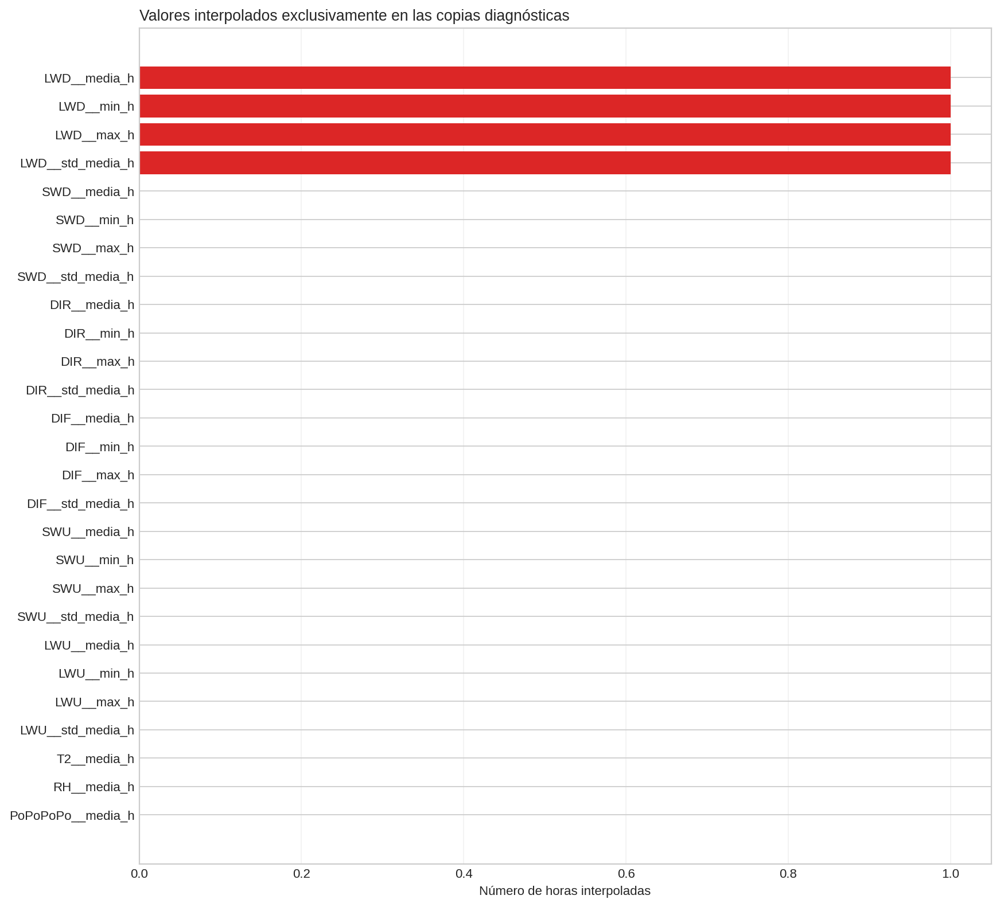

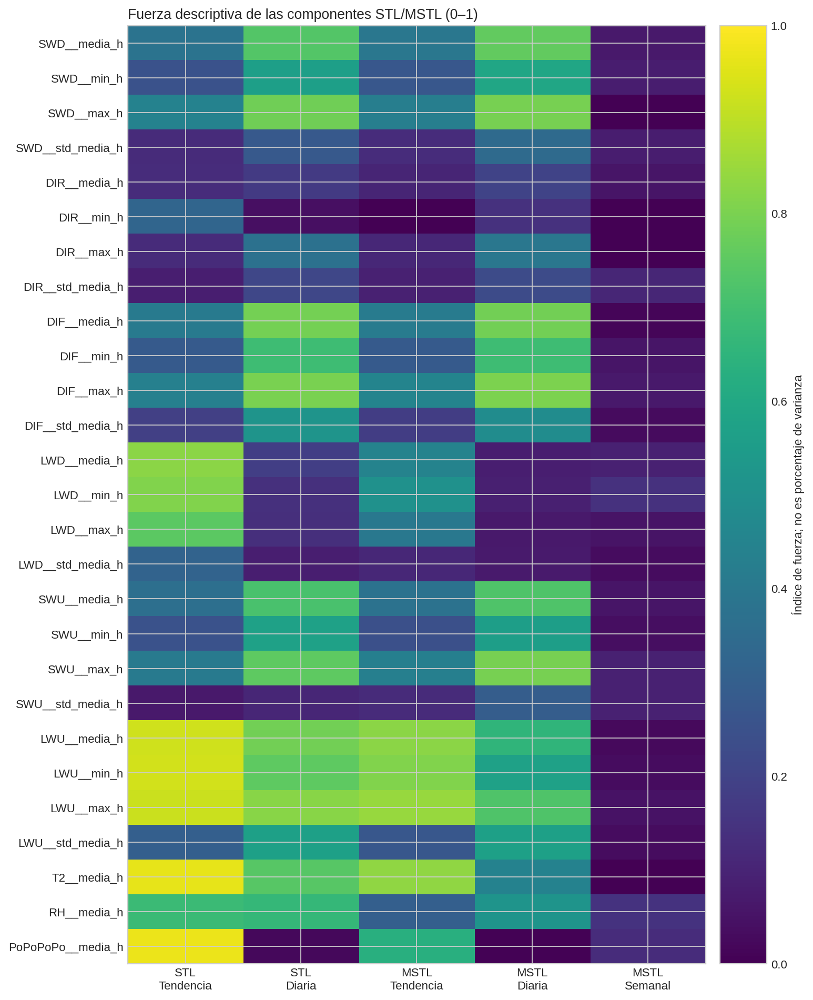

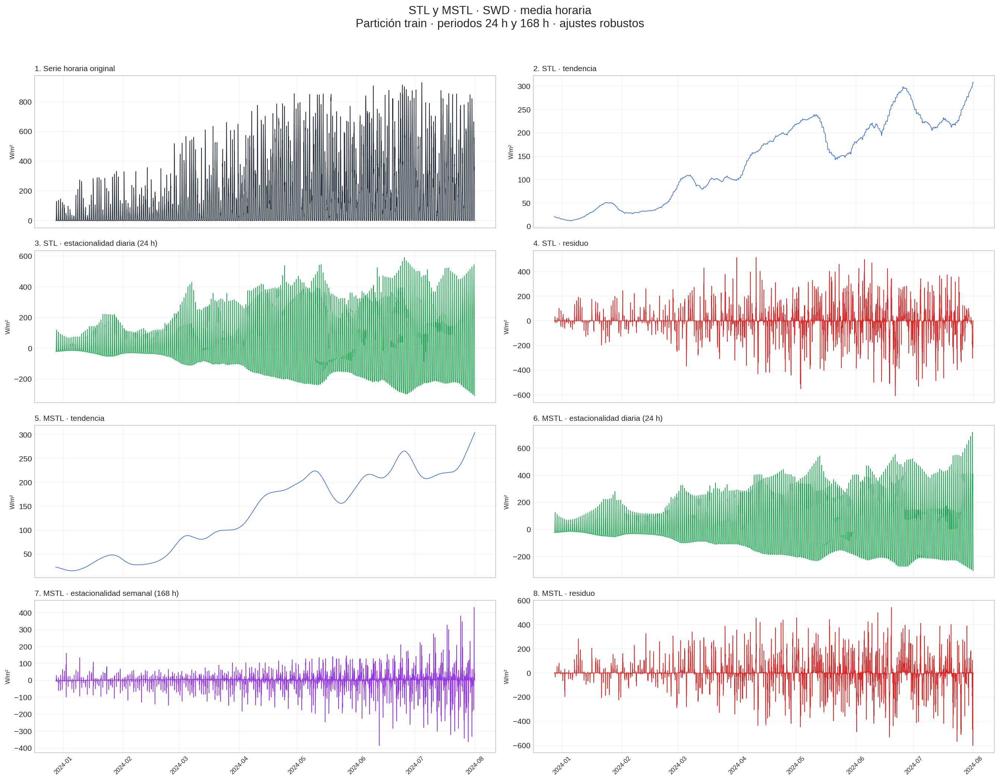

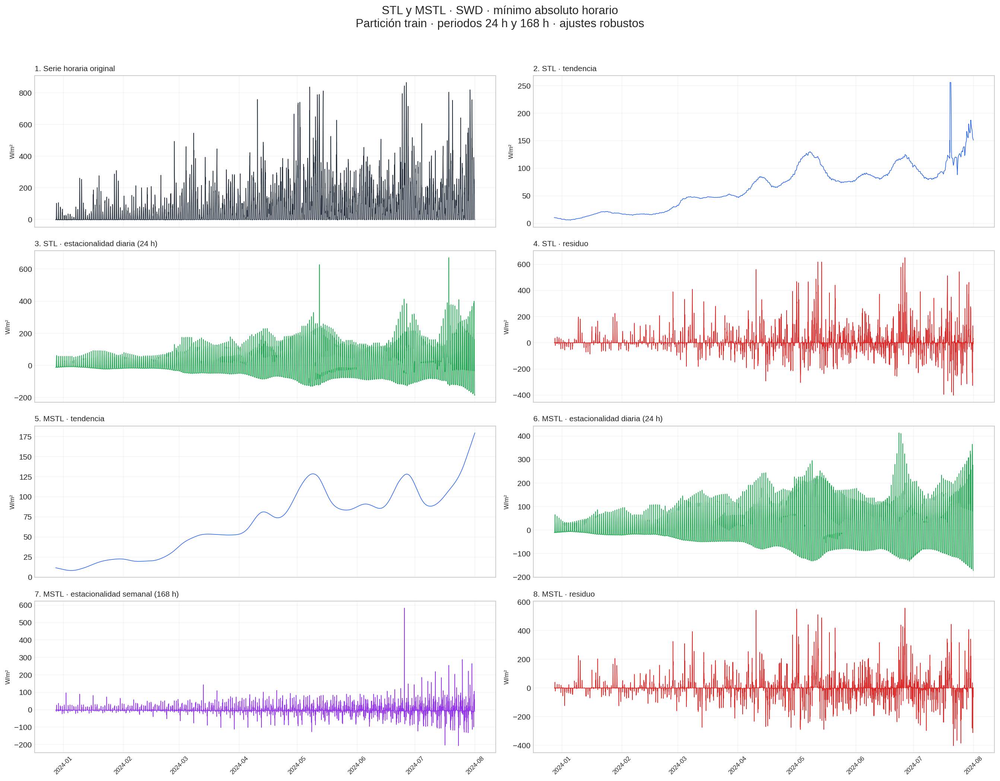

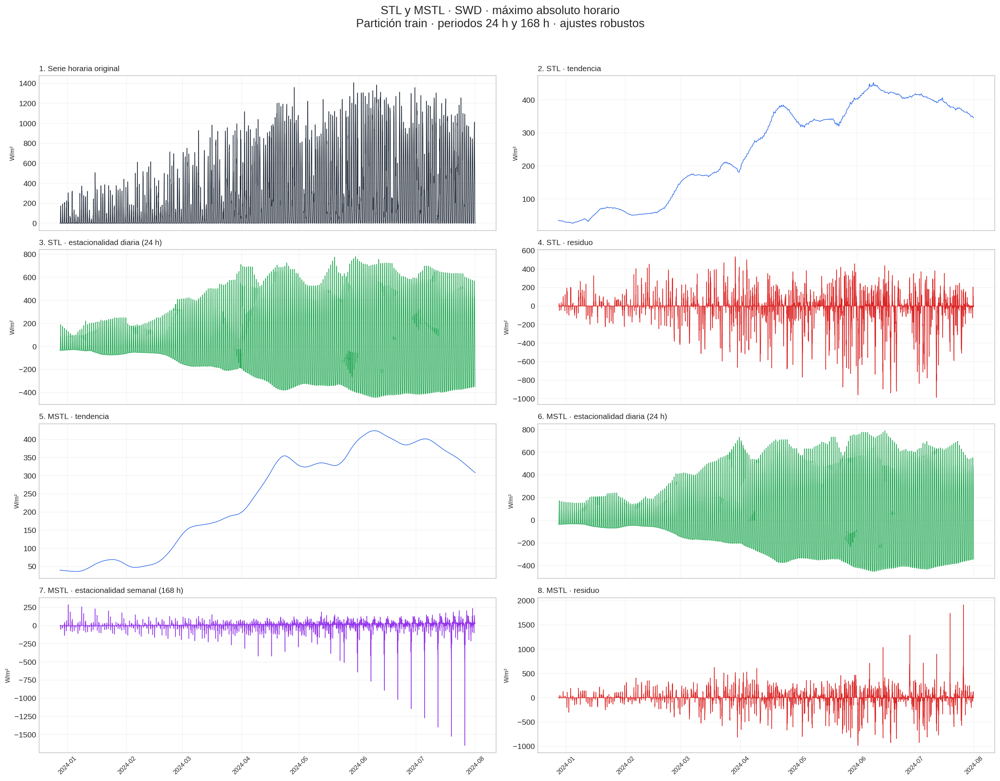

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
# Descomposición STL/MSTL de las 27 variables horarias durante entrenamiento
import sys
import subprocess
import importlib
import importlib.util

def instalar_si_falta(modulo, paquete):
    """Instala una dependencia únicamente cuando no está disponible."""
    if importlib.util.find_spec(modulo) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])
        importlib.invalidate_caches()

instalar_si_falta("pyarrow", "pyarrow")
try:
    from statsmodels.tsa.seasonal import MSTL, STL
except (ImportError, ModuleNotFoundError):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "statsmodels>=0.14.0"])
    importlib.invalidate_caches()
    from statsmodels.tsa.seasonal import MSTL, STL

import io
import hashlib
import json
import os
import platform
import re
import uuid
import zipfile
from datetime import datetime, timezone
from importlib.metadata import version as version_paquete
from pathlib import Path
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
try:
    from IPython.display import Image, display
except ImportError:
    class Image:
        def __init__(self, filename):
            self.filename = filename

    def display(value):
        print(value)

try:
    from google.colab import files
    EN_COLAB = True
except ImportError:
    files = None
    EN_COLAB = False


# 1. Contrato de la subsección
PARTICION_ANALIZADA = "train"
PERIODO_STL_H = 24
PERIODOS_MSTL_H = (24, 168)
VENTANAS_MSTL = (13, 15)
MAX_HUECO_INTERPOLABLE_H = 24
MAX_FIGURAS_INDIVIDUALES_MOSTRADAS = 3

# Se reutiliza sin modificar el checkpoint horario con geometría solar.
CHECKPOINTS_PRIORITARIOS = [
    "checkpoints/12_tabla_horaria_con_geometria_solar_sin_cambios.parquet",
    "checkpoints/11_tabla_horaria_con_geometria_solar_sin_cambios.parquet",
    "checkpoints/10_tabla_horaria_con_geometria_solar_sin_cambios.parquet",
    "checkpoints/10_tabla_horaria_con_geometria_solar.parquet",
]
FAMILIAS_RADIOMETRICAS = ["SWD", "DIR", "DIF", "LWD", "SWU", "LWU"]
ESTADISTICOS_RADIOMETRICOS = [
    ("media", "__media_h", "Media horaria"),
    ("min", "__min_h", "Mínimo absoluto horario"),
    ("max", "__max_h", "Máximo absoluto horario"),
    ("std_media", "__std_media_h", "Media horaria de la desviación estándar minutal"),
]
VARIABLES_METEOROLOGICAS = [
    ("T2", "Temperatura a 2 m", "°C"),
    ("RH", "Humedad relativa", "%"),
    ("PoPoPoPo", "Presión atmosférica", "hPa"),
]


# 2. Funciones auxiliares de entrada, integridad y formato
def sha256_bytes(contenido):
    return hashlib.sha256(contenido).hexdigest()

def sha256_archivo(ruta, tamano_bloque=1024 * 1024):
    resumen = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        while True:
            bloque = archivo.read(tamano_bloque)
            if not bloque:
                break
            resumen.update(bloque)
    return resumen.hexdigest()

def guardar_csv(tabla, ruta):
    tabla.to_csv(ruta, index=False, encoding="utf-8-sig")

def guardar_json(objeto, ruta):
    Path(ruta).write_text(
        json.dumps(objeto, ensure_ascii=False, indent=2, default=str), encoding="utf-8"
    )

def nombre_seguro(texto):
    limpio = re.sub(r"[^A-Za-z0-9._-]+", "_", str(texto)).strip("_")
    return limpio or "variable"

def obtener_entrada():
    if EN_COLAB:
        print(
            "Selecciona un único ZIP validado que contenga el checkpoint horario "
            "con geometría solar (por ejemplo, la salida de 4.2.2 o 4.2.3)."
        )
        subidos = files.upload()
        assert len(subidos) == 1, "Selecciona exactamente un ZIP o parquet."
        return next(iter(subidos.items()))

    ruta_entrada = os.environ.get("INPUT_STL_MSTL_FILE", "").strip()
    assert ruta_entrada, (
        "Fuera de Colab define INPUT_STL_MSTL_FILE con la ruta al ZIP o parquet "
        "horario validado."
    )
    ruta = Path(ruta_entrada).expanduser().resolve()
    assert ruta.is_file(), f"No existe el archivo de entrada: {ruta}"
    return ruta.name, ruta.read_bytes()

def elegir_checkpoint_parquet(nombres):
    candidatos = [n for n in nombres if str(n).lower().endswith(".parquet")]
    assert candidatos, "La entrada no contiene ningún checkpoint parquet."

    def prioridad(nombre):
        nombre_l = str(nombre).lower()
        for posicion, esperado in enumerate(CHECKPOINTS_PRIORITARIOS):
            if nombre_l == esperado.lower():
                return posicion
        if "tabla_horaria_con_geometria_solar" in nombre_l:
            return len(CHECKPOINTS_PRIORITARIOS)
        if "tabla_horaria" in nombre_l:
            return len(CHECKPOINTS_PRIORITARIOS) + 1
        return len(CHECKPOINTS_PRIORITARIOS) + 2

    return sorted(candidatos, key=lambda n: (prioridad(n), str(n)))[0]

def cargar_tabla_y_checkpoint(nombre, contenido):
    nombre_l = nombre.lower()
    if nombre_l.endswith(".zip"):
        assert zipfile.is_zipfile(io.BytesIO(contenido)), "El archivo no es un ZIP válido."
        with zipfile.ZipFile(io.BytesIO(contenido)) as archivo_zip:
            archivo_danado = archivo_zip.testzip()
            assert archivo_danado is None, f"Archivo dañado dentro del ZIP: {archivo_danado}"
            ruta_checkpoint = elegir_checkpoint_parquet(archivo_zip.namelist())
            bytes_checkpoint = archivo_zip.read(ruta_checkpoint)
        tabla = pd.read_parquet(io.BytesIO(bytes_checkpoint))
        return tabla, ruta_checkpoint, bytes_checkpoint

    if nombre_l.endswith(".parquet"):
        ruta_checkpoint = CHECKPOINTS_PRIORITARIOS[0]
        tabla = pd.read_parquet(io.BytesIO(contenido))
        return tabla, ruta_checkpoint, contenido

    raise AssertionError("La entrada debe ser un ZIP o un parquet válido.")

def detectar_columna_temporal(columnas):
    candidatas = ["timestamp_utc", "Date/Time", "timestamp", "fecha_hora", "datetime", "date_time"]
    for candidata in candidatas:
        if candidata in columnas:
            return candidata
    for columna in columnas:
        nombre = str(columna).lower().replace(" ", "")
        if "timestamp" in nombre or ("date" in nombre and "time" in nombre):
            return columna
    return None

def detectar_columna_particion(columnas):
    candidatas = ["particion_observacion", "particion", "partition", "split"]
    for candidata in candidatas:
        if candidata in columnas:
            return candidata
    for columna in columnas:
        nombre = str(columna).lower()
        if "particion" in nombre or "partition" in nombre:
            return columna
    return None

def crear_inventario_archivos(ruta_base):
    filas = []
    for ruta in sorted(Path(ruta_base).rglob("*")):
        if ruta.is_file() and ruta.name != "inventario_archivos.csv":
            filas.append(
                {
                    "archivo": str(ruta.relative_to(ruta_base)),
                    "tamano_bytes": ruta.stat().st_size,
                    "sha256": sha256_archivo(ruta),
                }
            )
    return pd.DataFrame(filas)

def crear_zip(ruta_base, ruta_zip):
    with zipfile.ZipFile(ruta_zip, "w", compression=zipfile.ZIP_DEFLATED) as zf:
        for ruta in sorted(Path(ruta_base).rglob("*")):
            if ruta.is_file():
                zf.write(ruta, arcname=str(ruta.relative_to(ruta_base)))
    with zipfile.ZipFile(ruta_zip) as zf:
        assert zf.testzip() is None, "El ZIP de salida no superó la comprobación CRC."


# 3. Inventario congelado de las 27 variables
def construir_especificacion_variables():
    filas = []
    orden = 1
    for familia in FAMILIAS_RADIOMETRICAS:
        for estadistico, sufijo, descripcion in ESTADISTICOS_RADIOMETRICOS:
            filas.append(
                {
                    "orden": orden,
                    "familia": familia,
                    "tipo": "radiométrica",
                    "estadistico": estadistico,
                    "columna": f"{familia}{sufijo}",
                    "descripcion": f"{familia} · {descripcion.lower()}",
                    "unidad": "W/m²",
                }
            )
            orden += 1

    for familia, descripcion, unidad in VARIABLES_METEOROLOGICAS:
        filas.append(
            {
                "orden": orden,
                "familia": familia,
                "tipo": "meteorológica",
                "estadistico": "media",
                "columna": f"{familia}__media_h",
                "descripcion": descripcion,
                "unidad": unidad,
            }
        )
        orden += 1

    especificacion = pd.DataFrame(filas)
    assert len(especificacion) == 27, "El inventario debe contener 27 variables."
    assert especificacion["columna"].is_unique, "Hay variables duplicadas."
    return especificacion


# 4. Preparación exclusiva de entrenamiento
def longitud_maxima_hueco(mascara):
    valores = pd.Series(mascara, dtype=bool)
    if not valores.any():
        return 0
    grupos = valores.ne(valores.shift(fill_value=False)).cumsum()
    longitudes = valores.groupby(grupos).sum()
    return int(longitudes.max())

def preparar_train(tabla, especificacion):
    columna_tiempo = detectar_columna_temporal(tabla.columns)
    columna_particion = detectar_columna_particion(tabla.columns)
    assert columna_tiempo is not None, "No se encontró la columna temporal."
    assert columna_particion is not None, "No se encontró la columna de partición."
    columnas_variables = especificacion["columna"].tolist()
    faltantes = [c for c in columnas_variables if c not in tabla.columns]
    assert not faltantes, f"Faltan variables requeridas: {faltantes}"
    copia = tabla[[columna_tiempo, columna_particion, *columnas_variables]].copy()
    copia[columna_tiempo] = pd.to_datetime(copia[columna_tiempo], errors="coerce", utc=True)
    assert copia[columna_tiempo].notna().all(), "Hay timestamps no interpretables."
    mascara_train = (
        copia[columna_particion].astype(str).str.strip().str.lower() == PARTICION_ANALIZADA
    )
    train = copia.loc[mascara_train].copy()
    assert not train.empty, "La partición train está vacía."
    assert train[columna_tiempo].is_unique, "Hay timestamps duplicados en train."
    train = train.sort_values(columna_tiempo).set_index(columna_tiempo)
    indice_completo = pd.date_range(train.index.min(), train.index.max(), freq="h", tz="UTC")
    horas_estructurales_ausentes = indice_completo.difference(train.index)
    assert len(horas_estructurales_ausentes) == 0, (
        "Existen horas estructurales ausentes en train. Antes de STL/MSTL debe "
        f"revisarse el eje temporal: {len(horas_estructurales_ausentes)} horas."
    )
    train = train.reindex(indice_completo)
    for columna in columnas_variables:
        train[columna] = pd.to_numeric(train[columna], errors="coerce")

    return train[columnas_variables], columna_tiempo, columna_particion

def interpolar_copias_diagnosticas(train, especificacion):
    copia = train.copy()
    filas_resumen = []
    for fila in especificacion.itertuples(index=False):
        serie_original = train[fila.columna].astype(float)
        mascara_ausente = serie_original.isna()
        max_hueco = longitud_maxima_hueco(mascara_ausente)

        # STL/MSTL no admite NaN. Solo se rellenan huecos internos cortos en
        # esta copia diagnóstica; el checkpoint original permanece intacto.
        serie_interpolada = serie_original.interpolate(
            method="time", limit=MAX_HUECO_INTERPOLABLE_H, limit_area="inside"
        )
        mascara_rellena = mascara_ausente & serie_interpolada.notna()
        restantes = int(serie_interpolada.isna().sum())
        assert max_hueco <= MAX_HUECO_INTERPOLABLE_H, (
            f"{fila.columna}: hueco de {max_hueco} h; supera el máximo permitido "
            f"de {MAX_HUECO_INTERPOLABLE_H} h."
        )
        assert restantes == 0, (
            f"{fila.columna}: quedan {restantes} valores ausentes tras la "
            "interpolación diagnóstica."
        )
        copia[fila.columna] = serie_interpolada
        filas_resumen.append(
            {
                "orden": fila.orden,
                "columna": fila.columna,
                "n_horas_train": int(len(serie_original)),
                "n_ausentes_originales": int(mascara_ausente.sum()),
                "n_interpolados_diagnosticos": int(mascara_rellena.sum()),
                "max_hueco_h": max_hueco,
                "porcentaje_interpolado": float(100 * mascara_rellena.mean()),
                "quedan_ausentes": restantes,
            }
        )

    return copia, pd.DataFrame(filas_resumen)


# 5. Descomposición STL y MSTL
def como_serie(valores, indice, nombre):
    return pd.Series(np.asarray(valores, dtype=float), index=indice, name=nombre)

def extraer_estacional_mstl(resultado, periodo, posicion, indice):
    estacional = resultado.seasonal
    nombre = f"seasonal_{periodo}"
    if isinstance(estacional, pd.DataFrame):
        if nombre in estacional.columns:
            valores = estacional[nombre]
        else:
            valores = estacional.iloc[:, posicion]
    elif np.asarray(estacional).ndim == 2:
        valores = np.asarray(estacional)[:, posicion]
    else:
        valores = estacional
    return como_serie(valores, indice, nombre)

def intensidad_componente(componente, residuo):
    """Índice de fuerza: 1 - Var(residuo)/Var(residuo + componente)."""
    componente = np.asarray(componente, dtype=float)
    residuo = np.asarray(residuo, dtype=float)
    denominador = float(np.nanvar(residuo + componente, ddof=1))
    numerador = float(np.nanvar(residuo, ddof=1))
    if not np.isfinite(denominador) or denominador <= np.finfo(float).eps:
        return np.nan
    return float(np.clip(1.0 - numerador / denominador, 0.0, 1.0))

def descomponer_serie(serie):
    ajuste_stl = STL(serie, period=PERIODO_STL_H, seasonal=13, trend=25, robust=True).fit()
    ajuste_mstl = MSTL(
        serie,
        periods=PERIODOS_MSTL_H,
        windows=VENTANAS_MSTL,
        iterate=2,
        stl_kwargs={"robust": True},
    ).fit()
    indice = serie.index
    return {
        "stl_tendencia": como_serie(ajuste_stl.trend, indice, "stl_tendencia"),
        "stl_estacional_24h": como_serie(ajuste_stl.seasonal, indice, "stl_estacional_24h"),
        "stl_residuo": como_serie(ajuste_stl.resid, indice, "stl_residuo"),
        "mstl_tendencia": como_serie(ajuste_mstl.trend, indice, "mstl_tendencia"),
        "mstl_estacional_24h": extraer_estacional_mstl(ajuste_mstl, 24, 0, indice),
        "mstl_estacional_168h": extraer_estacional_mstl(ajuste_mstl, 168, 1, indice),
        "mstl_residuo": como_serie(ajuste_mstl.resid, indice, "mstl_residuo"),
    }

def resumen_componentes(serie, componentes, columna, orden):
    reconstruccion_stl = (
        componentes["stl_tendencia"]
        + componentes["stl_estacional_24h"]
        + componentes["stl_residuo"]
    )
    reconstruccion_mstl = (
        componentes["mstl_tendencia"]
        + componentes["mstl_estacional_24h"]
        + componentes["mstl_estacional_168h"]
        + componentes["mstl_residuo"]
    )
    return {
        "orden": orden,
        "columna": columna,
        "stl_fuerza_tendencia": intensidad_componente(
            componentes["stl_tendencia"], componentes["stl_residuo"]
        ),
        "stl_fuerza_diaria_24h": intensidad_componente(
            componentes["stl_estacional_24h"], componentes["stl_residuo"]
        ),
        "mstl_fuerza_tendencia": intensidad_componente(
            componentes["mstl_tendencia"], componentes["mstl_residuo"]
        ),
        "mstl_fuerza_diaria_24h": intensidad_componente(
            componentes["mstl_estacional_24h"], componentes["mstl_residuo"]
        ),
        "mstl_fuerza_semanal_168h": intensidad_componente(
            componentes["mstl_estacional_168h"], componentes["mstl_residuo"]
        ),
        "stl_desv_residuo": float(np.nanstd(componentes["stl_residuo"], ddof=1)),
        "mstl_desv_residuo": float(np.nanstd(componentes["mstl_residuo"], ddof=1)),
        "stl_error_reconstruccion_max_abs": float(np.nanmax(np.abs(serie - reconstruccion_stl))),
        "mstl_error_reconstruccion_max_abs": float(np.nanmax(np.abs(serie - reconstruccion_mstl))),
    }


# 6. Figuras
def formatear_eje_temporal(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.grid(alpha=0.22)

def dibujar_serie(ax, serie, titulo, color, unidad):
    ax.plot(serie.index, serie.values, color=color, linewidth=0.75)
    ax.set_title(titulo, fontsize=10, loc="left")
    ax.set_ylabel(unidad, fontsize=8)
    formatear_eje_temporal(ax)

def crear_figura_variable(
    serie_original, serie_interpolada, componentes, fila_especificacion, ruta_salida
):
    figura, ejes = plt.subplots(4, 2, figsize=(18, 14), sharex=True)
    ejes = ejes.ravel()
    dibujar_serie(
        ejes[0], serie_original, "1. Serie horaria original", "#1f2937", fila_especificacion.unidad
    )
    mascara = serie_original.isna() & serie_interpolada.notna()
    if mascara.any():
        ejes[0].scatter(
            serie_interpolada.index[mascara],
            serie_interpolada.loc[mascara],
            s=35,
            color="#dc2626",
            label="Interpolación diagnóstica",
            zorder=3,
        )
        ejes[0].legend(fontsize=8, loc="upper right")

    dibujar_serie(
        ejes[1],
        componentes["stl_tendencia"],
        "2. STL · tendencia",
        "#2563eb",
        fila_especificacion.unidad,
    )
    dibujar_serie(
        ejes[2],
        componentes["stl_estacional_24h"],
        "3. STL · estacionalidad diaria (24 h)",
        "#16a34a",
        fila_especificacion.unidad,
    )
    dibujar_serie(
        ejes[3],
        componentes["stl_residuo"],
        "4. STL · residuo",
        "#dc2626",
        fila_especificacion.unidad,
    )
    dibujar_serie(
        ejes[4],
        componentes["mstl_tendencia"],
        "5. MSTL · tendencia",
        "#2563eb",
        fila_especificacion.unidad,
    )
    dibujar_serie(
        ejes[5],
        componentes["mstl_estacional_24h"],
        "6. MSTL · estacionalidad diaria (24 h)",
        "#16a34a",
        fila_especificacion.unidad,
    )
    dibujar_serie(
        ejes[6],
        componentes["mstl_estacional_168h"],
        "7. MSTL · estacionalidad semanal (168 h)",
        "#9333ea",
        fila_especificacion.unidad,
    )
    dibujar_serie(
        ejes[7],
        componentes["mstl_residuo"],
        "8. MSTL · residuo",
        "#dc2626",
        fila_especificacion.unidad,
    )
    figura.suptitle(
        f"STL y MSTL · {fila_especificacion.descripcion}\n"
        "Partición train · periodos 24 h y 168 h · ajustes robustos",
        fontsize=15,
        y=0.995,
    )
    figura.tight_layout(rect=(0, 0, 1, 0.97))
    figura.savefig(ruta_salida, dpi=150, bbox_inches="tight")
    plt.close(figura)

def crear_figura_interpolaciones(resumen, ruta_salida):
    ordenada = resumen.sort_values(
        ["n_interpolados_diagnosticos", "orden"], ascending=[True, False]
    )
    figura, ax = plt.subplots(figsize=(11, 10))
    colores = np.where(ordenada["n_interpolados_diagnosticos"].to_numpy() > 0, "#dc2626", "#94a3b8")
    ax.barh(ordenada["columna"], ordenada["n_interpolados_diagnosticos"], color=colores)
    ax.set_title("Valores interpolados exclusivamente en las copias diagnósticas", loc="left")
    ax.set_xlabel("Número de horas interpoladas")
    ax.grid(axis="x", alpha=0.25)
    figura.tight_layout()
    figura.savefig(ruta_salida, dpi=160, bbox_inches="tight")
    plt.close(figura)

def crear_figura_intensidades(resumen, ruta_salida):
    columnas = [
        "stl_fuerza_tendencia",
        "stl_fuerza_diaria_24h",
        "mstl_fuerza_tendencia",
        "mstl_fuerza_diaria_24h",
        "mstl_fuerza_semanal_168h",
    ]
    etiquetas = [
        "STL\nTendencia",
        "STL\nDiaria",
        "MSTL\nTendencia",
        "MSTL\nDiaria",
        "MSTL\nSemanal",
    ]
    ordenada = resumen.sort_values("orden")
    matriz = ordenada[columnas].to_numpy(dtype=float)
    figura, ax = plt.subplots(figsize=(10, 12))
    imagen = ax.imshow(matriz, aspect="auto", cmap="viridis", vmin=0, vmax=1)
    ax.set_xticks(range(len(etiquetas)), etiquetas)
    ax.set_yticks(range(len(ordenada)), ordenada["columna"])
    ax.set_title("Fuerza descriptiva de las componentes STL/MSTL (0–1)", loc="left")
    barra = figura.colorbar(imagen, ax=ax, pad=0.02)
    barra.set_label("Índice de fuerza; no es porcentaje de varianza")
    figura.tight_layout()
    figura.savefig(ruta_salida, dpi=160, bbox_inches="tight")
    plt.close(figura)


# 7. Ejecución
nombre_entrada, contenido_entrada = obtener_entrada()
tabla_fuente, ruta_checkpoint, bytes_checkpoint = cargar_tabla_y_checkpoint(
    nombre_entrada, contenido_entrada
)
sha_checkpoint_entrada = sha256_bytes(bytes_checkpoint)
especificacion = construir_especificacion_variables()
train_original, columna_tiempo, columna_particion = preparar_train(tabla_fuente, especificacion)
train_interpolado, resumen_interpolacion = interpolar_copias_diagnosticas(
    train_original, especificacion
)
print(f"Entrada: {nombre_entrada}")
print(f"Checkpoint: {ruta_checkpoint}")
print(f"Horas de entrenamiento: {len(train_original):,}")
print(f"Variables: {len(especificacion)}")
print(
    "Valores interpolados solo para STL/MSTL: "
    f"{int(resumen_interpolacion['n_interpolados_diagnosticos'].sum())}"
)
marca_tiempo = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
identificador = uuid.uuid4().hex[:8]
carpeta_salida = Path(f"salida_F4_S4_24_{marca_tiempo}_{identificador}")
carpeta_figuras = carpeta_salida / "figuras" / "01_por_variable"
carpeta_resumen = carpeta_salida / "figuras" / "00_resumen"
carpeta_tablas = carpeta_salida / "tablas"
carpeta_componentes = carpeta_salida / "componentes"
carpeta_configuracion = carpeta_salida / "configuracion"
for carpeta in [
    carpeta_figuras,
    carpeta_resumen,
    carpeta_tablas,
    carpeta_componentes,
    carpeta_configuracion,
]:
    carpeta.mkdir(parents=True, exist_ok=True)

# Copia binaria exacta del checkpoint: no se modifica ni se reescribe.
ruta_checkpoint_salida = carpeta_salida / ruta_checkpoint
ruta_checkpoint_salida.parent.mkdir(parents=True, exist_ok=True)
ruta_checkpoint_salida.write_bytes(bytes_checkpoint)
assert sha256_archivo(ruta_checkpoint_salida) == sha_checkpoint_entrada
tablas_componentes = []
filas_resumen_componentes = []
filas_figuras = []
for posicion, fila in enumerate(especificacion.itertuples(index=False), start=1):
    print(f"[{posicion:02d}/27] STL + MSTL: {fila.columna}")
    serie_original = train_original[fila.columna].astype(float)
    serie_modelo = train_interpolado[fila.columna].astype(float)
    componentes = descomponer_serie(serie_modelo)
    filas_resumen_componentes.append(
        resumen_componentes(serie_modelo, componentes, fila.columna, fila.orden)
    )
    mascara_interpolada = serie_original.isna() & serie_modelo.notna()
    tabla_componentes = pd.DataFrame(
        {
            "timestamp_utc": serie_modelo.index,
            "orden": fila.orden,
            "columna": fila.columna,
            "valor_original": serie_original.to_numpy(),
            "valor_copia_diagnostica": serie_modelo.to_numpy(),
            "fue_interpolado": mascara_interpolada.to_numpy(),
            **{nombre: serie.to_numpy() for nombre, serie in componentes.items()},
        }
    )
    tablas_componentes.append(tabla_componentes)
    nombre_figura = f"{fila.orden:02d}_{nombre_seguro(fila.columna)}_STL_MSTL.png"
    ruta_figura = carpeta_figuras / nombre_figura
    crear_figura_variable(serie_original, serie_modelo, componentes, fila, ruta_figura)
    filas_figuras.append(
        {
            "orden": fila.orden,
            "columna": fila.columna,
            "figura": str(ruta_figura.relative_to(carpeta_salida)),
        }
    )

componentes_largos = pd.concat(tablas_componentes, ignore_index=True)
resumen_componentes_df = pd.DataFrame(filas_resumen_componentes).sort_values("orden")
indice_figuras = pd.DataFrame(filas_figuras).sort_values("orden")
ruta_componentes = carpeta_componentes / "01_componentes_STL_MSTL_train.parquet"
componentes_largos.to_parquet(ruta_componentes, index=False)
guardar_csv(especificacion, carpeta_tablas / "01_inventario_27_variables.csv")
guardar_csv(resumen_interpolacion, carpeta_tablas / "02_resumen_interpolacion.csv")
guardar_csv(resumen_componentes_df, carpeta_tablas / "03_fuerza_componentes_y_reconstruccion.csv")
guardar_csv(indice_figuras, carpeta_tablas / "04_indice_figuras.csv")
ruta_fig_interpolacion = carpeta_resumen / "00_resumen_interpolacion.png"
ruta_fig_intensidades = carpeta_resumen / "01_fuerza_componentes_STL_MSTL.png"
crear_figura_interpolaciones(resumen_interpolacion, ruta_fig_interpolacion)
crear_figura_intensidades(resumen_componentes_df, ruta_fig_intensidades)
max_error_stl = float(resumen_componentes_df["stl_error_reconstruccion_max_abs"].max())
max_error_mstl = float(resumen_componentes_df["mstl_error_reconstruccion_max_abs"].max())
configuracion = {
    "fase": 4,
    "subseccion": "4.2.4",
    "titulo": "Descomposición STL/MSTL de las variables horarias",
    "creado_utc": datetime.now(timezone.utc).isoformat(),
    "entrada": {
        "archivo": nombre_entrada,
        "checkpoint": ruta_checkpoint,
        "sha256_checkpoint": sha_checkpoint_entrada,
    },
    "contrato": {
        "particion": PARTICION_ANALIZADA,
        "n_horas": int(len(train_original)),
        "inicio_utc": train_original.index.min().isoformat(),
        "fin_utc": train_original.index.max().isoformat(),
        "n_variables": int(len(especificacion)),
        "periodo_stl_h": PERIODO_STL_H,
        "periodos_mstl_h": list(PERIODOS_MSTL_H),
        "ventanas_mstl": list(VENTANAS_MSTL),
        "robusto": True,
        "estacionalidad_anual": False,
        "criterio_30_60_aplicado": False,
        "max_hueco_interpolable_h": MAX_HUECO_INTERPOLABLE_H,
        "n_interpolaciones_diagnosticas": int(
            resumen_interpolacion["n_interpolados_diagnosticos"].sum()
        ),
    },
    "validacion": {
        "checkpoint_preservado_sin_cambios": True,
        "horas_estructurales_ausentes": 0,
        "max_error_reconstruccion_stl": max_error_stl,
        "max_error_reconstruccion_mstl": max_error_mstl,
    },
    "versiones": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "matplotlib": version_paquete("matplotlib"),
        "statsmodels": version_paquete("statsmodels"),
        "pyarrow": version_paquete("pyarrow"),
    },
}
guardar_json(configuracion, carpeta_configuracion / "configuracion_4_2_4.json")
readme = f"""# Subsección 4.2.4 · Descomposición STL/MSTL

Se descompusieron las 27 variables horarias de la partición train mediante:

- STL robusto con periodo diario de 24 horas.
- MSTL robusto con periodos diario (24 h) y semanal (168 h).

No se estimó una estacionalidad anual porque el entrenamiento disponible no cubre
un ciclo anual completo. STL/MSTL exige series sin valores ausentes; por ello se
interpolaron únicamente huecos internos de hasta {MAX_HUECO_INTERPOLABLE_H} horas
en copias diagnósticas. El checkpoint incluido en este ZIP es binariamente idéntico
al de entrada y no se aplicó el criterio 30/60.

## Contenido principal

- figuras/01_por_variable/: 27 figuras de ocho paneles.
- figuras/00_resumen/: interpolaciones e índices de fuerza de componentes.
- componentes/01_componentes_STL_MSTL_train.parquet: tendencias,
  estacionalidades y residuos reutilizables para análisis posteriores.
- tablas/: inventario, interpolaciones, índices descriptivos e índice de figuras.
- {ruta_checkpoint}: checkpoint original conservado sin cambios.

Los índices de fuerza son medidas descriptivas acotadas entre 0 y 1; no son
porcentajes de varianza explicada ni pruebas de capacidad predictiva. La
descomposición utiliza suavizadores bilaterales sobre todo train, por lo que sus
componentes no deben incorporarse directamente como predictores de un modelo
prospectivo sin recalcularlas mediante un procedimiento causal.
"""
(carpeta_salida / "README.md").write_text(readme, encoding="utf-8")
inventario = crear_inventario_archivos(carpeta_salida)
guardar_csv(inventario, carpeta_salida / "inventario_archivos.csv")
ruta_zip_salida = Path(f"EDA_multivariante_F4_S4_24_{marca_tiempo}_{identificador}.zip")
crear_zip(carpeta_salida, ruta_zip_salida)
print("\nValidación completada")
print(
    "- checkpoint preservado: "
    f"{sha256_archivo(ruta_checkpoint_salida) == sha_checkpoint_entrada}"
)
print(f"- error máximo de reconstrucción STL: {max_error_stl:.3e}")
print(f"- error máximo de reconstrucción MSTL: {max_error_mstl:.3e}")
print(f"- salida: {ruta_zip_salida.resolve()}")
display(resumen_interpolacion)
display(resumen_componentes_df)
display(Image(filename=str(ruta_fig_interpolacion)))
display(Image(filename=str(ruta_fig_intensidades)))
for ruta_relativa in indice_figuras["figura"].head(MAX_FIGURAS_INDIVIDUALES_MOSTRADAS):
    display(Image(filename=str(carpeta_salida / ruta_relativa)))

if EN_COLAB:
    files.download(str(ruta_zip_salida))

**Resultados.**

Se analizaron las descomposiciones STL y MSTL de 27 variables correspondientes a las 5.208 observaciones horarias del conjunto de entrenamiento, comprendidas entre el 28 de diciembre de 2023 y el 31 de julio de 2024. El estudio permitió distinguir la evolución de fondo, la componente diaria, una posible componente semanal y la variabilidad residual. Los índices de fuerza se utilizaron exclusivamente como medidas descriptivas de las componentes, sin interpretarlos como porcentajes de varianza explicada.

Las variables SWD, DIF y SWU presentaron una estructura diaria marcada, cuya amplitud aumentó desde el invierno hacia primavera y verano. SWD y SWU mostraron una elevada semejanza visual tanto en sus tendencias como en la evolución de la componente diaria, compatible con la reflexión superficial de la radiación incidente. DIF compartió el crecimiento general, aunque presentó puntos de giro diferentes en determinados intervalos. DIR mostró un comportamiento más intermitente y una fuerza diaria considerablemente menor. Durante algunos tramos, especialmente en junio, sus tendencias evolucionaron en sentido contrario a las de DIF, lo que resulta compatible con cambios en el reparto entre radiación directa y difusa. Esta comparación es descriptiva, dado que DIR corresponde a irradiancia directa normal.

LWU y T2 compartieron numerosos cambios en la evolución de fondo y conservaron ciclos diarios definidos. LWD presentó coincidencias parciales en la tendencia, pero una componente diaria mucho más débil. RH también mostró una estructura diaria relevante, mientras que en la presión atmosférica predominaron las fluctuaciones de varios días. Estas semejanzas y diferencias no permiten establecer por sí solas redundancia entre variables ni relaciones causales.

La comparación entre estadísticos evidenció que, en SWD, la fuerza diaria fue mayor en el máximo, intermedia en la media y menor en el mínimo. Las medias horarias de las desviaciones estándar minutales presentaron patrones propios y periodos de mayor variabilidad compartidos entre las familias de onda corta. Asimismo, los residuos radiativos mostraron un aumento de dispersión durante primavera y verano, compatible con heterocedasticidad.

La componente semanal presentó fuerzas descriptivas bajas en todas las variables y no aportó evidencia convincente de una periodicidad física estable. En DIF, STL y MSTL ofrecieron resultados muy próximos, con desviaciones residuales de 47,74 y 47,50 W/m², respectivamente. En conjunto, el estudio identifica patrones temporales compartidos y comportamientos diferenciados que permiten formular hipótesis para el modelado de DIF, sin constituir evidencia directa de utilidad predictiva.

### 4.2.5 Comparaciones contemporáneas entre las covariables y DIF

Esta subsección describe la forma de la relación contemporánea entre cada una de las 26 variables explicativas X(t) y la irradiancia difusa media horaria DIF(t) en la partición de entrenamiento, con el fin de identificar relaciones lineales o no lineales, saturaciones, umbrales, agrupaciones y cambios de dispersión. Para cada variable se representa un gráfico hexbin, complementado con la mediana de DIF en intervalos cuantílicos adaptativos de *X*, las bandas P25–P75 y P10–P90 y una curva LOWESS robusta ajustada sobre esas medianas. Cada comparación utiliza solo los pares *X*–DIF finitos, sin imputación, de modo que la hora ausente de las cuatro variables de LWD solo se excluye de sus propias comparaciones. Las asociaciones son descriptivas, no implican causalidad ni capacidad para predecir DIF(t+1) y se calculan con todos los regímenes solares juntos, cuya separación se aborda en subsecciones posteriores.

> *Subsección complementaria: no se utiliza en la memoria. Se mantiene porque genera la entrada de la subsección 4.2.6.*

Selecciona un único ZIP validado que contenga el checkpoint horario sin cambios, preferentemente la salida de la subsección 4.2.4.


Saving EDA_multivariante_F4_S4_24_20261102T171916Z_49f257e4.zip to EDA_multivariante_F4_S4_24_20261102T171916Z_49f257e4 (1).zip
Entrada: EDA_multivariante_F4_S4_24_20261102T171916Z_49f257e4 (1).zip
Checkpoint: checkpoints/13_tabla_horaria_con_geometria_solar_sin_cambios.parquet
Horas de entrenamiento: 5,208
Objetivo: DIF__media_h
Variables X comparadas: 26
Imputaciones aplicadas en esta subsección: 0
[01/26] SWD__media_h ↔ DIF__media_h: 5,208 pares; 18 intervalos
[02/26] SWD__min_h ↔ DIF__media_h: 5,208 pares; 14 intervalos
[03/26] SWD__max_h ↔ DIF__media_h: 5,208 pares; 15 intervalos
[04/26] SWD__std_media_h ↔ DIF__media_h: 5,208 pares; 20 intervalos
[05/26] DIR__media_h ↔ DIF__media_h: 5,208 pares; 16 intervalos
[06/26] DIR__min_h ↔ DIF__media_h: 5,208 pares; 6 intervalos
[07/26] DIR__max_h ↔ DIF__media_h: 5,208 pares; 11 intervalos
[08/26] DIR__std_media_h ↔ DIF__media_h: 5,208 pares; 17 intervalos
[09/26] DIF__min_h ↔ DIF__media_h: 5,208 pares; 13 intervalos
[10/26] DIF__max_h ↔ DI

,orden_comparacion,columna,n_horas_train,n_x_finito,n_dif_finito,n_pares_finitos,n_excluidos_no_finitos,cobertura_pares_pct,n_intervalos_efectivos,x_min_pares,x_max_pares,dif_min_pares,dif_max_pares
0,1,SWD__media_h,5208,5208,5208,5208,0,100.000000,18,-2.583333,929.033333,-2.333333,555.15
1,2,SWD__min_h,5208,5208,5208,5208,0,100.000000,14,-4.000000,866.000000,-2.333333,555.15
2,3,SWD__max_h,5208,5208,5208,5208,0,100.000000,15,-2.000000,1407.000000,-2.333333,555.15
3,4,SWD__std_media_h,5208,5208,5208,5208,0,100.000000,20,0.020000,159.581667,-2.333333,555.15
4,5,DIR__media_h,5208,5208,5208,5208,0,100.000000,16,-1.116667,948.316667,-2.333333,555.15
5,6,DIR__min_h,5208,5208,5208,5208,0,100.000000,6,-4.000000,927.000000,-2.333333,555.15
6,7,DIR__max_h,5208,5208,5208,5208,0,100.000000,11,0.000000,972.000000,-2.333333,555.15
7,8,DIR__std_media_h,5208,5208,5208,5208,0,100.000000,17,0.003333,177.440000,-2.333333,555.15
8,9,DIF__min_h,5208,5208,5208,5208,0,100.000000,13,-3.000000,458.000000,-2.333333,555.15
9,10,DIF__max_h,5208,5208,5208,5208,0,100.000000,14,-2.000000,726.000000,-2.333333,555.15


,orden_comparacion,columna,intervalo,x_limite_inferior,x_limite_superior,x_mediana,x_media,dif_p10,dif_p25,dif_mediana,dif_media,dif_p75,dif_p90,dif_iqr,n_pares,porcentaje_pares,percentil_central
0,1,SWD__media_h,1,-2.583333,-1.133333,-1.416667,-1.512436,-1.100000,-1.000000,-1.000000,-1.019423,-1.000000,-0.916667,0.000000,260,4.992320,0.024962
1,1,SWD__media_h,2,-1.133333,-1.000000,-1.066667,-1.070354,-1.000000,-1.000000,-1.000000,-0.932153,-1.000000,-0.666667,0.000000,113,2.169739,0.060772
2,1,SWD__media_h,3,-1.000000,-0.983333,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-0.908063,-1.000000,-0.600000,0.000000,926,17.780338,0.160522
3,1,SWD__media_h,4,-0.983333,-0.766667,-0.900000,-0.897233,-1.000000,-1.000000,-0.966667,-0.845520,-0.800000,-0.443333,0.200000,253,4.857911,0.273714
4,1,SWD__media_h,5,-0.766667,-0.316667,-0.583333,-0.569765,-1.000000,-1.000000,-0.833333,-0.737485,-0.550000,-0.283333,0.450000,269,5.165131,0.323829
5,1,SWD__media_h,6,-0.316667,0.000000,-0.166667,-0.168901,-1.000000,-1.000000,-0.600000,-0.531378,-0.133333,0.000000,0.866667,179,3.437020,0.366839
6,1,SWD__media_h,7,0.000000,2.574167,0.000000,0.505150,-1.000000,-0.804167,0.000000,0.185027,0.883333,1.833333,1.687500,344,6.605223,0.417051
7,1,SWD__media_h,8,2.574167,16.475000,8.550000,8.715277,3.615000,5.166667,8.066667,8.377139,11.162500,14.051667,5.995833,260,4.992320,0.475038
8,1,SWD__media_h,9,16.475000,40.350833,27.216667,27.849315,17.391667,20.466667,25.583333,25.978589,32.016667,35.418333,11.550000,260,4.992320,0.524962
9,1,SWD__media_h,10,40.350833,70.300000,54.116667,54.412880,39.916667,43.750000,49.633333,50.849565,58.950000,65.338983,15.200000,261,5.011521,0.574981


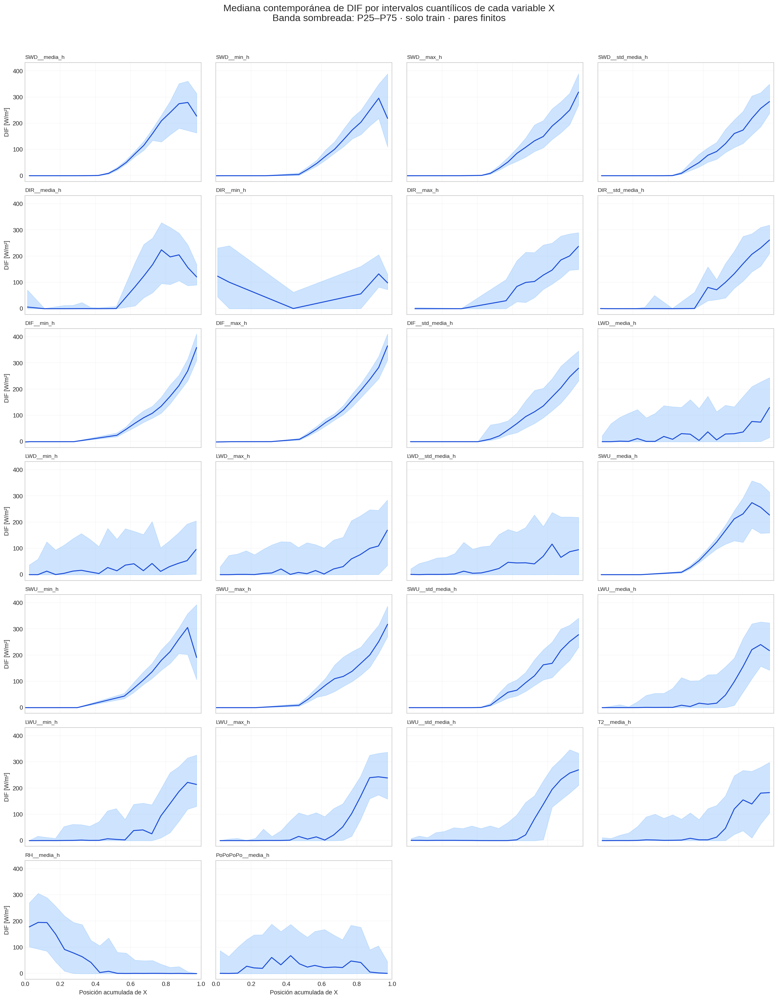

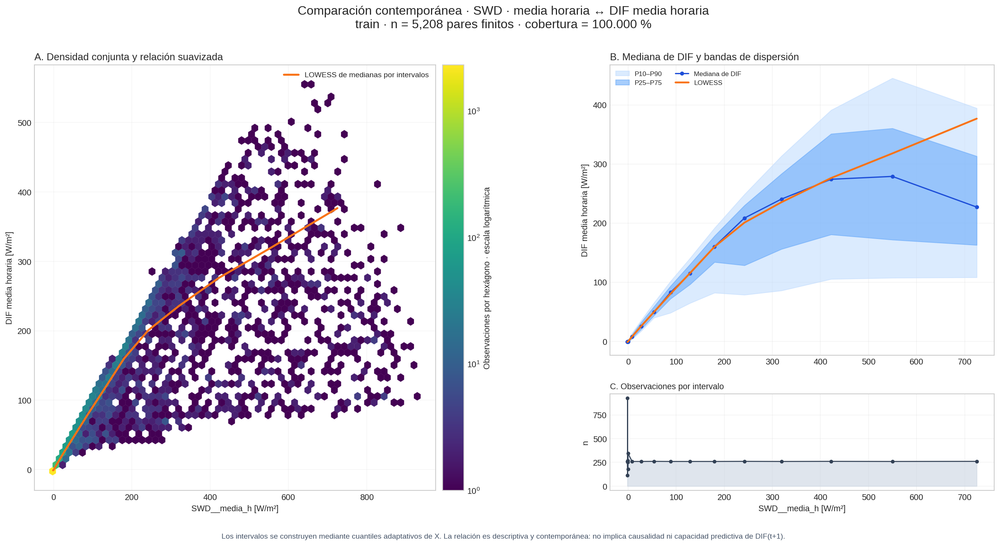

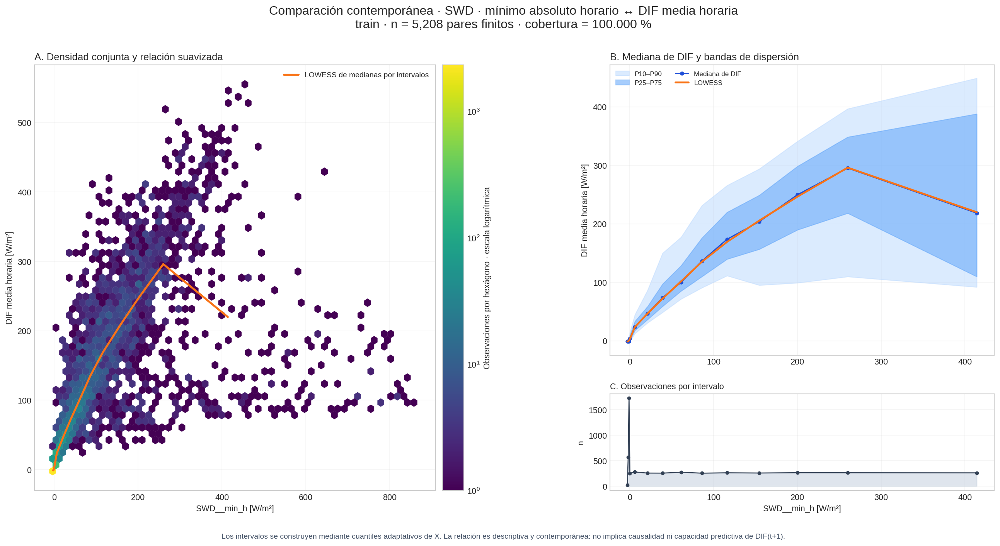

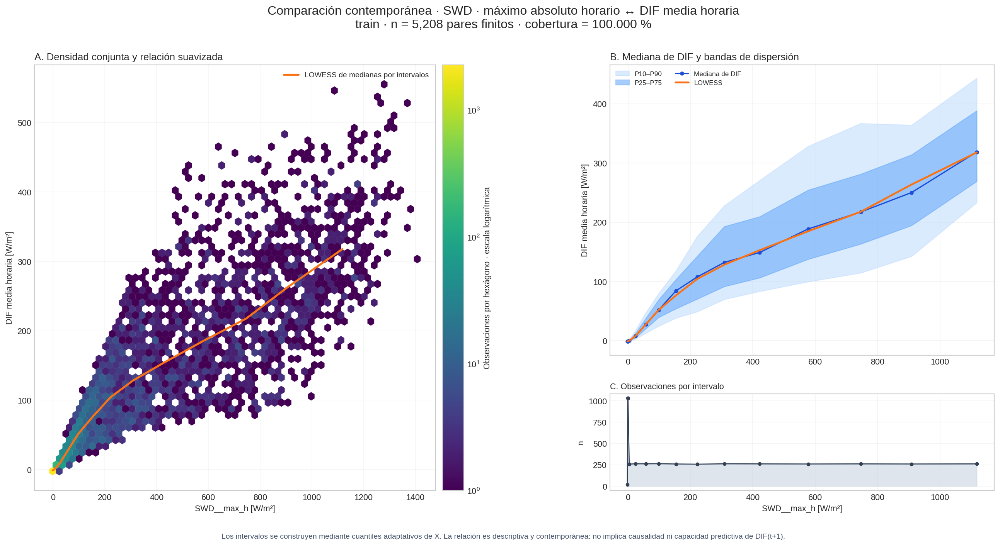

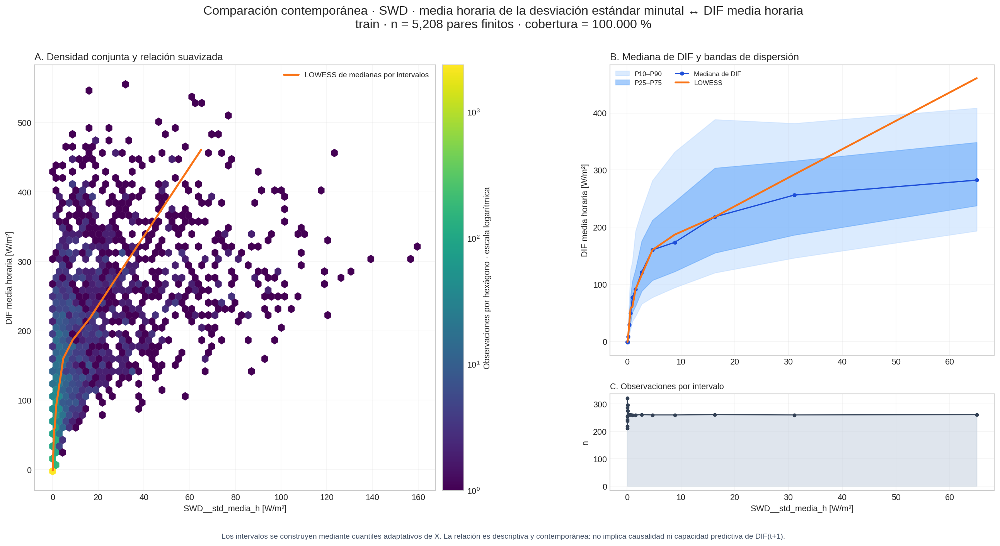

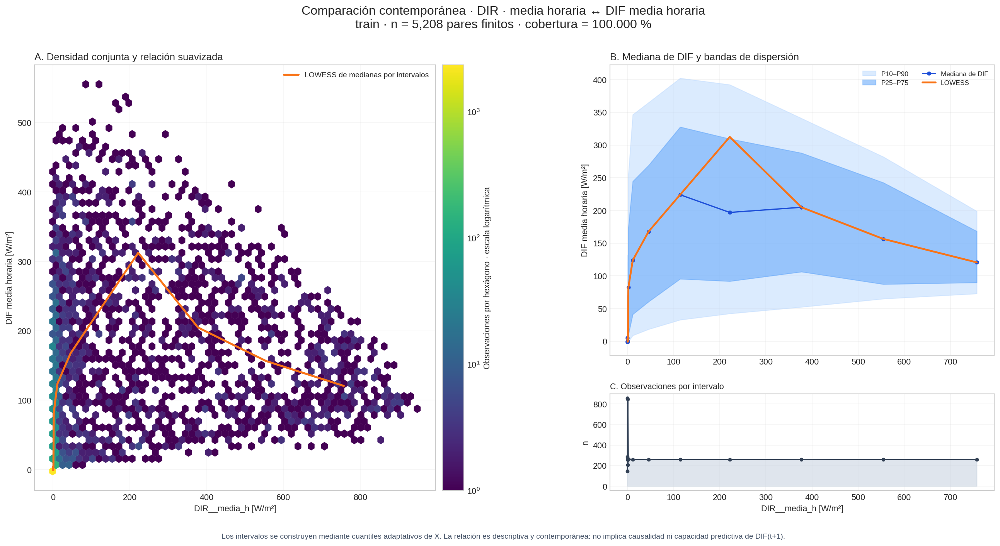

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
# Comparaciones contemporáneas X(t) ↔ DIF(t) durante entrenamiento
import sys
import subprocess
import importlib
import importlib.util

def instalar_si_falta(modulo, paquete):
    """Instala una dependencia únicamente cuando no está disponible."""
    if importlib.util.find_spec(modulo) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])
        importlib.invalidate_caches()

instalar_si_falta("pyarrow", "pyarrow")
try:
    from statsmodels.nonparametric.smoothers_lowess import lowess
except (ImportError, ModuleNotFoundError):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "statsmodels>=0.14.0"])
    importlib.invalidate_caches()
    from statsmodels.nonparametric.smoothers_lowess import lowess

import io
import hashlib
import json
import os
import platform
import re
import uuid
import zipfile
from datetime import datetime, timezone
from importlib.metadata import version as version_paquete
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
try:
    from IPython.display import Image, display
except ImportError:
    class Image:
        def __init__(self, filename):
            self.filename = filename

    def display(value):
        print(value)

try:
    from google.colab import files
    EN_COLAB = True
except ImportError:
    files = None
    EN_COLAB = False


# 1. Contrato de la subsección
PARTICION_ANALIZADA = "train"
COLUMNA_OBJETIVO = "DIF__media_h"
MAX_INTERVALOS_CUANTILES = 20
FRACCION_LOWESS = 0.35
ITERACIONES_ROBUSTAS_LOWESS = 3
HEXBIN_GRIDSIZE = 55
MAX_FIGURAS_MOSTRADAS = 5
CHECKPOINTS_PRIORITARIOS = [
    "checkpoints/13_tabla_horaria_con_geometria_solar_sin_cambios.parquet",
    "checkpoints/12_tabla_horaria_con_geometria_solar_sin_cambios.parquet",
    "checkpoints/11_tabla_horaria_con_geometria_solar_sin_cambios.parquet",
    "checkpoints/10_tabla_horaria_con_geometria_solar_sin_cambios.parquet",
    "checkpoints/10_tabla_horaria_con_geometria_solar.parquet",
]
FAMILIAS_RADIOMETRICAS = ["SWD", "DIR", "DIF", "LWD", "SWU", "LWU"]
ESTADISTICOS_RADIOMETRICOS = [
    ("media", "__media_h", "Media horaria"),
    ("min", "__min_h", "Mínimo absoluto horario"),
    ("max", "__max_h", "Máximo absoluto horario"),
    ("std_media", "__std_media_h", "Media horaria de la desviación estándar minutal"),
]
VARIABLES_METEOROLOGICAS = [
    ("T2", "Temperatura a 2 m", "°C"),
    ("RH", "Humedad relativa", "%"),
    ("PoPoPoPo", "Presión atmosférica", "hPa"),
]


# 2. Funciones auxiliares de entrada, integridad y formato
def sha256_bytes(contenido):
    return hashlib.sha256(contenido).hexdigest()

def sha256_archivo(ruta, tamano_bloque=1024 * 1024):
    resumen = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        while True:
            bloque = archivo.read(tamano_bloque)
            if not bloque:
                break
            resumen.update(bloque)
    return resumen.hexdigest()

def guardar_csv(tabla, ruta):
    tabla.to_csv(ruta, index=False, encoding="utf-8-sig")

def guardar_json(objeto, ruta):
    Path(ruta).write_text(
        json.dumps(objeto, ensure_ascii=False, indent=2, default=str), encoding="utf-8"
    )

def nombre_seguro(texto):
    limpio = re.sub(r"[^A-Za-z0-9._-]+", "_", str(texto)).strip("_")
    return limpio or "variable"

def obtener_entrada():
    if EN_COLAB:
        print(
            "Selecciona un único ZIP validado que contenga el checkpoint horario "
            "sin cambios, preferentemente la salida de la subsección 4.2.4."
        )
        subidos = files.upload()
        assert len(subidos) == 1, "Selecciona exactamente un ZIP o parquet."
        return next(iter(subidos.items()))

    ruta_entrada = os.environ.get("INPUT_CONTEMPORANEAS_FILE", "").strip()
    assert ruta_entrada, (
        "Fuera de Colab define INPUT_CONTEMPORANEAS_FILE con la ruta al ZIP "
        "validado de 4.2.4 o al checkpoint parquet."
    )
    ruta = Path(ruta_entrada).expanduser().resolve()
    assert ruta.is_file(), f"No existe el archivo de entrada: {ruta}"
    return ruta.name, ruta.read_bytes()

def elegir_checkpoint_parquet(nombres):
    candidatos = [n for n in nombres if str(n).lower().endswith(".parquet")]
    assert candidatos, "La entrada no contiene ningún checkpoint parquet."

    def prioridad(nombre):
        nombre_l = str(nombre).lower()
        for posicion, esperado in enumerate(CHECKPOINTS_PRIORITARIOS):
            if nombre_l == esperado.lower():
                return posicion
        if "tabla_horaria_con_geometria_solar" in nombre_l:
            return len(CHECKPOINTS_PRIORITARIOS)
        if "tabla_horaria" in nombre_l:
            return len(CHECKPOINTS_PRIORITARIOS) + 1
        return len(CHECKPOINTS_PRIORITARIOS) + 2

    return sorted(candidatos, key=lambda n: (prioridad(n), str(n)))[0]

def cargar_tabla_y_checkpoint(nombre, contenido):
    nombre_l = nombre.lower()
    if nombre_l.endswith(".zip"):
        assert zipfile.is_zipfile(io.BytesIO(contenido)), "El archivo no es un ZIP válido."
        with zipfile.ZipFile(io.BytesIO(contenido)) as archivo_zip:
            archivo_danado = archivo_zip.testzip()
            assert archivo_danado is None, f"Archivo dañado dentro del ZIP: {archivo_danado}"
            ruta_checkpoint = elegir_checkpoint_parquet(archivo_zip.namelist())
            bytes_checkpoint = archivo_zip.read(ruta_checkpoint)
        tabla = pd.read_parquet(io.BytesIO(bytes_checkpoint))
        return tabla, ruta_checkpoint, bytes_checkpoint

    if nombre_l.endswith(".parquet"):
        ruta_checkpoint = CHECKPOINTS_PRIORITARIOS[0]
        tabla = pd.read_parquet(io.BytesIO(contenido))
        return tabla, ruta_checkpoint, contenido

    raise AssertionError("La entrada debe ser un ZIP o un parquet válido.")

def detectar_columna_temporal(columnas):
    candidatas = ["timestamp_utc", "Date/Time", "timestamp", "fecha_hora", "datetime", "date_time"]
    for candidata in candidatas:
        if candidata in columnas:
            return candidata

    for columna in columnas:
        nombre = str(columna).lower().replace(" ", "")
        if "timestamp" in nombre or ("date" in nombre and "time" in nombre):
            return columna
    return None

def detectar_columna_particion(columnas):
    candidatas = ["particion_observacion", "particion", "partition", "split"]
    for candidata in candidatas:
        if candidata in columnas:
            return candidata

    for columna in columnas:
        nombre = str(columna).lower()
        if "particion" in nombre or "partition" in nombre:
            return columna
    return None

def crear_inventario_archivos(ruta_base):
    filas = []
    for ruta in sorted(Path(ruta_base).rglob("*")):
        if ruta.is_file() and ruta.name != "inventario_archivos.csv":
            filas.append(
                {
                    "archivo": str(ruta.relative_to(ruta_base)),
                    "tamano_bytes": ruta.stat().st_size,
                    "sha256": sha256_archivo(ruta),
                }
            )
    return pd.DataFrame(filas)

def crear_zip(ruta_base, ruta_zip):
    with zipfile.ZipFile(ruta_zip, "w", compression=zipfile.ZIP_DEFLATED) as zf:
        for ruta in sorted(Path(ruta_base).rglob("*")):
            if ruta.is_file():
                zf.write(ruta, arcname=str(ruta.relative_to(ruta_base)))

    with zipfile.ZipFile(ruta_zip) as zf:
        assert zf.testzip() is None, "El ZIP de salida no superó la comprobación CRC."


# 3. Inventario de variables
def construir_especificacion_variables():
    filas = []
    orden = 1
    for familia in FAMILIAS_RADIOMETRICAS:
        for estadistico, sufijo, descripcion in ESTADISTICOS_RADIOMETRICOS:
            filas.append(
                {
                    "orden_global": orden,
                    "familia": familia,
                    "tipo": "radiométrica",
                    "estadistico": estadistico,
                    "columna": f"{familia}{sufijo}",
                    "descripcion": f"{familia} · {descripcion.lower()}",
                    "unidad": "W/m²",
                }
            )
            orden += 1

    for familia, descripcion, unidad in VARIABLES_METEOROLOGICAS:
        filas.append(
            {
                "orden_global": orden,
                "familia": familia,
                "tipo": "meteorológica",
                "estadistico": "media",
                "columna": f"{familia}__media_h",
                "descripcion": descripcion,
                "unidad": unidad,
            }
        )
        orden += 1

    especificacion_27 = pd.DataFrame(filas)
    assert len(especificacion_27) == 27
    assert especificacion_27["columna"].is_unique
    assert COLUMNA_OBJETIVO in especificacion_27["columna"].values
    especificacion_x = (
        especificacion_27.loc[especificacion_27["columna"] != COLUMNA_OBJETIVO]
        .copy()
        .reset_index(drop=True)
    )
    especificacion_x.insert(0, "orden_comparacion", np.arange(1, 27))
    assert len(especificacion_x) == 26
    return especificacion_27, especificacion_x


# 4. Preparación exclusiva de train y pares finitos
def preparar_train(tabla, especificacion_27):
    columna_tiempo = detectar_columna_temporal(tabla.columns)
    columna_particion = detectar_columna_particion(tabla.columns)
    assert columna_tiempo is not None, "No se encontró la columna temporal."
    assert columna_particion is not None, "No se encontró la columna de partición."
    columnas_variables = especificacion_27["columna"].tolist()
    faltantes = [c for c in columnas_variables if c not in tabla.columns]
    assert not faltantes, f"Faltan variables requeridas: {faltantes}"
    copia = tabla[[columna_tiempo, columna_particion, *columnas_variables]].copy()
    copia[columna_tiempo] = pd.to_datetime(copia[columna_tiempo], errors="coerce", utc=True)
    assert copia[columna_tiempo].notna().all(), "Hay timestamps no interpretables."
    mascara_train = (
        copia[columna_particion].astype(str).str.strip().str.lower() == PARTICION_ANALIZADA
    )
    train = copia.loc[mascara_train].copy()
    assert not train.empty, "La partición train está vacía."
    assert train[columna_tiempo].is_unique, "Hay timestamps duplicados en train."
    train = train.sort_values(columna_tiempo).set_index(columna_tiempo)
    indice_completo = pd.date_range(train.index.min(), train.index.max(), freq="h", tz="UTC")
    horas_estructurales_ausentes = indice_completo.difference(train.index)
    assert len(horas_estructurales_ausentes) == 0, (
        f"Train contiene {len(horas_estructurales_ausentes)} horas estructurales "
        "ausentes. Debe revisarse el eje temporal antes de continuar."
    )
    for columna in columnas_variables:
        train[columna] = pd.to_numeric(train[columna], errors="coerce")

    return train[columnas_variables], columna_tiempo, columna_particion

def obtener_pares_finitos(train, columna_x):
    x = train[columna_x].to_numpy(dtype=float)
    y = train[COLUMNA_OBJETIVO].to_numpy(dtype=float)
    mascara = np.isfinite(x) & np.isfinite(y)
    pares = pd.DataFrame(
        {"timestamp_utc": train.index[mascara], "x": x[mascara], "dif": y[mascara]}
    )
    return pares, mascara


# 5. Intervalos adaptativos, bandas de dispersión y curva LOWESS
def construir_intervalos_cuantiles(pares):
    x = pares["x"].to_numpy(dtype=float)
    y = pares["dif"].to_numpy(dtype=float)
    n = len(pares)
    assert n > 0, "No hay pares finitos."
    if np.allclose(x, x[0], rtol=0, atol=0):
        codigos = np.zeros(n, dtype=int)
        bordes = np.array([x[0], x[0]], dtype=float)
    else:
        cuantiles = np.linspace(0, 1, MAX_INTERVALOS_CUANTILES + 1)
        bordes = np.unique(np.quantile(x, cuantiles))
        if len(bordes) < 2:
            bordes = np.array([np.min(x), np.max(x)], dtype=float)
        codigos = np.searchsorted(bordes, x, side="right") - 1
        codigos = np.clip(codigos, 0, len(bordes) - 2)

    filas = []
    acumulado = 0
    for codigo in sorted(np.unique(codigos)):
        mascara = codigos == codigo
        xb = x[mascara]
        yb = y[mascara]
        n_bin = int(mascara.sum())
        if len(bordes) == 2 and bordes[0] == bordes[1]:
            limite_inferior = float(bordes[0])
            limite_superior = float(bordes[1])
        else:
            limite_inferior = float(bordes[codigo])
            limite_superior = float(bordes[codigo + 1])

        filas.append(
            {
                "intervalo": int(codigo + 1),
                "x_limite_inferior": limite_inferior,
                "x_limite_superior": limite_superior,
                "x_mediana": float(np.median(xb)),
                "x_media": float(np.mean(xb)),
                "dif_p10": float(np.quantile(yb, 0.10)),
                "dif_p25": float(np.quantile(yb, 0.25)),
                "dif_mediana": float(np.median(yb)),
                "dif_media": float(np.mean(yb)),
                "dif_p75": float(np.quantile(yb, 0.75)),
                "dif_p90": float(np.quantile(yb, 0.90)),
                "dif_iqr": float(np.quantile(yb, 0.75) - np.quantile(yb, 0.25)),
                "n_pares": n_bin,
                "porcentaje_pares": float(100 * n_bin / n),
                "percentil_central": float((acumulado + n_bin / 2) / n),
            }
        )
        acumulado += n_bin

    resumen = pd.DataFrame(filas).sort_values("x_mediana").reset_index(drop=True)
    assert int(resumen["n_pares"].sum()) == n
    return resumen

def suavizar_medianas(resumen_intervalos):
    puntos = (
        resumen_intervalos[["x_mediana", "dif_mediana"]]
        .dropna()
        .groupby("x_mediana", as_index=False)["dif_mediana"]
        .median()
        .sort_values("x_mediana")
    )
    if len(puntos) < 4:
        curva = puntos.rename(columns={"x_mediana": "x_suavizada", "dif_mediana": "dif_suavizada"})
        curva["metodo"] = "unión de medianas; menos de cuatro puntos"
        return curva

    fraccion = max(FRACCION_LOWESS, min(1.0, 4 / len(puntos)))
    ajuste = lowess(
        endog=puntos["dif_mediana"].to_numpy(dtype=float),
        exog=puntos["x_mediana"].to_numpy(dtype=float),
        frac=fraccion,
        it=ITERACIONES_ROBUSTAS_LOWESS,
        is_sorted=True,
        return_sorted=True,
    )
    curva = pd.DataFrame(
        {
            "x_suavizada": ajuste[:, 0],
            "dif_suavizada": ajuste[:, 1],
            "metodo": (
                f"LOWESS robusto sobre medianas de intervalos; frac={fraccion:.3f}; "
                f"it={ITERACIONES_ROBUSTAS_LOWESS}"
            ),
        }
    )
    return curva


# 6. Figuras individuales y resumen
def crear_figura_variable(pares, resumen_intervalos, curva, fila, cobertura, ruta_salida):
    figura = plt.figure(figsize=(18, 9))
    rejilla = figura.add_gridspec(
        2, 2, width_ratios=(1.25, 1), height_ratios=(3, 1), wspace=0.22, hspace=0.20
    )
    ax_hexbin = figura.add_subplot(rejilla[:, 0])
    ax_bandas = figura.add_subplot(rejilla[0, 1])
    ax_conteos = figura.add_subplot(rejilla[1, 1], sharex=ax_bandas)
    hexagonos = ax_hexbin.hexbin(
        pares["x"],
        pares["dif"],
        gridsize=HEXBIN_GRIDSIZE,
        mincnt=1,
        bins="log",
        cmap="viridis",
        linewidths=0.15,
    )
    barra = figura.colorbar(hexagonos, ax=ax_hexbin, pad=0.015)
    barra.set_label("Observaciones por hexágono · escala logarítmica")
    ax_hexbin.plot(
        curva["x_suavizada"],
        curva["dif_suavizada"],
        color="#f97316",
        linewidth=2.4,
        label="LOWESS de medianas por intervalos",
        zorder=4,
    )
    ax_hexbin.set_title("A. Densidad conjunta y relación suavizada", loc="left")
    ax_hexbin.set_xlabel(f"{fila.columna} [{fila.unidad}]")
    ax_hexbin.set_ylabel("DIF media horaria [W/m²]")
    ax_hexbin.grid(alpha=0.18)
    ax_hexbin.legend(loc="best", fontsize=9)
    x_bin = resumen_intervalos["x_mediana"].to_numpy(dtype=float)
    p10 = resumen_intervalos["dif_p10"].to_numpy(dtype=float)
    p25 = resumen_intervalos["dif_p25"].to_numpy(dtype=float)
    mediana = resumen_intervalos["dif_mediana"].to_numpy(dtype=float)
    p75 = resumen_intervalos["dif_p75"].to_numpy(dtype=float)
    p90 = resumen_intervalos["dif_p90"].to_numpy(dtype=float)
    ax_bandas.fill_between(x_bin, p10, p90, color="#bfdbfe", alpha=0.55, label="P10–P90")
    ax_bandas.fill_between(x_bin, p25, p75, color="#60a5fa", alpha=0.55, label="P25–P75")
    ax_bandas.plot(
        x_bin,
        mediana,
        color="#1d4ed8",
        marker="o",
        markersize=3.8,
        linewidth=1.5,
        label="Mediana de DIF",
    )
    ax_bandas.plot(
        curva["x_suavizada"], curva["dif_suavizada"], color="#f97316", linewidth=2.2, label="LOWESS"
    )
    ax_bandas.set_title("B. Mediana de DIF y bandas de dispersión", loc="left")
    ax_bandas.set_ylabel("DIF media horaria [W/m²]")
    ax_bandas.grid(alpha=0.22)
    ax_bandas.legend(loc="best", fontsize=8, ncol=2)
    ax_conteos.plot(
        x_bin,
        resumen_intervalos["n_pares"],
        color="#334155",
        marker="o",
        markersize=3.5,
        linewidth=1.2,
    )
    ax_conteos.fill_between(
        x_bin, 0, resumen_intervalos["n_pares"].to_numpy(dtype=float), color="#cbd5e1", alpha=0.6
    )
    ax_conteos.set_title("C. Observaciones por intervalo", loc="left", fontsize=10)
    ax_conteos.set_xlabel(f"{fila.columna} [{fila.unidad}]")
    ax_conteos.set_ylabel("n")
    ax_conteos.grid(alpha=0.22)
    figura.suptitle(
        f"Comparación contemporánea · {fila.descripcion} ↔ DIF media horaria\n"
        f"train · n = {len(pares):,} pares finitos · cobertura = {cobertura:.3f} %",
        fontsize=15,
        y=0.995,
    )
    figura.text(
        0.5,
        0.006,
        (
            "Los intervalos se construyen mediante cuantiles adaptativos de X. "
            "La relación es descriptiva y contemporánea: no implica causalidad "
            "ni capacidad predictiva de DIF(t+1)."
        ),
        ha="center",
        fontsize=9,
        color="#475569",
    )
    # ``tight_layout`` emite un aviso espurio cuando la figura contiene la
    # barra de color del hexbin. Los márgenes explícitos mantienen el mismo
    # diseño y evitan presentar ese aviso como si fuera un fallo del análisis.
    figura.subplots_adjust(left=0.065, right=0.955, bottom=0.095, top=0.885)
    figura.savefig(ruta_salida, dpi=155, bbox_inches="tight")
    plt.close(figura)

def crear_resumen_curvas(tabla_intervalos, especificacion_x, ruta_salida):
    n_filas = 7
    n_columnas = 4
    figura, ejes = plt.subplots(n_filas, n_columnas, figsize=(18, 23), sharex=True, sharey=True)
    ejes = ejes.ravel()
    for ax, fila in zip(ejes, especificacion_x.itertuples(index=False)):
        datos = tabla_intervalos.loc[tabla_intervalos["columna"] == fila.columna].sort_values(
            "percentil_central"
        )
        ax.fill_between(
            datos["percentil_central"].to_numpy(dtype=float),
            datos["dif_p25"].to_numpy(dtype=float),
            datos["dif_p75"].to_numpy(dtype=float),
            color="#93c5fd",
            alpha=0.45,
        )
        ax.plot(datos["percentil_central"], datos["dif_mediana"], color="#1d4ed8", linewidth=1.6)
        ax.set_title(fila.columna, fontsize=9, loc="left")
        ax.grid(alpha=0.18)
        ax.set_xlim(0, 1)

    for ax in ejes[len(especificacion_x) :]:
        ax.axis("off")

    for indice, ax in enumerate(ejes[: len(especificacion_x)]):
        if indice // n_columnas == n_filas - 1:
            ax.set_xlabel("Posición acumulada de X")
        if indice % n_columnas == 0:
            ax.set_ylabel("DIF [W/m²]")

    figura.suptitle(
        "Mediana contemporánea de DIF por intervalos cuantílicos de cada variable X\n"
        "Banda sombreada: P25–P75 · solo train · pares finitos",
        fontsize=16,
        y=0.998,
    )
    figura.tight_layout(rect=(0, 0, 1, 0.98))
    figura.savefig(ruta_salida, dpi=155, bbox_inches="tight")
    plt.close(figura)


# 7. Ejecución
nombre_entrada, contenido_entrada = obtener_entrada()
tabla_fuente, ruta_checkpoint, bytes_checkpoint = cargar_tabla_y_checkpoint(
    nombre_entrada, contenido_entrada
)
sha_checkpoint_entrada = sha256_bytes(bytes_checkpoint)
especificacion_27, especificacion_x = construir_especificacion_variables()
train, columna_tiempo, columna_particion = preparar_train(tabla_fuente, especificacion_27)
print(f"Entrada: {nombre_entrada}")
print(f"Checkpoint: {ruta_checkpoint}")
print(f"Horas de entrenamiento: {len(train):,}")
print(f"Objetivo: {COLUMNA_OBJETIVO}")
print(f"Variables X comparadas: {len(especificacion_x)}")
print("Imputaciones aplicadas en esta subsección: 0")
marca_tiempo = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
identificador = uuid.uuid4().hex[:8]
carpeta_salida = Path(f"salida_F4_S4_25_{marca_tiempo}_{identificador}")
carpeta_figuras = carpeta_salida / "figuras" / "01_por_variable"
carpeta_resumen = carpeta_salida / "figuras" / "00_resumen"
carpeta_tablas = carpeta_salida / "tablas"
carpeta_configuracion = carpeta_salida / "configuracion"
for carpeta in [carpeta_figuras, carpeta_resumen, carpeta_tablas, carpeta_configuracion]:
    carpeta.mkdir(parents=True, exist_ok=True)

# El checkpoint se copia byte a byte; no se reescribe ni modifica.
ruta_checkpoint_salida = carpeta_salida / ruta_checkpoint
ruta_checkpoint_salida.parent.mkdir(parents=True, exist_ok=True)
ruta_checkpoint_salida.write_bytes(bytes_checkpoint)
assert sha256_archivo(ruta_checkpoint_salida) == sha_checkpoint_entrada
filas_cobertura = []
tablas_intervalos = []
tablas_curvas = []
filas_figuras = []
for posicion, fila in enumerate(especificacion_x.itertuples(index=False), start=1):
    pares, mascara_pares = obtener_pares_finitos(train, fila.columna)
    assert len(pares) > 0, f"{fila.columna}: no existen pares finitos con DIF."
    n_total = len(train)
    n_pares = len(pares)
    cobertura = float(100 * n_pares / n_total)
    n_x_finito = int(np.isfinite(train[fila.columna].to_numpy(dtype=float)).sum())
    n_dif_finito = int(np.isfinite(train[COLUMNA_OBJETIVO].to_numpy(dtype=float)).sum())
    resumen_intervalos = construir_intervalos_cuantiles(pares)
    curva = suavizar_medianas(resumen_intervalos)
    resumen_intervalos.insert(0, "columna", fila.columna)
    resumen_intervalos.insert(0, "orden_comparacion", fila.orden_comparacion)
    curva.insert(0, "columna", fila.columna)
    curva.insert(0, "orden_comparacion", fila.orden_comparacion)
    tablas_intervalos.append(resumen_intervalos)
    tablas_curvas.append(curva)
    filas_cobertura.append(
        {
            "orden_comparacion": fila.orden_comparacion,
            "columna": fila.columna,
            "n_horas_train": n_total,
            "n_x_finito": n_x_finito,
            "n_dif_finito": n_dif_finito,
            "n_pares_finitos": n_pares,
            "n_excluidos_no_finitos": int(n_total - n_pares),
            "cobertura_pares_pct": cobertura,
            "n_intervalos_efectivos": int(len(resumen_intervalos)),
            "x_min_pares": float(pares["x"].min()),
            "x_max_pares": float(pares["x"].max()),
            "dif_min_pares": float(pares["dif"].min()),
            "dif_max_pares": float(pares["dif"].max()),
        }
    )
    nombre_figura = (
        f"{fila.orden_comparacion:02d}_{nombre_seguro(fila.columna)}" "_vs_DIF_contemporanea.png"
    )
    ruta_figura = carpeta_figuras / nombre_figura
    crear_figura_variable(pares, resumen_intervalos, curva, fila, cobertura, ruta_figura)
    filas_figuras.append(
        {
            "orden_comparacion": fila.orden_comparacion,
            "columna": fila.columna,
            "figura": str(ruta_figura.relative_to(carpeta_salida)),
        }
    )
    print(
        f"[{posicion:02d}/26] {fila.columna} ↔ {COLUMNA_OBJETIVO}: "
        f"{n_pares:,} pares; {len(resumen_intervalos)} intervalos"
    )

tabla_cobertura = pd.DataFrame(filas_cobertura).sort_values("orden_comparacion")
tabla_intervalos = pd.concat(tablas_intervalos, ignore_index=True)
tabla_curvas = pd.concat(tablas_curvas, ignore_index=True)
indice_figuras = pd.DataFrame(filas_figuras).sort_values("orden_comparacion")
guardar_csv(especificacion_x, carpeta_tablas / "01_inventario_26_comparaciones.csv")
guardar_csv(tabla_cobertura, carpeta_tablas / "02_cobertura_pares_finitos_train.csv")
guardar_csv(tabla_intervalos, carpeta_tablas / "03_estadisticos_DIF_por_intervalos_X.csv")
guardar_csv(tabla_curvas, carpeta_tablas / "04_curvas_LOWESS_medianas.csv")
guardar_csv(indice_figuras, carpeta_tablas / "05_indice_figuras.csv")
ruta_figura_resumen = carpeta_resumen / "00_resumen_mediana_DIF_por_percentiles_X.png"
crear_resumen_curvas(tabla_intervalos, especificacion_x, ruta_figura_resumen)
configuracion = {
    "fase": 4,
    "subseccion": "4.2.5",
    "titulo": "Comparaciones contemporáneas X(t) ↔ DIF(t)",
    "creado_utc": datetime.now(timezone.utc).isoformat(),
    "entrada": {
        "archivo": nombre_entrada,
        "checkpoint": ruta_checkpoint,
        "sha256_checkpoint": sha_checkpoint_entrada,
    },
    "contrato": {
        "particion": PARTICION_ANALIZADA,
        "n_horas": int(len(train)),
        "inicio_utc": train.index.min().isoformat(),
        "fin_utc": train.index.max().isoformat(),
        "objetivo": COLUMNA_OBJETIVO,
        "n_variables_x": int(len(especificacion_x)),
        "relacion": "contemporánea X(t) ↔ DIF(t)",
        "imputacion": False,
        "criterio_30_60_aplicado": False,
        "mascara": "pares finitos específica para cada X",
        "intervalos": {
            "metodo": "cuantiles adaptativos de X con bordes duplicados eliminados",
            "max_intervalos": MAX_INTERVALOS_CUANTILES,
            "estadisticos_dif": ["P10", "P25", "mediana", "media", "P75", "P90"],
        },
        "suavizado": {
            "metodo": "LOWESS robusto sobre medianas por intervalos",
            "frac_base": FRACCION_LOWESS,
            "iteraciones_robustas": ITERACIONES_ROBUSTAS_LOWESS,
        },
        "hexbin_gridsize": HEXBIN_GRIDSIZE,
    },
    "validacion": {
        "checkpoint_preservado_sin_cambios": True,
        "horas_estructurales_ausentes": 0,
        "n_figuras_individuales": int(len(indice_figuras)),
        "suma_imputaciones": 0,
        "cobertura_pares_min_pct": float(tabla_cobertura["cobertura_pares_pct"].min()),
        "cobertura_pares_max_pct": float(tabla_cobertura["cobertura_pares_pct"].max()),
    },
    "advertencias": [
        "Las asociaciones son contemporáneas y descriptivas.",
        "No implican causalidad ni capacidad predictiva de DIF(t+1).",
        "La autocorrelación temporal impide interpretar los pares como observaciones independientes.",
        "Los regímenes solares no se separan en esta subsección.",
        "El cúmulo nocturno próximo a cero puede dominar las relaciones radiométricas.",
        "LOWESS se aplica a medianas de intervalos, no directamente a todos los pares.",
    ],
    "versiones": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "matplotlib": version_paquete("matplotlib"),
        "statsmodels": version_paquete("statsmodels"),
        "pyarrow": version_paquete("pyarrow"),
    },
}
guardar_json(configuracion, carpeta_configuracion / "configuracion_4_2_5.json")
readme = f"""# Subsección 4.2.5 · Comparaciones contemporáneas X(t) ↔ DIF(t)

Se comparó cada una de las 26 variables X con la media horaria de DIF utilizando
exclusivamente las {len(train):,} horas de la partición train.

## Procedimiento

Para cada variable se utilizaron únicamente los pares X–DIF finitos, sin
imputación ni aplicación del criterio 30/60. Se generaron:

- un hexbin con densidad de observaciones en escala logarítmica;
- la mediana de DIF por intervalos cuantílicos adaptativos de X;
- bandas P25–P75 y P10–P90;
- una curva LOWESS robusta ajustada sobre las medianas de los intervalos;
- el número de observaciones utilizado en cada intervalo.

## Contenido

- figuras/00_resumen/: resumen de las 26 curvas por percentiles de X.
- figuras/01_por_variable/: 26 comparaciones individuales.
- tablas/01_inventario_26_comparaciones.csv: variables analizadas.
- tablas/02_cobertura_pares_finitos_train.csv: cobertura específica de cada par.
- tablas/03_estadisticos_DIF_por_intervalos_X.csv: medianas, bandas y conteos.
- tablas/04_curvas_LOWESS_medianas.csv: puntos de las curvas suavizadas.
- tablas/05_indice_figuras.csv: correspondencia entre variables y figuras.
- {ruta_checkpoint}: checkpoint original conservado sin cambios.

## Alcance

Las relaciones son contemporáneas, X(t) ↔ DIF(t). Permiten describir formas
lineales o no lineales, saturaciones, umbrales, agrupaciones y cambios de
dispersión, pero no demuestran causalidad ni capacidad para predecir DIF(t+1).

En las variables radiométricas, las horas nocturnas y la geometría solar pueden
generar asociaciones comunes o cúmulos próximos a cero. La separación por
regímenes de elevación solar se reserva para la subsección 4.2.8. Debido a la
autocorrelación temporal, las observaciones tampoco deben tratarse como pares
estadísticamente independientes.
"""
(carpeta_salida / "README.md").write_text(readme, encoding="utf-8")
inventario = crear_inventario_archivos(carpeta_salida)
guardar_csv(inventario, carpeta_salida / "inventario_archivos.csv")
ruta_zip_salida = Path(f"EDA_multivariante_F4_S4_25_{marca_tiempo}_{identificador}.zip")
crear_zip(carpeta_salida, ruta_zip_salida)
print("\nValidación completada")
print(
    "- checkpoint preservado: "
    f"{sha256_archivo(ruta_checkpoint_salida) == sha_checkpoint_entrada}"
)
print(f"- comparaciones: {len(indice_figuras)}")
print("- cobertura mínima de pares: " f"{tabla_cobertura['cobertura_pares_pct'].min():.3f} %")
print(f"- salida: {ruta_zip_salida.resolve()}")
display(tabla_cobertura)
display(tabla_intervalos.head(30))
display(Image(filename=str(ruta_figura_resumen)))
for ruta_relativa in indice_figuras["figura"].head(MAX_FIGURAS_MOSTRADAS):
    display(Image(filename=str(carpeta_salida / ruta_relativa)))

if EN_COLAB:
    files.download(str(ruta_zip_salida))

**Resultados.**

Las comparaciones contemporáneas entre las 26 covariables y la irradiancia difusa media horaria se realizaron utilizando exclusivamente las 5.208 observaciones del conjunto de entrenamiento, con una máscara de pares finitos específica para cada variable. Las medianas por intervalos cuantílicos y las bandas P25–P75 y P10–P90 permitieron identificar asociaciones no lineales, cambios de dirección y diferencias en la dispersión condicional de DIF.

SWD y SWU presentaron formas de asociación semejantes, aunque con diferencias relevantes entre sus estadísticos. Sus medias y mínimos mostraron un crecimiento de la mediana de DIF hasta rangos elevados de X, seguido de un descenso en los intervalos superiores. Por ejemplo, para SWD media, la mediana de DIF pasó de 279,0 W/m² en el intervalo 480,9–622,9 W/m² a 227,1 W/m² en el intervalo 622,9–929,0 W/m², con 260 y 261 pares, respectivamente. Los máximos de ambas familias mantuvieron, en cambio, una relación creciente hasta el último intervalo. Estas diferencias indican que el nivel medio y los extremos horarios no describen de forma equivalente la asociación con DIF (figuras F01–F03 y F16–F18; tabla T03).

DIR media mostró una relación no monótona, con una mediana máxima de DIF de 223,9 W/m² para DIR comprendida entre 72,59 y 166,42 W/m², seguida de valores centrales menores en los intervalos superiores. Su máximo y su variabilidad rápida presentaron asociaciones predominantemente crecientes. El mínimo de DIR ofreció una caracterización menos definida: un único intervalo cercano a cero reunió 3.193 pares, equivalentes al 61,3 % de la muestra. Aunque su mediana de DIF fue próxima a cero, P90 alcanzó 218,7 W/m², por lo que esa acumulación no puede interpretarse exclusivamente como observaciones nocturnas (figuras F05–F08; tabla T03).

Los valores elevados de `std_media_h` de SWD, SWU, DIR, DIF y LWU se asociaron, en general, con medianas mayores de DIF y una reducción progresiva de la pendiente. Sin embargo, la dispersión condicional no aumentó de forma continua: en varias variables, las bandas alcanzaron su mayor anchura antes del último intervalo y se estrecharon posteriormente. Por tanto, una mayor variabilidad rápida puede acompañar niveles superiores de DIF sin implicar una incertidumbre descriptiva cada vez mayor. Este estadístico resume la variabilidad minutal media dentro de la hora y no la variación entre días (figuras F04, F08, F11, F19 y F23; tabla T03).

LWU y T2 mostraron aumentos de la mediana de DIF concentrados en sus rangos altos, mientras que RH presentó una asociación predominantemente decreciente. Estas relaciones conservaron un considerable solapamiento entre distribuciones. Para T2 entre 16,60 y 17,66 °C, por ejemplo, la mediana de DIF fue de 154,7 W/m², pero P10–P90 abarcó desde −1,0 hasta 389,3 W/m², con 259 pares. LWD y presión atmosférica ofrecieron una separación marginal menos definida, caracterizada por medianas bajas o irregulares y bandas amplias (figuras F12–F15 y F20–F26; tabla T03).

Las asociaciones más regulares correspondieron al mínimo y al máximo de DIF, aunque su interpretación está condicionada por resumir la misma variable y la misma hora que el objetivo. Asimismo, las semejanzas entre SWD y SWU sugieren información compartida, pero no demuestran redundancia. La interpretación se apoyó principalmente en las medianas y los cuantiles tabulados, ya que algunas curvas LOWESS ocultaron o exageraron cambios locales.

Estos resultados motivan la evaluación de relaciones no lineales y comparaciones posteriores por régimen de iluminación. Las bandas describen dispersión empírica, no intervalos de confianza ni incertidumbre predictiva futura. Al tratarse de asociaciones contemporáneas, tampoco permiten establecer causalidad, identificar tendencias o estacionalidades compartidas, ni concluir que las covariables anticipen DIF en horas posteriores.

### 4.2.6 Detección de relaciones lineales y no lineales

Esta subsección cuantifica la dependencia contemporánea entre cada una de las 26 covariables y {DIF}(t) en la partición de entrenamiento, con el fin de distinguir asociaciones lineales, monotónicas no lineales o más generales. Se calculan el coeficiente de Pearson (asociación lineal), el de Spearman (asociación monotónica basada en rangos) y la información mutua (MI) estimada mediante vecinos próximos, expresada en nats, cuya sensibilidad se evalúa con k=3, k=5 y k=10. Las métricas se obtienen sobre todas las horas de entrenamiento y se repiten por meses completos entre enero y julio de 2024; diciembre de 2023 se excluye del análisis mensual por contener solo cuatro días. Se registran además el número de valores únicos y la frecuencia de la moda de cada variable, ya que la concentración de valores repetidos, como los ceros radiométricos nocturnos, puede influir en la estimación de la MI.

Selecciona un único ZIP validado que contenga el checkpoint horario con geometría solar (preferentemente la salida de 4.2.5).


Saving EDA_multivariante_F4_S4_25_20261102T173112Z_4ab4174f.zip to EDA_multivariante_F4_S4_25_20261102T173112Z_4ab4174f (1).zip
=== RESUMEN TÉCNICO 4.2.6 ===
Entrada: EDA_multivariante_F4_S4_25_20261102T173112Z_4ab4174f (1).zip
Checkpoint: checkpoints/13_tabla_horaria_con_geometria_solar_sin_cambios.parquet
Partición: train
Horas de entrenamiento: 5,208
Variables X: 26
Meses completos: 2024-01, 2024-02, 2024-03, 2024-04, 2024-05, 2024-06, 2024-07
Métricas: Pearson, Spearman y MI kNN (k=3, 5, 10)
Imputaciones: 0
Filas eliminadas: 0
P-valores iid: no calculados
Checkpoint preservado: SÍ



,particion_analizada,n_horas_train,inicio_train_utc,fin_train_utc,n_variables_x,objetivo,k_mi_globales,k_mi_mensual,meses_completos_estabilidad,n_meses_completos,n_figuras,n_saltos_no_horarios_train,filas_eliminadas,valores_imputados,filtro_30_60_aplicado,p_valores_iid_calculados,checkpoint_salida_verificado_identico
0,train,5208,2023-12-28 00:00:00+00:00,2024-07-31 23:00:00+00:00,26,DIF__media_h,"3,5,10",5,"2024-01,2024-02,2024-03,2024-04,2024-05,2024-0...",7,6,0,0,0,False,False,True


,orden,columna,familia,estadistico,n_pares,cobertura_pares_pct,pearson,spearman,abs_pearson,abs_spearman,...,mi_k10_nats,mi_mediana_k_nats,mi_rango_sensibilidad_k,n_valores_unicos_x,valor_moda_x,n_moda_x,porcentaje_moda_x,rango_abs_pearson,rango_abs_spearman,rango_mi
0,1,SWD__media_h,SWD,media,5208,100.000000,0.820237,0.940450,0.820237,0.940450,...,1.932030,1.994263,0.081280,2963,-1.000000,926,17.780338,6,5,1
1,2,SWD__min_h,SWD,min,5208,100.000000,0.706597,0.911546,0.706597,0.911546,...,1.127738,1.137793,0.011887,505,-1.000000,1729,33.198925,9,7,7
2,3,SWD__max_h,SWD,max,5208,100.000000,0.900999,0.953017,0.900999,0.953017,...,1.393844,1.396560,0.003841,1042,-1.000000,1032,19.815668,3,2,4
3,4,SWD__std_media_h,SWD,std_media,5208,100.000000,0.657311,0.906870,0.657311,0.906870,...,1.051547,1.084224,0.039294,2323,0.076667,96,1.843318,13,8,8
4,5,DIR__media_h,DIR,media,5208,100.000000,0.385872,0.679452,0.385872,0.679452,...,0.443058,0.461460,0.030171,2036,0.000000,857,16.455453,20,14,15
5,6,DIR__min_h,DIR,min,5208,100.000000,0.072204,0.139918,0.072204,0.139918,...,0.128727,0.134694,0.015688,366,0.000000,3193,61.309524,25,25,21
6,7,DIR__max_h,DIR,max,5208,100.000000,0.688252,0.769709,0.688252,0.769709,...,0.471400,0.483716,0.012964,816,1.000000,2262,43.433180,11,12,13
7,8,DIR__std_media_h,DIR,std_media,5208,100.000000,0.608200,0.734239,0.608200,0.734239,...,0.522294,0.527662,0.021159,2040,0.100000,778,14.938556,15,13,12
8,9,DIF__min_h,DIF,min,5208,100.000000,0.948989,0.942455,0.948989,0.942455,...,1.324589,1.335089,0.019331,351,-1.000000,2118,40.668203,2,4,5
9,10,DIF__max_h,DIF,max,5208,100.000000,0.968119,0.973609,0.968119,0.973609,...,1.693952,1.698832,0.011980,617,0.000000,1164,22.350230,1,1,2


,orden,columna,familia,estadistico,n_meses_completos,pearson_mensual_min,pearson_mensual_mediana,pearson_mensual_max,pearson_mensual_rango,pearson_global_menos_mediana_mensual,...,spearman_global_menos_mediana_mensual,mi_mensual_min,mi_mensual_mediana,mi_mensual_max,mi_mensual_rango,mi_global_menos_mediana_mensual,pearson_cambio_signo_entre_meses,pearson_fraccion_meses_mismo_signo_global,spearman_cambio_signo_entre_meses,spearman_fraccion_meses_mismo_signo_global
0,1,SWD__media_h,SWD,media,7,0.758241,0.835693,0.900427,0.142186,-0.015455,...,0.023119,1.583204,1.808451,1.973757,0.390553,0.185812,False,1.000000,False,1.000000
1,2,SWD__min_h,SWD,min,7,0.615100,0.728961,0.856684,0.241584,-0.022364,...,0.016698,0.939901,1.062482,1.207488,0.267586,0.077144,False,1.000000,False,1.000000
2,3,SWD__max_h,SWD,max,7,0.877267,0.891800,0.900650,0.023383,0.009198,...,0.008199,1.211147,1.321319,1.422184,0.211037,0.076366,False,1.000000,False,1.000000
3,4,SWD__std_media_h,SWD,std_media,7,0.535989,0.619240,0.679828,0.143839,0.038071,...,-0.005197,0.738529,0.942512,1.053045,0.314516,0.141712,False,1.000000,False,1.000000
4,5,DIR__media_h,DIR,media,7,0.277616,0.331215,0.494279,0.216663,0.054657,...,-0.007863,0.244766,0.430189,0.566924,0.322158,0.031271,False,1.000000,False,1.000000
5,6,DIR__min_h,DIR,min,7,-0.045803,0.099446,0.259374,0.305177,-0.027242,...,-0.095778,0.011448,0.162588,0.203730,0.192281,-0.027893,True,0.714286,False,1.000000
6,7,DIR__max_h,DIR,max,7,0.592609,0.668323,0.730903,0.138294,0.019929,...,0.002265,0.264423,0.482271,0.542500,0.278078,0.002093,False,1.000000,False,1.000000
7,8,DIR__std_media_h,DIR,std_media,7,0.489559,0.558985,0.640118,0.150559,0.049215,...,-0.072857,0.256614,0.520449,0.577748,0.321134,0.007213,False,1.000000,False,1.000000
8,9,DIF__min_h,DIF,min,7,0.937032,0.950120,0.965216,0.028184,-0.001131,...,-0.006963,1.014473,1.230551,1.519323,0.504850,0.113369,False,1.000000,False,1.000000
9,10,DIF__max_h,DIF,max,7,0.941256,0.966772,0.972566,0.031310,0.001347,...,0.005949,1.345206,1.573674,1.893189,0.547983,0.125158,False,1.000000,False,1.000000


=== FIGURAS ===
01_metricas_globales_Pearson_Spearman_MI.png


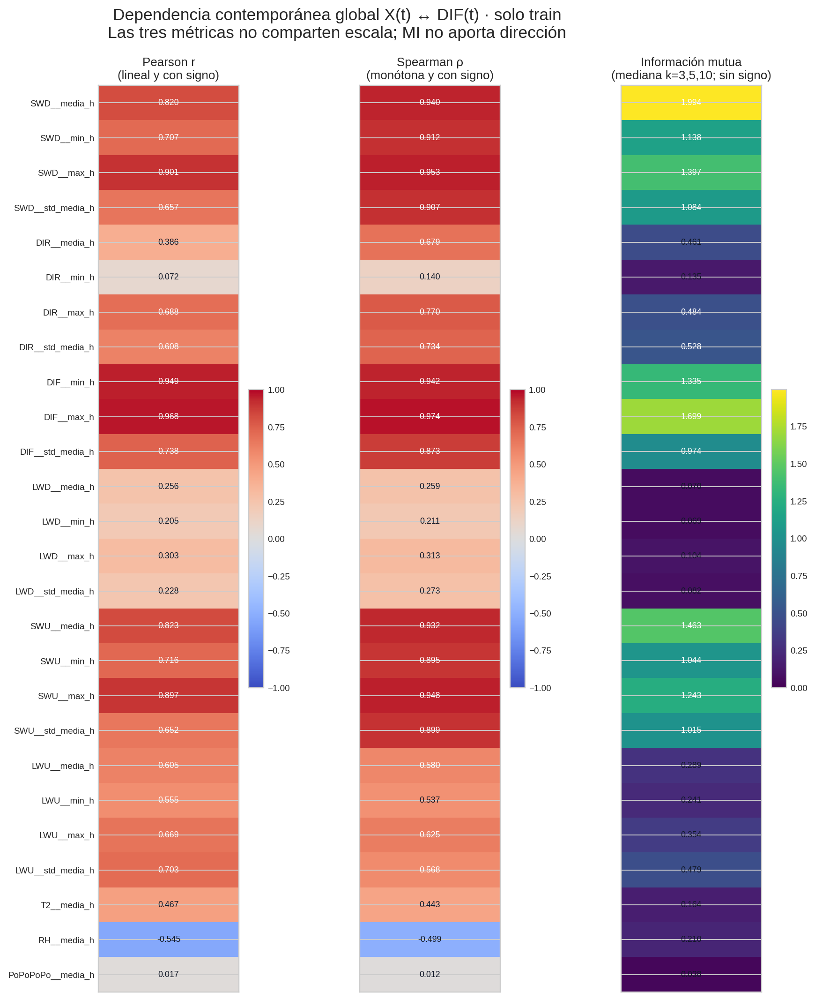

02_diagnostico_forma_y_estabilidad.png


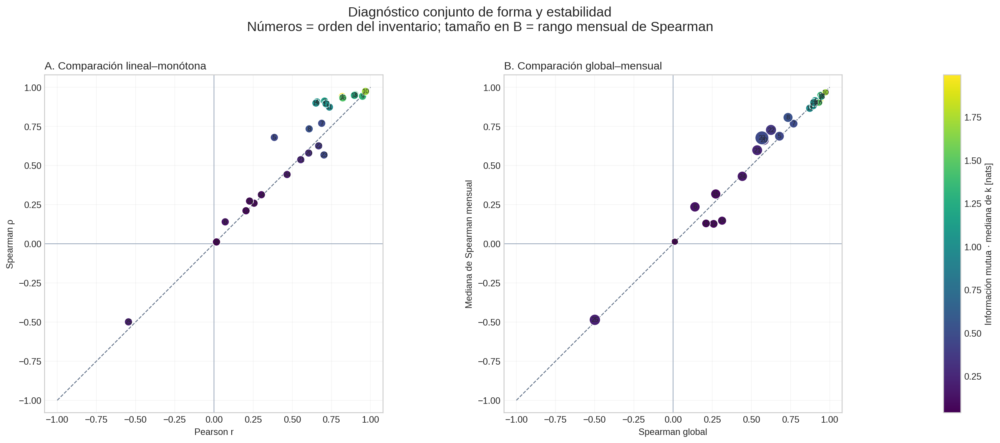

03_estabilidad_mensual_Pearson.png


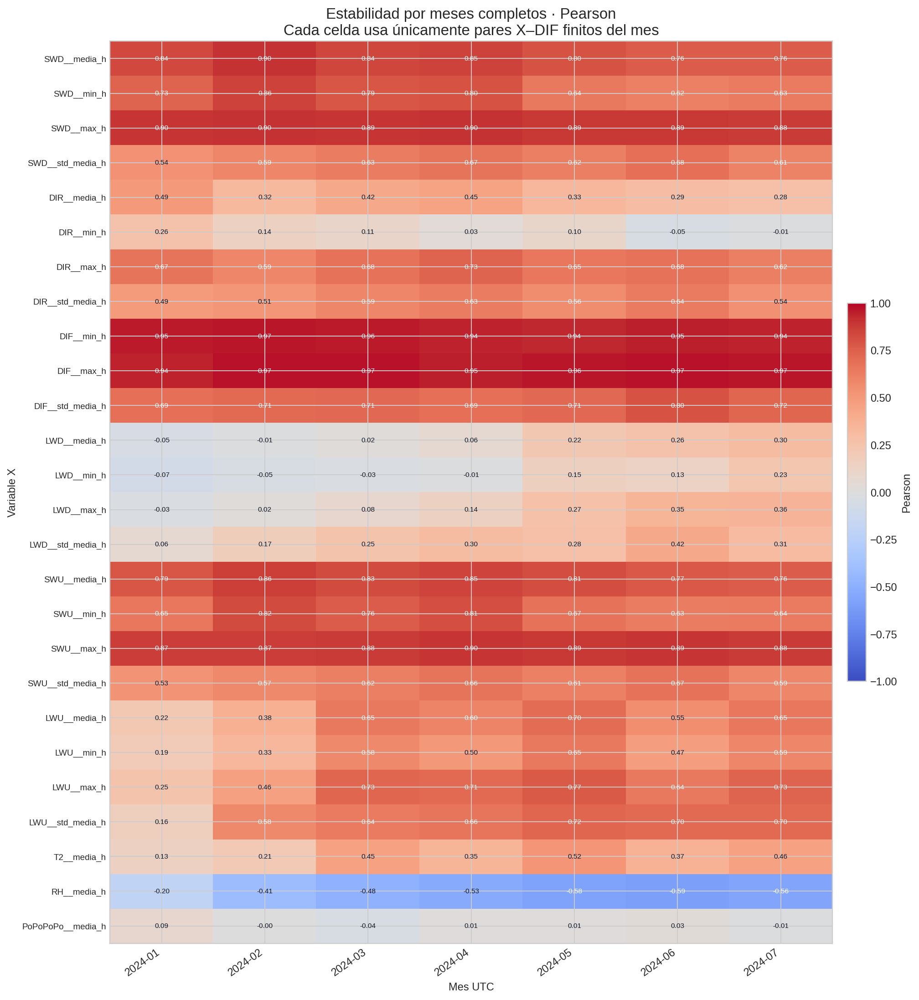

04_estabilidad_mensual_Spearman.png


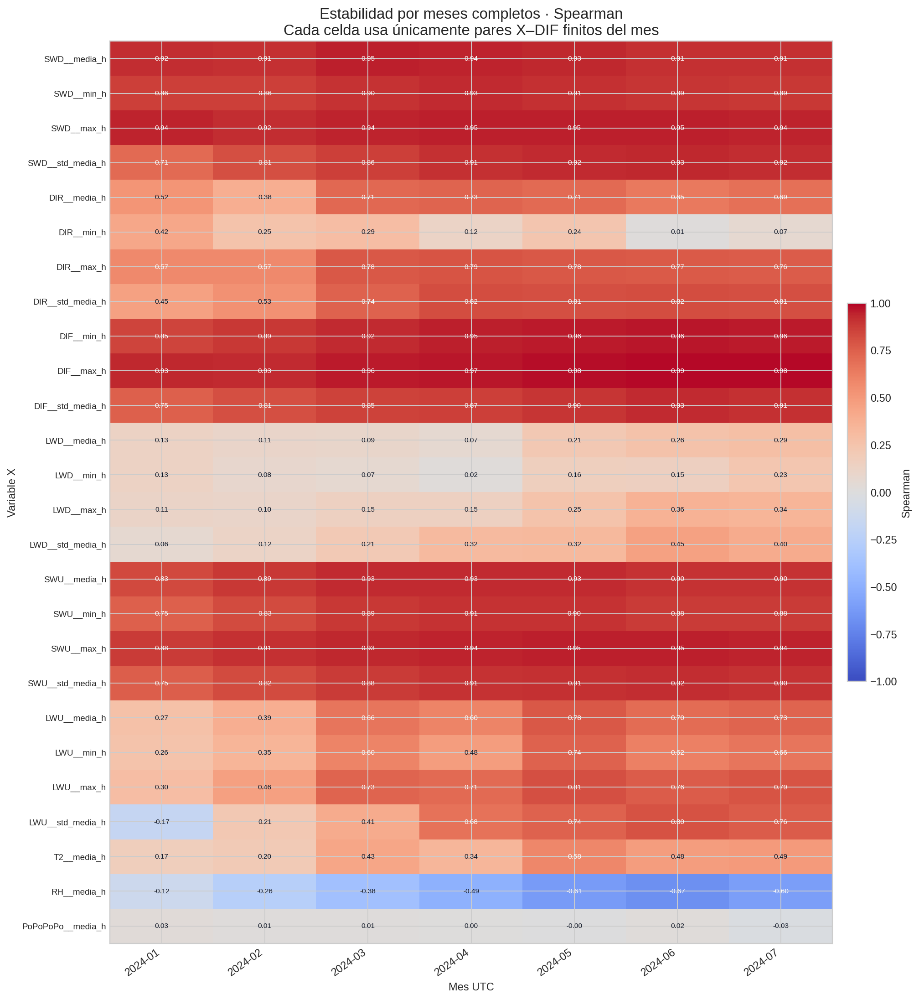

05_estabilidad_mensual_MI.png


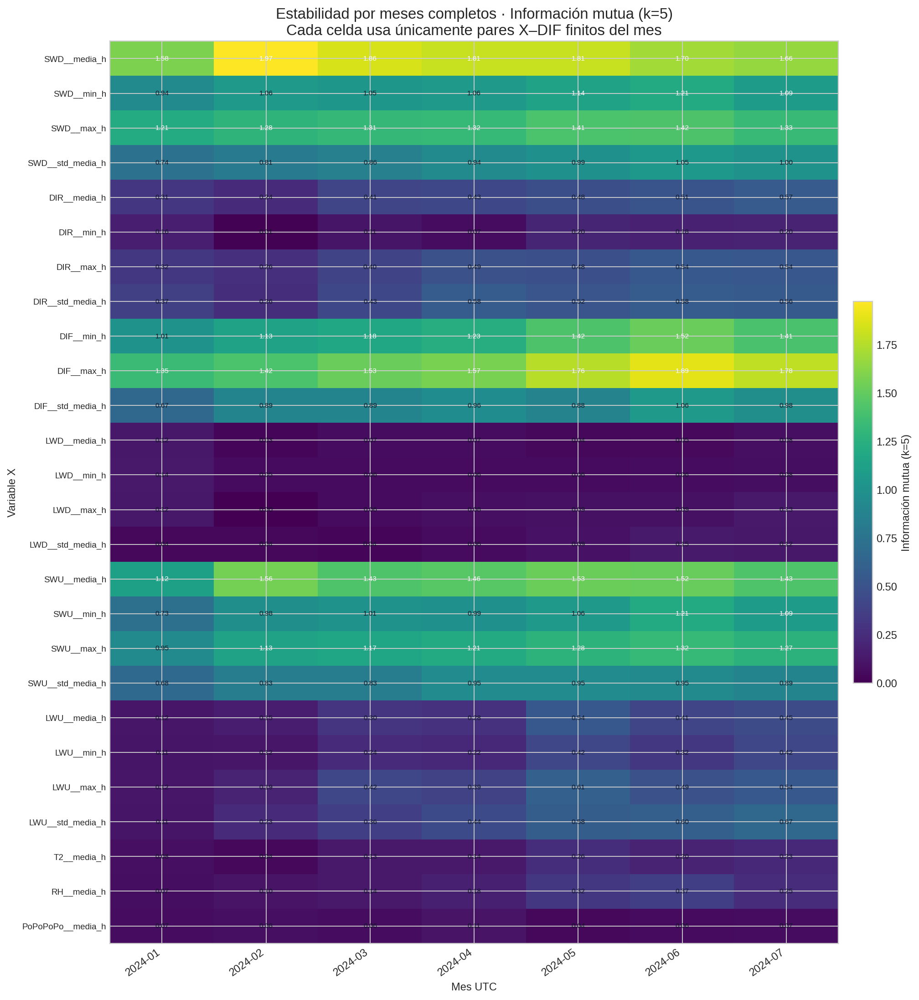

06_sensibilidad_MI_k.png


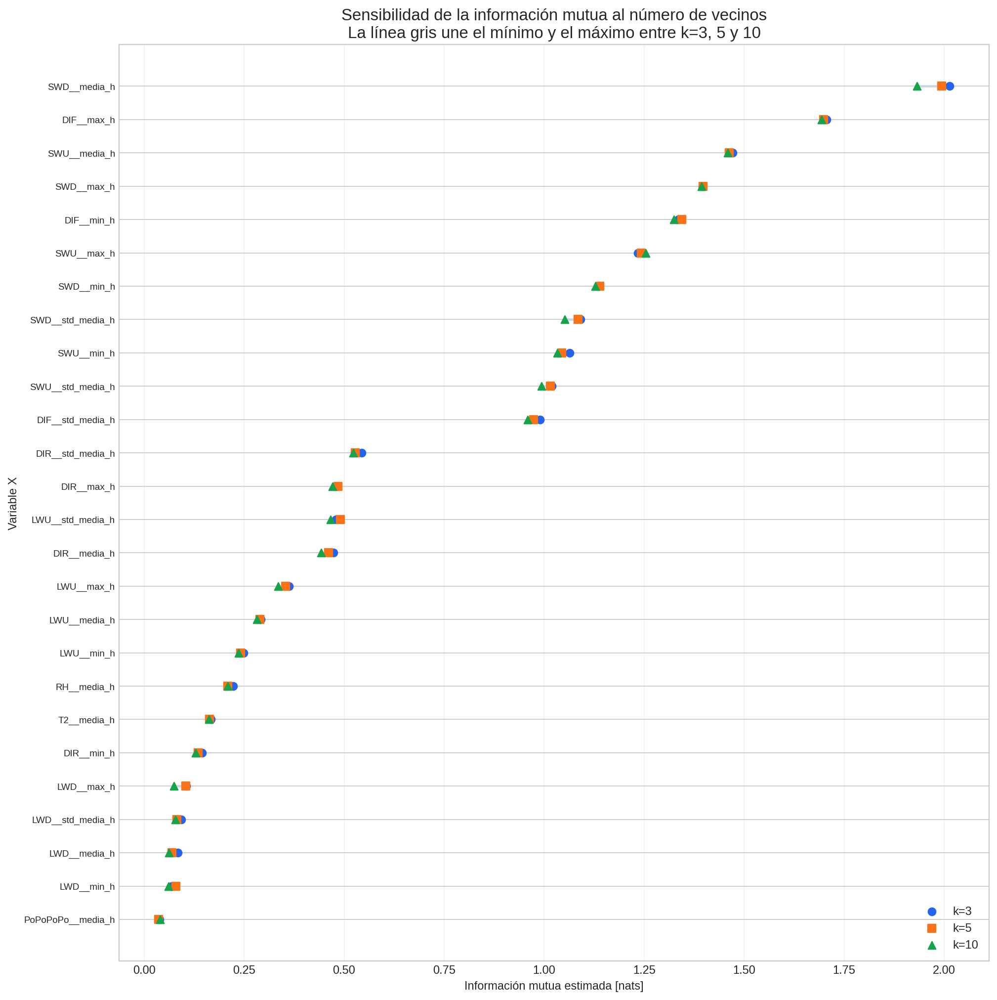

=== ZIP ===
Nombre: EDA_multivariante_F4_S4_26_20261102T173241Z_9a7952ff.zip
Tamaño: 2.61 MiB
SHA-256: 2f5da7d3093ac2ed9985319c66aa6f06e06cefb508660fdf45fc0d91f8ca2ad4
Integridad: CORRECTA


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
# Detección de relaciones lineales, monótonas y no lineales X(t) ↔ DIF(t)
import sys
import subprocess
import importlib
import importlib.util

def instalar_si_falta(modulo, paquete):
    """Instala una dependencia únicamente cuando no está disponible."""
    if importlib.util.find_spec(modulo) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])
        importlib.invalidate_caches()

instalar_si_falta("pyarrow", "pyarrow")
instalar_si_falta("sklearn", "scikit-learn>=1.3")
import io
import hashlib
import json
import os
import platform
import uuid
import zipfile
from datetime import datetime, timezone
from importlib.metadata import version as version_paquete
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd
from sklearn.feature_selection import mutual_info_regression
try:
    from IPython.display import Image, display
except ImportError:
    class Image:
        def __init__(self, filename):
            self.filename = filename

    def display(value):
        print(value)

try:
    from google.colab import files
    EN_COLAB = True
except ImportError:
    files = None
    EN_COLAB = False


# 1. Contrato de la subsección
PARTICION_ANALIZADA = "train"
COLUMNA_OBJETIVO = "DIF__media_h"
N_HORAS_TRAIN_ESPERADAS = 5208
K_MI_GLOBALES = (3, 5, 10)
K_MI_MENSUAL = 5
SEMILLA = 20260913
MAX_FIGURAS_MOSTRADAS = 6
CHECKPOINTS_PRIORITARIOS = [
    "checkpoints/13_tabla_horaria_con_geometria_solar_sin_cambios.parquet",
    "checkpoints/12_tabla_horaria_con_geometria_solar_sin_cambios.parquet",
    "checkpoints/11_tabla_horaria_con_geometria_solar_sin_cambios.parquet",
    "checkpoints/10_tabla_horaria_con_geometria_solar_sin_cambios.parquet",
    "checkpoints/10_tabla_horaria_con_geometria_solar.parquet",
]
FAMILIAS_RADIOMETRICAS = ["SWD", "DIR", "DIF", "LWD", "SWU", "LWU"]
ESTADISTICOS_RADIOMETRICOS = [
    ("media", "__media_h", "Media horaria"),
    ("min", "__min_h", "Mínimo absoluto horario"),
    ("max", "__max_h", "Máximo absoluto horario"),
    ("std_media", "__std_media_h", "Media horaria de la desviación estándar minutal"),
]
VARIABLES_METEOROLOGICAS = [
    ("T2", "Temperatura a 2 m", "°C"),
    ("RH", "Humedad relativa", "%"),
    ("PoPoPoPo", "Presión atmosférica", "hPa"),
]


# 2. Entrada, integridad y utilidades
def sha256_bytes(contenido):
    return hashlib.sha256(contenido).hexdigest()

def sha256_archivo(ruta, tamano_bloque=1024 * 1024):
    resumen = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        while True:
            bloque = archivo.read(tamano_bloque)
            if not bloque:
                break
            resumen.update(bloque)
    return resumen.hexdigest()

def guardar_csv(tabla, ruta):
    tabla.to_csv(ruta, index=False, encoding="utf-8-sig")

def obtener_entrada():
    if EN_COLAB:
        print(
            "Selecciona un único ZIP validado que contenga el checkpoint horario "
            "con geometría solar (preferentemente la salida de 4.2.5)."
        )
        subidos = files.upload()
        assert len(subidos) == 1, "Selecciona un único archivo ZIP o parquet."
        return next(iter(subidos.items()))

    ruta_entrada = os.environ.get("INPUT_RELACIONES_NO_LINEALES_FILE", "").strip()
    assert ruta_entrada, (
        "Fuera de Colab define INPUT_RELACIONES_NO_LINEALES_FILE con la ruta "
        "al ZIP de la subsección 4.2.5 o a un checkpoint parquet válido."
    )
    ruta = Path(ruta_entrada).expanduser().resolve()
    assert ruta.is_file(), f"No existe el archivo: {ruta}"
    return ruta.name, ruta.read_bytes()

def elegir_checkpoint_parquet(nombres):
    candidatos = [nombre for nombre in nombres if nombre.lower().endswith(".parquet")]
    assert candidatos, "El ZIP no contiene ningún checkpoint parquet."

    def prioridad(nombre):
        normalizado = nombre.lower()
        for posicion, esperado in enumerate(CHECKPOINTS_PRIORITARIOS):
            if normalizado == esperado.lower():
                return posicion
        if "tabla_horaria_con_geometria_solar" in normalizado:
            return len(CHECKPOINTS_PRIORITARIOS)
        if "tabla_horaria" in normalizado:
            return len(CHECKPOINTS_PRIORITARIOS) + 1
        return len(CHECKPOINTS_PRIORITARIOS) + 2

    return sorted(candidatos, key=lambda x: (prioridad(x), x))[0]

def cargar_tabla_y_checkpoint(nombre, contenido):
    if nombre.lower().endswith(".zip"):
        with zipfile.ZipFile(io.BytesIO(contenido)) as archivo_zip:
            assert archivo_zip.testzip() is None, "El ZIP de entrada está dañado."
            checkpoint = elegir_checkpoint_parquet(archivo_zip.namelist())
            bytes_checkpoint = archivo_zip.read(checkpoint)
        tabla = pd.read_parquet(io.BytesIO(bytes_checkpoint))
        return tabla, checkpoint, bytes_checkpoint

    if nombre.lower().endswith(".parquet"):
        tabla = pd.read_parquet(io.BytesIO(contenido))
        return tabla, nombre, contenido

    raise AssertionError("La entrada debe ser un ZIP o parquet horario válido.")

def detectar_columna_particion(columnas):
    candidatas = ["particion_observacion", "particion", "partition", "split"]
    for candidata in candidatas:
        if candidata in columnas:
            return candidata
    for columna in columnas:
        nombre = str(columna).lower()
        if "particion" in nombre or "partition" in nombre:
            return columna
    return None

def detectar_columna_temporal(columnas):
    candidatas = ["timestamp_utc", "Date/Time", "timestamp", "fecha_hora", "datetime", "date_time"]
    for candidata in candidatas:
        if candidata in columnas:
            return candidata
    for columna in columnas:
        nombre = str(columna).lower().replace(" ", "")
        if "timestamp" in nombre or ("date" in nombre and "time" in nombre):
            return columna
    return None

def crear_inventario_archivos(ruta_base):
    filas = []
    for ruta in sorted(Path(ruta_base).rglob("*")):
        if ruta.is_file():
            filas.append(
                {
                    "archivo": str(ruta.relative_to(ruta_base)),
                    "tamano_bytes": ruta.stat().st_size,
                    "sha256": sha256_archivo(ruta),
                }
            )
    return pd.DataFrame(filas)


# 3. Inventario de variables y preparación de train
def construir_especificacion_variables():
    filas = []
    orden = 0
    for familia in FAMILIAS_RADIOMETRICAS:
        for estadistico, sufijo, descripcion in ESTADISTICOS_RADIOMETRICOS:
            columna = f"{familia}{sufijo}"
            if columna == COLUMNA_OBJETIVO:
                continue
            orden += 1
            filas.append(
                {
                    "orden": orden,
                    "columna": columna,
                    "familia": familia,
                    "tipo": "radiométrica",
                    "estadistico": estadistico,
                    "descripcion": f"{familia} · {descripcion.lower()}",
                    "unidad": "W/m²",
                    "derivada_de_DIF_misma_hora": familia == "DIF",
                }
            )

    for familia, descripcion, unidad in VARIABLES_METEOROLOGICAS:
        orden += 1
        filas.append(
            {
                "orden": orden,
                "columna": f"{familia}__media_h",
                "familia": familia,
                "tipo": "meteorológica",
                "estadistico": "media",
                "descripcion": descripcion,
                "unidad": unidad,
                "derivada_de_DIF_misma_hora": False,
            }
        )

    especificacion = pd.DataFrame(filas)
    assert len(especificacion) == 26, "Se esperaban exactamente 26 variables X."
    return especificacion

def preparar_train(tabla, especificacion):
    columna_particion = detectar_columna_particion(tabla.columns)
    columna_tiempo = detectar_columna_temporal(tabla.columns)
    assert columna_particion is not None, "No se encontró la columna de partición."
    assert columna_tiempo is not None, "No se encontró la columna temporal."
    columnas_necesarias = [
        columna_tiempo,
        columna_particion,
        COLUMNA_OBJETIVO,
        *especificacion["columna"].tolist(),
    ]
    faltantes = [col for col in columnas_necesarias if col not in tabla.columns]
    assert not faltantes, f"Faltan columnas necesarias: {faltantes}"
    train = tabla.loc[
        tabla[columna_particion].astype(str).str.lower().eq(PARTICION_ANALIZADA),
        columnas_necesarias,
    ].copy()
    assert len(train) > 0, "La partición train está vacía."
    assert len(train) == N_HORAS_TRAIN_ESPERADAS, (
        f"Se esperaban {N_HORAS_TRAIN_ESPERADAS:,} horas de train y se "
        f"encontraron {len(train):,}. Comprueba el checkpoint seleccionado."
    )
    train["__timestamp_utc"] = pd.to_datetime(train[columna_tiempo], utc=True)
    assert train["__timestamp_utc"].notna().all(), "Hay timestamps no interpretables."
    assert train["__timestamp_utc"].is_unique, "Hay timestamps duplicados en train."
    train = train.sort_values("__timestamp_utc").reset_index(drop=True)
    diferencias = train["__timestamp_utc"].diff().dropna()
    saltos = int((diferencias != pd.Timedelta(hours=1)).sum())
    assert saltos == 0, f"Train contiene {saltos} saltos no horarios."
    for columna in [COLUMNA_OBJETIVO, *especificacion["columna"].tolist()]:
        train[columna] = pd.to_numeric(train[columna], errors="coerce")

    train["__mes"] = train["__timestamp_utc"].dt.tz_localize(None).dt.to_period("M").astype(str)
    return train, columna_tiempo, columna_particion

def detectar_meses_completos(train):
    filas = []
    for mes, grupo in train.groupby("__mes", sort=True):
        periodo = pd.Period(mes, freq="M")
        inicio = pd.Timestamp(periodo.start_time, tz="UTC")
        fin = pd.Timestamp(periodo.end_time.floor("h"), tz="UTC")
        esperadas = int((fin - inicio) / pd.Timedelta(hours=1)) + 1
        observadas = int(grupo["__timestamp_utc"].nunique())
        completo = bool(
            observadas == esperadas
            and grupo["__timestamp_utc"].min() == inicio
            and grupo["__timestamp_utc"].max() == fin
        )
        filas.append(
            {
                "mes": mes,
                "inicio_esperado_utc": inicio,
                "fin_esperado_utc": fin,
                "horas_esperadas": esperadas,
                "horas_observadas": observadas,
                "mes_completo": completo,
                "incluido_estabilidad": completo,
            }
        )
    tabla_meses = pd.DataFrame(filas)
    meses_completos = tabla_meses.loc[tabla_meses["incluido_estabilidad"], "mes"].tolist()
    assert meses_completos, "No se encontró ningún mes completo en train."
    return tabla_meses, meses_completos


# 4. Métricas de dependencia
def pares_finitos(tabla, columna_x):
    x = tabla[columna_x].to_numpy(dtype=float)
    y = tabla[COLUMNA_OBJETIVO].to_numpy(dtype=float)
    mascara = np.isfinite(x) & np.isfinite(y)
    return x[mascara], y[mascara], mascara

def correlacion_pearson(x, y):
    if len(x) < 3 or np.unique(x).size < 2 or np.unique(y).size < 2:
        return np.nan
    return float(np.corrcoef(x, y)[0, 1])

def correlacion_spearman(x, y):
    if len(x) < 3 or np.unique(x).size < 2 or np.unique(y).size < 2:
        return np.nan
    rango_x = pd.Series(x).rank(method="average").to_numpy(dtype=float)
    rango_y = pd.Series(y).rank(method="average").to_numpy(dtype=float)
    return float(np.corrcoef(rango_x, rango_y)[0, 1])

def informacion_mutua(x, y, k, semilla):
    if len(x) <= k + 2 or np.unique(x).size < 2 or np.unique(y).size < 2:
        return np.nan
    valor = mutual_info_regression(
        x.reshape(-1, 1), y, discrete_features=False, n_neighbors=int(k), random_state=int(semilla)
    )[0]
    return float(max(valor, 0.0))

def diagnostico_repeticiones(x):
    valores, conteos = np.unique(x, return_counts=True)
    posicion = int(np.argmax(conteos))
    return {
        "n_valores_unicos_x": int(len(valores)),
        "valor_moda_x": float(valores[posicion]),
        "n_moda_x": int(conteos[posicion]),
        "porcentaje_moda_x": float(100 * conteos[posicion] / len(x)),
    }

def calcular_metricas_globales(train, especificacion):
    filas = []
    n_total = len(train)
    for fila in especificacion.itertuples(index=False):
        x, y, mascara = pares_finitos(train, fila.columna)
        pearson = correlacion_pearson(x, y)
        spearman = correlacion_spearman(x, y)
        mi = {
            k: informacion_mutua(x, y, k=k, semilla=SEMILLA + fila.orden * 100 + k)
            for k in K_MI_GLOBALES
        }
        mi_vector = np.array(list(mi.values()), dtype=float)
        repetidos = diagnostico_repeticiones(x)
        registro = {
            "orden": fila.orden,
            "columna": fila.columna,
            "familia": fila.familia,
            "estadistico": fila.estadistico,
            "n_pares": int(len(x)),
            "cobertura_pares_pct": float(100 * len(x) / n_total),
            "pearson": pearson,
            "spearman": spearman,
            "abs_pearson": abs(pearson) if np.isfinite(pearson) else np.nan,
            "abs_spearman": abs(spearman) if np.isfinite(spearman) else np.nan,
            "diferencia_abs_spearman_pearson": (
                abs(spearman) - abs(pearson)
                if np.isfinite(pearson) and np.isfinite(spearman)
                else np.nan
            ),
            "mi_k3_nats": mi[3],
            "mi_k5_nats": mi[5],
            "mi_k10_nats": mi[10],
            "mi_mediana_k_nats": float(np.nanmedian(mi_vector)),
            "mi_rango_sensibilidad_k": float(np.nanmax(mi_vector) - np.nanmin(mi_vector)),
            **repetidos,
        }
        filas.append(registro)

    resultado = pd.DataFrame(filas)
    resultado["rango_abs_pearson"] = (
        resultado["abs_pearson"].rank(ascending=False, method="min").astype("Int64")
    )
    resultado["rango_abs_spearman"] = (
        resultado["abs_spearman"].rank(ascending=False, method="min").astype("Int64")
    )
    resultado["rango_mi"] = (
        resultado["mi_mediana_k_nats"].rank(ascending=False, method="min").astype("Int64")
    )
    return resultado

def calcular_metricas_mensuales(train, especificacion, meses_completos):
    filas = []
    for fila in especificacion.itertuples(index=False):
        for indice_mes, mes in enumerate(meses_completos):
            bloque = train.loc[train["__mes"].eq(mes)]
            x, y, mascara = pares_finitos(bloque, fila.columna)
            filas.append(
                {
                    "orden": fila.orden,
                    "columna": fila.columna,
                    "familia": fila.familia,
                    "estadistico": fila.estadistico,
                    "mes": mes,
                    "n_horas_mes": int(len(bloque)),
                    "n_pares": int(len(x)),
                    "cobertura_pares_pct": float(100 * len(x) / len(bloque)),
                    "pearson": correlacion_pearson(x, y),
                    "spearman": correlacion_spearman(x, y),
                    "mi_k5_nats": informacion_mutua(
                        x, y, k=K_MI_MENSUAL, semilla=SEMILLA + fila.orden * 1000 + indice_mes
                    ),
                    "n_valores_unicos_x": int(np.unique(x).size),
                }
            )
    return pd.DataFrame(filas)

def resumir_estabilidad_mensual(metricas_globales, metricas_mensuales):
    filas = []
    globales = metricas_globales.set_index("columna")
    for columna, grupo in metricas_mensuales.groupby("columna", sort=False):
        grupo = grupo.sort_values("mes")
        registro = {
            "orden": int(globales.loc[columna, "orden"]),
            "columna": columna,
            "familia": globales.loc[columna, "familia"],
            "estadistico": globales.loc[columna, "estadistico"],
            "n_meses_completos": int(grupo["mes"].nunique()),
        }
        for metrica, global_col in [
            ("pearson", "pearson"),
            ("spearman", "spearman"),
            ("mi_k5_nats", "mi_k5_nats"),
        ]:
            valores = grupo[metrica].to_numpy(dtype=float)
            valores = valores[np.isfinite(valores)]
            prefijo = "mi" if metrica == "mi_k5_nats" else metrica
            registro[f"{prefijo}_mensual_min"] = float(np.min(valores))
            registro[f"{prefijo}_mensual_mediana"] = float(np.median(valores))
            registro[f"{prefijo}_mensual_max"] = float(np.max(valores))
            registro[f"{prefijo}_mensual_rango"] = float(np.max(valores) - np.min(valores))
            registro[f"{prefijo}_global_menos_mediana_mensual"] = float(
                globales.loc[columna, global_col] - np.median(valores)
            )

        for metrica in ["pearson", "spearman"]:
            valores = grupo[metrica].to_numpy(dtype=float)
            valores = valores[np.isfinite(valores)]
            global_valor = float(globales.loc[columna, metrica])
            registro[f"{metrica}_cambio_signo_entre_meses"] = bool(
                np.min(valores) < 0 < np.max(valores)
            )
            if global_valor == 0 or not np.isfinite(global_valor):
                registro[f"{metrica}_fraccion_meses_mismo_signo_global"] = np.nan
            else:
                registro[f"{metrica}_fraccion_meses_mismo_signo_global"] = float(
                    np.mean(np.sign(valores) == np.sign(global_valor))
                )

        filas.append(registro)

    return pd.DataFrame(filas).sort_values("orden").reset_index(drop=True)


# 5. Figuras
def anotar_vector(ax, valores, formato=".2f", color_umbral=None):
    for indice, valor in enumerate(valores):
        if not np.isfinite(valor):
            texto = "NA"
            color = "#111827"
        else:
            texto = format(valor, formato)
            if color_umbral is None:
                color = "white" if valor > np.nanmedian(valores) else "#111827"
            else:
                color = "white" if abs(valor) >= color_umbral else "#111827"
        ax.text(0, indice, texto, ha="center", va="center", fontsize=7.5, color=color)

def crear_figura_metricas_globales(metricas, ruta):
    columnas = ["pearson", "spearman", "mi_mediana_k_nats"]
    titulos = [
        "Pearson r\n(lineal y con signo)",
        "Spearman ρ\n(monótona y con signo)",
        "Información mutua\n(mediana k=3,5,10; sin signo)",
    ]
    mapas = ["coolwarm", "coolwarm", "viridis"]
    limites = [(-1, 1), (-1, 1), (0, float(metricas[columnas[2]].max()))]
    figura, ejes = plt.subplots(1, 3, figsize=(12, 13), gridspec_kw={"wspace": 0.58})
    etiquetas = metricas["columna"].tolist()
    for posicion, (ax, columna, titulo, cmap, limite) in enumerate(
        zip(ejes, columnas, titulos, mapas, limites)
    ):
        valores = metricas[columna].to_numpy(dtype=float)
        imagen = ax.imshow(
            valores[:, None], aspect="auto", cmap=cmap, vmin=limite[0], vmax=limite[1]
        )
        ax.set_title(titulo, fontsize=11)
        ax.set_xticks([])
        ax.set_yticks(np.arange(len(etiquetas)))
        ax.set_yticklabels(etiquetas if posicion == 0 else [], fontsize=8)
        anotar_vector(
            ax,
            valores,
            formato=".3f",
            color_umbral=0.55 if columna != "mi_mediana_k_nats" else None,
        )
        barra = figura.colorbar(imagen, ax=ax, fraction=0.09, pad=0.06)
        barra.ax.tick_params(labelsize=8)

    figura.suptitle(
        "Dependencia contemporánea global X(t) ↔ DIF(t) · solo train\n"
        "Las tres métricas no comparten escala; MI no aporta dirección",
        fontsize=15,
        y=0.995,
    )
    figura.subplots_adjust(left=0.25, right=0.97, bottom=0.045, top=0.92)
    figura.savefig(ruta, dpi=170, bbox_inches="tight")
    plt.close(figura)

def crear_figura_diagnostico(metricas, estabilidad, ruta):
    combinada = metricas.merge(
        estabilidad[["columna", "spearman_mensual_mediana", "spearman_mensual_rango"]],
        on="columna",
        how="left",
    )
    mi = combinada["mi_mediana_k_nats"].to_numpy(dtype=float)
    normalizador = Normalize(vmin=float(np.nanmin(mi)), vmax=float(np.nanmax(mi)))
    cmap = plt.get_cmap("viridis")
    figura = plt.figure(figsize=(16, 7))
    rejilla = figura.add_gridspec(1, 3, width_ratios=(1, 1, 0.045), wspace=0.32)
    ejes = [figura.add_subplot(rejilla[0, 0]), figura.add_subplot(rejilla[0, 1])]
    ax_barra = figura.add_subplot(rejilla[0, 2])
    ax = ejes[0]
    ax.scatter(
        combinada["pearson"],
        combinada["spearman"],
        c=mi,
        cmap=cmap,
        norm=normalizador,
        s=75,
        edgecolor="white",
        linewidth=0.7,
        zorder=3,
    )
    for fila in combinada.itertuples(index=False):
        ax.text(fila.pearson, fila.spearman, str(fila.orden), fontsize=7, ha="center", va="center")
    ax.plot([-1, 1], [-1, 1], linestyle="--", color="#64748b", linewidth=1)
    ax.axhline(0, color="#94a3b8", linewidth=0.8)
    ax.axvline(0, color="#94a3b8", linewidth=0.8)
    ax.set_xlim(-1.08, 1.08)
    ax.set_ylim(-1.08, 1.08)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Pearson r")
    ax.set_ylabel("Spearman ρ")
    ax.set_title("A. Comparación lineal–monótona", loc="left")
    ax.grid(alpha=0.18)
    ax = ejes[1]
    rangos = combinada["spearman_mensual_rango"].to_numpy(dtype=float)
    tamano = 45 + 180 * rangos / max(float(np.nanmax(rangos)), 1e-12)
    ax.scatter(
        combinada["spearman"],
        combinada["spearman_mensual_mediana"],
        c=mi,
        cmap=cmap,
        norm=normalizador,
        s=tamano,
        edgecolor="white",
        linewidth=0.7,
        zorder=3,
    )
    for fila in combinada.itertuples(index=False):
        ax.text(
            fila.spearman,
            fila.spearman_mensual_mediana,
            str(fila.orden),
            fontsize=7,
            ha="center",
            va="center",
        )
    ax.plot([-1, 1], [-1, 1], linestyle="--", color="#64748b", linewidth=1)
    ax.axhline(0, color="#94a3b8", linewidth=0.8)
    ax.axvline(0, color="#94a3b8", linewidth=0.8)
    ax.set_xlim(-1.08, 1.08)
    ax.set_ylim(-1.08, 1.08)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Spearman global")
    ax.set_ylabel("Mediana de Spearman mensual")
    ax.set_title("B. Comparación global–mensual", loc="left")
    ax.grid(alpha=0.18)
    mapeable = plt.cm.ScalarMappable(norm=normalizador, cmap=cmap)
    mapeable.set_array([])
    barra = figura.colorbar(mapeable, cax=ax_barra)
    barra.set_label("Información mutua · mediana de k [nats]")
    figura.suptitle(
        "Diagnóstico conjunto de forma y estabilidad\n"
        "Números = orden del inventario; tamaño en B = rango mensual de Spearman",
        fontsize=15,
        y=0.99,
    )
    figura.subplots_adjust(left=0.065, right=0.96, bottom=0.10, top=0.84)
    figura.savefig(ruta, dpi=170, bbox_inches="tight")
    plt.close(figura)

def crear_mapa_mensual(metricas_mensuales, especificacion, metrica, ruta):
    meses = sorted(metricas_mensuales["mes"].unique())
    matriz = metricas_mensuales.pivot(index="columna", columns="mes", values=metrica).reindex(
        index=especificacion["columna"], columns=meses
    )
    es_mi = metrica == "mi_k5_nats"
    titulo_metrica = "Información mutua (k=5)" if es_mi else metrica.capitalize()
    cmap = "viridis" if es_mi else "coolwarm"
    vmin = 0 if es_mi else -1
    vmax = float(np.nanmax(matriz.to_numpy())) if es_mi else 1
    figura, ax = plt.subplots(figsize=(12, 13))
    imagen = ax.imshow(matriz.to_numpy(dtype=float), aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(np.arange(len(meses)))
    ax.set_xticklabels(meses, rotation=35, ha="right")
    ax.set_yticks(np.arange(len(matriz.index)))
    ax.set_yticklabels(matriz.index, fontsize=8)
    for i in range(len(matriz.index)):
        for j in range(len(meses)):
            valor = matriz.iloc[i, j]
            if np.isfinite(valor):
                if es_mi:
                    color = "white" if valor > 0.55 * vmax else "#111827"
                else:
                    color = "white" if abs(valor) >= 0.55 else "#111827"
                ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=6.5, color=color)

    barra = figura.colorbar(imagen, ax=ax, fraction=0.025, pad=0.02)
    barra.set_label(titulo_metrica)
    ax.set_title(
        f"Estabilidad por meses completos · {titulo_metrica}\n"
        "Cada celda usa únicamente pares X–DIF finitos del mes",
        fontsize=14,
    )
    ax.set_xlabel("Mes UTC")
    ax.set_ylabel("Variable X")
    figura.tight_layout()
    figura.savefig(ruta, dpi=170, bbox_inches="tight")
    plt.close(figura)

def crear_figura_sensibilidad_mi(metricas, ruta):
    ordenada = metricas.sort_values("mi_mediana_k_nats", ascending=True).reset_index(drop=True)
    posiciones = np.arange(len(ordenada))
    figura, ax = plt.subplots(figsize=(12, 12))
    for indice, fila in ordenada.iterrows():
        valores = np.array([fila["mi_k3_nats"], fila["mi_k5_nats"], fila["mi_k10_nats"]])
        ax.hlines(indice, valores.min(), valores.max(), color="#cbd5e1", linewidth=2, zorder=1)

    estilos = [
        ("mi_k3_nats", "k=3", "o", "#2563eb"),
        ("mi_k5_nats", "k=5", "s", "#f97316"),
        ("mi_k10_nats", "k=10", "^", "#16a34a"),
    ]
    for columna, etiqueta, marcador, color in estilos:
        ax.scatter(
            ordenada[columna],
            posiciones,
            label=etiqueta,
            marker=marcador,
            color=color,
            s=42,
            zorder=3,
        )

    ax.set_yticks(posiciones)
    ax.set_yticklabels(ordenada["columna"], fontsize=8)
    ax.set_xlabel("Información mutua estimada [nats]")
    ax.set_ylabel("Variable X")
    ax.set_title(
        "Sensibilidad de la información mutua al número de vecinos\n"
        "La línea gris une el mínimo y el máximo entre k=3, 5 y 10",
        fontsize=14,
    )
    ax.grid(axis="x", alpha=0.22)
    ax.legend(loc="lower right")
    figura.tight_layout()
    figura.savefig(ruta, dpi=170, bbox_inches="tight")
    plt.close(figura)


# 6. Ejecución
nombre_entrada, contenido_entrada = obtener_entrada()
tabla_fuente, checkpoint_utilizado, bytes_checkpoint = cargar_tabla_y_checkpoint(
    nombre_entrada, contenido_entrada
)
sha_checkpoint_entrada = sha256_bytes(bytes_checkpoint)
especificacion = construir_especificacion_variables()
train, columna_tiempo, columna_particion = preparar_train(tabla_fuente, especificacion)
tabla_meses, meses_completos = detectar_meses_completos(train)
metricas_globales = calcular_metricas_globales(train, especificacion)
metricas_mensuales = calcular_metricas_mensuales(train, especificacion, meses_completos)
estabilidad = resumir_estabilidad_mensual(metricas_globales, metricas_mensuales)

# Validaciones internas: dimensiones, rangos matemáticos y cobertura.
assert len(metricas_globales) == 26
assert len(metricas_mensuales) == 26 * len(meses_completos)
assert metricas_globales["columna"].is_unique
assert metricas_globales["n_pares"].min() > 0
for columna in ["pearson", "spearman"]:
    valores = metricas_globales[columna].dropna().to_numpy(dtype=float)
    assert np.all((valores >= -1) & (valores <= 1))
for columna in ["mi_k3_nats", "mi_k5_nats", "mi_k10_nats"]:
    valores = metricas_globales[columna].dropna().to_numpy(dtype=float)
    assert np.all(valores >= 0)
assert set(metricas_mensuales["mes"].unique()) == set(meses_completos)
marca_tiempo = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
identificador = uuid.uuid4().hex[:8]
raiz_salida = Path.cwd()
directorio = raiz_salida / f"salida_F4_S4_26_{marca_tiempo}_{identificador}"
directorio_figuras = directorio / "figuras"
directorio_tablas = directorio / "tablas"
directorio_configuracion = directorio / "configuracion"
directorio_checkpoints = directorio / "checkpoints"
for ruta in [
    directorio_figuras,
    directorio_tablas,
    directorio_configuracion,
    directorio_checkpoints,
]:
    ruta.mkdir(parents=True, exist_ok=False)

# Se conserva exactamente el checkpoint recibido; no se reescribe el parquet.
ruta_checkpoint = directorio_checkpoints / Path(checkpoint_utilizado).name
ruta_checkpoint.write_bytes(bytes_checkpoint)
assert sha256_archivo(ruta_checkpoint) == sha_checkpoint_entrada
guardar_csv(especificacion, directorio_tablas / "01_inventario_26_variables.csv")
guardar_csv(tabla_meses, directorio_tablas / "02_meses_y_cobertura_estructural.csv")
guardar_csv(metricas_globales, directorio_tablas / "03_metricas_globales.csv")
guardar_csv(metricas_mensuales, directorio_tablas / "04_metricas_mensuales.csv")
guardar_csv(estabilidad, directorio_tablas / "05_resumen_estabilidad_mensual.csv")
rutas_figuras = []
especificacion_figuras = [
    (
        "01_metricas_globales_Pearson_Spearman_MI.png",
        "Pearson, Spearman e información mutua globales",
    ),
    (
        "02_diagnostico_forma_y_estabilidad.png",
        "Comparación Pearson–Spearman y estabilidad global–mensual",
    ),
    ("03_estabilidad_mensual_Pearson.png", "Pearson por meses completos"),
    ("04_estabilidad_mensual_Spearman.png", "Spearman por meses completos"),
    ("05_estabilidad_mensual_MI.png", "Información mutua por meses completos"),
    ("06_sensibilidad_MI_k.png", "Sensibilidad de MI a k=3, 5 y 10"),
]
for orden, (nombre, descripcion) in enumerate(especificacion_figuras, start=1):
    rutas_figuras.append(
        {"orden_figura": orden, "archivo": f"figuras/{nombre}", "descripcion": descripcion}
    )

crear_figura_metricas_globales(metricas_globales, directorio_figuras / especificacion_figuras[0][0])
crear_figura_diagnostico(
    metricas_globales, estabilidad, directorio_figuras / especificacion_figuras[1][0]
)
crear_mapa_mensual(
    metricas_mensuales, especificacion, "pearson", directorio_figuras / especificacion_figuras[2][0]
)
crear_mapa_mensual(
    metricas_mensuales,
    especificacion,
    "spearman",
    directorio_figuras / especificacion_figuras[3][0],
)
crear_mapa_mensual(
    metricas_mensuales,
    especificacion,
    "mi_k5_nats",
    directorio_figuras / especificacion_figuras[4][0],
)
crear_figura_sensibilidad_mi(metricas_globales, directorio_figuras / especificacion_figuras[5][0])
indice_figuras = pd.DataFrame(rutas_figuras)
guardar_csv(indice_figuras, directorio_tablas / "06_indice_figuras.csv")
advertencias = pd.DataFrame(
    [
        {
            "id": "A01",
            "advertencia": "Las métricas son contemporáneas X(t) ↔ DIF(t).",
            "implicacion": "No demuestran causalidad ni capacidad para predecir DIF(t+1).",
        },
        {
            "id": "A02",
            "advertencia": "Pearson solo cuantifica asociación lineal; Spearman, asociación monótona.",
            "implicacion": "Un valor bajo no descarta dependencia no monótona.",
        },
        {
            "id": "A03",
            "advertencia": "La información mutua no tiene signo y se expresa en nats.",
            "implicacion": "Se compara de forma relativa con el mismo estimador; no es varianza explicada.",
        },
        {
            "id": "A04",
            "advertencia": "La serie horaria presenta dependencia temporal.",
            "implicacion": "No se calculan p-valores iid; se examina estabilidad por meses completos.",
        },
        {
            "id": "A05",
            "advertencia": "Las métricas globales mezclan noche, geometría solar, estación y estados atmosféricos.",
            "implicacion": "Las asociaciones deberán reevaluarse por regímenes solares en 4.2.8.",
        },
        {
            "id": "A06",
            "advertencia": "DIF mínimo, máximo y std proceden de la misma variable y hora que DIF media.",
            "implicacion": "Su asociación no implica que sean predictores operativos libres de fuga de información.",
        },
        {
            "id": "A07",
            "advertencia": "Muchos valores radiométricos repetidos, especialmente ceros, afectan al estimador kNN de MI.",
            "implicacion": "Se informa la moda y se compara MI con k=3, 5 y 10.",
        },
        {
            "id": "A08",
            "advertencia": "Diciembre de 2023 contiene únicamente cuatro días de train.",
            "implicacion": "Se conserva en las métricas globales, pero se excluye de la estabilidad mensual.",
        },
    ]
)
guardar_csv(advertencias, directorio_tablas / "07_advertencias_interpretacion.csv")
resumen_tecnico = pd.DataFrame(
    [
        {
            "particion_analizada": PARTICION_ANALIZADA,
            "n_horas_train": int(len(train)),
            "inicio_train_utc": train["__timestamp_utc"].min(),
            "fin_train_utc": train["__timestamp_utc"].max(),
            "n_variables_x": int(len(especificacion)),
            "objetivo": COLUMNA_OBJETIVO,
            "k_mi_globales": ",".join(map(str, K_MI_GLOBALES)),
            "k_mi_mensual": K_MI_MENSUAL,
            "meses_completos_estabilidad": ",".join(meses_completos),
            "n_meses_completos": int(len(meses_completos)),
            "n_figuras": int(len(indice_figuras)),
            "n_saltos_no_horarios_train": 0,
            "filas_eliminadas": 0,
            "valores_imputados": 0,
            "filtro_30_60_aplicado": False,
            "p_valores_iid_calculados": False,
            "checkpoint_salida_verificado_identico": True,
        }
    ]
)
guardar_csv(resumen_tecnico, directorio_tablas / "08_resumen_tecnico.csv")
configuracion = {
    "subseccion": "4.2.6_deteccion_relaciones_no_lineales",
    "entrada": nombre_entrada,
    "checkpoint_entrada": checkpoint_utilizado,
    "checkpoint_salida": f"checkpoints/{ruta_checkpoint.name}",
    "sha256_checkpoint": sha_checkpoint_entrada,
    "particion": PARTICION_ANALIZADA,
    "objetivo": COLUMNA_OBJETIVO,
    "n_horas_train": int(len(train)),
    "n_variables_x": int(len(especificacion)),
    "metricas_globales": ["Pearson", "Spearman", "informacion_mutua_kNN"],
    "k_informacion_mutua_global": list(K_MI_GLOBALES),
    "k_informacion_mutua_mensual": K_MI_MENSUAL,
    "semilla": SEMILLA,
    "meses_estabilidad": meses_completos,
    "pares_finitos_por_variable": True,
    "filas_eliminadas": 0,
    "valores_imputados": 0,
    "filtro_30_60_aplicado": False,
    "p_valores_iid_calculados": False,
    "versiones": {
        "python": platform.python_version(),
        "numpy": version_paquete("numpy"),
        "pandas": version_paquete("pandas"),
        "matplotlib": version_paquete("matplotlib"),
        "scikit_learn": version_paquete("scikit-learn"),
    },
}
with (directorio_configuracion / "configuracion_4_2_6.json").open("w", encoding="utf-8") as archivo:
    json.dump(configuracion, archivo, ensure_ascii=False, indent=2, default=str)

readme = f"""# Subsección 4.2.6 · Detección de relaciones no lineales

## Alcance

Se cuantifica la dependencia contemporánea entre cada una de las 26 variables
X y {COLUMNA_OBJETIVO} utilizando exclusivamente las {len(train):,} horas de
entrenamiento. Se calculan Pearson, Spearman e información mutua mediante un
estimador de vecinos próximos.

Pearson describe asociación lineal y Spearman asociación monótona. La
información mutua detecta dependencias más generales, pero no proporciona
dirección, no es un porcentaje de varianza explicada y su magnitud depende del
estimador. Por ello se informa en nats y se comprueba su sensibilidad con
k=3, 5 y 10.

## Estabilidad temporal

Las tres métricas se recalculan por meses completos con k=5 para MI. Los meses
incluidos son: {', '.join(meses_completos)}. Diciembre de 2023 no se utiliza en
esta comparación porque train solo contiene sus cuatro últimos días.

## Integridad

Cada variable utiliza su propia máscara de pares X–DIF finitos. No se imputan
valores, no se eliminan filas y no se aplica el criterio 30/60. El checkpoint
se copia sin reescribirlo y se verifica mediante SHA-256.

## Interpretación

Los resultados son un cribado descriptivo global. Las métricas mezclan
estructura solar, evolución temporal y estados atmosféricos; no demuestran
causalidad ni utilidad predictiva a una hora vista. No se calculan p-valores
bajo independencia porque las observaciones horarias forman una serie
temporal. La separación por regímenes solares se reserva para 4.2.8.
"""
(directorio / "README.md").write_text(readme, encoding="utf-8")
inventario_archivos = crear_inventario_archivos(directorio)
guardar_csv(inventario_archivos, directorio / "inventario_archivos.csv")
ruta_zip = raiz_salida / f"EDA_multivariante_F4_S4_26_{marca_tiempo}_{identificador}.zip"
with zipfile.ZipFile(ruta_zip, "w", compression=zipfile.ZIP_DEFLATED) as archivo_zip:
    for ruta in sorted(directorio.rglob("*")):
        if ruta.is_file():
            archivo_zip.write(ruta, arcname=str(ruta.relative_to(directorio)))

with zipfile.ZipFile(ruta_zip) as archivo_zip:
    assert archivo_zip.testzip() is None, "El ZIP generado contiene un archivo dañado."
    nombres_salida = archivo_zip.namelist()
    assert f"checkpoints/{ruta_checkpoint.name}" in nombres_salida


# 7. Resumen visible y descarga
print("=== RESUMEN TÉCNICO 4.2.6 ===")
print(f"Entrada: {nombre_entrada}")
print(f"Checkpoint: {checkpoint_utilizado}")
print(f"Partición: {PARTICION_ANALIZADA}")
print(f"Horas de entrenamiento: {len(train):,}")
print(f"Variables X: {len(especificacion)}")
print(f"Meses completos: {', '.join(meses_completos)}")
print("Métricas: Pearson, Spearman y MI kNN (k=3, 5, 10)")
print("Imputaciones: 0")
print("Filas eliminadas: 0")
print("P-valores iid: no calculados")
print("Checkpoint preservado: SÍ")
print()
display(resumen_tecnico)
display(metricas_globales)
display(estabilidad)
print("=== FIGURAS ===")
for fila in rutas_figuras[:MAX_FIGURAS_MOSTRADAS]:
    ruta = directorio / fila["archivo"]
    print(ruta.name)
    display(Image(filename=str(ruta)))

print("=== ZIP ===")
print(f"Nombre: {ruta_zip.name}")
print(f"Tamaño: {ruta_zip.stat().st_size / (1024 ** 2):.2f} MiB")
print(f"SHA-256: {sha256_archivo(ruta_zip)}")
print("Integridad: CORRECTA")
if EN_COLAB:
    files.download(str(ruta_zip))

**Resultados.** La dependencia contemporánea con DIF se concentra en la onda corta, y la información mutua (MI), estable frente a *k* (rango máximo de 0,081 nats), no revela dependencias que pasen inadvertidas a las correlaciones.

- SWD y SWU muestran asociaciones intensas y positivas en todos los meses (SWD media: Pearson 0,820, Spearman 0,940, MI 1,994 nats); sus máximos son los más compatibles con una relación lineal, y en mínimos y `std` Spearman supera claramente a Pearson.
- Los descriptores de DIF de la misma hora dan las relaciones más regulares (DIF máximo: Pearson 0,968).
- DIR media presenta la mayor discrepancia Pearson–Spearman (0,386 frente a 0,679); DIR mínimo está dominado por ceros (61,3 %).
- LWU, T2 y RH muestran dependencias moderadas y moduladas por la estación; RH es la única negativa (Pearson −0,545).
- LWD es débil y en parte fruto de la agregación estacional (Pearson global 0,256; mediana mensual 0,058); la presión es prácticamente nula (Pearson 0,017).

### 4.2.7 Relaciones contemporáneas entre anomalías tras retirar la tendencia y el ciclo diario

Esta subsección examina qué asociaciones entre X(t) y DIF(t) permanecen cuando ambas variables se expresan como desviaciones respecto a su tendencia y a su patrón diario esperado. Para cada serie se toman los residuos de la descomposición STL robusta con periodo de 24 horas, R<sup>X</sup><sub>t</sub> = X<sub>t</sub> − T<sup>X</sup><sub>t</sub> − S<sup>X</sup><sub>24,t</sub>, y se compara R<sup>X</sup><sub>t</sub> con R<sup>DIF</sup><sub>t</sub> mediante hexbin con LOWESS, medianas por intervalos cuantílicos con bandas P25–P75 y P10–P90, Pearson, Spearman e información mutua (*k* = 3, 5 y 10), tanto globalmente como por meses. El contraste con las métricas originales permite separar las asociaciones dominadas por el ciclo diario y la evolución estacional compartidos de las que persisten en las anomalías. La STL realiza una separación empírica y no elimina por completo el efecto de la geometría solar; además, la hora ausente de LWD, interpolada solo para ajustar la descomposición, se excluye de las comparaciones.

In [22]:
"""
Subsección 4.2.7 · Relaciones contemporáneas entre anomalías STL.

Entrada esperada
----------------
Un único ZIP generado en la subsección 4.2.6. Debe contener:

* el checkpoint horario con geometría solar;
* tablas/01_inventario_26_variables.csv;
* tablas/03_metricas_globales.csv;
* tablas/04_metricas_mensuales.csv.

Salida
------
Un ZIP ``EDA_multivariante_F4_S4_27_*.zip`` con las componentes STL,
las métricas originales y residuales, resúmenes cuantílicos y figuras.

La interpolación se utiliza únicamente en una copia interna para que STL
pueda ajustarse. Los residuos correspondientes a valores originalmente
ausentes vuelven a marcarse como NaN antes de cualquier comparación.
"""
from __future__ import annotations
import hashlib
import importlib.util
import json
import math
import os
import platform
import shutil
import tempfile
import uuid
import warnings
import zipfile
from datetime import datetime, timezone
from pathlib import Path
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import __version__ as sklearn_version
from sklearn.feature_selection import mutual_info_regression
from statsmodels import __version__ as statsmodels_version
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.tsa.seasonal import STL

# Configuración reproducible
TARGET = "DIF__media_h"
PARTITION_COLUMN = "particion_observacion"
TIME_COLUMN = "timestamp_utc"
TRAIN_LABEL = "train"
EXPECTED_TRAIN_HOURS = 5_208
EXPECTED_TRAIN_START = pd.Timestamp("2023-12-28 00:00:00", tz="UTC")
EXPECTED_TRAIN_END = pd.Timestamp("2024-07-31 23:00:00", tz="UTC")
EXPECTED_X_COUNT = 26
STL_PERIOD_HOURS = 24
STL_ROBUST = True
MAX_INTERNAL_GAP_HOURS = 24
EXPECTED_INTERPOLATED_VALUES = 4
EXPECTED_INTERPOLATED_VARIABLES = {"LWD__media_h", "LWD__min_h", "LWD__max_h", "LWD__std_media_h"}
MI_NEIGHBORS_GLOBAL = (3, 5, 10)
MI_NEIGHBORS_MONTHLY = 5
RANDOM_STATE = 20260913
QUANTILE_BINS = 20
LOWESS_FRAC = 0.20
LOWESS_ROBUST_ITERATIONS = 2
COMPLETE_MONTHS = tuple(f"2024-{month:02d}" for month in range(1, 8))
INPUT_ENV_VAR = "INPUT_RELACIONES_RESIDUALES_FILE"
OUTPUT_PREFIX = "EDA_multivariante_F4_S4_27"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 180,
        "font.family": "DejaVu Sans",
        "axes.titlesize": 11,
        "axes.labelsize": 10,
    }
)


# Utilidades de archivos
def sha256_file(path: Path, chunk_size: int = 1 << 20) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        while True:
            chunk = handle.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)
    return digest.hexdigest()

def running_in_colab() -> bool:
    return importlib.util.find_spec("google.colab") is not None

def select_input_zip() -> Path:
    """Selecciona un único ZIP en Colab o mediante variable de entorno."""
    env_path = os.environ.get(INPUT_ENV_VAR)
    if env_path:
        path = Path(env_path).expanduser().resolve()
        if not path.is_file():
            raise FileNotFoundError(f"No existe el archivo indicado en {INPUT_ENV_VAR}: {path}")
        if not zipfile.is_zipfile(path):
            raise ValueError(f"El archivo indicado no es un ZIP válido: {path}")
        return path

    if running_in_colab():
        from google.colab import files  # type: ignore
        print("Selecciona un único ZIP de salida de la subsección 4.2.6.")
        uploaded = files.upload()
        zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
        if len(zip_names) != 1:
            raise ValueError(
                "Debe seleccionarse exactamente un ZIP de la subsección 4.2.6; "
                f"se detectaron {len(zip_names)}."
            )
        path = Path(zip_names[0]).resolve()
        if not zipfile.is_zipfile(path):
            raise ValueError(f"El archivo seleccionado no es un ZIP válido: {path.name}")
        return path

    candidates = [
        path.resolve()
        for path in Path.cwd().glob("*.zip")
        if not path.name.startswith(OUTPUT_PREFIX)
    ]
    if len(candidates) != 1:
        raise RuntimeError(
            f"Define {INPUT_ENV_VAR} con el ZIP de 4.2.6 o deja un único ZIP de entrada "
            f"en {Path.cwd()}. Se encontraron {len(candidates)} candidatos."
        )
    return candidates[0]

def safe_extract_zip(zip_path: Path, destination: Path) -> None:
    destination = destination.resolve()
    with zipfile.ZipFile(zip_path) as archive:
        for member in archive.infolist():
            member_path = (destination / member.filename).resolve()
            if member_path != destination and destination not in member_path.parents:
                raise ValueError(f"Ruta insegura dentro del ZIP: {member.filename}")
        archive.extractall(destination)

def find_unique_file(root: Path, basename: str) -> Path:
    candidates = [path for path in root.rglob(basename) if path.is_file()]
    if len(candidates) != 1:
        raise FileNotFoundError(
            f"Se esperaba exactamente un archivo llamado {basename!r}; "
            f"se encontraron {len(candidates)}."
        )
    return candidates[0]

def find_checkpoint(root: Path) -> Path:
    preferred = [
        "13_tabla_horaria_con_geometria_solar_sin_cambios.parquet",
        "12_tabla_horaria_con_geometria_solar_sin_cambios.parquet",
        "11_tabla_horaria_con_geometria_solar_sin_cambios.parquet",
    ]
    for basename in preferred:
        matches = [path for path in root.rglob(basename) if path.is_file()]
        if len(matches) == 1:
            return matches[0]
        if len(matches) > 1:
            raise RuntimeError(f"Hay más de un checkpoint candidato llamado {basename}.")

    candidates = [
        path
        for path in root.rglob("*.parquet")
        if path.is_file()
        and "tabla_horaria" in path.name.lower()
        and "geometria_solar" in path.name.lower()
    ]
    if len(candidates) != 1:
        raise FileNotFoundError(
            "No se pudo identificar de forma inequívoca el checkpoint horario con geometría solar."
        )
    return candidates[0]

def zip_directory(source_dir: Path, zip_path: Path) -> None:
    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
        for path in sorted(source_dir.rglob("*")):
            if path.is_file():
                archive.write(path, path.relative_to(source_dir).as_posix())

def create_file_inventory(root: Path) -> pd.DataFrame:
    rows: list[dict[str, object]] = []
    for path in sorted(root.rglob("*")):
        if not path.is_file() or path.name == "inventario_archivos.csv":
            continue
        rows.append(
            {
                "ruta_relativa": path.relative_to(root).as_posix(),
                "tamano_bytes": path.stat().st_size,
                "sha256": sha256_file(path),
            }
        )
    return pd.DataFrame(rows)


# Validación y preparación del conjunto de entrenamiento
def validate_and_prepare_train(checkpoint_path: Path, inventory: pd.DataFrame) -> pd.DataFrame:
    frame = pd.read_parquet(checkpoint_path)
    required_columns = {
        PARTITION_COLUMN,
        TIME_COLUMN,
        TARGET,
        *inventory["columna"].astype(str).tolist(),
    }
    missing_columns = sorted(required_columns.difference(frame.columns))
    if missing_columns:
        raise KeyError(f"Faltan columnas necesarias en el checkpoint: {missing_columns}")

    partition = frame[PARTITION_COLUMN].astype(str).str.strip().str.lower()
    train = frame.loc[partition.eq(TRAIN_LABEL)].copy()
    train[TIME_COLUMN] = pd.to_datetime(train[TIME_COLUMN], utc=True, errors="raise")
    train = train.sort_values(TIME_COLUMN).reset_index(drop=True)
    if len(train) != EXPECTED_TRAIN_HOURS:
        raise ValueError(
            f"Se esperaban {EXPECTED_TRAIN_HOURS:,} horas de train y se encontraron {len(train):,}."
        )
    if train[TIME_COLUMN].duplicated().any():
        duplicates = train.loc[train[TIME_COLUMN].duplicated(False), TIME_COLUMN].tolist()
        raise ValueError(f"Hay timestamps duplicados en train: {duplicates[:10]}")

    observed_start = train[TIME_COLUMN].iloc[0]
    observed_end = train[TIME_COLUMN].iloc[-1]
    if observed_start != EXPECTED_TRAIN_START or observed_end != EXPECTED_TRAIN_END:
        raise ValueError(
            "El intervalo de train no coincide con el esperado: "
            f"{observed_start} — {observed_end}."
        )

    expected_index = pd.date_range(EXPECTED_TRAIN_START, EXPECTED_TRAIN_END, freq="h", tz="UTC")
    observed_index = pd.DatetimeIndex(train[TIME_COLUMN])
    absent = expected_index.difference(observed_index)
    extra = observed_index.difference(expected_index)
    if len(absent) or len(extra):
        raise ValueError(
            f"La malla horaria no es continua. Ausentes: {len(absent)}; adicionales: {len(extra)}."
        )

    if len(inventory) != EXPECTED_X_COUNT:
        raise ValueError(
            f"El inventario debe contener {EXPECTED_X_COUNT} covariables y contiene {len(inventory)}."
        )
    if inventory["columna"].duplicated().any():
        raise ValueError("El inventario de covariables contiene nombres duplicados.")
    if TARGET in set(inventory["columna"].astype(str)):
        raise ValueError(f"El objetivo {TARGET} no debe aparecer entre las 26 covariables.")

    train["mes_analisis"] = train[TIME_COLUMN].dt.strftime("%Y-%m")
    observed_complete_months = tuple(
        month for month in COMPLETE_MONTHS if (train["mes_analisis"] == month).any()
    )
    if observed_complete_months != COMPLETE_MONTHS:
        raise ValueError(
            f"No están presentes todos los meses completos esperados: {COMPLETE_MONTHS}."
        )
    return train

def max_consecutive_true(mask: pd.Series) -> int:
    values = mask.to_numpy(dtype=bool)
    best = 0
    current = 0
    for value in values:
        if value:
            current += 1
            best = max(best, current)
        else:
            current = 0
    return best


# STL robusta y restauración de ausencias originales
def calculate_stl_components(
    train: pd.DataFrame, variables: list[str]
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    timestamps = pd.DatetimeIndex(train[TIME_COLUMN])
    components = pd.DataFrame({TIME_COLUMN: timestamps})
    residuals = pd.DataFrame({TIME_COLUMN: timestamps})
    interpolation_rows: list[dict[str, object]] = []
    diagnostic_rows: list[dict[str, object]] = []
    for number, variable in enumerate(variables, start=1):
        print(f"[{number:02d}/{len(variables):02d}] STL robusta 24 h: {variable}")
        numeric = pd.to_numeric(train[variable], errors="coerce").astype(float)
        numeric = numeric.replace([np.inf, -np.inf], np.nan)
        series = pd.Series(numeric.to_numpy(), index=timestamps, name=variable)
        original_finite = pd.Series(np.isfinite(series.to_numpy()), index=timestamps)
        missing = ~original_finite
        maximum_gap = max_consecutive_true(missing)
        if maximum_gap > MAX_INTERNAL_GAP_HOURS:
            raise ValueError(
                f"{variable} contiene un hueco de {maximum_gap} horas, superior al límite "
                f"de {MAX_INTERNAL_GAP_HOURS}."
            )

        fit_series = series.interpolate(
            method="time", limit=MAX_INTERNAL_GAP_HOURS, limit_area="inside"
        )
        if fit_series.isna().any():
            missing_times = fit_series.index[fit_series.isna()].tolist()
            raise ValueError(
                f"No fue posible completar la copia diagnóstica de {variable}: "
                f"{missing_times[:10]}"
            )

        interpolated_only_for_stl = missing & fit_series.notna()
        for timestamp in timestamps[interpolated_only_for_stl.to_numpy()]:
            interpolation_rows.append(
                {
                    "columna": variable,
                    "timestamp_utc": timestamp,
                    "valor_original": np.nan,
                    "valor_interpolado_solo_ajuste_STL": float(fit_series.loc[timestamp]),
                    "usado_en_comparaciones_residuales": False,
                }
            )

        result = STL(
            fit_series.to_numpy(dtype=float), period=STL_PERIOD_HOURS, robust=STL_ROBUST
        ).fit()
        trend = np.asarray(result.trend, dtype=float)
        seasonal = np.asarray(result.seasonal, dtype=float)
        residual_fit = np.asarray(result.resid, dtype=float)
        reconstruction = trend + seasonal + residual_fit
        reconstruction_error = float(
            np.max(np.abs(fit_series.to_numpy(dtype=float) - reconstruction))
        )
        residual_analysis = residual_fit.copy()
        residual_analysis[~original_finite.to_numpy()] = np.nan
        components[f"{variable}__STL_tendencia"] = trend
        components[f"{variable}__STL_estacional_24h"] = seasonal
        components[f"{variable}__STL_residuo_analisis"] = residual_analysis
        components[f"{variable}__original_finito"] = original_finite.to_numpy(dtype=bool)
        components[f"{variable}__interpolado_solo_STL"] = interpolated_only_for_stl.to_numpy(
            dtype=bool
        )
        residuals[f"{variable}__STL_residuo"] = residual_analysis
        diagnostic_rows.append(
            {
                "columna": variable,
                "n_observaciones": len(series),
                "n_valores_originales_finitos": int(original_finite.sum()),
                "n_interpolados_solo_STL": int(interpolated_only_for_stl.sum()),
                "max_hueco_consecutivo_h": maximum_gap,
                "periodo_STL_h": STL_PERIOD_HOURS,
                "robust": STL_ROBUST,
                "error_maximo_reconstruccion": reconstruction_error,
            }
        )

    interpolation_table = pd.DataFrame(
        interpolation_rows,
        columns=[
            "columna",
            "timestamp_utc",
            "valor_original",
            "valor_interpolado_solo_ajuste_STL",
            "usado_en_comparaciones_residuales",
        ],
    )
    diagnostics = pd.DataFrame(diagnostic_rows)
    interpolated_count = len(interpolation_table)
    interpolated_variables = set(interpolation_table.get("columna", pd.Series(dtype=str)))
    if interpolated_count != EXPECTED_INTERPOLATED_VALUES:
        raise ValueError(
            f"Se esperaban {EXPECTED_INTERPOLATED_VALUES} valores interpolados solo para STL "
            f"y se detectaron {interpolated_count}."
        )
    if interpolated_variables != EXPECTED_INTERPOLATED_VARIABLES:
        raise ValueError(
            "Las variables interpoladas no coinciden con las cuatro variables LWD esperadas: "
            f"{sorted(interpolated_variables)}"
        )

    return (
        components,
        residuals,
        interpolation_table.merge(
            diagnostics[["columna", "error_maximo_reconstruccion"]], on="columna", how="left"
        ),
    )


# Métricas de dependencia
def finite_pairs(
    x: pd.Series | np.ndarray, y: pd.Series | np.ndarray
) -> tuple[np.ndarray, np.ndarray]:
    x_values = np.asarray(x, dtype=float)
    y_values = np.asarray(y, dtype=float)
    mask = np.isfinite(x_values) & np.isfinite(y_values)
    return x_values[mask], y_values[mask]

def pearson_without_pvalue(x: np.ndarray, y: np.ndarray) -> float:
    if len(x) < 3 or np.unique(x).size < 2 or np.unique(y).size < 2:
        return math.nan
    return float(np.corrcoef(x, y)[0, 1])

def spearman_without_pvalue(x: np.ndarray, y: np.ndarray) -> float:
    if len(x) < 3 or np.unique(x).size < 2 or np.unique(y).size < 2:
        return math.nan
    x_rank = pd.Series(x).rank(method="average")
    y_rank = pd.Series(y).rank(method="average")
    return float(x_rank.corr(y_rank, method="pearson"))

def mutual_information(x: np.ndarray, y: np.ndarray, k: int) -> float:
    if len(x) <= k or np.unique(x).size < 2 or np.unique(y).size < 2:
        return math.nan
    estimate = mutual_info_regression(
        x.reshape(-1, 1), y, discrete_features=False, n_neighbors=k, random_state=RANDOM_STATE
    )
    return float(estimate[0])

def dependency_metrics(
    x: pd.Series | np.ndarray, y: pd.Series | np.ndarray, neighbors: tuple[int, ...]
) -> dict[str, float | int]:
    x_pair, y_pair = finite_pairs(x, y)
    result: dict[str, float | int] = {
        "n_pares": int(len(x_pair)),
        "pearson": pearson_without_pvalue(x_pair, y_pair),
        "spearman": spearman_without_pvalue(x_pair, y_pair),
        "n_valores_unicos_x": int(np.unique(x_pair).size),
    }
    mi_values: list[float] = []
    for k in neighbors:
        value = mutual_information(x_pair, y_pair, k)
        result[f"mi_k{k}_nats"] = value
        mi_values.append(value)

    finite_mi = np.asarray([value for value in mi_values if np.isfinite(value)], dtype=float)
    result["mi_mediana_k_nats"] = float(np.median(finite_mi)) if finite_mi.size else math.nan
    result["mi_rango_sensibilidad_k"] = (
        float(np.max(finite_mi) - np.min(finite_mi)) if finite_mi.size else math.nan
    )
    return result

def calculate_global_comparison(
    train: pd.DataFrame,
    residuals: pd.DataFrame,
    inventory: pd.DataFrame,
    original_global: pd.DataFrame,
) -> pd.DataFrame:
    original_global = original_global.copy()
    original_global["columna"] = original_global["columna"].astype(str)
    original_lookup = original_global.set_index("columna", drop=False)
    target_residual = residuals[f"{TARGET}__STL_residuo"]
    rows: list[dict[str, object]] = []
    for record in inventory.sort_values("orden").to_dict("records"):
        variable = str(record["columna"])
        if variable not in original_lookup.index:
            raise KeyError(f"{variable} no aparece en la tabla global de 4.2.6.")
        previous = original_lookup.loc[variable]
        residual_metric = dependency_metrics(
            residuals[f"{variable}__STL_residuo"], target_residual, MI_NEIGHBORS_GLOBAL
        )
        row: dict[str, object] = {
            "orden": int(record["orden"]),
            "columna": variable,
            "familia": record.get("familia", ""),
            "estadistico": record.get("estadistico", ""),
            "unidad": record.get("unidad", ""),
            "derivada_de_DIF_misma_hora": record.get("derivada_de_DIF_misma_hora", False),
            "n_pares_original": int(previous["n_pares"]),
            "n_pares_residuo": int(residual_metric["n_pares"]),
            "cobertura_pares_residuo_pct": 100.0 * int(residual_metric["n_pares"]) / len(train),
            "pearson_original": float(previous["pearson"]),
            "pearson_residuo": float(residual_metric["pearson"]),
            "cambio_pearson_residuo_menos_original": float(residual_metric["pearson"])
            - float(previous["pearson"]),
            "spearman_original": float(previous["spearman"]),
            "spearman_residuo": float(residual_metric["spearman"]),
            "cambio_spearman_residuo_menos_original": float(residual_metric["spearman"])
            - float(previous["spearman"]),
            "diferencia_abs_spearman_pearson_original": float(
                previous["diferencia_abs_spearman_pearson"]
            ),
            "diferencia_abs_spearman_pearson_residuo": abs(float(residual_metric["spearman"]))
            - abs(float(residual_metric["pearson"])),
            "mi_k3_original_nats": float(previous["mi_k3_nats"]),
            "mi_k5_original_nats": float(previous["mi_k5_nats"]),
            "mi_k10_original_nats": float(previous["mi_k10_nats"]),
            "mi_mediana_original_nats": float(previous["mi_mediana_k_nats"]),
            "mi_rango_k_original": float(previous["mi_rango_sensibilidad_k"]),
            "mi_k3_residuo_nats": float(residual_metric["mi_k3_nats"]),
            "mi_k5_residuo_nats": float(residual_metric["mi_k5_nats"]),
            "mi_k10_residuo_nats": float(residual_metric["mi_k10_nats"]),
            "mi_mediana_residuo_nats": float(residual_metric["mi_mediana_k_nats"]),
            "mi_rango_k_residuo": float(residual_metric["mi_rango_sensibilidad_k"]),
            "cambio_mi_residuo_menos_original_nats": float(residual_metric["mi_mediana_k_nats"])
            - float(previous["mi_mediana_k_nats"]),
            "n_valores_unicos_original": int(previous["n_valores_unicos_x"]),
            "n_valores_unicos_residuo": int(residual_metric["n_valores_unicos_x"]),
            "valor_moda_original": float(previous["valor_moda_x"]),
            "n_moda_original": int(previous["n_moda_x"]),
            "porcentaje_moda_original": float(previous["porcentaje_moda_x"]),
        }
        rows.append(row)

    return pd.DataFrame(rows).sort_values("orden").reset_index(drop=True)

def calculate_monthly_comparison(
    train: pd.DataFrame,
    residuals: pd.DataFrame,
    inventory: pd.DataFrame,
    original_monthly: pd.DataFrame,
) -> pd.DataFrame:
    original_monthly = original_monthly.copy()
    original_monthly["columna"] = original_monthly["columna"].astype(str)
    original_monthly["mes"] = original_monthly["mes"].astype(str)
    original_lookup = original_monthly.set_index(["columna", "mes"], drop=False)
    month_values = train["mes_analisis"].astype(str)
    target_residual = residuals[f"{TARGET}__STL_residuo"]
    rows: list[dict[str, object]] = []
    for record in inventory.sort_values("orden").to_dict("records"):
        variable = str(record["columna"])
        for month in COMPLETE_MONTHS:
            key = (variable, month)
            if key not in original_lookup.index:
                raise KeyError(
                    f"Falta la combinación {variable}–{month} en la tabla mensual de 4.2.6."
                )
            previous = original_lookup.loc[key]
            mask = month_values.eq(month).to_numpy()
            residual_metric = dependency_metrics(
                residuals.loc[mask, f"{variable}__STL_residuo"],
                target_residual.loc[mask],
                (MI_NEIGHBORS_MONTHLY,),
            )
            rows.append(
                {
                    "orden": int(record["orden"]),
                    "columna": variable,
                    "familia": record.get("familia", ""),
                    "estadistico": record.get("estadistico", ""),
                    "mes": month,
                    "n_horas_mes": int(mask.sum()),
                    "n_pares_original": int(previous["n_pares"]),
                    "n_pares_residuo": int(residual_metric["n_pares"]),
                    "cobertura_pares_residuo_pct": 100.0
                    * int(residual_metric["n_pares"])
                    / int(mask.sum()),
                    "pearson_original": float(previous["pearson"]),
                    "pearson_residuo": float(residual_metric["pearson"]),
                    "cambio_pearson_residuo_menos_original": float(residual_metric["pearson"])
                    - float(previous["pearson"]),
                    "spearman_original": float(previous["spearman"]),
                    "spearman_residuo": float(residual_metric["spearman"]),
                    "cambio_spearman_residuo_menos_original": float(residual_metric["spearman"])
                    - float(previous["spearman"]),
                    "mi_k5_original_nats": float(previous["mi_k5_nats"]),
                    "mi_k5_residuo_nats": float(residual_metric["mi_k5_nats"]),
                    "cambio_mi_residuo_menos_original_nats": float(residual_metric["mi_k5_nats"])
                    - float(previous["mi_k5_nats"]),
                    "n_valores_unicos_residuo": int(residual_metric["n_valores_unicos_x"]),
                }
            )

    return pd.DataFrame(rows).sort_values(["orden", "mes"]).reset_index(drop=True)

def calculate_monthly_stability(
    monthly: pd.DataFrame, global_comparison: pd.DataFrame
) -> pd.DataFrame:
    global_lookup = global_comparison.set_index("columna")
    rows: list[dict[str, object]] = []
    for variable, group in monthly.groupby("columna", sort=False):
        group = group.sort_values("mes")
        metadata = group.iloc[0]
        row: dict[str, object] = {
            "orden": int(metadata["orden"]),
            "columna": variable,
            "familia": metadata["familia"],
            "estadistico": metadata["estadistico"],
            "n_meses_completos": len(group),
        }
        for metric in ("pearson_residuo", "spearman_residuo", "mi_k5_residuo_nats"):
            values = group[metric].astype(float)
            prefix = metric.replace("_residuo", "_mensual_residuo").replace("_nats", "")
            row[f"{prefix}_min"] = float(values.min())
            row[f"{prefix}_mediana"] = float(values.median())
            row[f"{prefix}_max"] = float(values.max())
            row[f"{prefix}_rango"] = float(values.max() - values.min())

        for metric in ("pearson", "spearman"):
            values = group[f"{metric}_residuo"].astype(float)
            global_value = float(global_lookup.loc[variable, f"{metric}_residuo"])
            row[f"{metric}_residuo_cambio_signo_entre_meses"] = bool(
                values.min() < 0 < values.max()
            )
            if global_value == 0 or not np.isfinite(global_value):
                row[f"{metric}_residuo_fraccion_meses_mismo_signo_global"] = math.nan
            else:
                row[f"{metric}_residuo_fraccion_meses_mismo_signo_global"] = float(
                    (np.sign(values) == np.sign(global_value)).mean()
                )
        rows.append(row)

    return pd.DataFrame(rows).sort_values("orden").reset_index(drop=True)


# Resúmenes cuantílicos de los residuos
def quantile_summary(
    x: pd.Series | np.ndarray, y: pd.Series | np.ndarray, requested_bins: int = QUANTILE_BINS
) -> pd.DataFrame:
    x_pair, y_pair = finite_pairs(x, y)
    data = pd.DataFrame({"x": x_pair, "y": y_pair})
    if data.empty:
        return pd.DataFrame()

    unique_x = int(data["x"].nunique())
    q = max(1, min(requested_bins, unique_x, len(data)))
    if q == 1:
        data["bin"] = 0
    else:
        data["bin"] = pd.qcut(data["x"], q=q, labels=False, duplicates="drop")
    data = data.dropna(subset=["bin"]).copy()
    data["bin"] = data["bin"].astype(int)
    actual_bins = int(data["bin"].nunique())
    rows: list[dict[str, object]] = []
    for bin_number, group in data.groupby("bin", observed=True, sort=True):
        rows.append(
            {
                "intervalo_cuantil": int(bin_number) + 1,
                "n_intervalos_reales": actual_bins,
                "posicion_acumulada_x": (int(bin_number) + 0.5) / actual_bins,
                "n_pares": len(group),
                "residuo_x_min": float(group["x"].min()),
                "residuo_x_mediana": float(group["x"].median()),
                "residuo_x_max": float(group["x"].max()),
                "residuo_DIF_p10": float(group["y"].quantile(0.10)),
                "residuo_DIF_p25": float(group["y"].quantile(0.25)),
                "residuo_DIF_mediana": float(group["y"].median()),
                "residuo_DIF_p75": float(group["y"].quantile(0.75)),
                "residuo_DIF_p90": float(group["y"].quantile(0.90)),
            }
        )
    return pd.DataFrame(rows)

def calculate_all_quantiles(residuals: pd.DataFrame, inventory: pd.DataFrame) -> pd.DataFrame:
    target_residual = residuals[f"{TARGET}__STL_residuo"]
    tables: list[pd.DataFrame] = []
    for record in inventory.sort_values("orden").to_dict("records"):
        variable = str(record["columna"])
        summary = quantile_summary(residuals[f"{variable}__STL_residuo"], target_residual)
        summary.insert(0, "estadistico", record.get("estadistico", ""))
        summary.insert(0, "familia", record.get("familia", ""))
        summary.insert(0, "columna", variable)
        summary.insert(0, "orden", int(record["orden"]))
        tables.append(summary)
    return pd.concat(tables, ignore_index=True)


# Figuras
def short_label(variable: str) -> str:
    return variable.replace("__", "_")

def save_global_summary_figure(comparison: pd.DataFrame, output_path: Path) -> None:
    ordered = comparison.sort_values("orden")
    labels = [short_label(value) for value in ordered["columna"]]
    fig, axes = plt.subplots(1, 3, figsize=(13.5, 15), constrained_layout=True)
    specifications = [
        ("Pearson", ["pearson_original", "pearson_residuo"], "coolwarm", -1, 1, 0),
        ("Spearman", ["spearman_original", "spearman_residuo"], "coolwarm", -1, 1, 0),
        (
            "Información mutua [nats]",
            ["mi_mediana_original_nats", "mi_mediana_residuo_nats"],
            "viridis",
            0,
            float(ordered[["mi_mediana_original_nats", "mi_mediana_residuo_nats"]].max().max()),
            None,
        ),
    ]
    for axis, (title, columns, cmap, vmin, vmax, center) in zip(axes, specifications):
        matrix = ordered[columns].to_numpy(dtype=float)
        sns.heatmap(
            matrix,
            ax=axis,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            center=center,
            annot=True,
            fmt=".3f",
            cbar=True,
            yticklabels=labels,
            xticklabels=["Original", "Residuo STL"],
        )
        axis.set_title(title)
        axis.set_xlabel("")
        axis.tick_params(axis="x", rotation=0)
        if axis is not axes[0]:
            axis.set_yticklabels([])
            axis.set_ylabel("")
        else:
            axis.set_ylabel("Variable X")

    fig.suptitle(
        "Dependencia contemporánea antes y después de retirar tendencia y ciclo diario", fontsize=16
    )
    fig.savefig(output_path, bbox_inches="tight")
    plt.close(fig)

def save_change_summary_figure(comparison: pd.DataFrame, output_path: Path) -> None:
    ordered = comparison.sort_values("orden")
    labels = [short_label(value) for value in ordered["columna"]]
    change_columns = [
        ("Cambio de Pearson", "cambio_pearson_residuo_menos_original"),
        ("Cambio de Spearman", "cambio_spearman_residuo_menos_original"),
        ("Cambio de MI [nats]", "cambio_mi_residuo_menos_original_nats"),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(11.5, 15), constrained_layout=True)
    for axis, (title, column) in zip(axes, change_columns):
        values = ordered[[column]].to_numpy(dtype=float)
        max_abs = float(np.nanmax(np.abs(values)))
        if not np.isfinite(max_abs) or max_abs == 0:
            max_abs = 1.0
        sns.heatmap(
            values,
            ax=axis,
            cmap="coolwarm",
            vmin=-max_abs,
            vmax=max_abs,
            center=0,
            annot=True,
            fmt=".3f",
            cbar=True,
            yticklabels=labels,
            xticklabels=["Residuo − original"],
        )
        axis.set_title(title)
        axis.set_xlabel("")
        axis.tick_params(axis="x", rotation=0)
        if axis is not axes[0]:
            axis.set_yticklabels([])
            axis.set_ylabel("")
        else:
            axis.set_ylabel("Variable X")

    fig.suptitle("Cambio de las métricas tras la deseasonalización STL", fontsize=16)
    fig.savefig(output_path, bbox_inches="tight")
    plt.close(fig)

def save_monthly_heatmap(monthly: pd.DataFrame, metric: str, title: str, output_path: Path) -> None:
    order = monthly[["orden", "columna"]].drop_duplicates().sort_values("orden")
    variable_order = order["columna"].tolist()
    matrix = monthly.pivot(index="columna", columns="mes", values=metric)
    matrix = matrix.reindex(index=variable_order, columns=COMPLETE_MONTHS)
    matrix.index = [short_label(value) for value in matrix.index]
    figure_height = max(10, 0.43 * len(matrix) + 2.5)
    fig, axis = plt.subplots(figsize=(11.5, figure_height))
    if metric in {"pearson_residuo", "spearman_residuo"}:
        kwargs = {"cmap": "coolwarm", "vmin": -1, "vmax": 1, "center": 0}
    else:
        kwargs = {
            "cmap": "viridis",
            "vmin": 0,
            "vmax": float(np.nanmax(matrix.to_numpy(dtype=float))),
        }
    sns.heatmap(
        matrix,
        ax=axis,
        annot=True,
        fmt=".2f",
        linewidths=0.15,
        cbar_kws={"label": title.split("·")[-1].strip()},
        **kwargs,
    )
    axis.set_title(title, fontsize=15, pad=12)
    axis.set_xlabel("Mes UTC")
    axis.set_ylabel("Residuo de X")
    axis.tick_params(axis="x", rotation=35)
    fig.tight_layout()
    fig.savefig(output_path, bbox_inches="tight")
    plt.close(fig)

def save_mi_sensitivity_figure(comparison: pd.DataFrame, output_path: Path) -> None:
    ordered = comparison.sort_values("mi_mediana_residuo_nats", ascending=True)
    y = np.arange(len(ordered))
    fig, axis = plt.subplots(figsize=(11.5, 12.5))
    styles = [(3, "o"), (5, "s"), (10, "^")]
    for k, marker in styles:
        axis.scatter(
            ordered[f"mi_k{k}_residuo_nats"], y, marker=marker, s=45, label=f"k={k}", zorder=3
        )
    for position, row in enumerate(ordered.to_dict("records")):
        values = [row[f"mi_k{k}_residuo_nats"] for k, _ in styles]
        axis.hlines(position, min(values), max(values), color="0.65", linewidth=1)
    axis.set_yticks(y)
    axis.set_yticklabels([short_label(value) for value in ordered["columna"]])
    axis.set_xlabel("Información mutua residual estimada [nats]")
    axis.set_ylabel("Variable X")
    axis.set_title(
        "Sensibilidad de la información mutua residual al número de vecinos\n"
        "La línea gris une el mínimo y el máximo entre k=3, 5 y 10"
    )
    axis.legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(output_path, bbox_inches="tight")
    plt.close(fig)

def safe_lowess(x: np.ndarray, y: np.ndarray) -> np.ndarray:
    if len(x) < 10 or np.unique(x).size < 3:
        return np.empty((0, 2), dtype=float)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        smoothed = lowess(
            endog=y,
            exog=x,
            frac=LOWESS_FRAC,
            it=LOWESS_ROBUST_ITERATIONS,
            return_sorted=True,
            missing="drop",
        )
    return np.asarray(smoothed, dtype=float)

def save_individual_figure(
    variable_record: dict[str, object],
    residuals: pd.DataFrame,
    global_row: pd.Series,
    monthly_rows: pd.DataFrame,
    quantile_rows: pd.DataFrame,
    output_path: Path,
) -> None:
    variable = str(variable_record["columna"])
    unit = str(variable_record.get("unidad", ""))
    x, y = finite_pairs(residuals[f"{variable}__STL_residuo"], residuals[f"{TARGET}__STL_residuo"])
    fig, axes = plt.subplots(1, 3, figsize=(19, 5.4), constrained_layout=True)
    ax_hex, ax_quantile, ax_month = axes
    hexbin = ax_hex.hexbin(x, y, gridsize=46, mincnt=1, bins="log", cmap="viridis", linewidths=0.0)
    smooth = safe_lowess(x, y)
    if len(smooth):
        ax_hex.plot(smooth[:, 0], smooth[:, 1], color="crimson", linewidth=2, label="LOWESS")
        ax_hex.legend(loc="best")
    ax_hex.axhline(0, color="0.35", linewidth=0.8)
    ax_hex.axvline(0, color="0.35", linewidth=0.8)
    ax_hex.set_title("A. Hexbin de residuos STL")
    ax_hex.set_xlabel(f"Residuo STL de {short_label(variable)} [{unit}]")
    ax_hex.set_ylabel("Residuo STL de DIF_media_h [W/m²]")
    fig.colorbar(hexbin, ax=ax_hex, label="n observaciones (escala logarítmica)")
    q = quantile_rows.sort_values("intervalo_cuantil")
    position = q["posicion_acumulada_x"].to_numpy(dtype=float)
    p10 = q["residuo_DIF_p10"].to_numpy(dtype=float)
    p25 = q["residuo_DIF_p25"].to_numpy(dtype=float)
    median = q["residuo_DIF_mediana"].to_numpy(dtype=float)
    p75 = q["residuo_DIF_p75"].to_numpy(dtype=float)
    p90 = q["residuo_DIF_p90"].to_numpy(dtype=float)
    ax_quantile.fill_between(position, p10, p90, color="#93c5fd", alpha=0.35, label="P10–P90")
    ax_quantile.fill_between(position, p25, p75, color="#60a5fa", alpha=0.45, label="P25–P75")
    ax_quantile.plot(position, median, color="#1d4ed8", marker="o", markersize=3, label="Mediana")
    ax_quantile.axhline(0, color="0.35", linewidth=0.8)
    ax_quantile.set_title("B. DIF residual por cuantiles del residuo de X")
    ax_quantile.set_xlabel("Posición acumulada del residuo de X")
    ax_quantile.set_ylabel("Residuo STL de DIF_media_h [W/m²]")
    ax_quantile.set_xlim(0, 1)
    ax_quantile.legend(loc="best")
    monthly_rows = monthly_rows.sort_values("mes")
    month_labels = monthly_rows["mes"].str.replace("2024-", "", regex=False)
    ax_month.plot(month_labels, monthly_rows["pearson_residuo"], marker="o", label="Pearson")
    ax_month.plot(month_labels, monthly_rows["spearman_residuo"], marker="s", label="Spearman")
    ax_month.axhline(0, color="0.35", linewidth=0.8)
    ax_month.set_ylim(-1.05, 1.05)
    ax_month.set_xlabel("Mes de 2024")
    ax_month.set_ylabel("Correlación residual")
    ax_month.set_title("C. Estabilidad mensual residual")
    ax_mi = ax_month.twinx()
    ax_mi.plot(
        month_labels,
        monthly_rows["mi_k5_residuo_nats"],
        color="#7c3aed",
        marker="^",
        linestyle="--",
        label="MI k=5",
    )
    ax_mi.set_ylim(bottom=0)
    ax_mi.set_ylabel("MI residual [nats]", color="#7c3aed")
    handles_left, labels_left = ax_month.get_legend_handles_labels()
    handles_right, labels_right = ax_mi.get_legend_handles_labels()
    ax_month.legend(handles_left + handles_right, labels_left + labels_right, loc="best")
    description = str(variable_record.get("descripcion", variable))
    fig.suptitle(
        f"Relación residual contemporánea · {description}\n"
        f"Pearson {global_row['pearson_original']:.3f} → {global_row['pearson_residuo']:.3f} · "
        f"Spearman {global_row['spearman_original']:.3f} → {global_row['spearman_residuo']:.3f} · "
        f"MI {global_row['mi_mediana_original_nats']:.3f} → "
        f"{global_row['mi_mediana_residuo_nats']:.3f} nats · "
        f"n={int(global_row['n_pares_residuo']):,}",
        fontsize=14,
    )
    fig.savefig(output_path, bbox_inches="tight")
    plt.close(fig)


# Documentación del paquete
def warnings_table() -> pd.DataFrame:
    rows = [
        (
            "A01",
            "Las relaciones residuales son contemporáneas.",
            "No demuestran causalidad ni capacidad para predecir DIF(t+1).",
        ),
        (
            "A02",
            "STL retira una tendencia y un ciclo diario estimados empíricamente.",
            "No equivale a eliminar de forma física toda la geometría solar.",
        ),
        (
            "A03",
            "El residuo contiene señal no explicada, ruido y posibles errores de descomposición.",
            "No debe interpretarse como error de un modelo predictivo.",
        ),
        (
            "A04",
            "La amplitud residual puede variar con el mes y el régimen solar.",
            "Se informa la estabilidad mensual y se reserva la separación solar para 4.2.8.",
        ),
        (
            "A05",
            "Pearson mide asociación lineal y Spearman asociación monótona.",
            "Una correlación baja no descarta dependencia residual no monótona.",
        ),
        (
            "A06",
            "La información mutua no tiene signo y se expresa en nats.",
            "No es porcentaje de varianza explicada y se compara con el mismo estimador.",
        ),
        (
            "A07",
            "Los cuatro valores LWD se interpolan solo para ajustar STL.",
            "Se restauran como NaN y no participan en las comparaciones residuales.",
        ),
        (
            "A08",
            "DIF mínimo, máximo y std proceden de la misma variable y hora que el objetivo.",
            "La deseasonalización no elimina el riesgo de fuga de información.",
        ),
        (
            "A09",
            "Diciembre de 2023 contiene únicamente cuatro días de train.",
            "Se conserva globalmente y se excluye de la estabilidad mensual.",
        ),
        (
            "A10",
            "La serie horaria presenta dependencia temporal.",
            "No se calculan p-valores bajo independencia iid.",
        ),
    ]
    return pd.DataFrame(rows, columns=["id", "advertencia", "implicacion"])

def write_readme(output_dir: Path) -> None:
    text = f"""# Subsección 4.2.7 · Relaciones contemporáneas entre anomalías STL

## Alcance

Se comparan los residuos STL de cada una de las {EXPECTED_X_COUNT} covariables
con el residuo STL de `{TARGET}`. El análisis utiliza exclusivamente las
{EXPECTED_TRAIN_HOURS:,} horas de entrenamiento.

Para cada serie se ajusta STL robusta con periodo diario de
{STL_PERIOD_HOURS} horas:

`X(t) = tendencia(t) + estacionalidad_24h(t) + residuo(t)`

El objetivo es comprobar qué asociaciones contemporáneas permanecen después
de retirar la evolución de fondo y el ciclo diario estimados. Esta operación
no equivale a eliminar físicamente toda la geometría solar.

## Comparación original–residual

Las métricas originales proceden directamente de las tablas de la subsección
4.2.6. Se calculan sobre los residuos Pearson, Spearman e información mutua
con k=3, 5 y 10. También se repite el análisis por los meses completos de enero
a julio de 2024 con k=5.

## Integridad y valores ausentes

Cada relación utiliza su propia máscara de pares finitos. Los cuatro valores
LWD originalmente ausentes se interpolan únicamente en copias internas para
ajustar STL; sus residuos se restauran como NaN antes del análisis. No se
modifica el checkpoint, no se eliminan filas y no se aplica el criterio 30/60.

## Interpretación

Una relación residual persistente indica asociación entre desviaciones
respecto a los patrones temporales estimados. No demuestra causalidad,
capacidad predictiva a una hora ni información complementaria frente a otras
variables. La separación explícita por regímenes solares corresponde a la
subsección 4.2.8.
"""
    (output_dir / "README.md").write_text(text, encoding="utf-8")


# Ejecución principal
def main() -> None:
    input_zip = select_input_zip()
    timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    run_id = uuid.uuid4().hex[:8]
    output_name = f"{OUTPUT_PREFIX}_{timestamp}_{run_id}"
    output_root = Path.cwd() / output_name
    output_zip = Path.cwd() / f"{output_name}.zip"
    if output_root.exists() or output_zip.exists():
        raise FileExistsError(f"La salida ya existe: {output_name}")

    print(f"Entrada: {input_zip.name}")
    with tempfile.TemporaryDirectory(prefix="f4_s4_27_") as temporary:
        extracted = Path(temporary) / "entrada"
        extracted.mkdir(parents=True)
        safe_extract_zip(input_zip, extracted)
        checkpoint_source = find_checkpoint(extracted)
        inventory_source = find_unique_file(extracted, "01_inventario_26_variables.csv")
        global_source = find_unique_file(extracted, "03_metricas_globales.csv")
        monthly_source = find_unique_file(extracted, "04_metricas_mensuales.csv")
        inventory = pd.read_csv(inventory_source)
        original_global = pd.read_csv(global_source)
        original_monthly = pd.read_csv(monthly_source)
        train = validate_and_prepare_train(checkpoint_source, inventory)
        output_root.mkdir(parents=True)
        tables_dir = output_root / "tablas"
        figures_summary_dir = output_root / "figuras" / "00_resumen"
        figures_variable_dir = output_root / "figuras" / "01_por_variable"
        data_dir = output_root / "datos_derivados"
        checkpoint_dir = output_root / "checkpoints"
        configuration_dir = output_root / "configuracion"
        for directory in (
            tables_dir,
            figures_summary_dir,
            figures_variable_dir,
            data_dir,
            checkpoint_dir,
            configuration_dir,
        ):
            directory.mkdir(parents=True, exist_ok=True)

        checkpoint_copy = checkpoint_dir / checkpoint_source.name
        shutil.copy2(checkpoint_source, checkpoint_copy)
        source_hash = sha256_file(checkpoint_source)
        copied_hash = sha256_file(checkpoint_copy)
        if source_hash != copied_hash:
            raise RuntimeError("El checkpoint copiado no es idéntico al checkpoint de entrada.")

        x_variables = inventory.sort_values("orden")["columna"].astype(str).tolist()
        all_variables = [TARGET, *x_variables]
        components, residuals, interpolations = calculate_stl_components(train, all_variables)
        global_comparison = calculate_global_comparison(
            train, residuals, inventory, original_global
        )
        monthly_comparison = calculate_monthly_comparison(
            train, residuals, inventory, original_monthly
        )
        monthly_stability = calculate_monthly_stability(monthly_comparison, global_comparison)
        quantiles = calculate_all_quantiles(residuals, inventory)
        components.insert(1, PARTITION_COLUMN, TRAIN_LABEL)
        residuals.insert(1, PARTITION_COLUMN, TRAIN_LABEL)
        components.to_parquet(
            data_dir / "01_componentes_STL_robusta_24h_train.parquet", index=False
        )
        residuals.to_parquet(data_dir / "02_residuos_STL_robusta_24h_train.parquet", index=False)
        inventory.to_csv(tables_dir / "01_inventario_26_variables.csv", index=False)
        global_comparison.to_csv(
            tables_dir / "02_metricas_globales_original_vs_residuo.csv", index=False
        )
        monthly_comparison.to_csv(
            tables_dir / "03_metricas_mensuales_original_vs_residuo.csv", index=False
        )
        monthly_stability.to_csv(
            tables_dir / "04_resumen_estabilidad_mensual_residuos.csv", index=False
        )
        quantiles.to_csv(tables_dir / "05_cuantiles_residuo_DIF_por_residuo_X.csv", index=False)
        interpolations.to_csv(tables_dir / "06_interpolaciones_solo_ajuste_STL.csv", index=False)
        warnings_table().to_csv(tables_dir / "08_advertencias_interpretacion.csv", index=False)
        figure_index_rows: list[dict[str, object]] = []
        summary_figures = [
            (
                "01_metricas_originales_vs_residuos.png",
                "Pearson, Spearman e información mutua antes y después de STL",
                lambda path: save_global_summary_figure(global_comparison, path),
            ),
            (
                "02_cambio_metricas_residuo_menos_original.png",
                "Cambio de cada métrica tras retirar tendencia y ciclo diario",
                lambda path: save_change_summary_figure(global_comparison, path),
            ),
            (
                "03_estabilidad_mensual_residuos_Pearson.png",
                "Pearson residual por meses completos",
                lambda path: save_monthly_heatmap(
                    monthly_comparison,
                    "pearson_residuo",
                    "Estabilidad mensual de los residuos · Pearson",
                    path,
                ),
            ),
            (
                "04_estabilidad_mensual_residuos_Spearman.png",
                "Spearman residual por meses completos",
                lambda path: save_monthly_heatmap(
                    monthly_comparison,
                    "spearman_residuo",
                    "Estabilidad mensual de los residuos · Spearman",
                    path,
                ),
            ),
            (
                "05_estabilidad_mensual_residuos_MI.png",
                "Información mutua residual por meses completos",
                lambda path: save_monthly_heatmap(
                    monthly_comparison,
                    "mi_k5_residuo_nats",
                    "Estabilidad mensual de los residuos · Información mutua (k=5)",
                    path,
                ),
            ),
            (
                "06_sensibilidad_MI_residual_k.png",
                "Sensibilidad de la información mutua residual a k=3, 5 y 10",
                lambda path: save_mi_sensitivity_figure(global_comparison, path),
            ),
        ]
        for figure_number, (filename, description, builder) in enumerate(summary_figures, start=1):
            path = figures_summary_dir / filename
            builder(path)
            figure_index_rows.append(
                {
                    "orden_figura": figure_number,
                    "tipo": "resumen",
                    "columna": "",
                    "archivo": path.relative_to(output_root).as_posix(),
                    "descripcion": description,
                }
            )

        global_lookup = global_comparison.set_index("columna")
        for record in inventory.sort_values("orden").to_dict("records"):
            order = int(record["orden"])
            variable = str(record["columna"])
            filename = f"{order:02d}_{short_label(variable)}_relacion_residual_STL.png"
            path = figures_variable_dir / filename
            save_individual_figure(
                record,
                residuals,
                global_lookup.loc[variable],
                monthly_comparison.loc[monthly_comparison["columna"].eq(variable)],
                quantiles.loc[quantiles["columna"].eq(variable)],
                path,
            )
            figure_index_rows.append(
                {
                    "orden_figura": len(figure_index_rows) + 1,
                    "tipo": "por_variable",
                    "columna": variable,
                    "archivo": path.relative_to(output_root).as_posix(),
                    "descripcion": (
                        "Hexbin, cuantiles y estabilidad mensual de la relación residual"
                    ),
                }
            )

        figure_index = pd.DataFrame(figure_index_rows)
        figure_index.to_csv(tables_dir / "07_indice_figuras.csv", index=False)
        technical_summary = pd.DataFrame(
            [
                {
                    "particion_analizada": TRAIN_LABEL,
                    "n_horas_train": len(train),
                    "inicio_train_utc": train[TIME_COLUMN].min(),
                    "fin_train_utc": train[TIME_COLUMN].max(),
                    "n_variables_x": len(x_variables),
                    "objetivo": TARGET,
                    "metodo_deseasonalizacion": "STL",
                    "periodo_STL_h": STL_PERIOD_HOURS,
                    "STL_robusta": STL_ROBUST,
                    "k_mi_globales": ",".join(map(str, MI_NEIGHBORS_GLOBAL)),
                    "k_mi_mensual": MI_NEIGHBORS_MONTHLY,
                    "meses_completos_estabilidad": ",".join(COMPLETE_MONTHS),
                    "n_valores_interpolados_solo_STL": len(interpolations),
                    "valores_interpolados_usados_en_relaciones": 0,
                    "filas_eliminadas": 0,
                    "filtro_30_60_aplicado": False,
                    "p_valores_iid_calculados": False,
                    "checkpoint_salida_verificado_identico": source_hash == copied_hash,
                    "n_figuras_resumen": len(summary_figures),
                    "n_figuras_individuales": len(inventory),
                }
            ]
        )
        technical_summary.to_csv(tables_dir / "09_resumen_tecnico.csv", index=False)
        configuration = {
            "subseccion": "4.2.7_relaciones_contemporaneas_residuos_STL",
            "entrada": input_zip.name,
            "checkpoint_entrada": checkpoint_source.name,
            "checkpoint_salida": checkpoint_copy.relative_to(output_root).as_posix(),
            "sha256_checkpoint": source_hash,
            "particion": TRAIN_LABEL,
            "objetivo": TARGET,
            "n_horas_train": len(train),
            "n_variables_x": len(x_variables),
            "STL": {
                "periodo_horas": STL_PERIOD_HOURS,
                "robust": STL_ROBUST,
                "max_hueco_interno_interpolable_h": MAX_INTERNAL_GAP_HOURS,
                "interpolacion_solo_para_ajuste": True,
                "residuos_interpolados_excluidos_del_analisis": True,
            },
            "metricas": ["Pearson", "Spearman", "informacion_mutua_kNN"],
            "k_informacion_mutua_global": list(MI_NEIGHBORS_GLOBAL),
            "k_informacion_mutua_mensual": MI_NEIGHBORS_MONTHLY,
            "semilla": RANDOM_STATE,
            "intervalos_cuantilicos_solicitados": QUANTILE_BINS,
            "LOWESS": {"frac": LOWESS_FRAC, "iteraciones_robustas": LOWESS_ROBUST_ITERATIONS},
            "meses_estabilidad": list(COMPLETE_MONTHS),
            "pares_finitos_por_variable": True,
            "filas_eliminadas": 0,
            "filtro_30_60_aplicado": False,
            "p_valores_iid_calculados": False,
            "versiones": {
                "python": platform.python_version(),
                "numpy": np.__version__,
                "pandas": pd.__version__,
                "matplotlib": matplotlib.__version__,
                "scikit_learn": sklearn_version,
                "statsmodels": statsmodels_version,
            },
        }
        (configuration_dir / "configuracion_4_2_7.json").write_text(
            json.dumps(configuration, ensure_ascii=False, indent=2), encoding="utf-8"
        )
        write_readme(output_root)
        create_file_inventory(output_root).to_csv(
            output_root / "inventario_archivos.csv", index=False
        )

    zip_directory(output_root, output_zip)
    print()
    print("Proceso completado.")
    print(f"Horas de train: {EXPECTED_TRAIN_HOURS:,}")
    print(f"Covariables: {EXPECTED_X_COUNT}")
    print(f"Valores interpolados solo para STL: {EXPECTED_INTERPOLATED_VALUES}")
    print("Valores interpolados utilizados en relaciones residuales: 0")
    print(f"Figuras: {6 + EXPECTED_X_COUNT}")
    print(f"Salida: {output_zip}")
    if running_in_colab():
        from google.colab import files  # type: ignore
        files.download(str(output_zip))

if __name__ == "__main__":
    main()

Selecciona un único ZIP de salida de la subsección 4.2.6.


Saving EDA_multivariante_F4_S4_26_20261102T173241Z_9a7952ff.zip to EDA_multivariante_F4_S4_26_20261102T173241Z_9a7952ff (1).zip
Entrada: EDA_multivariante_F4_S4_26_20261102T173241Z_9a7952ff (1).zip
[01/27] STL robusta 24 h: DIF__media_h
[02/27] STL robusta 24 h: SWD__media_h
[03/27] STL robusta 24 h: SWD__min_h
[04/27] STL robusta 24 h: SWD__max_h
[05/27] STL robusta 24 h: SWD__std_media_h
[06/27] STL robusta 24 h: DIR__media_h
[07/27] STL robusta 24 h: DIR__min_h
[08/27] STL robusta 24 h: DIR__max_h
[09/27] STL robusta 24 h: DIR__std_media_h
[10/27] STL robusta 24 h: DIF__min_h
[11/27] STL robusta 24 h: DIF__max_h
[12/27] STL robusta 24 h: DIF__std_media_h
[13/27] STL robusta 24 h: LWD__media_h
[14/27] STL robusta 24 h: LWD__min_h
[15/27] STL robusta 24 h: LWD__max_h
[16/27] STL robusta 24 h: LWD__std_media_h
[17/27] STL robusta 24 h: SWU__media_h
[18/27] STL robusta 24 h: SWU__min_h
[19/27] STL robusta 24 h: SWU__max_h
[20/27] STL robusta 24 h: SWU__std_media_h
[21/27] STL robusta 24

/tmp/ipykernel_646/710463198.py:331: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  components[f"{variable}__STL_tendencia"] = trend
/tmp/ipykernel_646/710463198.py:332: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  components[f"{variable}__STL_estacional_24h"] = seasonal
/tmp/ipykernel_646/710463198.py:333: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a

[22/27] STL robusta 24 h: LWU__min_h


/tmp/ipykernel_646/710463198.py:331: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  components[f"{variable}__STL_tendencia"] = trend
/tmp/ipykernel_646/710463198.py:332: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  components[f"{variable}__STL_estacional_24h"] = seasonal
/tmp/ipykernel_646/710463198.py:333: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a

[23/27] STL robusta 24 h: LWU__max_h


... (8 outputs left out)

/tmp/ipykernel_646/710463198.py:331: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  components[f"{variable}__STL_tendencia"] = trend
/tmp/ipykernel_646/710463198.py:332: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  components[f"{variable}__STL_estacional_24h"] = seasonal
/tmp/ipykernel_646/710463198.py:333: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a


Proceso completado.
Horas de train: 5,208
Covariables: 26
Valores interpolados solo para STL: 4
Valores interpolados utilizados en relaciones residuales: 0
Figuras: 32
Salida: /content/EDA_multivariante_F4_S4_27_20261102T173338Z_c71e434d.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Resultados.** Al retirar la tendencia y la componente diaria, Pearson, Spearman y la información mutua (MI) se reducen de forma generalizada, y la MI disminuye en las 26 variables (SWD media: Pearson 0,820 → 0,190; MI 1,994 → 0,409).

- SWD y SWU conservan asociaciones residuales positivas y muy parecidas, más marcadas en los máximos (Pearson 0,374 y 0,410), con fuerte variación mensual: la media de SWD pasa de Pearson 0,629 en febrero a 0,022 en julio.
- Las columnas `std_media_h` de onda corta mantienen asociaciones positivas débiles en todos los meses (SWD `std`: Pearson 0,235).
- DIR media combina Pearson −0,156, Spearman 0,083 y MI 0,186 nats, con forma no monótona; la oposición entre anomalías de DIR y DIF solo aparece en algunos extremos.
- LWU, T2 y RH quedan muy debilitadas (RH: Pearson −0,545 → −0,146), LWD no gana relación y la presión sigue desacoplada (Pearson 0,032).

### 4.2.9 Comportamiento de DIF por bandas de elevación solar

El planteamiento inicialmente previsto para 4.2.8, basado en repetir las relaciones con las 26 covariables dentro de cuatro regímenes solares agregados, se dejó en pausa para caracterizar antes el comportamiento de DIF en las bandas de elevación solar empleadas en la literatura. Esta subsección estudia cómo cambia la distribución de `DIF__media_h` con la elevación solar efectiva de cada hora, clasificando las horas de entrenamiento en noche y seis bandas diurnas (0–10°, 10–20°, 20–30°, 30–40°, 40–50° y >50°) siguiendo a Smith et al. (2017). Para cada banda se describen el número de observaciones y su reparto mensual, los estadísticos de posición y dispersión de DIF y los valores negativos; dentro de la banda 0–10° se comparan además las horas de transición, que contienen el amanecer o el atardecer, con las completamente diurnas. DIF se mantiene en W/m², por lo que su magnitud sigue dependiendo directamente de la elevación y de la energía solar potencial.

In [23]:
# Comportamiento de DIF por bandas de elevación solar
# Entrada:
#   ZIP generado en 4.2.7 con el checkpoint horario.
# Convención temporal confirmada:
#   La fila etiquetada como t representa [t, t + 60 min).
# Alcance:
#   - Solo se analiza la partición train.
#   - No se calculan Kc, Kt ni Kd.
#   - No se calculan relaciones con las demás covariables.
#   - No se imputan ni eliminan observaciones.
#   - No se aplica el criterio 30/60.
#   - No se generan violinplots.
#   - No se generan gráficos interactivos.
from __future__ import annotations
import importlib.util
import json
import shutil
import subprocess
import sys
import zipfile
from datetime import datetime, timezone
from pathlib import Path

# 0. Dependencias
def instalar_si_falta(paquete: str, modulo: str | None = None) -> None:
    modulo = modulo or paquete
    if importlib.util.find_spec(modulo) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])

instalar_si_falta("numpy")
instalar_si_falta("pandas")
instalar_si_falta("pyarrow")
instalar_si_falta("matplotlib")
instalar_si_falta("seaborn")
instalar_si_falta("pvlib")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pvlib
import seaborn as sns
try:
    from google.colab import files as colab_files
except ImportError:
    colab_files = None


# 1. Configuración
TARGET = "DIF__media_h"

# Coordenadas de trabajo para Cabauw.
# Revisar con los metadatos definitivos antes de cerrar la memoria.
LATITUD = 51.9711
LONGITUD = 4.9267
ALTITUD_M = 0.0
ZONA_HORARIA = "UTC"

# El umbral no se utiliza para filtrar.
# Solo identifica observaciones que requieren revisión.
UMBRAL_REVISION_DIF_NOCHE = 30.0
ORDEN_BANDAS = ["noche", "0_10", "10_20", "20_30", "30_40", "40_50", "mayor_50"]
BANDAS_DIURNAS = ["0_10", "10_20", "20_30", "30_40", "40_50", "mayor_50"]
ETIQUETAS_BANDAS = {
    "noche": "Noche",
    "0_10": "0–10°",
    "10_20": "10–20°",
    "20_30": "20–30°",
    "30_40": "30–40°",
    "40_50": "40–50°",
    "mayor_50": ">50°",
}
COLORES_BANDAS = {
    "noche": "#343a40",
    "0_10": "#6a4c93",
    "10_20": "#4267ac",
    "20_30": "#1982c4",
    "30_40": "#2a9d8f",
    "40_50": "#8ac926",
    "mayor_50": "#ffca3a",
}
REFERENCIA = {
    "autores": "Smith, C. J.; Bright, J. M.; Crook, R.",
    "anio": 2017,
    "titulo": (
        "Cloud cover effect of clear-sky index distributions and "
        "differences between human and automatic cloud observations"
    ),
    "revista": "Solar Energy",
    "volumen": 144,
    "paginas": "10–21",
    "doi": "10.1016/j.solener.2016.12.055",
}


# 2. Carga del ZIP de 4.2.7
def seleccionar_zip() -> Path:
    """
    En Colab solicita el ZIP mediante el selector de archivos.
    Fuera de Colab solicita una ruta local.
    """
    if colab_files is not None:
        print("Selecciona únicamente el ZIP generado en el " "apartado 4.2.7.")
        subidos = colab_files.upload()
        candidatos = [
            (nombre, contenido)
            for nombre, contenido in subidos.items()
            if nombre.lower().endswith(".zip")
        ]
        if len(candidatos) != 1:
            raise ValueError(
                "Se esperaba un único archivo ZIP, pero se " f"recibieron {len(candidatos)}."
            )

        nombre, contenido = candidatos[0]
        ruta = Path("/content") / nombre
        ruta.write_bytes(contenido)
        return ruta

    ruta = Path(input("Introduce la ruta del ZIP de 4.2.7: ").strip()).expanduser()
    if not ruta.exists():
        raise FileNotFoundError(f"No existe el archivo: {ruta}")

    if ruta.suffix.lower() != ".zip":
        raise ValueError("El archivo seleccionado no es un ZIP.")

    return ruta.resolve()

def extraer_zip_seguro(ruta_zip: Path, destino: Path) -> None:
    """
    Extrae el ZIP comprobando que no contiene rutas que salgan
    del directorio de destino.
    """
    destino.mkdir(parents=True, exist_ok=True)
    destino_resuelto = destino.resolve()
    with zipfile.ZipFile(ruta_zip) as archivo:
        for miembro in archivo.infolist():
            objetivo = (destino / miembro.filename).resolve()
            if objetivo != destino_resuelto and destino_resuelto not in objetivo.parents:
                raise ValueError(
                    "Se ha encontrado una ruta no segura dentro " f"del ZIP: {miembro.filename}"
                )

        archivo.extractall(destino)

def localizar_checkpoint(raiz: Path) -> tuple[Path, pd.DataFrame]:
    """
    Localiza el parquet horario que contiene:
      - DIF__media_h
      - particion_observacion

    Se priorizan nombres que contienen 'checkpoint' y 'horario'.
    """
    mejor = None
    for ruta in sorted(raiz.rglob("*.parquet")):
        try:
            candidato = pd.read_parquet(ruta)
        except Exception:
            continue

        columnas = set(candidato.columns)
        if TARGET not in columnas or "particion_observacion" not in columnas:
            continue

        nombre = ruta.name.lower()
        puntuacion = (
            2 * int("checkpoint" in nombre) + int("horario" in nombre),
            len(candidato),
            len(candidato.columns),
        )
        if mejor is None or puntuacion > mejor[0]:
            mejor = (puntuacion, ruta, candidato)

    if mejor is None:
        raise FileNotFoundError(
            "No se encontró ningún parquet con las columnas "
            f"'{TARGET}' y 'particion_observacion'."
        )

    _, ruta, df = mejor
    return ruta, df

def normalizar_indice_temporal(df: pd.DataFrame) -> pd.DataFrame:
    """
    Convierte el índice temporal a UTC y comprueba que:
      - no contiene NaT;
      - no contiene duplicados;
      - todos los timestamps corresponden a horas exactas.
    """
    df = df.copy()
    if isinstance(df.index, pd.DatetimeIndex):
        indice = pd.to_datetime(df.index, utc=True, errors="coerce")
    else:
        candidatos = ["timestamp_utc", "fecha_hora_utc", "datetime_utc", "timestamp", "fecha_hora"]
        columna_temporal = next((columna for columna in candidatos if columna in df.columns), None)
        if columna_temporal is None:
            raise ValueError(
                "No se encontró un índice datetime ni una " "columna temporal reconocible."
            )

        indice = pd.to_datetime(df.pop(columna_temporal), utc=True, errors="coerce")

    if pd.isna(indice).any():
        raise ValueError("Existen timestamps que no pudieron interpretarse.")

    df.index = pd.DatetimeIndex(indice, name="timestamp_utc")
    df = df.sort_index()
    if df.index.has_duplicates:
        n_duplicados = int(df.index.duplicated().sum())
        raise ValueError("El checkpoint contiene " f"{n_duplicados} timestamps duplicados.")

    if (
        (df.index.minute != 0).any()
        or (df.index.second != 0).any()
        or (df.index.microsecond != 0).any()
    ):
        raise ValueError("El índice no contiene exclusivamente marcas " "horarias exactas.")

    return df


# 3. Geometría solar horaria
def calcular_geometria_horaria(df: pd.DataFrame) -> pd.DataFrame:
    """
    Calcula 60 posiciones solares para cada observación horaria.

    Para una fila etiquetada mediante t se calculan:
        t, t+1, ..., t+59 minutos.

    La elevación efectiva se obtiene como:

        arcsin(media(sin(elevación)))

    considerando únicamente los minutos con elevación
    geométrica positiva.
    """
    n_horas = len(df)
    offsets_minutos = np.tile(np.arange(60), n_horas)
    indice_minutal = df.index.repeat(60) + pd.to_timedelta(offsets_minutos, unit="min")
    ubicacion = pvlib.location.Location(
        latitude=LATITUD, longitude=LONGITUD, tz=ZONA_HORARIA, altitude=ALTITUD_M, name="Cabauw"
    )
    posicion_solar = ubicacion.get_solarposition(indice_minutal)
    elevacion = posicion_solar["elevation"].to_numpy(dtype=float).reshape(n_horas, 60)
    elevacion_aparente = (
        posicion_solar["apparent_elevation"].to_numpy(dtype=float).reshape(n_horas, 60)
    )
    mascara_dia = elevacion > 0.0
    minutos_dia = mascara_dia.sum(axis=1)
    fraccion_minutos_dia = minutos_dia / 60.0
    seno_elevacion = np.sin(np.deg2rad(elevacion))
    suma_senos_diurnos = np.where(mascara_dia, seno_elevacion, 0.0).sum(axis=1)
    seno_efectivo = np.divide(
        suma_senos_diurnos,
        minutos_dia,
        out=np.full(n_horas, np.nan, dtype=float),
        where=minutos_dia > 0,
    )
    elevacion_efectiva = np.rad2deg(np.arcsin(np.clip(seno_efectivo, 0.0, 1.0)))
    suma_elevacion_diurna = np.where(mascara_dia, elevacion, 0.0).sum(axis=1)
    elevacion_media_diurna = np.divide(
        suma_elevacion_diurna,
        minutos_dia,
        out=np.full(n_horas, np.nan, dtype=float),
        where=minutos_dia > 0,
    )
    geometria = pd.DataFrame(
        {
            "elevacion_inicio_h": elevacion[:, 0],
            "elevacion_centro_h": elevacion[:, 30],
            "elevacion_max_h": elevacion.max(axis=1),
            "elevacion_aparente_centro_h": (elevacion_aparente[:, 30]),
            "elevacion_media_minutos_dia_h": (elevacion_media_diurna),
            "elevacion_efectiva_h": elevacion_efectiva,
            "minutos_dia": minutos_dia.astype("int16"),
            "fraccion_minutos_dia": fraccion_minutos_dia,
            "hora_transicion": ((minutos_dia > 0) & (minutos_dia < 60)),
        },
        index=df.index,
    )
    return geometria

def asignar_banda_solar(fraccion_dia: pd.Series, elevacion_efectiva: pd.Series) -> pd.Categorical:
    """
    Asigna las bandas:

      noche
      (0, 10]
      (10, 20]
      (20, 30]
      (30, 40]
      (40, 50]
      > 50
    """
    fraccion = fraccion_dia.to_numpy(dtype=float)
    elevacion = elevacion_efectiva.to_numpy(dtype=float)
    banda = np.full(len(fraccion), "sin_clasificar", dtype=object)
    es_noche = fraccion == 0
    es_dia = fraccion > 0
    banda[es_noche] = "noche"
    banda[es_dia & (elevacion <= 10)] = "0_10"
    banda[es_dia & (elevacion > 10) & (elevacion <= 20)] = "10_20"
    banda[es_dia & (elevacion > 20) & (elevacion <= 30)] = "20_30"
    banda[es_dia & (elevacion > 30) & (elevacion <= 40)] = "30_40"
    banda[es_dia & (elevacion > 40) & (elevacion <= 50)] = "40_50"
    banda[es_dia & (elevacion > 50)] = "mayor_50"
    return pd.Categorical(banda, categories=ORDEN_BANDAS + ["sin_clasificar"], ordered=True)


# 4. Estadísticos descriptivos
def mediana_finita(serie: pd.Series) -> float:
    valores = pd.to_numeric(serie, errors="coerce").to_numpy(dtype=float)
    valores = valores[np.isfinite(valores)]
    if len(valores) == 0:
        return np.nan

    return float(np.median(valores))

def calcular_estadisticos(df: pd.DataFrame, columnas_grupo: list[str]) -> pd.DataFrame:
    """
    Calcula los estadísticos de DIF para una o varias
    columnas de agrupación.
    """
    filas = []
    agrupado = df.groupby(columnas_grupo, observed=True, sort=False, dropna=False)
    for claves, grupo in agrupado:
        if not isinstance(claves, tuple):
            claves = (claves,)

        identidad = dict(zip(columnas_grupo, claves))
        dif = pd.to_numeric(grupo[TARGET], errors="coerce")
        dif = dif[np.isfinite(dif)]
        fila = {
            **identidad,
            "n_horas": len(grupo),
            "n_DIF_finitos": len(dif),
            "n_transicion": int(grupo["hora_transicion"].sum()),
            "porcentaje_transicion": (
                100 * grupo["hora_transicion"].mean() if len(grupo) else np.nan
            ),
            "elevacion_efectiva_mediana": mediana_finita(grupo["elevacion_efectiva_h"]),
            "fraccion_dia_mediana": mediana_finita(grupo["fraccion_minutos_dia"]),
        }
        if len(dif) > 0:
            fila.update(
                {
                    "DIF_media": dif.mean(),
                    "DIF_mediana": dif.median(),
                    "DIF_desviacion_estandar": dif.std(ddof=1),
                    "DIF_min": dif.min(),
                    "DIF_p10": dif.quantile(0.10),
                    "DIF_p25": dif.quantile(0.25),
                    "DIF_p75": dif.quantile(0.75),
                    "DIF_p90": dif.quantile(0.90),
                    "DIF_max": dif.max(),
                    "n_DIF_negativa": int((dif < 0).sum()),
                    "porcentaje_DIF_negativa": (100 * (dif < 0).mean()),
                }
            )
        else:
            fila.update(
                {
                    "DIF_media": np.nan,
                    "DIF_mediana": np.nan,
                    "DIF_desviacion_estandar": np.nan,
                    "DIF_min": np.nan,
                    "DIF_p10": np.nan,
                    "DIF_p25": np.nan,
                    "DIF_p75": np.nan,
                    "DIF_p90": np.nan,
                    "DIF_max": np.nan,
                    "n_DIF_negativa": 0,
                    "porcentaje_DIF_negativa": np.nan,
                }
            )

        filas.append(fila)

    return pd.DataFrame(filas)

def ordenar_estadisticos_banda(tabla: pd.DataFrame, columna_banda: str) -> pd.DataFrame:
    orden = {banda: posicion for posicion, banda in enumerate(ORDEN_BANDAS)}
    tabla = tabla.copy()
    tabla["_orden_banda"] = tabla[columna_banda].astype(str).map(orden)
    columnas_orden = ["_orden_banda"]
    if "mes" in tabla.columns:
        columnas_orden = ["mes", "_orden_banda"]

    tabla = tabla.sort_values(columnas_orden).drop(columns="_orden_banda").reset_index(drop=True)
    return tabla


# 5. Preparación de datos para figuras
def preparar_datos_grafico(train: pd.DataFrame) -> pd.DataFrame:
    datos = train.copy()
    datos[TARGET] = pd.to_numeric(datos[TARGET], errors="coerce")
    datos = datos.loc[np.isfinite(datos[TARGET])].copy()
    datos["banda_etiqueta"] = datos["banda_elevacion_solar"].astype(str).map(ETIQUETAS_BANDAS)
    return datos


# 6. Figura 1: boxplot por banda
def figura_boxplot_bandas(train: pd.DataFrame, destino: Path) -> None:
    """
    Caja: P25–P75.
    Línea central: mediana.
    Bigotes: P10–P90.
    Rombo: media.
    """
    datos = preparar_datos_grafico(train)
    valores = []
    posiciones = []
    etiquetas = []
    colores = []
    for posicion, banda in enumerate(ORDEN_BANDAS, start=1):
        grupo = datos.loc[datos["banda_elevacion_solar"].eq(banda), TARGET].to_numpy(dtype=float)
        grupo = grupo[np.isfinite(grupo)]
        if len(grupo) == 0:
            continue

        valores.append(grupo)
        posiciones.append(posicion)
        etiquetas.append(f"{ETIQUETAS_BANDAS[banda]}\n" f"n={len(grupo):,}")
        colores.append(COLORES_BANDAS[banda])

    if not valores:
        return

    fig, ax = plt.subplots(figsize=(14, 7))
    elementos = ax.boxplot(
        valores,
        positions=posiciones,
        widths=0.52,
        whis=(10, 90),
        showfliers=False,
        showmeans=True,
        patch_artist=True,
        medianprops={"color": "#c1121f", "linewidth": 2.2},
        meanprops={
            "marker": "D",
            "markerfacecolor": "black",
            "markeredgecolor": "white",
            "markersize": 5,
        },
        whiskerprops={"color": "#404040", "linewidth": 1.2},
        capprops={"color": "#404040", "linewidth": 1.2},
    )
    for caja, color in zip(elementos["boxes"], colores):
        caja.set_facecolor(color)
        caja.set_alpha(0.55)
        caja.set_edgecolor("#303030")
        caja.set_linewidth(1.2)

    ax.set_xticks(posiciones)
    ax.set_xticklabels(etiquetas)
    ax.axhline(0, color="grey", linestyle="--", linewidth=0.9)
    ax.set_title(
        "Distribución de DIF por banda de elevación solar\n" "Caja: P25–P75 · bigotes: P10–P90"
    )
    ax.set_xlabel("Banda de elevación solar efectiva")
    ax.set_ylabel("DIF media horaria [W/m²]")
    ax.text(
        0.99,
        0.98,
        "Línea roja: mediana\n" "Rombo negro: media",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
        bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "grey"},
    )
    fig.tight_layout()
    fig.savefig(destino / "01_distribucion_DIF_boxplot.png", dpi=180, bbox_inches="tight")
    plt.close(fig)


# 7. Figura 2: histogramas normalizados
def figura_histogramas(train: pd.DataFrame, destino: Path) -> None:
    """
    Representa las distribuciones diurnas mediante los mismos
    límites del eje X para facilitar la comparación.
    """
    datos = preparar_datos_grafico(train)
    datos_dia = datos.loc[datos["banda_elevacion_solar"].isin(BANDAS_DIURNAS)].copy()
    valores_globales = datos_dia[TARGET].to_numpy(dtype=float)
    valores_globales = valores_globales[np.isfinite(valores_globales)]
    if len(valores_globales) == 0:
        return

    bordes = np.histogram_bin_edges(valores_globales, bins=50)
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=False)
    for ax, banda in zip(axes.flat, BANDAS_DIURNAS):
        valores = datos_dia.loc[datos_dia["banda_elevacion_solar"].eq(banda), TARGET].to_numpy(
            dtype=float
        )
        valores = valores[np.isfinite(valores)]
        if len(valores) > 0:
            ax.hist(
                valores,
                bins=bordes,
                density=True,
                color=COLORES_BANDAS[banda],
                alpha=0.80,
                edgecolor="white",
                linewidth=0.35,
            )
            ax.axvline(
                np.median(valores), color="black", linestyle="--", linewidth=1.5, label="Mediana"
            )
            ax.legend(loc="best", fontsize=8)

        ax.axvline(0, color="grey", linewidth=0.7)
        ax.set_title(f"{ETIQUETAS_BANDAS[banda]} · " f"n={len(valores):,}")
        ax.set_xlabel("DIF [W/m²]")
        ax.set_ylabel("Densidad")

    fig.suptitle("Distribuciones normalizadas de DIF " "por banda diurna", fontsize=15)
    fig.tight_layout()
    fig.savefig(destino / "02_histogramas_DIF_bandas_diurnas.png", dpi=180, bbox_inches="tight")
    plt.close(fig)


# 8. Figura 3: mediana y bandas cuantílicas
def figura_cuantiles(estadisticos_banda: pd.DataFrame, destino: Path) -> None:
    tabla = estadisticos_banda.loc[
        estadisticos_banda["banda_elevacion_solar"].isin(BANDAS_DIURNAS)
    ].copy()
    if tabla.empty:
        return

    orden = {banda: posicion for posicion, banda in enumerate(BANDAS_DIURNAS)}
    tabla["_orden"] = tabla["banda_elevacion_solar"].astype(str).map(orden)
    tabla = tabla.sort_values("_orden").drop(columns="_orden")
    columnas_necesarias = [
        "elevacion_efectiva_mediana",
        "DIF_p10",
        "DIF_p25",
        "DIF_mediana",
        "DIF_p75",
        "DIF_p90",
    ]
    tabla = tabla.dropna(subset=columnas_necesarias)
    if tabla.empty:
        return

    x = tabla["elevacion_efectiva_mediana"].to_numpy(dtype=float)
    p10 = tabla["DIF_p10"].to_numpy(dtype=float)
    p25 = tabla["DIF_p25"].to_numpy(dtype=float)
    mediana = tabla["DIF_mediana"].to_numpy(dtype=float)
    p75 = tabla["DIF_p75"].to_numpy(dtype=float)
    p90 = tabla["DIF_p90"].to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.fill_between(x, p10, p90, color="#b9d6f2", alpha=0.50, label="P10–P90")
    ax.fill_between(x, p25, p75, color="#5fa8d3", alpha=0.65, label="P25–P75")
    ax.plot(x, mediana, color="#023e8a", marker="o", linewidth=2, label="Mediana")
    for _, fila in tabla.iterrows():
        banda = str(fila["banda_elevacion_solar"])
        ax.annotate(
            ETIQUETAS_BANDAS[banda],
            (fila["elevacion_efectiva_mediana"], fila["DIF_mediana"]),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            fontsize=8,
        )

    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_title("Nivel central y dispersión de DIF " "por elevación solar")
    ax.set_xlabel("Elevación solar efectiva mediana " "de cada banda [°]")
    ax.set_ylabel("DIF media horaria [W/m²]")
    ax.legend()
    fig.tight_layout()
    fig.savefig(destino / "03_mediana_y_cuantiles_DIF.png", dpi=180, bbox_inches="tight")
    plt.close(fig)


# 9. Figura 4: disponibilidad por mes y banda
def figura_mapa_recuentos(tabla_mes_banda: pd.DataFrame, destino: Path) -> None:
    matriz = tabla_mes_banda.reindex(columns=ORDEN_BANDAS, fill_value=0).copy()
    matriz.columns = [ETIQUETAS_BANDAS[columna] for columna in matriz.columns]
    matriz = matriz.astype(int)
    fig, ax = plt.subplots(figsize=(12, 6))
    sns.heatmap(
        matriz, annot=True, fmt="d", cmap="Blues", cbar_kws={"label": "Número de horas"}, ax=ax
    )
    ax.set_title("Disponibilidad de observaciones " "por mes y banda")
    ax.set_xlabel("Banda de elevación solar")
    ax.set_ylabel("Mes")
    fig.tight_layout()
    fig.savefig(destino / "04_recuento_mes_banda.png", dpi=180, bbox_inches="tight")
    plt.close(fig)


# 10. Figura 5: transición dentro de 0–10°
def figura_transicion_0_10(train: pd.DataFrame, destino: Path) -> None:
    """
    Compara dentro de la banda 0–10°:
      - horas con amanecer o atardecer;
      - horas completamente diurnas.

    Se utilizan boxplots e histogramas, sin violines.
    """
    datos = train.loc[train["banda_elevacion_solar"].eq("0_10")].copy()
    datos[TARGET] = pd.to_numeric(datos[TARGET], errors="coerce")
    datos = datos.loc[np.isfinite(datos[TARGET])].copy()
    if datos.empty:
        return

    datos["tipo_hora"] = np.where(datos["hora_transicion"], "Transición", "Completamente diurna")
    orden_preferido = ["Transición", "Completamente diurna"]
    orden_presente = [
        categoria for categoria in orden_preferido if categoria in datos["tipo_hora"].unique()
    ]
    valores = []
    posiciones = []
    etiquetas = []
    colores = []
    mapa_colores = {"Transición": "#6a4c93", "Completamente diurna": "#1982c4"}
    for posicion, categoria in enumerate(orden_presente, start=1):
        grupo = datos.loc[datos["tipo_hora"].eq(categoria), TARGET].to_numpy(dtype=float)
        grupo = grupo[np.isfinite(grupo)]
        if len(grupo) == 0:
            continue

        valores.append(grupo)
        posiciones.append(posicion)
        etiquetas.append(f"{categoria}\nn={len(grupo):,}")
        colores.append(mapa_colores[categoria])

    if not valores:
        return

    todos_valores = np.concatenate(valores)
    bordes = np.histogram_bin_edges(todos_valores, bins=35)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    elementos = axes[0].boxplot(
        valores,
        positions=posiciones,
        widths=0.45,
        whis=(10, 90),
        showfliers=False,
        showmeans=True,
        patch_artist=True,
        medianprops={"color": "#c1121f", "linewidth": 2},
        meanprops={
            "marker": "D",
            "markerfacecolor": "black",
            "markeredgecolor": "white",
            "markersize": 5,
        },
    )
    for caja, color in zip(elementos["boxes"], colores):
        caja.set_facecolor(color)
        caja.set_alpha(0.55)
        caja.set_edgecolor("#303030")

    axes[0].set_xticks(posiciones)
    axes[0].set_xticklabels(etiquetas)
    axes[0].axhline(0, color="grey", linewidth=0.8)
    axes[0].set_title("Resumen de DIF dentro de 0–10°\n" "Caja: P25–P75 · bigotes: P10–P90")
    axes[0].set_xlabel("")
    axes[0].set_ylabel("DIF [W/m²]")
    for categoria, grupo, color in zip(orden_presente, valores, colores):
        axes[1].hist(
            grupo,
            bins=bordes,
            density=True,
            histtype="step",
            linewidth=2,
            color=color,
            label=(f"{categoria} · n={len(grupo):,}"),
        )
        axes[1].axvline(np.median(grupo), color=color, linestyle="--", linewidth=1.2)

    axes[1].axvline(0, color="grey", linewidth=0.8)
    axes[1].set_title("Comparación de las distribuciones")
    axes[1].set_xlabel("DIF [W/m²]")
    axes[1].set_ylabel("Densidad")
    axes[1].legend()
    fig.suptitle("Efecto del amanecer y el atardecer " "en la banda 0–10°", fontsize=14)
    fig.tight_layout()
    fig.savefig(destino / "05_transicion_vs_dia_completo_0_10.png", dpi=180, bbox_inches="tight")
    plt.close(fig)


# 11. Ejecución integral
def main() -> None:
    sns.set_theme(style="whitegrid", context="notebook")
    marca = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    base = Path("/content") if Path("/content").exists() else Path.cwd()
    raiz_trabajo = base / f"TFM_F4_S4_29_{marca}"
    entrada = raiz_trabajo / "entrada"
    salida = raiz_trabajo / "salida"
    dir_checkpoints = salida / "checkpoints"
    dir_tablas = salida / "tablas"
    dir_figuras = salida / "figuras"
    for directorio in [entrada, dir_checkpoints, dir_tablas, dir_figuras]:
        directorio.mkdir(parents=True, exist_ok=True)

    # 11.1 Carga
    ruta_zip = seleccionar_zip()
    extraer_zip_seguro(ruta_zip, entrada)
    ruta_checkpoint, df = localizar_checkpoint(entrada)
    df = normalizar_indice_temporal(df)
    print(f"ZIP de entrada: {ruta_zip.name}")
    print("Checkpoint seleccionado: " f"{ruta_checkpoint.name}")
    print(f"Filas totales: {len(df):,}")
    if TARGET not in df.columns:
        raise KeyError(f"No existe la variable objetivo {TARGET}.")

    if "particion_observacion" not in df.columns:
        raise KeyError("No existe 'particion_observacion'.")

    # Se conserva una copia intacta del checkpoint anterior.
    shutil.copy2(ruta_checkpoint, dir_checkpoints / "checkpoint_entrada_4_2_7_sin_cambios.parquet")

    # 11.2 Cálculo geométrico
    columnas_generadas = [
        "elevacion_inicio_h",
        "elevacion_centro_h",
        "elevacion_max_h",
        "elevacion_aparente_centro_h",
        "elevacion_media_minutos_dia_h",
        "elevacion_efectiva_h",
        "minutos_dia",
        "fraccion_minutos_dia",
        "hora_transicion",
        "banda_elevacion_solar",
    ]

    # Solo evita conflictos si se carga accidentalmente una
    # salida anterior. No modifica el archivo original.
    df_base = df.drop(
        columns=[columna for columna in columnas_generadas if columna in df.columns],
        errors="ignore",
    )
    geometria = calcular_geometria_horaria(df_base)
    enriquecido = df_base.join(geometria, how="left")
    enriquecido["banda_elevacion_solar"] = asignar_banda_solar(
        enriquecido["fraccion_minutos_dia"], enriquecido["elevacion_efectiva_h"]
    )
    n_sin_clasificar = int(
        enriquecido["banda_elevacion_solar"].astype(str).eq("sin_clasificar").sum()
    )
    if n_sin_clasificar > 0:
        raise ValueError(f"Han quedado {n_sin_clasificar} horas " "sin clasificar.")

    # 11.3 Selección de train
    mascara_train = enriquecido["particion_observacion"].astype(str).str.lower().eq("train")
    train = enriquecido.loc[mascara_train].copy()
    if train.empty:
        raise ValueError("No existen observaciones de train.")

    if len(train) != 5208:
        print("ADVERTENCIA: se esperaban 5.208 horas " f"de train y se encontraron {len(train):,}.")

    train["mes"] = train.index.tz_convert("UTC").tz_localize(None).to_period("M").astype(str)
    print(f"Horas analizadas en train: {len(train):,}")

    # 11.4 Estadísticos por banda
    estadisticos_banda = calcular_estadisticos(train, ["banda_elevacion_solar"])
    estadisticos_banda = ordenar_estadisticos_banda(estadisticos_banda, "banda_elevacion_solar")
    estadisticos_mes_banda = calcular_estadisticos(train, ["mes", "banda_elevacion_solar"])
    estadisticos_mes_banda = ordenar_estadisticos_banda(
        estadisticos_mes_banda, "banda_elevacion_solar"
    )
    recuento_bandas = (
        train["banda_elevacion_solar"]
        .value_counts(sort=False, dropna=False)
        .reindex(ORDEN_BANDAS)
        .fillna(0)
        .astype(int)
        .rename("n")
        .to_frame()
    )
    recuento_bandas["porcentaje"] = 100 * recuento_bandas["n"] / len(train)
    tabla_mes_banda = pd.crosstab(train["mes"], train["banda_elevacion_solar"], dropna=False)
    tabla_mes_banda = tabla_mes_banda.reindex(columns=ORDEN_BANDAS, fill_value=0).astype(int)

    # 11.5 Comparación de transición en 0–10°
    datos_0_10 = train.loc[train["banda_elevacion_solar"].eq("0_10")].copy()
    datos_0_10["tipo_hora_0_10"] = np.where(
        datos_0_10["hora_transicion"], "transicion", "completamente_diurna"
    )
    estadisticos_transicion = calcular_estadisticos(datos_0_10, ["tipo_hora_0_10"])

    # 11.6 Diagnósticos de DIF
    dif_numerica = pd.to_numeric(train[TARGET], errors="coerce")
    observaciones_negativas = train.loc[np.isfinite(dif_numerica) & dif_numerica.lt(0)].copy()
    observaciones_noche_elevadas = train.loc[
        train["banda_elevacion_solar"].eq("noche") & dif_numerica.gt(UMBRAL_REVISION_DIF_NOCHE)
    ].copy()
    observaciones_transicion = train.loc[train["hora_transicion"]].copy()
    columnas_revision = [
        TARGET,
        "elevacion_inicio_h",
        "elevacion_centro_h",
        "elevacion_max_h",
        "elevacion_efectiva_h",
        "minutos_dia",
        "fraccion_minutos_dia",
        "hora_transicion",
        "banda_elevacion_solar",
    ]

    # Añade geometría original si está disponible.
    for columna in [
        "elevacion_solar_deg",
        "elevacion_solar_aparente_deg",
        "angulo_cenital_solar_deg",
        "periodo_geometrico",
    ]:
        if columna in train.columns:
            columnas_revision.append(columna)

    # 11.7 Descriptivos de geometría
    columnas_geometria = [
        "elevacion_inicio_h",
        "elevacion_centro_h",
        "elevacion_max_h",
        "elevacion_aparente_centro_h",
        "elevacion_media_minutos_dia_h",
        "elevacion_efectiva_h",
        "minutos_dia",
        "fraccion_minutos_dia",
    ]
    descriptivos_geometria = (
        train[columnas_geometria]
        .describe(percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
        .T
    )

    # 11.8 Guardado de tablas
    estadisticos_banda.to_csv(dir_tablas / "01_estadisticos_DIF_por_banda.csv", index=False)
    recuento_bandas.to_csv(dir_tablas / "02_recuento_bandas.csv")
    tabla_mes_banda.to_csv(dir_tablas / "03_recuento_mes_banda.csv")
    estadisticos_mes_banda.to_csv(dir_tablas / "04_estadisticos_DIF_mes_banda.csv", index=False)
    estadisticos_transicion.to_csv(dir_tablas / "05_comparacion_transicion_0_10.csv", index=False)
    observaciones_negativas[columnas_revision].to_csv(
        dir_tablas / "06_observaciones_DIF_negativa.csv"
    )
    observaciones_noche_elevadas[columnas_revision].to_csv(
        dir_tablas / "07_revision_DIF_mayor_30_en_noche.csv"
    )
    descriptivos_geometria.to_csv(dir_tablas / "08_descriptivos_geometria_train.csv")
    observaciones_transicion[columnas_revision].to_csv(
        dir_tablas / "09_observaciones_horas_transicion.csv"
    )

    # 11.9 Generación de las cinco figuras
    sns.set_theme(style="whitegrid", context="notebook")
    figura_boxplot_bandas(train, dir_figuras)
    figura_histogramas(train, dir_figuras)
    figura_cuantiles(estadisticos_banda, dir_figuras)
    figura_mapa_recuentos(tabla_mes_banda, dir_figuras)
    figura_transicion_0_10(train, dir_figuras)
    indice_figuras = pd.DataFrame(
        [
            {
                "figura": "F01",
                "archivo": "01_distribucion_DIF_boxplot.png",
                "contenido": ("Boxplot de DIF por banda; caja P25–P75 " "y bigotes P10–P90."),
            },
            {
                "figura": "F02",
                "archivo": ("02_histogramas_DIF_bandas_diurnas.png"),
                "contenido": ("Distribuciones normalizadas de DIF " "en las seis bandas diurnas."),
            },
            {
                "figura": "F03",
                "archivo": ("03_mediana_y_cuantiles_DIF.png"),
                "contenido": ("Mediana, P25–P75 y P10–P90 " "por banda diurna."),
            },
            {
                "figura": "F04",
                "archivo": "04_recuento_mes_banda.png",
                "contenido": ("Número de observaciones por mes " "y banda solar."),
            },
            {
                "figura": "F05",
                "archivo": ("05_transicion_vs_dia_completo_0_10.png"),
                "contenido": (
                    "Comparación en 0–10° entre horas " "de transición y completamente diurnas."
                ),
            },
        ]
    )
    indice_figuras.to_csv(dir_tablas / "10_indice_figuras.csv", index=False)

    # 11.10 Checkpoint enriquecido
    enriquecido.to_parquet(
        dir_checkpoints / "checkpoint_horario_con_bandas_elevacion_solar.parquet", index=True
    )

    # 11.11 Configuración reproducible
    configuracion = {
        "apartado": "4.2.9",
        "titulo": ("Comportamiento de DIF por bandas " "de elevación solar"),
        "estado_apartado_4_2_8": "standby",
        "zip_entrada": ruta_zip.name,
        "checkpoint_entrada": ruta_checkpoint.name,
        "timestamp_representa": "[t, t+60 min)",
        "instantes_geometria": ("t, t+1, ..., t+59 minutos"),
        "target": TARGET,
        "particion_analizada": "train",
        "n_train": len(train),
        "latitud": LATITUD,
        "longitud": LONGITUD,
        "altitud_m": ALTITUD_M,
        "zona_horaria": ZONA_HORARIA,
        "bandas": ORDEN_BANDAS,
        "referencia": REFERENCIA,
        "indices_no_calculados": ["Kc", "Kt", "Kd"],
        "visualizacion_interactiva": False,
        "violinplots": False,
        "numero_figuras_estaticas": 5,
        "imputacion": False,
        "eliminacion_DIF_negativa": False,
        "criterio_30_60": False,
        "umbral_revision_DIF_noche": (UMBRAL_REVISION_DIF_NOCHE),
        "advertencias": [
            ("Revisar las coordenadas con los " "metadatos definitivos de Cabauw."),
            ("Revisar en el artículo los límites, " "extremos y definición de elevación efectiva."),
            (
                "El artículo analiza principalmente Kc; "
                "aquí solo se replica la estratificación "
                "por elevación solar."
            ),
            ("Diciembre contiene únicamente cuatro " "días de entrenamiento."),
            ("Las observaciones diagnósticas no se " "eliminan automáticamente."),
        ],
    }
    with open(salida / "00_configuracion_4_2_9.json", "w", encoding="utf-8") as archivo:
        json.dump(configuracion, archivo, ensure_ascii=False, indent=2)

    # 11.12 README
    readme = f"""
# Apartado 4.2.9

## Comportamiento de DIF por bandas de elevación solar

El apartado 4.2.8 queda temporalmente en standby.

La fila horaria etiquetada como t representa el intervalo
[t,t+60 min). Para cada hora se calcularon 60 posiciones
solares, desde t hasta t+59 minutos.

El análisis utiliza exclusivamente la partición train:
{len(train):,} horas.

Bandas:
- noche;
- 0–10 grados;
- 10–20 grados;
- 20–30 grados;
- 30–40 grados;
- 40–50 grados;
- más de 50 grados.

El ZIP contiene:
- el checkpoint de entrada sin modificar;
- un checkpoint enriquecido con geometría y bandas;
- tablas descriptivas;
- cinco figuras estáticas;
- listados diagnósticos de valores negativos, horas de
  transición y DIF elevada durante la noche.

No se han calculado Kc, Kt ni Kd.
No se han generado violinplots.
No se ha generado visualización interactiva.
No se han imputado ni eliminado observaciones.

Referencia:

Smith, C. J., Bright, J. M. y Crook, R. (2017).
Cloud cover effect of clear-sky index distributions and
differences between human and automatic cloud observations.
Solar Energy, 144, 10–21.
https://doi.org/10.1016/j.solener.2016.12.055
""".strip()

    (salida / "README_4_2_9.md").write_text(readme, encoding="utf-8")

    # 11.13 Empaquetado
    nombre_zip_salida = f"EDA_multivariante_F4_S4_29_{marca}_" "DIF_bandas_elevacion"
    ruta_zip_salida = Path(
        shutil.make_archive(str(base / nombre_zip_salida), "zip", root_dir=salida)
    )

    # 11.14 Resumen mostrado en Colab
    print("\nRecuento por banda:")
    print(recuento_bandas.to_string())
    print("\nEstadísticos principales de DIF:")
    columnas_mostrar = [
        "banda_elevacion_solar",
        "n_DIF_finitos",
        "DIF_media",
        "DIF_mediana",
        "DIF_p25",
        "DIF_p75",
        "DIF_p90",
        "porcentaje_transicion",
        "porcentaje_DIF_negativa",
    ]
    print(estadisticos_banda[columnas_mostrar].round(3).to_string(index=False))
    print("\nObservaciones negativas de DIF: " f"{len(observaciones_negativas):,}")
    print("Horas de transición: " f"{len(observaciones_transicion):,}")
    print(
        "DIF superior a "
        f"{UMBRAL_REVISION_DIF_NOCHE:g} W/m² "
        "durante horas clasificadas como noche: "
        f"{len(observaciones_noche_elevadas):,}"
    )
    print(f"\nZIP generado correctamente:\n" f"{ruta_zip_salida}")
    if colab_files is not None:
        colab_files.download(str(ruta_zip_salida))

if __name__ == "__main__":
    main()

Selecciona únicamente el ZIP generado en el apartado 4.2.7.


Saving EDA_multivariante_F4_S4_27_20261102T173338Z_c71e434d.zip to EDA_multivariante_F4_S4_27_20261102T173338Z_c71e434d (1).zip
ZIP de entrada: EDA_multivariante_F4_S4_27_20261102T173338Z_c71e434d (1).zip
Checkpoint seleccionado: 13_tabla_horaria_con_geometria_solar_sin_cambios.parquet
Filas totales: 9,504
Horas analizadas en train: 5,208

Recuento por banda:
                          n  porcentaje
banda_elevacion_solar                  
noche                  2191   42.069892
0_10                    752   14.439324
10_20                   618   11.866359
20_30                   486    9.331797
30_40                   397    7.622888
40_50                   343    6.586022
mayor_50                421    8.083717

Estadísticos principales de DIF:
banda_elevacion_solar  n_DIF_finitos  DIF_media  DIF_mediana  DIF_p25  DIF_p75  DIF_p90  porcentaje_transicion  porcentaje_DIF_negativa
                noche           2191     -0.829       -1.000   -1.000   -0.800   -0.200                  0.0

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 4.2.10 Relaciones contemporáneas con DIF en horas completamente diurnas

Las comparaciones sobre todo el entrenamiento pueden estar influidas por la alternancia entre horas nocturnas, en las que varias variables radiométricas son próximas a cero, y horas iluminadas. Para comprobar qué asociaciones permanecen sin ese contraste, se seleccionan las horas íntegramente diurnas, cuyos 60 minutos tienen elevación solar positiva: se conservan 2.588 horas y quedan fuera la noche completa (2.191 horas) y las 429 horas de transición. La selección depende solo de la geometría solar, sin filtrar por DIF ni modificar sus valores negativos, y para las 26 covariables se comparan, entre el entrenamiento completo y el subconjunto diurno, Pearson, Spearman, información mutua (*k* = 3, 5 y 10), hexbin con LOWESS y medianas de DIF por intervalos cuantílicos con bandas P25–P75 y P10–P90. El filtro no elimina, sin embargo, las diferencias de elevación, hora o estación entre las observaciones diurnas.

In [24]:
%run subseccion_4_2_10_relaciones_dia_completo.py

Sube un único ZIP de la subsección 4.2.9 (checkpoint enriquecido).


Saving EDA_multivariante_F4_S4_29_20261102T173524Z_DIF_bandas_elevacion.zip to EDA_multivariante_F4_S4_29_20261102T173524Z_DIF_bandas_elevacion (1).zip
Checkpoint: checkpoints/checkpoint_horario_con_bandas_elevacion_solar.parquet
Train=5,208; noche=2,191; transiciones=429; día completo=2,588.
[01/26] SWD__media_h · n finitos día=2,588
[02/26] SWD__min_h · n finitos día=2,588
[03/26] SWD__max_h · n finitos día=2,588
[04/26] SWD__std_media_h · n finitos día=2,588
[05/26] DIR__media_h · n finitos día=2,588


/usr/local/lib/python3.13/dist-packages/statsmodels/nonparametric/smoothers_lowess.py:237: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(


[06/26] DIR__min_h · n finitos día=2,588
[07/26] DIR__max_h · n finitos día=2,588
[08/26] DIR__std_media_h · n finitos día=2,588
[09/26] DIF__min_h · n finitos día=2,588
[10/26] DIF__max_h · n finitos día=2,588
[11/26] DIF__std_media_h · n finitos día=2,588
[12/26] LWD__media_h · n finitos día=2,587
[13/26] LWD__min_h · n finitos día=2,587
[14/26] LWD__max_h · n finitos día=2,587
[15/26] LWD__std_media_h · n finitos día=2,587
[16/26] SWU__media_h · n finitos día=2,588
[17/26] SWU__min_h · n finitos día=2,588
[18/26] SWU__max_h · n finitos día=2,588
[19/26] SWU__std_media_h · n finitos día=2,588
[20/26] LWU__media_h · n finitos día=2,588
[21/26] LWU__min_h · n finitos día=2,588
[22/26] LWU__max_h · n finitos día=2,588
[23/26] LWU__std_media_h · n finitos día=2,588
[24/26] T2__media_h · n finitos día=2,588
[25/26] RH__media_h · n finitos día=2,588
[26/26] PoPoPoPo__media_h · n finitos día=2,588
ZIP de salida: /content/EDA_multivariante_F4_S4_210_dia_completo_20261102T173708Z.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Resultados.** Al pasar de las 5.208 horas de `train` a las 2.588 completamente diurnas, excluyendo conjuntamente 2.191 noches completas y 429 transiciones (los cambios no se atribuyen solo a la noche), muchas asociaciones contemporáneas con DIF se atenúan sin desaparecer:

- **SWD y SWU** siguen siendo las más asociadas fuera de los descriptores de DIF (SWD media: Pearson 0,820 → 0,665); sus máximos son más regulares y, en medias y mínimos, DIF desciende en los intervalos superiores.
- **DIR** es la familia que más cambia: el Pearson de su media cae de 0,386 a 0,062, con una relación no monótona (Spearman 0,324), y su mínimo pasa a una asociación débil negativa con 1.103 ceros (42,6 %).
- **`LWU__std_media_h`** sube en Spearman (0,568 → 0,792) y en MI con k=5 (0,489 → 0,563 nats), aunque baja en Pearson.
- **LWD** sigue siendo débil, **T2** positiva, **RH** negativa y la **presión** casi nula; los extremos de DIF mantienen asociaciones muy intensas.

### 4.2.11 Relaciones con DIF en las horas de transición solar

Se examina si las asociaciones contemporáneas entre `DIF__media_h` y las otras 26 variables cambian en las horas de transición, que combinan minutos con elevación solar positiva y no positiva (`0 < fraccion_minutos_dia < 1`). Dentro de `train`, las 429 horas de transición se comparan con las 323 horas completamente diurnas de la banda 0–10°, la referencia geométrica más próxima. Para cada covariable se calculan Pearson, Spearman e información mutua (*k* = 3, 5 y 10), así como la mediana y los cuantiles de DIF por intervalos cuantílicos de X, sin filtrar valores ni retirar las transiciones del conjunto de datos.

In [26]:
%run subseccion_4_2_11_transiciones.py

Sube exactamente el ZIP generado por la subsección 4.2.10.


Saving EDA_multivariante_F4_S4_210_dia_completo_20261102T173708Z.zip to EDA_multivariante_F4_S4_210_dia_completo_20261102T173708Z (1).zip
Checkpoint: checkpoint/checkpoint_horario_entrada_intacto.parquet
Train=5,208; transiciones=429; día completo 0–10°=323.
[01/26] SWD__media_h: transición n=429, día 0–10° n=323
[02/26] SWD__min_h: transición n=429, día 0–10° n=323
[03/26] SWD__max_h: transición n=429, día 0–10° n=323
[04/26] SWD__std_media_h: transición n=429, día 0–10° n=323
[05/26] DIR__media_h: transición n=429, día 0–10° n=323


/usr/local/lib/python3.13/dist-packages/statsmodels/nonparametric/smoothers_lowess.py:237: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(


[06/26] DIR__min_h: transición n=429, día 0–10° n=323
[07/26] DIR__max_h: transición n=429, día 0–10° n=323
[08/26] DIR__std_media_h: transición n=429, día 0–10° n=323


/usr/local/lib/python3.13/dist-packages/statsmodels/nonparametric/smoothers_lowess.py:237: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(


[09/26] DIF__min_h: transición n=429, día 0–10° n=323
[10/26] DIF__max_h: transición n=429, día 0–10° n=323
[11/26] DIF__std_media_h: transición n=429, día 0–10° n=323
[12/26] LWD__media_h: transición n=429, día 0–10° n=323
[13/26] LWD__min_h: transición n=429, día 0–10° n=323
[14/26] LWD__max_h: transición n=429, día 0–10° n=323
[15/26] LWD__std_media_h: transición n=429, día 0–10° n=323
[16/26] SWU__media_h: transición n=429, día 0–10° n=323
[17/26] SWU__min_h: transición n=429, día 0–10° n=323
[18/26] SWU__max_h: transición n=429, día 0–10° n=323
[19/26] SWU__std_media_h: transición n=429, día 0–10° n=323
[20/26] LWU__media_h: transición n=429, día 0–10° n=323
[21/26] LWU__min_h: transición n=429, día 0–10° n=323
[22/26] LWU__max_h: transición n=429, día 0–10° n=323
[23/26] LWU__std_media_h: transición n=429, día 0–10° n=323
[24/26] T2__media_h: transición n=429, día 0–10° n=323
[25/26] RH__media_h: transición n=429, día 0–10° n=323
[26/26] PoPoPoPo__media_h: transición n=429, día 0

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Resultados.** Al comparar 429 transiciones con 323 horas completamente diurnas de 0–10° aparecen relaciones distintas de las del conjunto diurno:

- **SWD media** se asocia aún más con DIF en transición: Pearson 0,962 (0,775 en 0–10°), Spearman 0,991 y MI con k=5 de 2,122 nats, por encima de `train`; es compatible con una respuesta conjunta a la fracción iluminada de la hora, no separable aquí de las condiciones atmosféricas.
- **DIR media** alcanza Pearson 0,559 en transición y 0,281 en 0–10°: en transición DIF crece en los rangos altos y en 0–10° crece y después retrocede. DIR mínimo tiene 341 ceros en 429 transiciones y una MI estimada nula, que no prueba independencia.
- **LWD media** cambia de signo a baja elevación (−0,211 y −0,318, frente a 0,256 en `train`).
- **LWU media** (0,077 y 0,028) y **T2** (0,134 y 0,068) quedan casi sin asociación; **RH** sigue siendo negativa (−0,289 y −0,301).

### 4.2.12 Relaciones con DIF por bandas de elevación solar

Se analiza si las asociaciones contemporáneas entre las 26 covariables y `DIF__media_h` se mantienen al comparar horas con elevaciones solares similares. Las 2.588 horas completamente diurnas de `train` se dividen en seis bandas de elevación efectiva horaria (0–10°, 10–20°, 20–30°, 30–40°, 40–50° y >50°), definidas solo con la geometría solar, sin usar DIF ni las covariables; son límites operativos para el análisis exploratorio, no fronteras físicas. En cada banda se calculan Pearson, Spearman e información mutua (*k* = 3, 5 y 10) y la mediana de DIF, con sus rangos P25–P75 y P10–P90, por intervalos cuantílicos de cada covariable.

In [27]:
%run subseccion_4_2_12_regimenes_solares.py

Selecciona exactamente el ZIP de salida de la subsección 4.2.11.


Saving EDA_multivariante_F4_S4_211_transiciones_20261102T173929Z.zip to EDA_multivariante_F4_S4_211_transiciones_20261102T173929Z (1).zip
Checkpoint: checkpoint/checkpoint_horario_entrada_intacto.parquet; train=5208, día completo=2588
Horas por banda: {'0_10': 323, '10_20': 618, '20_30': 486, '30_40': 397, '40_50': 343, 'mayor_50': 421}
[01/26] SWD__media_h · seis bandas completadas
[02/26] SWD__min_h · seis bandas completadas
[03/26] SWD__max_h · seis bandas completadas
[04/26] SWD__std_media_h · seis bandas completadas
[05/26] DIR__media_h · seis bandas completadas


/usr/local/lib/python3.13/dist-packages/statsmodels/nonparametric/smoothers_lowess.py:237: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(


[06/26] DIR__min_h · seis bandas completadas


/usr/local/lib/python3.13/dist-packages/statsmodels/nonparametric/smoothers_lowess.py:237: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(


[07/26] DIR__max_h · seis bandas completadas
[08/26] DIR__std_media_h · seis bandas completadas
[09/26] DIF__min_h · seis bandas completadas
[10/26] DIF__max_h · seis bandas completadas
[11/26] DIF__std_media_h · seis bandas completadas
[12/26] LWD__media_h · seis bandas completadas
[13/26] LWD__min_h · seis bandas completadas
[14/26] LWD__max_h · seis bandas completadas
[15/26] LWD__std_media_h · seis bandas completadas
[16/26] SWU__media_h · seis bandas completadas
[17/26] SWU__min_h · seis bandas completadas
[18/26] SWU__max_h · seis bandas completadas
[19/26] SWU__std_media_h · seis bandas completadas
[20/26] LWU__media_h · seis bandas completadas
[21/26] LWU__min_h · seis bandas completadas
[22/26] LWU__max_h · seis bandas completadas
[23/26] LWU__std_media_h · seis bandas completadas
[24/26] T2__media_h · seis bandas completadas
[25/26] RH__media_h · seis bandas completadas
[26/26] PoPoPoPo__media_h · seis bandas completadas
ZIP recargable: /content/EDA_multivariante_F4_S4_212_re

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 4.2.13 Comprobación mensual en horas completamente diurnas

Se comprueba si el cambio observado en las relaciones con DIF al excluir conjuntamente las 2.191 noches completas y las 429 horas de transición se mantiene de forma semejante entre enero y julio de 2024 o se concentra en determinados meses. Para cada una de las 26 covariables y cada mes se comparan Pearson, Spearman e información mutua (k=5, en nats) entre `train` completo y las horas completamente diurnas, junto con la diferencia día completo − `train`. Diciembre de 2023 no se emplea para valorar la estabilidad porque `train` comienza el 28 de diciembre, y las diferencias no se atribuyen solo a la noche.

In [28]:
%run subseccion_4_2_13_mensual_dia.py

Versión del script: 4.2.13-v2-un-solo-zip
Se encontraron varios ZIP con checkpoint. Se utilizará el más reciente de 4.2.12: EDA_multivariante_F4_S4_212_regimenes_solares_20261102T174051Z.zip
[01/26] SWD__media_h
[02/26] SWD__min_h
[03/26] SWD__max_h
[04/26] SWD__std_media_h
[05/26] DIR__media_h
[06/26] DIR__min_h
[07/26] DIR__max_h
[08/26] DIR__std_media_h
[09/26] DIF__min_h
[10/26] DIF__max_h
[11/26] DIF__std_media_h
[12/26] LWD__media_h
[13/26] LWD__min_h
[14/26] LWD__max_h
[15/26] LWD__std_media_h
[16/26] SWU__media_h
[17/26] SWU__min_h
[18/26] SWU__max_h
[19/26] SWU__std_media_h
[20/26] LWU__media_h
[21/26] LWU__min_h
[22/26] LWU__max_h
[23/26] LWU__std_media_h
[24/26] T2__media_h
[25/26] RH__media_h
[26/26] PoPoPoPo__media_h
ZIP generado: /content/EDA_multivariante_F4_S4_213_mensual_dia_20261102T174404Z.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Resultados.** La comparación mensual de enero a julio abarca 5.112 horas de `train` y 2.560 de día completo; al retirarse juntas noches y transiciones, las diferencias no se atribuyen solo a la noche.

- **SWD y SWU** siguen asociadas positivamente con DIF todos los meses; Pearson se atenúa sistemáticamente y los máximos son los más regulares, aunque en febrero aumentan Spearman y la MI de las medias.
- **DIR media** pierde asociación positiva hacia junio–julio: Pearson pasa a ser ligeramente negativo y Spearman queda positivo y próximo a cero.
- **DIR mínimo** tiene Pearson negativo desde marzo; en junio–julio, Pearson y Spearman son negativos y de mayor magnitud.
- **`LWU__std_media_h`** mantiene una asociación positiva y relativamente regular de febrero a julio; su aumento frente a `train` es mayor al inicio.
- **LWD** pasa de asociaciones negativas a positivas, de magnitud limitada; LWU y T2 siguen positivas, RH negativa y la presión débil.

## 5. Relaciones entre covariables

> *Las subsecciones 5.1 y 5.2 no se utilizan en la memoria. Se mantienen porque generan la entrada del bloque 6.*

### 5.1 Correlaciones entre covariables

Se estudia qué covariables se relacionan entre sí y cuáles de esas relaciones permanecen al considerar solo las horas completamente diurnas. Para las 26 covariables, excluido el objetivo `DIF__media_h`, se calculan las matrices de Pearson y Spearman y el número de pares finitos de cada pareja en las 5.208 horas de `train` y en las 2.588 horas con `fraccion_minutos_dia == 1`, así como sus diferencias día completo − `train`. Se buscan candidatos a información compartida, sin calificarlos aún de redundantes ni eliminar variables; las diferencias reflejan la exclusión conjunta de noches y transiciones, no solo de la noche.

In [29]:
%run subseccion_5_1_correlaciones_xx.py

Versión del script: 5.1-v1-un-solo-zip
ZIP de 4.2.12 seleccionado: /content/EDA_multivariante_F4_S4_212_regimenes_solares_20261102T174051Z.zip
train: 5208 horas y 325 parejas X–X
dia_completo: 2588 horas y 325 parejas X–X
Resultado guardado en /content/EDA_multivariante_5_1_correlaciones_xx_20261102T174441Z.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Resultados.** En las 325 parejas de las 26 covariables aparecen grupos muy asociados incluso en las 2.588 horas de día completo:

- **SWD y SWU:** sus estadísticos equivalentes conservan un Pearson diurno entre 0,984 y 0,992 (media–media: 0,995 → 0,991), aunque dentro de cada familia difieren (SWD media–SWD std: 0,614).
- **LWU y T2:** LWU media–LWU mínimo alcanza 0,988 y LWU mínimo–T2 media 0,972; `LWD__std_media_h` apenas se relaciona con LWD media.
- **Filtro diurno:** la magnitud de Pearson baja en 254 parejas y la de Spearman en 192, pero algunas se refuerzan (DIR media–LWD media: −0,157 → −0,444).
- **RH y presión:** SWD media–RH se mantiene (−0,671 → −0,669) y ninguna pareja con presión supera 0,213 en valor absoluto de Pearson.
- **DIR mínimo** repite su valor más frecuente en 1.103 horas diurnas (42,6 %), lo que limita la lectura de Spearman.

### 5.2 Evolución mensual de las relaciones entre covariables

Se examina si las asociaciones entre covariables observadas en 5.1 se mantienen dentro de cada mes, tanto en `train` como en las horas de día completo. Para las 325 parejas se calculan Pearson, Spearman y el número de pares finitos en cada mes de enero a julio de 2024; diciembre queda fuera porque solo tiene 28 horas de día completo. Se valoran la estabilidad mensual de cada pareja, su coherencia con el resultado global, el efecto del filtro diurno dentro del mismo mes y las diferencias entre Pearson y Spearman. Las parejas se destacan con umbrales descriptivos sobre la magnitud de los coeficientes (0,90 para asociaciones muy altas y 0,30 para cambios grandes), que no son pruebas estadísticas ni reglas para eliminar variables.

In [30]:
%run subseccion_5_2_evolucion_mensual_xx.py

Script: 5.2-v1-una-entrada
ZIP de entrada seleccionado: EDA_multivariante_5_1_correlaciones_xx_20261102T174441Z.zip
Si deseas otro ZIP, ejecuta el script con --zip-entrada /ruta/archivo.zip
Horas enero--julio: train=5112, día completo=2560; diciembre excluido.
5.1 utilizado: CSV original de 5.1 comprobado frente al checkpoint
2024-01: 744 train y 229 día; 325 parejas en cada contexto
2024-02: 696 train y 253 día; 325 parejas en cada contexto
2024-03: 744 train y 333 día; 325 parejas en cada contexto
2024-04: 720 train y 381 día; 325 parejas en cada contexto
2024-05: 744 train y 455 día; 325 parejas en cada contexto
2024-06: 720 train y 450 día; 325 parejas en cada contexto
2024-07: 744 train y 459 día; 325 parejas en cada contexto
Criterios A/B desde 5.1: A=24, B=21, unión=43
Criterios mensuales: C=74, D=0, E=94
Gráficos individuales: 156 parejas
Generado /content/EDA_multivariante_5_2_evolucion_mensual_xx_20261102T174456Z.zip (187 figuras y 7 tablas + índice).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Resultados.** Entre enero y julio de 2024, las relaciones entre las 325 parejas de covariables tienen una parte persistente y otra que depende del mes y de la restricción a día completo.

- Las parejas homólogas de SWD y SWU mantienen asociaciones próximas a uno en todos los meses (SWD media–SWU media: Pearson diurno de 0,985–0,996). También persisten algunas relaciones entre `std` de onda corta y entre los niveles de LWU y T2 (LWU mínimo–T2: 0,890–0,978).
- Los estadísticos de una misma familia no son equivalentes: DIR mínimo–DIR máximo presenta un Pearson diurno de 0,209–0,594.
- El efecto del filtrado varía con el mes: en enero 69 parejas refuerzan su asociación Spearman al menos 0,30 y 12 la atenúan; en junio, 12 y 38.
- Algunas relaciones con LWD o RH cambian notablemente: LWD media–LWU media baja de 0,651 en enero a 0,039 en mayo, y T2–RH pasa de +0,225 en enero a −0,748 en mayo.

## 6. Relaciones retardadas

Este bloque aborda la pregunta: ¿qué información pasada mantiene asociación con DIF en la hora que se quiere predecir, y qué asociaciones persisten después de retirar la tendencia y el ciclo diario estimados? Se estudian la memoria de la propia DIF y las relaciones retardadas de las covariables con DIF, primero sobre las series originales y después sobre residuos STL. El horizonte de predicción sigue siendo de una hora; los retardos indican la antigüedad de la información utilizada.

### 6.1 Preparación de las series y definición de los retardos

¿Qué valores pasados de las covariables y de DIF pueden alinearse con cada hora objetivo respetando el tiempo real transcurrido? Con datos exclusivamente de `train`, se relaciona DIF(T) con X(T−h) para retardos de hasta 24 horas; con horizonte de una hora (T = t+1), h = 1 corresponde a la última hora disponible, X(t), y el retardo expresa la antigüedad de la entrada, no la antelación de la predicción. Los retardos se construyen sobre la cronología horaria completa y solo después se seleccionan las horas objetivo completamente diurnas (`fraccion_minutos_dia == 1`), de modo que se conservan los orígenes nocturnos o de transición y no se desplazan filas de una tabla ya filtrada. Se define además, sin imputar valores, una muestra común —objetivos con DIF finita y las 27 variables disponibles en todos los retardos— para comparar variables y retardos sobre las mismas horas.

ZIP localizado: /content/EDA_multivariante_5_2_evolucion_mensual_xx_20261102T174456Z.zip

Preparación finalizada. No se han calculado asociaciones.
Objetivos diurnos: 2588 | Muestra común: 2570 | Excluidos: 18
    mes  n_objetivos_diurnos  n_muestra_comun  n_excluidos
2023-12                   28               21            7
2024-01                  229              229            0
2024-02                  253              253            0
2024-03                  333              322           11
2024-04                  381              381            0
2024-05                  455              455            0
2024-06                  450              450            0
2024-07                  459              459            0

ZIP generado: /content/EDA_6_1_preparacion_retardos_24h_20261102T174703_247880Z.zip


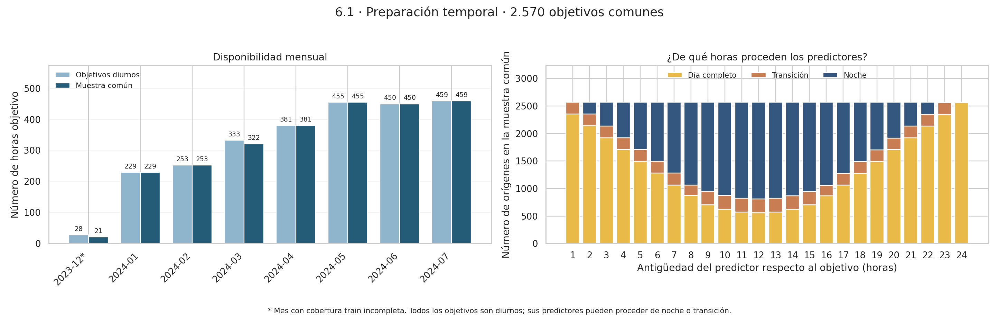

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
%run subseccion_6_1_preparacion_retardos_24h.py

### 6.2 Memoria temporal de la irradiancia difusa

¿Cómo se relaciona la DIF de una hora completamente diurna con sus propios valores anteriores y cómo cambia esa asociación con el retardo? Se comparan DIF(T) y DIF(T−h) sobre la muestra común definida en 6.1 mediante Pearson, Spearman e información mutua (MI, en nats, con *k* = 5 como referencia y *k* = 3 y *k* = 10 como sensibilidad), lo que proporciona una referencia para interpretar después las covariables. El análisis se realiza sobre valores originales, en los que permanecen los ciclos solares y las tendencias, por lo que describe una asociación retardada condicionada al objetivo diurno y no una ACF estacionaria convencional.

 retardo_h    n  pearson  spearman  mi_k5_nats
         1 2570   0.8386    0.8412      0.6545
         2 2570   0.6419    0.6479      0.3339
         3 2570   0.4585    0.4878      0.1571
         4 2570   0.2983    0.3661      0.1096
         5 2570   0.1658    0.2743      0.0821
         6 2570   0.0609    0.1954      0.0624
         7 2570  -0.0280    0.1240      0.0508
         8 2570  -0.1056    0.0318      0.0473
         9 2570  -0.1715   -0.0904      0.0740
        10 2570  -0.2337   -0.2158      0.0538
        11 2570  -0.3117   -0.3110      0.0971
        12 2570  -0.3567   -0.3634      0.1564
        13 2570  -0.3200   -0.3364      0.1218
        14 2570  -0.2642   -0.2557      0.0665
        15 2570  -0.2212   -0.1518      0.0871
        16 2570  -0.1738   -0.0473      0.0597
        17 2570  -0.1097    0.0220      0.0582
        18 2570  -0.0237    0.1005      0.0578
        19 2570   0.0774    0.1844      0.0675
        20 2570   0.2013    0.2801      0.0763
        21 25

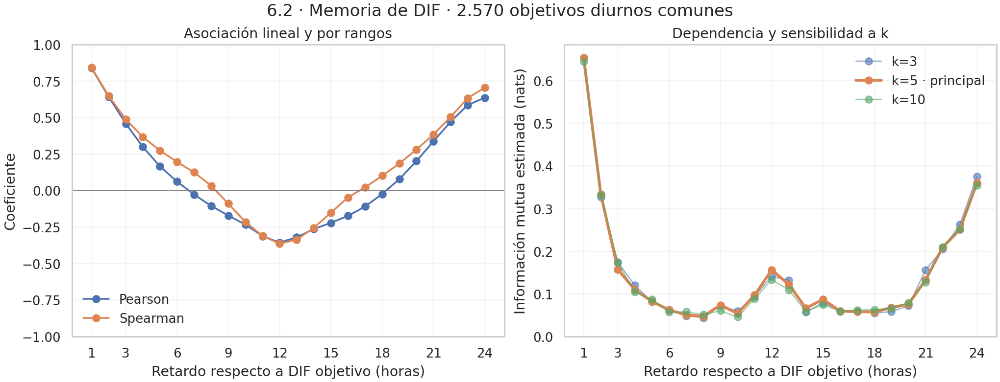

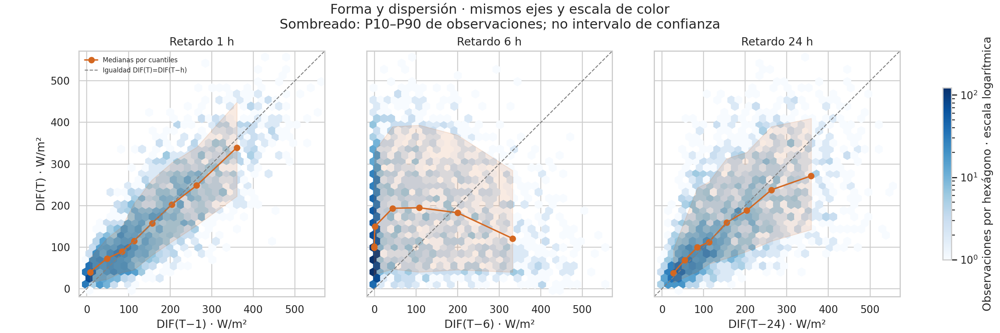

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
%run subseccion_6_2_memoria_DIF_24h.py

**Resultados.** Sobre 2.570 horas objetivo completamente diurnas, la asociación de DIF con su propio pasado es máxima a una hora, disminuye con el retardo, se vuelve negativa en las horas intermedias y se recupera hacia las 24 horas.

- **1 h:** Pearson 0,839, Spearman 0,841 y MI 0,655 nats, máximo de las tres medidas.
- **6 h:** Pearson de 0,061, aunque las medianas de DIF por intervalos del predictor crecen y luego descienden.
- **12 h:** mínimos de Pearson (−0,357) y Spearman (−0,363), con un 68,4 % de orígenes nocturnos, compatible con una contribución importante del ciclo diario.
- **24 h:** Pearson 0,635 y Spearman 0,704, con un 99,7 % de orígenes completamente diurnos; frente a 2 h, Spearman y MI son mayores, pero Pearson no (0,642 a 2 h).
- La MI mantiene el patrón con los tres valores de *k* (0,645–0,655 nats a 1 h; 0,355–0,376 a 24 h).

### 6.3 Relaciones retardadas entre las covariables y DIF

¿Qué covariables presentan asociaciones lineales, monótonas o más generales con la DIF posterior y cómo evolucionan entre 1 y 24 horas de retardo? Para las 26 covariables —incluidos el mínimo, el máximo y la `std` históricos de DIF— y los 24 retardos (624 combinaciones) se calculan Pearson, como correlación cruzada descriptiva por retardo, Spearman e información mutua (k=5, con k=3 y k=10 como sensibilidad), sobre la muestra común de 6.1: 2.570 horas objetivo completamente diurnas de `train`. Los resultados se presentan en mapas de calor de variables × retardos, sin umbrales ni selección de los valores mayores. Son asociaciones marginales sobre series originales que conservan ciclos solares y tendencias, por lo que no identifican causalidad ni retardos óptimos.

Calculando 1/26: SWD__media_h
Calculando 2/26: SWD__min_h
Calculando 3/26: SWD__max_h
Calculando 4/26: SWD__std_media_h
Calculando 5/26: DIR__media_h
Calculando 6/26: DIR__min_h
Calculando 7/26: DIR__max_h
Calculando 8/26: DIR__std_media_h
Calculando 9/26: DIF__min_h
Calculando 10/26: DIF__max_h
Calculando 11/26: DIF__std_media_h
Calculando 12/26: LWD__media_h
Calculando 13/26: LWD__min_h
Calculando 14/26: LWD__max_h
Calculando 15/26: LWD__std_media_h
Calculando 16/26: SWU__media_h
Calculando 17/26: SWU__min_h
Calculando 18/26: SWU__max_h
Calculando 19/26: SWU__std_media_h
Calculando 20/26: LWU__media_h
Calculando 21/26: LWU__min_h
Calculando 22/26: LWU__max_h
Calculando 23/26: LWU__std_media_h
Calculando 24/26: T2__media_h
Calculando 25/26: RH__media_h
Calculando 26/26: PoPoPoPo__media_h
Finalizado: 624 combinaciones; 2570 objetivos comunes. Tres figuras.
ZIP generado: /content/EDA_6_3_covariables_DIF_24h_20261102T174940_496365Z.zip


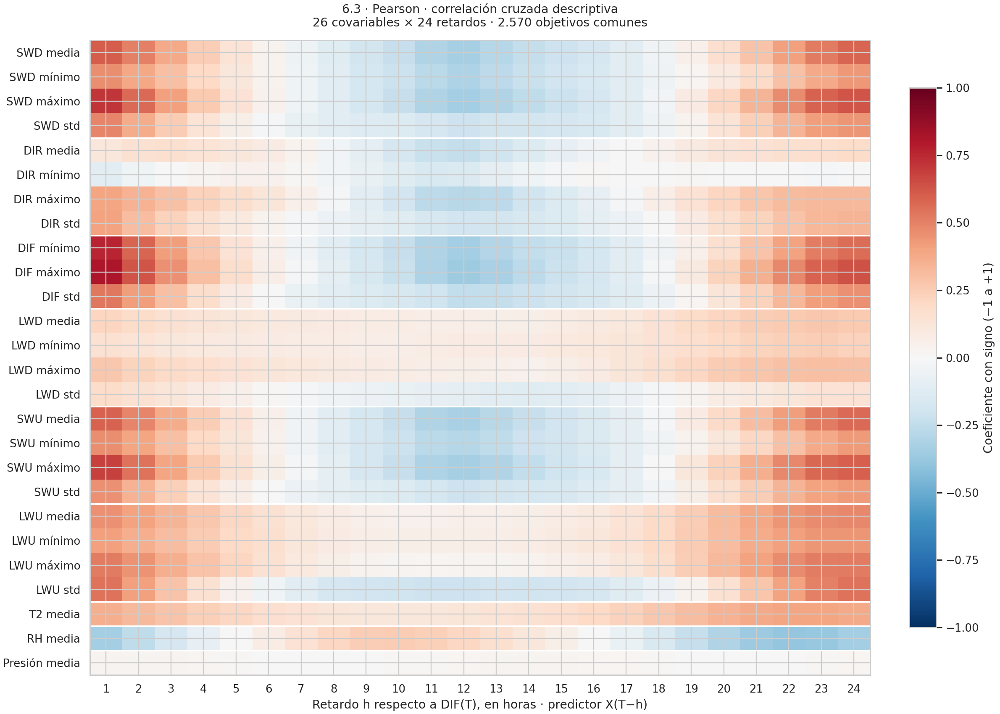

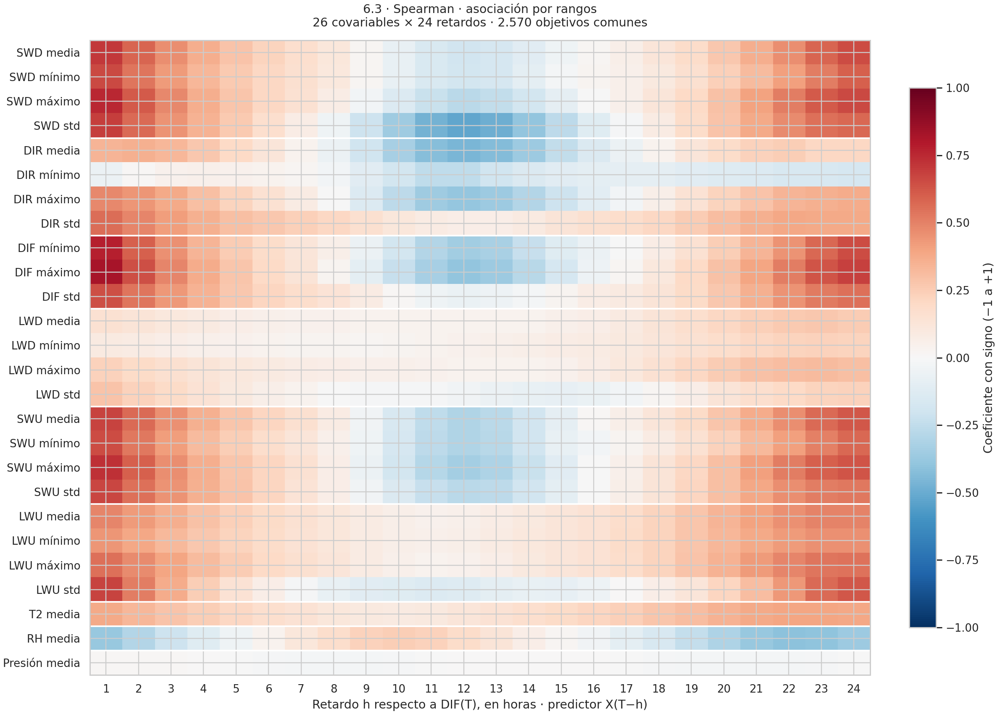

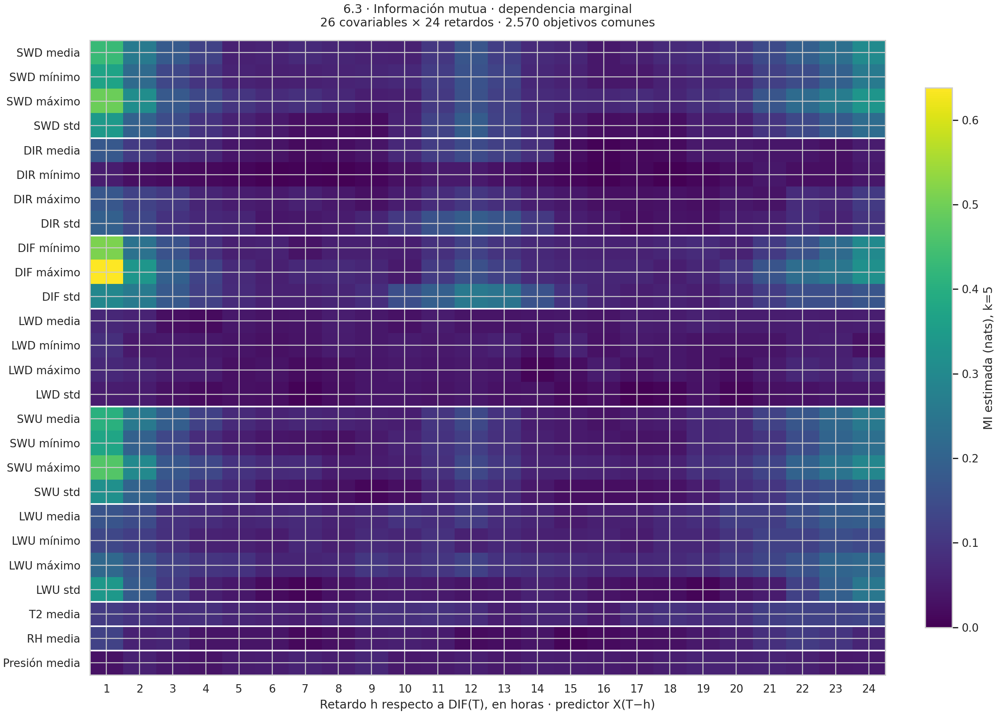

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
%run subseccion_6_3_covariables_DIF_24h.py

### 6.4 Contraste entre series originales y residuos STL

¿Qué relaciones retardadas persisten al retirar la tendencia y el componente diario estimados? Se repiten los cálculos de 6.3 (Pearson, Spearman e información mutua para los retardos 1–24) sobre los residuos de la STL robusta diaria de 4.2.4, alineados por timestamp para las 26 covariables y DIF, y se comparan con los de las series originales sobre exactamente las mismas horas válidas en las 624 combinaciones. Se identifica qué asociaciones disminuyen, permanecen o cambian de dirección tras el ajuste y se revisa la autocorrelación de los residuos, sin aplicar preblanqueamiento.

Validación: {'n_objetivos_61': 2570, 'n_objetivos_64': 2570, 'n_excluidos_adicionales': 0, 'excluidos_adicionales': [], 'n_residuos_enmascarados': 4, 'n_horas_train': 5208, 'originales_coinciden': True}
Contraste 1/26: SWD__media_h
Contraste 2/26: SWD__min_h
Contraste 3/26: SWD__max_h
Contraste 4/26: SWD__std_media_h
Contraste 5/26: DIR__media_h
Contraste 6/26: DIR__min_h
Contraste 7/26: DIR__max_h
Contraste 8/26: DIR__std_media_h
Contraste 9/26: DIF__min_h
Contraste 10/26: DIF__max_h
Contraste 11/26: DIF__std_media_h
Contraste 12/26: LWD__media_h
Contraste 13/26: LWD__min_h
Contraste 14/26: LWD__max_h
Contraste 15/26: LWD__std_media_h
Contraste 16/26: SWU__media_h
Contraste 17/26: SWU__min_h
Contraste 18/26: SWU__max_h
Contraste 19/26: SWU__std_media_h
Contraste 20/26: LWU__media_h
Contraste 21/26: LWU__min_h
Contraste 22/26: LWU__max_h
Contraste 23/26: LWU__std_media_h
Contraste 24/26: T2__media_h
Contraste 25/26: RH__media_h
Contraste 26/26: PoPoPoPo__media_h
ZIP generado: /content/

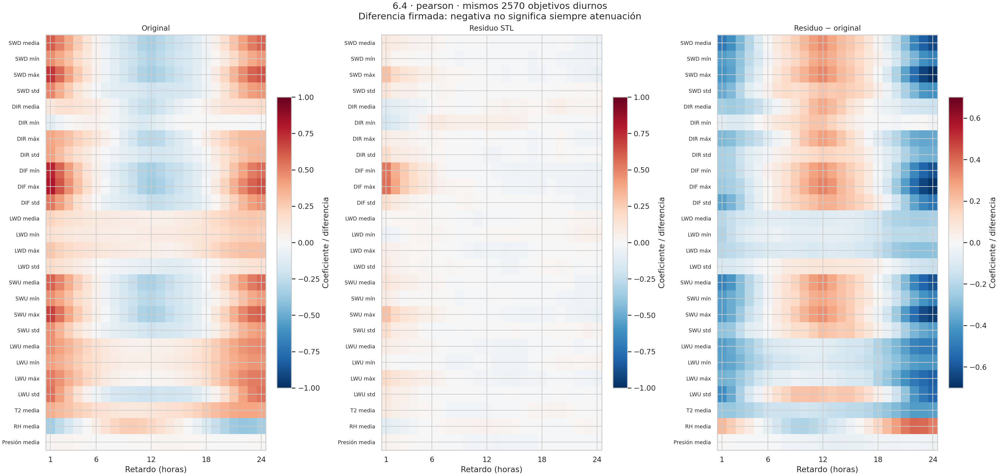

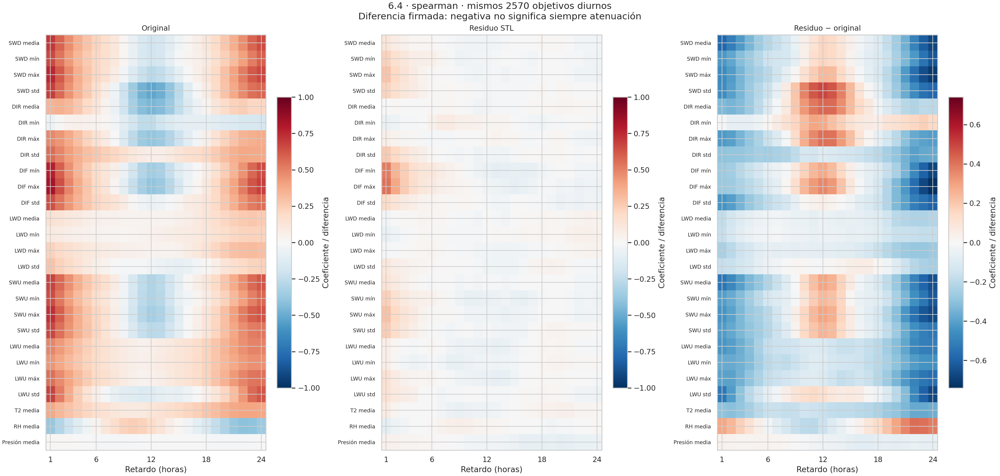

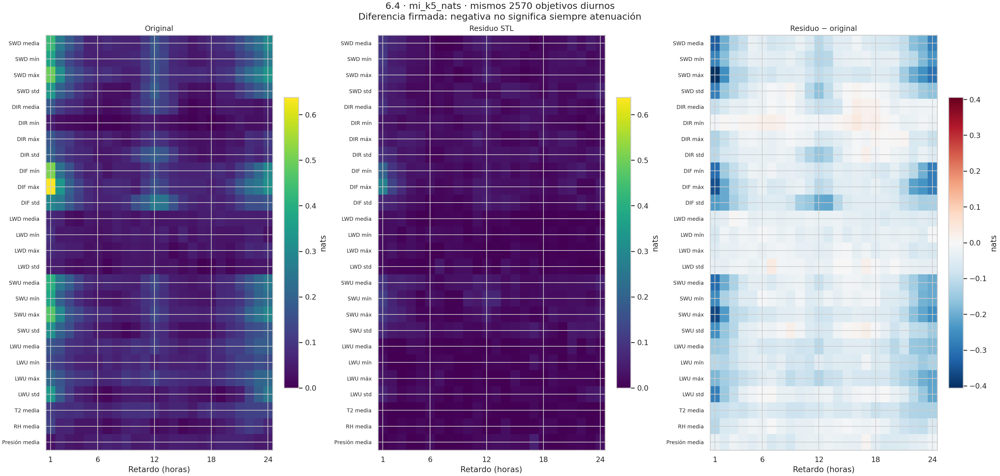

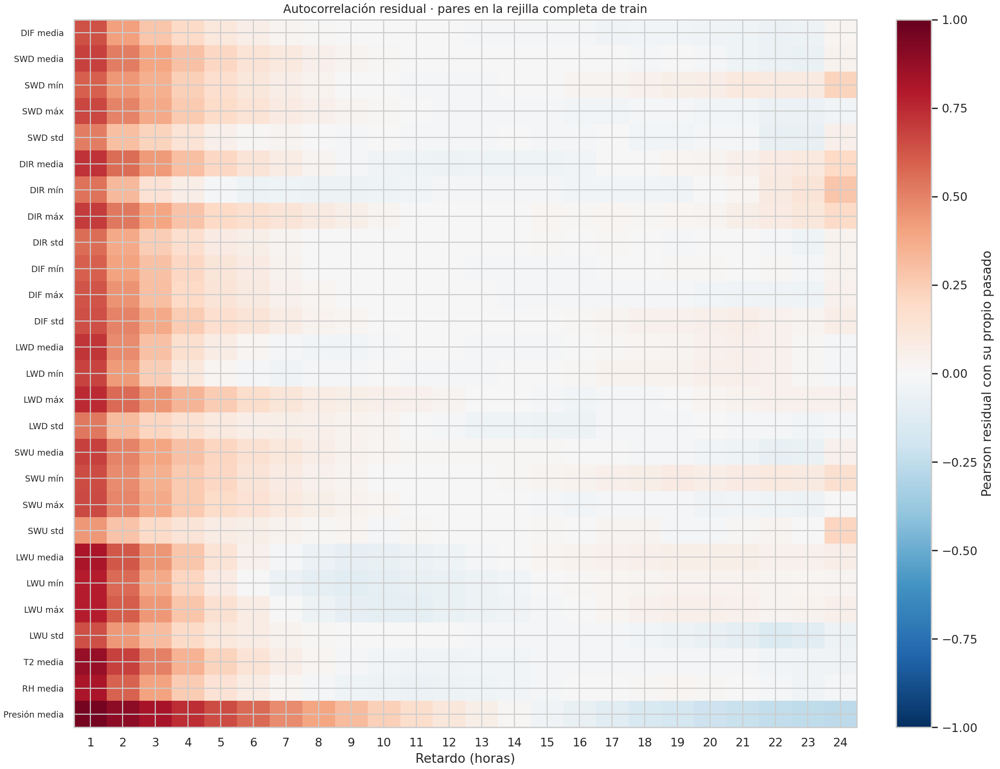

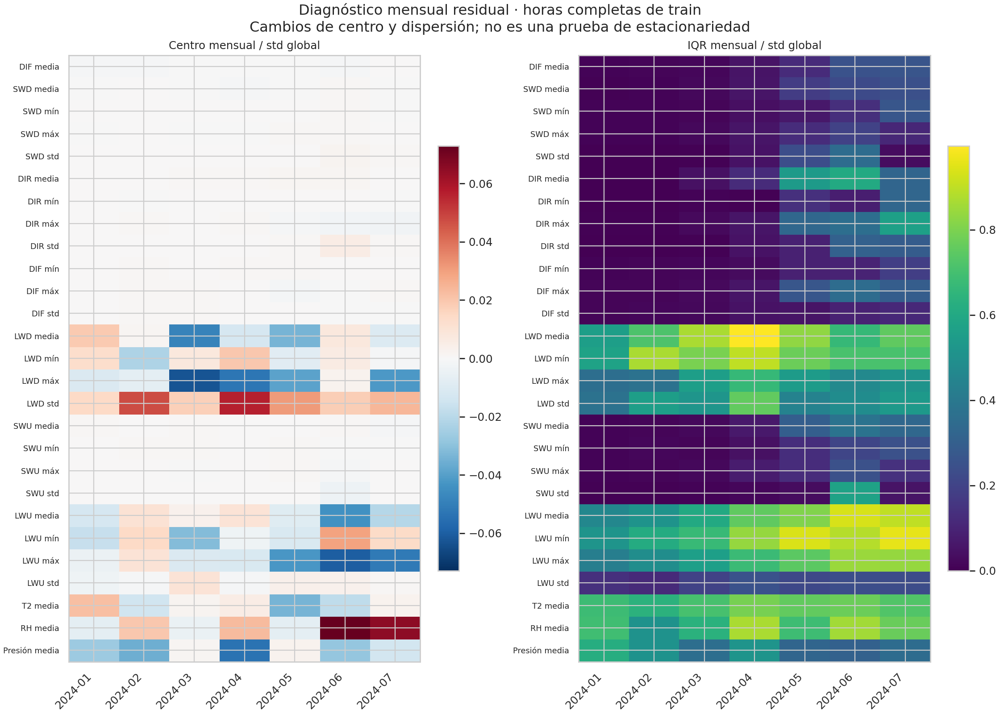

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
%run subseccion_6_4_contraste_STL_24h.py

**Resultados.** En las series originales, el retardo de una hora concentra el máximo de magnitud de Pearson en 15 variables, de Spearman en 16 y de MI (k=5) en 20.

- SWD, SWU y los estadísticos de DIF muestran asociaciones positivas cerca del objetivo, inversiones intermedias y recuperación hacia 24 h; los niveles de LWD, LWU y T2 se mantienen positivos.
- Tras la STL, la magnitud disminuye en 558 de 624 combinaciones con Pearson, 568 con Spearman y 589 con MI.
- A 24 h, los mayores valores residuales son 0,073 en magnitud de Pearson y 0,061 en Spearman; el Pearson de SWD máximo pasa de 0,629 a −0,073.
- En los residuos destacan DIF mínimo y máximo (Pearson a 1 h de 0,530 y 0,552) y, entre las variables externas, los máximos de SWD y SWU (0,296 y 0,292).
- Los residuos conservan autocorrelación, elevada en presión y T2, cuya asociación residual con DIF es pequeña.

## Análisis complementarios

Análisis que no se utilizan en la memoria y no generan la entrada de ninguna otra subsección. Se conservan como registro del trabajo exploratorio.

### 5.3.1 Agrupación de covariables por correlación

¿Qué conjuntos de covariables contienen información muy semejante durante las horas completamente diurnas y cuáles quedan fuera de ellos? Se construye un árbol jerárquico de las 26 covariables (no de las horas) a partir de sus correlaciones en día completo, uno con Spearman y otro con Pearson mediante el mismo procedimiento, para distinguir los bloques comunes a ambas medidas de los que dependen sobre todo de la ordenación monótona. No se fija de antemano el número de grupos ni se usa el umbral de 0,90 como regla de agrupación: los grupos se identifican a partir de las separaciones del árbol y se contrastan con la correlación más débil dentro de cada grupo, la coincidencia Pearson–Spearman y la evolución mensual de 5.2. El resultado es un mapa de información potencialmente compartida, que no demuestra que una variable sea sustituible por otra.

In [35]:
%run subseccion_5_3_clusteres_correlacion.py

ZIP de entrada: EDA_multivariante_5_2_evolucion_mensual_xx_20261102T174456Z.zip

Resultado: /content/EDA_multivariante_F5_S53_clusteres_correlacion_20261102T175323Z.zip
Núcleos en |coef.| >= 0,90 (referencia, no número definitivo de familias):
  Spearman: 5 núcleos con al menos dos variables; 15 variables incluidas
  Pearson: 6 núcleos con al menos dos variables; 15 variables incluidas
Figuras: 4. Tablas: 5. Todos los datos proceden exclusivamente del ZIP indicado.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 5.3.2 Agrupación de variables por semejanza de perfiles horarios

¿Qué variables presentan comportamientos horarios parecidos durante las horas completamente diurnas, aunque pertenezcan a familias distintas? Se agrupan jerárquicamente las 26 covariables, sin `DIF__media_h`, representada cada una por sus valores estandarizados en las 2.587 horas de día completo de `train` sin ausencias; Pearson y Spearman no intervienen en la construcción del árbol. La distancia entre dos variables es la diferencia absoluta media entre sus perfiles estandarizados en las mismas horas, d(i, j) = (1/N) · Σ<sub>t=1…N</sub> |z<sub>i</sub>(t) − z<sub>j</sub>(t)|, y los grupos se unen por enlace completo, sin imponer un número de grupos ni umbrales de correlación. El análisis describe semejanza contemporánea de perfiles: variables con evolución opuesta pueden quedar separadas aunque estén muy asociadas, y compartir rama no demuestra redundancia predictiva.

ZIP localizado: EDA_multivariante_5_2_evolucion_mensual_xx_20261102T174456Z.zip

Train: 5208 horas. Día completo: 2588.
Horas comunes utilizadas: 2587. Excluidas: 1.
Variables: 26. Parejas: 325. Figuras: 2. Tablas: 2.
Resultado: /content/EDA_5_3_perfiles_horarios_20261102T175357_837976Z.zip


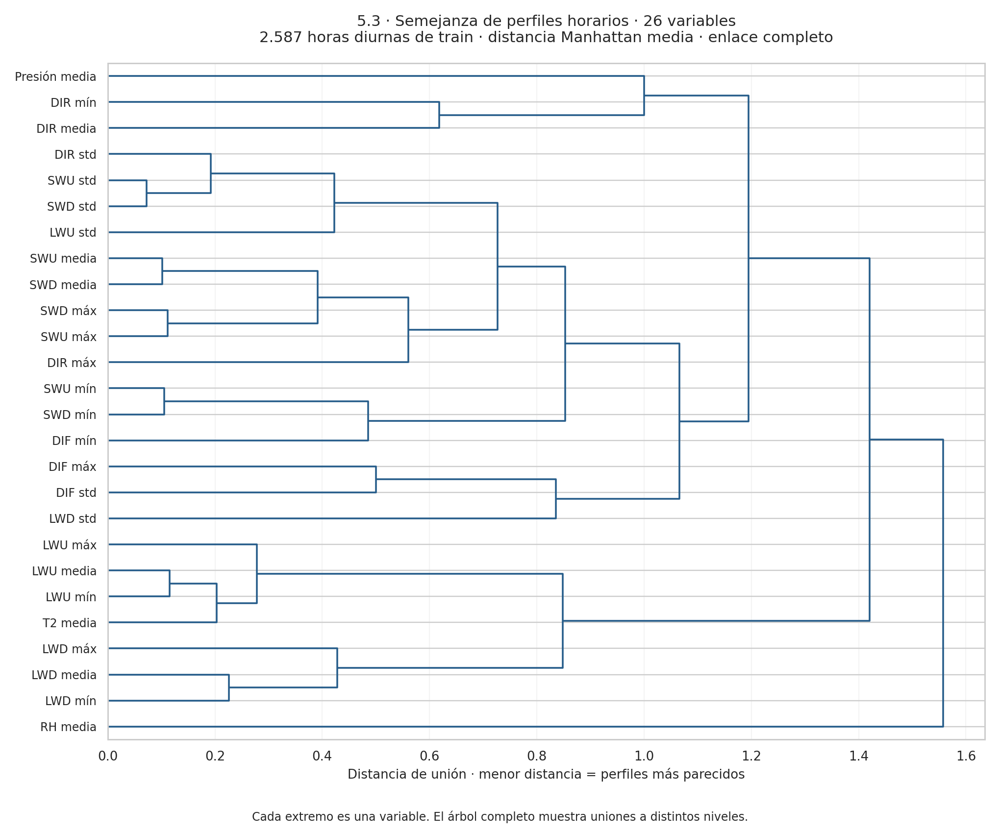

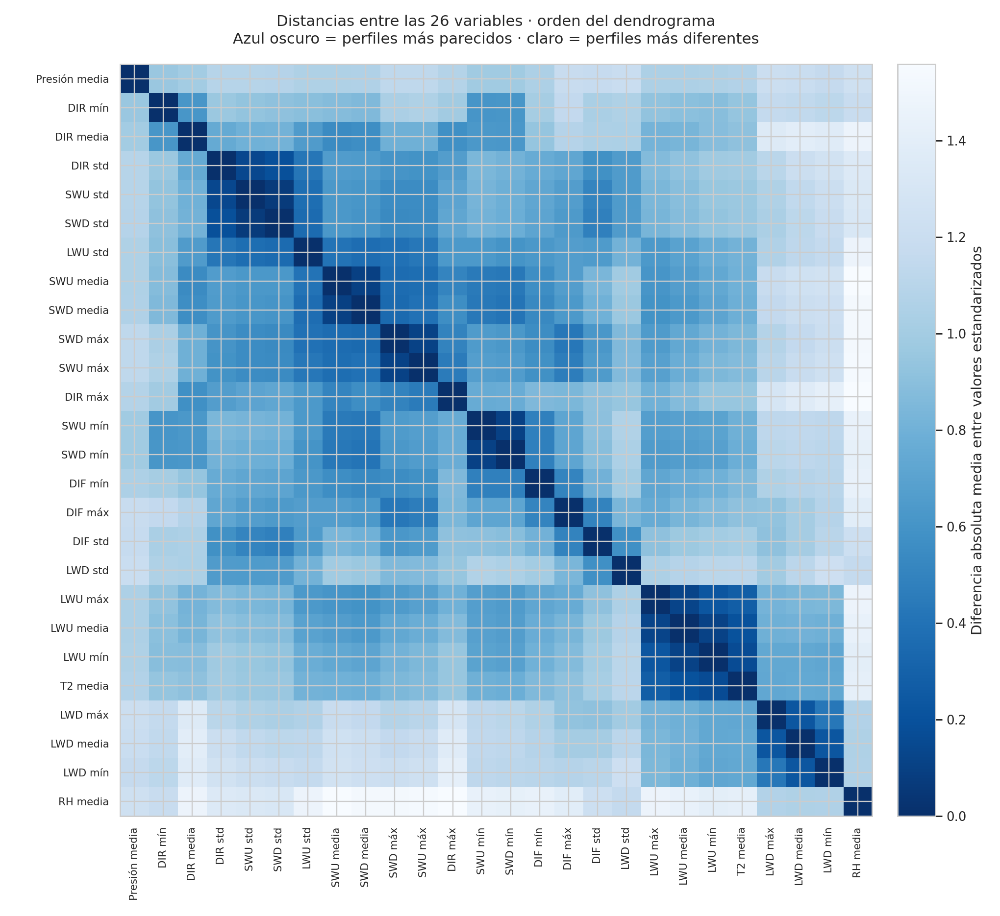

,variable,vecina_mas_parecida,distancia_media
0,Presión media,DIR mín,0.958
1,DIR mín,SWU mín,0.612
2,DIR media,SWU media,0.544
3,DIR std,SWU std,0.145
4,SWU std,SWD std,0.073
5,SWD std,SWU std,0.073
6,LWU std,SWD std,0.355
7,SWU media,SWD media,0.102
8,SWD media,SWU media,0.102
9,SWD máx,SWU máx,0.112


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
%run subseccion_5_3_perfiles_horarios.py